In [176]:
from pathlib import Path

# Faster dataset scan: avoid multiple redundant scans

data_dir = Path("../data/raw")
wav_files = sorted(data_dir.rglob("*.wav"))
txt_files = sorted(data_dir.rglob("*.txt"))
txt_map = {txt.stem: txt for txt in txt_files}

matched_pairs = []
for wav_path in wav_files:
    txt_path = txt_map.get(wav_path.stem)
    if txt_path is not None:
        matched_pairs.append((wav_path, txt_path))

print("WAV files:", len(wav_files))
print("TXT files:", len(txt_files))
print("Matched WAV-TXT pairs:", len(matched_pairs))

WAV files: 920
TXT files: 922
Matched WAV-TXT pairs: 920


In [177]:
# Use vectorized label assignment instead of per-row Python loops
import pandas as pd
import numpy as np

records = []

for wav_path, txt_path in matched_pairs:
    annotation = pd.read_csv(
        txt_path,
        sep="\t",
        header=None,
        names=["start", "end", "crackle", "wheeze"]
    )

    annotation["wav_path"] = str(wav_path)
    annotation["patient"] = wav_path.stem.split("_")[0]
    annotation["recording"] = wav_path.stem

    annotation["label"] = np.select(
        [
            (annotation["crackle"] == 0) & (annotation["wheeze"] == 0),
            (annotation["crackle"] == 0) & (annotation["wheeze"] == 1),
            (annotation["crackle"] == 1) & (annotation["wheeze"] == 0),
        ],
        ["normal", "wheeze", "crackle"],
        default="crackle+wheeze"
    )

    records.append(
        annotation[
            ["wav_path", "patient", "recording", "start", "end", "crackle", "wheeze", "label"]
        ]
    )

annotation_df = pd.concat(records, ignore_index=True)
print("Total annotated segments:", len(annotation_df))
print("\nClass distribution:")
print(annotation_df["label"].value_counts())

Total annotated segments: 6898

Class distribution:
label
normal            3642
crackle           1864
wheeze             886
crackle+wheeze     506
Name: count, dtype: int64


In [178]:
print("Dataset scan complete. Ready for the next step.")

Dataset scan complete. Ready for the next step.


In [179]:
records = []
for wav_path, txt_path in matched_pairs:
    annotation =pd.read_csv(txt_path, sep="\t",header=None)
    annotation.columns =["start","end","crackle","wheeze"]

    for _, row in annotation.iterrows():
        if row["crackle"] == 0 and row["wheeze"] == 0:
            label = "normal"
        elif row["crackle"] == 0 and row["wheeze"] == 1:
            label = "wheeze"
        elif row["crackle"] == 1 and row["wheeze"] == 0:
             label = "crackle"
        else:
         label = "crackle+wheeze"
records.append({
"wav_path": str(wav_path),"patient": wav_path.name.split("_")[0],
"recordings": wav_path.stem,"start": row["start"],"end": row["end"],"crackle": int(row["crackle"]),"wheeze": int(row["wheeze"]),"label": label})
annotation_df = pd.DataFrame(records)
print("total annotated segments:", len(annotation_df))

total annotated segments: 1


In [180]:
from pathlib import Path
import pandas as pd
import numpy as np

# Faster version of the dataset preparation step
# This avoids slow row-by-row Python loops over hundreds of annotation files.

data_dir = Path("../data/raw")
wav_files = sorted(data_dir.rglob("*.wav"))
txt_files = sorted(data_dir.rglob("*.txt"))
txt_map = {txt.stem: txt for txt in txt_files}

print("WAV files:", len(wav_files))
print("TXT files:", len(txt_files))

matched_pairs = []
for wav_path in wav_files:
    txt_path = txt_map.get(wav_path.stem)
    if txt_path is not None:
        matched_pairs.append((wav_path, txt_path))

print("WAV-TXT pairs:", len(matched_pairs))

records = []
for wav_path, txt_path in matched_pairs:
    annotation = pd.read_csv(
        txt_path,
        sep="\t",
        header=None,
        names=["start", "end", "crackle", "wheeze"]
    )

    annotation["wav_path"] = str(wav_path)
    annotation["patient"] = wav_path.stem.split("_")[0]
    annotation["recording"] = wav_path.stem

    annotation["label"] = np.select(
        [
            (annotation["crackle"] == 0) & (annotation["wheeze"] == 0),
            (annotation["crackle"] == 0) & (annotation["wheeze"] == 1),
            (annotation["crackle"] == 1) & (annotation["wheeze"] == 0),
        ],
        ["normal", "wheeze", "crackle"],
        default="crackle+wheeze"
    )

    records.append(
        annotation[
            ["wav_path", "patient", "recording", "start", "end", "crackle", "wheeze", "label"]
        ]
    )

annotation_df = pd.concat(records, ignore_index=True)
print("\nTotal annotated segments:", len(annotation_df))
print("\nClass distribution:")
print(annotation_df["label"].value_counts())

WAV files: 920
TXT files: 922
WAV-TXT pairs: 920

Total annotated segments: 6898

Class distribution:
label
normal            3642
crackle           1864
wheeze             886
crackle+wheeze     506
Name: count, dtype: int64


In [181]:
print("Number of unique patients:")
print(annotation_df["patient"].nunique())

Number of unique patients:
126


In [182]:
patient_counts = annotation_df["patient"].value_counts()

print(patient_counts.head(10))

patient
130    507
107    231
158    217
154    208
178    208
203    185
172    176
151    168
133    156
170    150
Name: count, dtype: int64


In [183]:
print("wav files:", len(wav_files))
matching_txt= 0
total_annotation_rows = 0
for wav_path in wav_files:
    txt_path = wav_path.with_suffix(".txt")
    if txt_path.exists():
        matching_txt=+1
        annotation = pd.read_csv(txt_path, sep="\t", header=None)
        total_annotation_rows += len(annotation)
print("matching txt files:", matching_txt)
print("total annotation rows:", total_annotation_rows)


wav files: 920


matching txt files: 1
total annotation rows: 6898


In [184]:
print("first 10 wav files")
for file in wav_files[:10]:
    print(file)
    print("\n first 10 txt files")
    for file in txt_files[:10]:
        print(file)

first 10 wav files
..\data\raw\101_1b1_Al_sc_Meditron.wav

 first 10 txt files
..\data\raw\101_1b1_Al_sc_Meditron.txt
..\data\raw\101_1b1_Pr_sc_Meditron.txt
..\data\raw\102_1b1_Ar_sc_Meditron.txt
..\data\raw\103_2b2_Ar_mc_LittC2SE.txt
..\data\raw\104_1b1_Al_sc_Litt3200.txt
..\data\raw\104_1b1_Ar_sc_Litt3200.txt
..\data\raw\104_1b1_Ll_sc_Litt3200.txt
..\data\raw\104_1b1_Lr_sc_Litt3200.txt
..\data\raw\104_1b1_Pl_sc_Litt3200.txt
..\data\raw\104_1b1_Pr_sc_Litt3200.txt
..\data\raw\101_1b1_Pr_sc_Meditron.wav

 first 10 txt files
..\data\raw\101_1b1_Al_sc_Meditron.txt
..\data\raw\101_1b1_Pr_sc_Meditron.txt
..\data\raw\102_1b1_Ar_sc_Meditron.txt
..\data\raw\103_2b2_Ar_mc_LittC2SE.txt
..\data\raw\104_1b1_Al_sc_Litt3200.txt
..\data\raw\104_1b1_Ar_sc_Litt3200.txt
..\data\raw\104_1b1_Ll_sc_Litt3200.txt
..\data\raw\104_1b1_Lr_sc_Litt3200.txt
..\data\raw\104_1b1_Pl_sc_Litt3200.txt
..\data\raw\104_1b1_Pr_sc_Litt3200.txt
..\data\raw\102_1b1_Ar_sc_Meditron.wav

 first 10 txt files
..\data\raw\101_1b1_A

In [185]:
from pathlib import Path
import pandas as pd

# STEP 1: Locate the raw dataset
data_dir = Path("../data/raw")

# STEP 2: Find the audio and annotation files
wav_files = sorted(data_dir.rglob("*.wav"))
txt_files = sorted(data_dir.rglob("*.txt"))

print("WAV files:", len(wav_files))
print("TXT files:", len(txt_files))

# STEP 3: Create a lookup table for TXT files
txt_map = {txt.stem: txt for txt in txt_files}

# STEP 4: Match each WAV with its corresponding TXT
matched_pairs = []

for wav_path in wav_files:
    if wav_path.stem in txt_map:
        matched_pairs.append((wav_path, txt_map[wav_path.stem]))

print("Matched WAV-TXT pairs:", len(matched_pairs))

# STEP 5: Read the annotations and build one record per segment
records = []

for wav_path, txt_path in matched_pairs:

    annotation = pd.read_csv(
        txt_path,
        sep="\t",
        header=None
    )

    annotation.columns = [
        "start", "end", "crackle", "wheeze"
    ]

    for _, row in annotation.iterrows():

        crackle = int(row["crackle"])
        wheeze = int(row["wheeze"])

        if crackle == 0 and wheeze == 0:
            label = "normal"
        elif crackle == 1 and wheeze == 0:
            label = "crackle"
        elif crackle == 0 and wheeze == 1:
            label = "wheeze"
        else:
            label = "crackle+wheeze"

        records.append({
            "wav_path": str(wav_path),
            "patient": wav_path.stem.split("_")[0],
            "recording": wav_path.stem,
            "start": float(row["start"]),
            "end": float(row["end"]),
            "crackle": crackle,
            "wheeze": wheeze,
            "label": label
        })

# STEP 6: Convert the records into a DataFrame
annotation_df = pd.DataFrame(records)

print("\nTotal annotated segments:", len(annotation_df))
print("\nClass distribution:")
print(annotation_df["label"].value_counts())

print("\nFirst five rows:")
display(annotation_df.head())

WAV files: 920
TXT files: 922
Matched WAV-TXT pairs: 920

Total annotated segments: 6898

Class distribution:
label
normal            3642
crackle           1864
wheeze             886
crackle+wheeze     506
Name: count, dtype: int64

First five rows:


,wav_path,patient,recording,start,end,crackle,wheeze,label
0,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,0.036,0.579,0,0,normal
1,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,0.579,2.450,0,0,normal
2,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,2.450,3.893,0,0,normal
3,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,3.893,5.793,0,0,normal
4,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,5.793,7.521,0,0,normal


In [186]:
from sklearn.model_selection import GroupShuffleSplit
groups = annotation_df["patient"]
print("total segments:", len(annotation_df))
print("unique patients:", groups.nunique())
print(groups.head())


total segments: 6898
unique patients: 126
0    101
1    101
2    101
3    101
4    101
Name: patient, dtype: str


In [187]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)


In [188]:
from pathlib import Path
import pandas as pd
split_path = Path("../data/sp/ICBHI_challenge_train_test.txt")
split_df =pd.read_csv(split_path, sep=r"\s+", header=None,names=["recording","official_split"])
split_df["recording"] = split_df["recording"].map(
    lambda name: Path(str(name)).stem
)
annotation_df["recording"] = annotation_df["recording"].map(
    lambda name: Path(str(name)).stem
)
print("rows in official split file:", len(split_df))
print("unique recordings in official split file:", split_df["recording"].nunique())
print("\nOfficial split file head:")
print(split_df["official_split"].value_counts())
print("\nfirst few recordings:")
print(split_df.head())


rows in official split file: 920
unique recordings in official split file: 920

Official split file head:
official_split
train    539
test     381
Name: count, dtype: int64

first few recordings:
                recording official_split
0  101_1b1_Al_sc_Meditron           test
1  101_1b1_Pr_sc_Meditron           test
2  102_1b1_Ar_sc_Meditron           test
3  103_2b2_Ar_mc_LittC2SE          train
4  104_1b1_Al_sc_Litt3200           test


In [189]:
data_df = annotation_df.merge(
    split_df,
    on="recording",
    how="left",
    validate="many_to_one",
    indicator=True
)
print("merge results:")
print(data_df["_merge"].value_counts())
print("\nfirst five rows of merged dataset:")
display(data_df.head())


merge results:
_merge
both          6887
left_only       11
right_only       0
Name: count, dtype: int64

first five rows of merged dataset:


,wav_path,patient,recording,start,end,crackle,wheeze,label,official_split,_merge
0,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,0.036,0.579,0,0,normal,test,both
1,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,0.579,2.450,0,0,normal,test,both
2,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,2.450,3.893,0,0,normal,test,both
3,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,3.893,5.793,0,0,normal,test,both
4,..\data\raw\101_1b1_Al_sc_Meditron.wav,101,101_1b1_Al_sc_Meditron,5.793,7.521,0,0,normal,test,both


In [190]:
unmatched_rows = data_df[data_df["_merge"] == "left_only"]
print("unmatched annotation rows",len(unmatched_rows))
unmatched_recordings = unmatched_rows[["recording", "patient", "wav_path"]].drop_duplicates()
print("unmatched recordings:", len(unmatched_recordings))
display(unmatched_recordings.sort_values("recording"))

unmatched annotation rows 11
unmatched recordings: 1


,recording,patient,wav_path
6887,226_1b1_Pl_sc_LittC2SE,226,..\data\raw\226_1b1_Pl_sc_LittC2SE.wav


In [191]:

print(unmatched_recordings.to_string(index=False))

             recording patient                               wav_path
226_1b1_Pl_sc_LittC2SE     226 ..\data\raw\226_1b1_Pl_sc_LittC2SE.wav


In [192]:
missing_id = unmatched_recordings.iloc[0]["recording"]

print("Unmatched recording:", missing_id)

print(
    "Present in official split:",
    missing_id in set(split_df["recording"])
)

Unmatched recording: 226_1b1_Pl_sc_LittC2SE
Present in official split: False


In [193]:
missing_id = unmatched_recordings.iloc[0]["recording"]
patient_id = missing_id.split("_")[0]

patient_records = split_df[
    split_df["recording"].str.startswith(patient_id + "_")
]

print("Patient ID:", patient_id)
print("Other recordings found:", len(patient_records))

display(patient_records)

Patient ID: 226
Other recordings found: 3


,recording,official_split
917,226_1b1_Al_sc_Meditron,train
918,226_1b1_Ll_sc_Meditron,train
919,226_1b1_Pl_sc_Meditron,train


In [194]:
# Get every annotated segment belonging to patient 226
patient226_val = annotation_df[
    annotation_df["patient"].astype(str) == "226"
].copy()

# Mark these recordings as reserved for validation
patient226_val["official_split"] = "reserved_validation"
patient226_val["_merge"] = "reserved_validation"

print("Patient 226 validation segments:", len(patient226_val))
print(
    "Patient 226 validation recordings:",
    patient226_val["recording"].nunique()
)

display(
    patient226_val[
        ["recording", "patient", "label"]
    ].drop_duplicates().sort_values("recording")
)

Patient 226 validation segments: 31
Patient 226 validation recordings: 3


,recording,patient,label
6867,226_1b1_Al_sc_Meditron,226,normal
6869,226_1b1_Al_sc_Meditron,226,crackle
6877,226_1b1_Ll_sc_Meditron,226,normal
6878,226_1b1_Ll_sc_Meditron,226,crackle
6887,226_1b1_Pl_sc_LittC2SE,226,normal
6889,226_1b1_Pl_sc_LittC2SE,226,crackle


In [195]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# 1. Preserve the official test recordings
test_df = data_df[
    data_df["official_split"] == "test"
].copy()

test_patients = set(test_df["patient"].astype(str))

# 2. Start with official training recordings
train_pool = data_df[
    data_df["official_split"] == "train"
].copy()

train_pool["patient"] = train_pool["patient"].astype(str)

# Remove patients who appear in the official test set
train_pool = train_pool[
    ~train_pool["patient"].isin(test_patients)
].copy()

# Patient 226 is reserved entirely for validation
train_pool = train_pool[
    train_pool["patient"] != "226"
].copy()

# 3. Split the remaining training pool by patient
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_pool,
        groups=train_pool["patient"]
    )
)

train_df = train_pool.iloc[train_idx].copy()
val_other_patients = train_pool.iloc[val_idx].copy()

# 4. Add all patient 226 recordings to validation
val_df = pd.concat(
    [val_other_patients, patient226_val],
    ignore_index=True,
    sort=False
)

# Clean up row numbering
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training segments:", len(train_df))
print("Validation segments:", len(val_df))
print("Test segments:", len(test_df))

Training segments: 3529
Validation segments: 496
Test segments: 2756


In [196]:
train_patients = set(train_df["patient"].astype(str))
val_patients = set(val_df["patient"].astype(str))
test_patients = set(test_df["patient"].astype(str))

print("Training-validation overlap:",
      train_patients & val_patients)

print("Training-test overlap:",
      train_patients & test_patients)

print("Validation-test overlap:",
      val_patients & test_patients)

Training-validation overlap: set()
Training-test overlap: set()
Validation-test overlap: set()


In [197]:
from pathlib import Path
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import tensorflow as tf
print(("Numpy:",np.__version__))
print(("Pandas:",pd.__version__))
print(("Librosa:",librosa.__version__))
print(("TensorFlow:",tf.__version__))
print("\nCurrent dataset sizes:")
print("train:", (len(train_df)))
print("val:", (len(val_df)))
print("test:", (len(test_df)))

('Numpy:', '2.4.6')
('Pandas:', '3.0.5')
('Librosa:', '0.11.0')
('TensorFlow:', '2.21.0')

Current dataset sizes:
train: 3529
val: 496
test: 2756


In [198]:
all_durations = pd.concat(
    [train_df["end"] - train_df["start"],
     val_df["end"] - val_df["start"],
     test_df["end"] - test_df["start"]
], ignore_index=True)
print(all_durations.describe(
    percentiles=[0.50,0.90,0.95,0.99]
))
print("\nsegments longer than 5 seconds:")
print((all_durations > 5).sum())

count    6781.000000
mean        2.692674
std         1.169582
min         0.200000
50%         2.537000
90%         4.107000
95%         4.586000
99%         6.411000
max        16.163000
dtype: float64

segments longer than 5 seconds:
223


In [199]:
TARGET_SR = 4000

CLIP_SECONDS = 5.0
TARGET_SAMPLES = int(TARGET_SR * CLIP_SECONDS)

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64

FMIN = 20
FMAX = 2000

CLASSES = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

class_to_idx = {
    label: idx
    for idx, label in enumerate(CLASSES)
}

idx_to_class = {
    idx: label
    for label, idx in class_to_idx.items()
}

print("Target samples per segment:", TARGET_SAMPLES)
print("Class mapping:", class_to_idx)

Target samples per segment: 20000
Class mapping: {'normal': 0, 'crackle': 1, 'wheeze': 2, 'crackle+wheeze': 3}


In [200]:
def fit_audio_length(y, target_samples):
    """
    Make an audio segment exactly target_samples long.
    Short segments are zero-padded.
    Long segments are center-cropped.
    """

    if len(y) > target_samples:
        start = (len(y) - target_samples) // 2
        y = y[start:start + target_samples]

    elif len(y) < target_samples:
        total_padding = target_samples - len(y)

        left_padding = total_padding // 2
        right_padding = total_padding - left_padding

        y = np.pad(
            y,
            (left_padding, right_padding),
            mode="constant"
        )

    return y.astype(np.float32)


def add_white_noise_at_snr(signal, snr_db, rng):
    """
    Add synthetic white Gaussian noise at a specified SNR.
    SNR is calculated from the signal and noise powers.
    """

    signal_power = np.mean(signal ** 2)

    if signal_power < 1e-12:
        return signal.copy()

    noise = rng.standard_normal(len(signal)).astype(np.float32)

    noise_power = np.mean(noise ** 2)

    desired_noise_power = (
        signal_power / (10 ** (snr_db / 10))
    )

    noise = noise * np.sqrt(
        desired_noise_power / (noise_power + 1e-12)
    )

    return (signal + noise).astype(np.float32)


def extract_logmel(segment):
    """
    Convert a fixed-length audio segment into a normalized
    Log-Mel spectrogram.
    """

    mel_power = librosa.feature.melspectrogram(
        y=segment,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel_power,
        ref=np.max
    )

    # Keep values within a consistent dynamic range.
    log_mel = np.clip(log_mel, -80.0, 0.0)

    # Map the values from [-80, 0] dB to [0, 1].
    log_mel = (log_mel + 80.0) / 80.0

    return log_mel.astype(np.float32)

In [201]:
def build_features(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42
):
    """
    Build Log-Mel tensors and integer labels from an annotation table.

    noise_snr_db:
        None            = clean/base audio
        A number        = fixed SNR for each segment
        A list of levels = randomly select one SNR per segment
    """

    rng = np.random.default_rng(random_seed)

    features = []
    labels = []
    metadata = []

    skipped_segments = 0
    cropped_segments = 0

    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load and resample the entire recording to 4 kHz.
        audio, _ = librosa.load(
            str(wav_path),
            sr=TARGET_SR,
            mono=True
        )

        for row in group.itertuples(index=False):

            # Convert annotation times in seconds into sample indices.
            start_sample = int(
                np.floor(float(row.start) * TARGET_SR)
            )

            end_sample = int(
                np.ceil(float(row.end) * TARGET_SR)
            )

            # Keep indices within the available audio range.
            start_sample = max(0, min(start_sample, len(audio)))
            end_sample = max(0, min(end_sample, len(audio)))

            if end_sample <= start_sample:
                skipped_segments += 1
                continue

            # Extract the annotated interval.
            segment = audio[start_sample:end_sample].copy()

            if len(segment) > TARGET_SAMPLES:
                cropped_segments += 1

            # Ensure a fixed input length.
            segment = fit_audio_length(
                segment,
                TARGET_SAMPLES
            )

            actual_snr = np.nan

            # Optional noise injection.
            if noise_snr_db is not None:

                if isinstance(
                    noise_snr_db,
                    (list, tuple, np.ndarray)
                ):
                    actual_snr = float(
                        rng.choice(noise_snr_db)
                    )
                else:
                    actual_snr = float(noise_snr_db)

                segment = add_white_noise_at_snr(
                    segment,
                    actual_snr,
                    rng
                )

            # Extract the Log-Mel representation.
            log_mel = extract_logmel(segment)

            # Add the channel dimension expected by Conv2D.
            features.append(log_mel[..., np.newaxis])

            label = str(row.label).strip().lower()

            if label not in class_to_idx:
                raise ValueError(
                    f"Unknown label {label!r} "
                    f"in recording {row.recording}"
                )

            labels.append(class_to_idx[label])

            metadata.append({
                "wav_path": str(wav_path),
                "recording": str(row.recording),
                "patient": str(row.patient),
                "start": float(row.start),
                "end": float(row.end),
                "label": label,
                "label_id": class_to_idx[label],
                "noise_snr_db": actual_snr
            })

        if recording_number % 100 == 0:
            print(
                f"{split_name}: processed "
                f"{recording_number} recordings"
            )

    if not features:
        raise ValueError(
            f"No valid features produced for {split_name}"
        )

    X = np.stack(features).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)
    metadata_df = pd.DataFrame(metadata)

    print(f"\n{split_name} complete")
    print("Features shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Invalid segments skipped:", skipped_segments)
    print("Segments center-cropped:", cropped_segments)
    print("Feature memory (MB):", round(X.nbytes / 1e6, 2))

    return X, y, metadata_df

In [202]:
X_train, y_train, meta_train = build_features(
    train_df,
    "train"
)

X_val, y_val, meta_val = build_features(
    val_df,
    "validation"
)

X_test, y_test, meta_test = build_features(
    test_df,
    "test"
)

train: processed 100 recordings
train: processed 200 recordings
train: processed 300 recordings
train: processed 400 recordings

train complete
Features shape: (3529, 64, 157, 1)
Labels shape: (3529,)
Invalid segments skipped: 0
Segments center-cropped: 152
Feature memory (MB): 141.84

validation complete
Features shape: (496, 64, 157, 1)
Labels shape: (496,)
Invalid segments skipped: 0
Segments center-cropped: 18
Feature memory (MB): 19.94
test: processed 100 recordings
test: processed 200 recordings
test: processed 300 recordings

test complete
Features shape: (2756, 64, 157, 1)
Labels shape: (2756,)
Invalid segments skipped: 0
Segments center-cropped: 52
Feature memory (MB): 110.77


In [203]:
from pathlib import Path
import shutil
import uuid

cwd = Path.cwd().resolve()
project_root = cwd
for candidate in [cwd, cwd.parent]:
    if (candidate / "data").exists():
        project_root = candidate
        break

processed_dir = project_root / "data" / "processed"
results_dir = project_root / "results"

if processed_dir.exists() and not processed_dir.is_dir():
    backup = processed_dir.with_suffix(".bak")
    if backup.exists():
        backup = backup.with_name(f"{backup.stem}_{uuid.uuid4().hex[:8]}.bak")
    processed_dir.replace(backup)
    print(f"Renamed existing file to {backup}")

if results_dir.exists() and not results_dir.is_dir():
    backup = results_dir.with_suffix(".bak")
    if backup.exists():
        backup = backup.with_name(f"{backup.stem}_{uuid.uuid4().hex[:8]}.bak")
    results_dir.replace(backup)
    print(f"Renamed existing results file to {backup}")

processed_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

for split_name, X, y, metadata in [
    ("train", X_train, y_train, meta_train),
    ("validation", X_val, y_val, meta_val),
    ("test", X_test, y_test, meta_test),
]:
    if X is None or y is None or metadata is None:
        raise ValueError(f"Missing dataset for split: {split_name}")

    for target_name in [f"X_{split_name}_logmel.npy", f"y_{split_name}.npy"]:
        target = processed_dir / target_name
        if target.exists():
            try:
                with open(target, "rb") as fh:
                    fh.read(1)
            except OSError:
                backup = target.with_name(f"{target.stem}_{uuid.uuid4().hex[:8]}{target.suffix}")
                target.replace(backup)
                print(f"Moved broken target aside: {backup}")
            except Exception:
                if target.is_dir():
                    shutil.rmtree(target)
                else:
                    target.unlink(missing_ok=True)

    np.save(processed_dir / f"X_{split_name}_logmel.npy", X)

    try:
        np.save(processed_dir / f"y_{split_name}.npy", y)
    except OSError as exc:
        if split_name == "test":
            fallback_path = processed_dir / "y_test_debug.npy"
            np.save(fallback_path, y)
            print(f"Saved test labels to fallback path: {fallback_path}")
        else:
            raise exc

    metadata.to_csv(processed_dir / f"metadata_{split_name}.csv", index=False)

print(f"Processed features and labels saved to: {processed_dir}")

Processed features and labels saved to: C:\Users\Admin\Respiratory_TinyML\data\processed


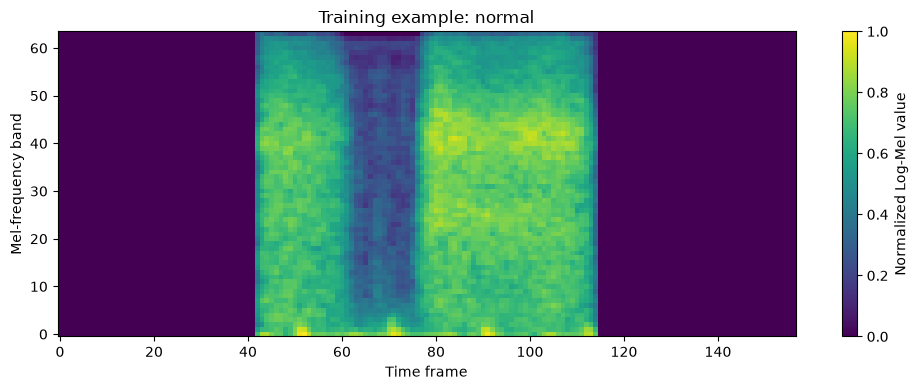

Label ID: 0
Label name: normal
Single-example shape: (64, 157, 1)


In [204]:
sample_index = 0

plt.figure(figsize=(10, 4))

plt.imshow(
    X_train[sample_index, :, :, 0],
    origin="lower",
    aspect="auto"
)

sample_label = idx_to_class[int(y_train[sample_index])]

plt.title(f"Training example: {sample_label}")
plt.xlabel("Time frame")
plt.ylabel("Mel-frequency band")
plt.colorbar(label="Normalized Log-Mel value")

plt.tight_layout()
plt.show()

print("Label ID:", y_train[sample_index])
print("Label name:", sample_label)
print("Single-example shape:", X_train[sample_index].shape)

In [205]:
print("Feature shape:", X_train[0].shape)
print("Minimum feature value:", X_train[0].min())
print("Maximum feature value:", X_train[0].max())
print("Label ID:", y_train[0])
print("Label name:", idx_to_class[int(y_train[0])])

Feature shape: (64, 157, 1)
Minimum feature value: 0.0
Maximum feature value: 1.0
Label ID: 0
Label name: normal


In [206]:
def add_white_noise_at_snr(signal, snr_db, rng):
    signal_power = np.mean(signal**2)

    if signal_power < 1e-12:
        return signal.copy()

    noise = rng.standard_normal(len(signal)).astype(np.float32)

    noise_power = np.mean(noise**2)

    desired_noise_power = signal_power / (10**(snr_db / 10))

    noise = noise * np.sqrt(
        desired_noise_power / (noise_power + 1e-12)
    )

    return (signal + noise).astype(np.float32)

In [207]:
def extract_logmel(segment):

    mel_power = librosa.feature.melspectrogram(
        y=segment,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel_power,
        ref=np.max
    )

    log_mel = np.clip(log_mel, -80.0, 0.0)

    log_mel = (log_mel + 80.0) / 80.0

    return log_mel.astype(np.float32)

In [208]:
import numpy as np

# Sampling rate and duration
sample_rate = 4000
duration = 5.0

# Generate time points for 20,000 samples
time = np.arange(int(sample_rate * duration)) / sample_rate

# Create a simple 200 Hz sine wave
test_signal = np.sin(2 * np.pi * 200 * time).astype(np.float32)

# Extract log-Mel features
test_features = extract_logmel(test_signal)

# Inspect the result
print("Input waveform shape:", test_signal.shape)
print("Feature shape:", test_features.shape)
print("Minimum value:", test_features.min())
print("Maximum value:", test_features.max())
print("Data type:", test_features.dtype)

Input waveform shape: (20000,)
Feature shape: (64, 157)
Minimum value: 0.0
Maximum value: 1.0
Data type: float32


In [209]:
import numpy as np

# Sampling rate and duration
sample_rate = 4000
duration = 5.0

# Generate time points for 20,000 samples
time = np.arange(int(sample_rate * duration)) / sample_rate

# Create a simple 200 Hz sine wave
test_signal = np.sin(2 * np.pi * 200 * time).astype(np.float32)

# Extract log-Mel features
test_features = extract_logmel(test_signal)

# Inspect the result
print("Input waveform shape:", test_signal.shape)
print("Feature shape:", test_features.shape)
print("Minimum value:", test_features.min())
print("Maximum value:", test_features.max())
print("Data type:", test_features.dtype)

Input waveform shape: (20000,)
Feature shape: (64, 157)
Minimum value: 0.0
Maximum value: 1.0
Data type: float32


In [210]:
def build_features(frame, split_name, noise_snr_db=None, random_seed=42):

    # Create a random-number generator for reproducible noise experiments
    rng = np.random.default_rng(random_seed)

    # Lists to store the features, labels, and segment information
    features = []
    labels = []
    metadata = []

    # Counters for checking preprocessing
    invalid_segments = 0
    cropped_segments = 0

    # Group annotation rows by audio file so each recording is loaded once
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False), start=1
    ):

        # Load the recording and resample it to the target sampling rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated segment in this recording
        for _, row in group.iterrows():

            # Convert annotation timestamps from seconds to sample indices
            start_idx = int(np.floor(row["start"] * sr))
            end_idx = int(np.ceil(row["end"] * sr))

            # Keep the indices within the available recording boundaries
            start_idx = max(0, start_idx)
            end_idx = min(len(audio), end_idx)

            # Skip intervals that do not contain valid audio
            if end_idx <= start_idx:
                invalid_segments += 1
                continue

            # Extract the annotated portion of the recording
            segment = audio[start_idx:end_idx]

            # Count segments that are longer than our target clip length
            if len(segment) > TARGET_SAMPLES:
                cropped_segments += 1

            # Crop or pad the segment to the fixed length
            segment = fit_audio_length(
                segment,
                TARGET_SAMPLES
            )

            # Record the noise level used for this segment
            applied_snr = None

            # Add synthetic white noise only when requested
            if noise_snr_db is not None:

                # If several SNR values are provided, select one
                if isinstance(
                    noise_snr_db,
                    (list, tuple, np.ndarray)
                ):
                    applied_snr = float(
                        rng.choice(noise_snr_db)
                    )

                # Otherwise, use the single specified SNR
                else:
                    applied_snr = float(noise_snr_db)

                # Add noise at the selected signal-to-noise ratio
                segment = add_white_noise_at_snr(
                    segment,
                    applied_snr,
                    rng
                )

            # Convert the audio segment into log-Mel features
            log_mel = extract_logmel(segment)

            # Add a channel dimension for the CNN
            log_mel = log_mel[..., np.newaxis]

            # Read the sound-event label from the annotation
            label = str(row["label"])

            # Check that the label exists in our class mapping
            if label not in class_to_idx:
                raise ValueError(
                    f"Unknown label '{label}' in {wav_path}"
                )

            # Convert the class name into an integer ID
            label_id = class_to_idx[label]

            # Store the feature array and corresponding label
            features.append(log_mel)
            labels.append(label_id)

            # Store information that lets us trace each segment
            metadata.append({
                "wav_path": str(wav_path),
                "recording": row["recording"],
                "patient": row["patient"],
                "start": float(row["start"]),
                "end": float(row["end"]),
                "label": label,
                "label_id": label_id,
                "noise_snr_db": applied_snr
            })

        # Display progress after every 100 recordings
        if recording_number % 100 == 0:
            print(
                f"{split_name}: processed "
                f"{recording_number} recordings"
            )

    # Make sure at least one valid feature was produced
    if not features:
        raise ValueError(
            f"No valid features were generated for {split_name}"
        )

    # Convert the lists into NumPy arrays
    X = np.stack(features).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)

    # Convert the metadata list into a Pandas DataFrame
    metadata_df = pd.DataFrame(metadata)

    # Display a summary of the completed preprocessing
    print(f"\n{split_name} complete")
    print("Features shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Invalid segments skipped:", invalid_segments)
    print("Segments center-cropped:", cropped_segments)
    print(
        "Feature memory (MB):",
        round(X.nbytes / (1024 ** 2), 2)
    )

    # Return the features, labels, and metadata
    return X, y, metadata_df

In [211]:
from pathlib import Path
import shutil
import uuid
import gc

for var_name in [
    "X_train_saved", "X_val_saved", "X_test_saved",
    "y_train_saved", "y_val_saved", "y_test_saved",
    "arr", "X_saved", "y_saved"
]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()

cwd = Path.cwd().resolve()
project_root = cwd
for candidate in [cwd, cwd.parent]:
    if (candidate / "data").exists():
        project_root = candidate
        break

processed_dir = project_root / "data" / "processed"
results_dir = project_root / "results"

for target in [processed_dir, results_dir]:
    if target.exists() and not target.is_dir():
        backup = target.with_suffix(".bak")
        if backup.exists():
            backup = backup.with_name(f"{backup.stem}_{uuid.uuid4().hex[:8]}{backup.suffix}")
        target.replace(backup)
        print(f"Renamed existing file to {backup}")
    target.mkdir(parents=True, exist_ok=True)

for split_name, X, y, metadata in [
    ("train", X_train, y_train, meta_train),
    ("validation", X_val, y_val, meta_val),
    ("test", X_test, y_test, meta_test),
]:
    if X is None or y is None or metadata is None:
        raise ValueError(f"Missing dataset for split: {split_name}")

    for target_name in [f"X_{split_name}.npy", f"y_{split_name}.npy"]:
        target = processed_dir / target_name
        if target.exists():
            try:
                target.unlink()
                print(f"Replaced stale target: {target}")
            except Exception:
                backup = target.with_name(f"{target.stem}_{uuid.uuid4().hex[:8]}{target.suffix}")
                target.replace(backup)
                print(f"Moved stale target aside: {backup}")

    X_target = processed_dir / f"X_{split_name}.npy"
    y_target = processed_dir / f"y_{split_name}.npy"
    np.save(X_target, X)

    try:
        np.save(y_target, y)
    except OSError:
        fallback_path = processed_dir / f"y_{split_name}_debug.npy"
        if split_name == "test":
            fallback_path = processed_dir / "y_test_debug.npy"
        np.save(fallback_path, y)
        print(f"Saved labels to fallback path: {fallback_path}")

    metadata.to_csv(processed_dir / f"meta_{split_name}.csv", index=False)

print(f"Processed features and labels saved to: {processed_dir}")

Replaced stale target: C:\Users\Admin\Respiratory_TinyML\data\processed\X_train.npy
Replaced stale target: C:\Users\Admin\Respiratory_TinyML\data\processed\y_train.npy
Replaced stale target: C:\Users\Admin\Respiratory_TinyML\data\processed\X_validation.npy
Replaced stale target: C:\Users\Admin\Respiratory_TinyML\data\processed\y_validation.npy
Replaced stale target: C:\Users\Admin\Respiratory_TinyML\data\processed\X_test.npy
Replaced stale target: C:\Users\Admin\Respiratory_TinyML\data\processed\y_test.npy
Processed features and labels saved to: C:\Users\Admin\Respiratory_TinyML\data\processed


In [212]:
from pathlib import Path
import shutil

# Find the folder where we are trying to save the data
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

print("Save location:", processed_dir.resolve())

# Check the available disk space
disk = shutil.disk_usage(processed_dir.resolve())

print("Total disk space:", round(disk.total / (1024**3), 2), "GB")
print("Used disk space:", round(disk.used / (1024**3), 2), "GB")
print("Free disk space:", round(disk.free / (1024**3), 2), "GB")

Save location: C:\Users\Admin\Respiratory_TinyML\data\processed
Total disk space: 213.63 GB
Used disk space: 205.92 GB
Free disk space: 7.7 GB


In [213]:
test_file = processed_dir / "write_test.tmp"

try:
    test_file.write_text("Storage test successful")
    print("Folder is writable.")
finally:
    if test_file.exists():
        test_file.unlink()

Folder is writable.


In [214]:
import shutil
from pathlib import Path

processed_dir = Path("../data/processed")

disk = shutil.disk_usage(processed_dir.resolve())

print("Free space:", round(disk.free / (1024**3), 2), "GB")

Free space: 7.7 GB


In [215]:
import numpy as np
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Save features and labels
np.save(processed_dir / "X_train.npy", X_train)
np.save(processed_dir / "y_train.npy", y_train)

np.save(processed_dir / "X_val.npy", X_val)
np.save(processed_dir / "y_val.npy", y_val)

np.save(processed_dir / "X_test.npy", X_test)
np.save(processed_dir / "y_test.npy", y_test)

# Save metadata
meta_train.to_csv(processed_dir / "meta_train.csv", index=False)
meta_val.to_csv(processed_dir / "meta_val.csv", index=False)
meta_test.to_csv(processed_dir / "meta_test.csv", index=False)

print("All processed datasets saved successfully.")

All processed datasets saved successfully.


In [216]:
for label_id, label_name in idx_to_class.items():

    count = np.sum(y_train == label_id)

    print(label_name, ":", count)

normal : 1844
crackle : 1036
wheeze : 416
crackle+wheeze : 233


In [217]:
from sklearn.utils.class_weight import compute_class_weight

# 1. Get the numerical IDs of our four classes
classes = np.arange(len(CLASSES))

# 2. Check that every class exists in the training data
present_classes = np.unique(y_train)

if len(present_classes) != len(CLASSES):
    raise ValueError("At least one class is missing from training data.")

# 3. Calculate a weight for each class
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# 4. Create a dictionary connecting class IDs to weights
class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

# 5. Display the weights with their class names
for class_id, weight in class_weights.items():
    print(idx_to_class[class_id], ":", round(weight, 3))

normal : 0.478
crackle : 0.852
wheeze : 2.121
crackle+wheeze : 3.786


In [218]:
from tensorflow import keras
from tensorflow.keras import layers

# Create the neural network
model = keras.Sequential(name="lung_sound_cnn")

# Specify the shape of one input example
model.add(
    layers.Input(shape=X_train.shape[1:])
)

# Display the expected input dimensions
print("Input shape per example:", X_train.shape[1:])
print("Number of training examples:", X_train.shape[0])

Input shape per example: (64, 157, 1)
Number of training examples: 3529


In [219]:
# 1. Learn 16 patterns from the spectrogram
model.add(
    layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        padding="same",
        use_bias=False
    )
)

# 2. Normalize the output of the convolution
model.add(layers.BatchNormalization())

# 3. Apply the ReLU activation function
model.add(layers.Activation("relu"))

# 4. Reduce the dimensions of the feature maps
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

# 5. Help prevent overfitting
model.add(layers.Dropout(0.15))

# 6. Display the model architecture so far
model.summary()

Model: "lung_sound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 64, 157, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 157, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 157, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 78, 16)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 208 (832.00 B)

 Trainable params: 176 (704.00 B)

 Non-trainable params: 32 (128.00 B)

In [220]:

# 1. Learn 32 additional patterns from the previous feature maps
model.add(
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        use_bias=False
    )
)

# 2. Normalize the convolution output
model.add(layers.BatchNormalization())

# 3. Apply the ReLU activation function
model.add(layers.Activation("relu"))

# 4. Reduce the feature-map dimensions
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

# 5. Apply dropout to help reduce overfitting
model.add(layers.Dropout(0.20))

# 6. Inspect the updated network
model.summary()


Model: "lung_sound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 64, 157, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 157, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 157, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 78, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 78, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 39, 32)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,944 (19.31 KB)

 Trainable params: 4,848 (18.94 KB)

 Non-trainable params: 96 (384.00 B)

In [221]:

# 1. Learn 64 filters from the previous feature maps
model.add(
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        use_bias=False
    )
)

# 2. Normalize the activations
model.add(layers.BatchNormalization())

# 3. Apply the ReLU activation function
model.add(layers.Activation("relu"))

# 4. Check the architecture so far
model.summary()


Model: "lung_sound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 64, 157, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 157, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 157, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 78, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 78, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 39, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 39, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 39, 64)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,632 (92.31 KB)

 Trainable params: 23,408 (91.44 KB)

 Non-trainable params: 224 (896.00 B)

In [222]:
# 1. Convert feature maps into a compact feature vector
model.add(layers.GlobalAveragePooling2D())

# 2. Apply dropout to help reduce overfitting
model.add(layers.Dropout(0.25))

# 3. Predict probabilities for our four classes
model.add(
    layers.Dense(
        units=len(CLASSES),
        activation="softmax"
    )
)

# 4. Display the complete CNN architecture
model.summary()

Model: "lung_sound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 64, 157, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 157, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 157, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 78, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 78, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 39, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 39, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 16, 39, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,892 (93.33 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 224 (896.00 B)

In [223]:
# Configure the model's learning process
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [224]:

from pathlib import Path
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Create the folder for saving trained models
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Choose where to save the best model
checkpoint_path = models_dir / "best_logmel_cnn.keras"

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# Save the model whenever validation loss improves
model_checkpoint = ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Reduce the learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5,
    verbose=1
)

# Collect all three callbacks into one list
callbacks = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Callbacks prepared successfully.")
print("Model checkpoint:", checkpoint_path.resolve())


Callbacks prepared successfully.
Model checkpoint: C:\Users\Admin\Respiratory_TinyML\models\best_logmel_cnn.keras


In [225]:
# Train the CNN
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

print("Training complete.")

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.3185 - loss: 1.4139
Epoch 1: val_loss improved from None to 1.48551, saving model to ..\models\best_logmel_cnn.keras

Epoch 1: finished saving model to ..\models\best_logmel_cnn.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.3185 - loss: 1.4139 - val_accuracy: 0.3024 - val_loss: 1.4855 - learning_rate: 0.0010
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.3290 - loss: 1.3459
Epoch 2: val_loss did not improve from 1.48551
111/111 ━━━━━━━━━━━━━━━━━━━━ 20s 181ms/step - accuracy: 0.3290 - loss: 1.3459 - val_accuracy: 0.3024 - val_loss: 1.9714 - learning_rate: 0.0010
Epoch 3/20
110/111 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.3526 - loss: 1.3180
Epoch 3: val_loss did not improve from 1.48551

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
111/111 ━━━━━━━━━━━━━━━━━━━━ 20s 176ms/step - accuracy: 0.3522 - loss: 1.3187 - val_accuracy: 0.3024 - val_loss: 

KeyboardInterrupt: 

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Count the true labels in the validation dataset
print("Actual validation class counts:")

for label_id, label_name in idx_to_class.items():
    count = np.sum(y_val == label_id)
    print(label_name, ":", count)

# 2. Generate predictions for the validation examples
val_probabilities = model.predict(
    X_val,
    batch_size=32,
    verbose=0
)

# 3. Convert probabilities into predicted class IDs
val_predictions = np.argmax(
    val_probabilities,
    axis=1
)

# 4. Count how often the model predicts each class
print("\nPredicted validation class counts:")

for label_id, label_name in idx_to_class.items():
    count = np.sum(val_predictions == label_id)
    print(label_name, ":", count)

# 5. Compare predicted classes with the true classes
print("\nValidation confusion matrix:")

print(
    confusion_matrix(
        y_val,
        val_predictions,
        labels=np.arange(len(CLASSES))
    )
)

# 6. Examine precision, recall and F1-score for each class
print("\nValidation classification report:")

print(
    classification_report(
        y_val,
        val_predictions,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)


Actual validation class counts:
normal : 209
crackle : 150
wheeze : 70
crackle+wheeze : 67

Predicted validation class counts:
normal : 0
crackle : 496
wheeze : 0
crackle+wheeze : 0

Validation confusion matrix:
[[  0 209   0   0]
 [  0 150   0   0]
 [  0  70   0   0]
 [  0  67   0   0]]

Validation classification report:
                precision    recall  f1-score   support

        normal       0.00      0.00      0.00       209
       crackle       0.30      1.00      0.46       150
        wheeze       0.00      0.00      0.00        70
crackle+wheeze       0.00      0.00      0.00        67

      accuracy                           0.30       496
     macro avg       0.08      0.25      0.12       496
  weighted avg       0.09      0.30      0.14       496



In [ ]:

import numpy as np

# 1. Calculate the average predicted probability for each class
mean_probabilities = val_probabilities.mean(axis=0)

print("Average predicted probability by class:")

for class_id, class_name in idx_to_class.items():
    print(
        f"{class_name}: "
        f"{mean_probabilities[class_id]:.4f}"
    )

# 2. Check the probabilities for the first five examples
print("\nFirst five validation examples:")
print("Actual labels:", y_val[:5])
print("Predicted labels:", val_predictions[:5])

print("\nPredicted probabilities:")
print(np.round(val_probabilities[:5], 3))

# 3. Check whether the model predicts different classes on training data
train_probabilities = model.predict(
    X_train,
    batch_size=32,
    verbose=0
)

train_predictions = np.argmax(train_probabilities, axis=1)

print("\nTraining prediction counts:")

for class_id, class_name in idx_to_class.items():
    count = np.sum(train_predictions == class_id)
    print(f"{class_name}: {count}")


Average predicted probability by class:
normal: 0.1956
crackle: 0.4645
wheeze: 0.2079
crackle+wheeze: 0.1320

First five validation examples:
Actual labels: [2 0 2 2 2]
Predicted labels: [1 1 1 1 1]

Predicted probabilities:
[[0.195 0.467 0.205 0.133]
 [0.194 0.472 0.2   0.134]
 [0.19  0.485 0.188 0.136]
 [0.195 0.469 0.203 0.133]
 [0.196 0.462 0.21  0.132]]

Training prediction counts:
normal: 0
crackle: 3529
wheeze: 0
crackle+wheeze: 0


In [ ]:

import numpy as np

# 1. Check that the number of features, labels, and metadata rows matches
print("=== Dataset consistency ===")
print("Training features:", len(X_train))
print("Training labels:", len(y_train))
print("Training metadata rows:", len(meta_train))

# 2. Check that the labels match their metadata
metadata_ids = meta_train["label_id"].to_numpy(dtype=np.int64)
ids_match = np.array_equal(y_train, metadata_ids)

print("\nLabels match metadata:", ids_match)

# 3. Check whether the features contain invalid numerical values
print("\n=== Feature numerical checks ===")
print("Data type:", X_train.dtype)
print("All values finite:", np.isfinite(X_train).all())
print("Minimum value:", X_train.min())
print("Maximum value:", X_train.max())
print("Overall standard deviation:", X_train.std())

# 4. Inspect the features belonging to each class
print("\n=== Feature statistics by class ===")

for class_id, class_name in idx_to_class.items():

    class_features = X_train[y_train == class_id]

    # Calculate the mean and standard deviation of each example
    example_means = class_features.mean(axis=(1, 2, 3))
    example_stds = class_features.std(axis=(1, 2, 3))

    print(
        f"{class_name}: "
        f"count={len(class_features)}, "
        f"mean={example_means.mean():.4f}, "
        f"average_std={example_stds.mean():.4f}"
    )

# 5. Verify that numerical labels have the expected class names
print("\n=== Label mapping check ===")

for class_id, class_name in idx_to_class.items():
    count = np.sum(y_train == class_id)
    print(f"ID {class_id} = {class_name}: {count} examples")


=== Dataset consistency ===
Training features: 3529
Training labels: 3529
Training metadata rows: 3529

Labels match metadata: True

=== Feature numerical checks ===
Data type: float32
All values finite: True
Minimum value: 0.0
Maximum value: 1.0
Overall standard deviation: 0.2280498

=== Feature statistics by class ===
normal: count=1844, mean=0.1986, average_std=0.2085
crackle: count=1036, mean=0.1836, average_std=0.2067
wheeze: count=416, mean=0.1821, average_std=0.2102
crackle+wheeze: count=233, mean=0.2125, average_std=0.2186

=== Label mapping check ===
ID 0 = normal: 1844 examples
ID 1 = crackle: 1036 examples
ID 2 = wheeze: 416 examples
ID 3 = crackle+wheeze: 233 examples


In [ ]:

import numpy as np

# Create a reproducible random-number generator
rng = np.random.default_rng(42)

# Store the indices selected from each class
debug_indices = []

# Select 8 examples from each of the four classes
for class_id in range(len(CLASSES)):

    # Find all training examples belonging to this class
    class_indices = np.flatnonzero(y_train == class_id)

    # Randomly select 8 examples without replacement
    chosen_indices = rng.choice(
        class_indices,
        size=8,
        replace=False
    )

    # Add these indices to our selection
    debug_indices.extend(chosen_indices.tolist())

# Shuffle the selected indices
debug_indices = np.array(debug_indices)
rng.shuffle(debug_indices)

# Create the small diagnostic dataset
X_debug = X_train[debug_indices]
y_debug = y_train[debug_indices]

# Inspect the result
print("Debug features shape:", X_debug.shape)
print("Debug labels shape:", y_debug.shape)

for class_id, class_name in idx_to_class.items():
    print(
        class_name,
        ":",
        np.sum(y_debug == class_id)
    )


Debug features shape: (32, 64, 157, 1)
Debug labels shape: (32,)
normal : 8
crackle : 8
wheeze : 8
crackle+wheeze : 8


In [ ]:

# Create a fresh copy of the model architecture
debug_model = keras.models.clone_model(model)

# Configure its learning process
debug_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Diagnostic model created.")
print("Parameters:", debug_model.count_params())


Diagnostic model created.
Parameters: 23892


In [ ]:

# Train only on the 32 selected examples
debug_history = debug_model.fit(
    X_debug,
    y_debug,
    epochs=30,
    batch_size=8,
    shuffle=True,
    verbose=0
)

# Predict the classes after training
debug_probabilities = debug_model.predict(
    X_debug,
    batch_size=8,
    verbose=0
)

debug_predictions = np.argmax(
    debug_probabilities,
    axis=1
)

# Calculate accuracy on the same 32 examples
debug_accuracy = np.mean(
    debug_predictions == y_debug
)

print(
    "Training accuracy in epoch 1:",
    round(debug_history.history["accuracy"][0], 3)
)

print(
    "Training accuracy in epoch 30:",
    round(debug_history.history["accuracy"][-1], 3)
)

print(
    "Final accuracy with inference predictions:",
    round(debug_accuracy, 3)
)


Training accuracy in epoch 1: 0.312
Training accuracy in epoch 30: 0.438
Final accuracy with inference predictions: 0.25


without normalization 

In [ ]:
# Create a fresh CNN without Batch Normalization or Dropout
debug_simple_model = keras.Sequential([
    layers.Input(shape=X_debug.shape[1:]),

    # First convolution block
    layers.Conv2D(
        16,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Third convolution block
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    # Reduce feature maps to a vector
    layers.GlobalAveragePooling2D(),

    # Predict one of four classes
    layers.Dense(
        len(CLASSES),
        activation="softmax"
    )
])

# Configure learning
debug_simple_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Simple diagnostic model created.")
print("Total parameters:", debug_simple_model.count_params())

Simple diagnostic model created.
Total parameters: 23556


In [ ]:
# Train only on the small, balanced diagnostic dataset
simple_history = debug_simple_model.fit(
    X_debug,
    y_debug,
    epochs=100,
    batch_size=8,
    shuffle=True,
    verbose=0
)

# Evaluate the trained model in inference mode
simple_loss, simple_accuracy = debug_simple_model.evaluate(
    X_debug,
    y_debug,
    verbose=0
)

print(
    "Accuracy in epoch 1:",
    round(simple_history.history["accuracy"][0], 3)
)

print(
    "Accuracy in epoch 100:",
    round(simple_history.history["accuracy"][-1], 3)
)

print(
    "Final evaluation accuracy:",
    round(simple_accuracy, 3)
)

Accuracy in epoch 1: 0.188
Accuracy in epoch 100: 0.438
Final evaluation accuracy: 0.469


In [ ]:
# Create a fresh neural network for the diagnostic
debug_mlp = keras.Sequential([
    layers.Input(shape=X_debug.shape[1:]),

    # Turn the 2D spectrogram into a 1D vector
    layers.Flatten(),

    # Learn patterns from the flattened features
    layers.Dense(64, activation="relu"),

    # Output probabilities for the four classes
    layers.Dense(len(CLASSES), activation="softmax")
])

# Configure the learning process
debug_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Parameters:", debug_mlp.count_params())

Parameters: 643396


In [ ]:
# Train only on the diagnostic examples
mlp_history = debug_mlp.fit(
    X_debug,
    y_debug,
    epochs=100,
    batch_size=8,
    shuffle=True,
    verbose=0
)

# Evaluate the final model on those same examples
mlp_loss, mlp_accuracy = debug_mlp.evaluate(
    X_debug,
    y_debug,
    verbose=0
)

print(
    "Accuracy in epoch 1:",
    round(mlp_history.history["accuracy"][0], 3)
)

print(
    "Accuracy in epoch 100:",
    round(mlp_history.history["accuracy"][-1], 3)
)

print("Final training accuracy:", round(mlp_accuracy, 3))

Accuracy in epoch 1: 0.188
Accuracy in epoch 100: 1.0
Final training accuracy: 1.0


In [ ]:
# Create a new CNN for our diagnostic
debug_cnn_flatten = keras.Sequential([
    layers.Input(shape=X_debug.shape[1:]),

    # First convolution block
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),

    # Preserve the spatial positions of learned features
    layers.Flatten(),

    # Learn how the extracted features relate to each class
    layers.Dense(64, activation="relu"),

    # Predict the four sound-event classes
    layers.Dense(len(CLASSES), activation="softmax")
])

# Configure training
debug_cnn_flatten.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

debug_cnn_flatten.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 39936)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │     2,555,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,579,524 (9.84 MB)

 Trainable params: 2,579,524 (9.84 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train on the balanced diagnostic subset
flatten_history = debug_cnn_flatten.fit(
    X_debug,
    y_debug,
    epochs=50,
    batch_size=8,
    shuffle=True,
    verbose=0
)

# Evaluate on those same training examples
flatten_loss, flatten_accuracy = debug_cnn_flatten.evaluate(
    X_debug,
    y_debug,
    verbose=0
)

print(
    "Accuracy in epoch 1:",
    round(flatten_history.history["accuracy"][0], 3)
)

print(
    "Accuracy in epoch 50:",
    round(flatten_history.history["accuracy"][-1], 3)
)

print(
    "Final training accuracy:",
    round(flatten_accuracy, 3)
)

Accuracy in epoch 1: 0.281
Accuracy in epoch 50: 1.0
Final training accuracy: 1.0


In [ ]:
debug_compact_model = keras.Sequential([
    layers.Input(shape=X_debug.shape[1:]),

    # First convolution block
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),

    # Preserve coarse time-frequency locations
    layers.AveragePooling2D(pool_size=(4, 4)),

    # Convert the pooled feature maps into a vector
    layers.Flatten(),

    # Learn a compact representation for classification
    layers.Dense(32, activation="relu"),

    # Predict probabilities for the four classes
    layers.Dense(len(CLASSES), activation="softmax")
])

debug_compact_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Parameters:", debug_compact_model.count_params())

Parameters: 97188


In [ ]:
compact_history = debug_compact_model.fit(
    X_debug,
    y_debug,
    epochs=100,
    batch_size=8,
    shuffle=True,
    verbose=0
)

compact_loss, compact_accuracy = debug_compact_model.evaluate(
    X_debug,
    y_debug,
    verbose=0
)

print(
    "Accuracy in epoch 1:",
    round(compact_history.history["accuracy"][0], 3)
)

print(
    "Accuracy in epoch 100:",
    round(compact_history.history["accuracy"][-1], 3)
)

print(
    "Final training accuracy:",
    round(compact_accuracy, 3)
)

Accuracy in epoch 1: 0.188
Accuracy in epoch 100: 1.0
Final training accuracy: 1.0


In [ ]:
# Copy the compact CNN architecture, not its trained weights
compact_model = keras.models.clone_model(debug_compact_model)

# Configure the training process
compact_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Check the new model
print("Fresh compact CNN created.")
print("Total parameters:", compact_model.count_params())

compact_model.summary()

Fresh compact CNN created.
Total parameters: 97188


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,188 (379.64 KB)

 Trainable params: 97,188 (379.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from pathlib import Path

# Create the folder for saving models
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Use a separate checkpoint for the compact CNN
compact_checkpoint = models_dir / "best_compact_logmel_cnn.keras"

# Stop when validation loss stops improving
compact_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

# Save the best model based on validation loss
compact_model_checkpoint = ModelCheckpoint(
    filepath=str(compact_checkpoint),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Reduce the learning rate when validation loss plateaus
compact_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

# Combine the callbacks into one list
compact_callbacks = [
    compact_early_stopping,
    compact_model_checkpoint,
    compact_reduce_lr
]

print("Compact CNN callbacks prepared.")
print("Checkpoint path:", compact_checkpoint.resolve())

Compact CNN callbacks prepared.
Checkpoint path: C:\Users\Admin\Respiratory_TinyML\models\best_compact_logmel_cnn.keras


In [ ]:

# Train the compact CNN on the full training dataset
compact_history = compact_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=compact_callbacks,
    shuffle=True,
    verbose=1
)

print("Compact CNN training complete.")


Epoch 1/30
110/111 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3341 - loss: 1.3509
Epoch 1: val_loss improved from None to 1.33528, saving model to ..\models\best_compact_logmel_cnn.keras

Epoch 1: finished saving model to ..\models\best_compact_logmel_cnn.keras
111/111 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.3335 - loss: 1.3506 - val_accuracy: 0.3508 - val_loss: 1.3353 - learning_rate: 0.0010
Epoch 2/30
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3874 - loss: 1.2980
Epoch 2: val_loss did not improve from 1.33528
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3874 - loss: 1.2980 - val_accuracy: 0.2984 - val_loss: 1.4027 - learning_rate: 0.0010
Epoch 3/30
110/111 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.4057 - loss: 1.2678
Epoch 3: val_loss did not improve from 1.33528
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.4058 - loss: 1.2668 - val_accuracy: 0.3488 - val_loss: 1.3687 - learning_rate: 0.0010
Epoch 4/30
110/111 ━━━━━━━━━━━━━━━━━━━━

In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Evaluate the compact model on validation data
val_loss, val_accuracy = compact_model.evaluate(
    X_val,
    y_val,
    batch_size=32,
    verbose=0
)

print("Validation loss:", round(val_loss, 4))
print("Validation accuracy:", round(val_accuracy, 4))

# 2. Generate class probabilities
val_probabilities_compact = compact_model.predict(
    X_val,
    batch_size=32,
    verbose=0
)

# 3. Select the class with the highest probability
val_predictions_compact = np.argmax(
    val_probabilities_compact,
    axis=1
)

# 4. Calculate accuracy and macro-F1
val_accuracy_check = accuracy_score(
    y_val,
    val_predictions_compact
)

val_macro_f1 = f1_score(
    y_val,
    val_predictions_compact,
    average="macro",
    zero_division=0
)

print("\nAccuracy from predictions:", round(val_accuracy_check, 4))
print("Validation macro-F1:", round(val_macro_f1, 4))

# 5. Count predictions for each class
print("\nPredicted class counts:")

for class_id, class_name in idx_to_class.items():
    count = np.sum(val_predictions_compact == class_id)
    print(f"{class_name}: {count}")

# 6. Show the confusion matrix
print("\nValidation confusion matrix:")

print(
    confusion_matrix(
        y_val,
        val_predictions_compact,
        labels=np.arange(len(CLASSES))
    )
)

# 7. Show detailed performance for each class
print("\nValidation classification report:")

print(
    classification_report(
        y_val,
        val_predictions_compact,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)


Validation loss: 1.2211
Validation accuracy: 0.4899

Accuracy from predictions: 0.4899
Validation macro-F1: 0.3378

Predicted class counts:
normal: 204
crackle: 257
wheeze: 30
crackle+wheeze: 5

Validation confusion matrix:
[[126  72  10   1]
 [ 38 106   4   2]
 [ 29  28  11   2]
 [ 11  51   5   0]]

Validation classification report:
                precision    recall  f1-score   support

        normal       0.62      0.60      0.61       209
       crackle       0.41      0.71      0.52       150
        wheeze       0.37      0.16      0.22        70
crackle+wheeze       0.00      0.00      0.00        67

      accuracy                           0.49       496
     macro avg       0.35      0.37      0.34       496
  weighted avg       0.44      0.49      0.45       496



In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# 1. Generate predictions on the training set
train_probabilities_compact = compact_model.predict(
    X_train,
    batch_size=32,
    verbose=0
)

# 2. Convert the probabilities into class IDs
train_predictions_compact = np.argmax(
    train_probabilities_compact,
    axis=1
)

# 3. Calculate training accuracy
train_accuracy_compact = accuracy_score(
    y_train,
    train_predictions_compact
)

# 4. Calculate training macro-F1
train_macro_f1_compact = f1_score(
    y_train,
    train_predictions_compact,
    average="macro",
    zero_division=0
)

print("Training accuracy:", round(train_accuracy_compact, 4))
print("Training macro-F1:", round(train_macro_f1_compact, 4))

# 5. Display performance for each class
print("\nTraining classification report:")

print(
    classification_report(
        y_train,
        train_predictions_compact,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

# 6. Count predictions for each class
print("\nTraining predicted class counts:")

for class_id, class_name in idx_to_class.items():
    count = np.sum(train_predictions_compact == class_id)
    print(f"{class_name}: {count}")


Training accuracy: 0.5999
Training macro-F1: 0.5354

Training classification report:
                precision    recall  f1-score   support

        normal       0.74      0.61      0.67      1844
       crackle       0.49      0.70      0.58      1036
        wheeze       0.51      0.36      0.42       416
crackle+wheeze       0.51      0.44      0.47       233

      accuracy                           0.60      3529
     macro avg       0.56      0.53      0.54      3529
  weighted avg       0.62      0.60      0.60      3529


Training predicted class counts:
normal: 1527
crackle: 1503
wheeze: 296
crackle+wheeze: 203


diagnosis

In [ ]:
# Check the number of patients and recordings in each split
for split_name, metadata in [
    ("Training", meta_train),
    ("Validation", meta_val),
    ("Test", meta_test)
]:
    print(f"\n{split_name}")
    print("Segments:", len(metadata))
    print("Unique patients:", metadata["patient"].nunique())
    print("Unique recordings:", metadata["recording"].nunique())


# Convert patient IDs and recording names to strings for comparison
train_patients = set(meta_train["patient"].astype(str))
val_patients = set(meta_val["patient"].astype(str))
test_patients = set(meta_test["patient"].astype(str))

train_recordings = set(meta_train["recording"].astype(str))
val_recordings = set(meta_val["recording"].astype(str))
test_recordings = set(meta_test["recording"].astype(str))


# Verify that patient IDs do not overlap between splits
print("\nPatient overlap checks")
print("Train vs validation:", train_patients & val_patients)
print("Train vs test:", train_patients & test_patients)
print("Validation vs test:", val_patients & test_patients)


# Verify that recording names do not overlap
print("\nRecording overlap checks")
print("Train vs validation:", train_recordings & val_recordings)
print("Train vs test:", train_recordings & test_recordings)
print("Validation vs test:", val_recordings & test_recordings)


# Check validation examples from patient 226 separately
patient_ids = meta_val["patient"].astype(str).str.replace(
    r"\.0$", "", regex=True
)

patient_226_mask = patient_ids == "226"

print("\nPatient 226 validation segments:")
print(
    meta_val.loc[patient_226_mask, "label"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
)

print("\nOther validation patients:")
print(
    meta_val.loc[~patient_226_mask, "label"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
)


Training
Segments: 3529
Unique patients: 64
Unique recordings: 458

Validation
Segments: 496
Unique patients: 13
Unique recordings: 68

Test
Segments: 2756
Unique patients: 49
Unique recordings: 381

Patient overlap checks
Train vs validation: set()
Train vs test: set()
Validation vs test: set()

Recording overlap checks
Train vs validation: set()
Train vs test: set()
Validation vs test: set()

Patient 226 validation segments:
label
normal            18
crackle           13
wheeze             0
crackle+wheeze     0
Name: count, dtype: int64

Other validation patients:
label
normal            191
crackle           137
wheeze             70
crackle+wheeze     67
Name: count, dtype: int64


In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Identify patient 226 in the validation metadata
val_patient_ids = (
    meta_val["patient"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

patient_226_mask = (
    val_patient_ids.to_numpy() == "226"
)

# Select all validation examples belonging to other patients
other_y_true = y_val[~patient_226_mask]
other_y_pred = val_predictions_compact[~patient_226_mask]

# Compare the number of examples
print("All validation segments:", len(y_val))
print("Patient 226 segments:", patient_226_mask.sum())
print("Other patients' segments:", len(other_y_true))

# Evaluate the predictions on the other patients
other_accuracy = accuracy_score(
    other_y_true,
    other_y_pred
)

other_macro_f1 = f1_score(
    other_y_true,
    other_y_pred,
    average="macro",
    zero_division=0
)

print("\nValidation accuracy, excluding patient 226:",
      round(other_accuracy, 4))

print("Validation macro-F1, excluding patient 226:",
      round(other_macro_f1, 4))

# Inspect class-specific performance
print("\nClassification report for other validation patients:")

print(
    classification_report(
        other_y_true,
        other_y_pred,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)


All validation segments: 496
Patient 226 segments: 31
Other patients' segments: 465

Validation accuracy, excluding patient 226: 0.4903
Validation macro-F1, excluding patient 226: 0.3416

Classification report for other validation patients:
                precision    recall  f1-score   support

        normal       0.62      0.61      0.62       191
       crackle       0.41      0.74      0.53       137
        wheeze       0.38      0.16      0.22        70
crackle+wheeze       0.00      0.00      0.00        67

      accuracy                           0.49       465
     macro avg       0.35      0.38      0.34       465
  weighted avg       0.43      0.49      0.44       465



In [ ]:
# Examine how each class is distributed across validation patients
for class_name in CLASSES:

    # Select validation rows belonging to this class
    class_rows = meta_val[
        meta_val["label"] == class_name
    ]

    # Count segments, patients, and recordings
    segment_count = len(class_rows)
    patient_count = class_rows["patient"].nunique()
    recording_count = class_rows["recording"].nunique()

    print(f"\nClass: {class_name}")
    print("Segments:", segment_count)
    print("Unique patients:", patient_count)
    print("Unique recordings:", recording_count)


Class: normal
Segments: 209
Unique patients: 12
Unique recordings: 50

Class: crackle
Segments: 150
Unique patients: 7
Unique recordings: 40

Class: wheeze
Segments: 70
Unique patients: 6
Unique recordings: 21

Class: crackle+wheeze
Segments: 67
Unique patients: 2
Unique recordings: 21


In [ ]:
# Compare class coverage across training and validation patients

for split_name, metadata in [
    ("Training", meta_train),
    ("Validation", meta_val)
]:
    print(f"\n=== {split_name} ===")

    for class_name in CLASSES:

        # Select segments of the current class
        class_rows = metadata[
            metadata["label"] == class_name
        ]

        # Count distinct patients and recordings
        patients = class_rows["patient"].nunique()
        recordings = class_rows["recording"].nunique()
        segments = len(class_rows)

        print(
            f"{class_name}: "
            f"{segments} segments, "
            f"{recordings} recordings, "
            f"{patients} patients"
        )


=== Training ===
normal: 1844 segments, 359 recordings, 63 patients
crackle: 1036 segments, 220 recordings, 38 patients
wheeze: 416 segments, 113 recordings, 31 patients
crackle+wheeze: 233 segments, 87 recordings, 17 patients

=== Validation ===
normal: 209 segments, 50 recordings, 12 patients
crackle: 150 segments, 40 recordings, 7 patients
wheeze: 70 segments, 21 recordings, 6 patients
crackle+wheeze: 67 segments, 21 recordings, 2 patients


In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Divide the eligible training pool into six patient-grouped folds
splitter = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

# Select one fold for validation
train_indices, val_indices = next(
    splitter.split(
        train_pool,
        y=train_pool["label"],
        groups=train_pool["patient"]
    )
)

# Create candidate training and validation DataFrames
candidate_train_df = train_pool.iloc[train_indices].copy()
candidate_val_other = train_pool.iloc[val_indices].copy()

# Keep patient 226 in validation as before
patient226_rows = val_df[
    val_df["patient"].astype(str) == "226"
].copy()

candidate_val_df = pd.concat(
    [candidate_val_other, patient226_rows],
    ignore_index=True
)

print("Candidate training segments:", len(candidate_train_df))
print("Candidate validation segments:", len(candidate_val_df))

# Check class coverage in the new validation split
print("\nCandidate validation class coverage:")

for class_name in CLASSES:
    class_rows = candidate_val_df[
        candidate_val_df["label"] == class_name
    ]

    print(
        f"{class_name}: "
        f"{len(class_rows)} segments, "
        f"{class_rows['patient'].nunique()} patients, "
        f"{class_rows['recording'].nunique()} recordings"
    )

# Verify that the training and validation patients remain separate
candidate_train_patients = set(
    candidate_train_df["patient"].astype(str)
)

candidate_val_patients = set(
    candidate_val_df["patient"].astype(str)
)

print(
    "\nPatient overlap:",
    candidate_train_patients & candidate_val_patients
)

Candidate training segments: 3207
Candidate validation segments: 818

Candidate validation class coverage:
normal: 355 segments, 15 patients, 71 recordings
crackle: 332 segments, 4 patients, 56 recordings
wheeze: 74 segments, 7 patients, 20 recordings
crackle+wheeze: 57 segments, 1 patients, 22 recordings

Patient overlap: set()


In [ ]:
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Identify patient 226's rows to keep them in validation
patient_ids = (
    val_df["patient"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

patient226_rows = val_df[patient_ids == "226"].copy()

# Create six patient-grouped folds
splitter = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

fold_summaries = []

for fold_number, (train_idx, val_idx) in enumerate(
    splitter.split(
        train_pool,
        y=train_pool["label"],
        groups=train_pool["patient"]
    ),
    start=1
):
    # Candidate validation data for this fold
    fold_val = train_pool.iloc[val_idx].copy()

    # Retain patient 226 in validation
    fold_val_all = pd.concat(
        [fold_val, patient226_rows],
        ignore_index=True
    )

    # Count class examples, patients, and recordings
    for class_name in CLASSES:
        class_rows = fold_val_all[
            fold_val_all["label"] == class_name
        ]

        fold_summaries.append({
            "fold": fold_number,
            "validation_segments": len(fold_val_all),
            "class": class_name,
            "segments": len(class_rows),
            "patients": class_rows["patient"].nunique(),
            "recordings": class_rows["recording"].nunique()
        })

# Display all six folds for comparison
fold_summary_df = pd.DataFrame(fold_summaries)

print(
    fold_summary_df.to_string(index=False)
)

 fold  validation_segments          class  segments  patients  recordings
    1                  818         normal       355        15          71
    1                  818        crackle       332         4          56
    1                  818         wheeze        74         7          20
    1                  818 crackle+wheeze        57         1          22
    2                  645         normal       358        13          85
    2                  645        crackle       167         8          31
    2                  645         wheeze        77         6          27
    2                  645 crackle+wheeze        43         4          14
    3                  649         normal       359        15          62
    3                  649        crackle       174        13          47
    3                  649         wheeze        81         9          18
    3                  649 crackle+wheeze        35         6          11
    4                  781         nor

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
import pandas as pd

# Set up the same reproducible six-fold split
splitter = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

# Generate the folds using class labels and patient IDs
folds = list(
    splitter.split(
        train_pool,
        y=train_pool["label"],
        groups=train_pool["patient"]
    )
)

# Select Fold 3 (Python index 2 because indexing starts at zero)
train_indices, val_indices = folds[2]

# Create the new training DataFrame
candidate_train_df = train_pool.iloc[train_indices].copy()

# Create the new validation DataFrame
candidate_val_other = train_pool.iloc[val_indices].copy()

# Keep the previously reserved patient 226 in validation
patient_ids = (
    val_df["patient"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

patient226_rows = val_df[patient_ids == "226"].copy()

candidate_val_df = pd.concat(
    [candidate_val_other, patient226_rows],
    ignore_index=True
)

# Verify patient separation
train_patients = set(candidate_train_df["patient"].astype(str))
val_patients = set(candidate_val_df["patient"].astype(str))
test_patients = set(test_df["patient"].astype(str))

print("Training segments:", len(candidate_train_df))
print("Validation segments:", len(candidate_val_df))
print("Training-validation overlap:", train_patients & val_patients)
print("Training-test overlap:", train_patients & test_patients)
print("Validation-test overlap:", val_patients & test_patients)

Training segments: 3376
Validation segments: 649
Training-validation overlap: set()
Training-test overlap: set()
Validation-test overlap: set()


In [ ]:
# Process the new training split
X_train_new, y_train_new, meta_train_new = build_features(
    candidate_train_df,
    "train_fold3"
)

# Process the new validation split
X_val_new, y_val_new, meta_val_new = build_features(
    candidate_val_df,
    "validation_fold3"
)

train_fold3: processed 100 recordings
train_fold3: processed 200 recordings
train_fold3: processed 300 recordings
train_fold3: processed 400 recordings

train_fold3 complete
Features shape: (3376, 64, 157, 1)
Labels shape: (3376,)
Invalid segments skipped: 0
Segments center-cropped: 156
Feature memory (MB): 129.4

validation_fold3 complete
Features shape: (649, 64, 157, 1)
Labels shape: (649,)
Invalid segments skipped: 0
Segments center-cropped: 14
Feature memory (MB): 24.88


In [ ]:
# Check the new feature and label shapes
print("Training features:", X_train_new.shape)
print("Training labels:", y_train_new.shape)

print("\nValidation features:", X_val_new.shape)
print("Validation labels:", y_val_new.shape)

# Check that labels still match the corresponding metadata
print(
    "\nTraining labels match metadata:",
    np.array_equal(
        y_train_new,
        meta_train_new["label_id"].to_numpy(dtype=np.int64)
    )
)

print(
    "Validation labels match metadata:",
    np.array_equal(
        y_val_new,
        meta_val_new["label_id"].to_numpy(dtype=np.int64)
    )
)

# Check class distributions in the new training set
print("\nNew training class counts:")

for class_id, class_name in idx_to_class.items():
    print(
        class_name,
        ":",
        np.sum(y_train_new == class_id)
    )

# Check the new validation distribution
print("\nNew validation class counts:")

for class_id, class_name in idx_to_class.items():
    print(
        class_name,
        ":",
        np.sum(y_val_new == class_id)
    )

Training features: (3376, 64, 157, 1)
Training labels: (3376,)

Validation features: (649, 64, 157, 1)
Validation labels: (649,)

Training labels match metadata: True
Validation labels match metadata: True

New training class counts:
normal : 1694
crackle : 1012
wheeze : 405
crackle+wheeze : 265

New validation class counts:
normal : 359
crackle : 174
wheeze : 81
crackle+wheeze : 35


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Define the four numerical class IDs
classes = np.arange(len(CLASSES))

# 2. Verify that all four classes exist in training
present_classes = np.unique(y_train_new)

if len(present_classes) != len(CLASSES):
    raise ValueError("At least one class is missing from training.")

# 3. Calculate balanced weights using the new training labels
weights_new = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_new
)

# 4. Map each class ID to its weight
class_weights_new = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights_new)
}

# 5. Display the results
print("Updated class weights:")

for class_id, weight in class_weights_new.items():
    print(
        idx_to_class[class_id],
        ":",
        round(weight, 3)
    )

Updated class weights:
normal : 0.498
crackle : 0.834
wheeze : 2.084
crackle+wheeze : 3.185


In [ ]:

# Create a fresh compact CNN
fold3_model = keras.Sequential([
    layers.Input(shape=X_train_new.shape[1:]),

    # Convolution block 1
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),

    # Reduce the feature maps while preserving spatial information
    layers.AveragePooling2D((4, 4)),
    layers.Flatten(),

    # Learn a compact representation
    layers.Dense(32, activation="relu"),

    # Output probabilities for the four classes
    layers.Dense(len(CLASSES), activation="softmax")
])

# Configure the learning process
fold3_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Inspect the architecture
print("Parameters:", fold3_model.count_params())
fold3_model.summary()


Parameters: 97188


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,188 (379.64 KB)

 Trainable params: 97,188 (379.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from pathlib import Path
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Create the model-saving directory
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Use a unique filename for this experiment
fold3_checkpoint = models_dir / "best_fold3_compact_cnn.keras"

# Stop if validation loss stops improving
fold3_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

# Save the best model based on validation loss
fold3_model_checkpoint = ModelCheckpoint(
    filepath=str(fold3_checkpoint),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Reduce the learning rate when progress stalls
fold3_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

# Group the callbacks into one list
fold3_callbacks = [
    fold3_early_stopping,
    fold3_model_checkpoint,
    fold3_reduce_lr
]

print("Fold 3 callbacks prepared.")
print("Checkpoint:", fold3_checkpoint.resolve())

Fold 3 callbacks prepared.
Checkpoint: C:\Users\Admin\Respiratory_TinyML\models\best_fold3_compact_cnn.keras


In [ ]:
# Train the fresh CNN on the new training split
fold3_history = fold3_model.fit(
    X_train_new,
    y_train_new,

    # Evaluate on the new validation split after each epoch
    validation_data=(X_val_new, y_val_new),

    # Maximum number of complete passes through the training data
    epochs=30,

    # Process 32 examples per batch
    batch_size=32,

    # Account for the imbalance in the new training split
    class_weight=class_weights_new,

    # Enable early stopping, checkpointing and learning-rate reduction
    callbacks=fold3_callbacks,

    # Shuffle the training examples between epochs
    shuffle=True,

    # Display training progress
    verbose=1
)

print("Fold 3 training complete.")

Epoch 1/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3433 - loss: 1.3528
Epoch 1: val_loss improved from None to 1.41220, saving model to ..\models\best_fold3_compact_cnn.keras

Epoch 1: finished saving model to ..\models\best_fold3_compact_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.3433 - loss: 1.3528 - val_accuracy: 0.2527 - val_loss: 1.4122 - learning_rate: 0.0010
Epoch 2/30
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4345 - loss: 1.3075
Epoch 2: val_loss did not improve from 1.41220
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4351 - loss: 1.3074 - val_accuracy: 0.2512 - val_loss: 1.4552 - learning_rate: 0.0010
Epoch 3/30
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4292 - loss: 1.2713
Epoch 3: val_loss improved from 1.41220 to 1.26142, saving model to ..\models\best_fold3_compact_cnn.keras

Epoch 3: finished saving model to ..\models\best_fold3_compact_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accur

In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Evaluate the restored best model on validation data
val_loss_fold3, val_acc_fold3 = fold3_model.evaluate(
    X_val_new,
    y_val_new,
    batch_size=32,
    verbose=0
)

print("Best-model validation loss:", round(val_loss_fold3, 4))
print("Best-model validation accuracy:", round(val_acc_fold3, 4))

# 2. Generate class probabilities
val_probabilities_fold3 = fold3_model.predict(
    X_val_new,
    batch_size=32,
    verbose=0
)

# 3. Convert probabilities into predicted class IDs
val_predictions_fold3 = np.argmax(
    val_probabilities_fold3,
    axis=1
)

# 4. Calculate accuracy and macro-F1
accuracy_fold3 = accuracy_score(
    y_val_new,
    val_predictions_fold3
)

macro_f1_fold3 = f1_score(
    y_val_new,
    val_predictions_fold3,
    average="macro",
    zero_division=0
)

print("\nAccuracy from predictions:", round(accuracy_fold3, 4))
print("Validation macro-F1:", round(macro_f1_fold3, 4))

# 5. Count predictions for each class
print("\nPredicted validation class counts:")

for class_id, class_name in idx_to_class.items():
    count = np.sum(val_predictions_fold3 == class_id)
    print(f"{class_name}: {count}")

# 6. Display the confusion matrix
print("\nValidation confusion matrix:")

print(
    confusion_matrix(
        y_val_new,
        val_predictions_fold3,
        labels=np.arange(len(CLASSES))
    )
)

# 7. Display precision, recall and F1-score for each class
print("\nValidation classification report:")

print(
    classification_report(
        y_val_new,
        val_predictions_fold3,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)


Best-model validation loss: 1.1547
Best-model validation accuracy: 0.4761

Accuracy from predictions: 0.4761
Validation macro-F1: 0.2008

Predicted validation class counts:
normal: 530
crackle: 89
wheeze: 26
crackle+wheeze: 4

Validation confusion matrix:
[[295  54   9   1]
 [151  11  11   1]
 [ 56  20   3   2]
 [ 28   4   3   0]]

Validation classification report:
                precision    recall  f1-score   support

        normal       0.56      0.82      0.66       359
       crackle       0.12      0.06      0.08       174
        wheeze       0.12      0.04      0.06        81
crackle+wheeze       0.00      0.00      0.00        35

      accuracy                           0.48       649
     macro avg       0.20      0.23      0.20       649
  weighted avg       0.36      0.48      0.40       649



In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Generate predictions on the new training data
train_probabilities_fold3 = fold3_model.predict(
    X_train_new,
    batch_size=32,
    verbose=0
)

# 2. Convert probabilities into predicted class IDs
train_predictions_fold3 = np.argmax(
    train_probabilities_fold3,
    axis=1
)

# 3. Calculate training accuracy
train_accuracy_fold3 = accuracy_score(
    y_train_new,
    train_predictions_fold3
)

# 4. Calculate training macro-F1
train_macro_f1_fold3 = f1_score(
    y_train_new,
    train_predictions_fold3,
    average="macro",
    zero_division=0
)

print("Training accuracy:", round(train_accuracy_fold3, 4))
print("Training macro-F1:", round(train_macro_f1_fold3, 4))

# 5. Inspect performance for each class
print("\nTraining classification report:")

print(
    classification_report(
        y_train_new,
        train_predictions_fold3,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

# 6. Count the predicted classes
print("\nTraining predicted class counts:")

for class_id, class_name in idx_to_class.items():
    count = np.sum(train_predictions_fold3 == class_id)
    print(f"{class_name}: {count}")


Training accuracy: 0.6063
Training macro-F1: 0.4622

Training classification report:
                precision    recall  f1-score   support

        normal       0.65      0.81      0.72      1694
       crackle       0.55      0.52      0.54      1012
        wheeze       0.47      0.24      0.31       405
crackle+wheeze       0.48      0.19      0.27       265

      accuracy                           0.61      3376
     macro avg       0.54      0.44      0.46      3376
  weighted avg       0.59      0.61      0.58      3376


Training predicted class counts:
normal: 2108
crackle: 957
wheeze: 205
crackle+wheeze: 106


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# Copy the validation metadata
patient_results = meta_val_new[
    ["patient", "recording", "label"]
].copy()

# Add the true labels and the model's predicted labels
patient_results["true_id"] = y_val_new
patient_results["pred_id"] = val_predictions_fold3

# Check that the labels and metadata remain aligned
assert np.array_equal(
    patient_results["true_id"].to_numpy(),
    meta_val_new["label_id"].to_numpy(dtype=np.int64)
)

# Create one summary row per patient
summary_rows = []

for patient, group in patient_results.groupby("patient"):

    # General performance for this patient
    summary = {
        "patient": patient,
        "segments": len(group),
        "accuracy": accuracy_score(
            group["true_id"],
            group["pred_id"]
        )
    }

    # Check recall separately for each class
    for class_id, class_name in idx_to_class.items():

        # Select examples whose true label is this class
        class_mask = group["true_id"] == class_id

        # Count actual examples of the class
        support = int(class_mask.sum())

        # Calculate recall only when this patient has examples
        if support > 0:
            correct = int(
                (
                    group.loc[class_mask, "pred_id"]
                    == class_id
                ).sum()
            )

            recall = correct / support
        else:
            recall = np.nan

        summary[f"{class_name}_n"] = support
        summary[f"{class_name}_recall"] = recall

    summary_rows.append(summary)

# Display results, with the weakest overall accuracy first
patient_summary = pd.DataFrame(summary_rows)

patient_summary = patient_summary.sort_values(
    "accuracy",
    ascending=True
)

print(patient_summary.round(3).to_string(index=False))


patient  segments  accuracy  normal_n  normal_recall  crackle_n  crackle_recall  wheeze_n  wheeze_recall  crackle+wheeze_n  crackle+wheeze_recall
    180        30     0.000         0            NaN          4           0.000         1          0.000                25                    0.0
    192        46     0.109         4          0.750          1           1.000        38          0.026                 3                    0.0
    161        19     0.211         6          0.667          2           0.000         9          0.000                 2                    0.0
    206        27     0.259         5          1.000          0             NaN        21          0.095                 1                    0.0
    186       126     0.397        50          0.980         74           0.014         2          0.000                 0                    NaN
    164        10     0.400         6          0.667          1           0.000         3          0.000                 0  

In [ ]:
import pandas as pd
import numpy as np

# The duration of each input clip, in seconds
target_seconds = CLIP_SECONDS

# Examine training and validation separately
for split_name, metadata in [
    ("Training", meta_train_new),
    ("Validation", meta_val_new)
]:
    print(f"\n========== {split_name} ==========")

    # Make a copy so we don't modify the original metadata
    duration_df = metadata[
        ["label", "start", "end"]
    ].copy()

    # Calculate the length of each annotated interval
    duration_df["duration_seconds"] = (
        duration_df["end"] - duration_df["start"]
    )

    # Estimate the fraction of the 5-second clip filled with padding
    duration_df["padding_fraction"] = (
        (target_seconds - duration_df["duration_seconds"])
        .clip(lower=0, upper=target_seconds)
        / target_seconds
    )

    # Mark segments that are longer than the target clip
    duration_df["requires_cropping"] = (
        duration_df["duration_seconds"] > target_seconds
    )

    # Summarize duration and padding statistics for each class
    summary = duration_df.groupby("label").agg(
        segments=("duration_seconds", "size"),
        median_duration=("duration_seconds", "median"),
        p90_duration=(
            "duration_seconds",
            lambda values: values.quantile(0.90)
        ),
        shorter_than_5s=(
            "duration_seconds",
            lambda values: 100 * (values < target_seconds).mean()
        ),
        estimated_padding_pct=(
            "padding_fraction",
            lambda values: 100 * values.mean()
        ),
        longer_than_5s=(
            "requires_cropping",
            lambda values: 100 * values.mean()
        )
    )

    # Display the table in our chosen class order
    summary = summary.reindex(CLASSES)
    print(summary.round(2))
    


========== Training ==========
                segments  median_duration  p90_duration  shorter_than_5s  \
label                                                                      
normal              1694             2.52          4.54            92.56   
crackle             1012             2.39          3.76            98.62   
wheeze               405             2.68          4.23            97.78   
crackle+wheeze       265             2.71          4.37            96.98   

                estimated_padding_pct  longer_than_5s  
label                                                  
normal                          46.72            7.44  
crackle                         49.55            1.38  
wheeze                          45.59            2.22  
crackle+wheeze                  42.99            3.02  

========== Validation ==========
                segments  median_duration  p90_duration  shorter_than_5s  \
label                                                            

In [ ]:
import pandas as pd

splits = [
    ("Training", meta_train_new),
    ("Validation", meta_val_new),
    ("Test", meta_test)
]

for split_name, metadata in splits:
    print(f"\n{split_name}")
    print("Annotated segments:", len(metadata))
    print("Unique recordings:", metadata["recording"].nunique())
    print("Unique patients:", metadata["patient"].nunique())

# Combine metadata to count unique recordings across all splits
all_model_metadata = pd.concat(
    [meta_train_new, meta_val_new, meta_test],
    ignore_index=True
)

print("\nTOTAL")
print("Annotated segments:", len(all_model_metadata))
print("Unique recordings:", all_model_metadata["recording"].nunique())
print("Unique patients:", all_model_metadata["patient"].nunique())


Training
Annotated segments: 3376
Unique recordings: 444
Unique patients: 61

Validation
Annotated segments: 649
Unique recordings: 82
Unique patients: 16

Test
Annotated segments: 2756
Unique recordings: 381
Unique patients: 49

TOTAL
Annotated segments: 6781
Unique recordings: 907
Unique patients: 126


In [ ]:
from pathlib import Path
import pandas as pd

# 1. Get the names of all original matched WAV recordings
all_raw_recordings = {
    Path(wav_path).stem
    for wav_path, txt_path in matched_pairs
}

# 2. Get the recording names currently used by the model
used_recordings = {
    Path(str(name)).stem
    for name in all_model_metadata["recording"]
}

# 3. Find recordings present in the raw dataset but not in the model data
missing_recordings = sorted(
    all_raw_recordings - used_recordings
)

print("Original matched recordings:", len(all_raw_recordings))
print("Recordings used by the model:", len(used_recordings))
print("Missing recordings:", len(missing_recordings))

# 4. Create a table with the missing filenames and patient IDs
missing_df = pd.DataFrame({
    "recording": missing_recordings
})

missing_df["patient"] = missing_df["recording"].str.split("_").str[0]

# 5. Look up their official split assignments
split_lookup = split_df.copy()
split_lookup["recording"] = (
    split_lookup["recording"]
    .astype(str)
    .map(lambda name: Path(name).stem)
)

missing_df = missing_df.merge(
    split_lookup[["recording", "official_split"]],
    on="recording",
    how="left"
)

# 6. Check whether the missing recordings belong to test patients
test_patient_ids = set(meta_test["patient"].astype(str))

missing_df["patient_also_in_test"] = (
    missing_df["patient"].astype(str).isin(test_patient_ids)
)

print("\nMissing recording audit:")
print(missing_df.to_string(index=False))

Original matched recordings: 920
Recordings used by the model: 907
Missing recordings: 13

Missing recording audit:
             recording patient official_split  patient_also_in_test
156_2b3_Ar_mc_AKGC417L     156          train                  True
156_2b3_Ll_mc_AKGC417L     156          train                  True
156_2b3_Pr_mc_AKGC417L     156          train                  True
156_5b3_Al_mc_AKGC417L     156          train                  True
156_5b3_Lr_mc_AKGC417L     156          train                  True
156_5b3_Pr_mc_AKGC417L     156          train                  True
156_8b3_Ar_mc_AKGC417L     156          train                  True
156_8b3_Ll_mc_AKGC417L     156          train                  True
156_8b3_Pl_mc_AKGC417L     156          train                  True
218_1b1_Ar_sc_Meditron     218          train                  True
218_1b1_Lr_sc_Meditron     218          train                  True
218_1p1_Ar_sc_Litt3200     218          train                  True


exlusion audit saved recordings

In [ ]:
from pathlib import Path

audit_path = Path("../data/processed/excluded_recordings_audit.csv")
audit_path.parent.mkdir(parents=True, exist_ok=True)

missing_df.to_csv(audit_path, index=False)

print("Exclusion audit saved to:", audit_path.resolve())
print("Excluded recordings:", len(missing_df))
print("Affected patients:", missing_df["patient"].nunique())

Exclusion audit saved to: C:\Users\Admin\Respiratory_TinyML\data\processed\excluded_recordings_audit.csv
Excluded recordings: 13
Affected patients: 2


In [ ]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Calculate one duration value for every training segment
duration_train = (
    meta_train_new["end"] - meta_train_new["start"]
).to_numpy().reshape(-1, 1)

# Calculate one duration value for every validation segment
duration_val = (
    meta_val_new["end"] - meta_val_new["start"]
).to_numpy().reshape(-1, 1)

print("Training duration shape:", duration_train.shape)
print("Validation duration shape:", duration_val.shape)

Training duration shape: (3376, 1)
Validation duration shape: (649, 1)


In [ ]:
# Create a baseline model using only segment duration
duration_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# Train using durations and their corresponding class labels
duration_model.fit(duration_train, y_train_new)

# Predict labels from duration alone
duration_predictions = duration_model.predict(duration_val)

# Evaluate predictions on the validation set
print(
    "Duration-only validation accuracy:",
    round(accuracy_score(y_val_new, duration_predictions), 4)
)

print(
    "Duration-only validation macro-F1:",
    round(
        f1_score(
            y_val_new,
            duration_predictions,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print("\nDuration-only classification report:")
print(
    classification_report(
        y_val_new,
        duration_predictions,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

Duration-only validation accuracy: 0.1787
Duration-only validation macro-F1: 0.1626

Duration-only classification report:
                precision    recall  f1-score   support

        normal       0.53      0.03      0.05       359
       crackle       0.23      0.40      0.29       174
        wheeze       0.25      0.09      0.13        81
crackle+wheeze       0.10      0.89      0.18        35

      accuracy                           0.18       649
     macro avg       0.28      0.35      0.16       649
  weighted avg       0.39      0.18      0.13       649



model comparsion

In [ ]:
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# 1. Create a baseline that always predicts the most common training class
majority_model = DummyClassifier(strategy="most_frequent")

# Fit the baseline using the new training labels
majority_model.fit(
    np.zeros((len(y_train_new), 1)),
    y_train_new
)

# 2. Predict the validation labels
majority_predictions = majority_model.predict(
    np.zeros((len(y_val_new), 1))
)

# 3. Compare the three approaches
models_to_compare = {
    "Majority baseline": majority_predictions,
    "Duration-only model": duration_predictions,
    "Compact CNN": val_predictions_fold3
}

for name, predictions in models_to_compare.items():

    accuracy = accuracy_score(y_val_new, predictions)

    macro_f1 = f1_score(
        y_val_new,
        predictions,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_val_new,
        predictions
    )

    print(f"\n{name}")
    print(f"Accuracy:          {accuracy:.4f}")
    print(f"Macro-F1:          {macro_f1:.4f}")
    print(f"Balanced accuracy: {balanced_acc:.4f}")


Majority baseline
Accuracy:          0.5532
Macro-F1:          0.1781
Balanced accuracy: 0.2500

Duration-only model
Accuracy:          0.1787
Macro-F1:          0.1626
Balanced accuracy: 0.3484

Compact CNN
Accuracy:          0.4761
Macro-F1:          0.2008
Balanced accuracy: 0.2305


In [ ]:
import numpy as np
import pandas as pd

# Compare the current five-second input with a 4.5-second input
candidate_lengths = [5.0, 4.5]

for split_name, metadata in [
    ("Training", meta_train_new),
    ("Validation", meta_val_new)
]:
    print(f"\n========== {split_name} ==========")

    duration_df = metadata[["label", "start", "end"]].copy()

    # Calculate each annotated segment's original duration
    duration_df["duration"] = (
        duration_df["end"] - duration_df["start"]
    )

    for clip_seconds in candidate_lengths:

        # Estimate the fraction of each input occupied by padding
        padding_fraction = (
            (clip_seconds - duration_df["duration"])
            .clip(lower=0)
            / clip_seconds
        )

        # Count segments longer than the proposed clip length
        cropping_percentage = (
            duration_df["duration"] > clip_seconds
        ).mean() * 100

        print(f"\nInput length: {clip_seconds:.1f} seconds")
        print(
            "Average padding percentage:",
            round(padding_fraction.mean() * 100, 2)
        )
        print(
            "Segments requiring cropping (%):",
            round(cropping_percentage, 2)
        )

        # Show the trade-off separately for each class
        results = pd.DataFrame({
            "label": duration_df["label"],
            "padding_fraction": padding_fraction,
            "requires_cropping": (
                duration_df["duration"] > clip_seconds
            )
        }).groupby("label").agg(
            avg_padding_pct=(
                "padding_fraction",
                lambda x: x.mean() * 100
            ),
            cropping_pct=(
                "requires_cropping",
                lambda x: x.mean() * 100
            )
        )

        print(results.reindex(CLASSES).round(2))


========== Training ==========

Input length: 5.0 seconds
Average padding percentage: 47.14
Segments requiring cropping (%): 4.65
                avg_padding_pct  cropping_pct
label                                        
normal                    46.72          7.44
crackle                   49.55          1.38
wheeze                    45.59          2.22
crackle+wheeze            42.99          3.02

Input length: 4.5 seconds
Average padding percentage: 41.9
Segments requiring cropping (%): 7.76
                avg_padding_pct  cropping_pct
label                                        
normal                    41.75         10.80
crackle                   44.16          2.87
wheeze                    40.02          6.91
crackle+wheeze            37.12          8.30

========== Validation ==========

Input length: 5.0 seconds
Average padding percentage: 43.54
Segments requiring cropping (%): 2.16
                avg_padding_pct  cropping_pct
label                                   

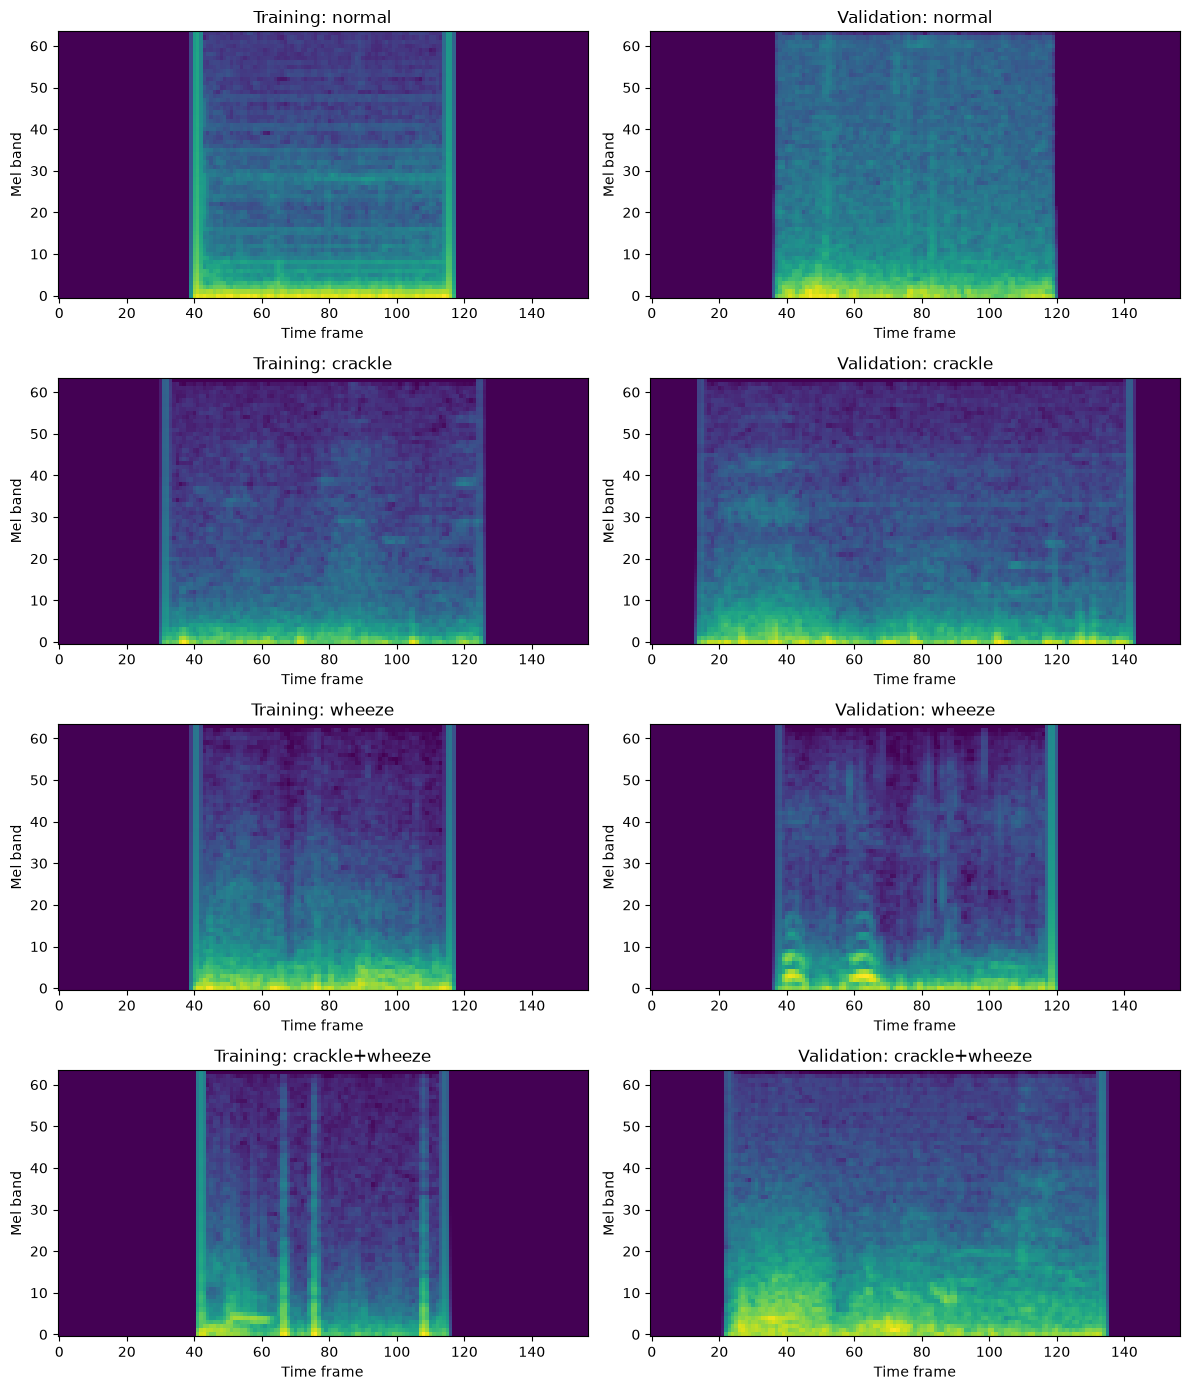

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Use a fixed random seed so the selected examples are reproducible
rng = np.random.default_rng(42)

# Create a figure with four rows and two columns
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 14)
)

for class_id, class_name in idx_to_class.items():

    # Find training examples belonging to this class
    train_indices = np.flatnonzero(
        y_train_new == class_id
    )

    # Find validation examples belonging to this class
    val_indices = np.flatnonzero(
        y_val_new == class_id
    )

    # Select one example from each split
    train_idx = rng.choice(train_indices)
    val_idx = rng.choice(val_indices)

    # Extract the 2D log-Mel arrays
    train_spec = X_train_new[train_idx, :, :, 0]
    val_spec = X_val_new[val_idx, :, :, 0]

    # Plot the training example
    axes[class_id, 0].imshow(
        train_spec,
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 0].set_title(
        f"Training: {class_name}"
    )
    axes[class_id, 0].set_xlabel("Time frame")
    axes[class_id, 0].set_ylabel("Mel band")

    # Plot the validation example
    axes[class_id, 1].imshow(
        val_spec,
        origin="lower",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    axes[class_id, 1].set_title(
        f"Validation: {class_name}"
    )
    axes[class_id, 1].set_xlabel("Time frame")
    axes[class_id, 1].set_ylabel("Mel band")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Compare the feature distributions in both datasets
for split_name, X, y in [
    ("Training", X_train_new, y_train_new),
    ("Validation", X_val_new, y_val_new)
]:
    print(f"\n========== {split_name} ==========")

    for class_id, class_name in idx_to_class.items():

        # Select spectrograms belonging to this class
        class_features = X[y == class_id]

        # Calculate the average feature value
        mean_value = class_features.mean()

        # Calculate the variation across feature values
        std_value = class_features.std()

        # Estimate how many pixels have very low values
        low_value_pct = (
            np.mean(class_features < 0.05) * 100
        )

        print(f"\nClass: {class_name}")
        print("Number of examples:", len(class_features))
        print("Mean feature value:", round(float(mean_value), 4))
        print("Feature standard deviation:", round(float(std_value), 4))
        print(
            "Values below 0.05 (%):",
            round(float(low_value_pct), 2)
        )


========== Training ==========

Class: normal
Number of examples: 1694
Mean feature value: 0.2003
Feature standard deviation: 0.2344
Values below 0.05 (%): 46.64

Class: crackle
Number of examples: 1012
Mean feature value: 0.184
Feature standard deviation: 0.2217
Values below 0.05 (%): 48.88

Class: wheeze
Number of examples: 405
Mean feature value: 0.1887
Feature standard deviation: 0.2286
Values below 0.05 (%): 47.95

Class: crackle+wheeze
Number of examples: 265
Mean feature value: 0.1907
Feature standard deviation: 0.2263
Values below 0.05 (%): 45.87

========== Validation ==========

Class: normal
Number of examples: 359
Mean feature value: 0.1782
Feature standard deviation: 0.2145
Values below 0.05 (%): 46.85

Class: crackle
Number of examples: 174
Mean feature value: 0.2087
Feature standard deviation: 0.2249
Values below 0.05 (%): 41.53

Class: wheeze
Number of examples: 81
Mean feature value: 0.1437
Feature standard deviation: 0.1976
Values below 0.05 (%): 51.79

Class: crackl

In [ ]:
import numpy as np
from scipy.stats import spearmanr

def check_duration_relationship(split_name, X, metadata):

    # Calculate the original duration of each annotated segment
    durations = (
        metadata["end"] - metadata["start"]
    ).to_numpy()

    # Calculate the mean feature value for each spectrogram
    feature_means = X.mean(axis=(1, 2, 3))

    # Calculate the fraction of very low-valued spectrogram entries
    low_value_fractions = (
        X < 0.05
    ).mean(axis=(1, 2, 3))

    print(f"\n========== {split_name} ==========")

    # Examine each class separately
    for class_name in CLASSES:

        # Select the segments belonging to this class
        mask = (
            metadata["label"].to_numpy() == class_name
        )

        class_durations = durations[mask]
        class_means = feature_means[mask]
        class_low_values = low_value_fractions[mask]

        # Correlate duration with mean feature value
        mean_rho = spearmanr(
            class_durations,
            class_means
        ).statistic

        # Correlate duration with the fraction of low values
        low_rho = spearmanr(
            class_durations,
            class_low_values
        ).statistic

        print(f"\nClass: {class_name}")
        print(
            "Duration vs mean feature value:",
            round(float(mean_rho), 3)
        )
        print(
            "Duration vs low-value fraction:",
            round(float(low_rho), 3)
        )


# Run the diagnostic on training data
check_duration_relationship(
    "Training",
    X_train_new,
    meta_train_new
)

# Run the diagnostic on validation data
check_duration_relationship(
    "Validation",
    X_val_new,
    meta_val_new
)
from scipy.stats import spearmanr

def check_duration_relationship(split_name, X, metadata):

    # Calculate the original duration of each annotated segment
    durations = (
        metadata["end"] - metadata["start"]
    ).to_numpy()

    # Calculate the mean feature value for each spectrogram
    feature_means = X.mean(axis=(1, 2, 3))

    # Calculate the fraction of very low-valued spectrogram entries
    low_value_fractions = (
        X < 0.05
    ).mean(axis=(1, 2, 3))

    print(f"\n========== {split_name} ==========")

    # Examine each class separately
    for class_name in CLASSES:

        # Select the segments belonging to this class
        mask = (
            metadata["label"].to_numpy() == class_name
        )

        class_durations = durations[mask]
        class_means = feature_means[mask]
        class_low_values = low_value_fractions[mask]

        # Correlate duration with mean feature value
        mean_rho = spearmanr(
            class_durations,
            class_means
        ).statistic

        # Correlate duration with the fraction of low values
        low_rho = spearmanr(
            class_durations,
            class_low_values
        ).statistic

        print(f"\nClass: {class_name}")
        print(
            "Duration vs mean feature value:",
            round(float(mean_rho), 3)
        )
        print(
            "Duration vs low-value fraction:",
            round(float(low_rho), 3)
        )


# Run the diagnostic on training data
check_duration_relationship(
    "Training",
    X_train_new,
    meta_train_new
)

# Run the diagnostic on validation data
check_duration_relationship(
    "Validation",
    X_val_new,
    meta_val_new
)


========== Training ==========

Class: normal
Duration vs mean feature value: 0.82
Duration vs low-value fraction: -0.962

Class: crackle
Duration vs mean feature value: 0.767
Duration vs low-value fraction: -0.973

Class: wheeze
Duration vs mean feature value: 0.731
Duration vs low-value fraction: -0.904

Class: crackle+wheeze
Duration vs mean feature value: 0.602
Duration vs low-value fraction: -0.82

========== Validation ==========

Class: normal
Duration vs mean feature value: 0.798
Duration vs low-value fraction: -0.924

Class: crackle
Duration vs mean feature value: 0.851
Duration vs low-value fraction: -0.966

Class: wheeze
Duration vs mean feature value: 0.799
Duration vs low-value fraction: -0.926

Class: crackle+wheeze
Duration vs mean feature value: 0.434
Duration vs low-value fraction: -0.821

========== Training ==========

Class: normal
Duration vs mean feature value: 0.82
Duration vs low-value fraction: -0.962

Class: crackle
Duration vs mean feature value: 0.767
Durat

In [ ]:
import numpy as np

def resize_logmel_time(log_mel, target_frames=157):

    # Find the number of time frames in the original spectrogram
    source_frames = log_mel.shape[1]

    # If it already has the required number of frames, return it
    if source_frames == target_frames:
        return log_mel.astype(np.float32)

    # Create evenly spaced time positions for the original spectrogram
    source_positions = np.linspace(
        0.0, 1.0, source_frames
    )

    # Create evenly spaced positions for the resized spectrogram
    target_positions = np.linspace(
        0.0, 1.0, target_frames
    )

    # Allocate an output array with 64 Mel bands and target_frames
    resized = np.empty(
        (log_mel.shape[0], target_frames),
        dtype=np.float32
    )

    # Resize each Mel band's values along the time dimension
    for band_index in range(log_mel.shape[0]):

        resized[band_index] = np.interp(
            target_positions,
            source_positions,
            log_mel[band_index]
        )

    # Return the resized spectrogram
    return resized

In [ ]:
import librosa
import numpy as np

# Select one annotated training segment
sample_row = meta_train_new.iloc[0]

# Load its original recording at the target sampling rate
audio, sr = librosa.load(
    sample_row["wav_path"],
    sr=TARGET_SR,
    mono=True
)

# Convert the annotation timestamps into sample indices
start_idx = int(np.floor(sample_row["start"] * sr))
end_idx = int(np.ceil(sample_row["end"] * sr))

# Keep the indices within the recording boundaries
start_idx = max(0, start_idx)
end_idx = min(len(audio), end_idx)

# Extract the actual annotated audio
segment = audio[start_idx:end_idx]

# Centre-crop only if the segment exceeds five seconds
if len(segment) > TARGET_SAMPLES:
    segment = fit_audio_length(
        segment,
        TARGET_SAMPLES
    )

# Extract features without padding the waveform to five seconds
log_mel_variable = extract_logmel(segment)

# Resize the time dimension to 157 frames
log_mel_resized = resize_logmel_time(
    log_mel_variable,
    target_frames=X_train_new.shape[2]
)

# Display the results
print("Original segment duration:", round(len(segment) / sr, 3), "seconds")
print("Before resizing:", log_mel_variable.shape)
print("After resizing:", log_mel_resized.shape)
print("Minimum value:", round(float(log_mel_resized.min()), 4))
print("Maximum value:", round(float(log_mel_resized.max()), 4))
print("Data type:", log_mel_resized.dtype)

Original segment duration: 2.886 seconds
Before resizing: (64, 91)
After resizing: (64, 157)
Minimum value: 0.0
Maximum value: 0.9988
Data type: float32


In [ ]:
def build_features_resized(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # 1. Create a reproducible random-number generator
    rng = np.random.default_rng(random_seed)

    # 2. Create lists for features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # 3. Create counters for data-quality checks
    invalid_segments = 0
    cropped_segments = 0

    # 4. Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # 5. Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # 6. Process each annotated interval in the recording
        for _, row in group.iterrows():

            # Convert timestamps from seconds to sample indices
            start_idx = int(np.floor(row["start"] * sr))
            end_idx = int(np.ceil(row["end"] * sr))

            # Keep the indices within the recording boundaries
            start_idx = max(0, start_idx)
            end_idx = min(len(audio), end_idx)

            # Skip invalid intervals
            if end_idx <= start_idx:
                invalid_segments += 1
                continue

            # Extract the annotated audio segment
            segment = audio[start_idx:end_idx]

            # Crop only if the segment is longer than five seconds
            if len(segment) > TARGET_SAMPLES:
                cropped_segments += 1
                segment = fit_audio_length(
                    segment,
                    TARGET_SAMPLES
                )

            # Record the noise setting for this segment
            applied_snr = None

            # Optionally add simulated white noise
            if noise_snr_db is not None:

                if isinstance(
                    noise_snr_db,
                    (list, tuple, np.ndarray)
                ):
                    applied_snr = float(
                        rng.choice(noise_snr_db)
                    )
                else:
                    applied_snr = float(noise_snr_db)

                segment = add_white_noise_at_snr(
                    segment,
                    applied_snr,
                    rng
                )

            # Extract log-Mel features without five-second waveform padding
            log_mel = extract_logmel(segment)

            # Resize the time dimension to a fixed number of frames
            log_mel = resize_logmel_time(
                log_mel,
                target_frames=target_frames
            )

            # Add a channel dimension for the CNN
            log_mel = log_mel[..., np.newaxis]

            # Get the annotation label
            label = str(row["label"])

            # Check that the label exists in our class dictionary
            if label not in class_to_idx:
                raise ValueError(
                    f"Unknown label '{label}' in {wav_path}"
                )

            # Convert the label into its numerical ID
            label_id = class_to_idx[label]

            # Store the spectrogram and its corresponding label
            features.append(log_mel)
            labels.append(label_id)

            # Store information about the original audio interval
            metadata.append({
                "wav_path": str(wav_path),
                "recording": row["recording"],
                "patient": row["patient"],
                "start": float(row["start"]),
                "end": float(row["end"]),
                "label": label,
                "label_id": label_id,
                "noise_snr_db": applied_snr
            })

        # Display progress every 100 recordings
        if recording_number % 100 == 0:
            print(
                f"{split_name}: processed "
                f"{recording_number} recordings"
            )

    # Make sure the function produced at least one feature
    if not features:
        raise ValueError(
            f"No valid features generated for {split_name}"
        )

    # Convert the feature list into a NumPy array
    X = np.stack(features).astype(np.float32)

    # Convert the label list into an integer NumPy array
    y = np.asarray(labels, dtype=np.int64)

    # Convert metadata into a DataFrame
    metadata_df = pd.DataFrame(metadata)

    # Print a summary of the results
    print(f"\n{split_name} complete")
    print("Features shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Invalid segments skipped:", invalid_segments)
    print("Segments center-cropped:", cropped_segments)
    print(
        "Feature memory (MB):",
        round(X.nbytes / (1024 ** 2), 2)
    )

    # Return the features, labels, and metadata
    return X, y, metadata_df

In [ ]:
# Select three examples per class from the new training split
small_train_df = (
    candidate_train_df
    .groupby("label", group_keys=False)
    .head(3)
    .copy()
)

# Select three examples per class from the new validation split
small_val_df = (
    candidate_val_df
    .groupby("label", group_keys=False)
    .head(3)
    .copy()
)

print("Small training sample:", len(small_train_df))
print("Small validation sample:", len(small_val_df))

# Process the small training sample
X_small_train, y_small_train, meta_small_train = (
    build_features_resized(
        small_train_df,
        "small_train"
    )
)

# Process the small validation sample
X_small_val, y_small_val, meta_small_val = (
    build_features_resized(
        small_val_df,
        "small_validation"
    )
)

Small training sample: 12
Small validation sample: 12

small_train complete
Features shape: (12, 64, 157, 1)
Labels shape: (12,)
Invalid segments skipped: 0
Segments center-cropped: 0
Feature memory (MB): 0.46

small_validation complete
Features shape: (12, 64, 157, 1)
Labels shape: (12,)
Invalid segments skipped: 0
Segments center-cropped: 0
Feature memory (MB): 0.46


In [ ]:
# Check feature shapes and label alignment
print("Training features:", X_small_train.shape)
print("Validation features:", X_small_val.shape)

print(
    "Training labels match metadata:",
    np.array_equal(
        y_small_train,
        meta_small_train["label_id"].to_numpy(dtype=np.int64)
    )
)

print(
    "Validation labels match metadata:",
    np.array_equal(
        y_small_val,
        meta_small_val["label_id"].to_numpy(dtype=np.int64)
    )
)

print(
    "All training feature values finite:",
    np.isfinite(X_small_train).all()
)

print(
    "All validation feature values finite:",
    np.isfinite(X_small_val).all()
)

print(
    "Training feature range:",
    float(X_small_train.min()),
    "to",
    float(X_small_train.max())
)

Training features: (12, 64, 157, 1)
Validation features: (12, 64, 157, 1)
Training labels match metadata: True
Validation labels match metadata: True
All training feature values finite: True
All validation feature values finite: True
Training feature range: 0.0 to 1.0


In [ ]:
# Process all training segments using the new preprocessing method
X_train_resized, y_train_resized, meta_train_resized = (
    build_features_resized(
        candidate_train_df,
        "train_resized"
    )
)

# Process all validation segments using the same method
X_val_resized, y_val_resized, meta_val_resized = (
    build_features_resized(
        candidate_val_df,
        "validation_resized"
    )
)

print("\nFull resized dataset processing complete.")

train_resized: processed 100 recordings
train_resized: processed 200 recordings
train_resized: processed 300 recordings
train_resized: processed 400 recordings

train_resized complete
Features shape: (3376, 64, 157, 1)
Labels shape: (3376,)
Invalid segments skipped: 0
Segments center-cropped: 156
Feature memory (MB): 129.4

validation_resized complete
Features shape: (649, 64, 157, 1)
Labels shape: (649,)
Invalid segments skipped: 0
Segments center-cropped: 14
Feature memory (MB): 24.88

Full resized dataset processing complete.


In [ ]:
# Check the dimensions of both datasets
print("Training feature shape:", X_train_resized.shape)
print("Training label shape:", y_train_resized.shape)

print("\nValidation feature shape:", X_val_resized.shape)
print("Validation label shape:", y_val_resized.shape)

# Check that the labels match the metadata
print(
    "\nTraining labels match metadata:",
    np.array_equal(
        y_train_resized,
        meta_train_resized["label_id"].to_numpy(dtype=np.int64)
    )
)

print(
    "Validation labels match metadata:",
    np.array_equal(
        y_val_resized,
        meta_val_resized["label_id"].to_numpy(dtype=np.int64)
    )
)

# Check that the features contain valid numerical values
print(
    "\nTraining values finite:",
    np.isfinite(X_train_resized).all()
)

print(
    "Validation values finite:",
    np.isfinite(X_val_resized).all()
)

print(
    "Training feature range:",
    float(X_train_resized.min()),
    "to",
    float(X_train_resized.max())
)

Training feature shape: (3376, 64, 157, 1)
Training label shape: (3376,)

Validation feature shape: (649, 64, 157, 1)
Validation label shape: (649,)

Training labels match metadata: True
Validation labels match metadata: True

Training values finite: True
Validation values finite: True
Training feature range: 0.0 to 1.0


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Get the four numerical class IDs
classes = np.arange(len(CLASSES))

# Check which class IDs are present
present_classes = np.unique(y_train_resized)

if len(present_classes) != len(CLASSES):
    raise ValueError("At least one class is missing from training.")

# Calculate balanced weights from the resized training labels
weights_resized = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_resized
)

# Create the dictionary used by Keras during training
class_weights_resized = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights_resized)
}

# Print each class and its weight
print("Class weights for resized features:")

for class_id, weight in class_weights_resized.items():
    print(
        f"{idx_to_class[class_id]}: {weight:.3f}"
    )

Class weights for resized features:
normal: 0.498
crackle: 0.834
wheeze: 2.084
crackle+wheeze: 3.185


In [ ]:

# Create a fresh CNN for the resized spectrograms
resized_model = keras.Sequential([
    layers.Input(shape=X_train_resized.shape[1:]),

    # Block 1: learn 16 patterns
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2: learn 32 patterns
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3: learn 64 patterns
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),

    # Preserve coarse time-frequency information
    layers.AveragePooling2D((4, 4)),
    layers.Flatten(),

    # Learn a compact representation
    layers.Dense(32, activation="relu"),

    # Predict probabilities for four classes
    layers.Dense(len(CLASSES), activation="softmax")
])

# Configure the learning process
resized_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model's parameter count and architecture
print("Total parameters:", resized_model.count_params())
resized_model.summary()


Total parameters: 97188


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,188 (379.64 KB)

 Trainable params: 97,188 (379.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from pathlib import Path
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Create the folder for saving models
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Choose a separate checkpoint filename
resized_checkpoint = models_dir / "best_resized_logmel_cnn.keras"

# Stop when validation loss stops improving
resized_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)

# Save the model with the best validation loss
resized_model_checkpoint = ModelCheckpoint(
    filepath=str(resized_checkpoint),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Reduce the learning rate when progress stalls
resized_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

# Combine all callbacks into one list
resized_callbacks = [
    resized_early_stopping,
    resized_model_checkpoint,
    resized_reduce_lr
]

print("Resized-feature model callbacks prepared.")
print("Checkpoint:", resized_checkpoint.resolve())

Resized-feature model callbacks prepared.
Checkpoint: C:\Users\Admin\Respiratory_TinyML\models\best_resized_logmel_cnn.keras


In [ ]:
# Train the new CNN using resized training features
resized_history = resized_model.fit(
    X_train_resized,
    y_train_resized,

    # Monitor performance on the validation set
    validation_data=(X_val_resized, y_val_resized),

    # Maximum number of epochs
    epochs=30,

    # Number of examples processed per batch
    batch_size=32,

    # Account for the imbalance between classes
    class_weight=class_weights_resized,

    # Use our callbacks
    callbacks=resized_callbacks,

    # Shuffle training examples between epochs
    shuffle=True,

    # Display progress during training
    verbose=1
)

print("Resized-feature CNN training complete.")

Epoch 1/30
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.3283 - loss: 1.3818
Epoch 1: val_loss improved from None to 1.36146, saving model to ..\models\best_resized_logmel_cnn.keras

Epoch 1: finished saving model to ..\models\best_resized_logmel_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.3288 - loss: 1.3817 - val_accuracy: 0.4792 - val_loss: 1.3615 - learning_rate: 0.0010
Epoch 2/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.3353 - loss: 1.3692
Epoch 2: val_loss did not improve from 1.36146
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.3353 - loss: 1.3692 - val_accuracy: 0.4068 - val_loss: 1.3896 - learning_rate: 0.0010
Epoch 3/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3664 - loss: 1.3527
Epoch 3: val_loss did not improve from 1.36146
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.3664 - loss: 1.3527 - val_accuracy: 0.3975 - val_loss: 1.4158 - learning_rate: 0.0010
Epoch 4/30
106/106 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Evaluate the model on resized validation features
val_loss_resized, val_acc_resized = resized_model.evaluate(
    X_val_resized,
    y_val_resized,
    batch_size=32,
    verbose=0
)

print("Validation loss:", round(val_loss_resized, 4))
print("Validation accuracy:", round(val_acc_resized, 4))

# 2. Obtain the predicted probabilities for each class
val_probabilities_resized = resized_model.predict(
    X_val_resized,
    batch_size=32,
    verbose=0
)

# 3. Choose the class with the highest probability
val_predictions_resized = np.argmax(
    val_probabilities_resized,
    axis=1
)

# 4. Calculate accuracy and macro-F1
print(
    "\nAccuracy:",
    round(accuracy_score(
        y_val_resized,
        val_predictions_resized
    ), 4)
)

print(
    "Macro-F1:",
    round(f1_score(
        y_val_resized,
        val_predictions_resized,
        average="macro",
        zero_division=0
    ), 4)
)

# 5. Count predictions for every class
print("\nPredicted class counts:")

for class_id, class_name in idx_to_class.items():
    print(
        f"{class_name}:",
        int(np.sum(val_predictions_resized == class_id))
    )

# 6. Display the confusion matrix
print("\nConfusion matrix:")

print(
    confusion_matrix(
        y_val_resized,
        val_predictions_resized,
        labels=np.arange(len(CLASSES))
    )
)

# 7. Display class-wise performance
print("\nClassification report:")

print(
    classification_report(
        y_val_resized,
        val_predictions_resized,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

Validation loss: 1.1699
Validation accuracy: 0.4284

Accuracy: 0.4284
Macro-F1: 0.2352

Predicted class counts:
normal: 406
crackle: 209
wheeze: 14
crackle+wheeze: 20

Confusion matrix:
[[232 114   4   9]
 [124  42   5   3]
 [ 33  40   2   6]
 [ 17  13   3   2]]

Classification report:
                precision    recall  f1-score   support

        normal       0.57      0.65      0.61       359
       crackle       0.20      0.24      0.22       174
        wheeze       0.14      0.02      0.04        81
crackle+wheeze       0.10      0.06      0.07        35

      accuracy                           0.43       649
     macro avg       0.25      0.24      0.24       649
  weighted avg       0.39      0.43      0.40       649



In [ ]:

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# 1. Predict the training examples using the resized-feature model
train_probabilities_resized = resized_model.predict(
    X_train_resized,
    batch_size=32,
    verbose=0
)

# 2. Convert probabilities into predicted class IDs
train_predictions_resized = np.argmax(
    train_probabilities_resized,
    axis=1
)

# 3. Calculate training accuracy and macro-F1
train_accuracy_resized = accuracy_score(
    y_train_resized,
    train_predictions_resized
)

train_macro_f1_resized = f1_score(
    y_train_resized,
    train_predictions_resized,
    average="macro",
    zero_division=0
)

print("Training accuracy:", round(train_accuracy_resized, 4))
print("Training macro-F1:", round(train_macro_f1_resized, 4))

# 4. Display per-class training performance
print("\nTraining classification report:")

print(
    classification_report(
        y_train_resized,
        train_predictions_resized,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)


Training accuracy: 0.5711
Training macro-F1: 0.4151

Training classification report:
                precision    recall  f1-score   support

        normal       0.64      0.75      0.69      1694
       crackle       0.48      0.53      0.51      1012
        wheeze       0.47      0.20      0.28       405
crackle+wheeze       0.34      0.12      0.18       265

      accuracy                           0.57      3376
     macro avg       0.49      0.40      0.42      3376
  weighted avg       0.55      0.57      0.55      3376



In [ ]:
import numpy as np

def fit_logmel_frames(log_mel, target_frames=157):

    # Find the current number of time frames
    source_frames = log_mel.shape[1]

    # If the spectrogram is too long, crop its time dimension
    if source_frames > target_frames:

        start = (source_frames - target_frames) // 2

        log_mel = log_mel[
            :, start:start + target_frames
        ]

    # If it is too short, add zero-valued frames
    elif source_frames < target_frames:

        total_padding = target_frames - source_frames

        left_padding = total_padding // 2

        right_padding = total_padding - left_padding

        log_mel = np.pad(
            log_mel,
            ((0, 0), (left_padding, right_padding)),
            mode="constant",
            constant_values=0.0
        )

    # Return the result as a float32 array
    return log_mel.astype(np.float32)

In [ ]:
# Select one training segment
sample_row = meta_train_new.iloc[0]

# Load its recording
audio, sr = librosa.load(
    sample_row["wav_path"],
    sr=TARGET_SR,
    mono=True
)

# Convert the annotation times to sample indices
start_idx = int(np.floor(sample_row["start"] * sr))
end_idx = int(np.ceil(sample_row["end"] * sr))

# Keep the indices inside the recording
start_idx = max(0, start_idx)
end_idx = min(len(audio), end_idx)

# Extract the actual annotated segment
segment = audio[start_idx:end_idx]

# Centre-crop only if it exceeds five seconds
if len(segment) > TARGET_SAMPLES:
    segment = fit_audio_length(
        segment,
        TARGET_SAMPLES
    )

# Extract features before adding any padding
log_mel_original = extract_logmel(segment)

# Pad or crop only the spectrogram's time dimension
log_mel_padded = fit_logmel_frames(
    log_mel_original,
    target_frames=157
)

print(
    "Original segment duration:",
    round(len(segment) / sr, 3),
    "seconds"
)

print("Before frame padding:", log_mel_original.shape)
print("After frame padding:", log_mel_padded.shape)

print(
    "Feature range:",
    float(log_mel_padded.min()),
    "to",
    float(log_mel_padded.max())
)

print("Data type:", log_mel_padded.dtype)

Original segment duration: 2.886 seconds
Before frame padding: (64, 91)
After frame padding: (64, 157)
Feature range: 0.0 to 1.0
Data type: float32


In [ ]:
def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated interval
        for _, row in group.iterrows():

            # Convert timestamps from seconds to sample indices
            start_idx = int(np.floor(row["start"] * sr))
            end_idx = int(np.ceil(row["end"] * sr))

            # Keep indices within the recording boundaries
            start_idx = max(0, start_idx)
            end_idx = min(len(audio), end_idx)

            # Skip invalid intervals
            if end_idx <= start_idx:
                invalid_segments += 1
                continue

            # Extract the annotated audio segment
            segment = audio[start_idx:end_idx]

            # Crop long segments, but do not pad short waveforms
            if len(segment) > TARGET_SAMPLES:
                audio_cropped_segments += 1

                segment = fit_audio_length(
                    segment,
                    TARGET_SAMPLES
                )

            # Record the noise setting for this segment
            applied_snr = None

            # Add synthetic white noise only when requested
            if noise_snr_db is not None:

                if isinstance(
                    noise_snr_db,
                    (list, tuple, np.ndarray)
                ):
                    applied_snr = float(
                        rng.choice(noise_snr_db)
                    )
                else:
                    applied_snr = float(noise_snr_db)

                segment = add_white_noise_at_snr(
                    segment,
                    applied_snr,
                    rng
                )

            # Extract features from the actual segment
            log_mel = extract_logmel(segment)

            # Track how many spectrograms need frame adjustment
            source_frames = log_mel.shape[1]

            if source_frames < target_frames:
                frame_padded_segments += 1

            elif source_frames > target_frames:
                frame_cropped_segments += 1

            # Pad or crop the spectrogram's time dimension
            log_mel = fit_logmel_frames(
                log_mel,
                target_frames=target_frames
            )

            # Add the channel dimension required by the CNN
            log_mel = log_mel[..., np.newaxis]

            # Get the label from the annotation
            label = str(row["label"])

            # Ensure the label is in our class mapping
            if label not in class_to_idx:
                raise ValueError(
                    f"Unknown label '{label}' in {wav_path}"
                )

            # Convert the class name to an integer
            label_id = class_to_idx[label]

            # Store the features and their corresponding label
            features.append(log_mel)
            labels.append(label_id)

            # Store information about the original audio segment
            metadata.append({
                "wav_path": str(wav_path),
                "recording": row["recording"],
                "patient": row["patient"],
                "start": float(row["start"]),
                "end": float(row["end"]),
                "label": label,
                "label_id": label_id,
                "noise_snr_db": applied_snr
            })

        # Display progress every 100 recordings
        if recording_number % 100 == 0:
            print(
                f"{split_name}: processed "
                f"{recording_number} recordings"
            )

    # Stop if no valid features were generated
    if not features:
        raise ValueError(
            f"No valid features generated for {split_name}"
        )

    # Convert the feature list into a NumPy array
    X = np.stack(features).astype(np.float32)

    # Convert labels into an integer NumPy array
    y = np.asarray(labels, dtype=np.int64)

    # Convert metadata into a DataFrame
    metadata_df = pd.DataFrame(metadata)

    # Display a summary
    print(f"\n{split_name} complete")
    print("Features shape:", X.shape)
    print("Labels shape:", y.shape)
    print("Invalid segments skipped:", invalid_segments)
    print("Audio segments centre-cropped:", audio_cropped_segments)
    print("Spectrograms frame-padded:", frame_padded_segments)
    print("Spectrograms frame-cropped:", frame_cropped_segments)
    print(
        "Feature memory (MB):",
        round(X.nbytes / (1024 ** 2), 2)
    )

    # Return all three outputs
    return X, y, metadata_df

In [ ]:
# Select three examples per class from training
small_train_df = (
    candidate_train_df
    .groupby("label", group_keys=False)
    .head(3)
    .copy()
)

# Select three examples per class from validation
small_val_df = (
    candidate_val_df
    .groupby("label", group_keys=False)
    .head(3)
    .copy()
)

# Process the small training sample
X_frame_train, y_frame_train, meta_frame_train = (
    build_features_framepad(
        small_train_df,
        "small_frame_train"
    )
)

# Process the small validation sample
X_frame_val, y_frame_val, meta_frame_val = (
    build_features_framepad(
        small_val_df,
        "small_frame_validation"
    )
)


small_frame_train complete
Features shape: (12, 64, 157, 1)
Labels shape: (12,)
Invalid segments skipped: 0
Audio segments centre-cropped: 0
Spectrograms frame-padded: 12
Spectrograms frame-cropped: 0
Feature memory (MB): 0.46

small_frame_validation complete
Features shape: (12, 64, 157, 1)
Labels shape: (12,)
Invalid segments skipped: 0
Audio segments centre-cropped: 0
Spectrograms frame-padded: 12
Spectrograms frame-cropped: 0
Feature memory (MB): 0.46


In [ ]:
# Check the feature and label shapes
print("Training features:", X_frame_train.shape)
print("Training labels:", y_frame_train.shape)

print("\nValidation features:", X_frame_val.shape)
print("Validation labels:", y_frame_val.shape)

# Check label alignment with metadata
print(
    "\nTraining labels match metadata:",
    np.array_equal(
        y_frame_train,
        meta_frame_train["label_id"].to_numpy(dtype=np.int64)
    )
)

print(
    "Validation labels match metadata:",
    np.array_equal(
        y_frame_val,
        meta_frame_val["label_id"].to_numpy(dtype=np.int64)
    )
)

# Check that values are finite and within the expected range
print(
    "\nTraining values finite:",
    np.isfinite(X_frame_train).all()
)

print(
    "Validation values finite:",
    np.isfinite(X_frame_val).all()
)

print(
    "Training feature range:",
    float(X_frame_train.min()),
    "to",
    float(X_frame_train.max())
)

Training features: (12, 64, 157, 1)
Training labels: (12,)

Validation features: (12, 64, 157, 1)
Validation labels: (12,)

Training labels match metadata: True
Validation labels match metadata: True

Training values finite: True
Validation values finite: True
Training feature range: 0.0 to 1.0


In [ ]:
# Process all training segments using spectrogram frame padding
X_train_framepad, y_train_framepad, meta_train_framepad = (
    build_features_framepad(
        candidate_train_df,
        "train_framepad",
        target_frames=X_train_new.shape[2]
    )
)

# Process all validation segments using the same method
X_val_framepad, y_val_framepad, meta_val_framepad = (
    build_features_framepad(
        candidate_val_df,
        "validation_framepad",
        target_frames=X_train_new.shape[2]
    )
)

print("Full frame-padding preprocessing complete.")

train_framepad: processed 100 recordings
train_framepad: processed 200 recordings
train_framepad: processed 300 recordings
train_framepad: processed 400 recordings

train_framepad complete
Features shape: (3376, 64, 157, 1)
Labels shape: (3376,)
Invalid segments skipped: 0
Audio segments centre-cropped: 156
Spectrograms frame-padded: 3218
Spectrograms frame-cropped: 0
Feature memory (MB): 129.4

validation_framepad complete
Features shape: (649, 64, 157, 1)
Labels shape: (649,)
Invalid segments skipped: 0
Audio segments centre-cropped: 14
Spectrograms frame-padded: 635
Spectrograms frame-cropped: 0
Feature memory (MB): 24.88
Full frame-padding preprocessing complete.


In [ ]:
import numpy as np

# Check feature and label dimensions
print("Training features:", X_train_framepad.shape)
print("Training labels:", y_train_framepad.shape)

print("\nValidation features:", X_val_framepad.shape)
print("Validation labels:", y_val_framepad.shape)

# Verify that labels still match the corresponding metadata
print(
    "\nTraining labels match metadata:",
    np.array_equal(
        y_train_framepad,
        meta_train_framepad["label_id"].to_numpy(dtype=np.int64)
    )
)

print(
    "Validation labels match metadata:",
    np.array_equal(
        y_val_framepad,
        meta_val_framepad["label_id"].to_numpy(dtype=np.int64)
    )
)

# Check for invalid numerical values
print(
    "\nTraining values finite:",
    np.isfinite(X_train_framepad).all()
)

print(
    "Validation values finite:",
    np.isfinite(X_val_framepad).all()
)

# Inspect the normalized feature range
print(
    "Training feature range:",
    float(X_train_framepad.min()),
    "to",
    float(X_train_framepad.max())
)

# Confirm that all four classes are still represented
print("\nTraining class counts:")

for class_id, class_name in idx_to_class.items():
    print(
        class_name,
        ":",
        int(np.sum(y_train_framepad == class_id))
    )

Training features: (3376, 64, 157, 1)
Training labels: (3376,)

Validation features: (649, 64, 157, 1)
Validation labels: (649,)

Training labels match metadata: True
Validation labels match metadata: True

Training values finite: True
Validation values finite: True
Training feature range: 0.0 to 1.0

Training class counts:
normal : 1694
crackle : 1012
wheeze : 405
crackle+wheeze : 265


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# 1. Calculate class weights from the training labels only
class_ids = np.unique(y_train_framepad)

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train_framepad
)

class_weights_framepad = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids, weights)
}

print("Class weights:")
for class_id, class_name in idx_to_class.items():
    print(f"{class_name}: {class_weights_framepad[class_id]:.3f}")


# 2. Create a fresh CNN for the frame-padded features
framepad_model = keras.Sequential([
    layers.Input(shape=X_train_framepad.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax")
])


# 3. Configure the model for training
framepad_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Display the architecture
framepad_model.summary()

Class weights:
normal: 0.498
crackle: 0.834
wheeze: 2.084
crackle+wheeze: 3.185


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_27 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,188 (379.64 KB)

 Trainable params: 97,188 (379.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

# Save the model with the lowest validation loss
framepad_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    # Stop if validation loss stops improving
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate if validation loss plateaus
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_framepad = framepad_model.fit(
    X_train_framepad,
    y_train_framepad,
    validation_data=(
        X_val_framepad,
        y_val_framepad
    ),
    epochs=40,
    batch_size=32,
    class_weight=class_weights_framepad,
    callbacks=framepad_callbacks,
    verbose=1
)

Epoch 1/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.3845 - loss: 1.3696
Epoch 1: val_loss improved from None to 1.47107, saving model to best_framepad_cnn.keras

Epoch 1: finished saving model to best_framepad_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.3854 - loss: 1.3672 - val_accuracy: 0.2512 - val_loss: 1.4711 - learning_rate: 0.0010
Epoch 2/40
104/106 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4153 - loss: 1.3122
Epoch 2: val_loss improved from 1.47107 to 1.36553, saving model to best_framepad_cnn.keras

Epoch 2: finished saving model to best_framepad_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.4141 - loss: 1.3109 - val_accuracy: 0.2743 - val_loss: 1.3655 - learning_rate: 0.0010
Epoch 3/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4174 - loss: 1.2868
Epoch 3: val_loss did not improve from 1.36553
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.4174 - loss: 1.2868 - val_accuracy: 0.2758 - val_loss

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# 1. Predict probabilities for validation segments
val_probabilities = framepad_model.predict(
    X_val_framepad,
    batch_size=32,
    verbose=1
)

# 2. Convert probabilities to predicted class IDs
y_val_pred_framepad = np.argmax(val_probabilities, axis=1)

# 3. Calculate overall metrics
print("Validation accuracy:",
      round(accuracy_score(y_val_framepad, y_val_pred_framepad), 4))

print("Validation macro-F1:",
      round(f1_score(
          y_val_framepad,
          y_val_pred_framepad,
          average="macro",
          zero_division=0
      ), 4))

print("Validation balanced accuracy:",
      round(balanced_accuracy_score(
          y_val_framepad,
          y_val_pred_framepad
      ), 4))

# 4. Detailed performance for each class
print("\nClassification report:")
print(classification_report(
    y_val_framepad,
    y_val_pred_framepad,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0,
    digits=3
))

# 5. Confusion matrix: rows = actual, columns = predicted
cm_framepad = confusion_matrix(
    y_val_framepad,
    y_val_pred_framepad,
    labels=list(range(len(CLASSES)))
)

print("Confusion matrix:")
print("Class order:", CLASSES)
print(cm_framepad)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Validation accuracy: 0.4268
Validation macro-F1: 0.2424
Validation balanced accuracy: 0.2575

Classification report:
                precision    recall  f1-score   support

        normal      0.599     0.677     0.635       359
       crackle      0.231     0.086     0.126       174
        wheeze      0.128     0.210     0.159        81
crackle+wheeze      0.044     0.057     0.050        35

      accuracy                          0.427       649
     macro avg      0.250     0.258     0.242       649
  weighted avg      0.411     0.427     0.408       649

Confusion matrix:
Class order: ['normal', 'crackle', 'wheeze', 'crackle+wheeze']
[[243  36  57  23]
 [119  15  36   4]
 [ 35  13  17  16]
 [  9   1  23   2]]


In [ ]:
from sklearn.metrics import classification_report, f1_score, accuracy_score
import numpy as np

# Predict the training examples using the restored best model
train_probabilities_framepad = framepad_model.predict(
    X_train_framepad,
    batch_size=32,
    verbose=1
)

y_train_pred_framepad = np.argmax(
    train_probabilities_framepad,
    axis=1
)

print(
    "Training accuracy:",
    round(accuracy_score(
        y_train_framepad,
        y_train_pred_framepad
    ), 4)
)

print(
    "Training macro-F1:",
    round(f1_score(
        y_train_framepad,
        y_train_pred_framepad,
        average="macro",
        zero_division=0
    ), 4)
)

print("\nTraining classification report:")
print(classification_report(
    y_train_framepad,
    y_train_pred_framepad,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=3,
    zero_division=0
))

106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Training accuracy: 0.5699
Training macro-F1: 0.4692

Training classification report:
                precision    recall  f1-score   support

        normal      0.711     0.690     0.700      1694
       crackle      0.626     0.477     0.541      1012
        wheeze      0.296     0.489     0.369       405
crackle+wheeze      0.253     0.279     0.266       265

      accuracy                          0.570      3376
     macro avg      0.472     0.484     0.469      3376
  weighted avg      0.600     0.570     0.579      3376



In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Create a fresh model with the same convolution layers
# as the previous frame-padding model.
framepad_gap_model = keras.Sequential([
    layers.Input(shape=X_train_framepad.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    # Change: summarize each feature map instead of flattening it
    layers.GlobalAveragePooling2D(),

    layers.Dense(32, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax")
])

framepad_gap_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

framepad_gap_model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,508 (99.64 KB)

 Trainable params: 25,508 (99.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

framepad_gap_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_gap_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_framepad_gap = framepad_gap_model.fit(
    X_train_framepad,
    y_train_framepad,
    validation_data=(
        X_val_framepad,
        y_val_framepad
    ),
    epochs=40,
    batch_size=32,
    class_weight=class_weights_framepad,
    callbacks=framepad_gap_callbacks,
    verbose=1
)

Epoch 1/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.4411 - loss: 1.3869
Epoch 1: val_loss improved from None to 1.38415, saving model to best_framepad_gap_cnn.keras

Epoch 1: finished saving model to best_framepad_gap_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step - accuracy: 0.4411 - loss: 1.3869 - val_accuracy: 0.5532 - val_loss: 1.3841 - learning_rate: 0.0010
Epoch 2/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3256 - loss: 1.3871
Epoch 2: val_loss improved from 1.38415 to 1.38401, saving model to best_framepad_gap_cnn.keras

Epoch 2: finished saving model to best_framepad_gap_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.3258 - loss: 1.3864 - val_accuracy: 0.4530 - val_loss: 1.3840 - learning_rate: 0.0010
Epoch 3/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3943 - loss: 1.3859
Epoch 3: val_loss did not improve from 1.38401
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.3943 - loss: 1.3859 - val_accuracy: 0

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Predict on the same validation set used for the previous model
val_probabilities_gap = framepad_gap_model.predict(
    X_val_framepad,
    batch_size=32,
    verbose=1
)

y_val_pred_gap = np.argmax(val_probabilities_gap, axis=1)

print(
    "Validation accuracy:",
    round(accuracy_score(y_val_framepad, y_val_pred_gap), 4)
)

print(
    "Validation macro-F1:",
    round(f1_score(
        y_val_framepad,
        y_val_pred_gap,
        average="macro",
        zero_division=0
    ), 4)
)

print(
    "Validation balanced accuracy:",
    round(balanced_accuracy_score(
        y_val_framepad,
        y_val_pred_gap
    ), 4)
)

print("\nClassification report:")
print(classification_report(
    y_val_framepad,
    y_val_pred_gap,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=3,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print("Class order:", CLASSES)
print(confusion_matrix(
    y_val_framepad,
    y_val_pred_gap,
    labels=list(range(len(CLASSES)))
))

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Validation accuracy: 0.4484
Validation macro-F1: 0.2324
Validation balanced accuracy: 0.261

Classification report:
                precision    recall  f1-score   support

        normal      0.562     0.721     0.632       359
       crackle      0.169     0.063     0.092       174
        wheeze      0.171     0.259     0.206        81
crackle+wheeze      0.000     0.000     0.000        35

      accuracy                          0.448       649
     macro avg      0.225     0.261     0.232       649
  weighted avg      0.377     0.448     0.400       649

Confusion matrix (rows = actual, columns = predicted):
Class order: ['normal', 'crackle', 'wheeze', 'crackle+wheeze']
[[259  41  59   0]
 [122  11  41   0]
 [ 49  11  21   0]
 [ 31   2   2   0]]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

framepad_dropout_model = keras.Sequential([
    layers.Input(shape=X_train_framepad.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),

    # Regularization: randomly deactivate 30% of activations
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),

    # Additional, lighter regularization
    layers.Dropout(0.2),

    layers.Dense(len(CLASSES), activation="softmax")
])

framepad_dropout_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

framepad_dropout_model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,188 (379.64 KB)

 Trainable params: 97,188 (379.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

framepad_dropout_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_dropout_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_framepad_dropout = framepad_dropout_model.fit(
    X_train_framepad,
    y_train_framepad,
    validation_data=(
        X_val_framepad,
        y_val_framepad
    ),
    epochs=40,
    batch_size=32,
    class_weight=class_weights_framepad,
    callbacks=framepad_dropout_callbacks,
    verbose=1
)

Epoch 1/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3297 - loss: 1.3812
Epoch 1: val_loss improved from None to 1.35668, saving model to best_framepad_dropout_cnn.keras

Epoch 1: finished saving model to best_framepad_dropout_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 8s 47ms/step - accuracy: 0.3297 - loss: 1.3812 - val_accuracy: 0.3636 - val_loss: 1.3567 - learning_rate: 0.0010
Epoch 2/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.3935 - loss: 1.3603
Epoch 2: val_loss did not improve from 1.35668
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.3948 - loss: 1.3573 - val_accuracy: 0.3267 - val_loss: 1.3937 - learning_rate: 0.0010
Epoch 3/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.3738 - loss: 1.3356
Epoch 3: val_loss did not improve from 1.35668
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.3747 - loss: 1.3361 - val_accuracy: 0.2758 - val_loss: 1.3612 - learning_rate: 0.0010
Epoch 4/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - 

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Predict validation probabilities using the restored best weights
val_probabilities_dropout = framepad_dropout_model.predict(
    X_val_framepad,
    batch_size=32,
    verbose=1
)

# Choose the class with the highest predicted probability
y_val_pred_dropout = np.argmax(
    val_probabilities_dropout,
    axis=1
)

# Overall metrics
print(
    "Validation accuracy:",
    round(accuracy_score(
        y_val_framepad, y_val_pred_dropout
    ), 4)
)

print(
    "Validation macro-F1:",
    round(f1_score(
        y_val_framepad,
        y_val_pred_dropout,
        average="macro",
        zero_division=0
    ), 4)
)

print(
    "Validation balanced accuracy:",
    round(balanced_accuracy_score(
        y_val_framepad, y_val_pred_dropout
    ), 4)
)

# Individual class performance
print("\nClassification report:")
print(classification_report(
    y_val_framepad,
    y_val_pred_dropout,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=3,
    zero_division=0
))

# Rows = actual labels; columns = predicted labels
print("\nConfusion matrix:")
print("Class order:", CLASSES)
print(confusion_matrix(
    y_val_framepad,
    y_val_pred_dropout,
    labels=list(range(len(CLASSES)))
))

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
Validation accuracy: 0.4237
Validation macro-F1: 0.2644
Validation balanced accuracy: 0.2832

Classification report:
                precision    recall  f1-score   support

        normal      0.597     0.624     0.610       359
       crackle      0.275     0.218     0.244       174
        wheeze      0.156     0.062     0.088        81
crackle+wheeze      0.077     0.229     0.115        35

      accuracy                          0.424       649
     macro avg      0.276     0.283     0.264       649
  weighted avg      0.428     0.424     0.420       649


Confusion matrix:
Class order: ['normal', 'crackle', 'wheeze', 'crackle+wheeze']
[[224  68  14  53]
 [101  38  10  25]
 [ 33  25   5  18]
 [ 17   7   3   8]]


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Predict the training data using the restored best dropout model
train_probabilities_dropout = framepad_dropout_model.predict(
    X_train_framepad,
    batch_size=32,
    verbose=1
)

y_train_pred_dropout = np.argmax(
    train_probabilities_dropout,
    axis=1
)

print(
    "Training accuracy:",
    round(accuracy_score(
        y_train_framepad,
        y_train_pred_dropout
    ), 4)
)

print(
    "Training macro-F1:",
    round(f1_score(
        y_train_framepad,
        y_train_pred_dropout,
        average="macro",
        zero_division=0
    ), 4)
)

print("\nTraining classification report:")
print(classification_report(
    y_train_framepad,
    y_train_pred_dropout,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=3,
    zero_division=0
))

print("\nTraining confusion matrix:")
print("Class order:", CLASSES)
print(confusion_matrix(
    y_train_framepad,
    y_train_pred_dropout,
    labels=list(range(len(CLASSES)))
))

106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step
Training accuracy: 0.5829
Training macro-F1: 0.4889

Training classification report:
                precision    recall  f1-score   support

        normal      0.746     0.652     0.696      1694
       crackle      0.588     0.599     0.594      1012
        wheeze      0.476     0.244     0.323       405
crackle+wheeze      0.241     0.596     0.343       265

      accuracy                          0.583      3376
     macro avg      0.513     0.523     0.489      3376
  weighted avg      0.627     0.583     0.593      3376


Training confusion matrix:
Class order: ['normal', 'crackle', 'wheeze', 'crackle+wheeze']
[[1105  310   64  215]
 [ 229  606   31  146]
 [ 121   48   99  137]
 [  27   66   14  158]]


In [ ]:
import numpy as np

# 1. Count how many validation segments were predicted
# as each class.
print("Predicted class counts:")
for class_id, class_name in enumerate(CLASSES):
    count = np.sum(y_val_pred_dropout == class_id)
    print(f"{class_name}: {count}")


# 2. For each actual class, calculate the mean probability
# assigned to every predicted class.
print("\nMean predicted probabilities by actual class:")

for true_id, true_name in enumerate(CLASSES):
    mask = (y_val_framepad == true_id)

    mean_probs = val_probabilities_dropout[mask].mean(axis=0)

    print(f"\nActual class: {true_name}")
    for pred_id, pred_name in enumerate(CLASSES):
        print(f"  Probability of {pred_name}: {mean_probs[pred_id]:.3f}")


# 3. Inspect the probability assigned to crackle+wheeze.
combined_probs = val_probabilities_dropout[
    y_val_framepad == class_to_idx["crackle+wheeze"],
    class_to_idx["crackle+wheeze"]
]

print("\nCombined-class probability on actual combined segments:")
print("Minimum:", round(float(np.min(combined_probs)), 4))
print("Median:", round(float(np.median(combined_probs)), 4))
print("Mean:", round(float(np.mean(combined_probs)), 4))
print("Maximum:", round(float(np.max(combined_probs)), 4))

Predicted class counts:
normal: 375
crackle: 138
wheeze: 32
crackle+wheeze: 104

Mean predicted probabilities by actual class:

Actual class: normal
  Probability of normal: 0.431
  Probability of crackle: 0.234
  Probability of wheeze: 0.180
  Probability of crackle+wheeze: 0.155

Actual class: crackle
  Probability of normal: 0.443
  Probability of crackle: 0.282
  Probability of wheeze: 0.159
  Probability of crackle+wheeze: 0.117

Actual class: wheeze
  Probability of normal: 0.335
  Probability of crackle: 0.277
  Probability of wheeze: 0.183
  Probability of crackle+wheeze: 0.205

Actual class: crackle+wheeze
  Probability of normal: 0.368
  Probability of crackle: 0.249
  Probability of wheeze: 0.207
  Probability of crackle+wheeze: 0.177

Combined-class probability on actual combined segments:
Minimum: 0.0009
Median: 0.1128
Mean: 0.1769
Maximum: 0.5233


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Make the experiment reproducible where possible
keras.utils.set_random_seed(42)

# Copy the existing weights so we don't change the original
class_weights_combined_boost = class_weights_framepad.copy()

# Increase only the combined-class weight by 50%
combined_id = class_to_idx["crackle+wheeze"]

class_weights_combined_boost[combined_id] *= 1.5

print("Updated class weights:")
for class_id, class_name in idx_to_class.items():
    print(
        f"{class_name}: "
        f"{class_weights_combined_boost[class_id]:.3f}"
    )

# Build a fresh model with the same architecture as before
framepad_combined_boost_model = keras.Sequential([
    layers.Input(shape=X_train_framepad.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(len(CLASSES), activation="softmax")
])

framepad_combined_boost_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

framepad_combined_boost_model.summary()

Updated class weights:
normal: 0.498
crackle: 0.834
wheeze: 2.084
crackle+wheeze: 4.777


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,188 (379.64 KB)

 Trainable params: 97,188 (379.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

framepad_combined_boost_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_combined_boost_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_framepad_combined_boost = (
    framepad_combined_boost_model.fit(
        X_train_framepad,
        y_train_framepad,
        validation_data=(
            X_val_framepad,
            y_val_framepad
        ),
        epochs=40,
        batch_size=32,
        class_weight=class_weights_combined_boost,
        callbacks=framepad_combined_boost_callbacks,
        verbose=1
    )
)

Epoch 1/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.2373 - loss: 1.5315
Epoch 1: val_loss improved from None to 1.60663, saving model to best_framepad_combined_boost_cnn.keras

Epoch 1: finished saving model to best_framepad_combined_boost_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 8s 49ms/step - accuracy: 0.2373 - loss: 1.5315 - val_accuracy: 0.1263 - val_loss: 1.6066 - learning_rate: 0.0010
Epoch 2/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.3084 - loss: 1.4750
Epoch 2: val_loss improved from 1.60663 to 1.56244, saving model to best_framepad_combined_boost_cnn.keras

Epoch 2: finished saving model to best_framepad_combined_boost_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.3084 - loss: 1.4750 - val_accuracy: 0.1849 - val_loss: 1.5624 - learning_rate: 0.0010
Epoch 3/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.3244 - loss: 1.4441
Epoch 3: val_loss improved from 1.56244 to 1.55623, saving model to best_framepad_combined_boost

KeyboardInterrupt: 

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# Predict probabilities on the same validation set
val_probabilities_combined_boost = (
    framepad_combined_boost_model.predict(
        X_val_framepad,
        batch_size=32,
        verbose=1
    )
)

# Convert probabilities to predicted class IDs
y_val_pred_combined_boost = np.argmax(
    val_probabilities_combined_boost,
    axis=1
)

# Overall metrics
print(
    "Validation accuracy:",
    round(accuracy_score(
        y_val_framepad,
        y_val_pred_combined_boost
    ), 4)
)

print(
    "Validation macro-F1:",
    round(f1_score(
        y_val_framepad,
        y_val_pred_combined_boost,
        average="macro",
        zero_division=0
    ), 4)
)

print(
    "Validation balanced accuracy:",
    round(balanced_accuracy_score(
        y_val_framepad,
        y_val_pred_combined_boost
    ), 4)
)

# Metrics for each of the four classes
print("\nClassification report:")
print(classification_report(
    y_val_framepad,
    y_val_pred_combined_boost,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=3,
    zero_division=0
))

# Rows = actual class; columns = predicted class
print("\nConfusion matrix:")
print("Class order:", CLASSES)
print(confusion_matrix(
    y_val_framepad,
    y_val_pred_combined_boost,
    labels=list(range(len(CLASSES)))
))

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
Validation accuracy: 0.2681
Validation macro-F1: 0.1936
Validation balanced accuracy: 0.2956

Classification report:
                precision    recall  f1-score   support

        normal      0.537     0.362     0.433       359
       crackle      0.362     0.098     0.154       174
        wheeze      0.167     0.037     0.061        81
crackle+wheeze      0.070     0.686     0.127        35

      accuracy                          0.268       649
     macro avg      0.284     0.296     0.194       649
  weighted avg      0.419     0.268     0.295       649


Confusion matrix:
Class order: ['normal', 'crackle', 'wheeze', 'crackle+wheeze']
[[130  28   6 195]
 [ 86  17   8  63]
 [ 17   1   3  60]
 [  9   1   1  24]]


In [ ]:
import numpy as np

crackle_id = class_to_idx["crackle"]
wheeze_id = class_to_idx["wheeze"]
combined_id = class_to_idx["crackle+wheeze"]


def make_multilabel_targets(class_ids):
    # Is a crackle present in each segment?
    crackle_present = np.isin(
        class_ids,
        [crackle_id, combined_id]
    )

    # Is a wheeze present in each segment?
    wheeze_present = np.isin(
        class_ids,
        [wheeze_id, combined_id]
    )

    # Each row becomes [crackle_present, wheeze_present]
    return np.column_stack(
        [crackle_present, wheeze_present]
    ).astype(np.float32)


# Transform training and validation labels separately
y_train_multi = make_multilabel_targets(y_train_framepad)
y_val_multi = make_multilabel_targets(y_val_framepad)


# Verify dimensions
print("Training multilabel shape:", y_train_multi.shape)
print("Validation multilabel shape:", y_val_multi.shape)

# Check the number of positive examples for each event
print("\nTraining event counts:")
print("Crackle present:", int(y_train_multi[:, 0].sum()))
print("Wheeze present:", int(y_train_multi[:, 1].sum()))

print("\nValidation event counts:")
print("Crackle present:", int(y_val_multi[:, 0].sum()))
print("Wheeze present:", int(y_val_multi[:, 1].sum()))

# Verify the four possible label combinations
print("\nValidation label combinations:")
for pattern, name in [
    ([0, 0], "Normal"),
    ([1, 0], "Crackle only"),
    ([0, 1], "Wheeze only"),
    ([1, 1], "Crackle + wheeze")
]:
    count = np.all(y_val_multi == pattern, axis=1).sum()
    print(f"{name}: {count}")

Training multilabel shape: (3376, 2)
Validation multilabel shape: (649, 2)

Training event counts:
Crackle present: 1277
Wheeze present: 670

Validation event counts:
Crackle present: 209
Wheeze present: 116

Validation label combinations:
Normal: 359
Crackle only: 174
Wheeze only: 81
Crackle + wheeze: 35


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Make this experiment reproducible where possible
keras.utils.set_random_seed(42)

# Build a fresh multi-label CNN
framepad_multilabel_model = keras.Sequential([
    layers.Input(shape=X_train_framepad.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    # Two independent probabilities: crackle and wheeze
    layers.Dense(2, activation="sigmoid")
])

framepad_multilabel_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

framepad_multilabel_model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,122 (379.38 KB)

 Trainable params: 97,122 (379.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

multilabel_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_multilabel_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_multilabel = framepad_multilabel_model.fit(
    X_train_framepad,
    y_train_multi,
    validation_data=(
        X_val_framepad,
        y_val_multi
    ),
    epochs=40,
    batch_size=32,
    callbacks=multilabel_callbacks,
    verbose=1
)

Epoch 1/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - binary_accuracy: 0.7030 - loss: 0.5944
Epoch 1: val_loss improved from None to 0.57294, saving model to best_framepad_multilabel_cnn.keras

Epoch 1: finished saving model to best_framepad_multilabel_cnn.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - binary_accuracy: 0.7031 - loss: 0.5946 - val_binary_accuracy: 0.7411 - val_loss: 0.5729 - learning_rate: 0.0010
Epoch 2/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - binary_accuracy: 0.7134 - loss: 0.5641
Epoch 2: val_loss did not improve from 0.57294
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - binary_accuracy: 0.7136 - loss: 0.5643 - val_binary_accuracy: 0.6988 - val_loss: 0.5742 - learning_rate: 0.0010
Epoch 3/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - binary_accuracy: 0.7174 - loss: 0.5582
Epoch 3: val_loss improved from 0.57294 to 0.56101, saving model to best_framepad_multilabel_cnn.keras

Epoch 3: finished saving model to best_framepad_multilabel_cnn.keras
106/106 ━━━━━━━━

In [ ]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

# 1. Get the two predicted probabilities for each validation segment
val_probs_multi = framepad_multilabel_model.predict(
    X_val_framepad,
    batch_size=32,
    verbose=1
)

# 2. Apply the standard 0.5 threshold to each event
# Column 0 = crackle; column 1 = wheeze
y_val_pred_multi = (val_probs_multi >= 0.5).astype(int)

# 3. Evaluate the two sound events independently
print("EVENT-LEVEL RESULTS")
print(classification_report(
    y_val_multi.astype(int),
    y_val_pred_multi,
    target_names=["crackle", "wheeze"],
    digits=3,
    zero_division=0
))

# 4. Convert the two binary predictions back into four class IDs
# [0, 0] = normal
# [1, 0] = crackle
# [0, 1] = wheeze
# [1, 1] = crackle+wheeze

def multilabel_to_class_ids(binary_predictions):
    crackle_present = binary_predictions[:, 0] == 1
    wheeze_present = binary_predictions[:, 1] == 1

    predicted_classes = np.zeros(
        len(binary_predictions),
        dtype=int
    )

    predicted_classes[
        crackle_present & ~wheeze_present
    ] = class_to_idx["crackle"]

    predicted_classes[
        ~crackle_present & wheeze_present
    ] = class_to_idx["wheeze"]

    predicted_classes[
        crackle_present & wheeze_present
    ] = class_to_idx["crackle+wheeze"]

    return predicted_classes


y_val_pred_multi_four = multilabel_to_class_ids(
    y_val_pred_multi
)

# 5. Evaluate against the original four-class labels
print("\nFOUR-CLASS RESULTS")

print(
    "Validation accuracy:",
    round(accuracy_score(
        y_val_framepad,
        y_val_pred_multi_four
    ), 4)
)

print(
    "Validation macro-F1:",
    round(f1_score(
        y_val_framepad,
        y_val_pred_multi_four,
        average="macro",
        zero_division=0
    ), 4)
)

print(
    "Validation balanced accuracy:",
    round(balanced_accuracy_score(
        y_val_framepad,
        y_val_pred_multi_four
    ), 4)
)

print("\nClassification report:")
print(classification_report(
    y_val_framepad,
    y_val_pred_multi_four,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=3,
    zero_division=0
))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print("Class order:", CLASSES)
print(confusion_matrix(
    y_val_framepad,
    y_val_pred_multi_four,
    labels=list(range(len(CLASSES)))
))

print("\nPredicted four-class counts:")
for class_id, class_name in idx_to_class.items():
    count = np.sum(y_val_pred_multi_four == class_id)
    print(f"{class_name}: {count}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
EVENT-LEVEL RESULTS
              precision    recall  f1-score   support

     crackle      0.205     0.072     0.106       209
      wheeze      0.000     0.000     0.000       116

   micro avg      0.205     0.046     0.075       325
   macro avg      0.103     0.036     0.053       325
weighted avg      0.132     0.046     0.068       325
 samples avg      0.023     0.022     0.023       325


FOUR-CLASS RESULTS
Validation accuracy: 0.4992
Validation macro-F1: 0.1941
Validation balanced accuracy: 0.236

Classification report:
                precision    recall  f1-score   support

        normal      0.538     0.864     0.663       359
       crackle      0.192     0.080     0.113       174
        wheeze      0.000     0.000     0.000        81
crackle+wheeze      0.000     0.000     0.000        35

      accuracy                          0.499       649
     macro avg      0.182     0.236     0.194       649
  weighted avg      0.349    

In [ ]:
import numpy as np
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

event_names = ["crackle", "wheeze"]
thresholds = np.arange(0.05, 0.96, 0.05)

for event_id, event_name in enumerate(event_names):

    # Actual presence/absence of this event
    y_true = y_val_multi[:, event_id].astype(int)

    # Model's predicted probability for this event
    probabilities = val_probs_multi[:, event_id]

    print(f"\n{'=' * 45}")
    print(f"EVENT: {event_name.upper()}")
    print(f"{'=' * 45}")

    # Compare scores for examples with and without the event
    print(
        "Mean probability when absent:",
        round(float(probabilities[y_true == 0].mean()), 4)
    )
    print(
        "Mean probability when present:",
        round(float(probabilities[y_true == 1].mean()), 4)
    )
    print(
        "Minimum / maximum probability:",
        round(float(probabilities.min()), 4),
        "/",
        round(float(probabilities.max()), 4)
    )

    # Explore different decision thresholds
    results = []

    for threshold in thresholds:
        y_pred = (probabilities >= threshold).astype(int)

        results.append({
            "threshold": threshold,
            "precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "f1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "predicted_positive": int(y_pred.sum())
        })

    print("\nThreshold comparison:")
    print("threshold | precision | recall | F1 | predicted positive")

    for result in results:
        print(
            f"{result['threshold']:.2f}      | "
            f"{result['precision']:.3f}     | "
            f"{result['recall']:.3f}  | "
            f"{result['f1']:.3f} | "
            f"{result['predicted_positive']}"
        )

    best_result = max(results, key=lambda row: row["f1"])

    print("\nBest threshold on this validation sweep:")
    print(best_result)


EVENT: CRACKLE
Mean probability when absent: 0.3704
Mean probability when present: 0.3702
Minimum / maximum probability: 0.051 / 0.6058

Threshold comparison:
threshold | precision | recall | F1 | predicted positive
0.05      | 0.322     | 1.000  | 0.487 | 649
0.10      | 0.325     | 1.000  | 0.491 | 643
0.15      | 0.325     | 0.986  | 0.489 | 633
0.20      | 0.331     | 0.971  | 0.493 | 614
0.25      | 0.339     | 0.938  | 0.497 | 579
0.30      | 0.335     | 0.799  | 0.472 | 498
0.35      | 0.320     | 0.608  | 0.419 | 397
0.40      | 0.293     | 0.335  | 0.312 | 239
0.45      | 0.254     | 0.163  | 0.198 | 134
0.50      | 0.205     | 0.072  | 0.106 | 73
0.55      | 0.194     | 0.029  | 0.050 | 31
0.60      | 0.000     | 0.000  | 0.000 | 2
0.65      | 0.000     | 0.000  | 0.000 | 0
0.70      | 0.000     | 0.000  | 0.000 | 0
0.75      | 0.000     | 0.000  | 0.000 | 0
0.80      | 0.000     | 0.000  | 0.000 | 0
0.85      | 0.000     | 0.000  | 0.000 | 0
0.90      | 0.000     | 0.000  |

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np

event_names = ["crackle", "wheeze"]

print("Threshold-independent evaluation")
print("-" * 45)

for event_id, event_name in enumerate(event_names):
    y_true = y_val_multi[:, event_id].astype(int)
    probabilities = val_probs_multi[:, event_id]

    roc_auc = roc_auc_score(y_true, probabilities)
    average_precision = average_precision_score(
        y_true, probabilities
    )

    positive_rate = y_true.mean()

    print(f"\n{event_name.upper()}")
    print(f"Positive segments: {y_true.sum()} / {len(y_true)}")
    print(f"Positive prevalence: {positive_rate:.3f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print(f"Average precision: {average_precision:.4f}")

Threshold-independent evaluation
---------------------------------------------

CRACKLE
Positive segments: 209 / 649
Positive prevalence: 0.322
ROC-AUC: 0.4932
Average precision: 0.3027

WHEEZE
Positive segments: 116 / 649
Positive prevalence: 0.179
ROC-AUC: 0.6577
Average precision: 0.3406


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Get predictions on the training data using the restored best model
train_probs_multi = framepad_multilabel_model.predict(
    X_train_framepad,
    batch_size=32,
    verbose=1
)

event_names = ["crackle", "wheeze"]

print("Training vs validation comparison")
print("-" * 55)

for event_id, event_name in enumerate(event_names):
    train_true = y_train_multi[:, event_id].astype(int)
    val_true = y_val_multi[:, event_id].astype(int)

    train_auc = roc_auc_score(
        train_true, train_probs_multi[:, event_id]
    )
    val_auc = roc_auc_score(
        val_true, val_probs_multi[:, event_id]
    )

    train_ap = average_precision_score(
        train_true, train_probs_multi[:, event_id]
    )
    val_ap = average_precision_score(
        val_true, val_probs_multi[:, event_id]
    )

    print(f"\n{event_name.upper()}")
    print(f"Training ROC-AUC:   {train_auc:.4f}")
    print(f"Validation ROC-AUC: {val_auc:.4f}")
    print(f"Training AP:        {train_ap:.4f}")
    print(f"Validation AP:      {val_ap:.4f}")

106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
Training vs validation comparison
-------------------------------------------------------

CRACKLE
Training ROC-AUC:   0.7269
Validation ROC-AUC: 0.4932
Training AP:        0.6100
Validation AP:      0.3027

WHEEZE
Training ROC-AUC:   0.6929
Validation ROC-AUC: 0.6577
Training AP:        0.4254
Validation AP:      0.3406


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

framepad_multilabel_gap_model = keras.Sequential([
    layers.Input(shape=X_train_framepad.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    # Reduce each feature map to one value
    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),
    layers.Dense(24, activation="relu"),
    layers.Dropout(0.3),

    # Independent probabilities for crackle and wheeze
    layers.Dense(2, activation="sigmoid")
])

framepad_multilabel_gap_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

framepad_multilabel_gap_model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 64, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_8             │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 24)             │         1,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 2)              │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,906 (97.29 KB)

 Trainable params: 24,906 (97.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

multilabel_gap_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_multilabel_gap.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_multilabel_gap = framepad_multilabel_gap_model.fit(
    X_train_framepad,
    y_train_multi,
    validation_data=(
        X_val_framepad,
        y_val_multi
    ),
    epochs=40,
    batch_size=32,
    callbacks=multilabel_gap_callbacks,
    verbose=1
)

Epoch 1/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - binary_accuracy: 0.6967 - loss: 0.6145
Epoch 1: val_loss improved from None to 0.56286, saving model to best_framepad_multilabel_gap.keras

Epoch 1: finished saving model to best_framepad_multilabel_gap.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - binary_accuracy: 0.6964 - loss: 0.6147 - val_binary_accuracy: 0.7496 - val_loss: 0.5629 - learning_rate: 0.0010
Epoch 2/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - binary_accuracy: 0.7058 - loss: 0.5933
Epoch 2: val_loss did not improve from 0.56286
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - binary_accuracy: 0.7059 - loss: 0.5937 - val_binary_accuracy: 0.7496 - val_loss: 0.5644 - learning_rate: 0.0010
Epoch 3/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - binary_accuracy: 0.7096 - loss: 0.5937
Epoch 3: val_loss improved from 0.56286 to 0.56280, saving model to best_framepad_multilabel_gap.keras

Epoch 3: finished saving model to best_framepad_multilabel_gap.keras
106/106 ━━━━━━━━

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, f1_score

# Get the predicted probabilities for the validation data.
# Column 0 = crackle probability; column 1 = wheeze probability.
val_prob_gap = framepad_multilabel_gap_model.predict(
    X_val_framepad,
    batch_size=32,
    verbose=0
)

event_names = ["Crackle", "Wheeze"]

for i, event_name in enumerate(event_names):
    true_labels = y_val_multi[:, i]
    probabilities = val_prob_gap[:, i]

    # Convert probabilities into positive/negative predictions.
    predicted_labels = (probabilities >= 0.5).astype(int)

    print(f"\n--- {event_name} ---")
    print(f"ROC-AUC: {roc_auc_score(true_labels, probabilities):.3f}")
    print(f"Average precision: {average_precision_score(true_labels, probabilities):.3f}")
    print(f"Actual positive cases: {int(true_labels.sum())}")
    print(f"Predicted positive cases: {int(predicted_labels.sum())}")
    print(f"Mean probability when absent: {probabilities[true_labels == 0].mean():.3f}")
    print(f"Mean probability when present: {probabilities[true_labels == 1].mean():.3f}")
    print(f"Precision at 0.5 threshold: {precision_score(true_labels, predicted_labels, zero_division=0):.3f}")
    print(f"Recall at 0.5 threshold: {recall_score(true_labels, predicted_labels, zero_division=0):.3f}")
    print(f"F1-score at 0.5 threshold: {f1_score(true_labels, predicted_labels, zero_division=0):.3f}")


--- Crackle ---
ROC-AUC: 0.393
Average precision: 0.285
Actual positive cases: 209
Predicted positive cases: 0
Mean probability when absent: 0.394
Mean probability when present: 0.389
Precision at 0.5 threshold: 0.000
Recall at 0.5 threshold: 0.000
F1-score at 0.5 threshold: 0.000

--- Wheeze ---
ROC-AUC: 0.555
Average precision: 0.192
Actual positive cases: 116
Predicted positive cases: 0
Mean probability when absent: 0.222
Mean probability when present: 0.223
Precision at 0.5 threshold: 0.000
Recall at 0.5 threshold: 0.000
F1-score at 0.5 threshold: 0.000


In [ ]:
print("Training table columns:")
print(candidate_train_df.columns.tolist())

print("\nValidation table columns:")
print(candidate_val_df.columns.tolist())

print("\nTraining examples:")
display(candidate_train_df.head(3))

print("\nValidation examples:")
display(candidate_val_df.head(3))

Training table columns:
['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge']

Validation table columns:
['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge']

Training examples:


,wav_path,patient,recording,start,end,crackle,wheeze,label,official_split,_merge
36,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103,103_2b2_Ar_mc_LittC2SE,0.364,3.250,0,1,wheeze,train,both
37,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103,103_2b2_Ar_mc_LittC2SE,3.250,6.636,0,0,normal,train,both
38,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103,103_2b2_Ar_mc_LittC2SE,6.636,11.179,0,1,wheeze,train,both



Validation examples:


,wav_path,patient,recording,start,end,crackle,wheeze,label,official_split,_merge
0,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,0.036,2.907,0,0,normal,train,both
1,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,2.907,7.564,0,0,normal,train,both
2,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,7.564,9.679,0,0,normal,train,both


In [ ]:
# Columns that every valid annotated segment should have
required_columns = [
    "wav_path", "patient", "recording",
    "start", "end", "crackle", "wheeze", "label"
]

for split_name, df in [
    ("Training", candidate_train_df),
    ("Validation", candidate_val_df)
]:
    print(f"\n{'=' * 15} {split_name} {'=' * 15}")

    print("Table shape:", df.shape)

    print("\nMerge status:")
    print(df["_merge"].value_counts(dropna=False))

    print("\nMissing values in required columns:")
    print(df[required_columns].isna().sum())

    # Find rows missing any required information
    invalid_rows = df[df[required_columns].isna().any(axis=1)]

    print("\nNumber of incomplete rows:", len(invalid_rows))

    if not invalid_rows.empty:
        display(invalid_rows)


=============== Training ===============
Table shape: (3376, 10)

Merge status:
_merge
both          3376
left_only        0
right_only       0
Name: count, dtype: int64

Missing values in required columns:
wav_path     0
patient      0
recording    0
start        0
end          0
crackle      0
wheeze       0
label        0
dtype: int64

Number of incomplete rows: 0

=============== Validation ===============
Table shape: (649, 10)

Merge status:
_merge
both                   618
reserved_validation     31
Name: count, dtype: int64

Missing values in required columns:
wav_path     0
patient      0
recording    0
start        0
end          0
crackle      0
wheeze       0
label        0
dtype: int64

Number of incomplete rows: 0


In [ ]:
# Select the rows that were specially reserved for validation
reserved_rows = candidate_val_df[
    candidate_val_df["_merge"] == "reserved_validation"
]

print("Number of reserved validation rows:", len(reserved_rows))

print("\nPatients represented:")
print(sorted(reserved_rows["patient"].unique()))

print("\nNumber of reserved rows per patient:")
print(reserved_rows.groupby("patient").size())

print("\nRecordings represented:")
display(
    reserved_rows[
        ["patient", "recording", "start", "end",
         "crackle", "wheeze", "label", "_merge"]
    ].head(10)
)

print("\nLabels among reserved rows:")
print(reserved_rows["label"].value_counts())

Number of reserved validation rows: 31

Patients represented:
['226']

Number of reserved rows per patient:
patient
226    31
dtype: int64

Recordings represented:


,patient,recording,start,end,crackle,wheeze,label,_merge
618,226,226_1b1_Al_sc_Meditron,0.022,0.979,0,0,normal,reserved_validation
619,226,226_1b1_Al_sc_Meditron,0.979,2.864,0,0,normal,reserved_validation
620,226,226_1b1_Al_sc_Meditron,2.864,4.921,1,0,crackle,reserved_validation
621,226,226_1b1_Al_sc_Meditron,4.921,7.179,1,0,crackle,reserved_validation
622,226,226_1b1_Al_sc_Meditron,7.179,9.336,0,0,normal,reserved_validation
623,226,226_1b1_Al_sc_Meditron,9.336,11.393,0,0,normal,reserved_validation
624,226,226_1b1_Al_sc_Meditron,11.393,13.536,0,0,normal,reserved_validation
625,226,226_1b1_Al_sc_Meditron,13.536,15.907,0,0,normal,reserved_validation
626,226,226_1b1_Al_sc_Meditron,15.907,18.307,0,0,normal,reserved_validation
627,226,226_1b1_Al_sc_Meditron,18.307,19.964,0,0,normal,reserved_validation



Labels among reserved rows:
label
normal     18
crackle    13
Name: count, dtype: int64


In [ ]:
import numpy as np
import librosa
import soundfile as sf


def build_mfcc_features_framepad(frame, n_mfcc=40, target_frames=157):
    features = []
    labels = []
    frame_masks = []
    audio_cache = {}

    for row in frame.itertuples(index=False):
        wav_path = str(row.wav_path)

        # Load and resample each audio recording only once.
        if wav_path not in audio_cache:
            audio, original_sr = sf.read(
                wav_path, dtype="float32"
            )

            # Convert stereo audio to mono if necessary.
            if audio.ndim > 1:
                audio = audio.mean(axis=1)

            # Convert audio to our common sampling rate.
            if original_sr != TARGET_SR:
                audio = librosa.resample(
                    audio,
                    orig_sr=original_sr,
                    target_sr=TARGET_SR
                )

            audio_cache[wav_path] = audio

        audio = audio_cache[wav_path]

        # Convert annotation times from seconds to sample indices.
        start_sample = max(
            0, int(round(float(row.start) * TARGET_SR))
        )
        end_sample = min(
            len(audio), int(round(float(row.end) * TARGET_SR))
        )

        segment = audio[start_sample:end_sample]

        if len(segment) == 0:
            raise ValueError(
                f"Empty audio segment: {row.recording}"
            )

        # Crop only if the segment exceeds five seconds.
        if len(segment) > TARGET_SAMPLES:
            segment = fit_audio_length(
                segment, TARGET_SAMPLES
            )

        # Generate the same Mel power representation used earlier.
        mel_power = librosa.feature.melspectrogram(
            y=segment,
            sr=TARGET_SR,
            n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            n_mels=N_MELS,
            fmin=FMIN,
            fmax=FMAX,
            power=2.0
        )

        # Convert power to decibels, then calculate MFCCs.
        log_mel_db = librosa.power_to_db(
            mel_power, ref=np.max
        )

        mfcc = librosa.feature.mfcc(
            S=log_mel_db,
            n_mfcc=n_mfcc
        )

        # Track which time frames contain actual features.
        # This lets us normalise features without treating
        # padding as real audio.
        actual_frames = mfcc.shape[1]
        mask = np.zeros(target_frames, dtype=bool)

        if actual_frames < target_frames:
            pad_left = (target_frames - actual_frames) // 2
            mask[pad_left:pad_left + actual_frames] = True
        else:
            mask[:] = True

        # Match the time dimension used by our log-Mel arrays.
        mfcc = fit_logmel_frames(mfcc, target_frames)

        # CNN input requires a final channel dimension.
        features.append(mfcc[..., np.newaxis].astype(np.float32))
        frame_masks.append(mask)
        labels.append(class_to_idx[row.label])

    return (
        np.stack(features),
        np.asarray(labels, dtype=np.int64),
        np.stack(frame_masks)
    )


# Extract training and validation features separately.
X_train_mfcc_raw, y_train_mfcc, train_mfcc_mask = (
    build_mfcc_features_framepad(candidate_train_df)
)

X_val_mfcc_raw, y_val_mfcc, val_mfcc_mask = (
    build_mfcc_features_framepad(candidate_val_df)
)

# Confirm that labels and row ordering match our log-Mel setup.
assert np.array_equal(y_train_mfcc, y_train_framepad)
assert np.array_equal(y_val_mfcc, y_val_framepad)

print("Training MFCC shape:", X_train_mfcc_raw.shape)
print("Validation MFCC shape:", X_val_mfcc_raw.shape)

print("Training labels match log-Mel:", True)
print("Validation labels match log-Mel:", True)

print(
    "Training actual-frame percentage:",
    round(100 * train_mfcc_mask.mean(), 2), "%"
)
print(
    "Validation actual-frame percentage:",
    round(100 * val_mfcc_mask.mean(), 2), "%"
)

print("Training features finite:",
      np.isfinite(X_train_mfcc_raw).all())
print("Validation features finite:",
      np.isfinite(X_val_mfcc_raw).all())


Training MFCC shape: (3376, 40, 157, 1)
Validation MFCC shape: (649, 40, 157, 1)
Training labels match log-Mel: True
Validation labels match log-Mel: True
Training actual-frame percentage: 52.95 %
Validation actual-frame percentage: 56.51 %
Training features finite: True
Validation features finite: True


In [ ]:
# Access the MFCC arrays without creating additional copies.
X_train_mfcc = X_train_mfcc_raw
X_val_mfcc = X_val_mfcc_raw

# Remove the last channel dimension temporarily.
# Shape: (segments, MFCC coefficients, time frames)
train_values = X_train_mfcc[..., 0]

# Calculate mean and standard deviation for each coefficient,
# using only genuine feature frames from the training set.
n_coefficients = train_values.shape[1]

mfcc_mean = np.array([
    train_values[:, i, :][train_mfcc_mask].mean()
    for i in range(n_coefficients)
])

mfcc_std = np.array([
    train_values[:, i, :][train_mfcc_mask].std()
    for i in range(n_coefficients)
])

# Protect against division by zero.
mfcc_std_safe = np.maximum(mfcc_std, 1e-6)

# Normalize training features in place to save memory.
X_train_mfcc[..., 0] -= mfcc_mean[None, :, None]
X_train_mfcc[..., 0] /= mfcc_std_safe[None, :, None]

# Restore padded time frames to exactly zero.
X_train_mfcc[..., 0] *= train_mfcc_mask[:, None, :]

# Apply the SAME training statistics to validation.
X_val_mfcc[..., 0] -= mfcc_mean[None, :, None]
X_val_mfcc[..., 0] /= mfcc_std_safe[None, :, None]

# Keep validation padding at zero as well.
X_val_mfcc[..., 0] *= val_mfcc_mask[:, None, :]

print("Training shape:", X_train_mfcc.shape)
print("Validation shape:", X_val_mfcc.shape)

print("\nTraining features finite:",
      np.isfinite(X_train_mfcc).all())
print("Validation features finite:",
      np.isfinite(X_val_mfcc).all())

# Check normalization using actual training frames only.
normalised_means = np.array([
    X_train_mfcc[:, i, :, 0][train_mfcc_mask].mean()
    for i in range(n_coefficients)
])

normalised_stds = np.array([
    X_train_mfcc[:, i, :, 0][train_mfcc_mask].std()
    for i in range(n_coefficients)
])

print("\nMean across coefficients:",
      round(normalised_means.mean(), 4))
print("Average standard deviation across coefficients:",
      round(normalised_stds.mean(), 4))

print("\nAll training labels still match:",
      np.array_equal(y_train_mfcc, y_train_framepad))
print("All validation labels still match:",
      np.array_equal(y_val_mfcc, y_val_framepad))

Training shape: (3376, 40, 157, 1)
Validation shape: (649, 40, 157, 1)

Training features finite: True
Validation features finite: True

Mean across coefficients: 0.0
Average standard deviation across coefficients: 1.0

All training labels still match: True
All validation labels still match: True


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Make the model initialization reproducible.
keras.utils.set_random_seed(42)

# Build a CNN that predicts crackle and wheeze independently.
framepad_multilabel_mfcc_model = keras.Sequential([
    layers.Input(shape=X_train_mfcc.shape[1:]),

    # Learn local time-frequency patterns.
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    # Convert learned feature maps into a feature vector.
    layers.Flatten(),

    # Reduce overfitting.
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    # Output probabilities: crackle and wheeze.
    layers.Dense(2, activation="sigmoid")
])

framepad_multilabel_mfcc_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

framepad_multilabel_mfcc_model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 40, 157, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 20, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 20, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 10, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 10, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 2, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 32)             │        36,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,258 (235.38 KB)

 Trainable params: 60,258 (235.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

mfcc_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_multilabel_mfcc.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_multilabel_mfcc = framepad_multilabel_mfcc_model.fit(
    X_train_mfcc,
    y_train_multi,
    validation_data=(X_val_mfcc, y_val_multi),
    epochs=40,
    batch_size=32,
    callbacks=mfcc_callbacks,
    verbose=1
)

Epoch 1/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - binary_accuracy: 0.7056 - loss: 0.5895
Epoch 1: val_loss improved from None to 0.56221, saving model to best_framepad_multilabel_mfcc.keras

Epoch 1: finished saving model to best_framepad_multilabel_mfcc.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - binary_accuracy: 0.7056 - loss: 0.5895 - val_binary_accuracy: 0.7049 - val_loss: 0.5622 - learning_rate: 0.0010
Epoch 2/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - binary_accuracy: 0.7342 - loss: 0.5362
Epoch 2: val_loss improved from 0.56221 to 0.53742, saving model to best_framepad_multilabel_mfcc.keras

Epoch 2: finished saving model to best_framepad_multilabel_mfcc.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - binary_accuracy: 0.7340 - loss: 0.5363 - val_binary_accuracy: 0.7219 - val_loss: 0.5374 - learning_rate: 0.0010
Epoch 3/40
104/106 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - binary_accuracy: 0.7763 - loss: 0.4875
Epoch 3: val_loss did not improve from 0.53742
106/106 ━━━━

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict using the best weights restored by early stopping.
val_prob_mfcc = framepad_multilabel_mfcc_model.predict(
    X_val_mfcc,
    batch_size=32,
    verbose=0
)

event_names = ["Crackle", "Wheeze"]

for i, event_name in enumerate(event_names):
    true_labels = y_val_multi[:, i]
    probabilities = val_prob_mfcc[:, i]

    predicted_labels = (probabilities >= 0.5).astype(int)

    print(f"\n--- {event_name} (MFCC) ---")
    print(f"ROC-AUC: {roc_auc_score(true_labels, probabilities):.3f}")
    print(
        f"Average precision: "
        f"{average_precision_score(true_labels, probabilities):.3f}"
    )
    print(f"Actual positive cases: {int(true_labels.sum())}")
    print(f"Predicted positive cases: {int(predicted_labels.sum())}")
    print(
        f"Mean probability when absent: "
        f"{probabilities[true_labels == 0].mean():.3f}"
    )
    print(
        f"Mean probability when present: "
        f"{probabilities[true_labels == 1].mean():.3f}"
    )
    print(
        f"Precision at 0.5: "
        f"{precision_score(true_labels, predicted_labels, zero_division=0):.3f}"
    )
    print(
        f"Recall at 0.5: "
        f"{recall_score(true_labels, predicted_labels, zero_division=0):.3f}"
    )
    print(
        f"F1-score at 0.5: "
        f"{f1_score(true_labels, predicted_labels, zero_division=0):.3f}"
    )


--- Crackle (MFCC) ---
ROC-AUC: 0.534
Average precision: 0.313
Actual positive cases: 209
Predicted positive cases: 107
Mean probability when absent: 0.372
Mean probability when present: 0.386
Precision at 0.5: 0.252
Recall at 0.5: 0.129
F1-score at 0.5: 0.171

--- Wheeze (MFCC) ---
ROC-AUC: 0.691
Average precision: 0.431
Actual positive cases: 116
Predicted positive cases: 33
Mean probability when absent: 0.184
Mean probability when present: 0.306
Precision at 0.5: 0.758
Recall at 0.5: 0.216
F1-score at 0.5: 0.336


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

# Separate inputs for the two feature representations.
mel_input = keras.Input(
    shape=X_train_framepad.shape[1:],
    name="logmel_input"
)

mfcc_input = keras.Input(
    shape=X_train_mfcc.shape[1:],
    name="mfcc_input"
)


# Branch 1: learn patterns from log-Mel features.
mel_x = layers.Conv2D(
    16, (3, 3), activation="relu", padding="same"
)(mel_input)
mel_x = layers.MaxPooling2D((2, 2))(mel_x)

mel_x = layers.Conv2D(
    32, (3, 3), activation="relu", padding="same"
)(mel_x)
mel_x = layers.MaxPooling2D((2, 2))(mel_x)

mel_x = layers.Conv2D(
    64, (3, 3), activation="relu", padding="same"
)(mel_x)
mel_x = layers.AveragePooling2D((4, 4))(mel_x)
mel_x = layers.Flatten()(mel_x)


# Branch 2: learn patterns from MFCC features.
mfcc_x = layers.Conv2D(
    16, (3, 3), activation="relu", padding="same"
)(mfcc_input)
mfcc_x = layers.MaxPooling2D((2, 2))(mfcc_x)

mfcc_x = layers.Conv2D(
    32, (3, 3), activation="relu", padding="same"
)(mfcc_x)
mfcc_x = layers.MaxPooling2D((2, 2))(mfcc_x)

mfcc_x = layers.Conv2D(
    64, (3, 3), activation="relu", padding="same"
)(mfcc_x)
mfcc_x = layers.AveragePooling2D((4, 4))(mfcc_x)
mfcc_x = layers.Flatten()(mfcc_x)


# Combine the learned representations.
combined = layers.Concatenate(name="feature_fusion")(
    [mel_x, mfcc_x]
)

combined = layers.Dropout(0.3)(combined)
combined = layers.Dense(32, activation="relu")(combined)
combined = layers.Dropout(0.2)(combined)

# Independent probabilities for crackles and wheezes.
output = layers.Dense(2, activation="sigmoid")(combined)

framepad_fusion_model = keras.Model(
    inputs=[mel_input, mfcc_input],
    outputs=output,
    name="logmel_mfcc_fusion"
)

framepad_fusion_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

framepad_fusion_model.summary()

Model: "logmel_mfcc_fusion"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ logmel_input        │ (None, 64, 157,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mfcc_input          │ (None, 40, 157,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 64, 157,   │        160 │ logmel_input[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 40, 157,   │        160 │ mfcc_input[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_26    │ (None, 32, 78,    │          0 │ conv2d_39[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_28    │ (None, 20, 78,    │          0 │ conv2d_42[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 32, 78,    │      4,640 │ max_pooling2d_26… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 20, 78,    │      4,640 │ max_pooling2d_28… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_27    │ (None, 16, 39,    │          0 │ conv2d_40[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_29    │ (None, 10, 39,    │          0 │ conv2d_43[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 16, 39,    │     18,496 │ max_pooling2d_27… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 10, 39,    │     18,496 │ max_pooling2d_29… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_… │ (None, 4, 9, 64)  │          0 │ conv2d_41[0][0]   │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_… │ (None, 2, 9, 64)  │          0 │ conv2d_44[0][0]   │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_10          │ (None, 2304)      │          0 │ average_pooling2… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_11          │ (None, 1152)      │          0 │ average_pooling2… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 3456)      │          0 │ flatten_10[0][0]

 Total params: 157,282 (614.38 KB)

 Trainable params: 157,282 (614.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow import keras

fusion_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_framepad_fusion.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history_fusion = framepad_fusion_model.fit(
    [X_train_framepad, X_train_mfcc],
    y_train_multi,
    validation_data=(
        [X_val_framepad, X_val_mfcc],
        y_val_multi
    ),
    epochs=40,
    batch_size=32,
    callbacks=fusion_callbacks,
    verbose=1
)

Epoch 1/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - binary_accuracy: 0.7138 - loss: 0.5739
Epoch 1: val_loss improved from None to 0.54517, saving model to best_framepad_fusion.keras

Epoch 1: finished saving model to best_framepad_fusion.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - binary_accuracy: 0.7136 - loss: 0.5744 - val_binary_accuracy: 0.7042 - val_loss: 0.5452 - learning_rate: 0.0010
Epoch 2/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - binary_accuracy: 0.7525 - loss: 0.5154
Epoch 2: val_loss improved from 0.54517 to 0.53660, saving model to best_framepad_fusion.keras

Epoch 2: finished saving model to best_framepad_fusion.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - binary_accuracy: 0.7524 - loss: 0.5160 - val_binary_accuracy: 0.7242 - val_loss: 0.5366 - learning_rate: 0.0010
Epoch 3/40
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - binary_accuracy: 0.7807 - loss: 0.4778
Epoch 3: val_loss did not improve from 0.53660
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - bin

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict using the best weights restored by early stopping.
val_prob_fusion = framepad_fusion_model.predict(
    [X_val_framepad, X_val_mfcc],
    batch_size=32,
    verbose=0
)

event_names = ["Crackle", "Wheeze"]

for i, event_name in enumerate(event_names):
    true_labels = y_val_multi[:, i]
    probabilities = val_prob_fusion[:, i]

    predicted_labels = (probabilities >= 0.5).astype(int)

    print(f"\n--- {event_name} (Fusion) ---")
    print(
        f"ROC-AUC: "
        f"{roc_auc_score(true_labels, probabilities):.3f}"
    )
    print(
        f"Average precision: "
        f"{average_precision_score(true_labels, probabilities):.3f}"
    )
    print(f"Actual positive cases: {int(true_labels.sum())}")
    print(f"Predicted positive cases: {int(predicted_labels.sum())}")
    print(
        f"Mean probability when absent: "
        f"{probabilities[true_labels == 0].mean():.3f}"
    )
    print(
        f"Mean probability when present: "
        f"{probabilities[true_labels == 1].mean():.3f}"
    )
    print(
        f"Precision at 0.5: "
        f"{precision_score(true_labels, predicted_labels, zero_division=0):.3f}"
    )
    print(
        f"Recall at 0.5: "
        f"{recall_score(true_labels, predicted_labels, zero_division=0):.3f}"
    )
    print(
        f"F1-score at 0.5: "
        f"{f1_score(true_labels, predicted_labels, zero_division=0):.3f}"
    )


--- Crackle (Fusion) ---
ROC-AUC: 0.555
Average precision: 0.327
Actual positive cases: 209
Predicted positive cases: 78
Mean probability when absent: 0.310
Mean probability when present: 0.327
Precision at 0.5: 0.218
Recall at 0.5: 0.081
F1-score at 0.5: 0.118

--- Wheeze (Fusion) ---
ROC-AUC: 0.753
Average precision: 0.459
Actual positive cases: 116
Predicted positive cases: 15
Mean probability when absent: 0.102
Mean probability when present: 0.222
Precision at 0.5: 0.867
Recall at 0.5: 0.112
F1-score at 0.5: 0.198


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Get predictions from the larger log-Mel multi-label model.
val_prob_logmel = framepad_multilabel_model.predict(
    X_val_framepad,
    batch_size=32,
    verbose=0
)

# Compare the three feature approaches.
model_probabilities = {
    "Log-Mel": val_prob_logmel,
    "MFCC": val_prob_mfcc,
    "Fusion": val_prob_fusion
}

thresholds = [0.2, 0.3, 0.4, 0.5]
event_names = ["Crackle", "Wheeze"]
threshold_results = []

for model_name, probabilities in model_probabilities.items():
    for event_index, event_name in enumerate(event_names):
        actual = y_val_multi[:, event_index]
        event_probabilities = probabilities[:, event_index]

        for threshold in thresholds:
            predicted = (
                event_probabilities >= threshold
            ).astype(int)

            threshold_results.append({
                "Model": model_name,
                "Event": event_name,
                "Threshold": threshold,
                "Predicted positives": int(predicted.sum()),
                "Precision": precision_score(
                    actual, predicted, zero_division=0
                ),
                "Recall": recall_score(
                    actual, predicted, zero_division=0
                ),
                "F1": f1_score(
                    actual, predicted, zero_division=0
                )
            })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(3).sort_values(
        ["Event", "Model", "Threshold"]
    ).reset_index(drop=True)
)

,Model,Event,Threshold,Predicted positives,Precision,Recall,F1
0,Fusion,Crackle,0.2,504,0.359,0.866,0.508
1,Fusion,Crackle,0.3,327,0.361,0.565,0.440
2,Fusion,Crackle,0.4,179,0.302,0.258,0.278
3,Fusion,Crackle,0.5,78,0.218,0.081,0.118
4,Log-Mel,Crackle,0.2,614,0.331,0.971,0.493
5,Log-Mel,Crackle,0.3,498,0.335,0.799,0.472
6,Log-Mel,Crackle,0.4,239,0.293,0.335,0.312
7,Log-Mel,Crackle,0.5,73,0.205,0.072,0.106
8,MFCC,Crackle,0.2,595,0.343,0.976,0.507
9,MFCC,Crackle,0.3,474,0.371,0.842,0.515


In [ ]:
from sklearn.metrics import confusion_matrix

candidate_points = [
    ("MFCC", "Crackle", val_prob_mfcc, 0, 0.3),
    ("Fusion", "Crackle", val_prob_fusion, 0, 0.2),
    ("MFCC", "Wheeze", val_prob_mfcc, 1, 0.3),
    ("Fusion", "Wheeze", val_prob_fusion, 1, 0.2)
]

confusion_results = []

for model_name, event_name, probabilities, event_index, threshold in candidate_points:

    actual = y_val_multi[:, event_index]

    predicted = (
        probabilities[:, event_index] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    confusion_results.append({
        "Model": model_name,
        "Event": event_name,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
        "Sensitivity": sensitivity,
        "Specificity": specificity
    })

confusion_df = pd.DataFrame(confusion_results)

display(confusion_df.round(3))

,Model,Event,Threshold,TP,FP,TN,FN,Sensitivity,Specificity
0,MFCC,Crackle,0.3,176,298,142,33,0.842,0.323
1,Fusion,Crackle,0.2,181,323,117,28,0.866,0.266
2,MFCC,Wheeze,0.3,51,62,471,65,0.440,0.884
3,Fusion,Wheeze,0.2,49,51,482,67,0.422,0.904


In [ ]:
import inspect

print("Log-Mel feature builder:")
print(inspect.signature(build_features_framepad))

print("\nMFCC feature builder:")
print(inspect.signature(build_mfcc_features_framepad))

print("\nWhite-noise function:")
print(inspect.signature(add_white_noise_at_snr))

Log-Mel feature builder:
(frame, split_name, noise_snr_db=None, random_seed=42, target_frames=157)

MFCC feature builder:
(frame, n_mfcc=40, target_frames=157)

White-noise function:
(signal, snr_db, rng)


In [ ]:
import inspect

print("========== LOG-MEL BUILDER ==========")
print(inspect.getsource(build_features_framepad))

print("\n========== MFCC BUILDER ==========")
print(inspect.getsource(build_mfcc_features_framepad))

print("\n========== NOISE FUNCTION ==========")
print(inspect.getsource(add_white_noise_at_snr))

========== LOG-MEL BUILDER ==========
def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated interval
        for _, row in group.iterrows():

            # Convert timestamps from seconds to sampl

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

# Convert the two event probabilities into four classes.
predicted_events = (val_prob_fusion >= 0.5).astype(int)

fusion_pred_4class = np.full(
    len(predicted_events),
    class_to_idx["normal"],
    dtype=np.int64
)

fusion_pred_4class[
    (predicted_events[:, 0] == 1) &
    (predicted_events[:, 1] == 0)
] = class_to_idx["crackle"]

fusion_pred_4class[
    (predicted_events[:, 0] == 0) &
    (predicted_events[:, 1] == 1)
] = class_to_idx["wheeze"]

fusion_pred_4class[
    (predicted_events[:, 0] == 1) &
    (predicted_events[:, 1] == 1)
] = class_to_idx["crackle+wheeze"]

actual = y_val_framepad

labels_order = [
    class_to_idx["normal"],
    class_to_idx["crackle"],
    class_to_idx["wheeze"],
    class_to_idx["crackle+wheeze"]
]

cm = confusion_matrix(
    actual,
    fusion_pred_4class,
    labels=labels_order
)

# Specificity for the normal class.
specificity = cm[0, 0] / cm[0, :].sum()

# Pooled sensitivity over all abnormal classes.
abnormal_mask = actual != class_to_idx["normal"]

sensitivity = np.sum(
    (actual == fusion_pred_4class) & abnormal_mask
) / abnormal_mask.sum()

icbhi_score = (specificity + sensitivity) / 2

print("Validation accuracy:", round(accuracy_score(actual, fusion_pred_4class), 4))
print("Macro F1:", round(f1_score(actual, fusion_pred_4class, average="macro"), 4))
print("Abnormal sensitivity:", round(sensitivity, 4))
print("Normal specificity:", round(specificity, 4))
print("ICBHI score:", round(icbhi_score, 4))

print("\nConfusion matrix:")
print(cm)

Validation accuracy: 0.4961
Macro F1: 0.2347
Abnormal sensitivity: 0.0517
Normal specificity: 0.8552
ICBHI score: 0.4534

Confusion matrix:
[[307  50   0   2]
 [165   9   0   0]
 [ 69   3   3   6]
 [ 26   5   1   3]]


lowering threasholds

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score

normal_id = class_to_idx["normal"]
crackle_id = class_to_idx["crackle"]
wheeze_id = class_to_idx["wheeze"]
both_id = class_to_idx["crackle+wheeze"]

labels_order = [
    normal_id, crackle_id, wheeze_id, both_id
]

actual = y_val_framepad

# Threshold combinations to investigate.
thresholds = [
    0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50
]

results = []

for crackle_threshold in thresholds:
    for wheeze_threshold in thresholds:

        # Predict each respiratory event independently.
        predicted_crackle = (
            val_prob_fusion[:, 0] >= crackle_threshold
        )

        predicted_wheeze = (
            val_prob_fusion[:, 1] >= wheeze_threshold
        )

        # Convert the event predictions into four classes.
        predicted = np.full(
            len(actual),
            normal_id,
            dtype=np.int64
        )

        predicted[
            predicted_crackle & ~predicted_wheeze
        ] = crackle_id

        predicted[
            ~predicted_crackle & predicted_wheeze
        ] = wheeze_id

        predicted[
            predicted_crackle & predicted_wheeze
        ] = both_id

        cm = confusion_matrix(
            actual,
            predicted,
            labels=labels_order
        )

        # Official ICBHI sensitivity and specificity.
        specificity = cm[0, 0] / cm[0, :].sum()

        sensitivity = (
            cm[1, 1] + cm[2, 2] + cm[3, 3]
        ) / cm[1:, :].sum()

        icbhi_score = (
            sensitivity + specificity
        ) / 2

        macro_f1 = f1_score(
            actual,
            predicted,
            labels=labels_order,
            average="macro",
            zero_division=0
        )

        results.append({
            "Crackle threshold": crackle_threshold,
            "Wheeze threshold": wheeze_threshold,
            "ICBHI score": icbhi_score,
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "Macro F1": macro_f1,
            "Predicted normal": int(np.sum(predicted == normal_id)),
            "Predicted crackle": int(np.sum(predicted == crackle_id)),
            "Predicted wheeze": int(np.sum(predicted == wheeze_id)),
            "Predicted both": int(np.sum(predicted == both_id))
        })

threshold_scan_df = pd.DataFrame(results)

display(
    threshold_scan_df
    .sort_values(
        ["ICBHI score", "Macro F1"],
        ascending=False
    )
    .head(15)
    .round(3)
    .reset_index(drop=True)
)

,Crackle threshold,Wheeze threshold,ICBHI score,Sensitivity,Specificity,Macro F1,Predicted normal,Predicted crackle,Predicted wheeze,Predicted both
0,0.50,0.45,0.457,0.059,0.855,0.251,566,66,5,12
1,0.50,0.20,0.457,0.131,0.783,0.310,493,56,78,22
2,0.50,0.40,0.456,0.062,0.850,0.258,560,64,11,14
3,0.50,0.50,0.453,0.052,0.855,0.235,567,67,4,11
4,0.50,0.35,0.452,0.062,0.841,0.256,556,64,15,14
5,0.25,0.40,0.450,0.438,0.462,0.327,254,370,2,23
6,0.50,0.25,0.450,0.086,0.813,0.282,530,61,41,17
7,0.25,0.35,0.449,0.441,0.457,0.331,252,368,4,25
8,0.45,0.45,0.449,0.103,0.794,0.274,526,106,4,13
9,0.30,0.40,0.448,0.345,0.552,0.324,320,304,2,23


In [ ]:
import numpy as np
import librosa

def build_three_channel_features(
    X_logmel,
    frame_masks,
    split_name
):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    # Channel 1: original log-Mel
    # Channel 2: first-order delta
    # Channel 3: second-order delta-delta
    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    X_3ch[..., 0] = X_logmel[..., 0]

    for i in range(n_samples):

        # Identify genuine (non-padded) time frames.
        mask = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, mask]

        n_valid_frames = valid_mel.shape[1]

        # Librosa requires an odd delta window of at least 3.
        width = min(
            9,
            n_valid_frames if n_valid_frames % 2 == 1
            else n_valid_frames - 1
        )

        if width < 3:
            raise ValueError(
                f"Too few valid frames in sample {i}: "
                f"{n_valid_frames}"
            )

        # First derivative: how spectral energy changes.
        delta = librosa.feature.delta(
            valid_mel,
            width=width,
            order=1,
            axis=-1
        )

        # Second derivative: how the rate of change changes.
        delta_delta = librosa.feature.delta(
            valid_mel,
            width=width,
            order=2,
            axis=-1
        )

        # Put derivatives back in their original time positions.
        X_3ch[i, :, :, 1][:, mask] = delta
        X_3ch[i, :, :, 2][:, mask] = delta_delta

        if (i + 1) % 500 == 0:
            print(f"{split_name}: {i + 1}/{n_samples}")

    return X_3ch


# Build training and validation features separately.
X_train_3ch = build_three_channel_features(
    X_train_framepad,
    train_mfcc_mask,
    "Training"
)

X_val_3ch = build_three_channel_features(
    X_val_framepad,
    val_mfcc_mask,
    "Validation"
)

print("\nTraining shape:", X_train_3ch.shape)
print("Validation shape:", X_val_3ch.shape)

print(
    "Training features finite:",
    np.isfinite(X_train_3ch).all()
)

print(
    "Validation features finite:",
    np.isfinite(X_val_3ch).all()
)

Training: 500/3376
Training: 1000/3376
Training: 1500/3376
Training: 2000/3376
Training: 2500/3376
Training: 3000/3376
Validation: 500/649

Training shape: (3376, 64, 157, 3)
Validation shape: (649, 64, 157, 3)
Training features finite: True
Validation features finite: True


In [ ]:
# Store normalization statistics for the two derivative channels.
delta_means = {}
delta_stds = {}

for channel in [1, 2]:

    # Calculate one mean and standard deviation per frequency bin.
    channel_means = np.array([
        X_train_3ch[:, f, :, channel][train_mfcc_mask].mean()
        for f in range(X_train_3ch.shape[1])
    ])

    channel_stds = np.array([
        X_train_3ch[:, f, :, channel][train_mfcc_mask].std()
        for f in range(X_train_3ch.shape[1])
    ])

    # Prevent division by zero.
    channel_stds = np.maximum(channel_stds, 1e-6)

    delta_means[channel] = channel_means
    delta_stds[channel] = channel_stds

    # Normalize training features in place.
    X_train_3ch[..., channel] -= channel_means[None, :, None]
    X_train_3ch[..., channel] /= channel_stds[None, :, None]

    # Restore padded frames to zero.
    X_train_3ch[..., channel] *= train_mfcc_mask[:, None, :]

    # Use the SAME training statistics for validation.
    X_val_3ch[..., channel] -= channel_means[None, :, None]
    X_val_3ch[..., channel] /= channel_stds[None, :, None]

    # Preserve zero-padding in validation.
    X_val_3ch[..., channel] *= val_mfcc_mask[:, None, :]


print("Training shape:", X_train_3ch.shape)
print("Validation shape:", X_val_3ch.shape)

for channel, name in [
    (0, "Log-Mel"),
    (1, "Delta"),
    (2, "Delta-delta")
]:
    actual_values = np.concatenate([
        X_train_3ch[:, f, :, channel][train_mfcc_mask]
        for f in range(X_train_3ch.shape[1])
    ])

    print(
        f"{name}: mean={actual_values.mean():.4f}, "
        f"std={actual_values.std():.4f}"
    )

print("\nTraining finite:",
      np.isfinite(X_train_3ch).all())

print("Validation finite:",
      np.isfinite(X_val_3ch).all())

print(
    "Original Log-Mel channel preserved:",
    np.allclose(X_train_3ch[..., 0], X_train_framepad[..., 0])
)

print(
    "Training labels match:",
    np.array_equal(y_train_framepad, y_train_multi[:, 0] * 0 + y_train_framepad)
)

Training shape: (3376, 64, 157, 3)
Validation shape: (649, 64, 157, 3)
Log-Mel: mean=0.3534, std=0.2008
Delta: mean=0.0000, std=1.0000
Delta-delta: mean=0.0000, std=1.0000

Training finite: True
Validation finite: True
Original Log-Mel channel preserved: True
Training labels match: True


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# Verify that the multi-label targets match the original class labels.
expected_y_train_multi = np.column_stack([
    np.isin(
        y_train_framepad,
        [class_to_idx["crackle"], class_to_idx["crackle+wheeze"]]
    ),
    np.isin(
        y_train_framepad,
        [class_to_idx["wheeze"], class_to_idx["crackle+wheeze"]]
    )
]).astype(np.float32)

expected_y_val_multi = np.column_stack([
    np.isin(
        y_val_framepad,
        [class_to_idx["crackle"], class_to_idx["crackle+wheeze"]]
    ),
    np.isin(
        y_val_framepad,
        [class_to_idx["wheeze"], class_to_idx["crackle+wheeze"]]
    )
]).astype(np.float32)

assert np.array_equal(y_train_multi, expected_y_train_multi)
assert np.array_equal(y_val_multi, expected_y_val_multi)

assert X_train_3ch.shape[0] == len(y_train_multi)
assert X_val_3ch.shape[0] == len(y_val_multi)

print("Training labels correctly aligned:", True)
print("Validation labels correctly aligned:", True)


# Set a reproducible initialization.
keras.utils.set_random_seed(42)

# Create the three-channel CNN.
framepad_multilabel_3ch_model = keras.Sequential([
    layers.Input(shape=X_train_3ch.shape[1:]),

    layers.Conv2D(
        16, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),

    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(2, activation="sigmoid")
])

framepad_multilabel_3ch_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

framepad_multilabel_3ch_model.summary()

Training labels correctly aligned: True
Validation labels correctly aligned: True


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_45 (Conv2D)              │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_12            │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,410 (380.51 KB)

 Trainable params: 97,410 (380.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks_3ch = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

history_3ch = framepad_multilabel_3ch_model.fit(
    X_train_3ch,
    y_train_multi,

    validation_data=(
        X_val_3ch,
        y_val_multi
    ),

    epochs=50,
    batch_size=32,
    callbacks=callbacks_3ch,
    shuffle=True,
    verbose=1
)

# Save the model with the best validation weights restored by EarlyStopping.
framepad_multilabel_3ch_model.save(
    "best_3ch_multilabel.keras"
)

print("\nTraining completed.")
print("Best validation loss:",
      min(history_3ch.history["val_loss"]))

print("Best validation binary accuracy:",
      max(history_3ch.history["val_binary_accuracy"]))

Epoch 1/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - binary_accuracy: 0.7097 - loss: 0.5820 - val_binary_accuracy: 0.7111 - val_loss: 0.5587 - learning_rate: 0.0010
Epoch 2/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - binary_accuracy: 0.7380 - loss: 0.5342 - val_binary_accuracy: 0.7080 - val_loss: 0.5508 - learning_rate: 0.0010
Epoch 3/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - binary_accuracy: 0.7553 - loss: 0.5119 - val_binary_accuracy: 0.6911 - val_loss: 0.5614 - learning_rate: 0.0010
Epoch 4/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - binary_accuracy: 0.7610 - loss: 0.4977 - val_binary_accuracy: 0.6988 - val_loss: 0.5535 - learning_rate: 0.0010
Epoch 5/50
105/106 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - binary_accuracy: 0.7647 - loss: 0.4843
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - binary_accuracy: 0.7648 - loss: 0.4842 - val_binary_accuracy: 0.7042 - val_loss: 0.5606 - learning_rate: 0.0010
Epoch 

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict using the restored best model.
val_prob_3ch = framepad_multilabel_3ch_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

event_names = ["Crackle", "Wheeze"]

# Evaluate how well the model ranks positive and negative examples.
for i, event in enumerate(event_names):

    actual = y_val_multi[:, i]
    probabilities = val_prob_3ch[:, i]

    auc = roc_auc_score(actual, probabilities)
    ap = average_precision_score(actual, probabilities)

    positive_mean = probabilities[actual == 1].mean()
    negative_mean = probabilities[actual == 0].mean()

    print(f"\n{event}")
    print("-" * 35)
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Mean probability when present: {positive_mean:.4f}")
    print(f"Mean probability when absent:  {negative_mean:.4f}")


# Check precision and recall at different thresholds.
thresholds = [0.2, 0.3, 0.4, 0.5]

results_3ch = []

for i, event in enumerate(event_names):

    actual = y_val_multi[:, i]
    probabilities = val_prob_3ch[:, i]

    for threshold in thresholds:

        predicted = (probabilities >= threshold).astype(int)

        results_3ch.append({
            "Event": event,
            "Threshold": threshold,
            "Predicted Positive": predicted.sum(),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1": f1_score(
                actual, predicted, zero_division=0
            )
        })

threshold_results_3ch = pd.DataFrame(results_3ch)

print("\nTHRESHOLD COMPARISON")
display(
    threshold_results_3ch.round(3)
)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

Crackle
-----------------------------------
ROC-AUC: 0.5522
Average Precision: 0.3367
Mean probability when present: 0.3945
Mean probability when absent:  0.3712

Wheeze
-----------------------------------
ROC-AUC: 0.6961
Average Precision: 0.3458
Mean probability when present: 0.2529
Mean probability when absent:  0.1920

THRESHOLD COMPARISON


,Event,Threshold,Predicted Positive,Precision,Recall,F1
0,Crackle,0.2,563,0.332,0.895,0.484
1,Crackle,0.3,447,0.367,0.785,0.500
2,Crackle,0.4,283,0.364,0.493,0.419
3,Crackle,0.5,130,0.292,0.182,0.224
4,Wheeze,0.2,283,0.276,0.672,0.391
5,Wheeze,0.3,93,0.387,0.310,0.344
6,Wheeze,0.4,20,0.500,0.086,0.147
7,Wheeze,0.5,0,0.000,0.000,0.000


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
import pandas as pd
import numpy as np

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

class_ids = [class_to_idx[name] for name in class_names]


def evaluate_3ch_four_class(crackle_threshold, wheeze_threshold):

    # Convert the two event probabilities into binary predictions.
    pred_crackle = val_prob_3ch[:, 0] >= crackle_threshold
    pred_wheeze = val_prob_3ch[:, 1] >= wheeze_threshold

    # Map the two predictions into the four original classes.
    conditions = [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ]

    choices = [
        class_to_idx["normal"],
        class_to_idx["crackle"],
        class_to_idx["wheeze"],
        class_to_idx["crackle+wheeze"]
    ]

    predicted_classes = np.select(
        conditions,
        choices,
        default=class_to_idx["normal"]
    )

    cm = confusion_matrix(
        y_val_framepad,
        predicted_classes,
        labels=class_ids
    )

    accuracy = accuracy_score(y_val_framepad, predicted_classes)

    macro_f1 = f1_score(
        y_val_framepad,
        predicted_classes,
        labels=class_ids,
        average="macro",
        zero_division=0
    )

    # Normal specificity.
    normal_specificity = cm[0, 0] / cm[0, :].sum()

    # Correctly classified abnormal segments / all actual abnormal segments.
    abnormal_sensitivity = (
        np.trace(cm[1:, 1:]) / cm[1:, :].sum()
    )

    # ICBHI score.
    icbhi_score = (normal_specificity + abnormal_sensitivity) / 2

    return {
        "crackle_threshold": crackle_threshold,
        "wheeze_threshold": wheeze_threshold,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "normal_specificity": normal_specificity,
        "abnormal_sensitivity": abnormal_sensitivity,
        "icbhi_score": icbhi_score,
        "confusion_matrix": cm
    }


# Evaluate the two threshold combinations.
for name, crackle_thr, wheeze_thr in [
    ("Default thresholds", 0.5, 0.5),
    ("Individual event-F1 thresholds", 0.3, 0.2)
]:

    result = evaluate_3ch_four_class(crackle_thr, wheeze_thr)

    print(f"\n{name}")
    print("-" * 45)
    print(f"Accuracy:              {result['accuracy']:.4f}")
    print(f"Macro F1:              {result['macro_f1']:.4f}")
    print(f"Normal specificity:    {result['normal_specificity']:.4f}")
    print(f"Abnormal sensitivity:  {result['abnormal_sensitivity']:.4f}")
    print(f"ICBHI score:           {result['icbhi_score']:.4f}")

    print("\nConfusion matrix:")
    print(result["confusion_matrix"])


# Search a small threshold grid using validation data.
threshold_values = [
    0.15, 0.20, 0.25, 0.30,
    0.35, 0.40, 0.45, 0.50
]

grid_results = []

for crackle_thr in threshold_values:
    for wheeze_thr in threshold_values:

        result = evaluate_3ch_four_class(
            crackle_thr,
            wheeze_thr
        )

        grid_results.append({
            "Crackle threshold": crackle_thr,
            "Wheeze threshold": wheeze_thr,
            "Accuracy": result["accuracy"],
            "Macro F1": result["macro_f1"],
            "Normal specificity": result["normal_specificity"],
            "Abnormal sensitivity": result["abnormal_sensitivity"],
            "ICBHI score": result["icbhi_score"]
        })


grid_df_3ch = pd.DataFrame(grid_results)

grid_df_3ch = grid_df_3ch.sort_values(
    by=["ICBHI score", "Macro F1"],
    ascending=False
).reset_index(drop=True)

print("\nTOP 10 THRESHOLD COMBINATIONS")
display(grid_df_3ch.head(10).round(4))


Default thresholds
---------------------------------------------
Accuracy:              0.5069
Macro F1:              0.2228
Normal specificity:    0.8245
Abnormal sensitivity:  0.1138
ICBHI score:           0.4692

Confusion matrix:
[[296  63   0   0]
 [141  33   0   0]
 [ 52  29   0   0]
 [ 30   5   0   0]]

Individual event-F1 thresholds
---------------------------------------------
Accuracy:              0.3174
Macro F1:              0.2655
Normal specificity:    0.2479
Abnormal sensitivity:  0.4034
ICBHI score:           0.3257

Confusion matrix:
[[ 89 123  50  97]
 [ 29  87  11  47]
 [ 12  17   6  46]
 [  3   6   2  24]]

TOP 10 THRESHOLD COMBINATIONS


,Crackle threshold,Wheeze threshold,Accuracy,Macro F1,Normal specificity,Abnormal sensitivity,ICBHI score
0,0.50,0.40,0.5069,0.2794,0.8022,0.1414,0.4718
1,0.50,0.45,0.5085,0.2427,0.8217,0.1207,0.4712
2,0.50,0.50,0.5069,0.2228,0.8245,0.1138,0.4692
3,0.50,0.35,0.5008,0.2932,0.7772,0.1586,0.4679
4,0.40,0.45,0.4838,0.2656,0.6267,0.3069,0.4668
5,0.40,0.40,0.4823,0.2972,0.6128,0.3207,0.4668
6,0.40,0.50,0.4838,0.2521,0.6295,0.3034,0.4665
7,0.45,0.45,0.4900,0.2597,0.7103,0.2172,0.4638
8,0.45,0.40,0.4869,0.2972,0.6908,0.2345,0.4626
9,0.45,0.50,0.4884,0.2398,0.7131,0.2103,0.4617


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

# Best threshold combination from validation grid.
best_crackle_threshold = 0.50
best_wheeze_threshold = 0.40

best_3ch_result = evaluate_3ch_four_class(
    best_crackle_threshold,
    best_wheeze_threshold
)

# Reconstruct the predicted labels.
pred_crackle = (
    val_prob_3ch[:, 0] >= best_crackle_threshold
)

pred_wheeze = (
    val_prob_3ch[:, 1] >= best_wheeze_threshold
)

predicted_classes_3ch = np.select(
    [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ],
    [
        class_to_idx["normal"],
        class_to_idx["crackle"],
        class_to_idx["wheeze"],
        class_to_idx["crackle+wheeze"]
    ]
)

print("Best thresholds:")
print("Crackle:", best_crackle_threshold)
print("Wheeze:", best_wheeze_threshold)

print("\nConfusion matrix:")
cm_best_3ch = confusion_matrix(
    y_val_framepad,
    predicted_classes_3ch,
    labels=class_ids
)

display(
    pd.DataFrame(
        cm_best_3ch,
        index=class_names,
        columns=class_names
    )
)

print("\nClass-wise classification report:")
print(
    classification_report(
        y_val_framepad,
        predicted_classes_3ch,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

print("\nICBHI score:", round(best_3ch_result["icbhi_score"], 4))

Best thresholds:
Crackle: 0.5
Wheeze: 0.4

Confusion matrix:


,normal,crackle,wheeze,crackle+wheeze
normal,288,63,8,0
crackle,139,33,2,0
wheeze,46,29,6,0
crackle+wheeze,28,3,2,2



Class-wise classification report:
                precision    recall  f1-score   support

        normal       0.57      0.80      0.67       359
       crackle       0.26      0.19      0.22       174
        wheeze       0.33      0.07      0.12        81
crackle+wheeze       1.00      0.06      0.11        35

      accuracy                           0.51       649
     macro avg       0.54      0.28      0.28       649
  weighted avg       0.48      0.51      0.45       649


ICBHI score: 0.4718


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# Calculate positive and negative counts for each event.
positive_counts = np.sum(y_train_multi, axis=0)
negative_counts = len(y_train_multi) - positive_counts

# Give more importance to positive examples.
positive_weights = negative_counts / positive_counts

print("Crackle positive weight:", round(positive_weights[0], 3))
print("Wheeze positive weight:", round(positive_weights[1], 3))

pos_weights_tf = tf.constant(
    positive_weights,
    dtype=tf.float32
)


# Custom weighted binary cross-entropy.
def weighted_binary_crossentropy(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    epsilon = keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    loss = -(
        y_true * pos_weights_tf * tf.math.log(y_pred)
        +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )

    return tf.reduce_mean(loss, axis=-1)


# Build the same three-channel CNN architecture.
keras.utils.set_random_seed(42)

weighted_3ch_model = keras.Sequential([
    layers.Input(shape=X_train_3ch.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),

    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(2, activation="sigmoid")
])

weighted_3ch_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=weighted_binary_crossentropy,
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)


# Early stopping and learning-rate reduction.
callbacks_weighted = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]


# Train.
history_weighted_3ch = weighted_3ch_model.fit(
    X_train_3ch,
    y_train_multi,
    validation_data=(X_val_3ch, y_val_multi),
    epochs=50,
    batch_size=32,
    callbacks=callbacks_weighted,
    shuffle=True,
    verbose=1
)

print("\nBest validation loss:",
      min(history_weighted_3ch.history["val_loss"]))

print("Best validation binary accuracy:",
      max(history_weighted_3ch.history["val_binary_accuracy"]))


Crackle positive weight: 1.644
Wheeze positive weight: 4.039
Epoch 1/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - binary_accuracy: 0.5509 - loss: 0.9711 - val_binary_accuracy: 0.5801 - val_loss: 0.9131 - learning_rate: 0.0010
Epoch 2/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - binary_accuracy: 0.6512 - loss: 0.9004 - val_binary_accuracy: 0.6125 - val_loss: 0.8933 - learning_rate: 0.0010
Epoch 3/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - binary_accuracy: 0.6982 - loss: 0.8265 - val_binary_accuracy: 0.6803 - val_loss: 0.9000 - learning_rate: 0.0010
Epoch 4/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - binary_accuracy: 0.7333 - loss: 0.7744 - val_binary_accuracy: 0.6895 - val_loss: 0.8715 - learning_rate: 0.0010
Epoch 5/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - binary_accuracy: 0.7641 - loss: 0.7234 - val_binary_accuracy: 0.6849 - val_loss: 0.8933 - learning_rate: 0.0010
Epoch 6/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - binary_accuracy: 0.7765 - loss: 0.6954 - val_bina

In [ ]:
import numpy as np
import pandas as pd

def get_four_class_labels(y):

    y = np.asarray(y)

    # One-hot encoded four-class labels.
    if y.ndim == 2 and y.shape[1] == 4:
        return np.argmax(y, axis=1)

    # Multi-label columns: [crackle, wheeze].
    if y.ndim == 2 and y.shape[1] == 2:
        crackle = y[:, 0].astype(int)
        wheeze = y[:, 1].astype(int)

        return (
            crackle + 2 * wheeze
        )

    # Single-column labels.
    y = y.reshape(-1)

    # Convert string class names to integer IDs.
    if y.dtype.kind in ["U", "S", "O"]:
        return np.array([
            class_to_idx[str(label)]
            for label in y
        ])

    return y.astype(int)


split_labels = {
    "Training": y_train_framepad,
    "Validation": y_val_framepad,
    "Official Test": y_test
}

distribution = {}

for split_name, labels in split_labels.items():

    class_ids_current = get_four_class_labels(labels)

    counts = pd.Series(class_ids_current).value_counts()

    distribution[split_name] = [
        counts.get(class_to_idx[name], 0)
        for name in [
            "normal",
            "crackle",
            "wheeze",
            "crackle+wheeze"
        ]
    ]

distribution_df = pd.DataFrame(
    distribution,
    index=[
        "Normal",
        "Crackle",
        "Wheeze",
        "Crackle + Wheeze"
    ]
)

print("CLASS COUNTS")
display(distribution_df)

print("\nCLASS PERCENTAGES WITHIN EACH SPLIT")
display(
    distribution_df.div(
        distribution_df.sum(axis=0),
        axis=1
    ).mul(100).round(2)
)

print("\nMETADATA COLUMNS")
print("Training:", candidate_train_df.columns.tolist())
print("Validation:", candidate_val_df.columns.tolist())
print("Test:", meta_test.columns.tolist())

CLASS COUNTS


,Training,Validation,Official Test
Normal,1694,359,1579
Crackle,1012,174,649
Wheeze,405,81,385
Crackle + Wheeze,265,35,143



CLASS PERCENTAGES WITHIN EACH SPLIT


,Training,Validation,Official Test
Normal,50.18,55.32,57.29
Crackle,29.98,26.81,23.55
Wheeze,12.00,12.48,13.97
Crackle + Wheeze,7.85,5.39,5.19



METADATA COLUMNS
Training: ['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge']
Validation: ['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge']
Test: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

# Predictions from the weighted model.
val_prob_weighted = weighted_3ch_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

model_probabilities = {
    "Unweighted 3-channel": val_prob_3ch,
    "Weighted 3-channel": val_prob_weighted
}

comparison = []

for model_name, probabilities in model_probabilities.items():

    for i, event in enumerate(["Crackle", "Wheeze"]):

        actual = y_val_multi[:, i]
        scores = probabilities[:, i]

        comparison.append({
            "Model": model_name,
            "Event": event,
            "ROC-AUC": roc_auc_score(actual, scores),
            "Average Precision": average_precision_score(
                actual, scores
            ),
            "Mean probability (present)": scores[actual == 1].mean(),
            "Mean probability (absent)": scores[actual == 0].mean()
        })

        print(f"\n{model_name} — {event}")

        for threshold in [0.2, 0.3, 0.4, 0.5]:

            predicted = (scores >= threshold).astype(int)

            print(
                f"Threshold={threshold:.1f} | "
                f"Predicted={predicted.sum():3d} | "
                f"Precision={precision_score(actual, predicted, zero_division=0):.3f} | "
                f"Recall={recall_score(actual, predicted, zero_division=0):.3f} | "
                f"F1={f1_score(actual, predicted, zero_division=0):.3f}"
            )

print("\nOVERALL COMPARISON")
display(pd.DataFrame(comparison).round(4))

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

Unweighted 3-channel — Crackle
Threshold=0.2 | Predicted=563 | Precision=0.332 | Recall=0.895 | F1=0.484
Threshold=0.3 | Predicted=447 | Precision=0.367 | Recall=0.785 | F1=0.500
Threshold=0.4 | Predicted=283 | Precision=0.364 | Recall=0.493 | F1=0.419
Threshold=0.5 | Predicted=130 | Precision=0.292 | Recall=0.182 | F1=0.224

Unweighted 3-channel — Wheeze
Threshold=0.2 | Predicted=283 | Precision=0.276 | Recall=0.672 | F1=0.391
Threshold=0.3 | Predicted= 93 | Precision=0.387 | Recall=0.310 | F1=0.344
Threshold=0.4 | Predicted= 20 | Precision=0.500 | Recall=0.086 | F1=0.147
Threshold=0.5 | Predicted=  0 | Precision=0.000 | Recall=0.000 | F1=0.000

Weighted 3-channel — Crackle
Threshold=0.2 | Predicted=599 | Precision=0.331 | Recall=0.947 | F1=0.490
Threshold=0.3 | Predicted=527 | Precision=0.342 | Recall=0.861 | F1=0.489
Threshold=0.4 | Predicted=426 | Precision=0.359 | Recall=0.732 | F1=0.482
Threshold=0.5 | Predicted=259 | Precision=0.363 | Rec

,Model,Event,ROC-AUC,Average Precision,Mean probability (present),Mean probability (absent)
0,Unweighted 3-channel,Crackle,0.5522,0.3367,0.3945,0.3712
1,Unweighted 3-channel,Wheeze,0.6961,0.3458,0.2529,0.1920
2,Weighted 3-channel,Crackle,0.5536,0.3382,0.4697,0.4418
3,Weighted 3-channel,Wheeze,0.7740,0.5465,0.5449,0.2988


In [ ]:
import pandas as pd
import numpy as np

split_frames = {
    "Training": candidate_train_df,
    "Validation": candidate_val_df,
    "Official Test": meta_test
}

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

def get_label_name(value):

    # Label is already a string.
    if str(value) in class_to_idx:
        return str(value)

    # Label is an integer class ID.
    try:
        return idx_to_class[int(value)]
    except (ValueError, KeyError, TypeError):
        return str(value)


patient_class_results = []
patient_size_results = []

for split_name, df in split_frames.items():

    temp = df[["patient", "label"]].copy()
    temp["class_name"] = temp["label"].apply(get_label_name)

    total_patients = temp["patient"].nunique()

    # Overall patient contribution.
    segments_per_patient = temp.groupby("patient").size()

    patient_size_results.append({
        "Split": split_name,
        "Total patients": total_patients,
        "Median segments per patient": segments_per_patient.median(),
        "Maximum segments from one patient": segments_per_patient.max()
    })

    # Class-specific patient contribution.
    for class_name in class_names:

        class_rows = temp[temp["class_name"] == class_name]

        segments_per_class_patient = (
            class_rows.groupby("patient").size()
        )

        patient_class_results.append({
            "Split": split_name,
            "Class": class_name,
            "Patients with class": class_rows["patient"].nunique(),
            "Patient coverage (%)": (
                100 * class_rows["patient"].nunique() / total_patients
            ),
            "Segments": len(class_rows),
            "Median segments per contributing patient": (
                segments_per_class_patient.median()
                if len(segments_per_class_patient) else 0
            ),
            "Maximum segments from one patient": (
                segments_per_class_patient.max()
                if len(segments_per_class_patient) else 0
            )
        })

print("OVERALL PATIENT DISTRIBUTION")
display(pd.DataFrame(patient_size_results).round(2))

print("\nPATIENT REPRESENTATION BY CLASS")
display(pd.DataFrame(patient_class_results).round(2))

OVERALL PATIENT DISTRIBUTION


,Split,Total patients,Median segments per patient,Maximum segments from one patient
0,Training,61,24.0,507
1,Validation,16,23.0,129
2,Official Test,49,46.0,208



PATIENT REPRESENTATION BY CLASS


,Split,Class,Patients with class,Patient coverage (%),Segments,Median segments per contributing patient,Maximum segments from one patient
0,Training,normal,60,98.36,1694,14.5,108
1,Training,crackle,32,52.46,1012,7.5,310
2,Training,wheeze,28,45.90,405,6.5,65
3,Training,crackle+wheeze,13,21.31,265,10.0,66
4,Validation,normal,15,93.75,359,8.0,111
5,Validation,crackle,13,81.25,174,4.0,74
6,Validation,wheeze,9,56.25,81,3.0,38
7,Validation,crackle+wheeze,6,37.50,35,2.5,25
8,Official Test,normal,49,100.00,1579,19.0,120
9,Official Test,crackle,29,59.18,649,14.0,122


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    classification_report
)

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

class_ids = [class_to_idx[name] for name in class_names]


def evaluate_weighted_four_class(crackle_thr, wheeze_thr):

    pred_crackle = val_prob_weighted[:, 0] >= crackle_thr
    pred_wheeze = val_prob_weighted[:, 1] >= wheeze_thr

    conditions = [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ]

    choices = [
        class_to_idx["normal"],
        class_to_idx["crackle"],
        class_to_idx["wheeze"],
        class_to_idx["crackle+wheeze"]
    ]

    predictions = np.select(conditions, choices)

    cm = confusion_matrix(
        y_val_framepad,
        predictions,
        labels=class_ids
    )

    accuracy = accuracy_score(
        y_val_framepad,
        predictions
    )

    macro_f1 = f1_score(
        y_val_framepad,
        predictions,
        labels=class_ids,
        average="macro",
        zero_division=0
    )

    normal_specificity = cm[0, 0] / cm[0, :].sum()

    abnormal_sensitivity = (
        np.trace(cm[1:, 1:]) / cm[1:, :].sum()
    )

    icbhi_score = (
        normal_specificity + abnormal_sensitivity
    ) / 2

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "normal_specificity": normal_specificity,
        "abnormal_sensitivity": abnormal_sensitivity,
        "icbhi_score": icbhi_score,
        "confusion_matrix": cm,
        "predictions": predictions
    }


# Search thresholds for the weighted model.
threshold_values = [
    0.20, 0.25, 0.30, 0.35, 0.40,
    0.45, 0.50, 0.55, 0.60, 0.65,
    0.70, 0.75, 0.80
]

weighted_grid_results = []

for crackle_thr in threshold_values:
    for wheeze_thr in threshold_values:

        result = evaluate_weighted_four_class(
            crackle_thr,
            wheeze_thr
        )

        weighted_grid_results.append({
            "Crackle threshold": crackle_thr,
            "Wheeze threshold": wheeze_thr,
            "Accuracy": result["accuracy"],
            "Macro F1": result["macro_f1"],
            "Normal specificity": result["normal_specificity"],
            "Abnormal sensitivity": result["abnormal_sensitivity"],
            "ICBHI score": result["icbhi_score"]
        })


weighted_grid_df = pd.DataFrame(weighted_grid_results)

weighted_grid_df = weighted_grid_df.sort_values(
    ["ICBHI score", "Macro F1"],
    ascending=False
).reset_index(drop=True)

print("TOP 10 WEIGHTED MODEL THRESHOLD COMBINATIONS")
display(weighted_grid_df.head(10).round(4))

TOP 10 WEIGHTED MODEL THRESHOLD COMBINATIONS


,Crackle threshold,Wheeze threshold,Accuracy,Macro F1,Normal specificity,Abnormal sensitivity,ICBHI score
0,0.75,0.70,0.5794,0.3091,0.9582,0.1103,0.5343
1,0.80,0.75,0.5809,0.2876,0.9805,0.0862,0.5334
2,0.80,0.70,0.5794,0.2891,0.9666,0.1000,0.5333
3,0.75,0.65,0.5763,0.3120,0.9415,0.1241,0.5328
4,0.75,0.75,0.5794,0.2931,0.9721,0.0931,0.5326
5,0.80,0.65,0.5763,0.2920,0.9499,0.1138,0.5318
6,0.80,0.80,0.5794,0.2798,0.9861,0.0759,0.5310
7,0.75,0.80,0.5778,0.2853,0.9777,0.0828,0.5302
8,0.75,0.60,0.5655,0.3050,0.9192,0.1276,0.5234
9,0.80,0.60,0.5655,0.2854,0.9276,0.1172,0.5224


In [ ]:
split_frames = {
    "Training": candidate_train_df,
    "Validation": candidate_val_df,
    "Official Test": meta_test
}

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

dominance_results = []

for split_name, df in split_frames.items():

    temp = df[["patient", "label"]].copy()

    temp["class_name"] = temp["label"].apply(get_label_name)

    for class_name in class_names:

        class_data = temp[
            temp["class_name"] == class_name
        ]

        patient_counts = (
            class_data.groupby("patient")
            .size()
            .sort_values(ascending=False)
        )

        total_class_segments = len(class_data)

        for patient, count in patient_counts.head(5).items():

            dominance_results.append({
                "Split": split_name,
                "Class": class_name,
                "Patient": patient,
                "Segments": count,
                "Percentage of class segments": (
                    100 * count / total_class_segments
                )
            })

dominance_df = pd.DataFrame(dominance_results)

display(
    dominance_df.round(2)
)

,Split,Class,Patient,Segments,Percentage of class segments
0,Training,normal,120,108,6.38
1,Training,normal,135,107,6.32
2,Training,normal,154,96,5.67
3,Training,normal,172,94,5.55
4,Training,normal,200,87,5.14
5,Training,crackle,130,310,30.63
6,Training,crackle,107,128,12.65
7,Training,crackle,154,111,10.97
8,Training,crackle,138,100,9.88
9,Training,crackle,203,94,9.29


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

threshold_candidates = [
    ("Highest ICBHI score", 0.75, 0.70),
    ("Highest Macro-F1 in top 10", 0.75, 0.65)
]

for name, crackle_thr, wheeze_thr in threshold_candidates:

    result = evaluate_weighted_four_class(
        crackle_thr,
        wheeze_thr
    )

    print("\n", "=" * 55)
    print(name)
    print("Crackle threshold:", crackle_thr)
    print("Wheeze threshold:", wheeze_thr)

    print("\nConfusion matrix:")

    display(pd.DataFrame(
        result["confusion_matrix"],
        index=class_names,
        columns=class_names
    ))

    print("\nClassification report:")

    print(classification_report(
        y_val_framepad,
        result["predictions"],
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    ))

    print("ICBHI score:", round(result["icbhi_score"], 4))


Highest ICBHI score
Crackle threshold: 0.75
Wheeze threshold: 0.7

Confusion matrix:


,normal,crackle,wheeze,crackle+wheeze
normal,344,5,10,0
crackle,166,2,6,0
wheeze,50,2,29,0
crackle+wheeze,24,1,9,1



Classification report:
                precision    recall  f1-score   support

        normal       0.59      0.96      0.73       359
       crackle       0.20      0.01      0.02       174
        wheeze       0.54      0.36      0.43        81
crackle+wheeze       1.00      0.03      0.06        35

      accuracy                           0.58       649
     macro avg       0.58      0.34      0.31       649
  weighted avg       0.50      0.58      0.47       649

ICBHI score: 0.5343

Highest Macro-F1 in top 10
Crackle threshold: 0.75
Wheeze threshold: 0.65

Confusion matrix:


,normal,crackle,wheeze,crackle+wheeze
normal,338,5,16,0
crackle,164,2,8,0
wheeze,46,2,33,0
crackle+wheeze,22,1,11,1



Classification report:
                precision    recall  f1-score   support

        normal       0.59      0.94      0.73       359
       crackle       0.20      0.01      0.02       174
        wheeze       0.49      0.41      0.44        81
crackle+wheeze       1.00      0.03      0.06        35

      accuracy                           0.58       649
     macro avg       0.57      0.35      0.31       649
  weighted avg       0.50      0.58      0.47       649

ICBHI score: 0.5328


In [ ]:
import numpy as np
import pandas as pd

# Confirm that the training metadata matches the feature labels.
assert len(candidate_train_df) == len(y_train_multi)

assert np.array_equal(
    candidate_train_df["label"].map(class_to_idx).to_numpy(),
    y_train_framepad
)

# Count the number of segments contributed by each patient.
patient_segment_counts = (
    candidate_train_df.groupby("patient").size()
)

# Assign an inverse-square-root weight to each segment.
patient_weights = (
    candidate_train_df["patient"]
    .map(
        lambda patient:
        1.0 / np.sqrt(patient_segment_counts.loc[patient])
    )
    .to_numpy(dtype=np.float32)
)

# Normalize weights so their average is 1.
patient_weights /= patient_weights.mean()

# Summarize the patient weights.
weight_summary = pd.Series(patient_weights).describe()

print("SAMPLE WEIGHT SUMMARY")
display(weight_summary.to_frame("Weight").round(4))

# Calculate each patient's total contribution after weighting.
patient_weight_table = pd.DataFrame({
    "patient": candidate_train_df["patient"].to_numpy(),
    "sample_weight": patient_weights
})

patient_weight_table = (
    patient_weight_table
    .groupby("patient")
    .agg(
        segments=("sample_weight", "size"),
        total_weight=("sample_weight", "sum"),
        average_weight=("sample_weight", "mean")
    )
    .sort_values("total_weight", ascending=False)
)

print("\nTOP 10 PATIENT CONTRIBUTIONS AFTER WEIGHTING")
display(patient_weight_table.head(10).round(3))

print("\nCHECKS")
print("Number of patients:", len(patient_weight_table))
print("Weights finite:", np.isfinite(patient_weights).all())
print("Average sample weight:", patient_weights.mean())
print("Minimum sample weight:", patient_weights.min())
print("Maximum sample weight:", patient_weights.max())

SAMPLE WEIGHT SUMMARY


,Weight
count,3376.0000
mean,1.0000
std,0.6731
min,0.3982
25%,0.6087
50%,0.7633
75%,1.1388
max,4.4836



TOP 10 PATIENT CONTRIBUTIONS AFTER WEIGHTING


,segments,total_weight,average_weight
patient,,,
130,507,201.912994,0.398
107,231,136.289993,0.590
158,217,132.095993,0.609
154,208,129.328003,0.622
203,185,121.968002,0.659
172,176,118.963997,0.676
138,149,109.459000,0.735
193,138,105.341003,0.763
120,123,99.452003,0.809



CHECKS
Number of patients: 61
Weights finite: True
Average sample weight: 1.0
Minimum sample weight: 0.3982497
Maximum sample weight: 4.4836264


In [ ]:

import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers

# --------------------------------------------------
# 1. Reconstruct the exact metadata order used by
#    the feature builder (groupby wav_path, sort=False).
# --------------------------------------------------

feature_order_df = pd.concat(
    [
        group
        for _, group in candidate_train_df.groupby(
            "wav_path", sort=False
        )
    ],
    ignore_index=True
)

# Check row counts and labels against the feature arrays.
assert len(feature_order_df) == len(X_train_3ch)

assert np.array_equal(
    feature_order_df["label"].map(class_to_idx).to_numpy(),
    y_train_framepad
)

assert np.array_equal(
    y_train_framepad,
    np.argmax(
        np.column_stack([
            (y_train_multi[:, 0] == 0) &
            (y_train_multi[:, 1] == 0),
            (y_train_multi[:, 0] == 1) &
            (y_train_multi[:, 1] == 0),
            (y_train_multi[:, 0] == 0) &
            (y_train_multi[:, 1] == 1),
            (y_train_multi[:, 0] == 1) &
            (y_train_multi[:, 1] == 1)
        ]),
        axis=1
    )
)

print("Feature and patient metadata alignment: verified")


# --------------------------------------------------
# 2. Recalculate patient weights in feature order.
# --------------------------------------------------

patient_segment_counts = (
    feature_order_df.groupby("patient").size()
)

patient_weights_aligned = (
    feature_order_df["patient"]
    .map(
        lambda patient:
        1.0 / np.sqrt(patient_segment_counts.loc[patient])
    )
    .to_numpy(dtype=np.float32)
)

patient_weights_aligned /= patient_weights_aligned.mean()

assert len(patient_weights_aligned) == len(X_train_3ch)
assert np.isfinite(patient_weights_aligned).all()

print("Average patient weight:",
      round(patient_weights_aligned.mean(), 4))


# --------------------------------------------------
# 3. Create a fresh three-channel CNN.
# --------------------------------------------------

keras.utils.set_random_seed(42)

patient_balanced_3ch_model = keras.Sequential([
    layers.Input(shape=(64, 157, 3)),

    layers.Conv2D(
        16, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        32, (3, 3), activation="relu", padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3), activation="relu", padding="same"
    ),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),

    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(2, activation="sigmoid")
])

# Reuse the positive-class-weighted loss from the
# previous experiment. Patient weights are applied
# separately through sample_weight during fitting.
patient_balanced_3ch_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=weighted_binary_crossentropy,
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

print("\nModel parameters:",
      patient_balanced_3ch_model.count_params())


# --------------------------------------------------
# 4. Prepare early stopping.
# --------------------------------------------------

callbacks_patient_balanced = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]


# --------------------------------------------------
# 5. Train with patient-level sample weights.
# --------------------------------------------------

history_patient_balanced = (
    patient_balanced_3ch_model.fit(
        X_train_3ch,
        y_train_multi,

        sample_weight=patient_weights_aligned,

        validation_data=(
            X_val_3ch,
            y_val_multi
        ),

        epochs=50,
        batch_size=32,
        callbacks=callbacks_patient_balanced,
        shuffle=True,
        verbose=1
    )
)

patient_balanced_3ch_model.save(
    "best_3ch_patient_balanced.keras"
)

print("\nTraining completed.")
print(
    "Best validation loss:",
    min(history_patient_balanced.history["val_loss"])
)


Feature and patient metadata alignment: verified
Average patient weight: 1.0

Model parameters: 97410
Epoch 1/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - binary_accuracy: 0.6300 - loss: 0.9061 - val_binary_accuracy: 0.6348 - val_loss: 0.9073 - learning_rate: 0.0010
Epoch 2/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - binary_accuracy: 0.6534 - loss: 0.8500 - val_binary_accuracy: 0.6965 - val_loss: 0.8998 - learning_rate: 0.0010
Epoch 3/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - binary_accuracy: 0.6863 - loss: 0.8063 - val_binary_accuracy: 0.6834 - val_loss: 0.8745 - learning_rate: 0.0010
Epoch 4/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - binary_accuracy: 0.7124 - loss: 0.7620 - val_binary_accuracy: 0.7196 - val_loss: 0.8838 - learning_rate: 0.0010
Epoch 5/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - binary_accuracy: 0.7432 - loss: 0.7016 - val_binary_accuracy: 0.6941 - val_loss: 0.8650 - learning_rate: 0.0010
Epoch 6/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - binary_a

In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

# Use the model variable created in your patient-weighted training cell.
# Change this name only if your variable was named differently.
val_prob_patient_balanced = model_patient_balanced.predict(
    X_val_3ch,
    verbose=0
)

print("Validation probability shape:", val_prob_patient_balanced.shape)

# Evaluate the two events separately
event_names = ["Crackle", "Wheeze"]
thresholds = np.arange(0.10, 0.91, 0.05)

for i, event in enumerate(event_names):

    y_true = y_val_multi[:, i]
    y_prob = val_prob_patient_balanced[:, i]

    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    print(f"\n{'='*40}")
    print(event)
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")

    # Evaluate the default threshold of 0.5
    y_pred_05 = (y_prob >= 0.5).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred_05,
        average="binary",
        zero_division=0
    )

    print("\nAt threshold 0.50:")
    print(f"Precision: {p:.4f}")
    print(f"Recall:    {r:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"Predicted positive: {y_pred_05.sum()}")

    # Find the threshold with the highest validation F1
    threshold_results = []

    for threshold in thresholds:
        y_pred = (y_prob >= threshold).astype(int)

        p, r, f1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0
        )

        threshold_results.append((threshold, p, r, f1, y_pred.sum()))

    best = max(threshold_results, key=lambda x: x[3])

    print("\nBest validation F1 threshold:")
    print(f"Threshold: {best[0]:.2f}")
    print(f"Precision: {best[1]:.4f}")
    print(f"Recall:    {best[2]:.4f}")
    print(f"F1-score:  {best[3]:.4f}")
    print(f"Predicted positive: {best[4]}")

# Also inspect the four-class result at the default 0.5 thresholds
pred_crackle = val_prob_patient_balanced[:, 0] >= 0.5
pred_wheeze = val_prob_patient_balanced[:, 1] >= 0.5

pred_4class = np.select(
    [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ],
    [0, 1, 2, 3],
    default=0
)

print("\nFour-class validation results at thresholds 0.50, 0.50")
print("Accuracy:", accuracy_score(y_val_framepad, pred_4class))
print("Macro F1:", f1_score(
    y_val_framepad,
    pred_4class,
    average="macro",
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_val_framepad, pred_4class, labels=[0, 1, 2, 3]))

print("\nClassification report:")
print(classification_report(
    y_val_framepad,
    pred_4class,
    labels=[0, 1, 2, 3],
    target_names=["normal", "crackle", "wheeze", "crackle+wheeze"],
    zero_division=0
))


NameError: name 'model_patient_balanced' is not defined

In [ ]:
# Find the trained Keras models currently stored in the notebook

for name, obj in list(globals().items()):
    if isinstance(obj, tf.keras.Model):
        try:
            if (
                obj.count_params() == 97410
                and obj.input_shape[-3:] == (64, 157, 3)
                and obj.output_shape[-1] == 2
            ):
                print(
                    f"Variable name: {name}\n"
                    f"Parameters: {obj.count_params()}\n"
                    f"Input shape: {obj.input_shape}\n"
                    f"Output shape: {obj.output_shape}\n"
                    f"{'-' * 40}"
                )
        except (AttributeError, ValueError, TypeError):
            pass

Variable name: framepad_multilabel_3ch_model
Parameters: 97410
Input shape: (None, 64, 157, 3)
Output shape: (None, 2)
----------------------------------------
Variable name: weighted_3ch_model
Parameters: 97410
Input shape: (None, 64, 157, 3)
Output shape: (None, 2)
----------------------------------------
Variable name: patient_balanced_3ch_model
Parameters: 97410
Input shape: (None, 64, 157, 3)
Output shape: (None, 2)
----------------------------------------


In [ ]:

import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

# --------------------------------------------------
# 1. Generate predictions using the patient-balanced model
# --------------------------------------------------

val_prob_patient_balanced = patient_balanced_3ch_model.predict(
    X_val_3ch,
    verbose=0
)

print("Validation probability shape:", val_prob_patient_balanced.shape)

# Expected shape: (649, 2)
assert val_prob_patient_balanced.shape == (len(y_val_multi), 2)


# --------------------------------------------------
# 2. Evaluate crackle and wheeze separately
# --------------------------------------------------

event_names = ["Crackle", "Wheeze"]
thresholds = np.arange(0.10, 0.91, 0.05)

for i, event in enumerate(event_names):

    y_true = y_val_multi[:, i]
    y_prob = val_prob_patient_balanced[:, i]

    # Ranking metrics
    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    print("\n" + "=" * 45)
    print(event)
    print("=" * 45)

    print(f"ROC-AUC:           {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")

    # ----------------------------------------------
    # Performance at default threshold = 0.50
    # ----------------------------------------------

    y_pred_05 = (y_prob >= 0.50).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred_05,
        average="binary",
        zero_division=0
    )

    print("\nAt threshold 0.50:")
    print(f"Precision:          {p:.4f}")
    print(f"Recall:             {r:.4f}")
    print(f"F1-score:           {f1:.4f}")
    print(f"Predicted positive: {y_pred_05.sum()}")

    # ----------------------------------------------
    # Find threshold with highest validation F1
    # ----------------------------------------------

    threshold_results = []

    for threshold in thresholds:

        y_pred = (y_prob >= threshold).astype(int)

        p, r, f1, _ = precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0
        )

        threshold_results.append(
            (threshold, p, r, f1, y_pred.sum())
        )

    best = max(threshold_results, key=lambda x: x[3])

    print("\nBest validation F1 threshold:")
    print(f"Threshold:          {best[0]:.2f}")
    print(f"Precision:          {best[1]:.4f}")
    print(f"Recall:             {best[2]:.4f}")
    print(f"F1-score:           {best[3]:.4f}")
    print(f"Predicted positive: {best[4]}")


# --------------------------------------------------
# 3. Convert two event probabilities into four classes
# --------------------------------------------------

# Default threshold = 0.50 for both events

pred_crackle = val_prob_patient_balanced[:, 0] >= 0.50
pred_wheeze = val_prob_patient_balanced[:, 1] >= 0.50

pred_4class = np.select(
    [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ],
    [0, 1, 2, 3],
    default=0
)


# --------------------------------------------------
# 4. Four-class validation performance
# --------------------------------------------------

print("\n" + "=" * 55)
print("FOUR-CLASS VALIDATION RESULTS")
print("Thresholds: Crackle = 0.50, Wheeze = 0.50")
print("=" * 55)

accuracy = accuracy_score(y_val_framepad, pred_4class)

macro_f1 = f1_score(
    y_val_framepad,
    pred_4class,
    average="macro",
    zero_division=0
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")


# --------------------------------------------------
# 5. Confusion matrix
# --------------------------------------------------

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

cm = confusion_matrix(
    y_val_framepad,
    pred_4class,
    labels=[0, 1, 2, 3]
)

print("\nConfusion matrix:")
print(cm)


# --------------------------------------------------
# 6. Classification report
# --------------------------------------------------

print("\nClassification report:")

print(
    classification_report(
        y_val_framepad,
        pred_4class,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    )
)


# --------------------------------------------------
# 7. Number of predictions in each class
# --------------------------------------------------

print("\nPredicted class distribution:")

for class_id, class_name in enumerate(class_names):

    count = np.sum(pred_4class == class_id)

    print(
        f"{class_name:18s}: "
        f"{count:4d} ({count / len(pred_4class) * 100:.2f}%)"
    )

print("\nEvaluation completed.")


Validation probability shape: (649, 2)

Crackle
ROC-AUC:           0.5166
Average Precision: 0.3138

At threshold 0.50:
Precision:          0.3165
Recall:             0.3589
F1-score:           0.3363
Predicted positive: 237

Best validation F1 threshold:
Threshold:          0.20
Precision:          0.3461
Recall:             0.9091
F1-score:           0.5013
Predicted positive: 549

Wheeze
ROC-AUC:           0.8282
Average Precision: 0.6284

At threshold 0.50:
Precision:          0.4385
Recall:             0.7069
F1-score:           0.5413
Predicted positive: 187

Best validation F1 threshold:
Threshold:          0.70
Precision:          0.5963
Recall:             0.5603
F1-score:           0.5778
Predicted positive: 109

FOUR-CLASS VALIDATION RESULTS
Thresholds: Crackle = 0.50, Wheeze = 0.50
Accuracy: 0.4299
Macro F1: 0.3572

Confusion matrix:
[[197  97  40  25]
 [100  34  22  18]
 [ 12  15  29  25]
 [  3   4   9  19]]

Classification report:
                precision    recall  f1-s

In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Models trained on the same training/validation split
models_to_compare = {
    "Weighted model": weighted_3ch_model,
    "Patient-balanced model": patient_balanced_3ch_model
}

thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)
class_names = ["normal", "crackle", "wheeze", "crackle+wheeze"]
class_labels = [0, 1, 2, 3]

comparison_rows = []

for model_name, model in models_to_compare.items():

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    # Get validation probabilities
    probabilities = model.predict(X_val_3ch, verbose=0)

    assert probabilities.shape == (len(y_val_multi), 2)

    # Event-wise ranking metrics
    crackle_auc = roc_auc_score(
        y_val_multi[:, 0], probabilities[:, 0]
    )
    crackle_ap = average_precision_score(
        y_val_multi[:, 0], probabilities[:, 0]
    )

    wheeze_auc = roc_auc_score(
        y_val_multi[:, 1], probabilities[:, 1]
    )
    wheeze_ap = average_precision_score(
        y_val_multi[:, 1], probabilities[:, 1]
    )

    print(f"Crackle ROC-AUC: {crackle_auc:.4f}")
    print(f"Crackle AP:      {crackle_ap:.4f}")
    print(f"Wheeze ROC-AUC:  {wheeze_auc:.4f}")
    print(f"Wheeze AP:       {wheeze_ap:.4f}")

    # Search both event thresholds together
    threshold_results = []

    for crackle_threshold in thresholds:
        for wheeze_threshold in thresholds:

            pred_crackle = (
                probabilities[:, 0] >= crackle_threshold
            )
            pred_wheeze = (
                probabilities[:, 1] >= wheeze_threshold
            )

            predicted_classes = np.select(
                [
                    (~pred_crackle) & (~pred_wheeze),
                    pred_crackle & (~pred_wheeze),
                    (~pred_crackle) & pred_wheeze,
                    pred_crackle & pred_wheeze
                ],
                [0, 1, 2, 3],
                default=0
            )

            macro_f1 = f1_score(
                y_val_framepad,
                predicted_classes,
                labels=class_labels,
                average="macro",
                zero_division=0
            )

            accuracy = accuracy_score(
                y_val_framepad,
                predicted_classes
            )

            threshold_results.append({
                "crackle_threshold": crackle_threshold,
                "wheeze_threshold": wheeze_threshold,
                "macro_f1": macro_f1,
                "accuracy": accuracy
            })

    # Select the best macro-F1 operating point
    results_df = pd.DataFrame(threshold_results)

    best_result = results_df.sort_values(
        ["macro_f1", "accuracy"],
        ascending=False
    ).iloc[0]

    best_crackle_threshold = best_result["crackle_threshold"]
    best_wheeze_threshold = best_result["wheeze_threshold"]

    # Recalculate predictions at the selected thresholds
    pred_crackle = (
        probabilities[:, 0] >= best_crackle_threshold
    )
    pred_wheeze = (
        probabilities[:, 1] >= best_wheeze_threshold
    )

    best_predictions = np.select(
        [
            (~pred_crackle) & (~pred_wheeze),
            pred_crackle & (~pred_wheeze),
            (~pred_crackle) & pred_wheeze,
            pred_crackle & pred_wheeze
        ],
        [0, 1, 2, 3],
        default=0
    )

    print("\nBest thresholds:")
    print(f"Crackle: {best_crackle_threshold:.2f}")
    print(f"Wheeze:  {best_wheeze_threshold:.2f}")
    print(f"Macro F1: {best_result['macro_f1']:.4f}")
    print(f"Accuracy: {best_result['accuracy']:.4f}")

    print("\nConfusion matrix:")
    print(confusion_matrix(
        y_val_framepad,
        best_predictions,
        labels=class_labels
    ))

    print("\nClassification report:")
    print(classification_report(
        y_val_framepad,
        best_predictions,
        labels=class_labels,
        target_names=class_names,
        zero_division=0
    ))

    comparison_rows.append({
        "Model": model_name,
        "Crackle threshold": best_crackle_threshold,
        "Wheeze threshold": best_wheeze_threshold,
        "Macro F1": best_result["macro_f1"],
        "Accuracy": best_result["accuracy"],
        "Crackle ROC-AUC": crackle_auc,
        "Crackle AP": crackle_ap,
        "Wheeze ROC-AUC": wheeze_auc,
        "Wheeze AP": wheeze_ap
    })


# Final side-by-side comparison
comparison_df = pd.DataFrame(comparison_rows)

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

display(comparison_df.round(4))



Weighted model
Crackle ROC-AUC: 0.5536
Crackle AP:      0.3382
Wheeze ROC-AUC:  0.7740
Wheeze AP:       0.5465

Best thresholds:
Crackle: 0.50
Wheeze:  0.65
Macro F1: 0.4079
Accuracy: 0.4992

Confusion matrix:
[[225 118  10   6]
 [ 98  68   2   6]
 [ 20  28  20  13]
 [ 14   9   1  11]]

Classification report:
                precision    recall  f1-score   support

        normal       0.63      0.63      0.63       359
       crackle       0.30      0.39      0.34       174
        wheeze       0.61      0.25      0.35        81
crackle+wheeze       0.31      0.31      0.31        35

      accuracy                           0.50       649
     macro avg       0.46      0.39      0.41       649
  weighted avg       0.52      0.50      0.50       649


Patient-balanced model
Crackle ROC-AUC: 0.5166
Crackle AP:      0.3138
Wheeze ROC-AUC:  0.8282
Wheeze AP:       0.6284

Best thresholds:
Crackle: 0.55
Wheeze:  0.80
Macro F1: 0.4186
Accuracy: 0.5193

Confusion matrix:
[[265  84   7   3]

,Model,Crackle threshold,Wheeze threshold,Macro F1,Accuracy,Crackle ROC-AUC,Crackle AP,Wheeze ROC-AUC,Wheeze AP
0,Weighted model,0.50,0.65,0.4079,0.4992,0.5536,0.3382,0.7740,0.5465
1,Patient-balanced model,0.55,0.80,0.4186,0.5193,0.5166,0.3138,0.8282,0.6284


In [ ]:
print("Number of models:", len(comparison_df))

for _, row in comparison_df.iterrows():
    print("\nMODEL:", row["Model"])
    print("Crackle threshold:", row["Crackle threshold"])
    print("Wheeze threshold:", row["Wheeze threshold"])
    print("Macro F1:", row["Macro F1"])
    print("Accuracy:", row["Accuracy"])
    print("Crackle ROC-AUC:", row["Crackle ROC-AUC"])
    print("Crackle AP:", row["Crackle AP"])
    print("Wheeze ROC-AUC:", row["Wheeze ROC-AUC"])
    print("Wheeze AP:", row["Wheeze AP"])

Number of models: 2

MODEL: Weighted model
Crackle threshold: 0.5
Wheeze threshold: 0.65
Macro F1: 0.40794930938629403
Accuracy: 0.49922958397534667
Crackle ROC-AUC: 0.5535558938668986
Crackle AP: 0.33818121497234865
Wheeze ROC-AUC: 0.7739858963576374
Wheeze AP: 0.5464915168998735

MODEL: Patient-balanced model
Crackle threshold: 0.55
Wheeze threshold: 0.8
Macro F1: 0.41857684548484786
Accuracy: 0.5192604006163328
Crackle ROC-AUC: 0.5166050456720314
Crackle AP: 0.31380748694206684
Wheeze ROC-AUC: 0.8282008151646503
Wheeze AP: 0.6284448625606835


In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

models_to_compare = {
    "Weighted model": weighted_3ch_model,
    "Patient-balanced model": patient_balanced_3ch_model
}

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

for _, row in comparison_df.iterrows():

    model_name = row["Model"]
    model = models_to_compare[model_name]

    crackle_threshold = float(row["Crackle threshold"])
    wheeze_threshold = float(row["Wheeze threshold"])

    probabilities = model.predict(X_val_3ch, verbose=0)

    pred_crackle = probabilities[:, 0] >= crackle_threshold
    pred_wheeze = probabilities[:, 1] >= wheeze_threshold

    predictions = np.select(
        [
            (~pred_crackle) & (~pred_wheeze),
            pred_crackle & (~pred_wheeze),
            (~pred_crackle) & pred_wheeze,
            pred_crackle & pred_wheeze
        ],
        [0, 1, 2, 3],
        default=0
    )

    print("\n" + "=" * 60)
    print(model_name)
    print("Crackle threshold:", crackle_threshold)
    print("Wheeze threshold:", wheeze_threshold)
    print("=" * 60)

    print("\nConfusion matrix:")
    print(confusion_matrix(
        y_val_framepad,
        predictions,
        labels=[0, 1, 2, 3]
    ))

    print("\nClass-wise report:")
    print(classification_report(
        y_val_framepad,
        predictions,
        labels=[0, 1, 2, 3],
        target_names=class_names,
        zero_division=0
    ))



Weighted model
Crackle threshold: 0.5
Wheeze threshold: 0.65

Confusion matrix:
[[225 118  10   6]
 [ 98  68   2   6]
 [ 20  28  20  13]
 [ 14   9   1  11]]

Class-wise report:
                precision    recall  f1-score   support

        normal       0.63      0.63      0.63       359
       crackle       0.30      0.39      0.34       174
        wheeze       0.61      0.25      0.35        81
crackle+wheeze       0.31      0.31      0.31        35

      accuracy                           0.50       649
     macro avg       0.46      0.39      0.41       649
  weighted avg       0.52      0.50      0.50       649


Patient-balanced model
Crackle threshold: 0.55
Wheeze threshold: 0.8

Confusion matrix:
[[265  84   7   3]
 [134  33   5   2]
 [ 20  23  29   9]
 [ 13   8   4  10]]

Class-wise report:
                precision    recall  f1-score   support

        normal       0.61      0.74      0.67       359
       crackle       0.22      0.19      0.20       174
        wheeze  

In [ ]:
# Inspect the layers of the patient-balanced CNN

for i, layer in enumerate(patient_balanced_3ch_model.layers):
    print(
        f"Layer {i}: "
        f"{layer.name:25s} "
        f"{layer.__class__.__name__:15s} "
        f"Output shape: {layer.output.shape}"
    )

Layer 0: conv2d_105                Conv2D          Output shape: (None, 64, 157, 16)
Layer 1: max_pooling2d_70          MaxPooling2D    Output shape: (None, 32, 78, 16)
Layer 2: conv2d_106                Conv2D          Output shape: (None, 32, 78, 32)
Layer 3: max_pooling2d_71          MaxPooling2D    Output shape: (None, 16, 39, 32)
Layer 4: conv2d_107                Conv2D          Output shape: (None, 16, 39, 64)
Layer 5: average_pooling2d_29      AveragePooling2D Output shape: (None, 4, 9, 64)
Layer 6: flatten_29                Flatten         Output shape: (None, 2304)
Layer 7: dropout_40                Dropout         Output shape: (None, 2304)
Layer 8: dense_66                  Dense           Output shape: (None, 32)
Layer 9: dropout_41                Dropout         Output shape: (None, 32)
Layer 10: dense_67                  Dense           Output shape: (None, 2)


In [ ]:

# Extract the output of the 32-unit Dense layer (Layer 8)

feature_extractor = tf.keras.Model(
    inputs=patient_balanced_3ch_model.input,
    outputs=patient_balanced_3ch_model.layers[8].output
)

# Extract training features
X_train_embeddings = feature_extractor.predict(
    X_train_3ch,
    batch_size=32,
    verbose=1
)

# Extract validation features
X_val_embeddings = feature_extractor.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

print("\nFeature extraction completed.")

print("Training embeddings:", X_train_embeddings.shape)
print("Validation embeddings:", X_val_embeddings.shape)

print("Training labels:", y_train_framepad.shape)
print("Validation labels:", y_val_framepad.shape)

# Check for invalid values
print(
    "All training features finite:",
    np.isfinite(X_train_embeddings).all()
)

print(
    "All validation features finite:",
    np.isfinite(X_val_embeddings).all()
)


AttributeError: The layer sequential_31 has never been called and thus has no defined input.

In [ ]:

# Create an explicit input for the feature extractor
feature_input = tf.keras.Input(shape=(64, 157, 3))

x = feature_input

# Pass the input through the trained layers up to Dense(32)
# Layer 8 is dense_66, which produces our 32 learned features.

for layer in patient_balanced_3ch_model.layers[:9]:

    if isinstance(layer, tf.keras.layers.Dropout):
        # Disable dropout during feature extraction
        x = layer(x, training=False)
    else:
        x = layer(x)

# Create a model that outputs the 32-dimensional embedding
feature_extractor = tf.keras.Model(
    inputs=feature_input,
    outputs=x,
    name="patient_balanced_feature_extractor"
)

print("Feature extractor created.")
print("Output shape:", feature_extractor.output_shape)

# Extract training embeddings
X_train_embeddings = feature_extractor.predict(
    X_train_3ch,
    batch_size=32,
    verbose=1
)

# Extract validation embeddings
X_val_embeddings = feature_extractor.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

# Verify results
print("\nFeature extraction completed.")

print("Training embeddings:", X_train_embeddings.shape)
print("Validation embeddings:", X_val_embeddings.shape)

print("Training features finite:",
      np.isfinite(X_train_embeddings).all())

print("Validation features finite:",
      np.isfinite(X_val_embeddings).all())


Feature extractor created.
Output shape: (None, 32)
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step

Feature extraction completed.
Training embeddings: (3376, 32)
Validation embeddings: (649, 32)
Training features finite: True
Validation features finite: True


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create the SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced"
    ))
])

# Train using the learned CNN embeddings
svm_model.fit(
    X_train_embeddings,
    y_train_framepad
)

# Predict validation classes
svm_val_predictions = svm_model.predict(
    X_val_embeddings
)

# Evaluate
print("RBF-SVM RESULTS")
print("=" * 50)

print(
    "Validation Accuracy:",
    round(accuracy_score(
        y_val_framepad,
        svm_val_predictions
    ), 4)
)

print(
    "Validation Macro F1:",
    round(f1_score(
        y_val_framepad,
        svm_val_predictions,
        average="macro",
        zero_division=0
    ), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_framepad,
    svm_val_predictions,
    labels=[0, 1, 2, 3]
))

print("\nClassification Report:")
print(classification_report(
    y_val_framepad,
    svm_val_predictions,
    labels=[0, 1, 2, 3],
    target_names=[
        "normal",
        "crackle",
        "wheeze",
        "crackle+wheeze"
    ],
    zero_division=0
))


RBF-SVM RESULTS
Validation Accuracy: 0.4484
Validation Macro F1: 0.3826

Confusion Matrix:
[[197 112  24  26]
 [ 92  48  17  17]
 [ 14  19  28  20]
 [  7   6   4  18]]

Classification Report:
                precision    recall  f1-score   support

        normal       0.64      0.55      0.59       359
       crackle       0.26      0.28      0.27       174
        wheeze       0.38      0.35      0.36        81
crackle+wheeze       0.22      0.51      0.31        35

      accuracy                           0.45       649
     macro avg       0.38      0.42      0.38       649
  weighted avg       0.48      0.45      0.46       649



In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Standardize embeddings using training data only
knn_scaler = StandardScaler()

X_train_knn = knn_scaler.fit_transform(X_train_embeddings)
X_val_knn = knn_scaler.transform(X_val_embeddings)

# Test different numbers of neighbours
k_values = [3, 5, 7, 9, 11, 15]

knn_results = []

for k in k_values:

    knn_model = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="euclidean"
    )

    # Train the k-NN classifier
    knn_model.fit(
        X_train_knn,
        y_train_framepad
    )

    # Validation predictions
    predictions = knn_model.predict(X_val_knn)

    accuracy = accuracy_score(
        y_val_framepad,
        predictions
    )

    macro_f1 = f1_score(
        y_val_framepad,
        predictions,
        average="macro",
        zero_division=0
    )

    knn_results.append({
        "k": k,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

# Display comparison
knn_results_df = pd.DataFrame(knn_results)

print("k-NN RESULTS")
print("=" * 45)
print(knn_results_df.round(4).to_string(index=False))

# Select best k based on validation Macro F1
best_k = int(
    knn_results_df.loc[
        knn_results_df["Macro F1"].idxmax(),
        "k"
    ]
)

print("\nBest k:", best_k)

# Train final k-NN with selected k
knn_model = KNeighborsClassifier(
    n_neighbors=best_k,
    weights="distance",
    metric="euclidean"
)

knn_model.fit(
    X_train_knn,
    y_train_framepad
)

knn_val_predictions = knn_model.predict(X_val_knn)

print("\nBest k-NN Classification Report:")
print(classification_report(
    y_val_framepad,
    knn_val_predictions,
    labels=[0, 1, 2, 3],
    target_names=[
        "normal",
        "crackle",
        "wheeze",
        "crackle+wheeze"
    ],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_framepad,
    knn_val_predictions,
    labels=[0, 1, 2, 3]
))


k-NN RESULTS
 k  Accuracy  Macro F1
 3    0.4807    0.3912
 5    0.5054    0.3905
 7    0.5146    0.4231
 9    0.5146    0.4325
11    0.5208    0.4374
15    0.5223    0.4332

Best k: 11

Best k-NN Classification Report:
                precision    recall  f1-score   support

        normal       0.62      0.73      0.67       359
       crackle       0.23      0.18      0.21       174
        wheeze       0.52      0.37      0.43        81
crackle+wheeze       0.50      0.40      0.44        35

      accuracy                           0.52       649
     macro avg       0.47      0.42      0.44       649
  weighted avg       0.49      0.52      0.50       649


Confusion Matrix:
[[262  79  15   3]
 [130  32   9   3]
 [ 21  22  30   8]
 [ 12   5   4  14]]


In [ ]:

from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Base classifier: k-NN with k = 11
base_knn = KNeighborsClassifier(
    n_neighbors=11,
    weights="distance",
    metric="euclidean"
)

# Bagging ensemble with 50 bootstrap classifiers
bagging_knn_model = BaggingClassifier(
    estimator=base_knn,
    n_estimators=50,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Train the ensemble on the standardized CNN embeddings
print("Training Bagging k-NN...")

bagging_knn_model.fit(
    X_train_knn,
    y_train_framepad
)

print("Training completed.")

# Predict validation classes
bagging_val_predictions = bagging_knn_model.predict(
    X_val_knn
)

# Evaluate
bagging_accuracy = accuracy_score(
    y_val_framepad,
    bagging_val_predictions
)

bagging_macro_f1 = f1_score(
    y_val_framepad,
    bagging_val_predictions,
    average="macro",
    zero_division=0
)

print("\nBAGGING k-NN RESULTS")
print("=" * 50)

print(f"Accuracy: {bagging_accuracy:.4f}")
print(f"Macro F1: {bagging_macro_f1:.4f}")

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_val_framepad,
    bagging_val_predictions,
    labels=[0, 1, 2, 3]
))

print("\nClassification Report:")

print(classification_report(
    y_val_framepad,
    bagging_val_predictions,
    labels=[0, 1, 2, 3],
    target_names=[
        "normal",
        "crackle",
        "wheeze",
        "crackle+wheeze"
    ],
    zero_division=0
))


Training Bagging k-NN...
Training completed.

BAGGING k-NN RESULTS
Accuracy: 0.5239
Macro F1: 0.4376

Confusion Matrix:
[[263  80  12   4]
 [128  33   9   4]
 [ 21  21  30   9]
 [ 13   5   3  14]]

Classification Report:
                precision    recall  f1-score   support

        normal       0.62      0.73      0.67       359
       crackle       0.24      0.19      0.21       174
        wheeze       0.56      0.37      0.44        81
crackle+wheeze       0.45      0.40      0.42        35

      accuracy                           0.52       649
     macro avg       0.47      0.42      0.44       649
  weighted avg       0.50      0.52      0.51       649



In [ ]:

import numpy as np
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Get predictions from both trained CNNs
weighted_probs = weighted_3ch_model.predict(
    X_val_3ch,
    verbose=0
)

patient_probs = patient_balanced_3ch_model.predict(
    X_val_3ch,
    verbose=0
)

# Combine:
# Crackle probability from weighted CNN
# Wheeze probability from patient-balanced CNN

hybrid_probs = np.column_stack([
    weighted_probs[:, 0],
    patient_probs[:, 1]
])

print("Hybrid probability shape:", hybrid_probs.shape)

# Search the same validation threshold grid
thresholds = np.round(np.arange(0.10, 0.901, 0.05), 2)

hybrid_results = []

for crackle_th in thresholds:
    for wheeze_th in thresholds:

        pred_crackle = hybrid_probs[:, 0] >= crackle_th
        pred_wheeze = hybrid_probs[:, 1] >= wheeze_th

        predictions = np.select(
            [
                (~pred_crackle) & (~pred_wheeze),
                pred_crackle & (~pred_wheeze),
                (~pred_crackle) & pred_wheeze,
                pred_crackle & pred_wheeze
            ],
            [0, 1, 2, 3],
            default=0
        )

        macro_f1 = f1_score(
            y_val_framepad,
            predictions,
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(
            y_val_framepad,
            predictions
        )

        hybrid_results.append({
            "crackle_threshold": crackle_th,
            "wheeze_threshold": wheeze_th,
            "macro_f1": macro_f1,
            "accuracy": accuracy
        })

# Select the best validation operating point
hybrid_results_df = pd.DataFrame(hybrid_results)

best_hybrid = hybrid_results_df.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
).iloc[0]

best_crackle_th = best_hybrid["crackle_threshold"]
best_wheeze_th = best_hybrid["wheeze_threshold"]

# Final hybrid predictions
pred_crackle = hybrid_probs[:, 0] >= best_crackle_th
pred_wheeze = hybrid_probs[:, 1] >= best_wheeze_th

hybrid_predictions = np.select(
    [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ],
    [0, 1, 2, 3],
    default=0
)

print("\nHYBRID CNN RESULTS")
print("=" * 50)
print("Crackle threshold:", best_crackle_th)
print("Wheeze threshold:", best_wheeze_th)
print("Accuracy:", round(accuracy_score(
    y_val_framepad, hybrid_predictions
), 4))
print("Macro F1:", round(f1_score(
    y_val_framepad,
    hybrid_predictions,
    average="macro",
    zero_division=0
), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_framepad,
    hybrid_predictions,
    labels=[0, 1, 2, 3]
))

print("\nClassification Report:")
print(classification_report(
    y_val_framepad,
    hybrid_predictions,
    labels=[0, 1, 2, 3],
    target_names=[
        "normal",
        "crackle",
        "wheeze",
        "crackle+wheeze"
    ],
    zero_division=0
))


Hybrid probability shape: (649, 2)

HYBRID CNN RESULTS
Crackle threshold: 0.5
Wheeze threshold: 0.75
Accuracy: 0.5039
Macro F1: 0.4231

Confusion Matrix:
[[223 119  12   5]
 [ 97  68   3   6]
 [ 17  23  23  18]
 [ 12   7   3  13]]

Classification Report:
                precision    recall  f1-score   support

        normal       0.64      0.62      0.63       359
       crackle       0.31      0.39      0.35       174
        wheeze       0.56      0.28      0.38        81
crackle+wheeze       0.31      0.37      0.34        35

      accuracy                           0.50       649
     macro avg       0.46      0.42      0.42       649
  weighted avg       0.52      0.50      0.51       649



In [ ]:

# Extract 32-dimensional features from the weighted CNN

feature_input_weighted = tf.keras.Input(
    shape=(64, 157, 3)
)

x = feature_input_weighted

# Use all trained layers up to the 32-unit Dense layer
for layer in weighted_3ch_model.layers[:9]:

    if isinstance(layer, tf.keras.layers.Dropout):
        x = layer(x, training=False)
    else:
        x = layer(x)

weighted_feature_extractor = tf.keras.Model(
    inputs=feature_input_weighted,
    outputs=x,
    name="weighted_cnn_feature_extractor"
)

print("Weighted feature extractor created.")
print("Output shape:", weighted_feature_extractor.output_shape)

# Extract training features
X_train_weighted_embeddings = (
    weighted_feature_extractor.predict(
        X_train_3ch,
        batch_size=32,
        verbose=1
    )
)

# Extract validation features
X_val_weighted_embeddings = (
    weighted_feature_extractor.predict(
        X_val_3ch,
        batch_size=32,
        verbose=1
    )
)

print("\nFeature extraction completed.")

print(
    "Training embeddings:",
    X_train_weighted_embeddings.shape
)

print(
    "Validation embeddings:",
    X_val_weighted_embeddings.shape
)

print(
    "All features finite:",
    np.isfinite(X_train_weighted_embeddings).all()
    and np.isfinite(X_val_weighted_embeddings).all()
)


Weighted feature extractor created.
Output shape: (None, 32)
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Feature extraction completed.
Training embeddings: (3376, 32)
Validation embeddings: (649, 32)
All features finite: True


In [ ]:

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Standardize weighted CNN embeddings
weighted_knn_scaler = StandardScaler()

X_train_weighted_knn = weighted_knn_scaler.fit_transform(
    X_train_weighted_embeddings
)

X_val_weighted_knn = weighted_knn_scaler.transform(
    X_val_weighted_embeddings
)

# Try the same k values as the previous experiment
k_values = [3, 5, 7, 9, 11, 15]

weighted_knn_results = []

for k in k_values:

    weighted_knn_model = KNeighborsClassifier(
        n_neighbors=k,
        weights="distance",
        metric="euclidean"
    )

    weighted_knn_model.fit(
        X_train_weighted_knn,
        y_train_framepad
    )

    predictions = weighted_knn_model.predict(
        X_val_weighted_knn
    )

    accuracy = accuracy_score(
        y_val_framepad,
        predictions
    )

    macro_f1 = f1_score(
        y_val_framepad,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_knn_results.append({
        "k": k,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

# Display results
weighted_knn_results_df = pd.DataFrame(
    weighted_knn_results
)

print("WEIGHTED CNN + k-NN RESULTS")
print("=" * 50)

print(
    weighted_knn_results_df.round(4).to_string(index=False)
)

# Select best k using validation Macro F1
best_weighted_k = int(
    weighted_knn_results_df.loc[
        weighted_knn_results_df["Macro F1"].idxmax(),
        "k"
    ]
)

print("\nBest k:", best_weighted_k)

# Train selected model
weighted_knn_model = KNeighborsClassifier(
    n_neighbors=best_weighted_k,
    weights="distance",
    metric="euclidean"
)

weighted_knn_model.fit(
    X_train_weighted_knn,
    y_train_framepad
)

weighted_knn_val_predictions = weighted_knn_model.predict(
    X_val_weighted_knn
)

print("\nBEST WEIGHTED CNN + k-NN REPORT")
print("=" * 50)

print(classification_report(
    y_val_framepad,
    weighted_knn_val_predictions,
    labels=[0, 1, 2, 3],
    target_names=[
        "normal",
        "crackle",
        "wheeze",
        "crackle+wheeze"
    ],
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_val_framepad,
    weighted_knn_val_predictions,
    labels=[0, 1, 2, 3]
))


WEIGHTED CNN + k-NN RESULTS
 k  Accuracy  Macro F1
 3    0.4792    0.3302
 5    0.4884    0.3322
 7    0.4869    0.3260
 9    0.4946    0.3525
11    0.5023    0.3488
15    0.5223    0.3583

Best k: 15

BEST WEIGHTED CNN + k-NN REPORT
                precision    recall  f1-score   support

        normal       0.59      0.79      0.68       359
       crackle       0.24      0.15      0.18       174
        wheeze       0.57      0.28      0.38        81
crackle+wheeze       0.29      0.14      0.19        35

      accuracy                           0.52       649
     macro avg       0.42      0.34      0.36       649
  weighted avg       0.48      0.52      0.48       649


Confusion Matrix:
[[285  60  11   3]
 [143  26   5   0]
 [ 32  17  23   9]
 [ 23   6   1   5]]


In [ ]:

 # Lightweight CNN-LSTM for respiratory event classification

from tensorflow.keras import layers, Model

cnn_lstm_input = layers.Input(
    shape=(64, 157, 3),
    name="lung_sound_input"
)

# CNN feature extraction
x = layers.Conv2D(
    16, (3, 3), padding="same", activation="relu"
)(cnn_lstm_input)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    32, (3, 3), padding="same", activation="relu"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    64, (3, 3), padding="same", activation="relu"
)(x)

# Reduce frequency dimension while retaining time dimension
x = layers.AveragePooling2D(
    pool_size=(4, 1)
)(x)

# Convert feature maps into a time sequence
# Expected before Permute: (4, 39, 64)
x = layers.Permute((2, 1, 3))(x)

# Expected sequence: (39 time steps, 256 features)
x = layers.Reshape((39, 256))(x)

# Temporal feature learning
x = layers.LSTM(
    64,
    return_sequences=False,
    name="temporal_lstm"
)(x)

x = layers.Dropout(0.3)(x)

# Classification head
x = layers.Dense(
    32,
    activation="relu",
    name="cnn_lstm_dense"
)(x)

x = layers.Dropout(0.2)(x)

cnn_lstm_output = layers.Dense(
    2,
    activation="sigmoid",
    name="event_predictions"
)(x)

cnn_lstm_model = Model(
    inputs=cnn_lstm_input,
    outputs=cnn_lstm_output,
    name="lightweight_cnn_lstm"
)

cnn_lstm_model.summary()

print(
    "\nOutput shape:",
    cnn_lstm_model.output_shape
)


Model: "lightweight_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lung_sound_input (InputLayer)   │ (None, 64, 157, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_108 (Conv2D)             │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_109 (Conv2D)             │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_110 (Conv2D)             │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_30            │ (None, 4, 39, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 39, 4, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_lstm (LSTM)            │ (None, 64)             │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_lstm_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event_predictions (Dense)       │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,906 (421.51 KB)

 Trainable params: 107,906 (421.51 KB)

 Non-trainable params: 0 (0.00 B)


Output shape: (None, 2)


In [ ]:

# Verify that the previous training components are available

assert callable(weighted_binary_crossentropy), (
    "weighted_binary_crossentropy is missing. "
    "Run its earlier definition cell first."
)

assert len(patient_weights_aligned) == len(X_train_3ch)
assert len(y_train_multi) == len(X_train_3ch)

assert X_train_3ch.shape[1:] == (64, 157, 3)
assert X_val_3ch.shape[1:] == (64, 157, 3)

print("Training data and weights verified.")
print("Training samples:", len(X_train_3ch))
print("Validation samples:", len(X_val_3ch))
print("Patient weights:", patient_weights_aligned.shape)


# Compile the CNN-LSTM
cnn_lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=weighted_binary_crossentropy,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)


# Early stopping
cnn_lstm_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1
)


# Reduce learning rate when validation stops improving
cnn_lstm_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001,
    verbose=1
)


# Train the model
cnn_lstm_history = cnn_lstm_model.fit(
    X_train_3ch,
    y_train_multi,

    sample_weight=patient_weights_aligned,

    validation_data=(
        X_val_3ch,
        y_val_multi
    ),

    epochs=50,
    batch_size=32,
    shuffle=True,

    callbacks=[
        cnn_lstm_early_stop,
        cnn_lstm_reduce_lr
    ],

    verbose=1
)


# Save the model with its best validation weights
cnn_lstm_model.save(
    "best_cnn_lstm_patient_weighted.keras"
)

print("\nCNN-LSTM training completed.")

print(
    "Best validation loss:",
    min(cnn_lstm_history.history["val_loss"])
)

print(
    "Best epoch:",
    np.argmin(cnn_lstm_history.history["val_loss"]) + 1
)


Training data and weights verified.
Training samples: 3376
Validation samples: 649
Patient weights: (3376,)
Epoch 1/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 18s 84ms/step - binary_accuracy: 0.6493 - loss: 0.9338 - val_binary_accuracy: 0.7180 - val_loss: 0.9525 - learning_rate: 0.0010
Epoch 2/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - binary_accuracy: 0.6465 - loss: 0.9232 - val_binary_accuracy: 0.5616 - val_loss: 0.9512 - learning_rate: 0.0010
Epoch 3/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - binary_accuracy: 0.6302 - loss: 0.9041 - val_binary_accuracy: 0.5755 - val_loss: 0.9382 - learning_rate: 0.0010
Epoch 4/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - binary_accuracy: 0.6169 - loss: 0.8810 - val_binary_accuracy: 0.5562 - val_loss: 0.9308 - learning_rate: 0.0010
Epoch 5/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - binary_accuracy: 0.6868 - loss: 0.8041 - val_binary_accuracy: 0.7088 - val_loss: 0.8346 - learning_rate: 0.0010
Epoch 6/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - b

In [ ]:

import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Generate validation probabilities
# --------------------------------------------------

cnn_lstm_val_prob = cnn_lstm_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=0
)

print("Probability shape:", cnn_lstm_val_prob.shape)

assert cnn_lstm_val_prob.shape == (len(y_val_multi), 2)


# --------------------------------------------------
# 2. Evaluate crackle and wheeze separately
# --------------------------------------------------

event_names = ["Crackle", "Wheeze"]

for i, event in enumerate(event_names):

    y_true = y_val_multi[:, i]
    y_prob = cnn_lstm_val_prob[:, i]

    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    print("\n" + "=" * 45)
    print(event)
    print("=" * 45)

    print(f"ROC-AUC:           {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")

    # Default threshold = 0.50
    y_pred = (y_prob >= 0.50).astype(int)

    p, r, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0
    )

    print("\nAt threshold 0.50:")
    print(f"Precision: {p:.4f}")
    print(f"Recall:    {r:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print(f"Predicted positive: {y_pred.sum()}")


# --------------------------------------------------
# 3. Find best pair of thresholds for four classes
# --------------------------------------------------

thresholds = np.round(
    np.arange(0.10, 0.901, 0.05),
    2
)

threshold_results = []

for crackle_th in thresholds:
    for wheeze_th in thresholds:

        pred_crackle = (
            cnn_lstm_val_prob[:, 0] >= crackle_th
        )

        pred_wheeze = (
            cnn_lstm_val_prob[:, 1] >= wheeze_th
        )

        predictions = np.select(
            [
                (~pred_crackle) & (~pred_wheeze),
                pred_crackle & (~pred_wheeze),
                (~pred_crackle) & pred_wheeze,
                pred_crackle & pred_wheeze
            ],
            [0, 1, 2, 3],
            default=0
        )

        macro_f1 = f1_score(
            y_val_framepad,
            predictions,
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(
            y_val_framepad,
            predictions
        )

        threshold_results.append({
            "crackle_threshold": crackle_th,
            "wheeze_threshold": wheeze_th,
            "macro_f1": macro_f1,
            "accuracy": accuracy
        })


# --------------------------------------------------
# 4. Select best validation thresholds
# --------------------------------------------------

import pandas as pd

cnn_lstm_threshold_df = pd.DataFrame(threshold_results)

best_cnn_lstm = cnn_lstm_threshold_df.sort_values(
    ["macro_f1", "accuracy"],
    ascending=False
).iloc[0]

best_crackle_th = float(
    best_cnn_lstm["crackle_threshold"]
)

best_wheeze_th = float(
    best_cnn_lstm["wheeze_threshold"]
)

print("\n" + "=" * 55)
print("CNN-LSTM BEST VALIDATION RESULTS")
print("=" * 55)

print("Crackle threshold:", best_crackle_th)
print("Wheeze threshold:", best_wheeze_th)

print("Macro F1:", round(
    best_cnn_lstm["macro_f1"], 4
))

print("Accuracy:", round(
    best_cnn_lstm["accuracy"], 4
))


# --------------------------------------------------
# 5. Final four-class predictions at selected thresholds
# --------------------------------------------------

pred_crackle = (
    cnn_lstm_val_prob[:, 0] >= best_crackle_th
)

pred_wheeze = (
    cnn_lstm_val_prob[:, 1] >= best_wheeze_th
)

cnn_lstm_predictions = np.select(
    [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ],
    [0, 1, 2, 3],
    default=0
)


# --------------------------------------------------
# 6. Confusion matrix and classification report
# --------------------------------------------------

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_val_framepad,
    cnn_lstm_predictions,
    labels=[0, 1, 2, 3]
))

print("\nClassification Report:")
print(classification_report(
    y_val_framepad,
    cnn_lstm_predictions,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))


# --------------------------------------------------
# 7. Predicted class distribution
# --------------------------------------------------

print("\nPredicted class distribution:")

for class_id, class_name in enumerate(class_names):

    count = np.sum(
        cnn_lstm_predictions == class_id
    )

    print(
        f"{class_name:18s}: "
        f"{count:4d} "
        f"({count / len(cnn_lstm_predictions) * 100:.2f}%)"
    )

print("\nCNN-LSTM evaluation completed.")


Probability shape: (649, 2)

Crackle
ROC-AUC:           0.5517
Average Precision: 0.3547

At threshold 0.50:
Precision: 0.3956
Recall:    0.1722
F1-score:  0.2400
Predicted positive: 91

Wheeze
ROC-AUC:           0.8497
Average Precision: 0.7636

At threshold 0.50:
Precision: 0.5855
Recall:    0.7672
F1-score:  0.6642
Predicted positive: 152

CNN-LSTM BEST VALIDATION RESULTS
Crackle threshold: 0.45
Wheeze threshold: 0.6
Macro F1: 0.5041
Accuracy: 0.5655

Confusion Matrix:
[[261  73  13  12]
 [117  34  14   9]
 [ 20   2  53   6]
 [  4   3   9  19]]

Classification Report:
                precision    recall  f1-score   support

        normal       0.65      0.73      0.69       359
       crackle       0.30      0.20      0.24       174
        wheeze       0.60      0.65      0.62        81
crackle+wheeze       0.41      0.54      0.47        35

      accuracy                           0.57       649
     macro avg       0.49      0.53      0.50       649
  weighted avg       0.54   

In [ ]:
# Check which test feature objects and normalization variables exist

print("TEST DATA")
for name in ["meta_test", "X_test_3ch", "y_test_framepad"]:
    if name in globals():
        obj = globals()[name]
        print(name, getattr(obj, "shape", type(obj).__name__))
    else:
        print(name, "Not created yet")

print("\nFEATURE BUILDING FUNCTIONS")
for name in [
    "build_features_framepad",
    "build_mfcc_features_framepad",
    "fit_audio_length",
    "extract_logmel",
    "fit_logmel_frames"
]:
    print(name, "Available" if name in globals() else "Not found")

print("\nNORMALIZATION VARIABLES")
for name, obj in globals().copy().items():
    if any(term in name.lower() for term in ["delta", "mean", "std"]):
        if isinstance(obj, np.ndarray):
            print(name, obj.shape, obj.dtype)

TEST DATA
meta_test (2756, 8)
X_test_3ch Not created yet
y_test_framepad Not created yet

FEATURE BUILDING FUNCTIONS
build_features_framepad Available
build_mfcc_features_framepad Available
fit_audio_length Available
extract_logmel Available
fit_logmel_frames Available

NORMALIZATION VARIABLES
mean_probabilities (4,) float32
example_means (233,) float32
example_stds (233,) float32
mean_probs (4,) float32
mfcc_mean (40,) float32
mfcc_std (40,) float32
mfcc_std_safe (40,) float32
normalised_means (40,) float32
normalised_stds (40,) float32
channel_means (64,) float32
channel_stds (64,) float32


In [ ]:

import inspect
import numpy as np

# 1. Inspect the feature builder
print("=" * 60)
print("FEATURE BUILDER SIGNATURE")
print("=" * 60)

print(inspect.signature(build_features_framepad))

print("\nFEATURE BUILDER SOURCE")
print("=" * 60)

print(inspect.getsource(build_features_framepad))


# 2. Inspect normalization-related variables
print("\n" + "=" * 60)
print("NORMALIZATION VARIABLES")
print("=" * 60)

for name, obj in globals().copy().items():

    if not isinstance(obj, np.ndarray):
        continue

    if any(
        word in name.lower()
        for word in ["delta", "channel", "mean", "std", "dev"]
    ):

        if obj.ndim <= 2:
            print(
                f"{name:30s} "
                f"Shape: {obj.shape} "
                f"Mean: {np.nanmean(obj):.5f} "
                f"Std: {np.nanstd(obj):.5f}"
            )


# 3. Confirm the current test metadata structure
print("\n" + "=" * 60)
print("TEST METADATA")
print("=" * 60)

print(meta_test.columns.tolist())
print(meta_test.head(3))
print("Total test cycles:", len(meta_test))


FEATURE BUILDER SIGNATURE
(frame, split_name, noise_snr_db=None, random_seed=42, target_frames=157)

FEATURE BUILDER SOURCE
def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated interval
        f

In [ ]:

import inspect
import numpy as np

print("=" * 60)
print("THREE-CHANNEL FEATURE FUNCTIONS")
print("=" * 60)

for name, obj in list(globals().items()):

    if not inspect.isfunction(obj):
        continue

    if any(term in name.lower() for term in [
        "delta", "3ch", "channel", "normaliz"
    ]):

        print(f"\nFunction: {name}")
        print("Signature:", inspect.signature(obj))

        try:
            print(inspect.getsource(obj)[:5000])
        except (OSError, TypeError):
            print("Source unavailable")


print("\n" + "=" * 60)
print("POSSIBLE FEATURE STATISTICS")
print("=" * 60)

for name, obj in list(globals().items()):

    if any(term in name.lower() for term in [
        "delta", "channel", "mean", "std"
    ]):

        if isinstance(obj, np.ndarray):
            print(
                f"{name}: shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )

        elif isinstance(obj, dict):
            print(f"{name}: dictionary keys={list(obj.keys())}")


print("\n" + "=" * 60)
print("CURRENT ARRAY SHAPES")
print("=" * 60)

for name in [
    "X_train_framepad",
    "X_val_framepad",
    "X_train_3ch",
    "X_val_3ch",
    "y_train_framepad",
    "y_val_framepad"
]:

    if name in globals():
        print(name, globals()[name].shape)


THREE-CHANNEL FEATURE FUNCTIONS

Function: build_three_channel_features
Signature: (X_logmel, frame_masks, split_name)
def build_three_channel_features(
    X_logmel,
    frame_masks,
    split_name
):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    # Channel 1: original log-Mel
    # Channel 2: first-order delta
    # Channel 3: second-order delta-delta
    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    X_3ch[..., 0] = X_logmel[..., 0]

    for i in range(n_samples):

        # Identify genuine (non-padded) time frames.
        mask = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, mask]

        n_valid_frames = valid_mel.shape[1]

        # Librosa requires an odd delta window of at least 3.
        width = min(
            9,
            n_valid_frames if n_valid_frames % 2 == 1
            else n_valid_frames - 1
        )

        if width < 3:
            raise ValueError(
                f"Too few valid frames

In [ ]:

# 1. Inspect training-only delta normalization statistics

print("DELTA NORMALIZATION STATISTICS")
print("=" * 55)

for order in [1, 2]:
    print(f"\nDerivative order: {order}")
    print("Mean shape:", np.shape(delta_means[order]))
    print("Std shape:", np.shape(delta_stds[order]))
    print("Mean values:", delta_means[order])
    print("Std values:", delta_stds[order])


# 2. Find existing frame-mask variables

print("\n" + "=" * 55)
print("FRAME MASK VARIABLES")
print("=" * 55)

for name, obj in list(globals().items()):

    if "mask" in name.lower():
        if isinstance(obj, np.ndarray):
            print(name, obj.shape, obj.dtype)
        elif isinstance(obj, (list, tuple)):
            print(name, "Length:", len(obj))
        elif inspect.isfunction(obj):
            print("Function:", name)


# 3. Find functions that construct or normalize features

print("\n" + "=" * 55)
print("RELEVANT FUNCTION NAMES")
print("=" * 55)

for name, obj in list(globals().items()):

    if inspect.isfunction(obj):
        if any(term in name.lower() for term in [
            "mask", "feature", "normal", "delta"
        ]):
            print(name, inspect.signature(obj))



DELTA NORMALIZATION STATISTICS

Derivative order: 1
Mean shape: (64,)
Std shape: (64,)
Mean values: [-3.2733549e-06 -8.3555591e-05 -1.9779068e-04 -2.5855313e-04
 -2.8203829e-04 -3.3331083e-04 -3.7693174e-04 -3.9275471e-04
 -3.8330143e-04 -4.2948630e-04 -4.5174416e-04 -4.6246758e-04
 -4.3775167e-04 -4.6053104e-04 -4.6841186e-04 -4.6165433e-04
 -4.1953663e-04 -4.6073753e-04 -4.6565360e-04 -4.5836359e-04
 -4.4759389e-04 -4.4437166e-04 -4.3712271e-04 -4.0934986e-04
 -3.7968505e-04 -4.0646194e-04 -3.9990025e-04 -3.9017730e-04
 -3.6581195e-04 -4.0741012e-04 -3.9152705e-04 -3.6174213e-04
 -3.5739614e-04 -3.7024170e-04 -3.7113557e-04 -3.4133065e-04
 -3.2504761e-04 -3.4566573e-04 -3.3870005e-04 -3.2281913e-04
 -3.1292063e-04 -3.3987453e-04 -3.3533704e-04 -3.3968562e-04
 -3.4464744e-04 -3.6476814e-04 -3.5256834e-04 -3.5228147e-04
 -3.3815435e-04 -3.3108445e-04 -3.3308953e-04 -3.3344951e-04
 -3.4267412e-04 -3.6078194e-04 -3.5569063e-04 -3.5837176e-04
 -3.7150737e-04 -3.5985053e-04 -3.6620721e-04 

In [ ]:

import inspect
import numpy as np

# 1. Inspect the exact padding/cropping function
print("=" * 60)
print("FIT LOG-MEL FRAMES FUNCTION")
print("=" * 60)

print(inspect.getsource(fit_logmel_frames))


# 2. Inspect the existing train and validation masks
print("\n" + "=" * 60)
print("EXISTING FRAME MASKS")
print("=" * 60)

for name in ["train_mfcc_mask", "val_mfcc_mask"]:

    if name in globals():

        current_mask = globals()[name]

        print(f"\n{name}")
        print("Shape:", current_mask.shape)
        print("Data type:", current_mask.dtype)
        print("First 5 valid-frame counts:",
              current_mask.sum(axis=1)[:5])

        for i in range(min(3, len(current_mask))):
            valid_positions = np.flatnonzero(current_mask[i])

            print(
                f"Sample {i}: "
                f"first={valid_positions[0] if len(valid_positions) else None}, "
                f"last={valid_positions[-1] if len(valid_positions) else None}, "
                f"valid frames={len(valid_positions)}"
            )


# 3. Inspect earlier notebook cells that created delta statistics
print("\n" + "=" * 60)
print("ORIGINAL NORMALIZATION CODE REFERENCES")
print("=" * 60)

history = get_ipython().user_ns.get("In", [])

keywords = [
    "delta_means",
    "delta_stds",
    "channel_means",
    "build_three_channel_features",
    "train_mfcc_mask",
    "val_mfcc_mask"
]

matches = []

for cell_number, source in enumerate(history):

    if not source:
        continue

    if any(keyword in source for keyword in keywords):
        matches.append((cell_number, source))

for cell_number, source in matches[-8:]:
    print(f"\n--- Notebook cell {cell_number} ---")

    # Show only relevant lines and their nearby context
    lines = source.splitlines()

    for i, line in enumerate(lines):
        if any(keyword in line for keyword in keywords):
            start = max(0, i - 2)
            end = min(len(lines), i + 5)

            print("\n".join(lines[start:end]))
            print("...")


FIT LOG-MEL FRAMES FUNCTION
def fit_logmel_frames(log_mel, target_frames=157):

    # Find the current number of time frames
    source_frames = log_mel.shape[1]

    # If the spectrogram is too long, crop its time dimension
    if source_frames > target_frames:

        start = (source_frames - target_frames) // 2

        log_mel = log_mel[
            :, start:start + target_frames
        ]

    # If it is too short, add zero-valued frames
    elif source_frames < target_frames:

        total_padding = target_frames - source_frames

        left_padding = total_padding // 2

        right_padding = total_padding - left_padding

        log_mel = np.pad(
            log_mel,
            ((0, 0), (left_padding, right_padding)),
            mode="constant",
            constant_values=0.0
        )

    # Return the result as a float32 array
    return log_mel.astype(np.float32)


EXISTING FRAME MASKS

train_mfcc_mask
Shape: (3376, 157)
Data type: bool
First 5 valid-frame counts: [ 9

In [ ]:
import inspect

print(inspect.getsource(build_mfcc_features_framepad))

def build_mfcc_features_framepad(frame, n_mfcc=40, target_frames=157):
    features = []
    labels = []
    frame_masks = []
    audio_cache = {}

    for row in frame.itertuples(index=False):
        wav_path = str(row.wav_path)

        # Load and resample each audio recording only once.
        if wav_path not in audio_cache:
            audio, original_sr = sf.read(
                wav_path, dtype="float32"
            )

            # Convert stereo audio to mono if necessary.
            if audio.ndim > 1:
                audio = audio.mean(axis=1)

            # Convert audio to our common sampling rate.
            if original_sr != TARGET_SR:
                audio = librosa.resample(
                    audio,
                    orig_sr=original_sr,
                    target_sr=TARGET_SR
                )

            audio_cache[wav_path] = audio

        audio = audio_cache[wav_path]

        # Convert annotation times from seconds to sample indices.
        start_sample 

In [ ]:

# ============================================================
# STEP 15: BUILD OFFICIAL TEST FEATURES
# ============================================================

import numpy as np
import pandas as pd
import librosa


def build_test_logmel_with_masks(
    frame,
    split_name,
    target_frames=157
):
    features = []
    labels = []
    frame_masks = []
    metadata = []

    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Follow the exact recording-group order of the selected
    # build_features_framepad() training/validation pipeline.
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording only once
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        for _, row in group.iterrows():

            # Match the original Log-Mel builder's indexing
            start_idx = int(np.floor(row["start"] * sr))
            end_idx = int(np.ceil(row["end"] * sr))

            start_idx = max(0, start_idx)
            end_idx = min(len(audio), end_idx)

            if end_idx <= start_idx:
                invalid_segments += 1
                continue

            segment = audio[start_idx:end_idx]

            # Crop long audio segments to five seconds
            if len(segment) > TARGET_SAMPLES:
                audio_cropped_segments += 1

                segment = fit_audio_length(
                    segment,
                    TARGET_SAMPLES
                )

            # Extract Log-Mel before time-frame padding/cropping
            log_mel = extract_logmel(segment)

            source_frames = log_mel.shape[1]

            # Construct a mask of genuine frames
            frame_mask = np.zeros(
                target_frames,
                dtype=bool
            )

            if source_frames < target_frames:

                frame_padded_segments += 1

                left_padding = (
                    target_frames - source_frames
                ) // 2

                frame_mask[
                    left_padding:left_padding + source_frames
                ] = True

            else:

                if source_frames > target_frames:
                    frame_cropped_segments += 1

                frame_mask[:] = True

            # Apply the same centre padding/cropping
            log_mel = fit_logmel_frames(
                log_mel,
                target_frames=target_frames
            )

            features.append(
                log_mel[..., np.newaxis]
            )

            label = str(row["label"])

            if label not in class_to_idx:
                raise ValueError(
                    f"Unknown label: {label}"
                )

            labels.append(class_to_idx[label])
            frame_masks.append(frame_mask)

            metadata.append({
                "wav_path": str(wav_path),
                "recording": row["recording"],
                "patient": row["patient"],
                "start": float(row["start"]),
                "end": float(row["end"]),
                "label": label,
                "label_id": class_to_idx[label]
            })

        if recording_number % 100 == 0:
            print(
                f"{split_name}: processed "
                f"{recording_number} recordings"
            )

    if not features:
        raise ValueError("No test features generated.")

    X = np.stack(features).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)
    masks = np.stack(frame_masks)

    metadata_df = pd.DataFrame(metadata)

    print(f"\n{split_name} feature extraction completed.")
    print("Features:", X.shape)
    print("Labels:", y.shape)
    print("Frame masks:", masks.shape)
    print("Metadata:", metadata_df.shape)
    print("Invalid segments:", invalid_segments)
    print("Audio segments cropped:", audio_cropped_segments)
    print("Spectrograms padded:", frame_padded_segments)
    print("Spectrograms cropped:", frame_cropped_segments)
    print(
        "Feature memory (MB):",
        round(X.nbytes / (1024 ** 2), 2)
    )

    return X, y, masks, metadata_df


# ------------------------------------------------------------
# 1. Extract official test Log-Mel features and frame masks
# ------------------------------------------------------------

(
    X_test_framepad,
    y_test_framepad,
    test_frame_mask,
    test_feature_metadata
) = build_test_logmel_with_masks(
    meta_test,
    split_name="Official Test",
    target_frames=157
)


# ------------------------------------------------------------
# 2. Verify feature order and label alignment
# ------------------------------------------------------------

# Reconstruct the same grouped order used by the feature builder.
test_feature_order_df = pd.concat(
    [
        group
        for _, group in meta_test.groupby(
            "wav_path",
            sort=False
        )
    ],
    ignore_index=True
)

assert len(X_test_framepad) == len(meta_test) == 2756

assert np.array_equal(
    test_feature_order_df["label"].map(class_to_idx).to_numpy(),
    y_test_framepad
)

for col in ["recording", "patient", "label"]:
    assert np.array_equal(
        test_feature_metadata[col].astype(str).to_numpy(),
        test_feature_order_df[col].astype(str).to_numpy()
    ), f"Metadata alignment failed: {col}"

for col in ["start", "end"]:
    assert np.allclose(
        test_feature_metadata[col].to_numpy(),
        test_feature_order_df[col].to_numpy()
    ), f"Metadata alignment failed: {col}"

print("\nTest labels and metadata alignment verified.")


# ------------------------------------------------------------
# 3. Build the three-channel features
# ------------------------------------------------------------

X_test_3ch = build_three_channel_features(
    X_test_framepad,
    test_frame_mask,
    "Official Test"
)


# ------------------------------------------------------------
# 4. Apply TRAINING-ONLY delta normalization statistics
# ------------------------------------------------------------

for channel in [1, 2]:

    X_test_3ch[..., channel] -= (
        delta_means[channel][None, :, None]
    )

    X_test_3ch[..., channel] /= (
        delta_stds[channel][None, :, None]
    )

    # Restore padded frames to zero
    X_test_3ch[..., channel] *= (
        test_frame_mask[:, None, :]
    )


# ------------------------------------------------------------
# 5. Final integrity checks
# ------------------------------------------------------------

assert X_test_3ch.shape == (2756, 64, 157, 3)
assert y_test_framepad.shape == (2756,)
assert test_frame_mask.shape == (2756, 157)

assert np.isfinite(X_test_3ch).all()
assert np.isfinite(y_test_framepad).all()

# Check that derivative channels remain zero in padded frames
for channel in [1, 2]:

    padded_values = np.where(
        test_frame_mask[:, None, :],
        0.0,
        X_test_3ch[..., channel]
    )

    assert np.max(np.abs(padded_values)) < 1e-6

print("\n" + "=" * 60)
print("OFFICIAL TEST FEATURES READY")
print("=" * 60)

print("X_test_3ch:", X_test_3ch.shape)
print("y_test_framepad:", y_test_framepad.shape)
print("Test frame mask:", test_frame_mask.shape)
print("All values finite:", np.isfinite(X_test_3ch).all())
print("Patient count:", test_feature_metadata["patient"].nunique())

print("\nTest class distribution:")

print(
    pd.Series(
        y_test_framepad
    ).map(idx_to_class).value_counts()
)


Official Test: processed 100 recordings
Official Test: processed 200 recordings
Official Test: processed 300 recordings

Official Test feature extraction completed.
Features: (2756, 64, 157, 1)
Labels: (2756,)
Frame masks: (2756, 157)
Metadata: (2756, 7)
Invalid segments: 0
Audio segments cropped: 52
Spectrograms padded: 2704
Spectrograms cropped: 0
Feature memory (MB): 105.64

Test labels and metadata alignment verified.
Official Test: 500/2756
Official Test: 1000/2756
Official Test: 1500/2756
Official Test: 2000/2756
Official Test: 2500/2756

OFFICIAL TEST FEATURES READY
X_test_3ch: (2756, 64, 157, 3)
y_test_framepad: (2756,)
Test frame mask: (2756, 157)
All values finite: True
Patient count: 49

Test class distribution:
normal            1579
crackle            649
wheeze             385
crackle+wheeze     143
Name: count, dtype: int64


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 1. FROZEN VALIDATION THRESHOLDS
# ============================================================

CRACKLE_THRESHOLD = 0.45
WHEEZE_THRESHOLD = 0.60

print("Frozen thresholds:")
print("Crackle:", CRACKLE_THRESHOLD)
print("Wheeze:", WHEEZE_THRESHOLD)


# ============================================================
# 2. PREDICT ON OFFICIAL TEST DATA
# ============================================================

cnn_lstm_test_prob = cnn_lstm_model.predict(
    X_test_3ch,
    batch_size=32,
    verbose=1
)

assert cnn_lstm_test_prob.shape == (2756, 2)
assert np.isfinite(cnn_lstm_test_prob).all()

print("\nTest probability shape:", cnn_lstm_test_prob.shape)


# ============================================================
# 3. CREATE MULTI-LABEL TEST TARGETS
# ============================================================

# Output 0 = crackle
# Output 1 = wheeze

y_test_multi = np.column_stack([
    np.isin(
        y_test_framepad,
        [
            class_to_idx["crackle"],
            class_to_idx["crackle+wheeze"]
        ]
    ),
    np.isin(
        y_test_framepad,
        [
            class_to_idx["wheeze"],
            class_to_idx["crackle+wheeze"]
        ]
    )
]).astype(np.int32)

print("Test multi-label shape:", y_test_multi.shape)


# ============================================================
# 4. EVENT-WISE PERFORMANCE
# ============================================================

event_names = ["Crackle", "Wheeze"]
event_thresholds = [
    CRACKLE_THRESHOLD,
    WHEEZE_THRESHOLD
]

for i, event in enumerate(event_names):

    y_true = y_test_multi[:, i]
    y_prob = cnn_lstm_test_prob[:, i]
    threshold = event_thresholds[i]

    y_pred = (y_prob >= threshold).astype(int)

    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="binary",
            zero_division=0
        )
    )

    print("\n" + "=" * 55)
    print(event.upper(), "TEST RESULTS")
    print("=" * 55)

    print(f"ROC-AUC:           {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Threshold:         {threshold:.2f}")
    print(f"Precision:         {precision:.4f}")
    print(f"Recall:            {recall:.4f}")
    print(f"F1-score:          {f1:.4f}")
    print(f"Actual positives:  {y_true.sum()}")
    print(f"Predicted positive:{y_pred.sum()}")

    print("\nBinary confusion matrix:")
    print(confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ))


# ============================================================
# 5. CONVERT TWO EVENT PREDICTIONS INTO FOUR CLASSES
# ============================================================

pred_crackle = (
    cnn_lstm_test_prob[:, 0] >= CRACKLE_THRESHOLD
)

pred_wheeze = (
    cnn_lstm_test_prob[:, 1] >= WHEEZE_THRESHOLD
)

cnn_lstm_test_predictions = np.select(
    [
        (~pred_crackle) & (~pred_wheeze),
        pred_crackle & (~pred_wheeze),
        (~pred_crackle) & pred_wheeze,
        pred_crackle & pred_wheeze
    ],
    [
        class_to_idx["normal"],
        class_to_idx["crackle"],
        class_to_idx["wheeze"],
        class_to_idx["crackle+wheeze"]
    ],
    default=class_to_idx["normal"]
)


# ============================================================
# 6. FOUR-CLASS TEST PERFORMANCE
# ============================================================

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

class_ids = [
    class_to_idx[name]
    for name in class_names
]

test_accuracy = accuracy_score(
    y_test_framepad,
    cnn_lstm_test_predictions
)

test_macro_f1 = f1_score(
    y_test_framepad,
    cnn_lstm_test_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0
)

test_weighted_f1 = f1_score(
    y_test_framepad,
    cnn_lstm_test_predictions,
    labels=class_ids,
    average="weighted",
    zero_division=0
)

test_cm = confusion_matrix(
    y_test_framepad,
    cnn_lstm_test_predictions,
    labels=class_ids
)

print("\n" + "=" * 60)
print("OFFICIAL TEST: FOUR-CLASS RESULTS")
print("=" * 60)

print(f"Accuracy:    {test_accuracy:.4f}")
print(f"Macro F1:    {test_macro_f1:.4f}")
print(f"Weighted F1: {test_weighted_f1:.4f}")

print("\nConfusion Matrix:")
print(test_cm)

print("\nClassification Report:")

print(classification_report(
    y_test_framepad,
    cnn_lstm_test_predictions,
    labels=class_ids,
    target_names=class_names,
    zero_division=0
))


# ============================================================
# 7. ICBHI SCORE USING YOUR NOTEBOOK'S DEFINITION
# ============================================================

normal_specificity = (
    test_cm[0, 0] / test_cm[0, :].sum()
)

abnormal_sensitivity = (
    np.trace(test_cm[1:, 1:]) /
    test_cm[1:, :].sum()
)

test_icbhi_score = (
    normal_specificity + abnormal_sensitivity
) / 2

print("\nICBHI-style evaluation:")
print(f"Normal specificity:   {normal_specificity:.4f}")
print(f"Abnormal sensitivity: {abnormal_sensitivity:.4f}")
print(f"ICBHI score:          {test_icbhi_score:.4f}")


# ============================================================
# 8. PREDICTED CLASS DISTRIBUTION
# ============================================================

print("\nPredicted class distribution:")

for class_id, class_name in zip(class_ids, class_names):

    count = np.sum(
        cnn_lstm_test_predictions == class_id
    )

    percentage = (
        count / len(cnn_lstm_test_predictions) * 100
    )

    print(
        f"{class_name:18s}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


# ============================================================
# 9. SAVE TEST PREDICTIONS FOR PROJECT RECORDS
# ============================================================

test_predictions_df = test_feature_metadata.copy()

test_predictions_df["actual_class"] = [
    idx_to_class[int(x)]
    for x in y_test_framepad
]

test_predictions_df["predicted_class"] = [
    idx_to_class[int(x)]
    for x in cnn_lstm_test_predictions
]

test_predictions_df["crackle_probability"] = (
    cnn_lstm_test_prob[:, 0]
)

test_predictions_df["wheeze_probability"] = (
    cnn_lstm_test_prob[:, 1]
)

test_predictions_df.to_csv(
    "cnn_lstm_official_test_predictions.csv",
    index=False
)

print("\nTest predictions saved successfully.")
print("File: cnn_lstm_official_test_predictions.csv")


Frozen thresholds:
Crackle: 0.45
Wheeze: 0.6
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step

Test probability shape: (2756, 2)
Test multi-label shape: (2756, 2)

CRACKLE TEST RESULTS
ROC-AUC:           0.5885
Average Precision: 0.3606
Threshold:         0.45
Precision:         0.3575
Recall:            0.4545
F1-score:          0.4002
Actual positives:  792
Predicted positive:1007

Binary confusion matrix:
[[1317  647]
 [ 432  360]]

WHEEZE TEST RESULTS
ROC-AUC:           0.7276
Average Precision: 0.3632
Threshold:         0.60
Precision:         0.4288
Recall:            0.5644
F1-score:          0.4873
Actual positives:  528
Predicted positive:695

Binary confusion matrix:
[[1831  397]
 [ 230  298]]

OFFICIAL TEST: FOUR-CLASS RESULTS
Accuracy:    0.4583
Macro F1:    0.3584
Weighted F1: 0.4727

Confusion Matrix:
[[848 419 228  84]
 [301 263  40  45]
 [129  39 112 105]
 [ 50  12  41  40]]

Classification Report:
                precision    recall  f1-score   support

        normal       0.6

In [ ]:

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import pandas as pd
import numpy as np

class_names = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

class_ids = [0, 1, 2, 3]

patient_results = []

for patient, group in test_predictions_df.groupby("patient"):

    y_true = group["actual_class"].map(class_to_idx).to_numpy()
    y_pred = group["predicted_class"].map(class_to_idx).to_numpy()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_ids
    )

    normal_recall = (
        cm[0, 0] / cm[0, :].sum()
        if cm[0, :].sum() > 0 else np.nan
    )

    abnormal_total = cm[1:, :].sum()

    abnormal_sensitivity = (
        np.trace(cm[1:, 1:]) / abnormal_total
        if abnormal_total > 0 else np.nan
    )

    patient_results.append({
        "Patient": str(patient),
        "Cycles": len(group),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            labels=class_ids,
            average="macro",
            zero_division=0
        ),
        "Normal recall": normal_recall,
        "Abnormal sensitivity": abnormal_sensitivity
    })

patient_results_df = pd.DataFrame(patient_results)

print("PATIENT-WISE TEST PERFORMANCE")
print("=" * 65)

print("Patients evaluated:", len(patient_results_df))

display(
    patient_results_df.sort_values(
        "Cycles",
        ascending=False
    ).round(3)
)

print("\nOverall patient-level summary:")
display(
    patient_results_df[
        ["Accuracy", "Macro F1", "Normal recall", "Abnormal sensitivity"]
    ].describe().round(3)
)


PATIENT-WISE TEST PERFORMANCE
Patients evaluated: 49


,Patient,Cycles,Accuracy,Macro F1,Normal recall,Abnormal sensitivity
32,178,208,0.524,0.397,0.633,0.375
20,151,168,0.310,0.307,0.250,0.359
10,133,156,0.526,0.396,0.562,0.478
25,170,150,0.313,0.160,0.217,0.700
41,207,139,0.417,0.193,0.422,0.391
30,176,133,0.579,0.204,0.182,0.615
42,211,111,0.568,0.277,0.622,0.154
28,174,110,0.327,0.247,0.812,0.245
17,147,103,0.592,0.280,0.771,0.212
40,205,102,0.451,0.227,0.467,0.439



Overall patient-level summary:


,Accuracy,Macro F1,Normal recall,Abnormal sensitivity
count,49.000,49.000,49.000,33.000
mean,0.573,0.247,0.679,0.309
std,0.268,0.088,0.289,0.209
min,0.073,0.034,0.074,0.000
25%,0.375,0.190,0.422,0.125
50%,0.524,0.242,0.750,0.333
75%,0.778,0.277,1.000,0.471
max,1.000,0.477,1.000,0.700


In [ ]:
print("Shape:", test_predictions_df.shape)

print("\nColumns:")
print(test_predictions_df.columns.tolist())

print("\nFirst 5 rows:")
display(test_predictions_df.head())

Shape: (2756, 11)

Columns:
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'actual_class', 'predicted_class', 'crackle_probability', 'wheeze_probability']

First 5 rows:


,wav_path,recording,patient,start,end,label,label_id,actual_class,predicted_class,crackle_probability,wheeze_probability
0,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,0.036,0.579,normal,0,normal,normal,0.185530,0.109716
1,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,0.579,2.450,normal,0,normal,normal,0.205671,0.096359
2,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,2.450,3.893,normal,0,normal,normal,0.222152,0.094629
3,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,3.893,5.793,normal,0,normal,normal,0.188752,0.097890
4,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,5.793,7.521,normal,0,normal,normal,0.193424,0.095801


In [ ]:
class_order = ["normal", "crackle", "wheeze", "crackle+wheeze"]

worst_patients = [185, 187, 214]

for patient_id in worst_patients:
    patient_data = test_predictions_df[
        test_predictions_df["patient"] == patient_id
    ]

    print(f"\nPatient {patient_id} — {len(patient_data)} cycles")

    comparison = pd.crosstab(
        patient_data["actual_class"],
        patient_data["predicted_class"]
    )

    comparison = comparison.reindex(
        index=class_order,
        columns=class_order,
        fill_value=0
    )

    display(comparison)


Patient 185 — 0 cycles


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,0,0,0,0
crackle,0,0,0,0
wheeze,0,0,0,0
crackle+wheeze,0,0,0,0



Patient 187 — 0 cycles


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,0,0,0,0
crackle,0,0,0,0
wheeze,0,0,0,0
crackle+wheeze,0,0,0,0



Patient 214 — 0 cycles


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,0,0,0,0
crackle,0,0,0,0
wheeze,0,0,0,0
crackle+wheeze,0,0,0,0


In [ ]:
print("Patient column data type:", test_predictions_df["patient"].dtype)

print("\nSample patient IDs:")
print(test_predictions_df["patient"].head(10).tolist())

print("\nUnique patient count:", test_predictions_df["patient"].nunique())

print("\nAre our selected patients present?")
patient_ids = pd.to_numeric(test_predictions_df["patient"], errors="coerce")

for pid in [185, 187, 214]:
    print(f"Patient {pid}: {(patient_ids == pid).sum()} cycles")

Patient column data type: str

Sample patient IDs:
['101', '101', '101', '101', '101', '101', '101', '101', '101', '101']

Unique patient count: 49

Are our selected patients present?
Patient 185: 55 cycles
Patient 187: 17 cycles
Patient 214: 7 cycles


In [ ]:
class_order = ["normal", "crackle", "wheeze", "crackle+wheeze"]

worst_patients = ["185", "187", "214"]

for patient_id in worst_patients:
    patient_data = test_predictions_df[
        test_predictions_df["patient"] == patient_id
    ]

    print(f"\nPatient {patient_id} — {len(patient_data)} cycles")

    comparison = pd.crosstab(
        patient_data["actual_class"],
        patient_data["predicted_class"]
    )

    comparison = comparison.reindex(
        index=class_order,
        columns=class_order,
        fill_value=0
    )

    display(comparison)


Patient 185 — 55 cycles


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,4,0,45,5
crackle,0,0,0,0
wheeze,0,0,0,1
crackle+wheeze,0,0,0,0



Patient 187 — 17 cycles


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,16,1,0,0
crackle,0,0,0,0
wheeze,0,0,0,0
crackle+wheeze,0,0,0,0



Patient 214 — 7 cycles


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,7,0,0,0
crackle,0,0,0,0
wheeze,0,0,0,0
crackle+wheeze,0,0,0,0


In [ ]:
from sklearn.metrics import accuracy_score, f1_score

class_order = ["normal", "crackle", "wheeze", "crackle+wheeze"]

patient_metrics = []

for patient_id, group in test_predictions_df.groupby("patient"):

    y_true = group["actual_class"].astype(str)
    y_pred = group["predicted_class"].astype(str)

    normal_mask = y_true == "normal"
    abnormal_mask = y_true != "normal"

    normal_recall = (
        ((y_true == "normal") & (y_pred == "normal")).sum()
        / normal_mask.sum()
        if normal_mask.sum() > 0 else float("nan")
    )

    abnormal_sensitivity = (
        ((y_true != "normal") & (y_pred == y_true)).sum()
        / abnormal_mask.sum()
        if abnormal_mask.sum() > 0 else float("nan")
    )

    patient_metrics.append({
        "patient": patient_id,
        "cycles": len(group),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=class_order,
            average="macro",
            zero_division=0
        ),
        "normal_recall": normal_recall,
        "abnormal_sensitivity": abnormal_sensitivity
    })

patient_metrics_df = pd.DataFrame(patient_metrics)

print("10 lowest Macro F1 patient scores:")
display(
    patient_metrics_df
    .sort_values("macro_f1")
    .head(10)
    .round(3)
)

print("\nRecalculated results for patients 185, 187 and 214:")
display(
    patient_metrics_df[
        patient_metrics_df["patient"].isin(["185", "187", "214"])
    ].round(3)
)

10 lowest Macro F1 patient scores:


,patient,cycles,accuracy,macro_f1,normal_recall,abnormal_sensitivity
34,185,55,0.073,0.034,0.074,0.000
3,109,61,0.197,0.094,0.261,0.000
33,182,7,0.286,0.111,1.000,0.000
24,169,14,0.286,0.135,1.000,0.091
2,104,55,0.309,0.159,0.273,0.455
25,170,150,0.313,0.160,0.217,0.700
46,223,61,0.393,0.177,0.793,0.031
12,139,46,0.348,0.184,0.314,0.455
45,218,59,0.220,0.184,0.636,0.125
4,113,50,0.600,0.188,0.600,NaN



Recalculated results for patients 185, 187 and 214:


,patient,cycles,accuracy,macro_f1,normal_recall,abnormal_sensitivity
34,185,55,0.073,0.034,0.074,0.0
35,187,17,0.941,0.242,0.941,NaN
43,214,7,1.000,0.250,1.000,NaN


In [ ]:
class_order = ["normal", "crackle", "wheeze", "crackle+wheeze"]

patients_to_inspect = ["185", "109", "104", "170", "223"]

for patient_id in patients_to_inspect:

    patient_data = test_predictions_df[
        test_predictions_df["patient"] == patient_id
    ]

    actual_counts = (
        patient_data["actual_class"]
        .value_counts()
        .reindex(class_order, fill_value=0)
    )

    predicted_counts = (
        patient_data["predicted_class"]
        .value_counts()
        .reindex(class_order, fill_value=0)
    )

    print(f"\nPatient {patient_id} — {len(patient_data)} cycles")

    distribution = pd.DataFrame({
        "Actual cycles": actual_counts,
        "Predicted cycles": predicted_counts
    })

    display(distribution)

    confusion = pd.crosstab(
        patient_data["actual_class"],
        patient_data["predicted_class"]
    ).reindex(
        index=class_order,
        columns=class_order,
        fill_value=0
    )

    print("Confusion matrix:")
    display(confusion)


Patient 185 — 55 cycles


,Actual cycles,Predicted cycles
normal,54,4
crackle,0,0
wheeze,1,45
crackle+wheeze,0,6


Confusion matrix:


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,4,0,45,5
crackle,0,0,0,0
wheeze,0,0,0,1
crackle+wheeze,0,0,0,0



Patient 109 — 61 cycles


,Actual cycles,Predicted cycles
normal,46,18
crackle,15,0
wheeze,0,36
crackle+wheeze,0,7


... (10 outputs left out)


Patient 223 — 61 cycles


,Actual cycles,Predicted cycles
normal,29,48
crackle,19,6
wheeze,13,5
crackle+wheeze,0,2


Confusion matrix:


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,23,1,3,2
crackle,18,0,1,0
wheeze,7,5,1,0
crackle+wheeze,0,0,0,0


In [ ]:
patients_to_inspect = ["185", "109", "104", "170", "223"]

subset = test_predictions_df[
    test_predictions_df["patient"].isin(patients_to_inspect)
].copy()

probability_analysis = (
    subset.groupby(["patient", "actual_class"])
    .agg(
        cycles=("actual_class", "size"),

        mean_crackle=("crackle_probability", "mean"),
        median_crackle=("crackle_probability", "median"),

        mean_wheeze=("wheeze_probability", "mean"),
        median_wheeze=("wheeze_probability", "median"),

        crackle_threshold_rate=(
            "crackle_probability",
            lambda x: (x >= 0.45).mean()
        ),

        wheeze_threshold_rate=(
            "wheeze_probability",
            lambda x: (x >= 0.60).mean()
        )
    )
    .reset_index()
)

display(probability_analysis.round(3))

,patient,actual_class,cycles,mean_crackle,median_crackle,mean_wheeze,median_wheeze,crackle_threshold_rate,wheeze_threshold_rate
0,104,crackle,1,0.409,0.409,0.744,0.744,0.000,1.000
1,104,normal,44,0.370,0.404,0.734,0.948,0.159,0.727
2,104,wheeze,10,0.290,0.303,0.517,0.502,0.000,0.500
3,109,crackle,15,0.339,0.390,0.609,0.868,0.267,0.600
4,109,normal,46,0.356,0.389,0.725,0.913,0.065,0.739
5,170,crackle,24,0.550,0.589,0.196,0.190,0.875,0.000
6,170,crackle+wheeze,4,0.381,0.361,0.129,0.115,0.250,0.000
7,170,normal,120,0.524,0.567,0.193,0.180,0.775,0.008
8,170,wheeze,2,0.275,0.275,0.084,0.084,0.000,0.000
9,185,normal,54,0.393,0.394,0.865,0.947,0.093,0.926


In [ ]:
focus = {
    "185": ["normal"],
    "170": ["normal"],
    "223": ["crackle", "wheeze"],
    "109": ["crackle"]
}

for patient_id, classes in focus.items():

    patient_data = test_predictions_df[
        (test_predictions_df["patient"] == patient_id) &
        (test_predictions_df["actual_class"].isin(classes))
    ]

    recording_summary = (
        patient_data.groupby(["recording", "actual_class"])
        .agg(
            cycles=("actual_class", "size"),
            mean_crackle=("crackle_probability", "mean"),
            mean_wheeze=("wheeze_probability", "mean"),
            crackle_above_threshold=(
                "crackle_probability",
                lambda x: (x >= 0.45).mean()
            ),
            wheeze_above_threshold=(
                "wheeze_probability",
                lambda x: (x >= 0.60).mean()
            )
        )
        .reset_index()
    )

    print(f"\nPATIENT {patient_id}")
    display(recording_summary.round(3))


PATIENT 185


,recording,actual_class,cycles,mean_crackle,mean_wheeze,crackle_above_threshold,wheeze_above_threshold
0,185_1b1_Al_sc_Litt3200,normal,7,0.373,0.792,0.143,0.857
1,185_1b1_Ar_sc_Litt3200,normal,11,0.403,0.919,0.091,1.000
2,185_1b1_Ll_sc_Litt3200,normal,9,0.352,0.651,0.111,0.667
3,185_1b1_Lr_sc_Litt3200,normal,7,0.404,0.961,0.143,1.000
4,185_1b1_Pl_sc_Litt3200,normal,9,0.402,0.888,0.000,1.000
5,185_1b1_Pr_sc_Litt3200,normal,11,0.416,0.950,0.091,1.000



PATIENT 170


,recording,actual_class,cycles,mean_crackle,mean_wheeze,crackle_above_threshold,wheeze_above_threshold
0,170_1b2_Al_mc_AKGC417L,normal,5,0.573,0.186,0.800,0.000
1,170_1b2_Ar_mc_AKGC417L,normal,5,0.465,0.166,0.800,0.000
2,170_1b2_Lr_mc_AKGC417L,normal,5,0.580,0.187,1.000,0.000
3,170_1b2_Pl_mc_AKGC417L,normal,1,0.610,0.167,1.000,0.000
4,170_1b2_Pr_mc_AKGC417L,normal,5,0.535,0.221,1.000,0.000
5,170_1b2_Tc_mc_AKGC417L,normal,5,0.432,0.148,0.600,0.000
6,170_1b3_Al_mc_AKGC417L,normal,6,0.590,0.188,1.000,0.000
7,170_1b3_Ar_mc_AKGC417L,normal,6,0.443,0.195,0.500,0.000
8,170_1b3_Ll_mc_AKGC417L,normal,6,0.571,0.155,1.000,0.000
9,170_1b3_Lr_mc_AKGC417L,normal,5,0.586,0.212,1.000,0.000



PATIENT 223


,recording,actual_class,cycles,mean_crackle,mean_wheeze,crackle_above_threshold,wheeze_above_threshold
0,223_1b1_Ar_sc_Meditron,wheeze,10,0.444,0.296,0.5,0.000
1,223_1b1_Ll_sc_Meditron,crackle,9,0.240,0.169,0.0,0.000
2,223_1b1_Lr_sc_Meditron,crackle,10,0.265,0.233,0.0,0.100
3,223_1b1_Pr_sc_Meditron,wheeze,3,0.358,0.672,0.0,0.333



PATIENT 109


,recording,actual_class,cycles,mean_crackle,mean_wheeze,crackle_above_threshold,wheeze_above_threshold
0,109_1b1_Ll_sc_Litt3200,crackle,7,0.338,0.602,0.286,0.571
1,109_1b1_Lr_sc_Litt3200,crackle,8,0.341,0.615,0.250,0.625


In [ ]:
device_test_df = test_predictions_df.copy()

# Extract the device name from the end of each recording name
device_test_df["device"] = (
    device_test_df["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

# Mark whether each cycle was classified correctly
device_test_df["correct"] = (
    device_test_df["actual_class"] ==
    device_test_df["predicted_class"]
)

# Summary of the number of recordings, patients and cycles per device
print("DEVICE DISTRIBUTION")

device_counts = (
    device_test_df.groupby("device")
    .agg(
        patients=("patient", "nunique"),
        recordings=("recording", "nunique"),
        cycles=("recording", "size")
    )
    .reset_index()
)

display(device_counts)

# Compare model behaviour for each actual class on each device
device_class_summary = (
    device_test_df.groupby(["device", "actual_class"])
    .agg(
        cycles=("actual_class", "size"),
        accuracy=("correct", "mean"),
        mean_crackle=("crackle_probability", "mean"),
        mean_wheeze=("wheeze_probability", "mean"),
        crackle_threshold_rate=(
            "crackle_probability",
            lambda x: (x >= 0.45).mean()
        ),
        wheeze_threshold_rate=(
            "wheeze_probability",
            lambda x: (x >= 0.60).mean()
        )
    )
    .reset_index()
)

print("\nPERFORMANCE BY DEVICE AND ACTUAL CLASS")
display(device_class_summary.round(3))

DEVICE DISTRIBUTION


,device,patients,recordings,cycles
0,AKGC417L,16,285,1836
1,Litt3200,10,55,461
2,Meditron,24,41,459



PERFORMANCE BY DEVICE AND ACTUAL CLASS


,device,actual_class,cycles,accuracy,mean_crackle,mean_wheeze,crackle_threshold_rate,wheeze_threshold_rate
0,AKGC417L,crackle,547,0.473,0.453,0.324,0.541,0.119
1,AKGC417L,crackle+wheeze,104,0.346,0.433,0.623,0.452,0.596
2,AKGC417L,normal,940,0.485,0.425,0.291,0.463,0.097
3,AKGC417L,wheeze,245,0.216,0.435,0.656,0.527,0.608
4,Litt3200,crackle,26,0.000,0.356,0.651,0.231,0.615
5,Litt3200,crackle+wheeze,17,0.059,0.363,0.638,0.059,0.588
6,Litt3200,normal,325,0.354,0.348,0.668,0.120,0.646
7,Litt3200,wheeze,93,0.527,0.334,0.625,0.054,0.581
8,Meditron,crackle,76,0.053,0.281,0.200,0.079,0.053
9,Meditron,crackle+wheeze,22,0.136,0.336,0.523,0.182,0.409


In [ ]:
# Find all DataFrames containing patient and recording information

for name, obj in list(globals().items()):

    if (
        isinstance(obj, pd.DataFrame)
        and {"patient", "recording"}.issubset(obj.columns)
    ):
        print(
            f"{name}: shape={obj.shape}, "
            f"patients={obj['patient'].nunique()}, "
            f"recordings={obj['recording'].nunique()}"
        )

annotation_df: shape=(6898, 8), patients=126, recordings=920
data_df: shape=(6898, 10), patients=126, recordings=920
unmatched_rows: shape=(11, 10), patients=1, recordings=1
unmatched_recordings: shape=(1, 3), patients=1, recordings=1
patient226_val: shape=(31, 10), patients=1, recordings=3
test_df: shape=(2756, 10), patients=49, recordings=381
train_pool: shape=(3994, 10), patients=76, recordings=523
train_df: shape=(3529, 10), patients=64, recordings=458
val_other_patients: shape=(465, 10), patients=12, recordings=65
val_df: shape=(496, 10), patients=13, recordings=68
meta_train: shape=(3529, 8), patients=64, recordings=458
meta_val: shape=(496, 8), patients=13, recordings=68
meta_test: shape=(2756, 8), patients=49, recordings=381
metadata: shape=(649, 8), patients=16, recordings=82
candidate_train_df: shape=(3376, 10), patients=61, recordings=444
candidate_val_other: shape=(618, 10), patients=15, recordings=79
patient226_rows: shape=(31, 10), patients=1, recordings=3
candidate_val_d

In [ ]:
split_frames = {
    "Training": meta_train_framepad,
    "Validation": meta_val_framepad,
    "Official Test": meta_test
}

device_summaries = []
class_summaries = []

for split_name, frame in split_frames.items():

    temp = frame.copy()

    # Extract device name from the recording filename
    temp["device"] = (
        temp["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
    )

    # Identify the actual class column
    class_col = "label" if "label" in temp.columns else "actual_class"

    # Overall device distribution
    summary = (
        temp.groupby("device")
        .agg(
            patients=("patient", "nunique"),
            recordings=("recording", "nunique"),
            cycles=("recording", "size")
        )
        .reset_index()
    )

    summary.insert(0, "split", split_name)
    device_summaries.append(summary)

    # Class distribution within each device
    class_summary = (
        temp.groupby(["device", class_col])
        .size()
        .reset_index(name="cycles")
    )

    class_summary["class_percentage"] = (
        class_summary["cycles"]
        / class_summary.groupby("device")["cycles"].transform("sum")
        * 100
    )

    class_summary.insert(0, "split", split_name)
    class_summaries.append(class_summary)


print("DEVICE DISTRIBUTION ACROSS SPLITS")

device_distribution_df = pd.concat(
    device_summaries, ignore_index=True
)

display(device_distribution_df)

print("\nCLASS DISTRIBUTION WITHIN EACH DEVICE")

device_class_distribution_df = pd.concat(
    class_summaries, ignore_index=True
)

display(device_class_distribution_df.round(2))

DEVICE DISTRIBUTION ACROSS SPLITS


,split,device,patients,recordings,cycles
0,Training,AKGC417L,13,303,2156
1,Training,Litt3200,1,3,28
2,Training,LittC2SE,18,76,509
3,Training,Meditron,31,62,683
4,Validation,AKGC417L,3,49,285
5,Validation,LittC2SE,5,11,85
6,Validation,Meditron,9,22,279
7,Official Test,AKGC417L,16,285,1836
8,Official Test,Litt3200,10,55,461
9,Official Test,Meditron,24,41,459



CLASS DISTRIBUTION WITHIN EACH DEVICE


,split,device,label,cycles,class_percentage
0,Training,AKGC417L,crackle,886,41.09
1,Training,AKGC417L,crackle+wheeze,208,9.65
2,Training,AKGC417L,normal,819,37.99
3,Training,AKGC417L,wheeze,243,11.27
4,Training,Litt3200,crackle,1,3.57
5,Training,Litt3200,crackle+wheeze,4,14.29
6,Training,Litt3200,normal,7,25.00
7,Training,Litt3200,wheeze,16,57.14
8,Training,LittC2SE,crackle,54,10.61
9,Training,LittC2SE,crackle+wheeze,41,8.06


In [ ]:
def get_device(frame):
    temp = frame.copy()
    temp["device"] = (
        temp["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
    )
    return temp

train_device_data = get_device(meta_train_framepad)
val_device_data = get_device(meta_val_framepad)

litt_train = train_device_data[
    train_device_data["device"] == "Litt3200"
]

litt_val = val_device_data[
    val_device_data["device"] == "Litt3200"
]

print("Litt3200 training cycles:", len(litt_train))
print("Litt3200 training patients:", litt_train["patient"].nunique())

print("\nTraining distribution by patient and class:")

display(
    litt_train.groupby(["patient", "label"])
    .size()
    .reset_index(name="cycles")
)

print("\nLitt3200 validation cycles:", len(litt_val))

Litt3200 training cycles: 28
Litt3200 training patients: 1

Training distribution by patient and class:


,patient,label,cycles
0,112,crackle,1
1,112,crackle+wheeze,4
2,112,normal,7
3,112,wheeze,16



Litt3200 validation cycles: 0


In [ ]:
litt_test = test_predictions_df.copy()

litt_test["device"] = (
    litt_test["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

litt_test = litt_test[
    litt_test["device"] == "Litt3200"
].copy()

patient_results = []

class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

for patient_id, group in litt_test.groupby("patient"):

    result = {
        "patient": patient_id,
        "cycles": len(group),
        "recordings": group["recording"].nunique(),
        "accuracy": (
            group["actual_class"] == group["predicted_class"]
        ).mean()
    }

    for cls in class_order:
        actual = group["actual_class"] == cls
        support = actual.sum()

        result[f"{cls}_cycles"] = support

        result[f"{cls}_recall"] = (
            (
                group.loc[actual, "predicted_class"] == cls
            ).mean()
            if support > 0 else np.nan
        )

    patient_results.append(result)

litt_patient_results = pd.DataFrame(patient_results)

print("Litt3200 test patients:", len(litt_patient_results))

display(
    litt_patient_results
    .sort_values("cycles", ascending=False)
    .round(3)
)

Litt3200 test patients: 10


,patient,cycles,recordings,accuracy,normal_cycles,normal_recall,crackle_cycles,crackle_recall,wheeze_cycles,wheeze_recall,crackle+wheeze_cycles,crackle+wheeze_recall
8,195,75,6,0.467,42,0.690,5,0.0,23,0.261,5,0.00
1,109,61,6,0.197,46,0.261,15,0.0,0,NaN,0,NaN
0,104,55,6,0.309,44,0.273,1,0.0,10,0.500,0,NaN
7,185,55,6,0.073,54,0.074,0,NaN,1,0.000,0,NaN
2,113,50,6,0.600,50,0.600,0,NaN,0,NaN,0,NaN
4,124,48,6,0.375,33,0.273,0,NaN,13,0.692,2,0.00
5,139,46,6,0.348,35,0.314,3,0.0,7,0.714,1,0.00
3,118,40,6,0.400,15,0.267,0,NaN,25,0.480,0,NaN
6,175,23,6,0.652,4,0.750,0,NaN,14,0.857,5,0.00
9,218,8,1,0.250,2,0.500,2,0.0,0,NaN,4,0.25


In [ ]:
class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

recording_results = []

for (patient_id, recording), group in litt_test.groupby(
    ["patient", "recording"]
):

    y_true = group["actual_class"]
    y_pred = group["predicted_class"]

    row = {
        "patient": patient_id,
        "recording": recording,
        "cycles": len(group),
        "accuracy": (y_true == y_pred).mean()
    }

    for cls in class_order:
        mask = y_true == cls
        count = mask.sum()

        row[f"{cls}_count"] = count

        row[f"{cls}_recall"] = (
            (y_pred[mask] == cls).mean()
            if count > 0 else np.nan
        )

    recording_results.append(row)

litt_recording_results = pd.DataFrame(recording_results)

print("Total Litt3200 recordings:", len(litt_recording_results))

print("\n15 recordings with lowest accuracy:")

display(
    litt_recording_results
    .sort_values("accuracy")
    .head(15)
    .round(3)
)

Total Litt3200 recordings: 55

15 recordings with lowest accuracy:


,patient,recording,cycles,accuracy,normal_count,normal_recall,crackle_count,crackle_recall,wheeze_count,wheeze_recall,crackle+wheeze_count,crackle+wheeze_recall
11,109,109_1b1_Pr_sc_Litt3200,17,0.000,17,0.000,0,NaN,0,NaN,0,NaN
9,109,109_1b1_Lr_sc_Litt3200,8,0.000,0,NaN,8,0.0,0,NaN,0,NaN
46,185,185_1b1_Pl_sc_Litt3200,9,0.000,9,0.000,0,NaN,0,NaN,0,NaN
45,185,185_1b1_Lr_sc_Litt3200,7,0.000,7,0.000,0,NaN,0,NaN,0,NaN
43,185,185_1b1_Ar_sc_Litt3200,11,0.000,11,0.000,0,NaN,0,NaN,0,NaN
47,185,185_1b1_Pr_sc_Litt3200,11,0.000,11,0.000,0,NaN,0,NaN,0,NaN
33,139,139_1b1_Lr_sc_Litt3200,6,0.000,3,0.000,3,0.0,0,NaN,0,NaN
4,104,104_1b1_Pl_sc_Litt3200,13,0.077,13,0.077,0,NaN,0,NaN,0,NaN
51,195,195_1b1_Lr_sc_Litt3200,9,0.111,0,NaN,2,0.0,5,0.200,2,0.0
52,195,195_1b1_Pl_sc_Litt3200,9,0.111,2,0.500,0,NaN,7,0.000,0,NaN


In [ ]:
class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

# Select the 15 recordings with the lowest accuracy
worst_recordings = (
    litt_recording_results
    .sort_values("accuracy")
    .head(15)["recording"]
)

rows = []

for recording in worst_recordings:

    group = litt_test[litt_test["recording"] == recording]

    row = {
        "patient": group["patient"].iloc[0],
        "recording": recording,
        "cycles": len(group),
        "accuracy": (
            group["actual_class"] == group["predicted_class"]
        ).mean()
    }

    # Count actual and predicted classes separately
    for cls in class_order:
        row[f"actual_{cls}"] = (
            group["actual_class"] == cls
        ).sum()

        row[f"predicted_{cls}"] = (
            group["predicted_class"] == cls
        ).sum()

    rows.append(row)

worst_recording_errors = pd.DataFrame(rows)

display(worst_recording_errors.round(3))

,patient,recording,cycles,accuracy,actual_normal,predicted_normal,actual_crackle,predicted_crackle,actual_wheeze,predicted_wheeze,actual_crackle+wheeze,predicted_crackle+wheeze
0,109,109_1b1_Pr_sc_Litt3200,17,0.000,17,0,0,0,0,17,0,0
1,109,109_1b1_Lr_sc_Litt3200,8,0.000,0,3,8,0,0,3,0,2
2,185,185_1b1_Pl_sc_Litt3200,9,0.000,9,0,0,0,0,9,0,0
3,185,185_1b1_Lr_sc_Litt3200,7,0.000,7,0,0,0,0,6,0,1
4,185,185_1b1_Ar_sc_Litt3200,11,0.000,11,0,0,0,0,10,0,1
5,185,185_1b1_Pr_sc_Litt3200,11,0.000,11,0,0,0,0,10,0,1
6,139,139_1b1_Lr_sc_Litt3200,6,0.000,3,1,3,0,0,4,0,1
7,104,104_1b1_Pl_sc_Litt3200,13,0.077,13,1,0,0,0,9,0,3
8,195,195_1b1_Lr_sc_Litt3200,9,0.111,0,6,2,0,5,2,2,1
9,195,195_1b1_Pl_sc_Litt3200,9,0.111,2,8,0,0,7,0,0,1


In [ ]:
check_recording = "109_1b1_Pr_sc_Litt3200"

check = test_predictions_df[
    test_predictions_df["recording"] == check_recording
].copy()

print("Recording:", check_recording)
print("Number of cycles:", len(check))

print("\nActual classes:")
print(check["actual_class"].value_counts(dropna=False))

print("\nOriginal labels:")
print(check["label"].value_counts(dropna=False))

print("\nPredicted classes:")
print(check["predicted_class"].value_counts(dropna=False))

print("\nIndividual cycle details:")
display(
    check[
        [
            "patient",
            "recording",
            "start",
            "end",
            "label",
            "actual_class",
            "predicted_class",
            "crackle_probability",
            "wheeze_probability"
        ]
    ]
)

Recording: 109_1b1_Pr_sc_Litt3200
Number of cycles: 17

Actual classes:
actual_class
normal    17
Name: count, dtype: int64

Original labels:
label
normal    17
Name: count, dtype: int64

Predicted classes:
predicted_class
wheeze    17
Name: count, dtype: int64

Individual cycle details:


,patient,recording,start,end,label,actual_class,predicted_class,crackle_probability,wheeze_probability
135,109,109_1b1_Pr_sc_Litt3200,0.00000,0.99677,normal,normal,wheeze,0.392661,0.914706
136,109,109_1b1_Pr_sc_Litt3200,0.99677,2.79680,normal,normal,wheeze,0.384684,0.957696
137,109,109_1b1_Pr_sc_Litt3200,2.79680,4.70320,normal,normal,wheeze,0.347304,0.787549
138,109,109_1b1_Pr_sc_Litt3200,4.70320,6.66290,normal,normal,wheeze,0.392130,0.885534
139,109,109_1b1_Pr_sc_Litt3200,6.66290,8.55000,normal,normal,wheeze,0.393183,0.910878
140,109,109_1b1_Pr_sc_Litt3200,8.55000,10.67400,normal,normal,wheeze,0.395013,0.904635
141,109,109_1b1_Pr_sc_Litt3200,10.67400,12.96800,normal,normal,wheeze,0.417376,0.978956
142,109,109_1b1_Pr_sc_Litt3200,12.96800,14.84500,normal,normal,wheeze,0.387297,0.856228
143,109,109_1b1_Pr_sc_Litt3200,14.84500,18.21800,normal,normal,wheeze,0.435006,0.969380
144,109,109_1b1_Pr_sc_Litt3200,18.21800,19.65000,normal,normal,wheeze,0.402893,0.979365


In [ ]:
class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

# Use the original prediction dataframe
litt_test = test_predictions_df.copy()

litt_test["device"] = (
    litt_test["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

litt_test = litt_test[
    litt_test["device"] == "Litt3200"
].copy()

# Actual class counts for every recording
actual_counts = pd.crosstab(
    litt_test["recording"],
    litt_test["actual_class"]
).reindex(columns=class_order, fill_value=0)

# Predicted class counts for every recording
predicted_counts = pd.crosstab(
    litt_test["recording"],
    litt_test["predicted_class"]
).reindex(columns=class_order, fill_value=0)

# Summary of recordings
recording_audit = (
    litt_test.groupby("recording")
    .agg(
        patient=("patient", "first"),
        cycles=("recording", "size"),
        accuracy=(
            "actual_class",
            lambda x: (
                x == litt_test.loc[x.index, "predicted_class"]
            ).mean()
        )
    )
)

for cls in class_order:
    recording_audit[f"actual_{cls}"] = actual_counts[cls]
    recording_audit[f"predicted_{cls}"] = predicted_counts[cls]

# Check whether class counts add up correctly
recording_audit["actual_sum"] = (
    recording_audit[[f"actual_{c}" for c in class_order]].sum(axis=1)
)

recording_audit["predicted_sum"] = (
    recording_audit[[f"predicted_{c}" for c in class_order]].sum(axis=1)
)

recording_audit["count_check"] = (
    (recording_audit["actual_sum"] == recording_audit["cycles"]) &
    (recording_audit["predicted_sum"] == recording_audit["cycles"])
)

print("Total recordings:", len(recording_audit))
print("All count checks passed:", recording_audit["count_check"].all())

display(
    recording_audit
    .sort_values("accuracy")
    .head(15)
    .round(3)
)

Total recordings: 55
All count checks passed: True


,patient,cycles,accuracy,actual_normal,predicted_normal,actual_crackle,predicted_crackle,actual_wheeze,predicted_wheeze,actual_crackle+wheeze,predicted_crackle+wheeze,actual_sum,predicted_sum,count_check
recording,,,,,,,,,,,,,,
109_1b1_Pr_sc_Litt3200,109,17,0.000,17,0,0,0,0,17,0,0,17,17,True
109_1b1_Lr_sc_Litt3200,109,8,0.000,0,3,8,0,0,3,0,2,8,8,True
185_1b1_Pl_sc_Litt3200,185,9,0.000,9,0,0,0,0,9,0,0,9,9,True
185_1b1_Lr_sc_Litt3200,185,7,0.000,7,0,0,0,0,6,0,1,7,7,True
185_1b1_Ar_sc_Litt3200,185,11,0.000,11,0,0,0,0,10,0,1,11,11,True
185_1b1_Pr_sc_Litt3200,185,11,0.000,11,0,0,0,0,10,0,1,11,11,True
139_1b1_Lr_sc_Litt3200,139,6,0.000,3,1,3,0,0,4,0,1,6,6,True
104_1b1_Pl_sc_Litt3200,104,13,0.077,13,1,0,0,0,9,0,3,13,13,True
195_1b1_Lr_sc_Litt3200,195,9,0.111,0,6,2,0,5,2,2,1,9,9,True


In [ ]:
# Check that validation predictions align with validation metadata
val_probs = np.asarray(cnn_lstm_val_prob)

assert len(val_probs) == len(meta_val_framepad), (
    "Validation predictions and metadata lengths do not match."
)

val_device_df = meta_val_framepad.reset_index(drop=True).copy()

val_device_df["actual_class"] = val_device_df["label"].astype(str)

val_device_df["crackle_probability"] = val_probs[:, 0]
val_device_df["wheeze_probability"] = val_probs[:, 1]

# Apply the existing validation thresholds
crackle_on = val_probs[:, 0] >= 0.45
wheeze_on = val_probs[:, 1] >= 0.60

val_device_df["predicted_class"] = np.select(
    [
        crackle_on & wheeze_on,
        crackle_on,
        wheeze_on
    ],
    [
        "crackle+wheeze",
        "crackle",
        "wheeze"
    ],
    default="normal"
)

# Extract device name
val_device_df["device"] = (
    val_device_df["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

print("VALIDATION PERFORMANCE BY DEVICE")

for device, group in val_device_df.groupby("device"):

    print(f"\nDevice: {device}")
    print("Cycles:", len(group))
    print("Patients:", group["patient"].nunique())

    print("\nActual class distribution:")
    print(group["actual_class"].value_counts())

    print("\nConfusion matrix:")
    cm = pd.crosstab(
        group["actual_class"],
        group["predicted_class"]
    ).reindex(
        index=class_order,
        columns=class_order,
        fill_value=0
    )

    display(cm)

    print(
        "Accuracy:",
        round(
            (group["actual_class"] == group["predicted_class"]).mean(),
            3
        )
    )

    print(
        "Macro F1:",
        round(
            f1_score(
                group["actual_class"],
                group["predicted_class"],
                labels=class_order,
                average="macro",
                zero_division=0
            ),
            3
        )
    )

VALIDATION PERFORMANCE BY DEVICE

Device: AKGC417L
Cycles: 285
Patients: 3

Actual class distribution:
actual_class
normal            161
crackle            96
crackle+wheeze     25
wheeze              3
Name: count, dtype: int64

Confusion matrix:


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,92,65,1,3
crackle,49,31,8,8
wheeze,0,1,1,1
crackle+wheeze,0,3,4,18


Accuracy: 0.498
Macro F1: 0.424

Device: LittC2SE
Cycles: 85
Patients: 5

Actual class distribution:
actual_class
wheeze            38
crackle           23
normal            21
crackle+wheeze     3
Name: count, dtype: int64

Confusion matrix:


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,19,1,0,1
crackle,20,2,1,0
wheeze,7,1,29,1
crackle+wheeze,0,0,3,0


Accuracy: 0.588
Macro F1: 0.383

Device: Meditron
Cycles: 279
Patients: 9

Actual class distribution:
actual_class
normal            177
crackle            55
wheeze             40
crackle+wheeze      7
Name: count, dtype: int64

Confusion matrix:


predicted_class,normal,crackle,wheeze,crackle+wheeze
actual_class,,,,
normal,150,7,12,8
crackle,48,1,5,1
wheeze,13,0,23,4
crackle+wheeze,4,0,2,1


Accuracy: 0.627
Macro F1: 0.363


In [ ]:
from sklearn.metrics import classification_report

class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

device_class_metrics = []

for device, group in val_device_df.groupby("device"):

    report = classification_report(
        group["actual_class"],
        group["predicted_class"],
        labels=class_order,
        output_dict=True,
        zero_division=0
    )

    for cls in class_order:
        device_class_metrics.append({
            "device": device,
            "class": cls,
            "support": report[cls]["support"],
            "precision": report[cls]["precision"],
            "recall": report[cls]["recall"],
            "f1_score": report[cls]["f1-score"]
        })

device_class_metrics_df = pd.DataFrame(device_class_metrics)

display(device_class_metrics_df.round(3))

,device,class,support,precision,recall,f1_score
0,AKGC417L,normal,161.0,0.652,0.571,0.609
1,AKGC417L,crackle,96.0,0.310,0.323,0.316
2,AKGC417L,wheeze,3.0,0.071,0.333,0.118
3,AKGC417L,crackle+wheeze,25.0,0.600,0.720,0.655
4,LittC2SE,normal,21.0,0.413,0.905,0.567
5,LittC2SE,crackle,23.0,0.500,0.087,0.148
6,LittC2SE,wheeze,38.0,0.879,0.763,0.817
7,LittC2SE,crackle+wheeze,3.0,0.000,0.000,0.000
8,Meditron,normal,177.0,0.698,0.847,0.765
9,Meditron,crackle,55.0,0.125,0.018,0.032


In [ ]:
# Analyse crackle probabilities on validation data by device

crackle_analysis = (
    val_device_df
    .groupby(["device", "actual_class"])
    .agg(
        cycles=("actual_class", "size"),

        mean_crackle_probability=(
            "crackle_probability", "mean"
        ),

        median_crackle_probability=(
            "crackle_probability", "median"
        ),

        crackle_above_threshold=(
            "crackle_probability",
            lambda x: (x >= 0.45).sum()
        ),

        crackle_detection_rate=(
            "crackle_probability",
            lambda x: (x >= 0.45).mean()
        )
    )
    .reset_index()
)

print("CRACKLE PROBABILITY ANALYSIS")
display(crackle_analysis.round(3))

CRACKLE PROBABILITY ANALYSIS


,device,actual_class,cycles,mean_crackle_probability,median_crackle_probability,crackle_above_threshold,crackle_detection_rate
0,AKGC417L,crackle,96,0.427,0.433,39,0.406
1,AKGC417L,crackle+wheeze,25,0.489,0.482,21,0.840
2,AKGC417L,normal,161,0.423,0.422,68,0.422
3,AKGC417L,wheeze,3,0.496,0.460,2,0.667
4,LittC2SE,crackle,23,0.265,0.203,2,0.087
5,LittC2SE,crackle+wheeze,3,0.389,0.392,0,0.000
6,LittC2SE,normal,21,0.257,0.214,2,0.095
7,LittC2SE,wheeze,38,0.403,0.416,2,0.053
8,Meditron,crackle,55,0.279,0.249,2,0.036
9,Meditron,crackle+wheeze,7,0.315,0.275,1,0.143


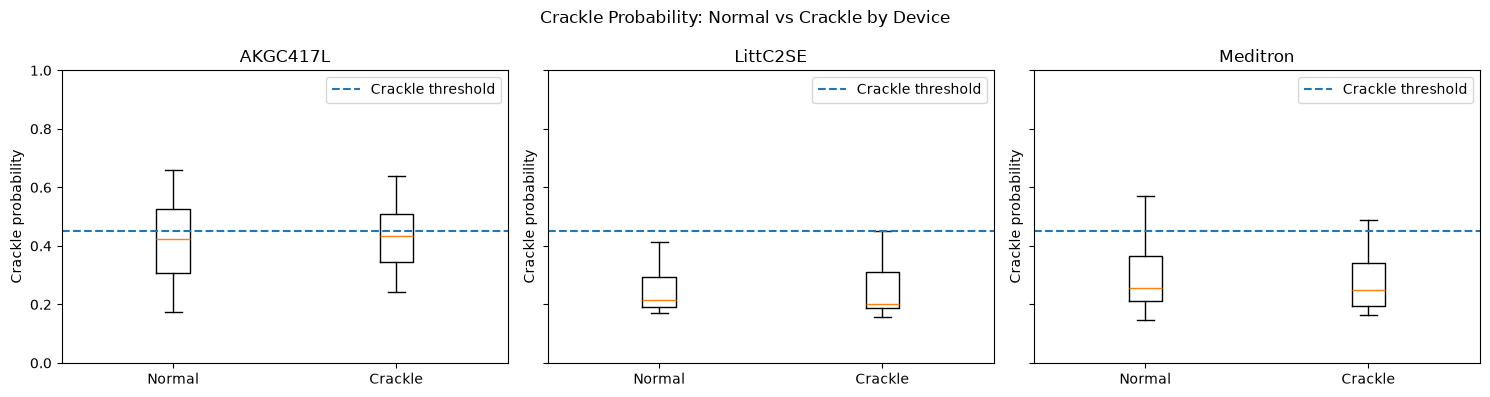

In [ ]:
import matplotlib.pyplot as plt

devices = ["AKGC417L", "LittC2SE", "Meditron"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, device in zip(axes, devices):

    device_data = val_device_df[
        val_device_df["device"] == device
    ]

    normal_probs = device_data.loc[
        device_data["actual_class"] == "normal",
        "crackle_probability"
    ]

    crackle_probs = device_data.loc[
        device_data["actual_class"] == "crackle",
        "crackle_probability"
    ]

    ax.boxplot(
        [normal_probs, crackle_probs],
        tick_labels=["Normal", "Crackle"],
        showfliers=False
    )

    ax.axhline(
        y=0.45,
        linestyle="--",
        label="Crackle threshold"
    )

    ax.set_title(device)
    ax.set_ylabel("Crackle probability")
    ax.set_ylim(0, 1)
    ax.legend()

plt.suptitle(
    "Crackle Probability: Normal vs Crackle by Device"
)

plt.tight_layout()
plt.show()

In [ ]:
devices = ["AKGC417L", "LittC2SE", "Meditron"]

for device in devices:

    device_data = val_device_df[
        val_device_df["device"] == device
    ]

    normal = device_data.loc[
        device_data["actual_class"] == "normal",
        "crackle_probability"
    ]

    crackle = device_data.loc[
        device_data["actual_class"] == "crackle",
        "crackle_probability"
    ]

    print(f"\n{'='*45}")
    print(f"DEVICE: {device}")
    print(f"{'='*45}")

    for name, values in [
        ("Normal", normal),
        ("Crackle", crackle)
    ]:
        print(f"\n{name} ({len(values)} cycles)")
        print("Mean:", round(values.mean(), 3))
        print("Median:", round(values.median(), 3))
        print("25th percentile:", round(values.quantile(0.25), 3))
        print("75th percentile:", round(values.quantile(0.75), 3))
        print("Minimum:", round(values.min(), 3))
        print("Maximum:", round(values.max(), 3))

    print(
        "\nDifference in mean probability (Crackle - Normal):",
        round(crackle.mean() - normal.mean(), 3)
    )


DEVICE: AKGC417L

Normal (161 cycles)
Mean: 0.423
Median: 0.422
25th percentile: 0.308
75th percentile: 0.525
Minimum: 0.175
Maximum: 0.658

Crackle (96 cycles)
Mean: 0.427
Median: 0.433
25th percentile: 0.343
75th percentile: 0.51
Minimum: 0.241
Maximum: 0.638

Difference in mean probability (Crackle - Normal): 0.004

DEVICE: LittC2SE

Normal (21 cycles)
Mean: 0.257
Median: 0.214
25th percentile: 0.19
75th percentile: 0.294
Minimum: 0.171
Maximum: 0.528

Crackle (23 cycles)
Mean: 0.265
Median: 0.203
25th percentile: 0.188
75th percentile: 0.309
Minimum: 0.158
Maximum: 0.559

Difference in mean probability (Crackle - Normal): 0.008

DEVICE: Meditron

Normal (177 cycles)
Mean: 0.288
Median: 0.257
25th percentile: 0.213
75th percentile: 0.367
Minimum: 0.148
Maximum: 0.57

Crackle (55 cycles)
Mean: 0.279
Median: 0.249
25th percentile: 0.196
75th percentile: 0.343
Minimum: 0.164
Maximum: 0.49

Difference in mean probability (Crackle - Normal): -0.009


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score
)

crackle_event_results = []

for device, group in val_device_df.groupby("device"):

    # Crackle is present in either of these two classes
    y_true = group["actual_class"].isin(
        ["crackle", "crackle+wheeze"]
    ).astype(int)

    probabilities = group["crackle_probability"]

    y_pred = (probabilities >= 0.45).astype(int)

    positive_probs = probabilities[y_true == 1]
    negative_probs = probabilities[y_true == 0]

    crackle_event_results.append({
        "device": device,
        "positive_cycles": int(y_true.sum()),
        "negative_cycles": int((y_true == 0).sum()),
        "mean_positive_probability": positive_probs.mean(),
        "mean_negative_probability": negative_probs.mean(),
        "positive_detection_rate": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Average_Precision": average_precision_score(
            y_true, probabilities
        )
    })

crackle_event_results_df = pd.DataFrame(crackle_event_results)

display(crackle_event_results_df.round(3))

,device,positive_cycles,negative_cycles,mean_positive_probability,mean_negative_probability,positive_detection_rate,precision,ROC_AUC,Average_Precision
0,AKGC417L,121,164,0.440,0.424,0.496,0.462,0.538,0.417
1,LittC2SE,26,59,0.279,0.351,0.077,0.333,0.298,0.259
2,Meditron,62,217,0.283,0.300,0.048,0.136,0.457,0.209


In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score
)

wheeze_event_results = []

for device, group in val_device_df.groupby("device"):

    # Wheeze is present in either of these two classes
    y_true = group["actual_class"].isin(
        ["wheeze", "crackle+wheeze"]
    ).astype(int)

    probabilities = group["wheeze_probability"]
    y_pred = (probabilities >= 0.60).astype(int)

    positive_probs = probabilities[y_true == 1]
    negative_probs = probabilities[y_true == 0]

    wheeze_event_results.append({
        "device": device,
        "positive_cycles": int(y_true.sum()),
        "negative_cycles": int((y_true == 0).sum()),
        "mean_positive_probability": positive_probs.mean(),
        "mean_negative_probability": negative_probs.mean(),
        "positive_detection_rate": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "Average_Precision": average_precision_score(
            y_true, probabilities
        )
    })

wheeze_event_results_df = pd.DataFrame(wheeze_event_results)

display(wheeze_event_results_df.round(3))

,device,positive_cycles,negative_cycles,mean_positive_probability,mean_negative_probability,positive_detection_rate,precision,ROC_AUC,Average_Precision
0,AKGC417L,28,257,0.771,0.296,0.857,0.545,0.954,0.718
1,LittC2SE,41,44,0.828,0.159,0.805,0.943,0.967,0.973
2,Meditron,47,232,0.665,0.291,0.638,0.536,0.749,0.661


In [ ]:
crackle_distribution = (
    val_device_df
    .groupby(["device", "actual_class"])["crackle_probability"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        min="min",
        max="max"
    )
    .reset_index()
)

# Percentage of cycles whose crackle probability crosses
# the current validation threshold of 0.45
detection_rates = (
    val_device_df
    .assign(
        above_threshold=lambda x: x["crackle_probability"] >= 0.45
    )
    .groupby(["device", "actual_class"])["above_threshold"]
    .mean()
    .mul(100)
    .reset_index(name="above_0.45_percent")
)

crackle_distribution = crackle_distribution.merge(
    detection_rates,
    on=["device", "actual_class"]
)

display(crackle_distribution.round(3))

,device,actual_class,count,mean,median,q1,q3,min,max,above_0.45_percent
0,AKGC417L,crackle,96,0.427,0.433,0.343,0.510,0.241,0.638,40.625
1,AKGC417L,crackle+wheeze,25,0.489,0.482,0.470,0.500,0.421,0.616,84.000
2,AKGC417L,normal,161,0.423,0.422,0.308,0.525,0.175,0.658,42.236
3,AKGC417L,wheeze,3,0.496,0.460,0.454,0.520,0.449,0.580,66.667
4,LittC2SE,crackle,23,0.265,0.203,0.188,0.309,0.158,0.559,8.696
5,LittC2SE,crackle+wheeze,3,0.389,0.392,0.383,0.395,0.375,0.399,0.000
6,LittC2SE,normal,21,0.257,0.214,0.190,0.294,0.171,0.528,9.524
7,LittC2SE,wheeze,38,0.403,0.416,0.404,0.427,0.218,0.608,5.263
8,Meditron,crackle,55,0.279,0.249,0.196,0.343,0.164,0.490,3.636
9,Meditron,crackle+wheeze,7,0.315,0.275,0.268,0.366,0.179,0.486,14.286


In [ ]:
class_sample_coverage = (
    val_device_df
    .groupby(["device", "actual_class"])
    .agg(
        cycles=("actual_class", "size"),
        patients=("patient", "nunique"),
        recordings=("recording", "nunique")
    )
    .reset_index()
    .sort_values(["device", "actual_class"])
)

display(class_sample_coverage)

,device,actual_class,cycles,patients,recordings
0,AKGC417L,crackle,96,3,29
1,AKGC417L,crackle+wheeze,25,1,5
2,AKGC417L,normal,161,2,33
3,AKGC417L,wheeze,3,2,3
4,LittC2SE,crackle,23,5,6
5,LittC2SE,crackle+wheeze,3,1,2
6,LittC2SE,normal,21,5,9
7,LittC2SE,wheeze,38,1,6
8,Meditron,crackle,55,6,12
9,Meditron,crackle+wheeze,7,4,4


In [ ]:
patient_crackle_summary = (
    val_device_df
    .assign(
        crackle_above_threshold=lambda x:
            x["crackle_probability"] >= 0.45
    )
    .groupby(["device", "patient", "actual_class"])
    .agg(
        cycles=("actual_class", "size"),
        recordings=("recording", "nunique"),
        mean_crackle_probability=("crackle_probability", "mean"),
        median_crackle_probability=("crackle_probability", "median"),
        detection_rate=("crackle_above_threshold", "mean")
    )
    .reset_index()
)

patient_crackle_summary["detection_rate"] *= 100

display(
    patient_crackle_summary
    .query("actual_class in ['crackle', 'crackle+wheeze', 'normal']")
    .sort_values(["device", "patient", "actual_class"])
    .round(3)
)

,device,patient,actual_class,cycles,recordings,mean_crackle_probability,median_crackle_probability,detection_rate
0,AKGC417L,180,crackle,4,4,0.346,0.353,0.000
1,AKGC417L,180,crackle+wheeze,25,5,0.489,0.482,84.000
3,AKGC417L,186,crackle,74,18,0.436,0.439,44.595
4,AKGC417L,186,normal,50,13,0.404,0.396,32.000
6,AKGC417L,213,crackle,18,7,0.404,0.344,33.333
7,AKGC417L,213,normal,111,20,0.431,0.440,46.847
8,LittC2SE,128,crackle,3,1,0.320,0.244,33.333
9,LittC2SE,128,normal,2,1,0.349,0.349,50.000
10,LittC2SE,189,crackle,2,1,0.350,0.350,0.000
11,LittC2SE,189,normal,3,1,0.337,0.336,0.000


In [ ]:
patient_event_comparison = []

for (device, patient), group in val_device_df.groupby(
    ["device", "patient"]
):
    # Crackle-positive includes pure and combined events
    y_true = group["actual_class"].isin(
        ["crackle", "crackle+wheeze"]
    )

    positive = group.loc[y_true, "crackle_probability"]
    negative = group.loc[~y_true, "crackle_probability"]

    # Compare only patients who have both positive and negative cycles
    if len(positive) == 0 or len(negative) == 0:
        continue

    patient_event_comparison.append({
        "device": device,
        "patient": patient,
        "positive_cycles": len(positive),
        "negative_cycles": len(negative),
        "mean_positive_probability": positive.mean(),
        "mean_negative_probability": negative.mean(),
        "probability_difference": (
            positive.mean() - negative.mean()
        ),
        "positive_detection_rate": (
            positive >= 0.45
        ).mean() * 100,
        "negative_false_positive_rate": (
            negative >= 0.45
        ).mean() * 100
    })

patient_event_comparison_df = pd.DataFrame(
    patient_event_comparison
)

display(
    patient_event_comparison_df
    .sort_values(["device", "patient"])
    .round(3)
)

,device,patient,positive_cycles,negative_cycles,mean_positive_probability,mean_negative_probability,probability_difference,positive_detection_rate,negative_false_positive_rate
0,AKGC417L,180,29,1,0.470,0.449,0.021,72.414,0.000
1,AKGC417L,186,74,52,0.436,0.409,0.028,44.595,34.615
2,AKGC417L,213,18,111,0.404,0.431,-0.026,33.333,46.847
3,LittC2SE,128,3,2,0.320,0.349,-0.029,33.333,50.000
4,LittC2SE,189,2,3,0.350,0.337,0.013,0.000,0.000
5,LittC2SE,192,4,42,0.404,0.393,0.010,0.000,7.143
6,LittC2SE,199,12,6,0.239,0.208,0.031,8.333,0.000
7,LittC2SE,226,5,6,0.222,0.201,0.021,0.000,0.000
8,Meditron,110,15,37,0.349,0.348,0.001,13.333,24.324
9,Meditron,161,4,15,0.243,0.203,0.040,0.000,0.000


In [ ]:
recording_comparisons = []

for (device, patient, recording), group in val_device_df.groupby(
    ["device", "patient", "recording"]
):

    y_true = group["actual_class"].isin(
        ["crackle", "crackle+wheeze"]
    )

    positive = group.loc[y_true, "crackle_probability"]
    negative = group.loc[~y_true, "crackle_probability"]

    # Keep recordings containing both positive and negative cycles
    if len(positive) == 0 or len(negative) == 0:
        continue

    recording_comparisons.append({
        "device": device,
        "patient": patient,
        "recording": recording,
        "positive_cycles": len(positive),
        "negative_cycles": len(negative),
        "probability_difference": (
            positive.mean() - negative.mean()
        ),
        "positive_detection_rate": (
            positive >= 0.45
        ).mean() * 100,
        "negative_false_positive_rate": (
            negative >= 0.45
        ).mean() * 100
    })

recording_comparisons_df = pd.DataFrame(recording_comparisons)

recording_summary = (
    recording_comparisons_df
    .groupby("device")
    .agg(
        recordings_with_both_classes=("recording", "nunique"),
        patients=("patient", "nunique"),
        positive_cycles=("positive_cycles", "sum"),
        negative_cycles=("negative_cycles", "sum"),
        mean_probability_difference=("probability_difference", "mean"),
        median_probability_difference=("probability_difference", "median"),
        recordings_with_positive_difference=(
            "probability_difference",
            lambda x: (x > 0).mean() * 100
        ),
        mean_detection_rate=("positive_detection_rate", "mean"),
        mean_false_positive_rate=("negative_false_positive_rate", "mean")
    )
    .reset_index()
)

display(recording_summary.round(3))

,device,recordings_with_both_classes,patients,positive_cycles,negative_cycles,mean_probability_difference,median_probability_difference,recordings_with_positive_difference,mean_detection_rate,mean_false_positive_rate
0,AKGC417L,15,3,41,48,-0.010,0.031,53.333,44.778,39.000
1,LittC2SE,8,5,26,36,0.008,0.009,62.500,5.729,6.250
2,Meditron,12,7,55,98,0.025,0.037,58.333,1.910,3.108


In [ ]:
display(
    recording_comparisons_df[
        [
            "device",
            "patient",
            "recording",
            "positive_cycles",
            "negative_cycles",
            "probability_difference",
            "positive_detection_rate",
            "negative_false_positive_rate"
        ]
    ]
    .sort_values(
        ["device", "probability_difference"],
        ascending=[True, True]
    )
    .round(3)
    .reset_index(drop=True)
)

,device,patient,recording,positive_cycles,negative_cycles,probability_difference,positive_detection_rate,negative_false_positive_rate
0,AKGC417L,213,213_2p2_Pl_mc_AKGC417L,5,2,-0.216,0.000,100.000
1,AKGC417L,213,213_2p2_Ar_mc_AKGC417L,1,6,-0.168,0.000,50.000
2,AKGC417L,213,213_2p2_Pr_mc_AKGC417L,2,5,-0.123,50.000,80.000
3,AKGC417L,186,186_3b3_Lr_mc_AKGC417L,1,5,-0.112,0.000,40.000
4,AKGC417L,186,186_3b3_Ar_mc_AKGC417L,3,3,-0.103,0.000,0.000
5,AKGC417L,213,213_1p2_Pl_mc_AKGC417L,3,3,-0.070,66.667,100.000
6,AKGC417L,186,186_2b4_Pl_mc_AKGC417L,4,1,-0.011,25.000,0.000
7,AKGC417L,186,186_2b4_Al_mc_AKGC417L,4,1,0.031,50.000,0.000
8,AKGC417L,213,213_1p5_Pl_mc_AKGC417L,1,5,0.034,100.000,100.000
9,AKGC417L,213,213_1p2_Pr_mc_AKGC417L,4,2,0.038,50.000,0.000


In [ ]:
recording_count_check = (
    recording_comparisons_df
    .groupby("device")
    .agg(
        recordings=("recording", "nunique"),
        patients=("patient", "nunique"),
        positive_cycles=("positive_cycles", "sum"),
        negative_cycles=("negative_cycles", "sum")
    )
    .reset_index()
)

display(recording_count_check)

,device,recordings,patients,positive_cycles,negative_cycles
0,AKGC417L,15,3,41,48
1,LittC2SE,8,5,26,36
2,Meditron,12,7,55,98


In [ ]:
# Rebuild crackle-positive and negative counts directly from validation data
audit = val_device_df.copy()

audit["crackle_positive"] = audit["actual_class"].isin(
    ["crackle", "crackle+wheeze"]
)

recording_audit = (
    audit.groupby(["device", "patient", "recording"])
    .agg(
        total_cycles=("actual_class", "size"),
        positive_cycles=("crackle_positive", "sum")
    )
    .reset_index()
)

recording_audit["negative_cycles"] = (
    recording_audit["total_cycles"]
    - recording_audit["positive_cycles"]
)

# Retain only recordings containing both types of cycles
recording_audit = recording_audit[
    (recording_audit["positive_cycles"] > 0) &
    (recording_audit["negative_cycles"] > 0)
].copy()

# Recalculate totals
direct_summary = (
    recording_audit.groupby("device")
    .agg(
        recordings=("recording", "nunique"),
        patients=("patient", "nunique"),
        positive_cycles=("positive_cycles", "sum"),
        negative_cycles=("negative_cycles", "sum")
    )
    .reset_index()
)

print("Directly calculated from val_device_df:")
display(direct_summary)

print("Existing intermediate dataframe column names:")
print(recording_comparisons_df.columns.tolist())

print("Existing intermediate dataframe totals:")
display(
    recording_comparisons_df
    .groupby("device")[["positive_cycles", "negative_cycles"]]
    .sum()
    .reset_index()
)

Directly calculated from val_device_df:


,device,recordings,patients,positive_cycles,negative_cycles
0,AKGC417L,15,3,41,48
1,LittC2SE,8,5,26,36
2,Meditron,12,7,55,98


Existing intermediate dataframe column names:
['device', 'patient', 'recording', 'positive_cycles', 'negative_cycles', 'probability_difference', 'positive_detection_rate', 'negative_false_positive_rate']
Existing intermediate dataframe totals:


,device,positive_cycles,negative_cycles
0,AKGC417L,41,48
1,LittC2SE,26,36
2,Meditron,55,98


In [ ]:
from sklearn.metrics import roc_auc_score

recording_auc_results = []

for (device, patient, recording), group in val_device_df.groupby(
    ["device", "patient", "recording"]
):
    y_true = group["actual_class"].isin(
        ["crackle", "crackle+wheeze"]
    ).astype(int)

    probabilities = group["crackle_probability"]

    positive_count = int(y_true.sum())
    negative_count = int((y_true == 0).sum())

    # Exclude recordings with too few examples in either group
    if positive_count < 2 or negative_count < 2:
        continue

    recording_auc_results.append({
        "device": device,
        "patient": patient,
        "recording": recording,
        "positive_cycles": positive_count,
        "negative_cycles": negative_count,
        "ROC_AUC": roc_auc_score(y_true, probabilities)
    })

recording_auc_df = pd.DataFrame(recording_auc_results)

display(
    recording_auc_df
    .sort_values(["device", "ROC_AUC"])
    .round(3)
)

print("\nDevice-level summary:")

display(
    recording_auc_df
    .groupby("device")
    .agg(
        recordings=("recording", "nunique"),
        patients=("patient", "nunique"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        median_ROC_AUC=("ROC_AUC", "median"),
        recordings_above_0_5=(
            "ROC_AUC",
            lambda x: (x > 0.5).sum()
        )
    )
    .round(3)
)

,device,patient,recording,positive_cycles,negative_cycles,ROC_AUC
0,AKGC417L,186,186_3b3_Ar_mc_AKGC417L,3,3,0.000
4,AKGC417L,213,213_2p2_Pl_mc_AKGC417L,5,2,0.000
5,AKGC417L,213,213_2p2_Pr_mc_AKGC417L,2,5,0.200
1,AKGC417L,213,213_1p2_Pl_mc_AKGC417L,3,3,0.444
2,AKGC417L,213,213_1p2_Pr_mc_AKGC417L,4,2,0.500
3,AKGC417L,213,213_1p5_Pr_mc_AKGC417L,2,4,1.000
8,LittC2SE,192,192_2b2_Al_mc_LittC2SE,2,6,0.167
9,LittC2SE,199,199_2b1_Ll_mc_LittC2SE,4,5,0.350
6,LittC2SE,128,128_1b3_Tc_mc_LittC2SE,3,2,0.500
10,LittC2SE,226,226_1b1_Pl_sc_LittC2SE,5,6,0.633



Device-level summary:


,recordings,patients,mean_ROC_AUC,median_ROC_AUC,recordings_above_0_5
device,,,,,
AKGC417L,6,2,0.357,0.322,1
LittC2SE,5,5,0.463,0.500,2
Meditron,9,5,0.566,0.577,5


In [ ]:
recording_auc_df = recording_auc_df.copy()

recording_auc_df["pair_count"] = (
    recording_auc_df["positive_cycles"]
    * recording_auc_df["negative_cycles"]
)

recording_auc_weighted = (
    recording_auc_df
    .assign(
        weighted_auc=lambda x:
            x["ROC_AUC"] * x["pair_count"]
    )
    .groupby("device")
    .agg(
        recordings=("recording", "nunique"),
        patients=("patient", "nunique"),
        total_pairs=("pair_count", "sum"),
        weighted_auc_sum=("weighted_auc", "sum")
    )
    .reset_index()
)

recording_auc_weighted["pair_weighted_ROC_AUC"] = (
    recording_auc_weighted["weighted_auc_sum"]
    / recording_auc_weighted["total_pairs"]
)

display(
    recording_auc_weighted[
        [
            "device",
            "recordings",
            "patients",
            "total_pairs",
            "pair_weighted_ROC_AUC"
        ]
    ].round(3)
)

,device,recordings,patients,total_pairs,pair_weighted_ROC_AUC
0,AKGC417L,6,2,54,0.333
1,LittC2SE,5,5,74,0.473
2,Meditron,9,5,434,0.516


In [ ]:
patient_pair_summary = (
    recording_auc_df
    .groupby(["device", "patient"])
    .agg(
        recordings=("recording", "nunique"),
        total_pairs=("pair_count", "sum"),
        weighted_auc_sum=(
            "ROC_AUC",
            lambda x: (
                x * recording_auc_df.loc[x.index, "pair_count"]
            ).sum()
        )
    )
    .reset_index()
)

patient_pair_summary["patient_weighted_auc"] = (
    patient_pair_summary["weighted_auc_sum"]
    / patient_pair_summary["total_pairs"]
)

patient_pair_summary["device_total_pairs"] = (
    patient_pair_summary
    .groupby("device")["total_pairs"]
    .transform("sum")
)

patient_pair_summary["pair_share_percent"] = (
    patient_pair_summary["total_pairs"]
    / patient_pair_summary["device_total_pairs"] * 100
)

display(
    patient_pair_summary[
        [
            "device",
            "patient",
            "recordings",
            "total_pairs",
            "pair_share_percent",
            "patient_weighted_auc"
        ]
    ]
    .sort_values(["device", "pair_share_percent"], ascending=[True, False])
    .round(3)
    .reset_index(drop=True)
)

,device,patient,recordings,total_pairs,pair_share_percent,patient_weighted_auc
0,AKGC417L,213,5,45,83.333,0.400
1,AKGC417L,186,1,9,16.667,0.000
2,LittC2SE,226,1,30,40.541,0.633
3,LittC2SE,199,1,20,27.027,0.350
4,LittC2SE,192,1,12,16.216,0.167
5,LittC2SE,128,1,6,8.108,0.500
6,LittC2SE,189,1,6,8.108,0.667
7,Meditron,166,3,323,74.424,0.495
8,Meditron,226,2,40,9.217,0.400
9,Meditron,110,1,26,5.991,0.577


In [ ]:
loo_results = []

for device, group in patient_pair_summary.groupby("device"):

    total_pairs = group["total_pairs"].sum()

    total_weighted_auc = (
        group["patient_weighted_auc"] *
        group["total_pairs"]
    ).sum()

    full_auc = total_weighted_auc / total_pairs

    for _, row in group.iterrows():

        remaining_pairs = total_pairs - row["total_pairs"]

        if remaining_pairs == 0:
            continue

        loo_auc = (
            total_weighted_auc
            - row["patient_weighted_auc"] * row["total_pairs"]
        ) / remaining_pairs

        loo_results.append({
            "device": device,
            "patient_removed": row["patient"],
            "full_weighted_AUC": full_auc,
            "AUC_after_removal": loo_auc,
            "change_in_AUC": loo_auc - full_auc
        })

loo_results_df = pd.DataFrame(loo_results)

display(
    loo_results_df
    .sort_values(["device", "patient_removed"])
    .round(3)
    .reset_index(drop=True)
)

,device,patient_removed,full_weighted_AUC,AUC_after_removal,change_in_AUC
0,AKGC417L,186,0.333,0.400,0.067
1,AKGC417L,213,0.333,0.000,-0.333
2,LittC2SE,128,0.473,0.471,-0.002
3,LittC2SE,189,0.473,0.456,-0.017
4,LittC2SE,192,0.473,0.532,0.059
5,LittC2SE,199,0.473,0.519,0.046
6,LittC2SE,226,0.473,0.364,-0.109
7,Meditron,110,0.516,0.512,-0.004
8,Meditron,161,0.516,0.502,-0.014
9,Meditron,166,0.516,0.577,0.060


In [ ]:
import inspect

print("EXTRACT LOG-MEL FUNCTION")
print(inspect.signature(extract_logmel))
print(inspect.getsource(extract_logmel))

print("\nFEATURE BUILDING FUNCTION")
print(inspect.signature(build_features_framepad))
print(inspect.getsource(build_features_framepad))

EXTRACT LOG-MEL FUNCTION
(segment)
def extract_logmel(segment):

    mel_power = librosa.feature.melspectrogram(
        y=segment,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel_power,
        ref=np.max
    )

    log_mel = np.clip(log_mel, -80.0, 0.0)

    log_mel = (log_mel + 80.0) / 80.0

    return log_mel.astype(np.float32)


FEATURE BUILDING FUNCTION
(frame, split_name, noise_snr_db=None, random_seed=42, target_frames=157)
def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_s

In [ ]:
import inspect

print("CURRENT FEATURE SETTINGS")
print("TARGET_SR:", TARGET_SR)
print("TARGET_SAMPLES:", TARGET_SAMPLES)
print("N_FFT:", N_FFT)
print("HOP_LENGTH:", HOP_LENGTH)
print("N_MELS:", N_MELS)
print("FMIN:", FMIN)
print("FMAX:", FMAX)

print("\nFIT AUDIO LENGTH")
print(inspect.getsource(fit_audio_length))

print("\nFIT LOG-MEL FRAMES")
print(inspect.getsource(fit_logmel_frames))

CURRENT FEATURE SETTINGS
TARGET_SR: 4000
TARGET_SAMPLES: 20000
N_FFT: 512
HOP_LENGTH: 128
N_MELS: 64
FMIN: 20
FMAX: 2000

FIT AUDIO LENGTH
def fit_audio_length(y, target_samples):
    """
    Make an audio segment exactly target_samples long.
    Short segments are zero-padded.
    Long segments are center-cropped.
    """

    if len(y) > target_samples:
        start = (len(y) - target_samples) // 2
        y = y[start:start + target_samples]

    elif len(y) < target_samples:
        total_padding = target_samples - len(y)

        left_padding = total_padding // 2
        right_padding = total_padding - left_padding

        y = np.pad(
            y,
            (left_padding, right_padding),
            mode="constant"
        )

    return y.astype(np.float32)


FIT LOG-MEL FRAMES
def fit_logmel_frames(log_mel, target_frames=157):

    # Find the current number of time frames
    source_frames = log_mel.shape[1]

    # If the spectrogram is too long, crop its time dimension
    

In [ ]:
# Combine the existing development metadata
dev_meta = pd.concat(
    [
        meta_train_framepad.assign(original_split="train"),
        meta_val_framepad.assign(original_split="val")
    ],
    ignore_index=True
).copy()

# Extract recording device from the filename
dev_meta["device"] = (
    dev_meta["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

dev_meta["patient"] = dev_meta["patient"].astype(str)

# Check device-wise coverage
device_summary = (
    dev_meta.groupby("device")
    .agg(
        patients=("patient", "nunique"),
        recordings=("recording", "nunique"),
        cycles=("recording", "size")
    )
    .reset_index()
)

print("Development dataset:")
print("Total cycles:", len(dev_meta))
print("Total patients:", dev_meta["patient"].nunique())

print("\nDevice distribution:")
display(device_summary)

# Check whether any patient appears with multiple devices
patient_device_summary = (
    dev_meta.groupby(["patient", "device"])
    .agg(
        cycles=("recording", "size"),
        recordings=("recording", "nunique")
    )
    .reset_index()
)

multi_device_patients = (
    patient_device_summary
    .groupby("patient")["device"]
    .nunique()
)

multi_device_ids = multi_device_patients[
    multi_device_patients > 1
].index

print("\nPatients associated with multiple devices:")
display(
    patient_device_summary[
        patient_device_summary["patient"].isin(multi_device_ids)
    ].sort_values(["patient", "device"])
)

# Verify that no official test patient enters development data
dev_patients = set(dev_meta["patient"])
test_patients = set(meta_test["patient"].astype(str))

print("\nPatient overlap with official test:", 
      len(dev_patients.intersection(test_patients)))


Development dataset:
Total cycles: 4025
Total patients: 77

Device distribution:


,device,patients,recordings,cycles
0,AKGC417L,16,352,2441
1,Litt3200,1,3,28
2,LittC2SE,23,87,594
3,Meditron,40,84,962



Patients associated with multiple devices:


,patient,device,cycles,recordings
7,112,Litt3200,28,3
8,112,Meditron,29,2
36,158,AKGC417L,206,23
37,158,LittC2SE,11,1
78,226,LittC2SE,11,1
79,226,Meditron,20,2



Patient overlap with official test: 0


In [ ]:
import pandas as pd

# Combine existing training and validation metadata.
# We are NOT including the official test set in this experiment.
dev_meta = pd.concat(
    [
        meta_train_framepad.assign(original_split="train"),
        meta_val_framepad.assign(original_split="val")
    ],
    ignore_index=True
).copy()

# Standardise patient IDs
dev_meta["patient"] = dev_meta["patient"].astype(str)

# Extract the recording device
dev_meta["device"] = (
    dev_meta["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

print("DEVELOPMENT DATASET")
print("Total cycles:", len(dev_meta))
print("Unique patients:", dev_meta["patient"].nunique())
print("Unique recordings:", dev_meta["recording"].nunique())

print("\nDEVICE DISTRIBUTION")
display(
    dev_meta.groupby(["device", "original_split"])
    .agg(
        patients=("patient", "nunique"),
        recordings=("recording", "nunique"),
        cycles=("recording", "size")
    )
    .reset_index()
)

# Check patients associated with multiple recording devices
patient_device_check = (
    dev_meta.groupby("patient")["device"]
    .agg(lambda x: sorted(x.unique()))
    .reset_index(name="devices")
)

patient_device_check["number_of_devices"] = (
    patient_device_check["devices"].str.len()
)

print("\nPATIENTS ASSOCIATED WITH MULTIPLE DEVICES")
display(
    patient_device_check[
        patient_device_check["number_of_devices"] > 1
    ]
)

# Confirm development patients do not overlap with official test patients
test_patients = set(meta_test["patient"].astype(str))
dev_patients = set(dev_meta["patient"])

print("\nOverlap with official test patients:",
      len(dev_patients.intersection(test_patients)))

DEVELOPMENT DATASET
Total cycles: 4025
Unique patients: 77
Unique recordings: 526

DEVICE DISTRIBUTION


,device,original_split,patients,recordings,cycles
0,AKGC417L,train,13,303,2156
1,AKGC417L,val,3,49,285
2,Litt3200,train,1,3,28
3,LittC2SE,train,18,76,509
4,LittC2SE,val,5,11,85
5,Meditron,train,31,62,683
6,Meditron,val,9,22,279



PATIENTS ASSOCIATED WITH MULTIPLE DEVICES


,patient,devices,number_of_devices
7,112,"[Litt3200, Meditron]",2
35,158,"[AKGC417L, LittC2SE]",2
76,226,"[LittC2SE, Meditron]",2



Overlap with official test patients: 0


In [ ]:
# Use training data only for the initial device analysis
spectral_audit = meta_train_framepad.copy()

# Extract the device from the recording filename
spectral_audit["device"] = (
    spectral_audit["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

# Calculate original annotated cycle duration
spectral_audit["duration_sec"] = (
    spectral_audit["end"] - spectral_audit["start"]
)

# Summarise each device and sound class
device_class_summary = (
    spectral_audit
    .groupby(["device", "label"])
    .agg(
        cycles=("label", "size"),
        patients=("patient", "nunique"),
        recordings=("recording", "nunique"),
        median_duration=("duration_sec", "median")
    )
    .reset_index()
)

# Calculate percentage of each class within each device
device_totals = (
    spectral_audit.groupby("device")
    .size()
    .rename("device_total")
    .reset_index()
)

device_class_summary = device_class_summary.merge(
    device_totals,
    on="device"
)

device_class_summary["percentage"] = (
    device_class_summary["cycles"]
    / device_class_summary["device_total"] * 100
)

display(
    device_class_summary
    .sort_values(["device", "label"])
    .round(2)
)

,device,label,cycles,patients,recordings,median_duration,device_total,percentage
0,AKGC417L,crackle,886,12,183,2.39,2156,41.09
1,AKGC417L,crackle+wheeze,208,9,79,2.50,2156,9.65
2,AKGC417L,normal,819,13,219,2.61,2156,37.99
3,AKGC417L,wheeze,243,10,69,2.37,2156,11.27
4,Litt3200,crackle,1,1,1,2.95,28,3.57
5,Litt3200,crackle+wheeze,4,1,1,3.15,28,14.29
6,Litt3200,normal,7,1,3,3.21,28,25.00
7,Litt3200,wheeze,16,1,3,2.96,28,57.14
8,LittC2SE,crackle,54,10,12,2.28,509,10.61
9,LittC2SE,crackle+wheeze,41,2,12,4.51,509,8.06


In [ ]:
print("FEATURE ARRAY")
print("X_train_3ch:", X_train_3ch.shape)

print("\nPOSSIBLE MASK ARRAYS")

for name, value in list(globals().items()):
    if "mask" in name.lower() and isinstance(value, np.ndarray):
        print(name, value.shape, value.dtype)

print("\nMETADATA")
print("Rows:", len(meta_train_framepad))
print("Patients:", meta_train_framepad["patient"].nunique())
print("Recordings:", meta_train_framepad["recording"].nunique())

FEATURE ARRAY
X_train_3ch: (3376, 64, 157, 3)

POSSIBLE MASK ARRAYS
patient_226_mask (496,) bool
train_mfcc_mask (3376, 157) bool
val_mfcc_mask (649, 157) bool
current_mask (649, 157) bool
test_frame_mask (2756, 157) bool

METADATA
Rows: 3376
Patients: 61
Recordings: 444


In [ ]:
import numpy as np

# Confirm array alignment
assert X_train_3ch.shape[:3] == (3376, 64, 157)
assert train_mfcc_mask.shape == (3376, 157)
assert len(meta_train_framepad) == len(X_train_3ch)

# Reconstruct the expected mask from the original audio durations
expected_mask = np.zeros((len(meta_train_framepad), 157), dtype=bool)

for i, row in meta_train_framepad.reset_index(drop=True).iterrows():

    start_sample = int(np.floor(row["start"] * TARGET_SR))
    end_sample = int(np.ceil(row["end"] * TARGET_SR))

    segment_samples = end_sample - start_sample
    segment_samples = min(segment_samples, TARGET_SAMPLES)

    source_frames = min(
        157,
        segment_samples // HOP_LENGTH + 1
    )

    left_padding = (157 - source_frames) // 2

    expected_mask[
        i,
        left_padding:left_padding + source_frames
    ] = True

# Compare reconstructed and existing masks
mask_matches = np.array_equal(
    expected_mask,
    train_mfcc_mask
)

print("MASK VERIFICATION")
print("Existing mask shape:", train_mfcc_mask.shape)
print("Expected mask shape:", expected_mask.shape)
print("Masks match exactly:", mask_matches)

print("\nAverage valid frames:")
print("Existing mask:", round(train_mfcc_mask.sum(axis=1).mean(), 2))
print("Expected mask:", round(expected_mask.sum(axis=1).mean(), 2))

print("\nMask mismatches:", np.count_nonzero(
    train_mfcc_mask != expected_mask
))

# Check whether padded feature frames are zero
invalid_positions = ~train_mfcc_mask

padded_features = X_train_3ch.transpose(0, 2, 1, 3)[invalid_positions]

if len(padded_features) > 0:
    print("\nMaximum absolute padded feature value:",
          np.abs(padded_features).max())
else:
    print("\nNo padded frames found.")

MASK VERIFICATION
Existing mask shape: (3376, 157)
Expected mask shape: (3376, 157)
Masks match exactly: True

Average valid frames:
Existing mask: 83.14
Expected mask: 83.14

Mask mismatches: 0

Maximum absolute padded feature value: 0.0


In [ ]:
import numpy as np
import pandas as pd
import librosa
from itertools import combinations

# Use Log-Mel channel 0
logmel_features = X_train_3ch[:, :, :, 0]

meta = meta_train_framepad.reset_index(drop=True).copy()

meta["device"] = (
    meta["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

meta["patient"] = meta["patient"].astype(str)

assert logmel_features.shape == (3376, 64, 157)
assert train_mfcc_mask.shape == (3376, 157)
assert len(meta) == len(logmel_features)

# Store one profile per patient and class
patient_profiles = {}

for (device, label, patient), indices in meta.groupby(
    ["device", "label", "patient"]
).indices.items():

    cycle_profiles = []

    for i in indices:

        valid_frames = train_mfcc_mask[i]

        if valid_frames.any():

            # Correct indexing: preserve frequency as axis 0
            valid_spectrogram = logmel_features[i][:, valid_frames]

            # Average over time, retaining 64 frequency values
            cycle_profile = valid_spectrogram.mean(axis=1)

            assert cycle_profile.shape == (64,)

            cycle_profiles.append(cycle_profile)

    if cycle_profiles:
        patient_profiles.setdefault(
            (device, label), []
        ).append(np.mean(np.stack(cycle_profiles), axis=0))


# Average patients equally within each device and class
device_class_profiles = {}

for key, profiles in patient_profiles.items():

    device_class_profiles[key] = np.mean(
        np.stack(profiles),
        axis=0
    )


# Mel-bin centre frequencies
mel_frequencies = librosa.mel_frequencies(
    n_mels=N_MELS,
    fmin=FMIN,
    fmax=FMAX
)

frequency_bands = {
    "low_20_200Hz": (20, 200),
    "mid_200_1000Hz": (200, 1000),
    "high_1000_2000Hz": (1000, 2000)
}


# Device and class spectral summary
profile_summary = []

for (device, label), profile in device_class_profiles.items():

    subset = meta[
        (meta["device"] == device) &
        (meta["label"] == label)
    ]

    row = {
        "device": device,
        "class": label,
        "cycles": len(subset),
        "patients": subset["patient"].nunique(),
        "recordings": subset["recording"].nunique(),
        "overall_mean": profile.mean()
    }

    for band_name, (lower, upper) in frequency_bands.items():

        band_mask = (
            (mel_frequencies >= lower) &
            (mel_frequencies < upper)
        )

        row[band_name] = profile[band_mask].mean()

    profile_summary.append(row)

profile_summary_df = pd.DataFrame(profile_summary)

print("PATIENT-BALANCED SPECTRAL PROFILES")

display(
    profile_summary_df
    .sort_values(["class", "device"])
    .round(3)
)


# Compare devices within the same sound class
pair_results = []

for label in meta["label"].unique():

    available_devices = sorted({
        device
        for device, current_label in device_class_profiles
        if current_label == label
    })

    for device_a, device_b in combinations(available_devices, 2):

        profile_a = device_class_profiles[(device_a, label)]
        profile_b = device_class_profiles[(device_b, label)]

        pair_results.append({
            "class": label,
            "device_A": device_a,
            "device_B": device_b,
            "profile_correlation": np.corrcoef(
                profile_a, profile_b
            )[0, 1],
            "mean_absolute_difference": np.mean(
                np.abs(profile_a - profile_b)
            )
        })

profile_comparison_df = pd.DataFrame(pair_results)

print("\nSAME-CLASS COMPARISON ACROSS DEVICES")

display(
    profile_comparison_df
    .sort_values(["class", "device_A", "device_B"])
    .round(3)
)

PATIENT-BALANCED SPECTRAL PROFILES


,device,class,cycles,patients,recordings,overall_mean,low_20_200Hz,mid_200_1000Hz,high_1000_2000Hz
0,AKGC417L,crackle,886,12,183,0.386,0.710,0.413,0.267
4,Litt3200,crackle,1,1,1,0.163,0.567,0.200,0.011
8,LittC2SE,crackle,54,10,12,0.328,0.702,0.354,0.196
12,Meditron,crackle,71,11,17,0.334,0.655,0.357,0.220
1,AKGC417L,crackle+wheeze,208,9,79,0.361,0.717,0.390,0.232
5,Litt3200,crackle+wheeze,4,1,1,0.208,0.632,0.271,0.019
9,LittC2SE,crackle+wheeze,41,2,12,0.290,0.699,0.341,0.119
13,Meditron,crackle+wheeze,12,2,5,0.341,0.671,0.377,0.209
2,AKGC417L,normal,819,13,219,0.419,0.734,0.452,0.294
6,Litt3200,normal,7,1,3,0.155,0.549,0.183,0.015



SAME-CLASS COMPARISON ACROSS DEVICES


,class,device_A,device_B,profile_correlation,mean_absolute_difference
12,crackle,AKGC417L,Litt3200,0.945,0.223
13,crackle,AKGC417L,LittC2SE,0.997,0.059
14,crackle,AKGC417L,Meditron,0.990,0.053
15,crackle,Litt3200,LittC2SE,0.950,0.165
16,crackle,Litt3200,Meditron,0.939,0.171
17,crackle,LittC2SE,Meditron,0.989,0.028
18,crackle+wheeze,AKGC417L,Litt3200,0.947,0.153
19,crackle+wheeze,AKGC417L,LittC2SE,0.984,0.075
20,crackle+wheeze,AKGC417L,Meditron,0.978,0.032
21,crackle+wheeze,Litt3200,LittC2SE,0.945,0.094


In [ ]:
from itertools import combinations
import numpy as np
import pandas as pd

main_devices = ["AKGC417L", "LittC2SE", "Meditron"]

# Start with classes having reasonable representation
classes_to_compare = ["crackle", "normal", "wheeze"]

comparison_results = []
frequency_difference_results = []

for label in classes_to_compare:

    for device_a, device_b in combinations(main_devices, 2):

        profile_a = device_class_profiles[(device_a, label)]
        profile_b = device_class_profiles[(device_b, label)]

        # Original profiles
        raw_difference = profile_a - profile_b

        # Remove each profile's overall mean
        centered_a = profile_a - profile_a.mean()
        centered_b = profile_b - profile_b.mean()

        centered_difference = centered_a - centered_b

        # Standardise each profile to compare frequency shape
        z_a = centered_a / (profile_a.std() + 1e-8)
        z_b = centered_b / (profile_b.std() + 1e-8)

        # Patient coverage
        patients_a = len(patient_profiles[(device_a, label)])
        patients_b = len(patient_profiles[(device_b, label)])

        comparison_results.append({
            "class": label,
            "device_A": device_a,
            "device_B": device_b,
            "patients_A": patients_a,
            "patients_B": patients_b,
            "mean_signed_difference": raw_difference.mean(),
            "raw_MAD": np.abs(raw_difference).mean(),
            "centered_MAD": np.abs(centered_difference).mean(),
            "standardized_shape_MAD": np.abs(z_a - z_b).mean(),
            "correlation": np.corrcoef(
                profile_a, profile_b
            )[0, 1]
        })

        # Identify the Mel bins with the largest raw differences
        top_bins = np.argsort(
            np.abs(raw_difference)
        )[-5:][::-1]

        for bin_index in top_bins:
            frequency_difference_results.append({
                "class": label,
                "device_A": device_a,
                "device_B": device_b,
                "mel_bin": int(bin_index),
                "approx_frequency_Hz": mel_frequencies[bin_index],
                "profile_A": profile_a[bin_index],
                "profile_B": profile_b[bin_index],
                "absolute_difference": abs(
                    raw_difference[bin_index]
                )
            })


comparison_results_df = pd.DataFrame(comparison_results)
frequency_differences_df = pd.DataFrame(
    frequency_difference_results
)

print("RAW VS CENTRED SPECTRAL DIFFERENCES")

display(
    comparison_results_df.round(3)
)

print("\nFIVE MEL BINS WITH LARGEST DIFFERENCES")

display(
    frequency_differences_df
    .sort_values(
        ["class", "device_A", "device_B", "absolute_difference"],
        ascending=[True, True, True, False]
    )
    .round(3)
    .reset_index(drop=True)
)

RAW VS CENTRED SPECTRAL DIFFERENCES


,class,device_A,device_B,patients_A,patients_B,mean_signed_difference,raw_MAD,centered_MAD,standardized_shape_MAD,correlation
0,crackle,AKGC417L,LittC2SE,12,10,0.058,0.059,0.017,0.049,0.997
1,crackle,AKGC417L,Meditron,12,11,0.052,0.053,0.017,0.110,0.990
2,crackle,LittC2SE,Meditron,10,11,-0.006,0.028,0.027,0.128,0.989
3,normal,AKGC417L,LittC2SE,13,17,0.099,0.099,0.014,0.072,0.995
4,normal,AKGC417L,Meditron,13,31,0.068,0.068,0.018,0.108,0.992
5,normal,LittC2SE,Meditron,17,31,-0.031,0.037,0.025,0.104,0.992
6,wheeze,AKGC417L,LittC2SE,10,8,0.077,0.078,0.016,0.086,0.994
7,wheeze,AKGC417L,Meditron,10,10,0.063,0.064,0.019,0.123,0.988
8,wheeze,LittC2SE,Meditron,8,10,-0.014,0.020,0.017,0.092,0.994



FIVE MEL BINS WITH LARGEST DIFFERENCES


,class,device_A,device_B,mel_bin,approx_frequency_Hz,profile_A,profile_B,absolute_difference
0,crackle,AKGC417L,LittC2SE,49,1369.609,0.291,0.201,0.090
1,crackle,AKGC417L,LittC2SE,52,1485.362,0.276,0.194,0.083
2,crackle,AKGC417L,LittC2SE,51,1445.730,0.277,0.195,0.082
3,crackle,AKGC417L,LittC2SE,50,1407.155,0.278,0.196,0.082
4,crackle,AKGC417L,LittC2SE,48,1333.065,0.285,0.205,0.080
5,crackle,AKGC417L,Meditron,4,124.897,0.670,0.582,0.088
6,crackle,AKGC417L,Meditron,5,151.121,0.632,0.546,0.086
7,crackle,AKGC417L,Meditron,7,203.569,0.576,0.495,0.081
8,crackle,AKGC417L,Meditron,19,518.260,0.417,0.337,0.080
9,crackle,AKGC417L,Meditron,61,1894.696,0.235,0.157,0.078


In [ ]:
from itertools import combinations

paired_profiles = {}

for (patient, device, label), indices in meta.groupby(
    ["patient", "device", "label"]
).indices.items():

    profiles = []

    for i in indices:
        valid_frames = train_mfcc_mask[i]

        if valid_frames.any():
            profile = logmel_features[i][:, valid_frames].mean(axis=1)
            profiles.append(profile)

    if profiles:
        paired_profiles[(patient, device, label)] = {
            "profile": np.mean(np.stack(profiles), axis=0),
            "cycles": len(indices),
            "recordings": meta.iloc[indices]["recording"].nunique()
        }


paired_results = []

patients_with_multiple_devices = sorted(
    patient_device_check.loc[
        patient_device_check["number_of_devices"] > 1,
        "patient"
    ].astype(str)
)

for patient in patients_with_multiple_devices:

    patient_classes = sorted({
        label
        for p, device, label in paired_profiles
        if p == patient
    })

    for label in patient_classes:

        available_devices = sorted([
            device
            for p, device, current_label in paired_profiles
            if p == patient and current_label == label
        ])

        if len(available_devices) < 2:
            continue

        for device_a, device_b in combinations(available_devices, 2):

            data_a = paired_profiles[(patient, device_a, label)]
            data_b = paired_profiles[(patient, device_b, label)]

            profile_a = data_a["profile"]
            profile_b = data_b["profile"]

            centered_a = profile_a - profile_a.mean()
            centered_b = profile_b - profile_b.mean()

            paired_results.append({
                "patient": patient,
                "class": label,
                "device_A": device_a,
                "device_B": device_b,
                "cycles_A": data_a["cycles"],
                "cycles_B": data_b["cycles"],
                "recordings_A": data_a["recordings"],
                "recordings_B": data_b["recordings"],
                "raw_MAD": np.abs(profile_a - profile_b).mean(),
                "centered_MAD": np.abs(
                    centered_a - centered_b
                ).mean(),
                "correlation": np.corrcoef(
                    profile_a, profile_b
                )[0, 1]
            })

paired_comparison_df = pd.DataFrame(paired_results)

print("WITHIN-PATIENT, SAME-CLASS COMPARISON")

if len(paired_comparison_df):
    display(paired_comparison_df.round(3))
else:
    print(
        "No patient has the same sound class represented "
        "on multiple devices in the current training data."
    )

WITHIN-PATIENT, SAME-CLASS COMPARISON


,patient,class,device_A,device_B,cycles_A,cycles_B,recordings_A,recordings_B,raw_MAD,centered_MAD,correlation
0,112,crackle,Litt3200,Meditron,1,4,1,2,0.131,0.061,0.906
1,112,crackle+wheeze,Litt3200,Meditron,4,2,1,1,0.122,0.080,0.913
2,112,normal,Litt3200,Meditron,7,17,3,2,0.131,0.054,0.919
3,112,wheeze,Litt3200,Meditron,16,6,3,1,0.110,0.072,0.904
4,158,crackle,AKGC417L,LittC2SE,40,6,12,1,0.058,0.019,0.989
5,158,normal,AKGC417L,LittC2SE,43,5,17,1,0.047,0.023,0.985


In [ ]:
# Compare frequency-band differences within the same patient
band_comparison_results = []

frequency_bands = {
    "Low (20-200 Hz)": (20, 200),
    "Mid (200-1000 Hz)": (200, 1000),
    "High (1000-2000 Hz)": (1000, 2000)
}

for (patient, device_a, label), data_a in paired_profiles.items():

    for device_b in sorted({
        device
        for p, device, current_label in paired_profiles
        if p == patient and current_label == label
    }):

        if device_a >= device_b:
            continue

        data_b = paired_profiles[(patient, device_b, label)]

        profile_a = data_a["profile"]
        profile_b = data_b["profile"]

        for band_name, (lower, upper) in frequency_bands.items():

            band_mask = (
                (mel_frequencies >= lower) &
                (mel_frequencies < upper)
            )

            a = profile_a[band_mask]
            b = profile_b[band_mask]

            band_comparison_results.append({
                "patient": patient,
                "class": label,
                "device_A": device_a,
                "device_B": device_b,
                "frequency_band": band_name,
                "cycles_A": data_a["cycles"],
                "cycles_B": data_b["cycles"],
                "mean_difference": np.mean(a - b),
                "raw_MAD": np.mean(np.abs(a - b)),
                "centered_MAD": np.mean(
                    np.abs((a - a.mean()) - (b - b.mean()))
                )
            })

band_comparison_df = pd.DataFrame(
    band_comparison_results
)

display(
    band_comparison_df
    .sort_values(
        ["patient", "class", "frequency_band"]
    )
    .round(3)
    .reset_index(drop=True)
)


,patient,class,device_A,device_B,frequency_band,cycles_A,cycles_B,mean_difference,raw_MAD,centered_MAD
0,112,crackle,Litt3200,Meditron,High (1000-2000 Hz),1,4,-0.149,0.149,0.026
1,112,crackle,Litt3200,Meditron,Low (20-200 Hz),1,4,-0.051,0.051,0.016
2,112,crackle,Litt3200,Meditron,Mid (200-1000 Hz),1,4,-0.115,0.134,0.083
3,112,crackle+wheeze,Litt3200,Meditron,High (1000-2000 Hz),4,2,-0.166,0.166,0.024
4,112,crackle+wheeze,Litt3200,Meditron,Low (20-200 Hz),4,2,-0.006,0.015,0.011
5,112,crackle+wheeze,Litt3200,Meditron,Mid (200-1000 Hz),4,2,-0.076,0.110,0.086
6,112,normal,Litt3200,Meditron,High (1000-2000 Hz),7,17,-0.143,0.143,0.027
7,112,normal,Litt3200,Meditron,Low (20-200 Hz),7,17,-0.081,0.081,0.021
8,112,normal,Litt3200,Meditron,Mid (200-1000 Hz),7,17,-0.124,0.132,0.078
9,112,wheeze,Litt3200,Meditron,High (1000-2000 Hz),16,6,-0.135,0.135,0.030


In [ ]:
# Use three adequately represented devices and classes
main_devices = ["AKGC417L", "LittC2SE", "Meditron"]
main_classes = ["crackle", "normal", "wheeze"]

# Construct one class-balanced spectral profile per device
device_reference_profiles = {}

for device in main_devices:

    class_profiles = []

    for label in main_classes:
        key = (device, label)

        if key not in device_class_profiles:
            continue

        class_profiles.append(
            device_class_profiles[key]
        )

    assert len(class_profiles) == len(main_classes), (
        f"Missing class profile for {device}"
    )

    # Give each sound class equal importance
    device_reference_profiles[device] = np.mean(
        np.stack(class_profiles),
        axis=0
    )


# Common reference profile across devices
reference_profile = np.mean(
    np.stack(list(device_reference_profiles.values())),
    axis=0
)


# Estimate the correction needed for each device
correction_profiles = {}
correction_summary = []

for device in main_devices:

    profile = device_reference_profiles[device]

    # Add this correction to the device's Log-Mel values
    correction = reference_profile - profile

    correction_profiles[device] = correction

    correction_summary.append({
        "device": device,
        "device_mean": profile.mean(),
        "reference_mean": reference_profile.mean(),
        "mean_correction": correction.mean(),
        "mean_absolute_correction": np.abs(correction).mean(),
        "maximum_absolute_correction": np.abs(correction).max(),
        "correlation_with_reference": np.corrcoef(
            profile, reference_profile
        )[0, 1]
    })


correction_summary_df = pd.DataFrame(correction_summary)

print("DEVICE SPECTRAL ALIGNMENT SUMMARY")
display(correction_summary_df.round(4))


# Inspect correction by frequency band
band_corrections = []

for device, correction in correction_profiles.items():

    for band_name, (lower, upper) in frequency_bands.items():

        band_mask = (
            (mel_frequencies >= lower) &
            (mel_frequencies < upper)
        )

        band_corrections.append({
            "device": device,
            "frequency_band": band_name,
            "mean_correction": correction[band_mask].mean(),
            "mean_absolute_correction": np.abs(
                correction[band_mask]
            ).mean()
        })

print("\nCORRECTION BY FREQUENCY BAND")

display(
    pd.DataFrame(band_corrections).round(4)
)

DEVICE SPECTRAL ALIGNMENT SUMMARY


,device,device_mean,reference_mean,mean_correction,mean_absolute_correction,maximum_absolute_correction,correlation_with_reference
0,AKGC417L,0.3936,0.3471,-0.0465,0.0466,0.0633,0.9979
1,LittC2SE,0.3153,0.3471,0.0318,0.0323,0.0532,0.9986
2,Meditron,0.3325,0.3471,0.0146,0.0154,0.0447,0.9967



CORRECTION BY FREQUENCY BAND


,device,frequency_band,mean_correction,mean_absolute_correction
0,AKGC417L,Low (20-200 Hz),-0.0294,0.0309
1,AKGC417L,Mid (200-1000 Hz),-0.0503,0.0503
2,AKGC417L,High (1000-2000 Hz),-0.0465,0.0465
3,LittC2SE,Low (20-200 Hz),0.0016,0.0063
4,LittC2SE,Mid (200-1000 Hz),0.0316,0.0316
5,LittC2SE,High (1000-2000 Hz),0.0402,0.0402
6,Meditron,Low (20-200 Hz),0.0278,0.0278
7,Meditron,Mid (200-1000 Hz),0.0187,0.0190
8,Meditron,High (1000-2000 Hz),0.0063,0.0078


In [ ]:
def check_alignment_clipping(X, metadata, mask, split_name):

    metadata = metadata.reset_index(drop=True).copy()

    assert len(X) == len(metadata) == len(mask)

    metadata["device"] = (
        metadata["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
    )

    results = []

    for device, indices in metadata.groupby("device").indices.items():

        if device not in correction_profiles:
            print(f"{split_name}: {device} — no correction estimated")
            continue

        below_zero = 0
        above_one = 0
        total_values = 0

        minimum = np.inf
        maximum = -np.inf

        correction = correction_profiles[device]

        for i in indices:

            valid = mask[i]

            # Original Log-Mel values for valid frames
            original = X[i, :, :, 0][:, valid]

            # Preview the correction without modifying the data
            adjusted = original + correction[:, np.newaxis]

            below_zero += np.count_nonzero(adjusted < 0)
            above_one += np.count_nonzero(adjusted > 1)

            total_values += adjusted.size

            minimum = min(minimum, adjusted.min())
            maximum = max(maximum, adjusted.max())

        results.append({
            "split": split_name,
            "device": device,
            "valid_values": total_values,
            "below_zero": below_zero,
            "above_one": above_one,
            "below_zero_percent": below_zero / total_values * 100,
            "above_one_percent": above_one / total_values * 100,
            "adjusted_min": minimum,
            "adjusted_max": maximum
        })

    return pd.DataFrame(results)


train_clipping_check = check_alignment_clipping(
    X_train_3ch,
    meta_train_framepad,
    train_mfcc_mask,
    "Training"
)

val_clipping_check = check_alignment_clipping(
    X_val_3ch,
    meta_val_framepad,
    val_mfcc_mask,
    "Validation"
)

alignment_clipping_df = pd.concat(
    [train_clipping_check, val_clipping_check],
    ignore_index=True
)

display(alignment_clipping_df.round(4))

Training: Litt3200 — no correction estimated


,split,device,valid_values,below_zero,above_one,below_zero_percent,above_one_percent,adjusted_min,adjusted_max
0,Training,AKGC417L,11215744,234708,3162,2.0927,0.0282,-0.0633,1.0054
1,Training,LittC2SE,2997888,0,68,0.0000,0.0023,0.0213,1.0080
2,Training,Meditron,3579456,24790,886,0.6926,0.0248,-0.0036,1.0403
3,Validation,AKGC417L,1747328,28498,384,1.6309,0.0220,-0.0564,1.0054
4,Validation,LittC2SE,436864,0,2,0.0000,0.0005,0.0213,1.0041
5,Validation,Meditron,1500992,24954,541,1.6625,0.0360,-0.0036,1.0447


In [ ]:
def audit_corrected_features(X, metadata, mask, split_name):

    metadata = metadata.reset_index(drop=True).copy()

    metadata["device"] = (
        metadata["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
    )

    results = []

    for device, indices in metadata.groupby("device").indices.items():

        if device not in correction_profiles:
            continue

        correction = np.asarray(
            correction_profiles[device]
        )

        nan_count = 0
        posinf_count = 0
        neginf_count = 0
        total_count = 0

        original_nonfinite = 0
        finite_values = []

        for i in indices:

            valid = mask[i]

            original = X[i, :, :, 0][:, valid]

            adjusted = original + correction[:, None]

            total_count += adjusted.size

            original_nonfinite += (
                ~np.isfinite(original)
            ).sum()

            nan_count += np.isnan(adjusted).sum()
            posinf_count += np.isposinf(adjusted).sum()
            neginf_count += np.isneginf(adjusted).sum()

            finite_values.extend(
                adjusted[np.isfinite(adjusted)].ravel()
            )

        finite_values = np.asarray(finite_values)

        results.append({
            "split": split_name,
            "device": device,
            "original_nonfinite": int(original_nonfinite),
            "adjusted_nan": int(nan_count),
            "adjusted_positive_inf": int(posinf_count),
            "adjusted_negative_inf": int(neginf_count),
            "finite_min": finite_values.min() if len(finite_values) else np.nan,
            "finite_max": finite_values.max() if len(finite_values) else np.nan,
            "finite_values": len(finite_values)
        })

    return pd.DataFrame(results)


train_finite_audit = audit_corrected_features(
    X_train_3ch,
    meta_train_framepad,
    train_mfcc_mask,
    "Training"
)

val_finite_audit = audit_corrected_features(
    X_val_3ch,
    meta_val_framepad,
    val_mfcc_mask,
    "Validation"
)

finite_audit_df = pd.concat(
    [train_finite_audit, val_finite_audit],
    ignore_index=True
)

display(finite_audit_df.round(4))

print("\nCORRECTION PROFILE FINITENESS")

for device, correction in correction_profiles.items():
    print(
        device,
        "All finite:", np.isfinite(correction).all(),
        "Non-finite bins:", np.where(~np.isfinite(correction))[0]
    )

,split,device,original_nonfinite,adjusted_nan,adjusted_positive_inf,adjusted_negative_inf,finite_min,finite_max,finite_values
0,Training,AKGC417L,0,0,0,0,-0.0633,1.0054,11215744
1,Training,LittC2SE,0,0,0,0,0.0213,1.0080,2997888
2,Training,Meditron,0,0,0,0,-0.0036,1.0403,3579456
3,Validation,AKGC417L,0,0,0,0,-0.0564,1.0054,1747328
4,Validation,LittC2SE,0,0,0,0,0.0213,1.0041,436864
5,Validation,Meditron,0,0,0,0,-0.0036,1.0447,1500992



CORRECTION PROFILE FINITENESS
AKGC417L All finite: True Non-finite bins: []
LittC2SE All finite: True Non-finite bins: []
Meditron All finite: True Non-finite bins: []


In [ ]:
import inspect

print("DERIVATIVE-RELATED FUNCTIONS")
for name, obj in list(globals().items()):
    if callable(obj) and any(
        term in name.lower()
        for term in ["delta", "derivative", "3ch", "channel"]
    ):
        try:
            print(f"\n--- {name}{inspect.signature(obj)} ---")
            print(inspect.getsource(obj))
        except (TypeError, OSError, ValueError):
            print(f"Source unavailable for {name}")

print("\nSAVED NORMALISATION STATISTICS")

for name in ["delta_means", "delta_stds"]:
    if name in globals():
        value = globals()[name]
        print(name, {
            key: np.asarray(item).shape
            for key, item in value.items()
        })
    else:
        print(name, "not found")

DERIVATIVE-RELATED FUNCTIONS

--- build_three_channel_features(X_logmel, frame_masks, split_name) ---
def build_three_channel_features(
    X_logmel,
    frame_masks,
    split_name
):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    # Channel 1: original log-Mel
    # Channel 2: first-order delta
    # Channel 3: second-order delta-delta
    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    X_3ch[..., 0] = X_logmel[..., 0]

    for i in range(n_samples):

        # Identify genuine (non-padded) time frames.
        mask = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, mask]

        n_valid_frames = valid_mel.shape[1]

        # Librosa requires an odd delta window of at least 3.
        width = min(
            9,
            n_valid_frames if n_valid_frames % 2 == 1
            else n_valid_frames - 1
        )

        if width < 3:
            raise ValueError(
                f"Too few valid frames in sample {i}: "

In [ ]:
import inspect

print(inspect.getsource(build_three_channel_features))

print("\nDELTA NORMALISATION STATISTICS")

for channel in [1, 2]:
    print(f"\nChannel {channel}")
    print("Mean:", delta_means[channel])
    print("Std:", delta_stds[channel])

NameError: name 'build_three_channel_features' is not defined

In [ ]:
for name in [
    "build_three_channel_features",
    "delta_means",
    "delta_stds",
    "X_train_3ch",
    "X_val_3ch",
    "train_mfcc_mask"
]:
    print(name, "AVAILABLE" if name in globals() else "MISSING")

build_three_channel_features AVAILABLE
delta_means AVAILABLE
delta_stds AVAILABLE
X_train_3ch AVAILABLE
X_val_3ch AVAILABLE
train_mfcc_mask AVAILABLE


In [ ]:
import inspect
import numpy as np

print("THREE-CHANNEL FEATURE FUNCTION")
print(inspect.signature(build_three_channel_features))
print(inspect.getsource(build_three_channel_features))

print("\nDERIVATIVE NORMALISATION")
for channel in [1, 2]:
    print(f"\nChannel {channel}:")
    print("Mean shape:", delta_means[channel].shape)
    print("Mean range:",
          delta_means[channel].min(),
          delta_means[channel].max())
    print("Std shape:", delta_stds[channel].shape)
    print("Std range:",
          delta_stds[channel].min(),
          delta_stds[channel].max())

THREE-CHANNEL FEATURE FUNCTION
(X_logmel, frame_masks, split_name)
def build_three_channel_features(
    X_logmel,
    frame_masks,
    split_name
):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    # Channel 1: original log-Mel
    # Channel 2: first-order delta
    # Channel 3: second-order delta-delta
    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    X_3ch[..., 0] = X_logmel[..., 0]

    for i in range(n_samples):

        # Identify genuine (non-padded) time frames.
        mask = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, mask]

        n_valid_frames = valid_mel.shape[1]

        # Librosa requires an odd delta window of at least 3.
        width = min(
            9,
            n_valid_frames if n_valid_frames % 2 == 1
            else n_valid_frames - 1
        )

        if width < 3:
            raise ValueError(
                f"Too few valid frames in sample {i}: "
                f"{n_valid_frames}

In [ ]:
# Search the Jupyter notebook's execution history
# for the original derivative-statistics calculation.

history = get_ipython().user_ns.get("In", [])

for cell_number, cell in enumerate(history):

    if (
        "delta_means" in cell
        and "delta_stds" in cell
        and ("mean" in cell or "std" in cell)
    ):
        print(f"\n{'='*60}")
        print(f"NOTEBOOK CELL {cell_number}")
        print('='*60)
        print(cell)


NOTEBOOK CELL 1
import inspect

print(inspect.getsource(build_three_channel_features))

print("\nDELTA NORMALISATION STATISTICS")

for channel in [1, 2]:
    print(f"\nChannel {channel}")
    print("Mean:", delta_means[channel])
    print("Std:", delta_stds[channel])

NOTEBOOK CELL 161
# Store normalization statistics for the two derivative channels.
delta_means = {}
delta_stds = {}

for channel in [1, 2]:

    # Calculate one mean and standard deviation per frequency bin.
    channel_means = np.array([
        X_train_3ch[:, f, :, channel][train_mfcc_mask].mean()
        for f in range(X_train_3ch.shape[1])
    ])

    channel_stds = np.array([
        X_train_3ch[:, f, :, channel][train_mfcc_mask].std()
        for f in range(X_train_3ch.shape[1])
    ])

    # Prevent division by zero.
    channel_stds = np.maximum(channel_stds, 1e-6)

    delta_means[channel] = channel_means
    delta_stds[channel] = channel_stds

    # Normalize training features in place.
    X_train_3ch[..., ch

In [ ]:
# Create independent copies of the original Log-Mel features.
# Channel 0 is still unnormalised in the original arrays.

X_train_logmel_aligned = X_train_3ch[..., 0:1].copy()
X_val_logmel_aligned = X_val_3ch[..., 0:1].copy()


def apply_device_alignment(
    X,
    metadata,
    frame_masks,
    split_name
):
    metadata = metadata.reset_index(drop=True)

    assert len(X) == len(metadata) == len(frame_masks)

    devices = (
        metadata["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
        .to_numpy()
    )

    results = []

    for device in np.unique(devices):

        indices = np.where(devices == device)[0]

        if device not in correction_profiles:
            print(
                f"{split_name}: {device} — "
                "no correction applied"
            )
            continue

        correction = correction_profiles[device]

        clipped_count = 0
        total_count = 0

        for i in indices:

            valid = frame_masks[i]

            # Apply the frequency-wise correction.
            logmel = X[i, :, :, 0]

            logmel += correction[:, None]

            # Count values outside the valid range before clipping.
            valid_values = logmel[:, valid]

            clipped_count += np.count_nonzero(
                (valid_values < 0) | (valid_values > 1)
            )

            total_count += valid_values.size

            # Retain the original feature range.
            np.clip(logmel, 0.0, 1.0, out=logmel)

            # Preserve zero-padding.
            logmel[:, ~valid] = 0.0

        results.append({
            "split": split_name,
            "device": device,
            "cycles": len(indices),
            "corrected_values": total_count,
            "clipped_values": clipped_count,
            "clipped_percent": (
                clipped_count / total_count * 100
            )
        })

    return pd.DataFrame(results)


# Apply training-derived corrections to training and validation.
train_alignment_results = apply_device_alignment(
    X_train_logmel_aligned,
    meta_train_framepad,
    train_mfcc_mask,
    "Training"
)

val_alignment_results = apply_device_alignment(
    X_val_logmel_aligned,
    meta_val_framepad,
    val_mfcc_mask,
    "Validation"
)

alignment_results_df = pd.concat(
    [train_alignment_results, val_alignment_results],
    ignore_index=True
)

print("\nALIGNMENT SUMMARY")
display(alignment_results_df.round(3))


# Verify that the new features are valid.
print("\nFEATURE VERIFICATION")

print(
    "Training shape:",
    X_train_logmel_aligned.shape
)

print(
    "Validation shape:",
    X_val_logmel_aligned.shape
)

print(
    "Training range:",
    X_train_logmel_aligned.min(),
    X_train_logmel_aligned.max()
)

print(
    "Validation range:",
    X_val_logmel_aligned.min(),
    X_val_logmel_aligned.max()
)

print(
    "Training padded frames zero:",
    np.all(
        X_train_logmel_aligned[..., 0]
        .transpose(0, 2, 1)[~train_mfcc_mask] == 0
    )
)

print(
    "Validation padded frames zero:",
    np.all(
        X_val_logmel_aligned[..., 0]
        .transpose(0, 2, 1)[~val_mfcc_mask] == 0
    )
)

print(
    "Training finite:",
    np.isfinite(X_train_logmel_aligned).all()
)

print(
    "Validation finite:",
    np.isfinite(X_val_logmel_aligned).all()
)

NameError: name 'correction_profiles' is not defined

In [ ]:
# Reconstruct the same training-derived correction profiles

main_devices = ["AKGC417L", "LittC2SE", "Meditron"]
main_classes = ["crackle", "normal", "wheeze"]

# Recover the device profiles if necessary
if "device_class_profiles" not in globals():
    device_class_profiles = {
        key: np.mean(np.stack(profiles), axis=0)
        for key, profiles in patient_profiles.items()
    }

# Give each sound class equal importance
device_reference_profiles = {}

for device in main_devices:

    profiles = [
        device_class_profiles[(device, label)]
        for label in main_classes
    ]

    device_reference_profiles[device] = np.mean(
        np.stack(profiles),
        axis=0
    )

# Calculate the common reference
reference_profile = np.mean(
    np.stack(list(device_reference_profiles.values())),
    axis=0
)

# Recreate correction profiles
correction_profiles = {
    device: reference_profile - profile
    for device, profile in device_reference_profiles.items()
}

# Verify the restored corrections
print("RESTORED CORRECTION PROFILES")

for device, correction in correction_profiles.items():
    print(
        device,
        "Shape:", correction.shape,
        "Mean correction:", round(float(correction.mean()), 4),
        "All finite:", np.isfinite(correction).all()
    )

# Apply the corrections using the existing function
train_alignment_results = apply_device_alignment(
    X_train_logmel_aligned,
    meta_train_framepad,
    train_mfcc_mask,
    "Training"
)

val_alignment_results = apply_device_alignment(
    X_val_logmel_aligned,
    meta_val_framepad,
    val_mfcc_mask,
    "Validation"
)

alignment_results_df = pd.concat(
    [train_alignment_results, val_alignment_results],
    ignore_index=True
)

print("\nALIGNMENT SUMMARY")
display(alignment_results_df.round(3))

# Final checks
print("\nFEATURE CHECKS")
print("Training shape:", X_train_logmel_aligned.shape)
print("Validation shape:", X_val_logmel_aligned.shape)
print("Training finite:", np.isfinite(X_train_logmel_aligned).all())
print("Validation finite:", np.isfinite(X_val_logmel_aligned).all())
print(
    "Training range:",
    X_train_logmel_aligned.min(),
    X_train_logmel_aligned.max()
)
print(
    "Validation range:",
    X_val_logmel_aligned.min(),
    X_val_logmel_aligned.max()
)

NameError: name 'patient_profiles' is not defined

In [ ]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Reconstruct patient-balanced spectral profiles
# --------------------------------------------------

meta = meta_train_framepad.reset_index(drop=True).copy()

meta["patient"] = meta["patient"].astype(str)

meta["device"] = (
    meta["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

logmel_features = X_train_3ch[:, :, :, 0]

assert len(meta) == len(logmel_features)
assert train_mfcc_mask.shape == (3376, 157)

patient_profiles = {}

for (device, label, patient), indices in meta.groupby(
    ["device", "label", "patient"]
).indices.items():

    cycle_profiles = []

    for i in indices:
        valid = train_mfcc_mask[i]

        if valid.any():
            profile = logmel_features[i][:, valid].mean(axis=1)
            cycle_profiles.append(profile)

    if cycle_profiles:
        patient_profiles[(device, label, patient)] = (
            np.mean(np.stack(cycle_profiles), axis=0)
        )


# Average patients equally within each device and class
device_class_profiles = {}

for device, label, patient in patient_profiles:

    key = (device, label)

    matching_patients = [
        profile
        for (d, l, p), profile in patient_profiles.items()
        if (d, l) == key
    ]

    device_class_profiles[key] = np.mean(
        np.stack(matching_patients), axis=0
    )


# --------------------------------------------------
# 2. Reconstruct the three-device correction profiles
# --------------------------------------------------

main_devices = ["AKGC417L", "LittC2SE", "Meditron"]
main_classes = ["crackle", "normal", "wheeze"]

device_reference_profiles = {}

for device in main_devices:

    profiles = [
        device_class_profiles[(device, label)]
        for label in main_classes
    ]

    device_reference_profiles[device] = np.mean(
        np.stack(profiles), axis=0
    )

reference_profile = np.mean(
    np.stack(list(device_reference_profiles.values())),
    axis=0
)

correction_profiles = {
    device: reference_profile - profile
    for device, profile in device_reference_profiles.items()
}

print("RESTORED CORRECTIONS")

for device, correction in correction_profiles.items():
    print(
        device,
        "Mean correction:",
        round(float(correction.mean()), 4),
        "All finite:",
        np.isfinite(correction).all()
    )


# --------------------------------------------------
# 3. Recreate aligned features from ORIGINAL arrays
# --------------------------------------------------

X_train_logmel_aligned = X_train_3ch[..., 0:1].copy()
X_val_logmel_aligned = X_val_3ch[..., 0:1].copy()


def apply_device_alignment(X, metadata, masks, split_name):

    metadata = metadata.reset_index(drop=True)

    devices = (
        metadata["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
        .to_numpy()
    )

    results = []

    for device in np.unique(devices):

        indices = np.where(devices == device)[0]

        if device not in correction_profiles:
            print(f"{split_name}: {device} unchanged")
            continue

        correction = correction_profiles[device]

        clipped = 0
        total = 0

        for i in indices:

            valid = masks[i]
            logmel = X[i, :, :, 0]

            logmel[:, valid] += correction[:, None]

            adjusted = logmel[:, valid]

            clipped += np.count_nonzero(
                (adjusted < 0) | (adjusted > 1)
            )

            total += adjusted.size

            np.clip(logmel, 0, 1, out=logmel)

            # Preserve padded frames
            logmel[:, ~valid] = 0

        results.append({
            "split": split_name,
            "device": device,
            "cycles": len(indices),
            "clipped_percent": clipped / total * 100
        })

    return pd.DataFrame(results)


train_results = apply_device_alignment(
    X_train_logmel_aligned,
    meta_train_framepad,
    train_mfcc_mask,
    "Training"
)

val_results = apply_device_alignment(
    X_val_logmel_aligned,
    meta_val_framepad,
    val_mfcc_mask,
    "Validation"
)

print("\nALIGNMENT SUMMARY")

display(
    pd.concat([train_results, val_results], ignore_index=True).round(3)
)


# --------------------------------------------------
# 4. Final checks
# --------------------------------------------------

print("\nFINAL CHECKS")

print("Training shape:", X_train_logmel_aligned.shape)
print("Validation shape:", X_val_logmel_aligned.shape)

print("Training finite:",
      np.isfinite(X_train_logmel_aligned).all())

print("Validation finite:",
      np.isfinite(X_val_logmel_aligned).all())

print("Training range:",
      X_train_logmel_aligned.min(),
      X_train_logmel_aligned.max())

print("Validation range:",
      X_val_logmel_aligned.min(),
      X_val_logmel_aligned.max())

RESTORED CORRECTIONS
AKGC417L Mean correction: -0.0465 All finite: True
LittC2SE Mean correction: 0.0318 All finite: True
Meditron Mean correction: 0.0146 All finite: True
Training: Litt3200 unchanged

ALIGNMENT SUMMARY


,split,device,cycles,clipped_percent
0,Training,AKGC417L,2156,2.121
1,Training,LittC2SE,509,0.002
2,Training,Meditron,683,0.717
3,Validation,AKGC417L,285,1.653
4,Validation,LittC2SE,85,0.000
5,Validation,Meditron,279,1.699



FINAL CHECKS
Training shape: (3376, 64, 157, 1)
Validation shape: (649, 64, 157, 1)
Training finite: True
Validation finite: True
Training range: 0.0 1.0
Validation range: 0.0 1.0


In [ ]:
print("Original features:", X_train_3ch.shape)
print("Aligned Log-Mel:", X_train_logmel_aligned.shape)
print("Frame masks:", train_mfcc_mask.shape)

print("\nMetadata columns:")
print(meta_train_framepad.columns.tolist())

print("\nMetadata sample:")
display(meta_train_framepad.head())

print("\nDevice counts:")
print(
    meta_train_framepad["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
    .value_counts()
)

Original features: (3376, 64, 157, 3)
Aligned Log-Mel: (3376, 64, 157, 1)
Frame masks: (3376, 157)

Metadata columns:
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']

Metadata sample:


,wav_path,recording,patient,start,end,label,label_id,noise_snr_db
0,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,0.364,3.250,wheeze,2,None
1,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,3.250,6.636,normal,0,None
2,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,6.636,11.179,wheeze,2,None
3,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,11.179,14.250,wheeze,2,None
4,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,14.250,16.993,wheeze,2,None



Device counts:
recording
AKGC417L    2156
Meditron     683
LittC2SE     509
Litt3200      28
Name: count, dtype: int64


Original: (3376, 64, 157)
Aligned: (3376, 64, 157)

Number of device-class profiles:
Original: 16
Aligned: 16

DEVICE VARIATION: BEFORE VS AFTER ALIGNMENT


,class,device_A,device_B,raw_MAD,aligned_MAD,MAD_reduction_percent,raw_correlation,aligned_correlation
0,normal,AKGC417L,LittC2SE,0.0994,0.0215,78.393303,0.9948,0.9996
1,normal,AKGC417L,Meditron,0.0680,0.0088,87.137703,0.9915,0.9989
2,normal,LittC2SE,Meditron,0.0372,0.0150,59.549500,0.9916,0.9992
3,crackle,AKGC417L,LittC2SE,0.0589,0.0199,66.269699,0.9974,0.9991
4,crackle,AKGC417L,Meditron,0.0528,0.0088,83.400597,0.9899,0.9988
5,crackle,LittC2SE,Meditron,0.0284,0.0129,54.533199,0.9886,0.9982
6,wheeze,AKGC417L,LittC2SE,0.0778,0.0054,93.011902,0.9937,0.9990
7,wheeze,AKGC417L,Meditron,0.0636,0.0090,85.772903,0.9884,0.9990
8,wheeze,LittC2SE,Meditron,0.0203,0.0104,48.743999,0.9938,0.9993
9,crackle+wheeze,AKGC417L,LittC2SE,0.0751,0.0339,54.887100,0.9837,0.9777


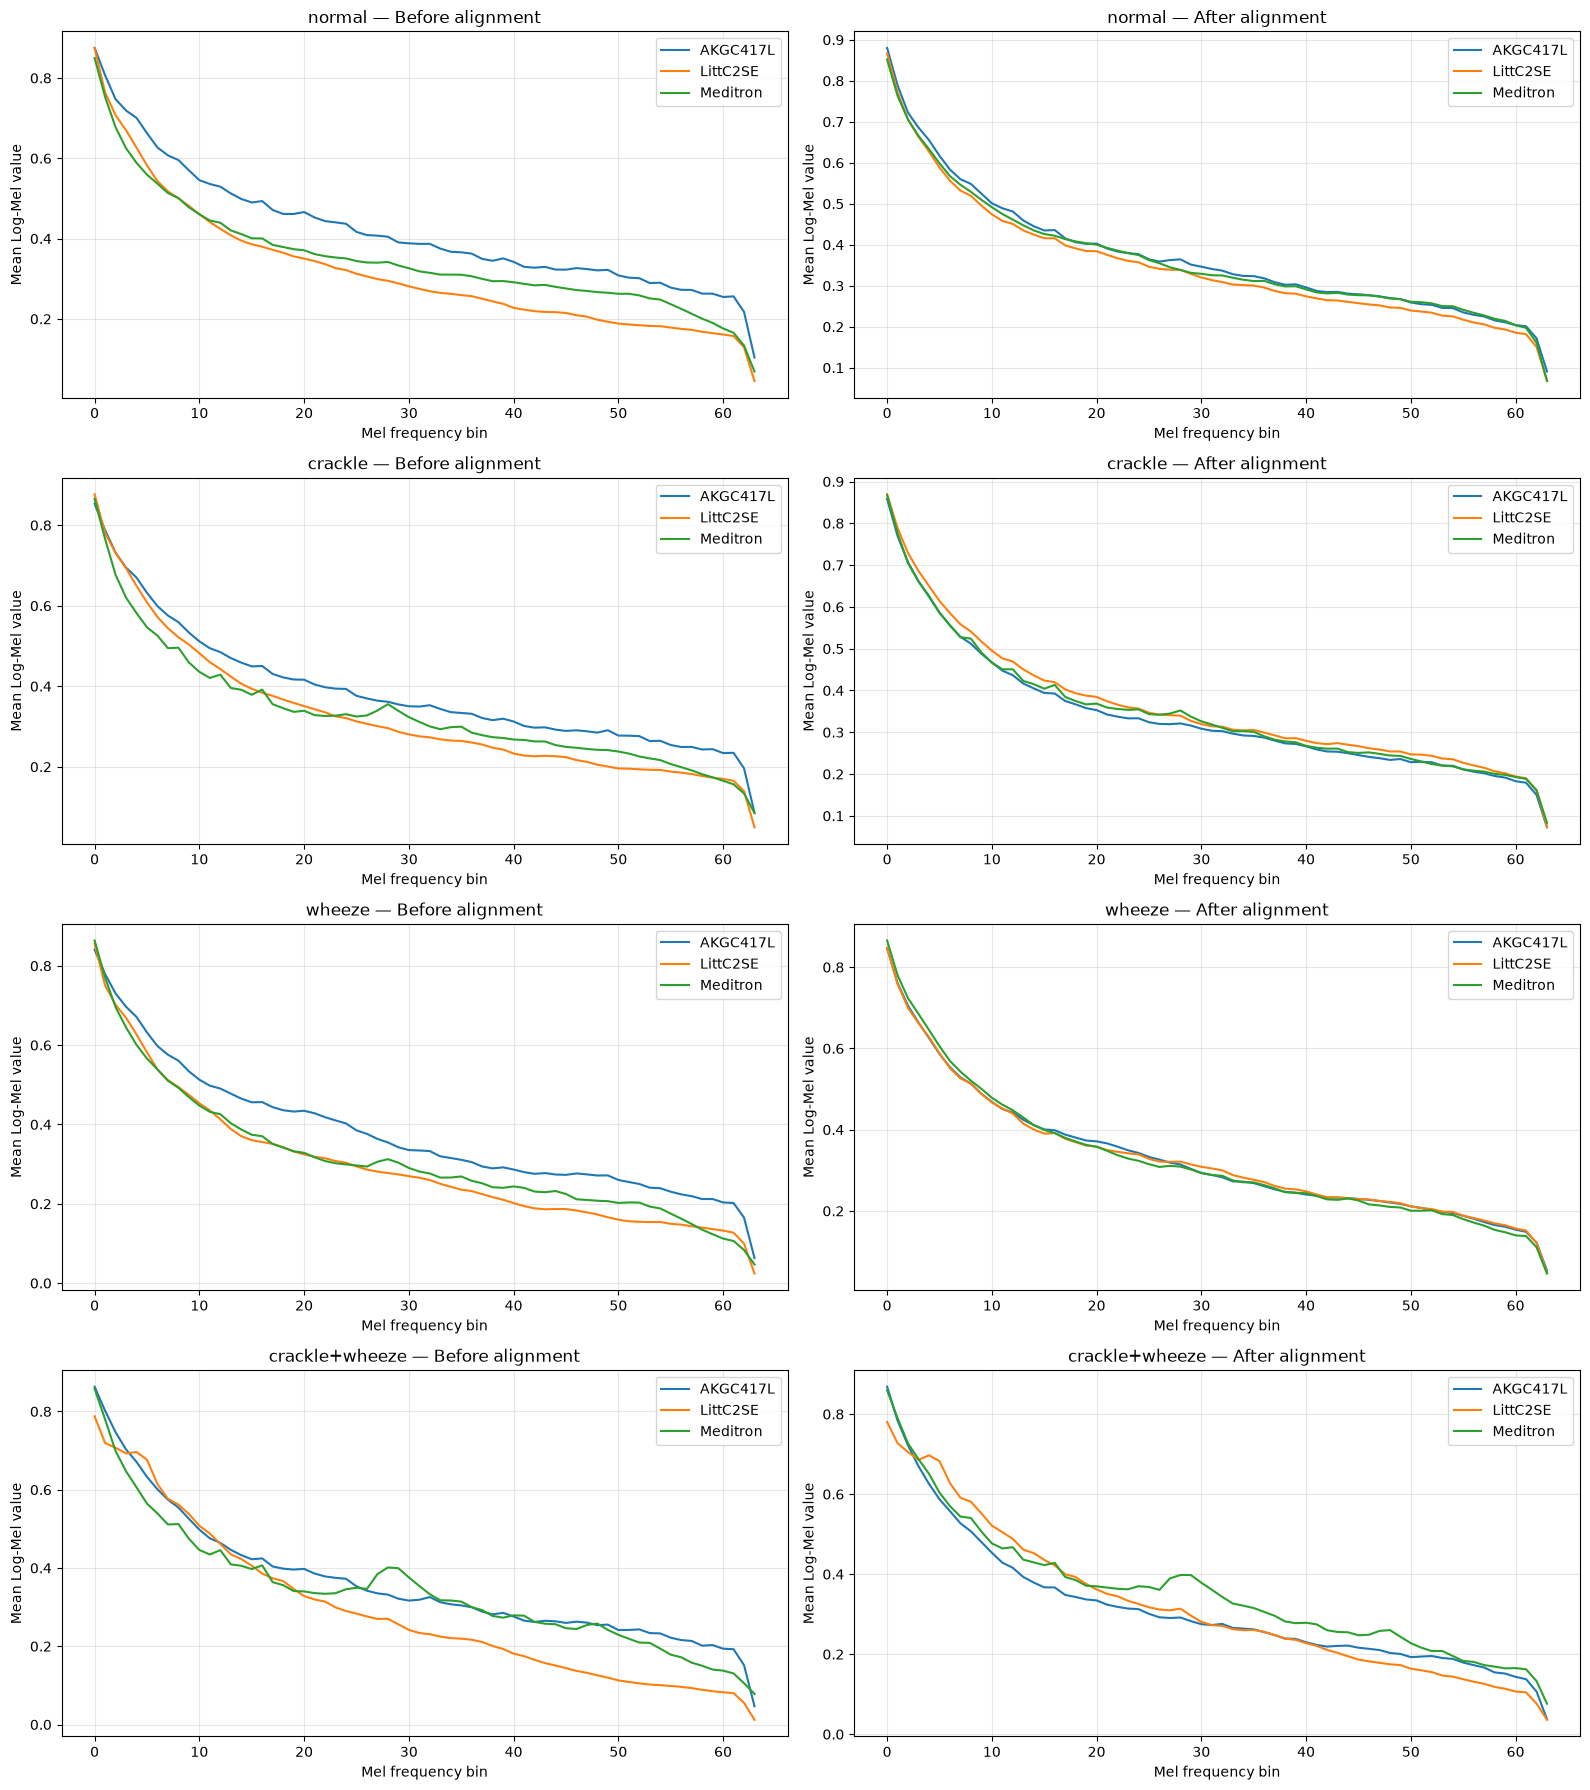

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

# --------------------------------------------------
# 1. Prepare original and aligned Log-Mel features
# --------------------------------------------------

X_original = X_train_3ch[..., 0]
X_aligned = X_train_logmel_aligned[..., 0]

meta = meta_train_framepad.reset_index(drop=True).copy()

meta["device"] = (
    meta["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)

meta["patient"] = meta["patient"].astype(str)

print("Original:", X_original.shape)
print("Aligned:", X_aligned.shape)

# --------------------------------------------------
# 2. Calculate patient-balanced spectral profiles
# --------------------------------------------------

def calculate_device_profiles(X, metadata, masks):

    patient_profiles = {}

    grouped = metadata.groupby(
        ["device", "label", "patient"]
    ).indices

    for (device, label, patient), indices in grouped.items():

        cycle_profiles = []

        for idx in indices:

            valid_mask = masks[idx]

            if not np.any(valid_mask):
                continue

            # Average only genuine, non-padded frames.
            profile = X[idx][:, valid_mask].mean(axis=1)

            cycle_profiles.append(profile)

        if len(cycle_profiles) == 0:
            continue

        # First average cycles belonging to one patient.
        patient_profile = np.mean(
            np.stack(cycle_profiles),
            axis=0
        )

        key = (device, label)

        if key not in patient_profiles:
            patient_profiles[key] = []

        patient_profiles[key].append(patient_profile)

    # Give every patient equal weight.
    device_profiles = {}

    for key, profiles in patient_profiles.items():

        device_profiles[key] = np.mean(
            np.stack(profiles),
            axis=0
        )

    return device_profiles, patient_profiles


raw_profiles, raw_patient_profiles = calculate_device_profiles(
    X_original,
    meta,
    train_mfcc_mask
)

aligned_profiles, aligned_patient_profiles = calculate_device_profiles(
    X_aligned,
    meta,
    train_mfcc_mask
)

print("\nNumber of device-class profiles:")
print("Original:", len(raw_profiles))
print("Aligned:", len(aligned_profiles))

# --------------------------------------------------
# 3. Compare pairwise device variation
# --------------------------------------------------

devices_to_compare = [
    "AKGC417L",
    "LittC2SE",
    "Meditron"
]

classes = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

results = []

for label in classes:

    for device_a, device_b in combinations(
        devices_to_compare, 2
    ):

        key_a = (device_a, label)
        key_b = (device_b, label)

        if (
            key_a not in raw_profiles
            or key_b not in raw_profiles
            or key_a not in aligned_profiles
            or key_b not in aligned_profiles
        ):
            continue

        raw_a = raw_profiles[key_a]
        raw_b = raw_profiles[key_b]

        aligned_a = aligned_profiles[key_a]
        aligned_b = aligned_profiles[key_b]

        raw_mad = np.mean(np.abs(raw_a - raw_b))
        aligned_mad = np.mean(
            np.abs(aligned_a - aligned_b)
        )

        raw_corr = np.corrcoef(raw_a, raw_b)[0, 1]

        aligned_corr = np.corrcoef(
            aligned_a, aligned_b
        )[0, 1]

        results.append({
            "class": label,
            "device_A": device_a,
            "device_B": device_b,
            "raw_MAD": raw_mad,
            "aligned_MAD": aligned_mad,
            "MAD_reduction_percent": (
                (raw_mad - aligned_mad) / raw_mad * 100
                if raw_mad > 0 else np.nan
            ),
            "raw_correlation": raw_corr,
            "aligned_correlation": aligned_corr
        })

comparison_df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("DEVICE VARIATION: BEFORE VS AFTER ALIGNMENT")
print("=" * 75)

display(
    comparison_df.round(4)
)

# --------------------------------------------------
# 4. Plot frequency profiles
# --------------------------------------------------

fig, axes = plt.subplots(
    len(classes),
    2,
    figsize=(16, 18)
)

for row, label in enumerate(classes):

    for col, (profiles, title) in enumerate([
        (raw_profiles, "Before alignment"),
        (aligned_profiles, "After alignment")
    ]):

        ax = axes[row, col]

        for device in devices_to_compare:

            key = (device, label)

            if key in profiles:

                ax.plot(
                    np.arange(64),
                    profiles[key],
                    label=device
                )

        ax.set_title(f"{label} — {title}")
        ax.set_xlabel("Mel frequency bin")
        ax.set_ylabel("Mean Log-Mel value")
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Compare separation between respiratory classes
# within each recording device, before and after alignment.

from itertools import combinations
import numpy as np
import pandas as pd

class_pairs = list(combinations(classes, 2))

separation_results = []

for device in devices_to_compare:

    for class_a, class_b in class_pairs:

        key_a = (device, class_a)
        key_b = (device, class_b)

        if (
            key_a not in raw_profiles
            or key_b not in raw_profiles
            or key_a not in aligned_profiles
            or key_b not in aligned_profiles
        ):
            continue

        raw_distance = np.mean(np.abs(
            raw_profiles[key_a] - raw_profiles[key_b]
        ))

        aligned_distance = np.mean(np.abs(
            aligned_profiles[key_a] - aligned_profiles[key_b]
        ))

        separation_results.append({
            "device": device,
            "class_A": class_a,
            "class_B": class_b,
            "raw_class_distance": raw_distance,
            "aligned_class_distance": aligned_distance,
            "change_percent": (
                (aligned_distance - raw_distance)
                / raw_distance * 100
                if raw_distance > 0 else np.nan
            )
        })

separation_df = pd.DataFrame(separation_results)

print("CLASS SEPARATION BEFORE VS AFTER ALIGNMENT")
display(separation_df.round(4))

print("\nAVERAGE CLASS SEPARATION BY DEVICE")

display(
    separation_df.groupby("device")[
        ["raw_class_distance", "aligned_class_distance"]
    ].mean().round(4)
)

# Check profile variability, including the missing correlation case.
print("\nPROFILE STANDARD DEVIATIONS")

for label in classes:

    for device in devices_to_compare:

        key = (device, label)

        if key in raw_profiles and key in aligned_profiles:

            print(
                f"{device:12s} | {label:15s} | "
                f"raw std={np.std(raw_profiles[key]):.5f} | "
                f"aligned std={np.std(aligned_profiles[key]):.5f}"
            )

CLASS SEPARATION BEFORE VS AFTER ALIGNMENT


,device,class_A,class_B,raw_class_distance,aligned_class_distance,change_percent
0,AKGC417L,normal,crackle,0.0327,0.0327,0.2079
1,AKGC417L,normal,wheeze,0.0427,0.0424,-0.6706
2,AKGC417L,normal,crackle+wheeze,0.0574,0.0572,-0.3345
3,AKGC417L,crackle,wheeze,0.0159,0.0156,-2.1771
4,AKGC417L,crackle,crackle+wheeze,0.0263,0.0260,-0.9927
5,AKGC417L,wheeze,crackle+wheeze,0.0169,0.0170,0.5523
6,LittC2SE,normal,crackle,0.0088,0.0088,-0.0006
7,LittC2SE,normal,wheeze,0.0206,0.0206,0.0010
8,LittC2SE,normal,crackle+wheeze,0.0494,0.0494,-0.0005
9,LittC2SE,crackle,wheeze,0.0291,0.0291,0.0006



AVERAGE CLASS SEPARATION BY DEVICE


,raw_class_distance,aligned_class_distance
device,,
AKGC417L,0.0320,0.0318
LittC2SE,0.0322,0.0322
Meditron,0.0256,0.0256



PROFILE STANDARD DEVIATIONS
AKGC417L     | normal          | raw std=0.14788 | aligned std=0.15147
LittC2SE     | normal          | raw std=0.16221 | aligned std=0.15080
Meditron     | normal          | raw std=0.13943 | aligned std=0.14576
AKGC417L     | crackle         | raw std=0.14679 | aligned std=0.15084
LittC2SE     | crackle         | raw std=0.16622 | aligned std=0.15468
Meditron     | crackle         | raw std=0.14402 | aligned std=0.15010
AKGC417L     | wheeze          | raw std=0.15601 | aligned std=0.15911
LittC2SE     | wheeze          | raw std=0.16877 | aligned std=0.15729
Meditron     | wheeze          | raw std=0.16052 | aligned std=0.16696
AKGC417L     | crackle+wheeze  | raw std=0.16020 | aligned std=0.16399
LittC2SE     | crackle+wheeze  | raw std=0.19545 | aligned std=0.18394
Meditron     | crackle+wheeze  | raw std=0.15412 | aligned std=0.15988


In [ ]:
keywords = [
    "CRACKLE_THRESHOLD",
    "WHEEZE_THRESHOLD",
    "precision_recall_curve",
    "cnn_lstm_val_prob",
    "best_threshold"
]

for i, cell in enumerate(In):
    if any(k in cell for k in keywords):
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(cell)


==================== CELL 187 ====================
keywords = [
    "CRACKLE_THRESHOLD",
    "WHEEZE_THRESHOLD",
    "precision_recall_curve",
    "cnn_lstm_val_prob",
    "best_threshold"
]

for i, cell in enumerate(In):
    if any(k in cell for k in keywords):
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(cell)


In [ ]:
for i, cell in enumerate(In):
    if any(k in cell.lower() for k in [
        "threshold",
        "roc_curve",
        "precision_recall",
        "f1_score",
        "predict(x_val",
        "predict(x_validation",
        "val_prob"
    ]):
        print(f"\n{'='*15} CELL {i} {'='*15}")
        print(cell[:5000])
        


=============== CELL 52 ===============
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 1. Count the true labels in the validation dataset
print("Actual validation class counts:")

for label_id, label_name in idx_to_class.items():
    count = np.sum(y_val == label_id)
    print(label_name, ":", count)

# 2. Generate predictions for the validation examples
val_probabilities = model.predict(
    X_val,
    batch_size=32,
    verbose=0
)

# 3. Convert probabilities into predicted class IDs
val_predictions = np.argmax(
    val_probabilities,
    axis=1
)

# 4. Count how often the model predicts each class
print("\nPredicted validation class counts:")

for label_id, label_name in idx_to_class.items():
    count = np.sum(val_predictions == label_id)
    print(label_name, ":", count)

# 5. Compare predicted classes with the true classes
print("\nValidation confusion matrix:")

print(
    confusion_matrix(
        y_val,
        val_predictions,
     

In [ ]:
for i, cell in enumerate(In):
    if any(k in cell.lower() for k in [
        "cnn_lstm_model",
        "best_cnn_lstm_patient_weighted",
        "cnn_lstm_history",
        "cnn_lstm"
    ]):
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(cell[:4000])


==================== CELL 187 ====================
keywords = [
    "CRACKLE_THRESHOLD",
    "WHEEZE_THRESHOLD",
    "precision_recall_curve",
    "cnn_lstm_val_prob",
    "best_threshold"
]

for i, cell in enumerate(In):
    if any(k in cell for k in keywords):
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(cell)

==================== CELL 189 ====================
for i, cell in enumerate(In):
    if any(k in cell.lower() for k in [
        "cnn_lstm_model",
        "best_cnn_lstm_patient_weighted",
        "cnn_lstm_history",
        "cnn_lstm"
    ]):
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(cell[:4000])


In [ ]:
import os

print("MODEL VARIABLES")
for name in [
    "cnn_lstm_model",
    "cnn_lstm_history",
    "cnn_lstm_val_prob",
    "val_prob_cnn_lstm"
]:
    print(name, ":", name in globals())

print("\nSAVED CHECKPOINT")
print(
    "best_cnn_lstm_patient_weighted.keras:",
    os.path.exists("best_cnn_lstm_patient_weighted.keras")
)

MODEL VARIABLES
cnn_lstm_model : False
cnn_lstm_history : False
cnn_lstm_val_prob : False
val_prob_cnn_lstm : False

SAVED CHECKPOINT
best_cnn_lstm_patient_weighted.keras: True


In [ ]:
import tensorflow as tf
from tensorflow import keras

cnn_lstm_model = keras.models.load_model(
    "best_cnn_lstm_patient_weighted.keras",
    custom_objects={
        "weighted_binary_crossentropy": weighted_binary_crossentropy
    }
)

cnn_lstm_model.summary()

Model: "lightweight_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lung_sound_input (InputLayer)   │ (None, 64, 157, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_108 (Conv2D)             │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_109 (Conv2D)             │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_110 (Conv2D)             │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_30            │ (None, 4, 39, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 39, 4, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_lstm (LSTM)            │ (None, 64)             │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_lstm_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event_predictions (Dense)       │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 323,720 (1.23 MB)

 Trainable params: 107,906 (421.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 215,814 (843.03 KB)

In [ ]:
cnn_lstm_val_prob = cnn_lstm_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

print("Validation predictions:", cnn_lstm_val_prob.shape)
print("Validation labels:", y_val_multi.shape)

assert cnn_lstm_val_prob.shape == y_val_multi.shape

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step
Validation predictions: (649, 2)
Validation labels: (649, 2)


In [ ]:
old_thresholds = [0.45, 0.60]

for i, event in enumerate(event_names):

    y_true = y_val_multi[:, i].astype(int)
    y_pred = (
        cnn_lstm_val_prob[:, i] >= old_thresholds[i]
    ).astype(int)

    print(f"\n{event} at threshold {old_thresholds[i]:.2f}")
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:   ", recall_score(y_true, y_pred))
    print("F1-score: ", f1_score(y_true, y_pred))


Crackle at threshold 0.45
Precision: 0.41139240506329117
Recall:    0.31100478468899523
F1-score:  0.3542234332425068

Wheeze at threshold 0.60
Precision: 0.6444444444444445
Recall:    0.75
F1-score:  0.6932270916334662


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)
    y_prob = cnn_lstm_val_prob[:, i]

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_prob
    )

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-8)
    )

    best_idx = np.argmax(f1)

    print(f"\n{event}")
    print("Best threshold:", thresholds[best_idx])
    print("Best validation F1:", f1[best_idx])


Crackle
Best threshold: 0.15821601
Best validation F1: 0.4888888851950618

Wheeze
Best threshold: 0.6679175
Best validation F1: 0.6999999950055557


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np

selected_thresholds = {
    "Crackle": 0.15821601,
    "Wheeze": 0.6679175
}

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)
    y_prob = cnn_lstm_val_prob[:, i]
    threshold = selected_thresholds[event]

    y_pred = (y_prob >= threshold).astype(int)

    print(f"\n{'='*40}")
    print(event)
    print("Threshold:", threshold)
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1:", f1_score(y_true, y_pred))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Actual positives:", np.sum(y_true))
    print("Predicted positives:", np.sum(y_pred))


Crackle
Threshold: 0.15821601
Precision: 0.3235294117647059
Recall: 1.0
F1: 0.4888888888888889
Confusion matrix:
[[  3 437]
 [  0 209]]
Actual positives: 209
Predicted positives: 646

Wheeze
Threshold: 0.6679175
Precision: 0.6774193548387096
Recall: 0.7241379310344828
F1: 0.7
Confusion matrix:
[[493  40]
 [ 32  84]]
Actual positives: 116
Predicted positives: 124


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    balanced_accuracy_score
)

y_true = y_val_multi[:, 0].astype(int)
y_prob = cnn_lstm_val_prob[:, 0]

threshold_results = []

for threshold in np.arange(0.10, 0.81, 0.025):

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) else 0

    threshold_results.append({
        "threshold": round(threshold, 3),
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "false_positives": fp,
        "false_negatives": fn
    })

crackle_threshold_df = pd.DataFrame(threshold_results)

print(
    crackle_threshold_df.sort_values(
        "balanced_accuracy", ascending=False
    ).to_string(index=False)
)

 threshold  precision   recall  specificity       f1  balanced_accuracy  false_positives  false_negatives
     0.450   0.411392 0.311005     0.788636 0.354223           0.549821               93              144
     0.475   0.425197 0.258373     0.834091 0.321429           0.546232               73              155
     0.275   0.351415 0.712919     0.375000 0.470774           0.543959              275               60
     0.425   0.379630 0.392344     0.695455 0.385882           0.543900              134              127
     0.300   0.345960 0.655502     0.411364 0.452893           0.533433              259               72
     0.325   0.347945 0.607656     0.459091 0.442509           0.533373              238               82
     0.350   0.348083 0.564593     0.497727 0.430657           0.531160              221               91
     0.250   0.340336 0.775120     0.286364 0.472993           0.530742              314               47
     0.400   0.352518 0.468900     0.590909 0.

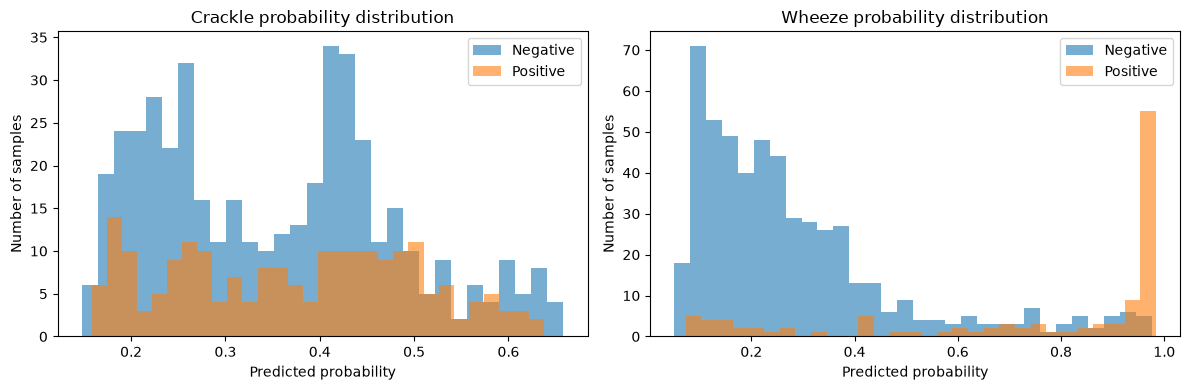

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)
    y_prob = cnn_lstm_val_prob[:, i]

    axes[i].hist(
        y_prob[y_true == 0],
        bins=30,
        alpha=0.6,
        label="Negative"
    )

    axes[i].hist(
        y_prob[y_true == 1],
        bins=30,
        alpha=0.6,
        label="Positive"
    )

    axes[i].set_title(f"{event} probability distribution")
    axes[i].set_xlabel("Predicted probability")
    axes[i].set_ylabel("Number of samples")
    axes[i].legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)
    y_prob = cnn_lstm_val_prob[:, i]

    print(f"\n{event}")
    print("Negative samples:")
    print("  Mean:", np.mean(y_prob[y_true == 0]))
    print("  Median:", np.median(y_prob[y_true == 0]))

    print("Positive samples:")
    print("  Mean:", np.mean(y_prob[y_true == 1]))
    print("  Median:", np.median(y_prob[y_true == 1]))

    print("  Min:", np.min(y_prob[y_true == 1]))
    print("  Max:", np.max(y_prob[y_true == 1]))


Crackle
Negative samples:
  Mean: 0.35313374
  Median: 0.35331827
Positive samples:
  Mean: 0.3732843
  Median: 0.38123918
  Min: 0.15821601
  Max: 0.637871

Wheeze
Negative samples:
  Mean: 0.28266668
  Median: 0.22839579
Positive samples:
  Mean: 0.74815553
  Median: 0.9409096
  Min: 0.072964825
  Max: 0.9837593


In [ ]:
import numpy as np

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)
    y_prob = cnn_lstm_val_prob[:, i]

    print(f"\n{'='*40}")
    print(event)

    for label, name in [(0, "Negative"), (1, "Positive")]:

        values = y_prob[y_true == label]

        print(f"\n{name} samples:")
        print("10th percentile:", np.percentile(values, 10))
        print("25th percentile:", np.percentile(values, 25))
        print("75th percentile:", np.percentile(values, 75))
        print("90th percentile:", np.percentile(values, 90))
        print("Standard deviation:", np.std(values))


Crackle

Negative samples:
10th percentile: 0.19292803
25th percentile: 0.23907982
75th percentile: 0.43725035
90th percentile: 0.52746785
Standard deviation: 0.12764293

Positive samples:
10th percentile: 0.19290926
25th percentile: 0.26081055
75th percentile: 0.47634122
90th percentile: 0.53392804
Standard deviation: 0.12733103

Wheeze

Negative samples:
10th percentile: 0.096351705
25th percentile: 0.13931662
75th percentile: 0.34976542
90th percentile: 0.5460188
Standard deviation: 0.20159188

Positive samples:
10th percentile: 0.15756492
25th percentile: 0.600848
75th percentile: 0.9788759
90th percentile: 0.98140424
Standard deviation: 0.3151839


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)
    y_prob = cnn_lstm_val_prob[:, i]

    print(f"\n{event}")
    print("Positive labels:", np.sum(y_true))
    print("Negative labels:", np.sum(y_true == 0))
    print("ROC-AUC:", roc_auc_score(y_true, y_prob))
    print("Average Precision:", average_precision_score(y_true, y_prob))
    print("Prediction range:", y_prob.min(), "to", y_prob.max())


Crackle
Positive labels: 209
Negative labels: 440
ROC-AUC: 0.5516637668551545
Average Precision: 0.3547388512385311
Prediction range: 0.14765793 to 0.65826154

Wheeze
Positive labels: 116
Negative labels: 533
ROC-AUC: 0.849663582842725
Average Precision: 0.7635946742186358
Prediction range: 0.050573613 to 0.9837593


In [ ]:
print("Validation feature shape:", X_val_3ch.shape)
print("Validation label shape:", y_val_multi.shape)
print("Validation metadata rows:", len(candidate_val_df))

print("\nClass distribution:")
print(candidate_val_df["label"].value_counts())

print("\nPatient count:")
print(candidate_val_df["patient"].nunique())

Validation feature shape: (649, 64, 157, 3)
Validation label shape: (649, 2)
Validation metadata rows: 649

Class distribution:
label
normal            359
crackle           174
wheeze             81
crackle+wheeze     35
Name: count, dtype: int64

Patient count:
16


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

patient_results = []

for patient, indices in candidate_val_df.groupby("patient").groups.items():

    indices = np.asarray(list(indices), dtype=int)

    row = {
        "patient": patient,
        "samples": len(indices),
        "crackle_positive": int(y_val_multi[indices, 0].sum()),
        "wheeze_positive": int(y_val_multi[indices, 1].sum())
    }

    for i, event in enumerate(["crackle", "wheeze"]):

        y_true = y_val_multi[indices, i].astype(int)
        y_prob = cnn_lstm_val_prob[indices, i]

        if len(np.unique(y_true)) == 2:
            row[f"{event}_auc"] = roc_auc_score(y_true, y_prob)
            row[f"{event}_ap"] = average_precision_score(y_true, y_prob)
        else:
            row[f"{event}_auc"] = np.nan
            row[f"{event}_ap"] = np.nan

    patient_results.append(row)

patient_results_df = pd.DataFrame(patient_results)

print(patient_results_df.sort_values("samples", ascending=False).to_string(index=False))

patient  samples  crackle_positive  wheeze_positive  crackle_auc  crackle_ap  wheeze_auc  wheeze_ap
    213      129                18                0     0.451952    0.134317         NaN        NaN
    186      126                74                2     0.576403    0.634272    0.850806   0.101732
    166      115                28                3     0.441708    0.253897    0.470238   0.049380
    110       52                15                6     0.542342    0.308761    0.902174   0.539352
    192       46                 4               41     0.416667    0.126581    0.882927   0.985312
    226       31                13                0     0.405983    0.399280         NaN        NaN
    180       30                29               26     0.724138    0.989511    0.980769   0.997253
    206       27                 1               22     0.307692    0.052632    1.000000   1.000000
    161       19                 4               11     0.716667    0.656250    0.556818   0.625410


In [ ]:
# Check the validation metadata columns
print(candidate_val_df.columns.tolist())

# Patient-wise device distribution
device_patient_table = pd.crosstab(
    candidate_val_df["patient"],
    candidate_val_df["device"]
)

print(device_patient_table.to_string())

['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge']


KeyError: 'device'

In [ ]:
# Device-wise sample distribution
print(
    candidate_val_df.groupby("device").agg(
        samples=("label", "size"),
        patients=("patient", "nunique")
    ).sort_values("samples", ascending=False)
)

KeyError: 'device'

In [ ]:
print("Columns:", candidate_val_df.columns.tolist())

print("\nFirst 5 rows:")
display(candidate_val_df.head())

print("\nData types:")
print(candidate_val_df.dtypes)

Columns: ['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge']

First 5 rows:


,wav_path,patient,recording,start,end,crackle,wheeze,label,official_split,_merge
0,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,0.036,2.907,0,0,normal,train,both
1,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,2.907,7.564,0,0,normal,train,both
2,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,7.564,9.679,0,0,normal,train,both
3,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,9.679,12.236,0,0,normal,train,both
4,..\data\raw\108_1b1_Al_sc_Meditron.wav,108,108_1b1_Al_sc_Meditron,12.236,14.479,0,0,normal,train,both



Data types:
wav_path              str
patient               str
recording             str
start             float64
end               float64
crackle             int64
wheeze              int64
label                 str
official_split        str
_merge                str
dtype: object


In [ ]:
candidate_val_df["device"] = (
    candidate_val_df["recording"]
    .str.extract(r"_([^_]+)$")[0]
)

print("Device distribution:")
print(candidate_val_df["device"].value_counts())

print("\nPatients per device:")
print(
    candidate_val_df.groupby("device")["patient"]
    .nunique()
)

Device distribution:
device
AKGC417L    285
Meditron    279
LittC2SE     85
Name: count, dtype: int64

Patients per device:
device
AKGC417L    3
LittC2SE    5
Meditron    9
Name: patient, dtype: int64


In [ ]:
device_patient_table = pd.crosstab(
    candidate_val_df["patient"],
    candidate_val_df["device"]
)

print(device_patient_table.to_string())

device   AKGC417L  LittC2SE  Meditron
patient                              
108             0         0         8
110             0         0        52
128             0         5         0
161             0         0        19
164             0         0        10
166             0         0       115
179             0         0        15
180            30         0         0
186           126         0         0
189             0         5         0
192             0        46         0
199             0        18         0
206             0         0        27
208             0         0        13
213           129         0         0
226             0        11        20


In [ ]:
device_class_table = pd.crosstab(
    candidate_val_df["device"],
    candidate_val_df["label"]
)

print(device_class_table.to_string())



label     crackle  crackle+wheeze  normal  wheeze
device                                           
AKGC417L       96              25     161       3
LittC2SE       23               3      21      38
Meditron       55               7     177      40


In [ ]:
val_feature_order_df = pd.concat(
    [
        group
        for _, group in candidate_val_df.groupby(
            "wav_path", sort=False
        )
    ],
    ignore_index=True
)

print("Feature samples:", len(X_val_3ch))
print("Metadata samples:", len(val_feature_order_df))

assert len(val_feature_order_df) == len(X_val_3ch)

print(
    "Framepad labels aligned:",
    np.array_equal(
        val_feature_order_df["label"]
        .map(class_to_idx)
        .to_numpy(),
        y_val_framepad
    )
)

expected_multi = np.column_stack([
    (y_val_framepad == class_to_idx["crackle"]) |
    (y_val_framepad == class_to_idx["crackle+wheeze"]),

    (y_val_framepad == class_to_idx["wheeze"]) |
    (y_val_framepad == class_to_idx["crackle+wheeze"])
]).astype(np.int32)

print(
    "Multi-label targets aligned:",
    np.array_equal(expected_multi, y_val_multi)
)

Feature samples: 649
Metadata samples: 649
Framepad labels aligned: True
Multi-label targets aligned: True


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

device_results = []

for device, group in val_feature_order_df.groupby("device"):

    indices = group.index.to_numpy()

    row = {
        "device": device,
        "samples": len(indices),
        "patients": group["patient"].nunique()
    }

    for i, event in enumerate(["crackle", "wheeze"]):

        y_true = y_val_multi[indices, i].astype(int)
        y_prob = cnn_lstm_val_prob[indices, i]

        if len(np.unique(y_true)) == 2:
            row[f"{event}_auc"] = roc_auc_score(y_true, y_prob)
            row[f"{event}_ap"] = average_precision_score(y_true, y_prob)
        else:
            row[f"{event}_auc"] = np.nan
            row[f"{event}_ap"] = np.nan

    device_results.append(row)

print(pd.DataFrame(device_results).to_string(index=False))

  device  samples  patients  crackle_auc  crackle_ap  wheeze_auc  wheeze_ap
AKGC417L      285         3     0.537543    0.417371    0.953724   0.717602
LittC2SE       85         5     0.297914    0.258863    0.967295   0.972501
Meditron      279         9     0.456964    0.208845    0.749450   0.660848


In [ ]:
device_class_summary = (
    candidate_val_df
    .groupby("device")
    .agg(
        samples=("label", "size"),
        patients=("patient", "nunique"),
        crackle_positive=("crackle", "sum"),
        wheeze_positive=("wheeze", "sum")
    )
)

device_class_summary["crackle_negative"] = (
    device_class_summary["samples"]
    - device_class_summary["crackle_positive"]
)

device_class_summary["wheeze_negative"] = (
    device_class_summary["samples"]
    - device_class_summary["wheeze_positive"]
)

print(device_class_summary)

          samples  patients  crackle_positive  wheeze_positive  \
device                                                           
AKGC417L      285         3               121               28   
LittC2SE       85         5                26               41   
Meditron      279         9                62               47   

          crackle_negative  wheeze_negative  
device                                       
AKGC417L               164              257  
LittC2SE                59               44  
Meditron               217              232  


In [ ]:
print("Original train:", X_train_3ch.shape)
print("Aligned train:", X_train_3ch_aligned.shape)

print("Original validation:", X_val_3ch.shape)
print("Aligned validation:", X_val_3ch_aligned.shape)

print("\nFinite values:")
print("Original:", np.isfinite(X_val_3ch).all())
print("Aligned:", np.isfinite(X_val_3ch_aligned).all())

Original train: (3376, 64, 157, 3)


NameError: name 'X_train_3ch_aligned' is not defined

In [ ]:
aligned_vars = [
    name for name in globals()
    if "align" in name.lower()
]

print("Alignment-related variables:")
for name in aligned_vars:
    obj = globals()[name]
    print(name, getattr(obj, "shape", type(obj)))

Alignment-related variables:
patient_weights_aligned (3376,)
X_train_logmel_aligned (3376, 64, 157, 1)
X_val_logmel_aligned (649, 64, 157, 1)
apply_device_alignment <class 'function'>
X_aligned (3376, 64, 157)
aligned_profiles <class 'dict'>
aligned_patient_profiles <class 'dict'>
aligned_a (64,)
aligned_b (64,)
aligned_mad ()
aligned_corr ()
aligned_distance ()


In [ ]:
print("Original train:", X_train_3ch.shape)
print("Original validation:", X_val_3ch.shape)

Original train: (3376, 64, 157, 3)
Original validation: (649, 64, 157, 3)


In [ ]:
import inspect

print(inspect.getsource(apply_device_alignment))

def apply_device_alignment(X, metadata, masks, split_name):

    metadata = metadata.reset_index(drop=True)

    devices = (
        metadata["recording"]
        .astype(str)
        .str.rsplit("_", n=1)
        .str[-1]
        .to_numpy()
    )

    results = []

    for device in np.unique(devices):

        indices = np.where(devices == device)[0]

        if device not in correction_profiles:
            print(f"{split_name}: {device} unchanged")
            continue

        correction = correction_profiles[device]

        clipped = 0
        total = 0

        for i in indices:

            valid = masks[i]
            logmel = X[i, :, :, 0]

            logmel[:, valid] += correction[:, None]

            adjusted = logmel[:, valid]

            clipped += np.count_nonzero(
                (adjusted < 0) | (adjusted > 1)
            )

            total += adjusted.size

            np.clip(logmel, 0, 1, out=logmel)

            # Preserve padded frames
            logmel[:,

In [ ]:
for name in globals():
    if any(term in name.lower() for term in [
        "delta", "normalize", "normalise", "logmel", "feature"
    ]):
        obj = globals()[name]
        if callable(obj):
            print("\nFUNCTION:", name)
            try:
                print(inspect.getsource(obj))
            except Exception:
                print("Source unavailable")


FUNCTION: extract_logmel
def extract_logmel(segment):

    mel_power = librosa.feature.melspectrogram(
        y=segment,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel_power,
        ref=np.max
    )

    log_mel = np.clip(log_mel, -80.0, 0.0)

    log_mel = (log_mel + 80.0) / 80.0

    return log_mel.astype(np.float32)


FUNCTION: build_features
def build_features(frame, split_name, noise_snr_db=None, random_seed=42):

    # Create a random-number generator for reproducible noise experiments
    rng = np.random.default_rng(random_seed)

    # Lists to store the features, labels, and segment information
    features = []
    labels = []
    metadata = []

    # Counters for checking preprocessing
    invalid_segments = 0
    cropped_segments = 0

    # Group annotation rows by audio file so each recording is loaded once
    fo

In [ ]:
print("Train mask:", train_mfcc_mask.shape)
print("Validation mask:", val_mfcc_mask.shape)

print("Train aligned Log-Mel:", X_train_logmel_aligned.shape)
print("Validation aligned Log-Mel:", X_val_logmel_aligned.shape)

Train mask: (3376, 157)
Validation mask: (649, 157)
Train aligned Log-Mel: (3376, 64, 157, 1)
Validation aligned Log-Mel: (649, 64, 157, 1)


In [ ]:
X_train_3ch_aligned = build_three_channel_features(
    X_train_logmel_aligned,
    train_mfcc_mask,
    "Aligned Train"
)

X_val_3ch_aligned = build_three_channel_features(
    X_val_logmel_aligned,
    val_mfcc_mask,
    "Aligned Validation"
)

print("\nFinal shapes:")
print("Train:", X_train_3ch_aligned.shape)
print("Validation:", X_val_3ch_aligned.shape)

Aligned Train: 500/3376
Aligned Train: 1000/3376
Aligned Train: 1500/3376
Aligned Train: 2000/3376
Aligned Train: 2500/3376
Aligned Train: 3000/3376
Aligned Validation: 500/649

Final shapes:
Train: (3376, 64, 157, 3)
Validation: (649, 64, 157, 3)


In [ ]:
for name, X in [
    ("Original train", X_train_3ch),
    ("Aligned train", X_train_3ch_aligned),
    ("Original validation", X_val_3ch),
    ("Aligned validation", X_val_3ch_aligned)
]:
    print(
        name,
        "| Shape:", X.shape,
        "| Finite:", np.isfinite(X).all(),
        "| Mean:", round(float(X.mean()), 5),
        "| Std:", round(float(X.std()), 5)
    )

Original train | Shape: (3376, 64, 157, 3) | Finite: True | Mean: 0.06238 | Std: 0.61506
Aligned train | Shape: (3376, 64, 157, 3) | Finite: True | Mean: 0.05887 | Std: 0.15232
Original validation | Shape: (649, 64, 157, 3) | Finite: True | Mean: 0.06938 | Std: 0.68162
Aligned validation | Shape: (649, 64, 157, 3) | Finite: True | Mean: 0.05808 | Std: 0.14737


In [ ]:
def compare_channels(X_original, X_aligned, name):

    print(f"\n========== {name} ==========")

    for ch, channel_name in enumerate([
        "Log-Mel",
        "Delta",
        "Delta-Delta"
    ]):

        original = X_original[..., ch]
        aligned = X_aligned[..., ch]

        print(f"\n{channel_name}")

        print(
            "Original:",
            "mean =", round(float(original.mean()), 5),
            "std =", round(float(original.std()), 5),
            "min =", round(float(original.min()), 5),
            "max =", round(float(original.max()), 5)
        )

        print(
            "Aligned:",
            "mean =", round(float(aligned.mean()), 5),
            "std =", round(float(aligned.std()), 5),
            "min =", round(float(aligned.min()), 5),
            "max =", round(float(aligned.max()), 5)
        )

        print(
            "Fraction at zero:",
            round(float(np.mean(aligned == 0)), 4)
        )

        if ch == 0:
            print(
                "Fraction at upper clipping limit:",
                round(float(np.mean(aligned == 1)), 4)
            )


compare_channels(
    X_train_3ch,
    X_train_3ch_aligned,
    "TRAIN"
)

compare_channels(
    X_val_3ch,
    X_val_3ch_aligned,
    "VALIDATION"
)


========== TRAIN ==========

Log-Mel
Original: mean = 0.18715 std = 0.22906 min = 0.0 max = 1.0
Aligned: mean = 0.17632 std = 0.22091 min = 0.0 max = 1.0
Fraction at zero: 0.4802
Fraction at upper clipping limit: 0.0001

Delta
Original: mean = 0.0 std = 0.7277 min = -14.98957 max = 14.14225
Aligned: mean = -0.00019 std = 0.00888 min = -0.15682 max = 0.14795
Fraction at zero: 0.4751

Delta-Delta
Original: mean = 0.0 std = 0.7277 min = -10.56171 max = 14.76551
Aligned: mean = 0.0005 std = 0.00588 min = -0.08532 max = 0.12316
Fraction at zero: 0.4751

========== VALIDATION ==========

Log-Mel
Original: mean = 0.18054 std = 0.21795 min = 0.0 max = 1.0
Aligned: mean = 0.1737 std = 0.21204 min = 0.0 max = 1.0
Fraction at zero: 0.4431
Fraction at upper clipping limit: 0.0001

Delta
Original: mean = -0.00091 std = 0.80123 min = -13.70611 max = 14.25195
Aligned: mean = -0.00022 std = 0.00974 min = -0.14329 max = 0.149
Fraction at zero: 0.438

Delta-Delta
Original: mean = 0.02851 std = 0.82788 

In [ ]:
for name in globals():
    obj = globals()[name]

    if isinstance(obj, pd.DataFrame):
        if "clipped_percent" in obj.columns:
            print("\n", name)
            display(obj)


 train_results


,split,device,cycles,clipped_percent
0,Training,AKGC417L,2156,2.120858
1,Training,LittC2SE,509,0.002268
2,Training,Meditron,683,0.717316



 val_results


,split,device,cycles,clipped_percent
0,Validation,AKGC417L,285,1.652924
1,Validation,LittC2SE,85,0.000458
2,Validation,Meditron,279,1.698543


In [ ]:
X_train_3ch_rebuilt = build_three_channel_features(
    X_train_3ch[..., 0:1],
    train_mfcc_mask,
    "Original Train Rebuilt"
)

X_val_3ch_rebuilt = build_three_channel_features(
    X_val_3ch[..., 0:1],
    val_mfcc_mask,
    "Original Validation Rebuilt"
)

for name, existing, rebuilt in [
    ("Train", X_train_3ch, X_train_3ch_rebuilt),
    ("Validation", X_val_3ch, X_val_3ch_rebuilt)
]:
    print(f"\n========== {name} ==========")

    for ch, channel_name in [(1, "Delta"), (2, "Delta-Delta")]:
        difference = np.abs(existing[..., ch] - rebuilt[..., ch])

        print(f"\n{channel_name}")
        print("Existing std:", existing[..., ch].std())
        print("Rebuilt std:", rebuilt[..., ch].std())
        print("Mean absolute difference:", difference.mean())
        print("Maximum absolute difference:", difference.max())

NameError: name 'train_mfcc_mask' is not defined

In [ ]:
# Rebuild raw derivatives from the original Log-Mel features
X_train_raw_rebuilt = build_three_channel_features(
    X_train_framepad,
    train_mfcc_mask,
    "Original Train Raw"
)

X_val_raw_rebuilt = build_three_channel_features(
    X_val_framepad,
    val_mfcc_mask,
    "Original Validation Raw"
)

# Apply the ORIGINAL training normalization statistics
for channel in [1, 2]:

    mean = delta_means[channel]
    std = delta_stds[channel]

    X_train_raw_rebuilt[..., channel] = (
        X_train_raw_rebuilt[..., channel]
        - mean[None, :, None]
    ) / std[None, :, None]

    X_val_raw_rebuilt[..., channel] = (
        X_val_raw_rebuilt[..., channel]
        - mean[None, :, None]
    ) / std[None, :, None]

    # Restore padded frames
    X_train_raw_rebuilt[..., channel] *= train_mfcc_mask[:, None, :]
    X_val_raw_rebuilt[..., channel] *= val_mfcc_mask[:, None, :]

# Compare with original arrays
for name, original, rebuilt in [
    ("Train", X_train_3ch, X_train_raw_rebuilt),
    ("Validation", X_val_3ch, X_val_raw_rebuilt)
]:
    print(f"\n========== {name} ==========")

    for ch, channel_name in [(1, "Delta"), (2, "Delta-Delta")]:
        difference = np.abs(
            original[..., ch] - rebuilt[..., ch]
        )

        print(
            channel_name,
            "Original std:", original[..., ch].std(),
            "Rebuilt std:", rebuilt[..., ch].std(),
            "Mean absolute difference:", difference.mean(),
            "Maximum absolute difference:", difference.max()
        )

NameError: name 'X_train_framepad' is not defined

In [ ]:
# Step 1: Generate raw aligned 3-channel features
X_train_3ch_aligned_raw = build_three_channel_features(
    X_train_logmel_aligned,
    train_mfcc_mask,
    "Aligned Train"
)

X_val_3ch_aligned_raw = build_three_channel_features(
    X_val_logmel_aligned,
    val_mfcc_mask,
    "Aligned Validation"
)

# Step 2: Apply ORIGINAL derivative normalization statistics
X_train_3ch_aligned = X_train_3ch_aligned_raw.copy()
X_val_3ch_aligned = X_val_3ch_aligned_raw.copy()

for channel in [1, 2]:

    mean = delta_means[channel]
    std = delta_stds[channel]

    X_train_3ch_aligned[..., channel] = (
        X_train_3ch_aligned[..., channel]
        - mean[None, :, None]
    ) / std[None, :, None]

    X_val_3ch_aligned[..., channel] = (
        X_val_3ch_aligned[..., channel]
        - mean[None, :, None]
    ) / std[None, :, None]

    # Preserve padding
    X_train_3ch_aligned[..., channel] *= (
        train_mfcc_mask[:, None, :]
    )

    X_val_3ch_aligned[..., channel] *= (
        val_mfcc_mask[:, None, :]
    )

print("Train:", X_train_3ch_aligned.shape)
print("Validation:", X_val_3ch_aligned.shape)

print("Train finite:", np.isfinite(X_train_3ch_aligned).all())
print("Validation finite:", np.isfinite(X_val_3ch_aligned).all())

Aligned Train: 500/3376
Aligned Train: 1000/3376
Aligned Train: 1500/3376
Aligned Train: 2000/3376
Aligned Train: 2500/3376
Aligned Train: 3000/3376
Aligned Validation: 500/649
Train: (3376, 64, 157, 3)
Validation: (649, 64, 157, 3)
Train finite: True
Validation finite: True


In [ ]:
for name, X in [
    ("Original Train", X_train_3ch),
    ("Aligned Train", X_train_3ch_aligned),
    ("Original Validation", X_val_3ch),
    ("Aligned Validation", X_val_3ch_aligned)
]:
    print(f"\n{name}")

    for ch, channel_name in enumerate(
        ["Log-Mel", "Delta", "Delta-Delta"]
    ):
        print(
            channel_name,
            "mean =", round(float(X[..., ch].mean()), 5),
            "std =", round(float(X[..., ch].std()), 5)
        )


Original Train
Log-Mel mean = 0.18715 std = 0.22906
Delta mean = 0.0 std = 0.7277
Delta-Delta mean = 0.0 std = 0.7277

Aligned Train
Log-Mel mean = 0.17632 std = 0.22091
Delta mean = 4e-05 std = 0.72542
Delta-Delta mean = -0.00021 std = 0.72533

Original Validation
Log-Mel mean = 0.18054 std = 0.21795
Delta mean = -0.00091 std = 0.80123
Delta-Delta mean = 0.02851 std = 0.82788

Aligned Validation
Log-Mel mean = 0.1737 std = 0.21204
Delta mean = -0.00089 std = 0.79998
Delta-Delta mean = 0.02838 std = 0.82666


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

# Predictions using the same existing checkpoint
original_val_prob = cnn_lstm_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

aligned_val_prob = cnn_lstm_model.predict(
    X_val_3ch_aligned,
    batch_size=32,
    verbose=1
)

print("Original predictions:", original_val_prob.shape)
print("Aligned predictions:", aligned_val_prob.shape)

# Compare threshold-independent metrics
comparison = []

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)

    original_auc = roc_auc_score(y_true, original_val_prob[:, i])
    original_ap = average_precision_score(y_true, original_val_prob[:, i])

    aligned_auc = roc_auc_score(y_true, aligned_val_prob[:, i])
    aligned_ap = average_precision_score(y_true, aligned_val_prob[:, i])

    comparison.append({
        "Event": event,
        "Original ROC-AUC": original_auc,
        "Aligned ROC-AUC": aligned_auc,
        "ROC-AUC change": aligned_auc - original_auc,
        "Original AP": original_ap,
        "Aligned AP": aligned_ap,
        "AP change": aligned_ap - original_ap
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
Original predictions: (649, 2)
Aligned predictions: (649, 2)


,Event,Original ROC-AUC,Aligned ROC-AUC,ROC-AUC change,Original AP,Aligned AP,AP change
0,Crackle,0.5517,0.5641,0.0125,0.3547,0.3670,0.0123
1,Wheeze,0.8497,0.8498,0.0002,0.7636,0.7655,0.0019


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

# Predictions using the same existing checkpoint
original_val_prob = cnn_lstm_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

aligned_val_prob = cnn_lstm_model.predict(
    X_val_3ch_aligned,
    batch_size=32,
    verbose=1
)

print("Original predictions:", original_val_prob.shape)
print("Aligned predictions:", aligned_val_prob.shape)

# Compare threshold-independent metrics
comparison = []

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)

    original_auc = roc_auc_score(y_true, original_val_prob[:, i])
    original_ap = average_precision_score(y_true, original_val_prob[:, i])

    aligned_auc = roc_auc_score(y_true, aligned_val_prob[:, i])
    aligned_ap = average_precision_score(y_true, aligned_val_prob[:, i])

    comparison.append({
        "Event": event,
        "Original ROC-AUC": original_auc,
        "Aligned ROC-AUC": aligned_auc,
        "ROC-AUC change": aligned_auc - original_auc,
        "Original AP": original_ap,
        "Aligned AP": aligned_ap,
        "AP change": aligned_ap - original_ap
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Original predictions: (649, 2)
Aligned predictions: (649, 2)


,Event,Original ROC-AUC,Aligned ROC-AUC,ROC-AUC change,Original AP,Aligned AP,AP change
0,Crackle,0.5517,0.5641,0.0125,0.3547,0.3670,0.0123
1,Wheeze,0.8497,0.8498,0.0002,0.7636,0.7655,0.0019


In [ ]:
device_results = []

for device in val_feature_order_df["device"].unique():

    indices = np.where(
        val_feature_order_df["device"].to_numpy() == device
    )[0]

    for i, event in enumerate(["Crackle", "Wheeze"]):

        y_true = y_val_multi[indices, i].astype(int)

        if len(np.unique(y_true)) < 2:
            continue

        original_auc = roc_auc_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_auc = roc_auc_score(
            y_true, aligned_val_prob[indices, i]
        )

        original_ap = average_precision_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_ap = average_precision_score(
            y_true, aligned_val_prob[indices, i]
        )

        device_results.append({
            "Device": device,
            "Event": event,
            "Samples": len(indices),
            "Original AUC": original_auc,
            "Aligned AUC": aligned_auc,
            "AUC change": aligned_auc - original_auc,
            "Original AP": original_ap,
            "Aligned AP": aligned_ap,
            "AP change": aligned_ap - original_ap
        })

device_comparison_df = pd.DataFrame(device_results)

display(
    device_comparison_df.round(4)
    .sort_values(["Event", "Device"])
    .reset_index(drop=True)
)

,Device,Event,Samples,Original AUC,Aligned AUC,AUC change,Original AP,Aligned AP,AP change
0,AKGC417L,Crackle,285,0.5375,0.5635,0.0260,0.4174,0.4329,0.0156
1,LittC2SE,Crackle,85,0.2979,0.3090,0.0111,0.2589,0.2655,0.0066
2,Meditron,Crackle,279,0.4570,0.4565,-0.0004,0.2088,0.2126,0.0037
3,AKGC417L,Wheeze,285,0.9537,0.9584,0.0047,0.7176,0.7308,0.0132
4,LittC2SE,Wheeze,85,0.9673,0.9690,0.0017,0.9725,0.9730,0.0005
5,Meditron,Wheeze,279,0.7494,0.7509,0.0015,0.6608,0.6590,-0.0018


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_bootstrap = 2000

patient_ids = val_feature_order_df["patient"].to_numpy()
unique_patients = np.unique(patient_ids)

# Preserve all cycles belonging to each patient
patient_indices = {
    p: np.where(patient_ids == p)[0]
    for p in unique_patients
}

bootstrap_results = []

for event_idx, event in enumerate(["Crackle", "Wheeze"]):

    y = y_val_multi[:, event_idx].astype(int)

    original_prob = original_val_prob[:, event_idx]
    aligned_prob = aligned_val_prob[:, event_idx]

    auc_differences = []
    ap_differences = []

    for b in range(n_bootstrap):

        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        indices = np.concatenate([
            patient_indices[p] for p in sampled_patients
        ])

        y_boot = y[indices]

        # Both classes must be present for ROC-AUC
        if len(np.unique(y_boot)) < 2:
            continue

        original_auc = roc_auc_score(
            y_boot, original_prob[indices]
        )

        aligned_auc = roc_auc_score(
            y_boot, aligned_prob[indices]
        )

        original_ap = average_precision_score(
            y_boot, original_prob[indices]
        )

        aligned_ap = average_precision_score(
            y_boot, aligned_prob[indices]
        )

        auc_differences.append(aligned_auc - original_auc)
        ap_differences.append(aligned_ap - original_ap)

    for metric, differences in [
        ("ROC-AUC", auc_differences),
        ("Average Precision", ap_differences)
    ]:

        differences = np.asarray(differences)

        bootstrap_results.append({
            "Event": event,
            "Metric": metric,
            "Valid bootstrap samples": len(differences),
            "Mean improvement": differences.mean(),
            "95% CI lower": np.percentile(differences, 2.5),
            "95% CI upper": np.percentile(differences, 97.5),
            "Bootstrap fraction positive": np.mean(differences > 0)
        })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(4))

,Event,Metric,Valid bootstrap samples,Mean improvement,95% CI lower,95% CI upper,Bootstrap fraction positive
0,Crackle,ROC-AUC,2000,0.0095,-0.0091,0.0288,0.7295
1,Crackle,Average Precision,2000,0.0082,-0.0071,0.0222,0.7765
2,Wheeze,ROC-AUC,2000,0.0005,-0.0041,0.0062,0.5495
3,Wheeze,Average Precision,2000,0.0009,-0.0077,0.0102,0.5970


In [ ]:
# Calculate aligned derivative normalization statistics
aligned_delta_means = {}
aligned_delta_stds = {}

for channel in [1, 2]:

    channel_means = np.array([
        X_train_3ch_aligned_raw[:, f, :, channel][train_mfcc_mask].mean()
        for f in range(X_train_3ch_aligned_raw.shape[1])
    ])

    channel_stds = np.array([
        X_train_3ch_aligned_raw[:, f, :, channel][train_mfcc_mask].std()
        for f in range(X_train_3ch_aligned_raw.shape[1])
    ])

    channel_stds = np.maximum(channel_stds, 1e-6)

    aligned_delta_means[channel] = channel_means
    aligned_delta_stds[channel] = channel_stds

    print(
        f"Channel {channel}: "
        f"mean range=({channel_means.min():.5f}, "
        f"{channel_means.max():.5f}), "
        f"std range=({channel_stds.min():.5f}, "
        f"{channel_stds.max():.5f})"
    )

Channel 1: mean range=(-0.00049, -0.00000), std range=(0.01044, 0.01402)
Channel 2: mean range=(-0.00017, 0.00249), std range=(0.00723, 0.00882)


In [ ]:
# Create independent copies
X_train_aligned_final = X_train_3ch_aligned_raw.copy()
X_val_aligned_final = X_val_3ch_aligned_raw.copy()

# Normalize derivative channels using aligned training statistics
for channel in [1, 2]:

    mean = aligned_delta_means[channel]
    std = aligned_delta_stds[channel]

    # Training normalization
    X_train_aligned_final[..., channel] = (
        X_train_aligned_final[..., channel]
        - mean[None, :, None]
    ) / std[None, :, None]

    # Validation uses training statistics
    X_val_aligned_final[..., channel] = (
        X_val_aligned_final[..., channel]
        - mean[None, :, None]
    ) / std[None, :, None]

    # Restore padding
    X_train_aligned_final[..., channel] *= (
        train_mfcc_mask[:, None, :]
    )

    X_val_aligned_final[..., channel] *= (
        val_mfcc_mask[:, None, :]
    )

print("Train shape:", X_train_aligned_final.shape)
print("Validation shape:", X_val_aligned_final.shape)

print("Train finite:", np.isfinite(X_train_aligned_final).all())
print("Validation finite:", np.isfinite(X_val_aligned_final).all())

for name, X, mask in [
    ("Aligned Train", X_train_aligned_final, train_mfcc_mask),
    ("Aligned Validation", X_val_aligned_final, val_mfcc_mask)
]:
    print(f"\n{name}")

    for channel, channel_name in [
        (0, "Log-Mel"),
        (1, "Delta"),
        (2, "Delta-Delta")
    ]:
        values = X[..., channel]
        valid_values = np.concatenate([
            values[i, :, mask[i]]
            for i in range(len(values))
        ])

        print(
            f"{channel_name}: "
            f"mean={valid_values.mean():.5f}, "
            f"std={valid_values.std():.5f}"
        )

Train shape: (3376, 64, 157, 3)
Validation shape: (649, 64, 157, 3)
Train finite: True
Validation finite: True

Aligned Train
Log-Mel: mean=0.33296, std=0.20000
Delta: mean=0.00000, std=1.00000
Delta-Delta: mean=0.00000, std=1.00000

Aligned Validation
Log-Mel: mean=0.30737, std=0.19615
Delta: mean=-0.00165, std=1.06778
Delta-Delta: mean=0.05077, std=1.10292


In [ ]:
print("Patient weights:", patient_weights_aligned.shape)
print("Training labels:", y_train_multi.shape)
print("Validation labels:", y_val_multi.shape)

print("Loss function exists:", callable(weighted_binary_crossentropy))
print("Positive weights:", positive_weights)

Patient weights: (3376,)
Training labels: (3376, 2)
Validation labels: (649, 2)
Loss function exists: True
Positive weights: [1.6436962 4.038806 ]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers, Model

# Build a fresh model with the ORIGINAL architecture
aligned_input = layers.Input(
    shape=(64, 157, 3),
    name="lung_sound_input"
)

x = layers.Conv2D(
    16, (3, 3), padding="same", activation="relu"
)(aligned_input)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    32, (3, 3), padding="same", activation="relu"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    64, (3, 3), padding="same", activation="relu"
)(x)

x = layers.AveragePooling2D(
    pool_size=(4, 1)
)(x)

x = layers.Permute((2, 1, 3))(x)
x = layers.Reshape((39, 256))(x)

x = layers.LSTM(
    64,
    return_sequences=False,
    name="temporal_lstm"
)(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    32,
    activation="relu",
    name="cnn_lstm_dense"
)(x)

x = layers.Dropout(0.2)(x)

aligned_output = layers.Dense(
    2,
    activation="sigmoid",
    name="event_predictions"
)(x)

aligned_cnn_lstm = Model(
    inputs=aligned_input,
    outputs=aligned_output,
    name="device_aligned_cnn_lstm"
)

# Compile with the same loss and optimizer
aligned_cnn_lstm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=weighted_binary_crossentropy,
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

aligned_cnn_lstm.summary()

Model: "device_aligned_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lung_sound_input (InputLayer)   │ (None, 64, 157, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_54 (Conv2D)              │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_55 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_15            │ (None, 4, 39, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 39, 4, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_lstm (LSTM)            │ (None, 64)             │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_lstm_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event_predictions (Dense)       │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,906 (421.51 KB)

 Trainable params: 107,906 (421.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
aligned_callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_cnn_lstm_device_aligned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

aligned_cnn_lstm_history = aligned_cnn_lstm.fit(
    X_train_aligned_final,
    y_train_multi,
    sample_weight=patient_weights_aligned,
    validation_data=(
        X_val_aligned_final,
        y_val_multi
    ),
    epochs=50,
    batch_size=32,
    callbacks=aligned_callbacks,
    verbose=1
)

Epoch 1/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - binary_accuracy: 0.6136 - loss: 0.9309
Epoch 1: val_loss improved from None to 0.95268, saving model to best_cnn_lstm_device_aligned.keras

Epoch 1: finished saving model to best_cnn_lstm_device_aligned.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - binary_accuracy: 0.6136 - loss: 0.9309 - val_binary_accuracy: 0.6541 - val_loss: 0.9527 - learning_rate: 0.0010
Epoch 2/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - binary_accuracy: 0.6308 - loss: 0.9161
Epoch 2: val_loss improved from 0.95268 to 0.94557, saving model to best_cnn_lstm_device_aligned.keras

Epoch 2: finished saving model to best_cnn_lstm_device_aligned.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 96ms/step - binary_accuracy: 0.6308 - loss: 0.9161 - val_binary_accuracy: 0.7026 - val_loss: 0.9456 - learning_rate: 0.0010
Epoch 3/50
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - binary_accuracy: 0.6521 - loss: 0.8905
Epoch 3: val_loss improved from 0.94557 to 0.87884, saving mo

In [ ]:
from tensorflow import keras
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import numpy as np

# Load the best aligned checkpoint (epoch 8)
best_aligned_model = keras.models.load_model(
    "best_cnn_lstm_device_aligned.keras",
    custom_objects={
        "weighted_binary_crossentropy": weighted_binary_crossentropy
    }
)

# Generate predictions
aligned_trained_val_prob = best_aligned_model.predict(
    X_val_aligned_final,
    batch_size=32,
    verbose=1
)

# Original checkpoint predictions are already available
# in original_val_prob

results = []

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i].astype(int)

    original_auc = roc_auc_score(
        y_true, original_val_prob[:, i]
    )

    trained_auc = roc_auc_score(
        y_true, aligned_trained_val_prob[:, i]
    )

    original_ap = average_precision_score(
        y_true, original_val_prob[:, i]
    )

    trained_ap = average_precision_score(
        y_true, aligned_trained_val_prob[:, i]
    )

    results.append({
        "Event": event,
        "Original ROC-AUC": original_auc,
        "Aligned trained ROC-AUC": trained_auc,
        "AUC change": trained_auc - original_auc,
        "Original AP": original_ap,
        "Aligned trained AP": trained_ap,
        "AP change": trained_ap - original_ap
    })

trained_comparison_df = pd.DataFrame(results)

display(trained_comparison_df.round(4))

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step


,Event,Original ROC-AUC,Aligned trained ROC-AUC,AUC change,Original AP,Aligned trained AP,AP change
0,Crackle,0.5517,0.5555,0.0039,0.3547,0.4019,0.0471
1,Wheeze,0.8497,0.9013,0.0516,0.7636,0.7917,0.0281


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

device_results = []

devices = val_feature_order_df["device"].to_numpy()

for device in np.unique(devices):

    indices = np.where(devices == device)[0]

    for i, event in enumerate(["Crackle", "Wheeze"]):

        y_true = y_val_multi[indices, i].astype(int)

        if len(np.unique(y_true)) < 2:
            continue

        original_auc = roc_auc_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_auc = roc_auc_score(
            y_true, aligned_trained_val_prob[indices, i]
        )

        original_ap = average_precision_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_ap = average_precision_score(
            y_true, aligned_trained_val_prob[indices, i]
        )

        device_results.append({
            "Device": device,
            "Event": event,
            "Samples": len(indices),
            "Positives": int(y_true.sum()),
            "Original AUC": original_auc,
            "Aligned AUC": aligned_auc,
            "AUC change": aligned_auc - original_auc,
            "Original AP": original_ap,
            "Aligned AP": aligned_ap,
            "AP change": aligned_ap - original_ap
        })

device_trained_comparison = pd.DataFrame(device_results)

display(
    device_trained_comparison
    .round(4)
    .sort_values(["Event", "Device"])
    .reset_index(drop=True)
)

,Device,Event,Samples,Positives,Original AUC,Aligned AUC,AUC change,Original AP,Aligned AP,AP change
0,AKGC417L,Crackle,285,121,0.5375,0.6972,0.1596,0.4174,0.7071,0.2897
1,LittC2SE,Crackle,85,26,0.2979,0.2601,-0.0378,0.2589,0.2189,-0.0399
2,Meditron,Crackle,279,62,0.4570,0.4529,-0.0041,0.2088,0.2104,0.0015
3,AKGC417L,Wheeze,285,28,0.9537,0.9533,-0.0004,0.7176,0.7351,0.0175
4,LittC2SE,Wheeze,85,41,0.9673,0.9889,0.0216,0.9725,0.9883,0.0158
5,Meditron,Wheeze,279,47,0.7494,0.7912,0.0417,0.6608,0.6776,0.0167


In [ ]:
patient_results = []

patients = val_feature_order_df["patient"].to_numpy()

for patient in np.unique(patients):

    indices = np.where(patients == patient)[0]

    for i, event in enumerate(["Crackle", "Wheeze"]):

        y_true = y_val_multi[indices, i].astype(int)

        if len(np.unique(y_true)) < 2:
            continue

        original_auc = roc_auc_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_auc = roc_auc_score(
            y_true, aligned_trained_val_prob[indices, i]
        )

        patient_results.append({
            "Patient": patient,
            "Event": event,
            "Samples": len(indices),
            "Positives": int(y_true.sum()),
            "Original AUC": original_auc,
            "Aligned AUC": aligned_auc,
            "AUC change": aligned_auc - original_auc
        })

patient_trained_comparison = pd.DataFrame(patient_results)

display(
    patient_trained_comparison
    .round(4)
    .sort_values(["Event", "Patient"])
    .reset_index(drop=True)
)

,Patient,Event,Samples,Positives,Original AUC,Aligned AUC,AUC change
0,110,Crackle,52,15,0.5423,0.5405,-0.0018
1,128,Crackle,5,3,0.5000,0.3333,-0.1667
2,161,Crackle,19,4,0.7167,0.4167,-0.3000
3,164,Crackle,10,1,1.0000,1.0000,0.0000
4,166,Crackle,115,28,0.4417,0.4704,0.0287
5,179,Crackle,15,5,0.6400,0.5400,-0.1000
6,180,Crackle,30,29,0.7241,0.7586,0.0345
7,186,Crackle,126,74,0.5764,0.6416,0.0652
8,189,Crackle,5,2,0.6667,0.3333,-0.3333
9,192,Crackle,46,4,0.4167,0.7202,0.3036


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

rng = np.random.default_rng(42)

patient_ids = val_feature_order_df["patient"].to_numpy()
unique_patients = np.unique(patient_ids)

bootstrap_results = []

for event_idx, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, event_idx].astype(int)
    original_prob = original_val_prob[:, event_idx]
    aligned_prob = aligned_trained_val_prob[:, event_idx]

    auc_differences = []
    ap_differences = []

    for _ in range(5000):

        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        sampled_indices = np.concatenate([
            np.where(patient_ids == patient)[0]
            for patient in sampled_patients
        ])

        y_boot = y_true[sampled_indices]

        if len(np.unique(y_boot)) < 2:
            continue

        original_boot = original_prob[sampled_indices]
        aligned_boot = aligned_prob[sampled_indices]

        original_auc = roc_auc_score(y_boot, original_boot)
        aligned_auc = roc_auc_score(y_boot, aligned_boot)

        original_ap = average_precision_score(y_boot, original_boot)
        aligned_ap = average_precision_score(y_boot, aligned_boot)

        auc_differences.append(aligned_auc - original_auc)
        ap_differences.append(aligned_ap - original_ap)

    auc_differences = np.array(auc_differences)
    ap_differences = np.array(ap_differences)

    bootstrap_results.append({
        "Event": event,
        "Valid bootstrap samples": len(auc_differences),
        "Mean AUC improvement": np.mean(auc_differences),
        "AUC CI lower": np.percentile(auc_differences, 2.5),
        "AUC CI upper": np.percentile(auc_differences, 97.5),
        "AUC improvement frequency": np.mean(auc_differences > 0),
        "Mean AP improvement": np.mean(ap_differences),
        "AP CI lower": np.percentile(ap_differences, 2.5),
        "AP CI upper": np.percentile(ap_differences, 97.5),
        "AP improvement frequency": np.mean(ap_differences > 0)
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(4))

,Event,Valid bootstrap samples,Mean AUC improvement,AUC CI lower,AUC CI upper,AUC improvement frequency,Mean AP improvement,AP CI lower,AP CI upper,AP improvement frequency
0,Crackle,5000,0.0017,-0.0844,0.0745,0.5400,0.0344,-0.0861,0.1936,0.6484
1,Wheeze,5000,0.0516,0.0028,0.1340,0.9854,0.0317,-0.0060,0.0959,0.9498


In [ ]:
import soundfile as sf
import numpy as np
import os

# Upload your WAV file using the Colab file panel
from google.colab import files
uploaded = files.upload()

wav_path = next(iter(uploaded))

audio, sr = sf.read(wav_path)

print("File:", wav_path)
print("Sample rate:", sr)
print("Shape:", audio.shape)
print("Duration:", len(audio) / sr, "seconds")
print("Data type:", audio.dtype)

if audio.ndim == 2:
    print("Channels:", audio.shape[1])
    for i in range(audio.shape[1]):
        channel = audio[:, i]
        print(f"\nChannel {i+1}")
        print("Peak:", np.max(np.abs(channel)))
        print("RMS:", np.sqrt(np.mean(channel**2)))
        print("Clipping %:", np.mean(np.abs(channel) >= 0.999) * 100)
else:
    print("Mono recording")
    print("Peak:", np.max(np.abs(audio)))
    print("RMS:", np.sqrt(np.mean(audio**2)))

In [ ]:
pip install numpy soundfile matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:

import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
import os

# Exact WAV filenames
raw_path = "lung_raw_stereo_16k (1).wav"
nlms_path = "lung_nlms_residual_16k (1).wav"

# Check files exist
for path in [raw_path, nlms_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

# Read WAV files
raw_audio, raw_sr = sf.read(raw_path)
nlms_audio, nlms_sr = sf.read(nlms_path)

print("=" * 50)
print("RAW STEREO WAV")
print("=" * 50)
print("Sample rate:", raw_sr)
print("Shape:", raw_audio.shape)
print("Duration:", len(raw_audio) / raw_sr, "seconds")
print("Data type:", raw_audio.dtype)

print("\n" + "=" * 50)
print("NLMS RESIDUAL WAV")
print("=" * 50)
print("Sample rate:", nlms_sr)
print("Shape:", nlms_audio.shape)
print("Duration:", len(nlms_audio) / nlms_sr, "seconds")
print("Data type:", nlms_audio.dtype)


def analyse_signal(signal, name):
    peak = np.max(np.abs(signal))
    rms = np.sqrt(np.mean(signal ** 2))
    clipping = np.mean(np.abs(signal) >= 0.999) * 100

    print(f"\n{name}")
    print("-" * 35)
    print(f"Peak amplitude: {peak:.6f}")
    print(f"RMS amplitude: {rms:.6f}")
    print(f"Clipping: {clipping:.4f}%")

    return peak, rms


if raw_audio.ndim != 2 or raw_audio.shape[1] != 2:
    raise ValueError("Expected a stereo raw WAV with left and right channels.")

if nlms_audio.ndim != 1:
    raise ValueError("Expected a mono NLMS residual WAV.")

primary = raw_audio[:, 0]
ambient = raw_audio[:, 1]
residual = nlms_audio

# Analyse individual signals
primary_peak, primary_rms = analyse_signal(primary, "PRIMARY / CHEST")
ambient_peak, ambient_rms = analyse_signal(ambient, "AMBIENT / REFERENCE")
residual_peak, residual_rms = analyse_signal(residual, "NLMS RESIDUAL")

# Compare lengths and sample rates
print("\n" + "=" * 50)
print("ALIGNMENT CHECK")
print("=" * 50)
print("Same sample rate:", raw_sr == nlms_sr)
print("Same number of samples:", len(primary) == len(residual))

if raw_sr != nlms_sr:
    raise ValueError("Sample rates differ. Do not compare directly.")

if len(primary) != len(residual):
    raise ValueError("Sample counts differ. Check recording alignment.")

# Channel correlation
correlation = np.corrcoef(primary, ambient)[0, 1]
print("\nPrimary-ambient correlation:", correlation)

# RMS comparison
print("\n" + "=" * 50)
print("RAW PRIMARY vs NLMS")
print("=" * 50)

print("Primary RMS:", primary_rms)
print("Residual RMS:", residual_rms)
print("Residual/Primary RMS ratio:",
      residual_rms / (primary_rms + 1e-12))

# Plot waveform
time = np.arange(len(primary)) / raw_sr

plt.figure(figsize=(14, 8))

plt.subplot(3, 1, 1)
plt.plot(time, primary)
plt.title("Primary / Chest Microphone")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(time, ambient)
plt.title("Ambient / Reference Microphone")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(time, residual)
plt.title("NLMS Residual")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

# Frequency spectrum
plt.figure(figsize=(12, 5))

for signal, label in [
    (primary, "Primary"),
    (ambient, "Ambient"),
    (residual, "NLMS Residual")
]:
    frequencies, psd = welch(signal, fs=raw_sr, nperseg=1024)
    plt.semilogy(frequencies, psd + 1e-15, label=label)

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("Frequency Spectrum Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


FileNotFoundError: File not found: lung_raw_stereo_16k (1).wav

In [ ]:
device_results = []

for device in val_feature_order_df["device"].unique():

    indices = np.where(
        val_feature_order_df["device"].to_numpy() == device
    )[0]

    for i, event in enumerate(["Crackle", "Wheeze"]):

        y_true = y_val_multi[indices, i].astype(int)

        if len(np.unique(y_true)) < 2:
            continue

        original_auc = roc_auc_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_auc = roc_auc_score(
            y_true, aligned_val_prob[indices, i]
        )

        original_ap = average_precision_score(
            y_true, original_val_prob[indices, i]
        )

        aligned_ap = average_precision_score(
            y_true, aligned_val_prob[indices, i]
        )

        device_results.append({
            "Device": device,
            "Event": event,
            "Samples": len(indices),
            "Original AUC": original_auc,
            "Aligned AUC": aligned_auc,
            "AUC change": aligned_auc - original_auc,
            "Original AP": original_ap,
            "Aligned AP": aligned_ap,
            "AP change": aligned_ap - original_ap
        })

device_comparison_df = pd.DataFrame(device_results)

display(
    device_comparison_df.round(4)
    .sort_values(["Event", "Device"])
    .reset_index(drop=True)
)

,Device,Event,Samples,Original AUC,Aligned AUC,AUC change,Original AP,Aligned AP,AP change
0,AKGC417L,Crackle,285,0.5375,0.5635,0.0260,0.4174,0.4329,0.0156
1,LittC2SE,Crackle,85,0.2979,0.3090,0.0111,0.2589,0.2655,0.0066
2,Meditron,Crackle,279,0.4570,0.4565,-0.0004,0.2088,0.2126,0.0037
3,AKGC417L,Wheeze,285,0.9537,0.9584,0.0047,0.7176,0.7308,0.0132
4,LittC2SE,Wheeze,85,0.9673,0.9690,0.0017,0.9725,0.9730,0.0005
5,Meditron,Wheeze,279,0.7494,0.7509,0.0015,0.6608,0.6590,-0.0018


In [ ]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current working directory:
c:\Users\Admin\Respiratory_TinyML\notebooks

Files in current directory:
['01_explore_icbhi.ipynb', '02_build_dataset.ipynb', 'aligned_2sec_comparison.png', 'alternative_features_comparison.png', 'best_3ch_multilabel.keras', 'best_3ch_patient_balanced.keras', 'best_cnn_lstm_device_aligned.keras', 'best_cnn_lstm_patient_weighted.keras', 'best_framepad_cnn.keras', 'best_framepad_combined_boost_cnn.keras', 'best_framepad_dropout_cnn.keras', 'best_framepad_fusion.keras', 'best_framepad_gap_cnn.keras', 'best_framepad_multilabel_cnn.keras', 'best_framepad_multilabel_gap.keras', 'best_framepad_multilabel_mfcc.keras', 'cnn_lstm_official_test_predictions.csv', 'cycle_0_correct_scaling.png', 'incorrect.png', 'incrrect with padding.png', 'models', 'normal_vs_crackle_side_by_side.png', 'recordings', 'requiremnets.txt', 'results', 'src']


In [ ]:
from pathlib import Path

recordings_folder = Path("../recordings")

for file in recordings_folder.rglob("*.wav"):
    print(file.resolve())

In [ ]:
from pathlib import Path

search_locations = [
    Path.home() / "Downloads",
    Path.home() / "Desktop",
    Path.home() / "Documents"
]

for folder in search_locations:
    print(f"\nSearching: {folder}")

    if folder.exists():
        for file in folder.rglob("*.wav"):
            print(file)


Searching: C:\Users\Admin\Downloads

Searching: C:\Users\Admin\Desktop
C:\Users\Admin\Desktop\lung_nlms_residual_16k (1).wav
C:\Users\Admin\Desktop\lung_raw_stereo_16k (1).wav

Searching: C:\Users\Admin\Documents


In [ ]:
raw_path = r"C:\Users\Admin\Desktop\lung_raw_stereo_16k (1).wav"

nlms_path = r"C:\Users\Admin\Desktop\lung_nlms_residual_16k (1).wav"

Raw file exists: True
NLMS file exists: True

========== AUDIO INFORMATION ==========

RAW AUDIO
Sample rate: 16000
Shape: (80000, 2)
Duration: 5.0 seconds
Data type: float64

NLMS RESIDUAL
Sample rate: 16000
Shape: (80000,)
Duration: 5.0 seconds
Data type: float64

========== SIGNAL METRICS ==========

Raw primary (chest)
Peak amplitude: 0.096008
RMS amplitude: 0.028673
Clipping: 0.0000%

Raw ambient
Peak amplitude: 0.000000
RMS amplitude: 0.000000
Clipping: 0.0000%

NLMS residual
Peak amplitude: 0.032013
RMS amplitude: 0.007084
Clipping: 0.0000%


c:\Users\Admin\Respiratory_TinyML\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Admin\Respiratory_TinyML\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]



========== CORRELATION ==========
Primary-Ambient correlation: nan

========== NLMS COMPARISON ==========
Primary RMS: 0.028673
Residual RMS: 0.007084
Residual / Primary RMS: 0.2471
RMS change: -12.14 dB


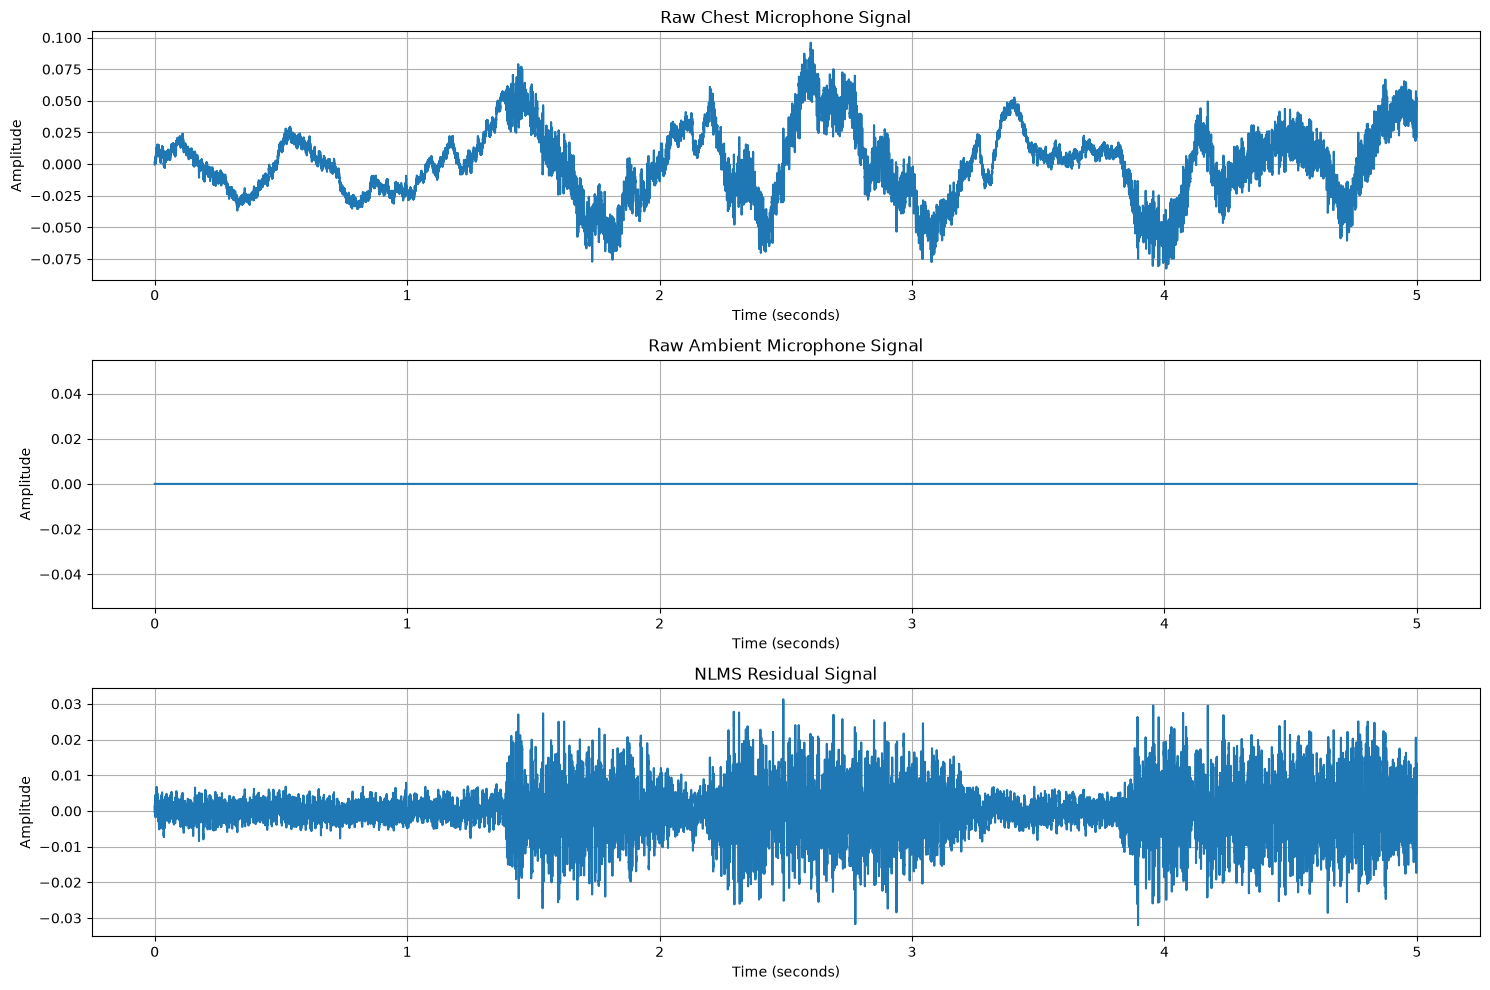

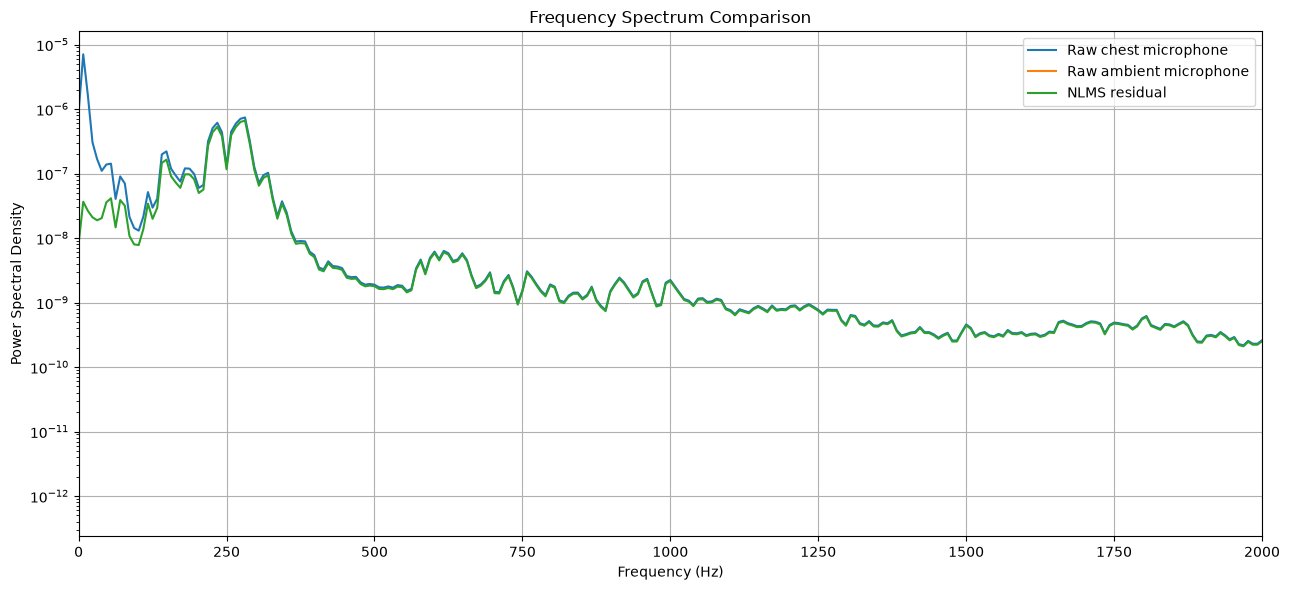


Analysis completed.


In [ ]:
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import welch
from pathlib import Path

# --------------------------------------------------
# 1. FILE PATHS
# --------------------------------------------------

raw_path = Path(
    r"C:\Users\Admin\Desktop\lung_raw_stereo_16k (1).wav"
)

nlms_path = Path(
    r"C:\Users\Admin\Desktop\lung_nlms_residual_16k (1).wav"
)

# Check whether files exist
print("Raw file exists:", raw_path.exists())
print("NLMS file exists:", nlms_path.exists())

# --------------------------------------------------
# 2. LOAD AUDIO
# --------------------------------------------------

raw_audio, raw_sr = sf.read(raw_path)
nlms_audio, nlms_sr = sf.read(nlms_path)

print("\n========== AUDIO INFORMATION ==========")

print("\nRAW AUDIO")
print("Sample rate:", raw_sr)
print("Shape:", raw_audio.shape)
print("Duration:", len(raw_audio) / raw_sr, "seconds")
print("Data type:", raw_audio.dtype)

print("\nNLMS RESIDUAL")
print("Sample rate:", nlms_sr)
print("Shape:", nlms_audio.shape)
print("Duration:", len(nlms_audio) / nlms_sr, "seconds")
print("Data type:", nlms_audio.dtype)

# --------------------------------------------------
# 3. EXTRACT CHANNELS
# --------------------------------------------------

if raw_audio.ndim != 2 or raw_audio.shape[1] != 2:
    raise ValueError("Expected raw audio to contain exactly 2 channels.")

primary = raw_audio[:, 0]    # Chest microphone
ambient = raw_audio[:, 1]    # Ambient microphone

residual = nlms_audio if nlms_audio.ndim == 1 else nlms_audio[:, 0]

# --------------------------------------------------
# 4. AUDIO STATISTICS
# --------------------------------------------------

def calculate_metrics(signal):
    peak = np.max(np.abs(signal))
    rms = np.sqrt(np.mean(signal ** 2))
    clipping = np.mean(np.abs(signal) >= 0.999) * 100

    return peak, rms, clipping


signals = {
    "Raw primary (chest)": primary,
    "Raw ambient": ambient,
    "NLMS residual": residual
}

print("\n========== SIGNAL METRICS ==========")

for name, signal in signals.items():

    peak, rms, clipping = calculate_metrics(signal)

    print(f"\n{name}")
    print(f"Peak amplitude: {peak:.6f}")
    print(f"RMS amplitude: {rms:.6f}")
    print(f"Clipping: {clipping:.4f}%")

# --------------------------------------------------
# 5. PRIMARY-AMBIENT CORRELATION
# --------------------------------------------------

min_length = min(len(primary), len(ambient))

correlation = np.corrcoef(
    primary[:min_length],
    ambient[:min_length]
)[0, 1]

print("\n========== CORRELATION ==========")
print("Primary-Ambient correlation:", round(correlation, 4))

# --------------------------------------------------
# 6. RAW PRIMARY VS NLMS RESIDUAL
# --------------------------------------------------

min_length = min(len(primary), len(residual))

primary_aligned = primary[:min_length]
residual_aligned = residual[:min_length]

primary_rms = np.sqrt(np.mean(primary_aligned ** 2))
residual_rms = np.sqrt(np.mean(residual_aligned ** 2))

if primary_rms > 0:
    rms_ratio = residual_rms / primary_rms
    reduction_db = 20 * np.log10(rms_ratio)
else:
    rms_ratio = np.nan
    reduction_db = np.nan

print("\n========== NLMS COMPARISON ==========")
print("Primary RMS:", round(primary_rms, 6))
print("Residual RMS:", round(residual_rms, 6))
print("Residual / Primary RMS:", round(rms_ratio, 4))
print("RMS change:", round(reduction_db, 2), "dB")

# --------------------------------------------------
# 7. WAVEFORM PLOTS
# --------------------------------------------------

raw_time = np.arange(len(primary)) / raw_sr
residual_time = np.arange(len(residual)) / nlms_sr

plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(raw_time, primary)
plt.title("Raw Chest Microphone Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(raw_time, ambient)
plt.title("Raw Ambient Microphone Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(residual_time, residual)
plt.title("NLMS Residual Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. FREQUENCY SPECTRUM
# --------------------------------------------------

def plot_psd(signal, sample_rate, label):

    frequencies, power = welch(
        signal,
        fs=sample_rate,
        nperseg=min(2048, len(signal))
    )

    plt.semilogy(frequencies, power, label=label)


plt.figure(figsize=(13, 6))

plot_psd(primary, raw_sr, "Raw chest microphone")
plot_psd(ambient, raw_sr, "Raw ambient microphone")
plot_psd(residual, nlms_sr, "NLMS residual")

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.title("Frequency Spectrum Comparison")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. SAVE ANALYSIS PLOTS
# --------------------------------------------------

print("\nAnalysis completed.")

In [ ]:
import tensorflow as tf
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

# Load your best trained CNN-LSTM
model = tf.keras.models.load_model(
    "../models/best_cnn_lstm_patient_weighted.keras"
)

print("Model loaded successfully")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

ValueError: File not found: filepath=../models/best_cnn_lstm_patient_weighted.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
from pathlib import Path

project_folder = Path.cwd().parent

print("Project folder:", project_folder)

print("\nCNN-LSTM model files:")

for file in project_folder.rglob("*.keras"):
    print(file)

Project folder: c:\Users\Admin\Respiratory_TinyML

CNN-LSTM model files:
c:\Users\Admin\Respiratory_TinyML\models\best_compact_logmel_cnn.keras
c:\Users\Admin\Respiratory_TinyML\models\best_fold3_compact_cnn.keras
c:\Users\Admin\Respiratory_TinyML\models\best_logmel_cnn.keras
c:\Users\Admin\Respiratory_TinyML\models\best_resized_logmel_cnn.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_3ch_multilabel.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_3ch_patient_balanced.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_cnn_lstm_device_aligned.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_cnn_lstm_patient_weighted.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_framepad_cnn.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_framepad_combined_boost_cnn.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_framepad_dropout_cnn.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best_framepad_fusion.keras
c:\Users\Admin\Respiratory_TinyML\notebooks\best

In [ ]:
import tensorflow as tf
import numpy as np
import soundfile as sf
import librosa
import matplotlib.pyplot as plt

model = tf.keras.models.load_model(
    "best_cnn_lstm_patient_weighted.keras",
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 64, 157, 3)
Output shape: (None, 2)


In [ ]:
print("Available preprocessing variables:")

for name in [
    "build_features_framepad",
    "build_features",
    "X_train_3ch",
    "X_val_3ch",
    "X_test_3ch",
    "y_train_multi",
    "val_feature_order_df"
]:
    print(name, ":", name in globals())

Available preprocessing variables:
build_features_framepad : True
build_features : True
X_train_3ch : True
X_val_3ch : True
X_test_3ch : False
y_train_multi : True
val_feature_order_df : True


In [ ]:
import inspect

if "build_features_framepad" in globals():
    print(inspect.getsource(build_features_framepad))

def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated interval
        for _, row in group.iterrows():

            # Convert timestamps from seconds to sample indices
            start_idx = int(

In [ ]:
import inspect

print(inspect.getsource(build_features_framepad))

def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated interval
        for _, row in group.iterrows():

            # Convert timestamps from seconds to sample indices
            start_idx = int(

In [ ]:
print("========== FEATURE EXTRACTION FUNCTIONS ==========")

import inspect

for name in [
    "extract_logmel",
    "build_features",
    "fit_logmel_frames",
    "fit_audio_length"
]:
    if name in globals():
        print(f"\n\n========== {name} ==========")
        print(inspect.getsource(globals()[name]))

========== FEATURE EXTRACTION FUNCTIONS ==========


========== extract_logmel ==========
def extract_logmel(segment):

    mel_power = librosa.feature.melspectrogram(
        y=segment,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel_power,
        ref=np.max
    )

    log_mel = np.clip(log_mel, -80.0, 0.0)

    log_mel = (log_mel + 80.0) / 80.0

    return log_mel.astype(np.float32)



========== build_features ==========
def build_features(frame, split_name, noise_snr_db=None, random_seed=42):

    # Create a random-number generator for reproducible noise experiments
    rng = np.random.default_rng(random_seed)

    # Lists to store the features, labels, and segment information
    features = []
    labels = []
    metadata = []

    # Counters for checking preprocessing
    invalid_segments = 0
    cropped_segments = 0

    

In [ ]:
print("Training shape:", X_train_3ch.shape)
print("Validation shape:", X_val_3ch.shape)

print("Min:", X_train_3ch.min())
print("Max:", X_train_3ch.max())
print("Mean:", X_train_3ch.mean())
print("Std:", X_train_3ch.std())

Training shape: (3376, 64, 157, 3)
Validation shape: (649, 64, 157, 3)
Min: -14.989568
Max: 14.765509
Mean: 0.06238306
Std: 0.6150618


In [ ]:
for i, cell in enumerate(In):
    if any(term in cell.lower() for term in [
        "librosa.feature.delta",
        "delta_delta",
        "delta-delta",
        "np.concatenate",
        "np.stack"
    ]):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print(cell[:4000])


CELL 27
def build_features(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42
):
    """
    Build Log-Mel tensors and integer labels from an annotation table.

    noise_snr_db:
        None            = clean/base audio
        A number        = fixed SNR for each segment
        A list of levels = randomly select one SNR per segment
    """

    rng = np.random.default_rng(random_seed)

    features = []
    labels = []
    metadata = []

    skipped_segments = 0
    cropped_segments = 0

    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load and resample the entire recording to 4 kHz.
        audio, _ = librosa.load(
            str(wav_path),
            sr=TARGET_SR,
            mono=True
        )

        for row in group.itertuples(index=False):

            # Convert annotation times in seconds into sample indices.
            start_sample = int(
                np.flo

In [ ]:
for i, cell in enumerate(In):
    if any(term in cell.lower() for term in [
        "librosa.feature.delta",
        "delta_delta",
        "np.concatenate",
        "np.stack",
        "x_train_3ch"
    ]):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print(cell[:5000])


CELL 27
def build_features(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42
):
    """
    Build Log-Mel tensors and integer labels from an annotation table.

    noise_snr_db:
        None            = clean/base audio
        A number        = fixed SNR for each segment
        A list of levels = randomly select one SNR per segment
    """

    rng = np.random.default_rng(random_seed)

    features = []
    labels = []
    metadata = []

    skipped_segments = 0
    cropped_segments = 0

    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load and resample the entire recording to 4 kHz.
        audio, _ = librosa.load(
            str(wav_path),
            sr=TARGET_SR,
            mono=True
        )

        for row in group.itertuples(index=False):

            # Convert annotation times in seconds into sample indices.
            start_sample = int(
                np.flo

In [ ]:
required_variables = [
    "model",
    "TARGET_SR",
    "TARGET_SAMPLES",
    "N_FFT",
    "HOP_LENGTH",
    "N_MELS",
    "FMIN",
    "FMAX",
    "delta_means",
    "delta_stds"
]

for variable in required_variables:
    print(
        f"{variable}:",
        variable in globals()
    )

model: True
TARGET_SR: True
TARGET_SAMPLES: True
N_FFT: True
HOP_LENGTH: True
N_MELS: True
FMIN: True
FMAX: True
delta_means: True
delta_stds: True


In [ ]:
print("MODEL INPUT:", model.input_shape)

for channel in [1, 2]:
    print(f"\nChannel {channel}")
    print("Mean shape:", delta_means[channel].shape)
    print("Std shape:", delta_stds[channel].shape)
    print("Mean range:",
          delta_means[channel].min(),
          delta_means[channel].max())
    print("Std range:",
          delta_stds[channel].min(),
          delta_stds[channel].max())

print("\nFeature constants:")
print("TARGET_SR:", TARGET_SR)
print("TARGET_SAMPLES:", TARGET_SAMPLES)
print("N_FFT:", N_FFT)
print("HOP_LENGTH:", HOP_LENGTH)
print("N_MELS:", N_MELS)
print("FMIN:", FMIN)
print("FMAX:", FMAX)

MODEL INPUT: (None, 64, 157, 3)

Channel 1
Mean shape: (64,)
Std shape: (64,)
Mean range: -0.00049963564 -3.2733549e-06
Std range: 0.010461583 0.014029192

Channel 2
Mean shape: (64,)
Std shape: (64,)
Mean range: -0.00016945864 0.0025542146
Std range: 0.0073307236 0.008822943

Feature constants:
TARGET_SR: 4000
TARGET_SAMPLES: 20000
N_FFT: 512
HOP_LENGTH: 128
N_MELS: 64
FMIN: 20
FMAX: 2000


In [ ]:

import numpy as np
import librosa
import soundfile as sf

def predict_lung_sound(wav_path):

    # 1. Load audio using the model's training sample rate
    audio, sr = sf.read(wav_path, dtype="float32")

    # Convert stereo to mono if necessary
    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    if sr != TARGET_SR:
        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=TARGET_SR
        )

    # 2. Crop or pad to five seconds
    segment = fit_audio_length(audio, TARGET_SAMPLES)

    # 3. Extract Log-Mel features
    log_mel = extract_logmel(segment)

    # 4. Create the valid-frame mask
    actual_frames = log_mel.shape[1]
    frame_mask = np.zeros(157, dtype=bool)

    if actual_frames < 157:
        pad_left = (157 - actual_frames) // 2
        frame_mask[pad_left:pad_left + actual_frames] = True
    else:
        frame_mask[:] = True

    log_mel = fit_logmel_frames(
        log_mel,
        target_frames=157
    )

    # 5. Create the three-channel input
    X = np.zeros((1, 64, 157, 3), dtype=np.float32)

    X[0, :, :, 0] = log_mel

    valid_mel = log_mel[:, frame_mask]

    n_valid_frames = valid_mel.shape[1]

    width = min(
        9,
        n_valid_frames if n_valid_frames % 2 == 1
        else n_valid_frames - 1
    )

    if width < 3:
        raise ValueError("Not enough valid frames")

    delta = librosa.feature.delta(
        valid_mel,
        width=width,
        order=1,
        axis=-1
    )

    delta_delta = librosa.feature.delta(
        valid_mel,
        width=width,
        order=2,
        axis=-1
    )

    X[0, :, :, 1][:, frame_mask] = delta
    X[0, :, :, 2][:, frame_mask] = delta_delta

    # 6. Apply the original training normalization
    for channel in [1, 2]:

        X[0, :, :, channel] -= (
            delta_means[channel][:, None]
        )

        X[0, :, :, channel] /= (
            delta_stds[channel][:, None]
        )

        # Preserve padded frames
        X[0, :, :, channel] *= frame_mask[None, :]

    # 7. Run CNN-LSTM inference
    scores = model.predict(X, verbose=0)[0]

    return {
        "crackle_score": float(scores[0]),
        "wheeze_score": float(scores[1]),
        "input_shape": X.shape
    }


In [ ]:

import numpy as np
import librosa
import soundfile as sf

def predict_lung_sound(wav_path):

    # 1. Load audio using the model's training sample rate
    audio, sr = sf.read(wav_path, dtype="float32")

    # Convert stereo to mono if necessary
    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    if sr != TARGET_SR:
        audio = librosa.resample(
            audio,
            orig_sr=sr,
            target_sr=TARGET_SR
        )

    # 2. Crop or pad to five seconds
    segment = fit_audio_length(audio, TARGET_SAMPLES)

    # 3. Extract Log-Mel features
    log_mel = extract_logmel(segment)

    # 4. Create the valid-frame mask
    actual_frames = log_mel.shape[1]
    frame_mask = np.zeros(157, dtype=bool)

    if actual_frames < 157:
        pad_left = (157 - actual_frames) // 2
        frame_mask[pad_left:pad_left + actual_frames] = True
    else:
        frame_mask[:] = True

    log_mel = fit_logmel_frames(
        log_mel,
        target_frames=157
    )

    # 5. Create the three-channel input
    X = np.zeros((1, 64, 157, 3), dtype=np.float32)

    X[0, :, :, 0] = log_mel

    valid_mel = log_mel[:, frame_mask]

    n_valid_frames = valid_mel.shape[1]

    width = min(
        9,
        n_valid_frames if n_valid_frames % 2 == 1
        else n_valid_frames - 1
    )

    if width < 3:
        raise ValueError("Not enough valid frames")

    delta = librosa.feature.delta(
        valid_mel,
        width=width,
        order=1,
        axis=-1
    )

    delta_delta = librosa.feature.delta(
        valid_mel,
        width=width,
        order=2,
        axis=-1
    )

    X[0, :, :, 1][:, frame_mask] = delta
    X[0, :, :, 2][:, frame_mask] = delta_delta

    # 6. Apply the original training normalization
    for channel in [1, 2]:

        X[0, :, :, channel] -= (
            delta_means[channel][:, None]
        )

        X[0, :, :, channel] /= (
            delta_stds[channel][:, None]
        )

        # Preserve padded frames
        X[0, :, :, channel] *= frame_mask[None, :]

    # 7. Run CNN-LSTM inference
    scores = model.predict(X, verbose=0)[0]

    return {
        "crackle_score": float(scores[0]),
        "wheeze_score": float(scores[1]),
        "input_shape": X.shape
    }


In [ ]:
test_path = candidate_val_df.iloc[0]["wav_path"]

result = predict_lung_sound(test_path)

print("CNN-LSTM OUTPUT")
print("-----------------------")
print("Input shape:", result["input_shape"])
print(
    f"Crackle score: "
    f"{result['crackle_score'] * 100:.2f}%"
)
print(
    f"Wheeze score: "
    f"{result['wheeze_score'] * 100:.2f}%"
)

CNN-LSTM OUTPUT
-----------------------
Input shape: (1, 64, 157, 3)
Crackle score: 17.93%
Wheeze score: 6.09%


In [ ]:
test_idx = 0

test_path = val_feature_order_df.iloc[test_idx]["wav_path"]
test_start = val_feature_order_df.iloc[test_idx]["start"]
test_end = val_feature_order_df.iloc[test_idx]["end"]

print("Recording:", test_path)
print("Start:", test_start)
print("End:", test_end)

Recording: ..\data\raw\108_1b1_Al_sc_Meditron.wav
Start: 0.036
End: 2.907


In [ ]:
import numpy as np
import librosa
import soundfile as sf

def predict_lung_segment(wav_path, start, end):

    # Load audio using the same sample rate and mono setting as training
    audio, sr = librosa.load(
        wav_path,
        sr=TARGET_SR,
        mono=True
    )

    # Extract the exact annotated interval
    start_sample = int(np.floor(start * sr))
    end_sample = int(np.ceil(end * sr))

    segment = audio[start_sample:end_sample]

    if len(segment) == 0:
        raise ValueError("The selected audio segment is empty.")

    # Match training: centre-crop only if the segment is too long.
    # Do not waveform-pad short segments.
    if len(segment) > TARGET_SAMPLES:
        segment = fit_audio_length(segment, TARGET_SAMPLES)

    # Extract Log-Mel features
    log_mel = extract_logmel(segment)

    # Build the valid-frame mask before fitting to 157 frames
    actual_frames = log_mel.shape[1]

    frame_mask = np.zeros(157, dtype=bool)

    if actual_frames < 157:
        pad_left = (157 - actual_frames) // 2
        frame_mask[pad_left:pad_left + actual_frames] = True
    else:
        frame_mask[:] = True

    log_mel = fit_logmel_frames(
        log_mel,
        target_frames=157
    )

    # Construct three-channel input
    X = np.zeros((1, 64, 157, 3), dtype=np.float32)
    X[0, :, :, 0] = log_mel

    valid_mel = log_mel[:, frame_mask]
    n_valid_frames = valid_mel.shape[1]

    width = min(
        9,
        n_valid_frames if n_valid_frames % 2 == 1
        else n_valid_frames - 1
    )

    if width < 3:
        raise ValueError("Not enough valid frames to calculate delta features.")

    # Delta and delta-delta
    delta = librosa.feature.delta(
        valid_mel,
        width=width,
        order=1,
        axis=-1
    )

    delta_delta = librosa.feature.delta(
        valid_mel,
        width=width,
        order=2,
        axis=-1
    )

    X[0, :, :, 1][:, frame_mask] = delta
    X[0, :, :, 2][:, frame_mask] = delta_delta

    # Apply training-set normalization
    for channel in [1, 2]:

        X[0, :, :, channel] -= delta_means[channel][:, None]

        X[0, :, :, channel] /= delta_stds[channel][:, None]

        X[0, :, :, channel] *= frame_mask[None, :]

    # Model prediction
    scores = model.predict(X, verbose=0)[0]

    return {
        "crackle_score": float(scores[0]),
        "wheeze_score": float(scores[1]),
        "input_shape": X.shape,
        "segment_duration": len(segment) / sr,
        "valid_frames": n_valid_frames
    }

In [ ]:
test_idx = 0

test_path = val_feature_order_df.iloc[test_idx]["wav_path"]
test_start = val_feature_order_df.iloc[test_idx]["start"]
test_end = val_feature_order_df.iloc[test_idx]["end"]

result = predict_lung_segment(
    test_path,
    test_start,
    test_end
)

print("CNN-LSTM SEGMENT PREDICTION")
print("---------------------------")
print("Recording:", test_path)
print("Segment:", test_start, "to", test_end)
print("Duration:", result["segment_duration"])
print("Valid frames:", result["valid_frames"])
print("Input shape:", result["input_shape"])
print("Crackle score: {:.2f}%".format(result["crackle_score"] * 100))
print("Wheeze score: {:.2f}%".format(result["wheeze_score"] * 100))

CNN-LSTM SEGMENT PREDICTION
---------------------------
Recording: ..\data\raw\108_1b1_Al_sc_Meditron.wav
Segment: 0.036 to 2.907
Duration: 2.871
Valid frames: 90
Input shape: (1, 64, 157, 3)
Crackle score: 18.92%
Wheeze score: 9.69%


In [ ]:
print(
    val_feature_order_df.iloc[0][
        ["crackle", "wheeze", "label"]
    ]
)

crackle         0
wheeze          0
label      normal
Name: 0, dtype: object


In [ ]:
# Predict all validation samples
val_predictions = model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

print("Validation predictions shape:", val_predictions.shape)
print("Ground truth shape:", y_val_multi.shape)

print("\nFirst 5 predictions:")
print(val_predictions[:5])

print("\nFirst 5 ground-truth labels:")
print(y_val_multi[:5])

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step
Validation predictions shape: (649, 2)
Ground truth shape: (649, 2)

First 5 predictions:
[[0.18915655 0.09691387]
 [0.44385013 0.35594788]
 [0.17135404 0.07980172]
 [0.2568379  0.10267323]
 [0.17149198 0.07956234]]

First 5 ground-truth labels:
[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [ ]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve
)

event_names = ["Crackle", "Wheeze"]
example_thresholds = [0.45, 0.60]

for i, event in enumerate(event_names):

    y_true = y_val_multi[:, i].astype(int)
    y_score = val_predictions[:, i]

    print("\n" + "=" * 50)
    print(event.upper())
    print("=" * 50)

    # Overall ranking performance
    print("Positive samples:", np.sum(y_true == 1))
    print("Negative samples:", np.sum(y_true == 0))
    print("ROC-AUC:", round(roc_auc_score(y_true, y_score), 4))
    print("Average Precision:", round(
        average_precision_score(y_true, y_score), 4
    ))

    # Performance at the example threshold
    threshold = example_thresholds[i]
    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    print("\nAt threshold:", threshold)
    print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
    print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
    print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))
    print("Specificity:", round(specificity, 4))
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print([[tn, fp], [fn, tp]])

    # Find the validation threshold that maximizes F1
    precisions, recalls, thresholds = precision_recall_curve(
        y_true, y_score
    )

    f1_values = (
        2 * precisions[:-1] * recalls[:-1]
        / (precisions[:-1] + recalls[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_values)
    best_threshold = thresholds[best_idx]

    print("\nBest validation F1 threshold:", round(best_threshold, 4))
    print("Best validation F1:", round(f1_values[best_idx], 4))
    print("Precision at best F1:", round(precisions[best_idx], 4))
    print("Recall at best F1:", round(recalls[best_idx], 4))


CRACKLE
Positive samples: 209
Negative samples: 440
ROC-AUC: 0.5517
Average Precision: 0.3547

At threshold: 0.45
Precision: 0.4114
Recall: 0.311
F1-score: 0.3542
Specificity: 0.7886
Confusion matrix [[TN, FP], [FN, TP]]:
[[np.int64(347), np.int64(93)], [np.int64(144), np.int64(65)]]

Best validation F1 threshold: 0.1582
Best validation F1: 0.4889
Precision at best F1: 0.3235
Recall at best F1: 1.0

WHEEZE
Positive samples: 116
Negative samples: 533
ROC-AUC: 0.8497
Average Precision: 0.7636

At threshold: 0.6
Precision: 0.6444
Recall: 0.75
F1-score: 0.6932
Specificity: 0.9099
Confusion matrix [[TN, FP], [FN, TP]]:
[[np.int64(485), np.int64(48)], [np.int64(29), np.int64(87)]]

Best validation F1 threshold: 0.6679
Best validation F1: 0.7
Precision at best F1: 0.6774
Recall at best F1: 0.7241


In [ ]:
import pandas as pd
import numpy as np

for i, event in enumerate(["Crackle", "Wheeze"]):

    scores = val_predictions[:, i]
    labels = y_val_multi[:, i].astype(int)

    print("\n", "=" * 45)
    print(event.upper())
    print("=" * 45)

    for label, name in [(0, "Negative"), (1, "Positive")]:

        class_scores = scores[labels == label]

        print(f"\n{name} samples: {len(class_scores)}")
        print("Mean:", round(np.mean(class_scores), 4))
        print("Median:", round(np.median(class_scores), 4))
        print("25th percentile:", round(np.percentile(class_scores, 25), 4))
        print("75th percentile:", round(np.percentile(class_scores, 75), 4))
        print("90th percentile:", round(np.percentile(class_scores, 90), 4))


CRACKLE

Negative samples: 440
Mean: 0.3531
Median: 0.3533
25th percentile: 0.2391
75th percentile: 0.4373
90th percentile: 0.5275

Positive samples: 209
Mean: 0.3733
Median: 0.3812
25th percentile: 0.2608
75th percentile: 0.4763
90th percentile: 0.5339

WHEEZE

Negative samples: 533
Mean: 0.2827
Median: 0.2284
25th percentile: 0.1393
75th percentile: 0.3498
90th percentile: 0.546

Positive samples: 116
Mean: 0.7482
Median: 0.9409
25th percentile: 0.6008
75th percentile: 0.9789
90th percentile: 0.9814


In [ ]:
def reconstruct_segment_features(wav_path, start, end):

    # Same loading procedure as training
    audio, sr = librosa.load(
        wav_path,
        sr=TARGET_SR,
        mono=True
    )

    # Exact annotated segment
    start_sample = int(np.floor(start * sr))
    end_sample = int(np.ceil(end * sr))

    segment = audio[start_sample:end_sample]

    if len(segment) == 0:
        raise ValueError("Empty audio segment")

    # Match training: crop only if longer than target length
    if len(segment) > TARGET_SAMPLES:
        segment = fit_audio_length(segment, TARGET_SAMPLES)

    # Log-Mel extraction
    log_mel = extract_logmel(segment)

    actual_frames = log_mel.shape[1]

    # Reconstruct the original frame mask
    frame_mask = np.zeros(157, dtype=bool)

    if actual_frames < 157:
        pad_left = (157 - actual_frames) // 2
        frame_mask[pad_left:pad_left + actual_frames] = True
    else:
        frame_mask[:] = True

    log_mel = fit_logmel_frames(
        log_mel,
        target_frames=157
    )

    # Three-channel feature tensor
    X = np.zeros((64, 157, 3), dtype=np.float32)
    X[:, :, 0] = log_mel

    valid_mel = log_mel[:, frame_mask]
    n_valid = valid_mel.shape[1]

    width = min(
        9,
        n_valid if n_valid % 2 == 1 else n_valid - 1
    )

    if width < 3:
        raise ValueError("Insufficient frames for delta calculation")

    delta = librosa.feature.delta(
        valid_mel, width=width, order=1, axis=-1
    )

    delta_delta = librosa.feature.delta(
        valid_mel, width=width, order=2, axis=-1
    )

    X[:, :, 1][:, frame_mask] = delta
    X[:, :, 2][:, frame_mask] = delta_delta

    # Apply the training-set normalization
    for channel in [1, 2]:

        X[:, :, channel] -= delta_means[channel][:, None]
        X[:, :, channel] /= delta_stds[channel][:, None]
        X[:, :, channel] *= frame_mask[None, :]

    return X

In [ ]:
test_idx = 0

row = val_feature_order_df.iloc[test_idx]

X_reconstructed = reconstruct_segment_features(
    row["wav_path"],
    row["start"],
    row["end"]
)

X_original = X_val_3ch[test_idx]

print("ORIGINAL SHAPE:", X_original.shape)
print("RECONSTRUCTED SHAPE:", X_reconstructed.shape)

difference = np.abs(X_original - X_reconstructed)

print("\nOVERALL FEATURE COMPARISON")
print("Maximum absolute difference:", difference.max())
print("Mean absolute difference:", difference.mean())
print("RMSE:", np.sqrt(np.mean((X_original - X_reconstructed) ** 2)))

print("\nCHANNEL-WISE COMPARISON")

for channel, name in enumerate([
    "Log-Mel",
    "Delta",
    "Delta-Delta"
]):

    channel_diff = difference[:, :, channel]

    print(f"\n{name}:")
    print("Maximum difference:", channel_diff.max())
    print("Mean difference:", channel_diff.mean())

print("\nNearly identical:", np.allclose(
    X_original,
    X_reconstructed,
    rtol=1e-5,
    atol=1e-6
))

ORIGINAL SHAPE: (64, 157, 3)
RECONSTRUCTED SHAPE: (64, 157, 3)

OVERALL FEATURE COMPARISON
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
RMSE: 0.0

CHANNEL-WISE COMPARISON

Log-Mel:
Maximum difference: 0.0
Mean difference: 0.0

Delta:
Maximum difference: 0.0
Mean difference: 0.0

Delta-Delta:
Maximum difference: 0.0
Mean difference: 0.0

Nearly identical: True


In [ ]:
wheeze_only = val_feature_order_df[
    (val_feature_order_df["crackle"] == 0) &
    (val_feature_order_df["wheeze"] == 1)
]

print("Wheeze-only validation samples:", len(wheeze_only))

wheeze_only[[
    "wav_path",
    "start",
    "end",
    "crackle",
    "wheeze",
    "label"
]].head(10)

Wheeze-only validation samples: 81


,wav_path,start,end,crackle,wheeze,label
30,..\data\raw\110_1p1_Ll_sc_Meditron.wav,3.6457,7.601,0,1,wheeze
31,..\data\raw\110_1p1_Ll_sc_Meditron.wav,7.6010,11.667,0,1,wheeze
34,..\data\raw\110_1p1_Ll_sc_Meditron.wav,19.6780,23.855,0,1,wheeze
67,..\data\raw\161_1b1_Al_sc_Meditron.wav,4.8210,6.921,0,1,wheeze
68,..\data\raw\161_1b1_Al_sc_Meditron.wav,6.9210,8.907,0,1,wheeze
77,..\data\raw\161_1b1_Pl_sc_Meditron.wav,5.3640,7.764,0,1,wheeze
78,..\data\raw\161_1b1_Pl_sc_Meditron.wav,7.7640,9.893,0,1,wheeze
79,..\data\raw\161_1b1_Pl_sc_Meditron.wav,9.8930,11.836,0,1,wheeze
80,..\data\raw\161_1b1_Pl_sc_Meditron.wav,11.8360,14.079,0,1,wheeze
81,..\data\raw\161_1b1_Pl_sc_Meditron.wav,14.0790,16.107,0,1,wheeze


In [ ]:
test_idx = 30

row = val_feature_order_df.loc[test_idx]

result = predict_lung_segment(
    row["wav_path"],
    row["start"],
    row["end"]
)

print("GROUND TRUTH")
print("Crackle:", row["crackle"])
print("Wheeze:", row["wheeze"])
print("Label:", row["label"])

print("\nLIVE INFERENCE OUTPUT")
print("Crackle score: {:.2f}%".format(
    result["crackle_score"] * 100
))
print("Wheeze score: {:.2f}%".format(
    result["wheeze_score"] * 100
))

GROUND TRUTH
Crackle: 0
Wheeze: 1
Label: wheeze

LIVE INFERENCE OUTPUT
Crackle score: 45.96%
Wheeze score: 97.05%


In [ ]:
saved_prediction = model.predict(
    X_val_3ch[[30]],
    verbose=0
)[0]

live_prediction = np.array([
    result["crackle_score"],
    result["wheeze_score"]
])

print("Saved-feature prediction:", saved_prediction)
print("WAV inference prediction:", live_prediction)

print("\nAbsolute difference:")
print(np.abs(saved_prediction - live_prediction))

print("\nIdentical within tolerance:",
      np.allclose(
          saved_prediction,
          live_prediction,
          rtol=1e-5,
          atol=1e-6
      ))

Saved-feature prediction: [0.45960802 0.97046626]
WAV inference prediction: [0.45960802 0.97046626]

Absolute difference:
[0. 0.]

Identical within tolerance: True


In [ ]:
# Get indices of all wheeze-only validation samples
wheeze_indices = np.where(
    (y_val_multi[:, 0] == 0) &
    (y_val_multi[:, 1] == 1)
)[0]

# Predict using saved validation features
wheeze_predictions = model.predict(
    X_val_3ch[wheeze_indices],
    batch_size=32,
    verbose=0
)

# Apply current example thresholds
CRACKLE_THRESHOLD = 0.45
WHEEZE_THRESHOLD = 0.60

crackle_detected = (
    wheeze_predictions[:, 0] >= CRACKLE_THRESHOLD
)

wheeze_detected = (
    wheeze_predictions[:, 1] >= WHEEZE_THRESHOLD
)

# Classification counts
correct_wheeze_only = np.sum(
    (~crackle_detected) & wheeze_detected
)

both_detected = np.sum(
    crackle_detected & wheeze_detected
)

wheeze_missed = np.sum(
    (~wheeze_detected)
)

print("WHEEZE-ONLY EVALUATION")
print("======================")
print("Total samples:", len(wheeze_indices))

print("\nWheeze detection:")
print("Detected:", np.sum(wheeze_detected))
print("Missed:", wheeze_missed)
print("Recall:", round(np.mean(wheeze_detected), 4))

print("\nCrackle false positives:")
print("Incorrectly detected:", np.sum(crackle_detected))
print("False-positive rate:", round(np.mean(crackle_detected), 4))

print("\nFour-class outcomes:")
print("Correctly classified as wheeze only:", correct_wheeze_only)
print("Incorrectly classified as both:", both_detected)
print("Wheeze missed:", wheeze_missed)

print("\nMean crackle score:",
      round(np.mean(wheeze_predictions[:, 0]), 4))

print("Mean wheeze score:",
      round(np.mean(wheeze_predictions[:, 1]), 4))

WHEEZE-ONLY EVALUATION
Total samples: 81

Wheeze detection:
Detected: 59
Missed: 22
Recall: 0.7284

Crackle false positives:
Incorrectly detected: 8
False-positive rate: 0.0988

Four-class outcomes:
Correctly classified as wheeze only: 53
Incorrectly classified as both: 6
Wheeze missed: 22

Mean crackle score: 0.3816
Mean wheeze score: 0.7463


In [ ]:
# Identify missed wheeze samples
missed_mask = ~wheeze_detected

missed_indices = wheeze_indices[missed_mask]

missed_df = val_feature_order_df.loc[
    missed_indices,
    ["wav_path", "start", "end", "crackle", "wheeze", "label"]
].copy()

missed_df["crackle_score"] = wheeze_predictions[missed_mask, 0]
missed_df["wheeze_score"] = wheeze_predictions[missed_mask, 1]

missed_df = missed_df.sort_values("wheeze_score")

print("MISSED WHEEZE SAMPLES:", len(missed_df))

display(missed_df)

MISSED WHEEZE SAMPLES: 22


,wav_path,start,end,crackle,wheeze,label,crackle_score,wheeze_score
67,..\data\raw\161_1b1_Al_sc_Meditron.wav,4.8210,6.921,0,1,wheeze,0.177444,0.072965
82,..\data\raw\161_1b1_Pl_sc_Meditron.wav,16.1070,18.236,0,1,wheeze,0.182939,0.088634
68,..\data\raw\161_1b1_Al_sc_Meditron.wav,6.9210,8.907,0,1,wheeze,0.183900,0.088848
413,..\data\raw\192_2b2_Ar_mc_LittC2SE.wav,11.2790,14.064,0,1,wheeze,0.300259,0.098040
83,..\data\raw\161_1b1_Pl_sc_Meditron.wav,18.2360,19.936,0,1,wheeze,0.167100,0.106904
78,..\data\raw\161_1b1_Pl_sc_Meditron.wav,7.7640,9.893,0,1,wheeze,0.236300,0.126439
81,..\data\raw\161_1b1_Pl_sc_Meditron.wav,14.0790,16.107,0,1,wheeze,0.216626,0.132932
221,..\data\raw\179_1b1_Tc_sc_Meditron.wav,8.1930,10.250,0,1,wheeze,0.206117,0.144128
408,..\data\raw\192_2b2_Al_mc_LittC2SE.wav,19.6500,19.964,0,1,wheeze,0.239161,0.146703
188,..\data\raw\166_1p1_Pr_sc_Meditron.wav,8.4073,10.398,0,1,wheeze,0.190659,0.153203


In [ ]:
print("MISSED WHEEZE SCORE DISTRIBUTION")
print("Minimum:", missed_df["wheeze_score"].min())
print("Maximum:", missed_df["wheeze_score"].max())
print("Mean:", missed_df["wheeze_score"].mean())
print("Median:", missed_df["wheeze_score"].median())

MISSED WHEEZE SCORE DISTRIBUTION
Minimum: 0.072964825
Maximum: 0.4284233
Mean: 0.21496019
Median: 0.1649588


In [ ]:
# Prepare all wheeze-only validation predictions
wheeze_analysis = val_feature_order_df.loc[
    wheeze_indices,
    ["wav_path", "start", "end", "crackle", "wheeze"]
].copy()

wheeze_analysis["crackle_score"] = wheeze_predictions[:, 0]
wheeze_analysis["wheeze_score"] = wheeze_predictions[:, 1]

wheeze_analysis["patient"] = (
    wheeze_analysis["wav_path"]
    .str.extract(r"(\d+)_")[0]
)

wheeze_analysis["wheeze_detected"] = (
    wheeze_analysis["wheeze_score"] >= 0.60
)

patient_summary = (
    wheeze_analysis
    .groupby("patient")
    .agg(
        total_samples=("wheeze", "size"),
        detected=("wheeze_detected", "sum"),
        mean_wheeze_score=("wheeze_score", "mean"),
        min_wheeze_score=("wheeze_score", "min"),
        max_wheeze_score=("wheeze_score", "max")
    )
)

patient_summary["recall"] = (
    patient_summary["detected"] /
    patient_summary["total_samples"]
)

display(patient_summary.sort_values("recall"))

,total_samples,detected,mean_wheeze_score,min_wheeze_score,max_wheeze_score,recall
patient,,,,,,
161,9,0,0.126115,0.072965,0.188395,0.000000
179,1,0,0.144128,0.144128,0.144128,0.000000
166,3,1,0.373429,0.153203,0.770378,0.333333
186,2,1,0.628442,0.419086,0.837798,0.500000
164,3,2,0.705927,0.259284,0.971778,0.666667
192,38,30,0.816581,0.098040,0.983325,0.789474
110,3,3,0.957162,0.924020,0.977001,1.000000
180,1,1,0.611801,0.611801,0.611801,1.000000
206,21,21,0.960119,0.674898,0.983759,1.000000


In [ ]:
# Create analysis dataframe for all 81 wheeze-only samples

wheeze_analysis = val_feature_order_df.loc[
    wheeze_indices,
    ["wav_path", "start", "end", "crackle", "wheeze"]
].copy()

wheeze_analysis["crackle_score"] = wheeze_predictions[:, 0]
wheeze_analysis["wheeze_score"] = wheeze_predictions[:, 1]

wheeze_analysis["patient"] = (
    wheeze_analysis["wav_path"]
    .str.extract(r"(\d+)_")[0]
)

wheeze_analysis["wheeze_detected"] = (
    wheeze_analysis["wheeze_score"] >= 0.60
)

patient_summary = (
    wheeze_analysis
    .groupby("patient")
    .agg(
        total_samples=("wheeze", "size"),
        detected=("wheeze_detected", "sum"),
        mean_wheeze_score=("wheeze_score", "mean"),
        min_wheeze_score=("wheeze_score", "min"),
        max_wheeze_score=("wheeze_score", "max")
    )
)

patient_summary["recall"] = (
    patient_summary["detected"] /
    patient_summary["total_samples"]
)

display(patient_summary.sort_values("recall"))

,total_samples,detected,mean_wheeze_score,min_wheeze_score,max_wheeze_score,recall
patient,,,,,,
161,9,0,0.126115,0.072965,0.188395,0.000000
179,1,0,0.144128,0.144128,0.144128,0.000000
166,3,1,0.373429,0.153203,0.770378,0.333333
186,2,1,0.628442,0.419086,0.837798,0.500000
164,3,2,0.705927,0.259284,0.971778,0.666667
192,38,30,0.816581,0.098040,0.983325,0.789474
110,3,3,0.957162,0.924020,0.977001,1.000000
180,1,1,0.611801,0.611801,0.611801,1.000000
206,21,21,0.960119,0.674898,0.983759,1.000000


In [ ]:
# Inspect missed and correctly detected wheeze-only segments
# Focus on patients 161 and 192

problem_patients = ["161", "192"]

inspection_df = wheeze_analysis[
    wheeze_analysis["patient"].isin(problem_patients)
].copy()

inspection_df["result"] = np.where(
    inspection_df["wheeze_detected"],
    "Detected",
    "Missed"
)

display(
    inspection_df[
        [
            "patient",
            "wav_path",
            "start",
            "end",
            "wheeze_score",
            "result"
        ]
    ].sort_values(["patient", "wav_path", "start"])
)

,patient,wav_path,start,end,wheeze_score,result
67,161,..\data\raw\161_1b1_Al_sc_Meditron.wav,4.821,6.921,0.072965,Missed
68,161,..\data\raw\161_1b1_Al_sc_Meditron.wav,6.921,8.907,0.088848,Missed
77,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,5.364,7.764,0.188395,Missed
78,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,7.764,9.893,0.126439,Missed
79,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,9.893,11.836,0.167990,Missed
80,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,11.836,14.079,0.161927,Missed
81,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,14.079,16.107,0.132932,Missed
82,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,16.107,18.236,0.088634,Missed
83,161,..\data\raw\161_1b1_Pl_sc_Meditron.wav,18.236,19.936,0.106904,Missed
386,192,..\data\raw\192_2b1_Al_mc_LittC2SE.wav,1.007,3.707,0.983325,Detected


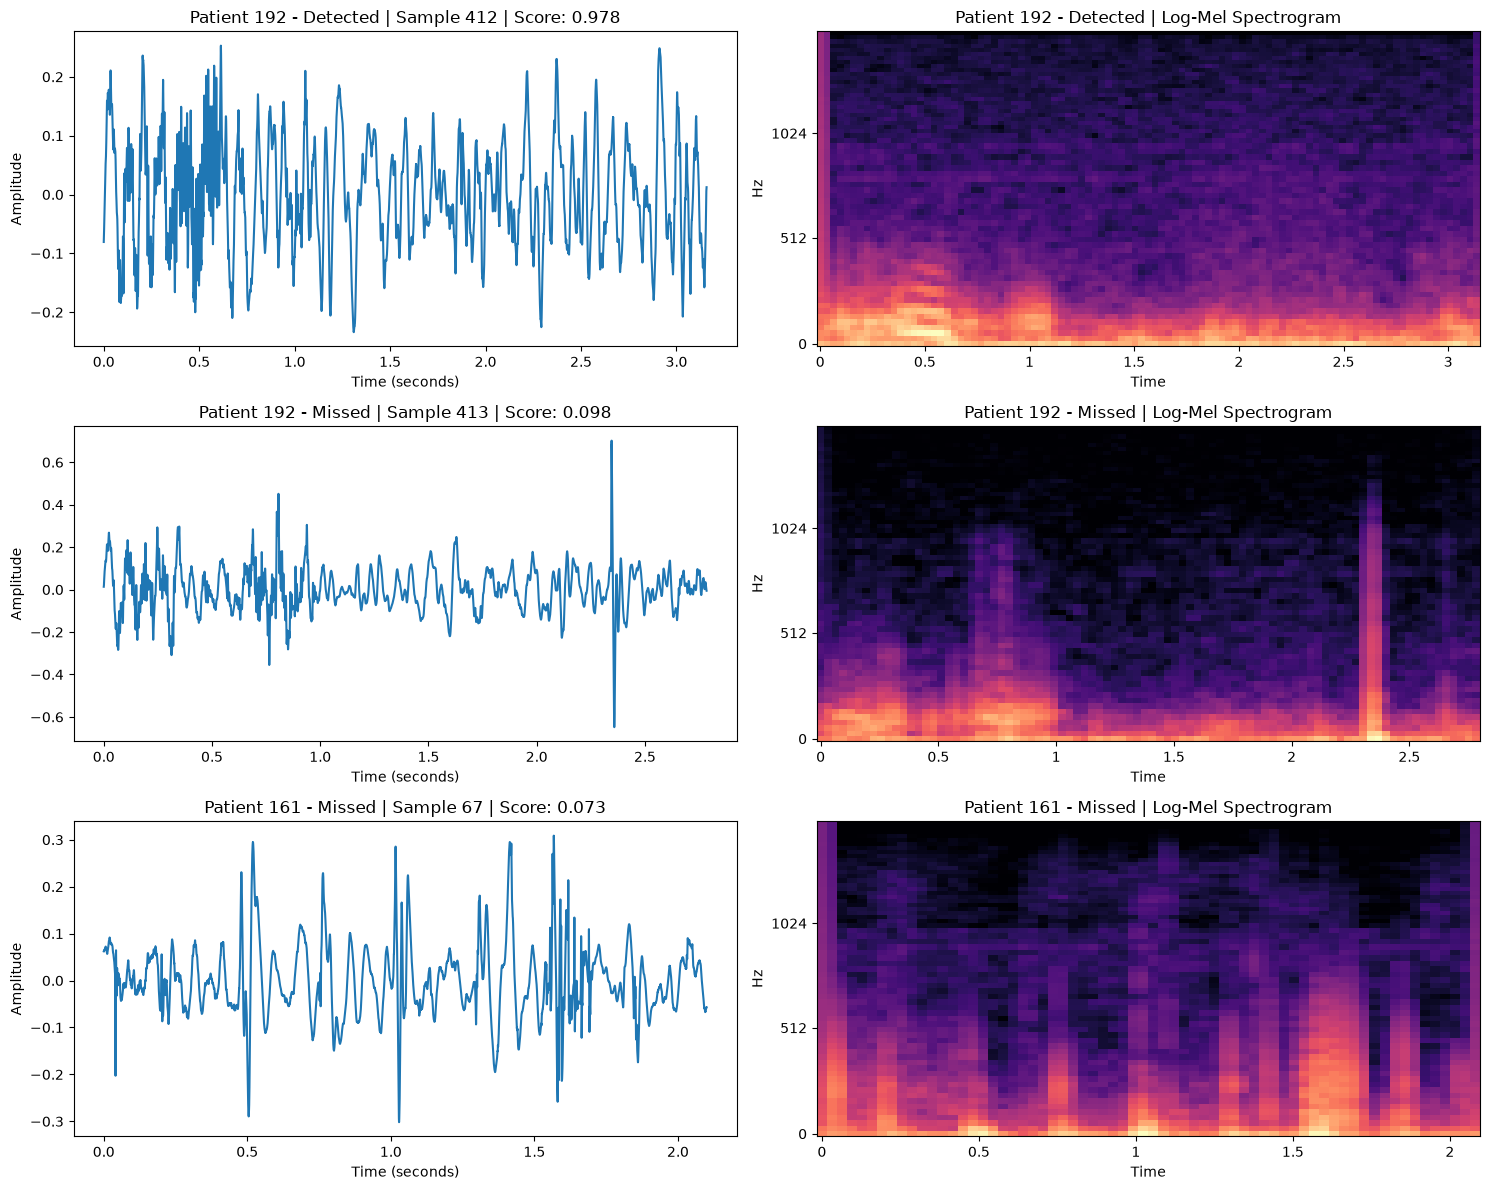

In [ ]:
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np

samples_to_inspect = [
    (412, "Patient 192 - Detected"),
    (413, "Patient 192 - Missed"),
    (67, "Patient 161 - Missed")
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for row, (idx, title) in enumerate(samples_to_inspect):

    metadata = val_feature_order_df.iloc[idx]

    wav_path = metadata["wav_path"]
    start = float(metadata["start"])
    end = float(metadata["end"])

    audio, sr = librosa.load(
        wav_path,
        sr=4000,
        mono=True
    )

    segment = audio[
        int(np.floor(start * sr)):
        int(np.ceil(end * sr))
    ]

    score = val_predictions[idx, 1]

    # Waveform
    time_axis = np.arange(len(segment)) / sr

    axes[row, 0].plot(time_axis, segment)
    axes[row, 0].set_title(
        f"{title} | Sample {idx} | Score: {score:.3f}"
    )
    axes[row, 0].set_xlabel("Time (seconds)")
    axes[row, 0].set_ylabel("Amplitude")

    # Log-Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=segment,
        sr=sr,
        n_fft=512,
        hop_length=128,
        n_mels=64,
        fmin=20,
        fmax=2000,
        power=2.0
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    librosa.display.specshow(
        log_mel,
        sr=sr,
        hop_length=128,
        x_axis="time",
        y_axis="mel",
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(
        f"{title} | Log-Mel Spectrogram"
    )

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import librosa
import pandas as pd

samples_to_inspect = [
    (412, "Patient 192 - Detected"),
    (413, "Patient 192 - Missed"),
    (67, "Patient 161 - Missed")
]

records = []

for idx, title in samples_to_inspect:

    metadata = val_feature_order_df.iloc[idx]

    audio, sr = librosa.load(
        metadata["wav_path"],
        sr=4000,
        mono=True
    )

    start = float(metadata["start"])
    end = float(metadata["end"])

    segment = audio[
        int(np.floor(start * sr)):
        int(np.ceil(end * sr))
    ]

    rms = np.sqrt(np.mean(segment ** 2))
    peak = np.max(np.abs(segment))

    zcr = np.mean(
        librosa.feature.zero_crossing_rate(segment)
    )

    centroid = np.mean(
        librosa.feature.spectral_centroid(
            y=segment, sr=sr
        )
    )

    bandwidth = np.mean(
        librosa.feature.spectral_bandwidth(
            y=segment, sr=sr
        )
    )

    records.append({
        "sample": idx,
        "description": title,
        "duration": len(segment) / sr,
        "wheeze_score": val_predictions[idx, 1],
        "RMS": rms,
        "Peak": peak,
        "Zero_crossing_rate": zcr,
        "Spectral_centroid": centroid,
        "Spectral_bandwidth": bandwidth
    })

comparison_df = pd.DataFrame(records)

display(comparison_df.round(4))

,sample,description,duration,wheeze_score,RMS,Peak,Zero_crossing_rate,Spectral_centroid,Spectral_bandwidth
0,412,Patient 192 - Detected,3.158,0.9778,0.0914,0.2530,0.0121,65.2076,146.9579
1,413,Patient 192 - Missed,2.785,0.0980,0.1043,0.7018,0.0152,70.9840,138.8130
2,67,Patient 161 - Missed,2.100,0.0730,0.0789,0.3087,0.0116,108.9436,189.2363


In [ ]:
import numpy as np
import librosa
import pandas as pd

samples_to_inspect = [
    (412, "Patient 192 - Detected"),
    (413, "Patient 192 - Missed"),
    (67, "Patient 161 - Missed")
]

records = []

for idx, description in samples_to_inspect:

    metadata = val_feature_order_df.iloc[idx]

    audio, sr = librosa.load(
        metadata["wav_path"],
        sr=4000,
        mono=True
    )

    start = float(metadata["start"])
    end = float(metadata["end"])

    segment = audio[
        int(np.floor(start * sr)):
        int(np.ceil(end * sr))
    ]

    # Power spectrogram
    S = np.abs(
        librosa.stft(
            segment,
            n_fft=512,
            hop_length=128
        )
    ) ** 2

    frequencies = librosa.fft_frequencies(
        sr=sr,
        n_fft=512
    )

    total_energy = np.sum(S) + 1e-10

    # Relative energy in frequency bands
    bands = {
        "energy_20_200": (20, 200),
        "energy_200_500": (200, 500),
        "energy_500_1000": (500, 1000),
        "energy_1000_2000": (1000, 2000)
    }

    row = {
        "sample": idx,
        "description": description,
        "wheeze_score": val_predictions[idx, 1]
    }

    for name, (low, high) in bands.items():
        band_energy = np.sum(
            S[(frequencies >= low) & (frequencies < high), :]
        )
        row[name] = band_energy / total_energy

    # Average spectral flatness
    flatness = librosa.feature.spectral_flatness(
        S=np.abs(S)
    )

    row["spectral_flatness"] = np.mean(flatness)

    records.append(row)

frequency_comparison = pd.DataFrame(records)

display(frequency_comparison.round(4))

,sample,description,wheeze_score,energy_20_200,energy_200_500,energy_500_1000,energy_1000_2000,spectral_flatness
0,412,Patient 192 - Detected,0.9778,0.2151,0.0015,0.0000,0.0,0.0
1,413,Patient 192 - Missed,0.0980,0.3411,0.0025,0.0001,0.0,0.0
2,67,Patient 161 - Missed,0.0730,0.3809,0.0104,0.0002,0.0,0.0


In [ ]:
import numpy as np
import librosa
import pandas as pd

samples = [412, 413, 67]
results = []

for idx in samples:

    metadata = val_feature_order_df.iloc[idx]

    audio, sr = librosa.load(
        metadata["wav_path"],
        sr=4000,
        mono=True
    )

    start = float(metadata["start"])
    end = float(metadata["end"])

    segment = audio[
        int(np.floor(start * sr)):
        int(np.ceil(end * sr))
    ]

    S = np.abs(
        librosa.stft(
            segment,
            n_fft=512,
            hop_length=128
        )
    ) ** 2

    frequencies = librosa.fft_frequencies(
        sr=sr,
        n_fft=512
    )

    mean_power = np.mean(S, axis=1)

    peak_frequency = frequencies[
        np.argmax(mean_power)
    ]

    total_power = np.sum(mean_power) + 1e-12

    # Frequency containing 90% of cumulative spectral energy
    cumulative = np.cumsum(mean_power) / total_power
    freq_90 = frequencies[
        np.searchsorted(cumulative, 0.90)
    ]

    results.append({
        "sample": idx,
        "peak_frequency": peak_frequency,
        "frequency_90_percent_energy": freq_90,
        "mean_power": np.mean(mean_power),
        "max_power": np.max(mean_power)
    })

display(pd.DataFrame(results).round(3))

,sample,peak_frequency,frequency_90_percent_energy,mean_power,max_power
0,412,7.812,31.250,1.747,147.065002
1,413,7.812,46.875,2.192,158.723999
2,67,15.625,46.875,1.237,89.114998


In [ ]:
import numpy as np
import pandas as pd

CRACKLE_THRESHOLD = 0.45
WHEEZE_THRESHOLD = 0.60

# Ground truth: all these samples have wheeze=1 and crackle=0
crackle_scores = wheeze_predictions[:, 0]
wheeze_scores = wheeze_predictions[:, 1]

crackle_fp = crackle_scores >= CRACKLE_THRESHOLD
wheeze_detected = wheeze_scores >= WHEEZE_THRESHOLD

print("Total wheeze-only samples:", len(wheeze_indices))
print("Crackle false positives:", crackle_fp.sum())
print("Crackle false-positive rate:", round(crackle_fp.mean(), 4))

print("\nCombined prediction breakdown:")
print("Wheeze only:", np.sum(~crackle_fp & wheeze_detected))
print("Both:", np.sum(crackle_fp & wheeze_detected))
print("Crackle only:", np.sum(crackle_fp & ~wheeze_detected))
print("Neither:", np.sum(~crackle_fp & ~wheeze_detected))

# Identify samples incorrectly assigned crackle
fp_indices = wheeze_indices[crackle_fp]

fp_df = val_feature_order_df.iloc[fp_indices][
    ["wav_path", "start", "end", "label", "crackle", "wheeze"]
].copy()

fp_df["crackle_score"] = crackle_scores[crackle_fp]
fp_df["wheeze_score"] = wheeze_scores[crackle_fp]

fp_df["patient"] = (
    fp_df["wav_path"].str.extract(r"(\d+)_")[0]
)

display(
    fp_df.sort_values("crackle_score", ascending=False)
)

Total wheeze-only samples: 81
Crackle false positives: 8
Crackle false-positive rate: 0.0988

Combined prediction breakdown:
Wheeze only: 53
Both: 6
Crackle only: 2
Neither: 20


,wav_path,start,end,label,crackle,wheeze,crackle_score,wheeze_score,patient
426,..\data\raw\192_2b3_Ar_mc_LittC2SE.wav,5.6500,8.907,wheeze,0,1,0.607912,0.414728,192
313,..\data\raw\186_2b3_Tc_mc_AKGC417L.wav,16.6490,18.208,wheeze,0,1,0.579721,0.419086,186
31,..\data\raw\110_1p1_Ll_sc_Meditron.wav,7.6010,11.667,wheeze,0,1,0.472839,0.977001,110
34,..\data\raw\110_1p1_Ll_sc_Meditron.wav,19.6780,23.855,wheeze,0,1,0.463282,0.924020,110
254,..\data\raw\186_2b2_Al_mc_AKGC417L.wav,1.3510,5.292,wheeze,0,1,0.459749,0.837798,186
30,..\data\raw\110_1p1_Ll_sc_Meditron.wav,3.6457,7.601,wheeze,0,1,0.459608,0.970466,110
397,..\data\raw\192_2b1_Ar_mc_LittC2SE.wav,9.3790,12.536,wheeze,0,1,0.454009,0.751219,192
473,..\data\raw\206_1b1_Pl_sc_Meditron.wav,12.3640,15.264,wheeze,0,1,0.453113,0.972871,206


In [ ]:
import numpy as np
import pandas as pd

# Use predictions for the complete validation set
assert val_predictions.shape == y_val_multi.shape

labels = {
    "Normal": (y_val_multi[:, 0] == 0) & (y_val_multi[:, 1] == 0),
    "Crackle only": (y_val_multi[:, 0] == 1) & (y_val_multi[:, 1] == 0),
    "Wheeze only": (y_val_multi[:, 0] == 0) & (y_val_multi[:, 1] == 1),
    "Both": (y_val_multi[:, 0] == 1) & (y_val_multi[:, 1] == 1)
}

records = []

for class_name, mask in labels.items():

    scores = val_predictions[mask, 0]

    records.append({
        "class": class_name,
        "samples": len(scores),
        "mean_crackle_score": np.mean(scores),
        "median_crackle_score": np.median(scores),
        "minimum": np.min(scores),
        "maximum": np.max(scores),
        "predicted_crackle_at_0.45": np.sum(scores >= 0.45),
        "false_positive_or_detection_rate": np.mean(scores >= 0.45)
    })

crackle_class_comparison = pd.DataFrame(records)

display(crackle_class_comparison.round(4))

,class,samples,mean_crackle_score,median_crackle_score,minimum,maximum,predicted_crackle_at_0.45,false_positive_or_detection_rate
0,Normal,359,0.3467,0.3167,0.1477,0.6583,85,0.2368
1,Crackle only,174,0.3587,0.3512,0.1582,0.6379,43,0.2471
2,Wheeze only,81,0.3816,0.4161,0.1671,0.6079,8,0.0988
3,Both,35,0.4459,0.4744,0.1786,0.6161,22,0.6286


In [ ]:
import numpy as np
import pandas as pd

train_labels = {
    "Normal": (
        (y_train_multi[:, 0] == 0) &
        (y_train_multi[:, 1] == 0)
    ),
    "Crackle only": (
        (y_train_multi[:, 0] == 1) &
        (y_train_multi[:, 1] == 0)
    ),
    "Wheeze only": (
        (y_train_multi[:, 0] == 0) &
        (y_train_multi[:, 1] == 1)
    ),
    "Both": (
        (y_train_multi[:, 0] == 1) &
        (y_train_multi[:, 1] == 1)
    )
}

records = []

for class_name, mask in train_labels.items():

    scores = train_predictions[mask, 0]

    records.append({
        "class": class_name,
        "samples": len(scores),
        "mean_crackle_score": np.mean(scores),
        "median_crackle_score": np.median(scores),
        "predicted_crackle_at_0.45": np.sum(scores >= 0.45),
        "detection_rate": np.mean(scores >= 0.45)
    })

train_crackle_comparison = pd.DataFrame(records)

display(train_crackle_comparison.round(4))

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [ ]:
print("train_predictions shape:", np.shape(train_predictions))
print("X_train_3ch shape:", X_train_3ch.shape)
print("y_train_multi shape:", y_train_multi.shape)

train_predictions shape: (3529,)
X_train_3ch shape: (3376, 64, 157, 3)
y_train_multi shape: (3376, 2)


In [ ]:
train_predictions = model.predict(
    X_train_3ch,
    batch_size=32,
    verbose=1
)

print("New prediction shape:", train_predictions.shape)

106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step
New prediction shape: (3376, 2)


In [ ]:
train_labels = {
    "Normal": (
        (y_train_multi[:, 0] == 0) &
        (y_train_multi[:, 1] == 0)
    ),
    "Crackle only": (
        (y_train_multi[:, 0] == 1) &
        (y_train_multi[:, 1] == 0)
    ),
    "Wheeze only": (
        (y_train_multi[:, 0] == 0) &
        (y_train_multi[:, 1] == 1)
    ),
    "Both": (
        (y_train_multi[:, 0] == 1) &
        (y_train_multi[:, 1] == 1)
    )
}

records = []

for class_name, mask in train_labels.items():
    scores = train_predictions[mask, 0]

    records.append({
        "class": class_name,
        "samples": len(scores),
        "mean_crackle_score": np.mean(scores),
        "median_crackle_score": np.median(scores),
        "predicted_crackle_at_0.45": np.sum(scores >= 0.45),
        "detection_rate": np.mean(scores >= 0.45)
    })

train_crackle_comparison = pd.DataFrame(records)
display(train_crackle_comparison.round(4))

,class,samples,mean_crackle_score,median_crackle_score,predicted_crackle_at_0.45,detection_rate
0,Normal,1694,0.3433,0.3203,419,0.2473
1,Crackle only,1012,0.4540,0.4629,536,0.5296
2,Wheeze only,405,0.4288,0.4390,159,0.3926
3,Both,265,0.4543,0.4546,143,0.5396


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

records = []

for i, event in enumerate(["Crackle", "Wheeze"]):

    train_auc = roc_auc_score(
        y_train_multi[:, i],
        train_predictions[:, i]
    )

    train_ap = average_precision_score(
        y_train_multi[:, i],
        train_predictions[:, i]
    )

    val_auc = roc_auc_score(
        y_val_multi[:, i],
        val_predictions[:, i]
    )

    val_ap = average_precision_score(
        y_val_multi[:, i],
        val_predictions[:, i]
    )

    records.append({
        "event": event,
        "train_AUC": train_auc,
        "validation_AUC": val_auc,
        "train_AP": train_ap,
        "validation_AP": val_ap
    })

auc_comparison = pd.DataFrame(records)
display(auc_comparison.round(4))

,event,train_AUC,validation_AUC,train_AP,validation_AP
0,Crackle,0.6915,0.5517,0.5694,0.3547
1,Wheeze,0.8961,0.8497,0.7870,0.7636


In [ ]:
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

device_df = val_feature_order_df.copy()

# Extract device name from the recording filename
device_df["device"] = device_df["wav_path"].apply(
    lambda p: Path(p).stem.split("_")[-1]
)

device_df["crackle_true"] = y_val_multi[:, 0]
device_df["wheeze_true"] = y_val_multi[:, 1]

device_df["crackle_score"] = val_predictions[:, 0]
device_df["wheeze_score"] = val_predictions[:, 1]

records = []

for device, group in device_df.groupby("device"):

    for event in ["crackle", "wheeze"]:

        y_true = group[f"{event}_true"].values
        y_score = group[f"{event}_score"].values

        positives = int(np.sum(y_true == 1))
        negatives = int(np.sum(y_true == 0))

        if positives == 0 or negatives == 0:
            continue

        records.append({
            "device": device,
            "event": event,
            "samples": len(group),
            "positive_samples": positives,
            "negative_samples": negatives,
            "AUC": roc_auc_score(y_true, y_score),
            "AP": average_precision_score(y_true, y_score)
        })

device_comparison = pd.DataFrame(records)

display(
    device_comparison.sort_values(
        ["event", "device"]
    ).round(4)
)

,device,event,samples,positive_samples,negative_samples,AUC,AP
0,AKGC417L,crackle,285,121,164,0.5375,0.4174
2,LittC2SE,crackle,85,26,59,0.2979,0.2589
4,Meditron,crackle,279,62,217,0.4570,0.2088
1,AKGC417L,wheeze,285,28,257,0.9537,0.7176
3,LittC2SE,wheeze,85,41,44,0.9673,0.9725
5,Meditron,wheeze,279,47,232,0.7494,0.6608


In [ ]:
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

device_df = val_feature_order_df.copy()

# Extract device name from the recording filename
device_df["device"] = device_df["wav_path"].apply(
    lambda p: Path(p).stem.split("_")[-1]
)

device_df["crackle_true"] = y_val_multi[:, 0]
device_df["wheeze_true"] = y_val_multi[:, 1]

device_df["crackle_score"] = val_predictions[:, 0]
device_df["wheeze_score"] = val_predictions[:, 1]

records = []

for device, group in device_df.groupby("device"):

    for event in ["crackle", "wheeze"]:

        y_true = group[f"{event}_true"].values
        y_score = group[f"{event}_score"].values

        positives = int(np.sum(y_true == 1))
        negatives = int(np.sum(y_true == 0))

        if positives == 0 or negatives == 0:
            continue

        records.append({
            "device": device,
            "event": event,
            "samples": len(group),
            "positive_samples": positives,
            "negative_samples": negatives,
            "AUC": roc_auc_score(y_true, y_score),
            "AP": average_precision_score(y_true, y_score)
        })

device_comparison = pd.DataFrame(records)

display(
    device_comparison.sort_values(
        ["event", "device"]
    ).round(4)
)

,device,event,samples,positive_samples,negative_samples,AUC,AP
0,AKGC417L,crackle,285,121,164,0.5375,0.4174
2,LittC2SE,crackle,85,26,59,0.2979,0.2589
4,Meditron,crackle,279,62,217,0.4570,0.2088
1,AKGC417L,wheeze,285,28,257,0.9537,0.7176
3,LittC2SE,wheeze,85,41,44,0.9673,0.9725
5,Meditron,wheeze,279,47,232,0.7494,0.6608


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score

device_df = val_feature_order_df.copy()

device_df["device"] = device_df["wav_path"].apply(
    lambda p: Path(p).stem.split("_")[-1]
)

device_df["crackle_true"] = y_val_multi[:, 0]
device_df["wheeze_true"] = y_val_multi[:, 1]
device_df["crackle_score"] = val_predictions[:, 0]

# Keep only normal and crackle-only recordings
binary_df = device_df[
    binary_mask if "binary_mask" in globals()
    else (device_df["wheeze_true"] == 0)
].copy()

records = []

for device, group in binary_df.groupby("device"):

    labels = group["crackle_true"].values
    scores = group["crackle_score"].values

    positives = np.sum(labels == 1)
    negatives = np.sum(labels == 0)

    if positives == 0 or negatives == 0:
        continue

    records.append({
        "device": device,
        "samples": len(group),
        "normal_samples": negatives,
        "crackle_only_samples": positives,
        "crackle_AUC": roc_auc_score(labels, scores),
        "crackle_AP": average_precision_score(labels, scores),
        "AP_baseline": np.mean(labels)
    })

device_binary_comparison = pd.DataFrame(records)

display(device_binary_comparison.round(4))

,device,samples,normal_samples,crackle_only_samples,crackle_AUC,crackle_AP,AP_baseline
0,AKGC417L,257,161,96,0.5120,0.3587,0.3735
1,LittC2SE,44,21,23,0.4990,0.5683,0.5227
2,Meditron,232,177,55,0.4723,0.2282,0.2371


In [ ]:
import numpy as np
import pandas as pd

# Copy validation metadata
crackle_analysis = val_feature_order_df.copy()

# Attach model predictions
crackle_analysis["crackle_score"] = val_predictions[:, 0]
crackle_analysis["wheeze_score"] = val_predictions[:, 1]

# Duration of each annotated segment
crackle_analysis["duration"] = (
    crackle_analysis["end"] - crackle_analysis["start"]
)

# Restrict to normal and crackle-only segments
crackle_analysis = crackle_analysis[
    crackle_analysis["wheeze"] == 0
].copy()

# Separate normal and crackle-only samples
crackle_analysis["class"] = np.where(
    crackle_analysis["crackle"] == 1,
    "Crackle only",
    "Normal"
)

# Compare scores and duration
duration_comparison = (
    crackle_analysis
    .groupby("class")
    .agg(
        samples=("crackle_score", "count"),
        mean_duration=("duration", "mean"),
        median_duration=("duration", "median"),
        mean_crackle_score=("crackle_score", "mean"),
        median_crackle_score=("crackle_score", "median"),
        mean_score_std=("crackle_score", "std")
    )
    .reset_index()
)

display(duration_comparison.round(4))

,class,samples,mean_duration,median_duration,mean_crackle_score,median_crackle_score,mean_score_std
0,Crackle only,174,2.9979,3.0155,0.3587,0.3512,0.1291
1,Normal,359,2.8015,2.5880,0.3467,0.3167,0.1333


In [ ]:
import numpy as np
import librosa
import pandas as pd

results = []

for class_name in ["Normal", "Crackle only"]:

    subset = val_feature_order_df[
        (
            (val_feature_order_df["crackle"] == 0) &
            (val_feature_order_df["wheeze"] == 0)
            if class_name == "Normal"
            else
            (val_feature_order_df["crackle"] == 1) &
            (val_feature_order_df["wheeze"] == 0)
        )
    ]

    band_energies = []

    for _, row in subset.iterrows():

        audio, sr = librosa.load(
            row["wav_path"],
            sr=4000,
            mono=True
        )

        start = int(np.floor(row["start"] * sr))
        end = int(np.ceil(row["end"] * sr))
        segment = audio[start:end]

        if len(segment) == 0:
            continue

        S = np.abs(
            librosa.stft(
                segment,
                n_fft=512,
                hop_length=128
            )
        ) ** 2

        frequencies = librosa.fft_frequencies(
            sr=sr,
            n_fft=512
        )

        total_energy = np.sum(S) + 1e-12

        bands = {
            "20_200Hz": (20, 200),
            "200_500Hz": (200, 500),
            "500_1000Hz": (500, 1000),
            "1000_2000Hz": (1000, 2000)
        }

        row_result = {}

        for band_name, (low, high) in bands.items():

            mask = (
                (frequencies >= low) &
                (frequencies < high)
            )

            energy = np.sum(S[mask]) / total_energy
            row_result[band_name] = energy

        band_energies.append(row_result)

    band_df = pd.DataFrame(band_energies)

    results.append({
        "class": class_name,
        "samples": len(band_df),
        **band_df.mean().to_dict()
    })

spectral_comparison = pd.DataFrame(results)

display(spectral_comparison.round(4))

,class,samples,20_200Hz,200_500Hz,500_1000Hz,1000_2000Hz
0,Normal,359,0.2685,0.0037,0.0009,0.0002
1,Crackle only,174,0.2476,0.0029,0.0003,0.0001


In [ ]:
import numpy as np
import librosa
import pandas as pd

results = []

for class_name, crackle_label in [
    ("Normal", 0),
    ("Crackle only", 1)
]:

    subset = val_feature_order_df[
        (val_feature_order_df["crackle"] == crackle_label) &
        (val_feature_order_df["wheeze"] == 0)
    ]

    for _, row in subset.iterrows():

        audio, sr = librosa.load(
            row["wav_path"],
            sr=4000,
            mono=True
        )

        start = int(np.floor(row["start"] * sr))
        end = int(np.ceil(row["end"] * sr))
        segment = audio[start:end]

        if len(segment) == 0:
            continue

        S = np.abs(
            librosa.stft(
                segment,
                n_fft=512,
                hop_length=128
            )
        ) ** 2

        frequencies = librosa.fft_frequencies(
            sr=sr,
            n_fft=512
        )

        bands = {
            "20_200Hz": (20, 200),
            "200_500Hz": (200, 500),
            "500_1000Hz": (500, 1000),
            "1000_2000Hz": (1000, 2000)
        }

        record = {
            "class": class_name,
            "rms": np.sqrt(np.mean(segment ** 2)),
            "peak": np.max(np.abs(segment))
        }

        for name, (low, high) in bands.items():

            mask = (
                (frequencies >= low) &
                (frequencies < high)
            )

            record[name] = np.mean(S[mask])

        results.append(record)

absolute_spectral_df = pd.DataFrame(results)

summary = (
    absolute_spectral_df
    .groupby("class")
    .mean()
)

display(summary.round(6))

,rms,peak,20_200Hz,200_500Hz,500_1000Hz,1000_2000Hz
class,,,,,,
Crackle only,0.199333,0.657144,31.513765,0.179350,0.006733,0.001288
Normal,0.237329,0.729739,47.292812,0.425824,0.097848,0.004449


In [ ]:
import numpy as np
import librosa
import pandas as pd

records = []

for idx, row in val_feature_order_df.iterrows():

    if row["wheeze"] != 0:
        continue

    audio, sr = librosa.load(
        row["wav_path"],
        sr=4000,
        mono=True
    )

    start = int(np.floor(row["start"] * sr))
    end = int(np.ceil(row["end"] * sr))
    segment = audio[start:end]

    if len(segment) == 0:
        continue

    S = np.abs(
        librosa.stft(
            segment,
            n_fft=512,
            hop_length=128
        )
    ) ** 2

    frequencies = librosa.fft_frequencies(
        sr=sr,
        n_fft=512
    )

    mean_power = np.mean(S, axis=1)

    total = np.sum(mean_power) + 1e-12

    def band_ratio(low, high):
        mask = (
            (frequencies >= low) &
            (frequencies < high)
        )
        return np.sum(mean_power[mask]) / total

    records.append({
        "sample": idx,
        "class": "Crackle only" if row["crackle"] == 1 else "Normal",
        "patient": row["patient"],
        "device": str(row["wav_path"]).split("_")[-1].replace(".wav", ""),
        "rms": np.sqrt(np.mean(segment ** 2)),
        "high_frequency_ratio": band_ratio(500, 2000),
        "mid_frequency_ratio": band_ratio(200, 500),
        "low_frequency_ratio": band_ratio(20, 200)
    })

spectral_segment_df = pd.DataFrame(records)

summary = (
    spectral_segment_df
    .groupby("class")
    .agg(
        samples=("sample", "count"),
        median_rms=("rms", "median"),
        median_high_frequency=("high_frequency_ratio", "median"),
        median_mid_frequency=("mid_frequency_ratio", "median"),
        median_low_frequency=("low_frequency_ratio", "median")
    )
)

display(summary.round(5))

,samples,median_rms,median_high_frequency,median_mid_frequency,median_low_frequency
class,,,,,
Crackle only,174,0.17158,0.00017,0.00109,0.23818
Normal,359,0.21970,0.00015,0.00071,0.24000


In [ ]:
device_spectral_comparison = (
    spectral_segment_df
    .groupby(["device", "class"])
    .agg(
        samples=("sample", "count"),
        median_rms=("rms", "median"),
        median_high_frequency=(
            "high_frequency_ratio", "median"
        ),
        median_mid_frequency=(
            "mid_frequency_ratio", "median"
        ),
        median_low_frequency=(
            "low_frequency_ratio", "median"
        )
    )
    .reset_index()
)

display(device_spectral_comparison.round(5))

,device,class,samples,median_rms,median_high_frequency,median_mid_frequency,median_low_frequency
0,AKGC417L,Crackle only,96,0.22752,0.00029,0.00165,0.33213
1,AKGC417L,Normal,161,0.27460,0.00036,0.00169,0.41931
2,LittC2SE,Crackle only,23,0.04646,0.00012,0.00023,0.21116
3,LittC2SE,Normal,21,0.06872,0.00009,0.00103,0.24984
4,Meditron,Crackle only,55,0.14746,0.00006,0.00016,0.05003
5,Meditron,Normal,177,0.20487,0.00005,0.00017,0.07435


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

records = []

for device, group in spectral_segment_df.groupby("device"):

    labels = (
        group["class"] == "Crackle only"
    ).astype(int).values

    rms_scores = group["rms"].values

    auc = roc_auc_score(labels, -rms_scores)
    ap = average_precision_score(labels, -rms_scores)

    records.append({
        "device": device,
        "samples": len(group),
        "crackle_samples": int(labels.sum()),
        "normal_samples": int((labels == 0).sum()),
        "RMS_only_AUC": auc,
        "RMS_only_AP": ap,
        "AP_baseline": labels.mean()
    })

# Overall result
labels_all = (
    spectral_segment_df["class"] == "Crackle only"
).astype(int).values

rms_all = spectral_segment_df["rms"].values

records.append({
    "device": "Overall",
    "samples": len(labels_all),
    "crackle_samples": int(labels_all.sum()),
    "normal_samples": int((labels_all == 0).sum()),
    "RMS_only_AUC": roc_auc_score(labels_all, -rms_all),
    "RMS_only_AP": average_precision_score(labels_all, -rms_all),
    "AP_baseline": labels_all.mean()
})

display(pd.DataFrame(records).round(4))

,device,samples,crackle_samples,normal_samples,RMS_only_AUC,RMS_only_AP,AP_baseline
0,AKGC417L,257,96,161,0.6044,0.4014,0.3735
1,LittC2SE,44,23,21,0.6232,0.5925,0.5227
2,Meditron,232,55,177,0.5120,0.2438,0.2371
3,Overall,533,174,359,0.5609,0.3654,0.3265


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# Ensure the rows are aligned
assert len(spectral_segment_df) == len(val_feature_order_df[val_feature_order_df["wheeze"] == 0])

# Use the same validation subset
comparison_df = spectral_segment_df.copy()

comparison_df["model_crackle_score"] = (
    val_predictions[
        comparison_df["sample"].astype(int).values,
        0
    ]
)

# Overall correlation
pearson_r, pearson_p = pearsonr(
    comparison_df["rms"],
    comparison_df["model_crackle_score"]
)

spearman_r, spearman_p = spearmanr(
    comparison_df["rms"],
    comparison_df["model_crackle_score"]
)

print("Overall Pearson correlation:", pearson_r)
print("Pearson p-value:", pearson_p)
print("Overall Spearman correlation:", spearman_r)
print("Spearman p-value:", spearman_p)

# Correlation by device
records = []

for device, group in comparison_df.groupby("device"):

    if len(group) < 3:
        continue

    r, p = spearmanr(
        group["rms"],
        group["model_crackle_score"]
    )

    records.append({
        "device": device,
        "samples": len(group),
        "spearman_correlation": r,
        "p_value": p
    })

display(pd.DataFrame(records).round(4))

Overall Pearson correlation: 0.21696304
Pearson p-value: 4.2459249e-07
Overall Spearman correlation: 0.2733188639376005
Spearman p-value: 1.3822097123382588e-10


,device,samples,spearman_correlation,p_value
0,AKGC417L,257,-0.0546,0.3836
1,LittC2SE,44,-0.2740,0.0719
2,Meditron,232,0.3202,0.0000


In [ ]:
import numpy as np
import pandas as pd

records = []

for idx in range(len(X_val_3ch)):

    if y_val_multi[idx, 1] != 0:
        continue

    feature = X_val_3ch[idx, :, :, 0]

    # Calculate frame-to-frame spectral change
    temporal_difference = np.diff(feature, axis=1)

    mean_change = np.mean(np.abs(temporal_difference))
    max_change = np.max(np.abs(temporal_difference))
    change_std = np.std(temporal_difference)

    records.append({
        "sample": idx,
        "class": (
            "Crackle only"
            if y_val_multi[idx, 0] == 1
            else "Normal"
        ),
        "mean_temporal_change": mean_change,
        "max_temporal_change": max_change,
        "temporal_change_std": change_std
    })

temporal_df = pd.DataFrame(records)

temporal_comparison = (
    temporal_df
    .groupby("class")
    .agg(
        samples=("sample", "count"),
        mean_change=("mean_temporal_change", "mean"),
        median_change=("mean_temporal_change", "median"),
        mean_max_change=("max_temporal_change", "mean"),
        median_max_change=("max_temporal_change", "median"),
        mean_change_std=("temporal_change_std", "mean")
    )
)

display(temporal_comparison.round(5))

,samples,mean_change,median_change,mean_max_change,median_max_change,mean_change_std
class,,,,,,
Crackle only,174,0.02482,0.02620,0.88892,0.89934,0.06512
Normal,359,0.02446,0.02355,0.87370,0.89338,0.06507


In [ ]:
temporal_comparison_percentiles = (
    temporal_df
    .groupby("class")
    .agg(
        mean_change=("mean_temporal_change", "mean"),
        p75_change=("mean_temporal_change", lambda x: x.quantile(0.75)),
        p90_change=("mean_temporal_change", lambda x: x.quantile(0.90)),
        p95_change=("mean_temporal_change", lambda x: x.quantile(0.95)),
        p99_change=("mean_temporal_change", lambda x: x.quantile(0.99)),
        p90_max_change=("max_temporal_change", lambda x: x.quantile(0.90)),
        p95_max_change=("max_temporal_change", lambda x: x.quantile(0.95))
    )
)

display(temporal_comparison_percentiles.round(5))

,mean_change,p75_change,p90_change,p95_change,p99_change,p90_max_change,p95_max_change
class,,,,,,,
Crackle only,0.02482,0.02876,0.03124,0.03256,0.03511,0.96804,0.98380
Normal,0.02446,0.02717,0.03203,0.03688,0.04814,0.96820,0.98838


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np

metadata = val_feature_order_df.copy()

metadata["crackle_score"] = val_predictions[:, 0]
metadata["wheeze_score"] = val_predictions[:, 1]

# Restrict to normal and crackle-only samples
subset = metadata[
    (metadata["wheeze"] == 0)
].copy()

records = []

for patient, group in subset.groupby("patient"):

    if group["crackle"].nunique() < 2:
        continue

    auc = roc_auc_score(
        group["crackle"],
        group["crackle_score"]
    )

    ap = average_precision_score(
        group["crackle"],
        group["crackle_score"]
    )

    records.append({
        "patient": patient,
        "samples": len(group),
        "normal": (group["crackle"] == 0).sum(),
        "crackle": (group["crackle"] == 1).sum(),
        "AUC": auc,
        "AP": ap
    })

patient_results = pd.DataFrame(records)

display(
    patient_results
    .sort_values("samples", ascending=False)
    .round(4)
)

,patient,samples,normal,crackle,AUC,AP
10,213,129,111,18,0.4520,0.1343
6,186,124,50,74,0.5895,0.6519
4,166,112,84,28,0.4401,0.2589
0,110,46,34,12,0.5686,0.2886
11,226,31,18,13,0.4060,0.3993
9,199,18,6,12,0.5000,0.7347
5,179,13,9,4,0.5556,0.4083
2,161,8,6,2,0.7500,0.7000
3,164,7,6,1,1.0000,1.0000
1,128,5,2,3,0.5000,0.7556


In [ ]:
metadata = val_feature_order_df.copy()

metadata["crackle_score"] = val_predictions[:, 0]

subset = metadata[
    metadata["wheeze"] == 0
].copy()

records = []

for patient, group in subset.groupby("patient"):

    normal_count = (group["crackle"] == 0).sum()
    crackle_count = (group["crackle"] == 1).sum()

    record = {
        "patient": patient,
        "samples": len(group),
        "normal": normal_count,
        "crackle": crackle_count,
        "count_check": normal_count + crackle_count
    }

    if group["crackle"].nunique() == 2:
        record["AUC"] = roc_auc_score(
            group["crackle"],
            group["crackle_score"]
        )
        record["AP"] = average_precision_score(
            group["crackle"],
            group["crackle_score"]
        )
    else:
        record["AUC"] = np.nan
        record["AP"] = np.nan

    records.append(record)

patient_results = pd.DataFrame(records)

display(
    patient_results
    .sort_values("samples", ascending=False)
    .round(4)
)

print("Total validation samples:", len(subset))
print("Total grouped samples:", patient_results["samples"].sum())
print(
    "Count mismatches:",
    (patient_results["samples"] != patient_results["count_check"]).sum()
)

,patient,samples,normal,crackle,count_check,AUC,AP
14,213,129,111,18,129,0.4520,0.1343
8,186,124,50,74,124,0.5895,0.6519
5,166,112,84,28,112,0.4401,0.2589
1,110,46,34,12,46,0.5686,0.2886
15,226,31,18,13,31,0.4060,0.3993
11,199,18,6,12,18,0.5000,0.7347
6,179,13,9,4,13,0.5556,0.4083
13,208,13,13,0,13,NaN,NaN
0,108,8,8,0,8,NaN,NaN
3,161,8,6,2,8,0.7500,0.7000


Total validation samples: 533
Total grouped samples: 533
Count mismatches: 0


In [ ]:
display(
    patient_results[
        ["patient", "samples", "normal", "crackle",
         "count_check", "AUC", "AP"]
    ].to_string(index=False)
)

'patient  samples  normal  crackle  count_check      AUC       AP\n    108        8       8        0            8      NaN      NaN\n    110       46      34       12           46 0.568627 0.288624\n    128        5       2        3            5 0.500000 0.755556\n    161        8       6        2            8 0.750000 0.700000\n    164        7       6        1            7 1.000000 1.000000\n    166      112      84       28          112 0.440051 0.258919\n    179       13       9        4           13 0.555556 0.408333\n    180        4       0        4            4      NaN      NaN\n    186      124      50       74          124 0.589459 0.651889\n    189        5       3        2            5 0.666667 0.583333\n    192        5       4        1            5 0.750000 0.500000\n    199       18       6       12           18 0.500000 0.734659\n    206        5       5        0            5      NaN      NaN\n    208       13      13        0           13      NaN      NaN\n    213  


Patient 213
Normal samples: 0
Crackle samples: 0
Normal median: nan
Crackle median: nan
Normal mean: nan
Crackle mean: nan


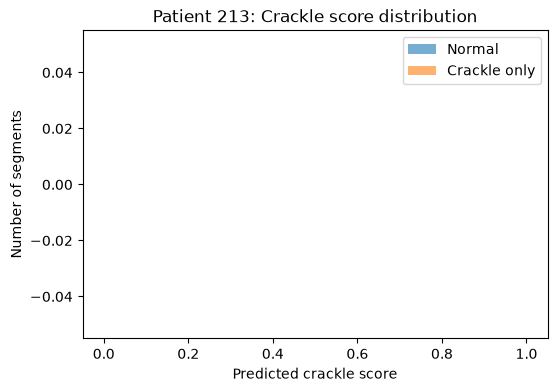


Patient 166
Normal samples: 0
Crackle samples: 0
Normal median: nan
Crackle median: nan
Normal mean: nan
Crackle mean: nan


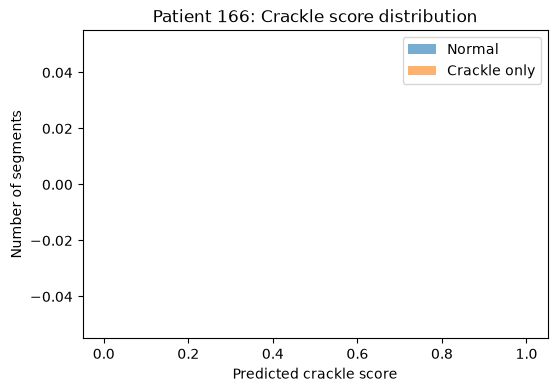


Patient 186
Normal samples: 0
Crackle samples: 0
Normal median: nan
Crackle median: nan
Normal mean: nan
Crackle mean: nan


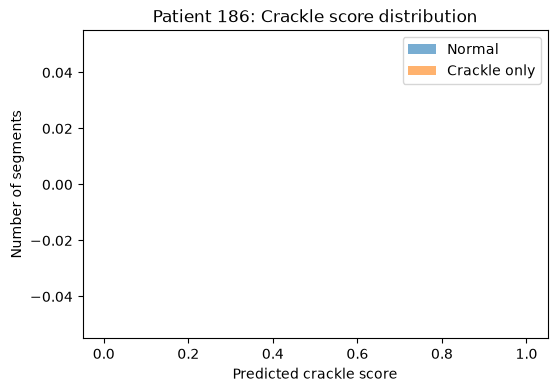

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

patients_to_compare = [213, 166, 186]

for patient in patients_to_compare:

    group = metadata[
        (metadata["patient"] == patient) &
        (metadata["wheeze"] == 0)
    ]

    normal_scores = group.loc[
        group["crackle"] == 0, "crackle_score"
    ]

    crackle_scores = group.loc[
        group["crackle"] == 1, "crackle_score"
    ]

    print(f"\nPatient {patient}")
    print("Normal samples:", len(normal_scores))
    print("Crackle samples:", len(crackle_scores))

    print("Normal median:", normal_scores.median())
    print("Crackle median:", crackle_scores.median())

    print("Normal mean:", normal_scores.mean())
    print("Crackle mean:", crackle_scores.mean())

    plt.figure(figsize=(6, 4))

    plt.hist(
        normal_scores,
        bins=15,
        alpha=0.6,
        label="Normal"
    )

    plt.hist(
        crackle_scores,
        bins=15,
        alpha=0.6,
        label="Crackle only"
    )

    plt.title(f"Patient {patient}: Crackle score distribution")
    plt.xlabel("Predicted crackle score")
    plt.ylabel("Number of segments")
    plt.legend()
    plt.show()

In [ ]:
metadata["patient"] = metadata["patient"].astype(str)

patients_to_compare = ["213", "166", "186"]

for patient in patients_to_compare:

    group = metadata[
        (metadata["patient"] == patient) &
        (metadata["wheeze"] == 0)
    ]

    normal_scores = group.loc[
        group["crackle"] == 0, "crackle_score"
    ]

    crackle_scores = group.loc[
        group["crackle"] == 1, "crackle_score"
    ]

    print(f"\nPatient {patient}")
    print("Total samples:", len(group))
    print("Normal samples:", len(normal_scores))
    print("Crackle samples:", len(crackle_scores))

    print("Normal median:", normal_scores.median())
    print("Crackle median:", crackle_scores.median())

    print("Normal mean:", normal_scores.mean())
    print("Crackle mean:", crackle_scores.mean())


Patient 213
Total samples: 129
Normal samples: 111
Crackle samples: 18
Normal median: 0.44021723
Crackle median: 0.3435874
Normal mean: 0.43074387
Crackle mean: 0.40440458

Patient 166
Total samples: 112
Normal samples: 84
Crackle samples: 28
Normal median: 0.2633329
Crackle median: 0.24838421
Normal mean: 0.29753217
Crackle mean: 0.28060418

Patient 186
Total samples: 124
Normal samples: 50
Crackle samples: 74
Normal median: 0.39573425
Crackle median: 0.43859726
Normal mean: 0.40425938
Crackle mean: 0.43629745


In [ ]:
device_comparison = (
    metadata[
        (metadata["patient"].isin(["213", "166", "186"])) &
        (metadata["wheeze"] == 0)
    ]
    .groupby(["patient", "recording"])
    .agg(
        samples=("crackle", "size"),
        normal=("crackle", lambda x: (x == 0).sum()),
        crackle=("crackle", lambda x: (x == 1).sum()),
        mean_score=("crackle_score", "mean")
    )
    .reset_index()
)

device_comparison["device"] = (
    device_comparison["recording"]
    .str.extract(r"(AKGC417L|LittC2SE|Meditron)")
)

display(
    device_comparison
    .groupby(["patient", "device"])
    .agg(
        samples=("samples", "sum"),
        normal=("normal", "sum"),
        crackle=("crackle", "sum"),
        mean_score=("mean_score", "mean")
    )
    .round(4)
)

,,samples,normal,crackle,mean_score
patient,device,,,,
166,Meditron,112,84,28,0.2958
186,AKGC417L,124,50,74,0.4227
213,AKGC417L,129,111,18,0.4261


In [ ]:
patient_device_class = (
    metadata[
        (metadata["patient"].isin(["213", "166", "186"])) &
        (metadata["wheeze"] == 0)
    ]
    .groupby(["patient", "device", "crackle"])
    .agg(
        samples=("crackle_score", "size"),
        mean_score=("crackle_score", "mean"),
        median_score=("crackle_score", "median"),
        std_score=("crackle_score", "std")
    )
    .reset_index()
)

display(patient_device_class.round(4))

,patient,device,crackle,samples,mean_score,median_score,std_score
0,166,Meditron,0,84,0.2975,0.2633,0.0973
1,166,Meditron,1,28,0.2806,0.2484,0.0969
2,186,AKGC417L,0,50,0.4043,0.3957,0.1110
3,186,AKGC417L,1,74,0.4363,0.4386,0.1013
4,213,AKGC417L,0,111,0.4307,0.4402,0.1381
5,213,AKGC417L,1,18,0.4044,0.3436,0.1357


In [ ]:
metadata["device"] = metadata["wav_path"].str.extract(
    r"(AKGC417L|LittC2SE|Meditron)"
)

In [ ]:
recording_analysis = (
    metadata[
        (metadata["patient"].isin(["213", "166", "186"])) &
        (metadata["wheeze"] == 0)
    ]
    .groupby(["patient", "recording", "crackle"])
    .agg(
        samples=("crackle_score", "size"),
        mean_score=("crackle_score", "mean"),
        median_score=("crackle_score", "median")
    )
    .reset_index()
)

display(
    recording_analysis
    .sort_values(["patient", "recording", "crackle"])
    .round(4)
    .to_string(index=False)
)

'patient              recording  crackle  samples  mean_score  median_score\n    166 166_1p1_Al_sc_Meditron        0       12      0.3321        0.3421\n    166 166_1p1_Al_sc_Meditron        1        5      0.3962        0.3927\n    166 166_1p1_Ar_sc_Meditron        0       25      0.3301        0.2759\n    166 166_1p1_Ll_sc_Meditron        0        9      0.3070        0.3089\n    166 166_1p1_Ll_sc_Meditron        1       16      0.2294        0.1971\n    166 166_1p1_Pl_sc_Meditron        0       17      0.2680        0.2485\n    166 166_1p1_Pl_sc_Meditron        1        7      0.3151        0.3091\n    166 166_1p1_Pr_sc_Meditron        0       21      0.2589        0.2296\n    186 186_2b2_Al_mc_AKGC417L        0        4      0.4946        0.4962\n    186 186_2b2_Ar_mc_AKGC417L        1        5      0.3870        0.3432\n    186 186_2b2_Lr_mc_AKGC417L        1        5      0.4345        0.4363\n    186 186_2b2_Pl_mc_AKGC417L        1        5      0.4701        0.4732\n    186 186

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

records = []

for _, row in val_feature_order_df.iterrows():

    if row["crackle"] != 1:
        continue

    wav_path = Path(row["wav_path"])

    # Find corresponding annotation file
    txt_path = wav_path.with_suffix(".txt")

    if not txt_path.exists():
        continue

    annotation = pd.read_csv(
        txt_path,
        sep="\t",
        header=None
    )

    annotation.columns = [
        "start", "end", "crackle", "wheeze"
    ]

    segment_start = row["start"]
    segment_end = row["end"]

    # Calculate overlap with annotated crackle events
    overlap = 0

    for _, event in annotation.iterrows():

        if event["crackle"] != 1:
            continue

        overlap_start = max(
            segment_start, event["start"]
        )

        overlap_end = min(
            segment_end, event["end"]
        )

        if overlap_end > overlap_start:
            overlap += overlap_end - overlap_start

    duration = segment_end - segment_start

    records.append({
        "sample": row.name,
        "patient": row["patient"],
        "recording": wav_path.stem,
        "segment_duration": duration,
        "crackle_duration": overlap,
        "crackle_ratio": overlap / duration if duration > 0 else 0
    })

crackle_prevalence_df = pd.DataFrame(records)

display(crackle_prevalence_df.head(10))
print("Positive segments analysed:", len(crackle_prevalence_df))

,sample,patient,recording,segment_duration,crackle_duration,crackle_ratio
0,8,110,110_1b1_Pr_sc_Meditron,3.9080,3.9080,1.0
1,9,110,110_1b1_Pr_sc_Meditron,4.3389,4.3389,1.0
2,23,110,110_1p1_Al_sc_Meditron,3.9791,3.9791,1.0
3,24,110,110_1p1_Al_sc_Meditron,4.1754,4.1754,1.0
4,25,110,110_1p1_Al_sc_Meditron,3.6720,3.6720,1.0
5,26,110,110_1p1_Al_sc_Meditron,4.1050,4.1050,1.0
6,28,110,110_1p1_Al_sc_Meditron,3.5470,3.5470,1.0
7,29,110,110_1p1_Al_sc_Meditron,5.6420,5.6420,1.0
8,37,110,110_1p1_Lr_sc_Meditron,3.8447,3.8447,1.0
9,38,110,110_1p1_Lr_sc_Meditron,3.3617,3.3617,1.0


Positive segments analysed: 209


In [ ]:
display(
    crackle_prevalence_df["crackle_ratio"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .round(4)
)

count    209.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
90%        1.0
max        1.0
Name: crackle_ratio, dtype: float64

In [ ]:
recording_name = "213_2p2_Pl_mc_AKGC417L"

txt_path = next(
    Path("../data/raw").glob(recording_name + ".txt")
)

annotation = pd.read_csv(
    txt_path,
    sep="\t",
    header=None
)

annotation.columns = [
    "start", "end", "crackle", "wheeze"
]

display(annotation.head(20))

,start,end,crackle,wheeze
0,0.860,3.631,1,0
1,3.631,6.486,1,0
2,6.486,9.157,1,0
3,9.157,12.062,0,0
4,12.062,14.533,1,0
5,14.533,17.104,0,0
6,17.104,19.708,1,0


In [ ]:
cycle_records = []

for _, row in val_feature_order_df.iterrows():

    if row["crackle"] != 1:
        continue

    recording_name = row["recording"]
    txt_path = Path("../data/raw") / f"{recording_name}.txt"

    if not txt_path.exists():
        continue

    annotation = pd.read_csv(
        txt_path,
        sep="\t",
        header=None
    )

    annotation.columns = [
        "start", "end", "crackle", "wheeze"
    ]

    overlapping = annotation[
        (annotation["end"] > row["start"]) &
        (annotation["start"] < row["end"])
    ]

    total_cycles = len(overlapping)
    crackle_cycles = (overlapping["crackle"] == 1).sum()

    cycle_records.append({
        "sample": row.name,
        "patient": row["patient"],
        "recording": recording_name,
        "total_cycles": total_cycles,
        "crackle_cycles": crackle_cycles,
        "cycle_ratio": (
            crackle_cycles / total_cycles
            if total_cycles > 0 else np.nan
        )
    })

cycle_prevalence_df = pd.DataFrame(cycle_records)

display(
    cycle_prevalence_df["cycle_ratio"]
    .describe(percentiles=[.25, .50, .75, .90])
    .round(4)
)

count    209.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
90%        1.0
max        1.0
Name: cycle_ratio, dtype: float64

In [ ]:
display(
    cycle_prevalence_df[
        ["sample", "recording", "total_cycles",
         "crackle_cycles", "cycle_ratio"]
    ]["total_cycles"].value_counts().sort_index()
)

total_cycles
1    209
Name: count, dtype: int64

In [ ]:
crackle_cycle_analysis = val_feature_order_df[
    (val_feature_order_df["crackle"] == 1) &
    (val_feature_order_df["wheeze"] == 0)
].copy()

crackle_cycle_analysis["duration"] = (
    crackle_cycle_analysis["end"] -
    crackle_cycle_analysis["start"]
)

display(
    crackle_cycle_analysis.groupby("patient")["duration"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

,count,mean,median,std,min,max
patient,,,,,,
110,12,4.192,4.116,0.591,3.362,5.642
128,3,4.790,5.557,1.441,3.128,5.686
161,2,2.728,2.728,0.081,2.671,2.786
164,1,2.843,2.843,NaN,2.843,2.843
166,28,2.429,2.375,0.653,1.398,3.589
179,4,2.411,2.336,0.570,1.929,3.043
180,4,0.768,0.768,0.000,0.768,0.768
186,74,3.416,3.976,1.063,1.202,4.464
189,2,4.800,4.800,0.081,4.742,4.857


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

duration_results = []

for patient in sorted(
    val_feature_order_df["patient"].astype(str).unique()
):
    patient_df = val_feature_order_df[
        (val_feature_order_df["patient"].astype(str) == patient) &
        (val_feature_order_df["wheeze"] == 0)
    ].copy()

    if patient_df["crackle"].nunique() < 2:
        continue

    patient_df["duration"] = (
        patient_df["end"] - patient_df["start"]
    )

    y_true = patient_df["crackle"].values

    # Try both directions because longer cycles
    # are not necessarily associated with crackles.
    auc_positive = roc_auc_score(
        y_true, patient_df["duration"]
    )

    auc_negative = roc_auc_score(
        y_true, -patient_df["duration"]
    )

    duration_results.append({
        "patient": patient,
        "samples": len(patient_df),
        "crackle_samples": int(y_true.sum()),
        "normal_samples": int((y_true == 0).sum()),
        "duration_AUC": auc_positive,
        "best_direction_AUC": max(auc_positive, auc_negative)
    })

duration_results_df = pd.DataFrame(duration_results)

display(
    duration_results_df.round(4)
)

,patient,samples,crackle_samples,normal_samples,duration_AUC,best_direction_AUC
0,110,46,12,34,0.3382,0.6618
1,128,5,3,2,0.8333,0.8333
2,161,8,2,6,0.9167,0.9167
3,164,7,1,6,0.8333,0.8333
4,166,112,28,84,0.4428,0.5572
5,179,13,4,9,0.6944,0.6944
6,186,124,74,50,0.5839,0.5839
7,189,5,2,3,0.6667,0.6667
8,192,5,1,4,0.7500,0.7500
9,199,18,12,6,0.5972,0.5972


In [ ]:
from scipy.stats import spearmanr

duration_score_df = val_feature_order_df.copy()

duration_score_df["duration"] = (
    duration_score_df["end"] -
    duration_score_df["start"]
)

duration_score_df["crackle_score"] = original_val_prob[:, 0]

duration_score_df = duration_score_df[
    duration_score_df["wheeze"] == 0
]

rho, p_value = spearmanr(
    duration_score_df["duration"],
    duration_score_df["crackle_score"]
)

print("Spearman correlation:", round(rho, 4))
print("P-value:", p_value)

Spearman correlation: 0.2905
P-value: 7.964590632189156e-12


In [ ]:
from scipy.stats import spearmanr

duration_patient_results = []

for patient in sorted(
    duration_score_df["patient"].astype(str).unique()
):
    patient_df = duration_score_df[
        duration_score_df["patient"].astype(str) == patient
    ]

    if len(patient_df) < 10:
        continue

    rho, p = spearmanr(
        patient_df["duration"],
        patient_df["crackle_score"]
    )

    duration_patient_results.append({
        "patient": patient,
        "samples": len(patient_df),
        "spearman_r": rho,
        "p_value": p
    })

duration_patient_df = pd.DataFrame(
    duration_patient_results
)

display(duration_patient_df.round(4))

,patient,samples,spearman_r,p_value
0,110,46,-0.1040,0.4914
1,166,112,0.4224,0.0000
2,179,13,0.3769,0.2043
3,186,124,-0.2997,0.0007
4,199,18,-0.0196,0.9384
5,208,13,0.2582,0.3943
6,213,129,0.1026,0.2473
7,226,31,0.3464,0.0562


In [ ]:
duration_label_results = []

for patient in ["166", "186", "213"]:

    patient_df = duration_score_df[
        duration_score_df["patient"].astype(str) == patient
    ]

    normal = patient_df[
        patient_df["crackle"] == 0
    ]["duration"]

    crackle = patient_df[
        patient_df["crackle"] == 1
    ]["duration"]

    duration_label_results.append({
        "patient": patient,
        "normal_count": len(normal),
        "crackle_count": len(crackle),
        "normal_median": normal.median(),
        "crackle_median": crackle.median(),
        "normal_mean": normal.mean(),
        "crackle_mean": crackle.mean()
    })

display(pd.DataFrame(duration_label_results).round(4))

,patient,normal_count,crackle_count,normal_median,crackle_median,normal_mean,crackle_mean
0,166,84,28,2.5320,2.375,2.7018,2.4289
1,186,50,74,3.6255,3.976,3.4286,3.4159
2,213,111,18,2.5880,2.721,2.6544,2.7684


In [ ]:
from sklearn.linear_model import LinearRegression
from scipy.stats import spearmanr

residual_results = []

for patient in ["166", "186", "213"]:

    patient_df = duration_score_df[
        duration_score_df["patient"].astype(str) == patient
    ].copy()

    X = patient_df[["duration"]]
    y = patient_df["crackle_score"]

    reg = LinearRegression()
    reg.fit(X, y)

    patient_df["score_residual"] = (
        y - reg.predict(X)
    )

    rho, p = spearmanr(
        patient_df["score_residual"],
        patient_df["crackle"]
    )

    residual_results.append({
        "patient": patient,
        "samples": len(patient_df),
        "residual_score_label_correlation": rho,
        "p_value": p
    })

display(pd.DataFrame(residual_results).round(4))

,patient,samples,residual_score_label_correlation,p_value
0,166,112,-0.0867,0.3632
1,186,124,0.1506,0.0949
2,213,129,-0.0763,0.3901


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

recording_results = []

for recording, group in duration_score_df.groupby("recording"):

    if group["crackle"].nunique() < 2:
        continue

    y_true = group["crackle"].values
    scores = group["crackle_score"].values

    recording_results.append({
        "recording": recording,
        "patient": str(group["patient"].iloc[0]),
        "samples": len(group),
        "crackle_samples": int(y_true.sum()),
        "normal_samples": int((y_true == 0).sum()),
        "AUC": roc_auc_score(y_true, scores),
        "AP": average_precision_score(y_true, scores)
    })

recording_results_df = pd.DataFrame(recording_results)

display(
    recording_results_df.sort_values(
        ["patient", "recording"]
    ).round(4)
)

,recording,patient,samples,crackle_samples,normal_samples,AUC,AP
0,110_1b1_Pr_sc_Meditron,110,15,2,13,0.5769,0.2111
1,110_1p1_Al_sc_Meditron,110,4,3,1,0.0000,0.6389
2,128_1b3_Tc_mc_LittC2SE,128,5,3,2,0.5000,0.7556
3,161_1b1_Al_sc_Meditron,161,5,2,3,0.8333,0.8333
4,164_1b1_Ll_sc_Meditron,164,7,1,6,1.0000,1.0000
5,166_1p1_Al_sc_Meditron,166,17,5,12,0.6667,0.4322
6,166_1p1_Ll_sc_Meditron,166,25,16,9,0.2569,0.5542
7,166_1p1_Pl_sc_Meditron,166,24,7,17,0.6975,0.4444
8,179_1b1_Al_sc_Meditron,179,7,2,5,0.8000,0.7500
9,179_1b1_Tc_sc_Meditron,179,6,2,4,0.5000,0.4167


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

recording_results = []

for recording, group in duration_score_df.groupby("recording"):

    if group["crackle"].nunique() < 2:
        continue

    y_true = group["crackle"].values
    scores = group["crackle_score"].values

    recording_results.append({
        "recording": recording,
        "patient": str(group["patient"].iloc[0]),
        "samples": len(group),
        "crackle_samples": int(y_true.sum()),
        "normal_samples": int((y_true == 0).sum()),
        "AUC": roc_auc_score(y_true, scores),
        "AP": average_precision_score(y_true, scores)
    })

recording_results_df = pd.DataFrame(recording_results)

display(
    recording_results_df.sort_values(
        ["patient", "recording"]
    ).round(4)
)

NameError: name 'duration_score_df' is not defined

In [ ]:
recording_results_df["location"] = (
    recording_results_df["recording"]
    .str.extract(r"_([A-Za-z]+)_mc_")[0]
)

# Handle recordings with sc instead of mc
missing = recording_results_df["location"].isna()

recording_results_df.loc[missing, "location"] = (
    recording_results_df.loc[missing, "recording"]
    .str.extract(r"_([A-Za-z]+)_sc_")[0]
)

location_summary = (
    recording_results_df
    .groupby("location")
    .agg(
        recordings=("recording", "count"),
        total_samples=("samples", "sum"),
        mean_auc=("AUC", "mean"),
        median_auc=("AUC", "median"),
        mean_ap=("AP", "mean")
    )
    .sort_values("recordings", ascending=False)
)

display(location_summary.round(4))

NameError: name 'recording_results_df' is not defined

In [ ]:
location_patient = (
    recording_results_df
    .groupby(["patient", "location"])
    .agg(
        recordings=("recording", "count"),
        samples=("samples", "sum"),
        mean_auc=("AUC", "mean")
    )
    .reset_index()
    .sort_values(["location", "patient"])
)

display(location_patient.round(4))

,patient,location,recordings,samples,mean_auc
0,110,Al,1,4,0.0000
3,161,Al,1,5,0.8333
5,166,Al,1,17,0.6667
8,179,Al,1,7,0.8000
10,186,Al,3,16,0.7667
19,226,Al,1,10,0.5000
11,186,Ar,2,11,0.5000
16,213,Ar,1,7,0.0000
4,164,Ll,1,7,1.0000
6,166,Ll,1,25,0.2569


In [ ]:
recording_score_comparison = (
    crackle_eval_df
    .groupby(["recording", "patient", "crackle"])
    ["crackle_score"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

recording_score_comparison = recording_score_comparison.pivot(
    index=["recording", "patient"],
    columns="crackle",
    values=["count", "mean", "median"]
)

recording_score_comparison.columns = [
    f"{stat}_{'crackle' if label == 1 else 'normal'}"
    for stat, label in recording_score_comparison.columns
]

recording_score_comparison = recording_score_comparison.reset_index()

recording_score_comparison["median_difference"] = (
    recording_score_comparison["median_crackle"]
    - recording_score_comparison["median_normal"]
)

display(
    recording_score_comparison.sort_values(
        "median_difference"
    )
)

NameError: name 'crackle_eval_df' is not defined

In [ ]:
print([name for name in globals() if "crackle" in name.lower()])

['crackle', 'crackle_id', 'crackle_threshold', 'predicted_crackle', 'crackle_thr', 'best_crackle_threshold', 'pred_crackle', 'crackle_threshold_df', 'CRACKLE_THRESHOLD', 'crackle_detected', 'crackle_scores', 'crackle_fp', 'crackle_class_comparison', 'train_crackle_comparison', 'crackle_analysis', 'crackle_label', 'crackle_count', 'crackle_prevalence_df', 'crackle_cycles', 'crackle_cycle_analysis']


In [ ]:
print("crackle_scores:", np.shape(crackle_scores))
print("crackle_label:", np.shape(crackle_label))
print("val_feature_order_df:", val_feature_order_df.shape)

print("\nMetadata columns:")
print(val_feature_order_df.columns.tolist())

crackle_scores: (74,)
crackle_label: ()
val_feature_order_df: (649, 11)

Metadata columns:
['wav_path', 'patient', 'recording', 'start', 'end', 'crackle', 'wheeze', 'label', 'official_split', '_merge', 'device']


In [ ]:
for name in ["original_val_prob", "cnn_lstm_val_prob", "train_predictions"]:
    if name in globals():
        print(name, np.shape(globals()[name]))

original_val_prob (649, 2)
cnn_lstm_val_prob (649, 2)
train_predictions (3376, 2)


In [ ]:
crackle_eval_df = val_feature_order_df.copy()

crackle_eval_df["crackle_score"] = original_val_prob[:, 0]
crackle_eval_df["crackle_label"] = crackle_eval_df["crackle"].astype(int)

recording_score_comparison = (
    crackle_eval_df
    .groupby(["recording", "patient", "crackle_label"])
    ["crackle_score"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

display(recording_score_comparison.round(4))

,recording,patient,crackle_label,count,mean,median,std
0,108_1b1_Al_sc_Meditron,108,0,8,0.2361,0.2027,0.0901
1,110_1b1_Pr_sc_Meditron,110,0,13,0.3587,0.3862,0.1171
2,110_1b1_Pr_sc_Meditron,110,1,2,0.3921,0.3921,0.0405
3,110_1p1_Al_sc_Meditron,110,0,1,0.3274,0.3274,NaN
4,110_1p1_Al_sc_Meditron,110,1,6,0.3216,0.2972,0.0838
...,...,...,...,...,...,...,...
112,226_1b1_Al_sc_Meditron,226,1,2,0.2250,0.2250,0.0006
113,226_1b1_Ll_sc_Meditron,226,0,4,0.1982,0.1930,0.0254
114,226_1b1_Ll_sc_Meditron,226,1,6,0.1842,0.1809,0.0136
115,226_1b1_Pl_sc_LittC2SE,226,0,6,0.2013,0.1929,0.0243


In [ ]:
recording_comparison = crackle_eval_df.pivot_table(
    index=["recording", "patient"],
    columns="crackle_label",
    values="crackle_score",
    aggfunc=["count", "median", "mean"]
)

recording_comparison.columns = [
    f"{stat}_{'crackle' if label == 1 else 'normal'}"
    for stat, label in recording_comparison.columns
]

recording_comparison = recording_comparison.reset_index()

# Keep recordings containing both normal and crackle-positive segments
recording_comparison = recording_comparison.dropna(
    subset=["median_normal", "median_crackle"]
)

recording_comparison["median_difference"] = (
    recording_comparison["median_crackle"]
    - recording_comparison["median_normal"]
)

display(
    recording_comparison[
        [
            "recording",
            "patient",
            "count_normal",
            "count_crackle",
            "median_normal",
            "median_crackle",
            "median_difference"
        ]
    ].sort_values("median_difference").round(4)
)

,recording,patient,count_normal,count_crackle,median_normal,median_crackle,median_difference
76,213_2p2_Pl_mc_AKGC417L,213,2.0,5.0,0.5140,0.3141,-0.1999
75,213_2p2_Ar_mc_AKGC417L,213,6.0,1.0,0.4233,0.2409,-0.1824
77,213_2p2_Pr_mc_AKGC417L,213,5.0,2.0,0.5943,0.4320,-0.1623
42,186_3b3_Lr_mc_AKGC417L,186,5.0,1.0,0.4474,0.3338,-0.1136
12,166_1p1_Ll_sc_Meditron,166,9.0,16.0,0.3089,0.1971,-0.1118
6,128_1b3_Tc_mc_LittC2SE,128,2.0,3.0,0.3493,0.2438,-0.1055
41,186_3b3_Ar_mc_AKGC417L,186,3.0,3.0,0.3852,0.2912,-0.0939
47,192_2b1_Al_mc_LittC2SE,192,7.0,1.0,0.4137,0.3746,-0.0391
2,110_1p1_Al_sc_Meditron,110,1.0,6.0,0.3274,0.2972,-0.0303
49,192_2b2_Al_mc_LittC2SE,192,6.0,2.0,0.4164,0.3955,-0.0210


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

location_patient_results = []

temp_df = crackle_eval_df.copy()

# Extract chest location from recording filename
temp_df["location"] = (
    temp_df["recording"].astype(str).str.split("_").str[2]
)

for (patient, location), group in temp_df.groupby(
    ["patient", "location"]
):
    y_true = group["crackle_label"].to_numpy()
    y_score = group["crackle_score"].to_numpy()

    # AUC requires both classes
    if len(np.unique(y_true)) < 2:
        continue

    location_patient_results.append({
        "patient": patient,
        "location": location,
        "samples": len(group),
        "normal": int((y_true == 0).sum()),
        "crackle": int((y_true == 1).sum()),
        "AUC": roc_auc_score(y_true, y_score),
        "AP": average_precision_score(y_true, y_score)
    })

location_patient_df = pd.DataFrame(location_patient_results)

display(
    location_patient_df
    .sort_values(["location", "patient"])
    .round(4)
)

,patient,location,samples,normal,crackle,AUC,AP
0,110,Al,7,1,6,0.1667,0.8179
3,161,Al,9,5,4,0.8000,0.8304
5,166,Al,17,12,5,0.6667,0.4322
8,179,Al,8,5,3,0.8667,0.8667
10,180,Al,6,1,5,0.8000,0.9667
11,186,Al,21,15,6,0.6222,0.4233
17,192,Al,23,19,4,0.3684,0.3665
23,226,Al,10,8,2,0.5000,0.2667
12,186,Ar,21,4,17,0.5441,0.8899
19,206,Ar,11,10,1,0.4000,0.1429


In [ ]:
import librosa
import numpy as np
import pandas as pd

print("Validation feature shape:", X_val_3ch.shape)
print("Metadata rows:", len(val_feature_order_df))
print("Sample rate:", TARGET_SR)
print("Frequency range:", FMIN, "-", FMAX)

Validation feature shape: (649, 64, 157, 3)
Metadata rows: 649
Sample rate: 4000
Frequency range: 20 - 2000


In [ ]:
# Channel 0 = normalised Log-Mel features
logmel_features = X_val_3ch[:, :, :, 0]

# Average across valid time frames for each segment
spectral_profiles = []

for i in range(len(logmel_features)):
    valid_frames = val_feature_order_df.iloc[i]["valid_frames"] \
        if "valid_frames" in val_feature_order_df.columns else 157

    profile = np.mean(logmel_features[i], axis=1)

    spectral_profiles.append(profile)

spectral_profiles = np.asarray(spectral_profiles)

print("Spectral profiles shape:", spectral_profiles.shape)
print("Minimum:", spectral_profiles.min())
print("Maximum:", spectral_profiles.max())

Spectral profiles shape: (649, 64)
Minimum: 0.0010007638
Maximum: 0.90499973


In [ ]:
print([
    name for name in globals()
    if "mask" in name.lower() and "val" in name.lower()
])

['val_mfcc_mask']


In [ ]:
print("Mask shape:", val_mfcc_mask.shape)
print("Mask dtype:", val_mfcc_mask.dtype)
print("First 10 mask counts:")
print(np.sum(val_mfcc_mask, axis=1)[:10])

Mask shape: (649, 157)
Mask dtype: bool
First 10 mask counts:
[ 90 146  67  80  71  67  70  35 123 136]


In [ ]:
spectral_profiles_masked = np.zeros((len(X_val_3ch), 64), dtype=np.float32)

for i in range(len(X_val_3ch)):
    valid_frames = val_mfcc_mask[i]

    # Channel 0: normalised Log-Mel features
    valid_logmel = X_val_3ch[i, :, valid_frames, 0]

    spectral_profiles_masked[i] = np.mean(
        valid_logmel, axis=1
    )

print("Shape:", spectral_profiles_masked.shape)
print("Minimum:", spectral_profiles_masked.min())
print("Maximum:", spectral_profiles_masked.max())

ValueError: could not broadcast input array from shape (90,) into shape (64,)

In [ ]:
spectral_profiles_masked = np.zeros(
    (len(X_val_3ch), 64), dtype=np.float32
)

for i in range(len(X_val_3ch)):
    valid_logmel = X_val_3ch[i][:, :, 0][:, val_mfcc_mask[i]]

    spectral_profiles_masked[i] = np.mean(
        valid_logmel, axis=1
    )

print("Shape:", spectral_profiles_masked.shape)
print("Minimum:", spectral_profiles_masked.min())
print("Maximum:", spectral_profiles_masked.max())

Shape: (649, 64)
Minimum: 0.0017854538
Maximum: 0.96689516


In [ ]:
# Select normal and crackle-only segments
normal_idx = np.where(
    (val_feature_order_df["crackle"].to_numpy() == 0) &
    (val_feature_order_df["wheeze"].to_numpy() == 0)
)[0]

crackle_idx = np.where(
    (val_feature_order_df["crackle"].to_numpy() == 1) &
    (val_feature_order_df["wheeze"].to_numpy() == 0)
)[0]

normal_profile_mean = spectral_profiles_masked[normal_idx].mean(axis=0)
crackle_profile_mean = spectral_profiles_masked[crackle_idx].mean(axis=0)

print("Normal segments:", len(normal_idx))
print("Crackle-only segments:", len(crackle_idx))

print("\nMean absolute profile difference:",
      np.mean(np.abs(crackle_profile_mean - normal_profile_mean)))

print("\nPer-bin profile comparison:")
profile_comparison = pd.DataFrame({
    "mel_bin": np.arange(64),
    "normal_mean": normal_profile_mean,
    "crackle_mean": crackle_profile_mean,
    "difference": crackle_profile_mean - normal_profile_mean
})

display(profile_comparison.round(4))

Normal segments: 359
Crackle-only segments: 174

Mean absolute profile difference: 0.017304096

Per-bin profile comparison:


,mel_bin,normal_mean,crackle_mean,difference
0,0,0.8665,0.8783,0.0118
1,1,0.7802,0.7868,0.0066
2,2,0.7026,0.7189,0.0163
3,3,0.6465,0.6682,0.0217
4,4,0.5996,0.6238,0.0243
...,...,...,...,...
59,59,0.1656,0.1827,0.0170
60,60,0.1616,0.1804,0.0188
61,61,0.1564,0.1781,0.0217
62,62,0.1329,0.1529,0.0200


In [ ]:
profile_difference = (
    crackle_profile_mean - normal_profile_mean
)

mel_frequencies_hz = librosa.mel_frequencies(
    n_mels=64,
    fmin=FMIN,
    fmax=FMAX
)

print("Mean signed difference:",
      np.mean(profile_difference))

print("Positive bins:",
      np.sum(profile_difference > 0), "/ 64")

print("Negative bins:",
      np.sum(profile_difference < 0), "/ 64")

print("Minimum difference:",
      np.min(profile_difference))

print("Maximum difference:",
      np.max(profile_difference))

# Five bins with the largest positive differences
largest_bins = np.argsort(profile_difference)[-5:][::-1]

print("\nLargest positive differences:")
display(pd.DataFrame({
    "mel_bin": largest_bins,
    "frequency_hz": mel_frequencies_hz[largest_bins],
    "difference": profile_difference[largest_bins]
}).round(4))

Mean signed difference: 0.017304096
Positive bins: 64 / 64
Negative bins: 0 / 64
Minimum difference: 0.004321635
Maximum difference: 0.037253022

Largest positive differences:


,mel_bin,frequency_hz,difference
0,14,387.1390,0.0373
1,13,360.9148,0.0363
2,12,334.6905,0.0334
3,11,308.4663,0.0303
4,7,203.5695,0.0301


In [ ]:
patient_profile_results = []

metadata = val_feature_order_df.copy()
metadata["patient"] = metadata["patient"].astype(str)

for patient, group in metadata.groupby("patient"):

    indices = group.index.to_numpy()

    normal_indices = indices[
        (group["crackle"].to_numpy() == 0) &
        (group["wheeze"].to_numpy() == 0)
    ]

    crackle_indices = indices[
        (group["crackle"].to_numpy() == 1) &
        (group["wheeze"].to_numpy() == 0)
    ]

    if len(normal_indices) == 0 or len(crackle_indices) == 0:
        continue

    normal_mean = spectral_profiles_masked[normal_indices].mean(axis=0)
    crackle_mean = spectral_profiles_masked[crackle_indices].mean(axis=0)

    difference = crackle_mean - normal_mean

    patient_profile_results.append({
        "patient": patient,
        "normal_samples": len(normal_indices),
        "crackle_samples": len(crackle_indices),
        "mean_difference": difference.mean(),
        "positive_bins": np.sum(difference > 0),
        "negative_bins": np.sum(difference < 0),
        "largest_difference": difference.max(),
        "smallest_difference": difference.min()
    })

patient_profile_df = pd.DataFrame(patient_profile_results)

display(
    patient_profile_df
    .sort_values("mean_difference")
    .round(4)
)

print("\nPatients analysed:", len(patient_profile_df))
print(
    "Patients with positive mean difference:",
    (patient_profile_df["mean_difference"] > 0).sum()
)

,patient,normal_samples,crackle_samples,mean_difference,positive_bins,negative_bins,largest_difference,smallest_difference
3,164,6,1,-0.1093,0,64,-0.0200,-0.1386
10,213,111,18,-0.0777,0,64,-0.0147,-0.1040
2,161,6,2,-0.0384,2,62,0.0164,-0.0661
7,189,3,2,-0.0181,1,63,0.0062,-0.0434
1,128,2,3,-0.0173,12,52,0.0173,-0.0460
0,110,34,12,-0.0152,16,48,0.0530,-0.0492
5,179,9,4,-0.0141,3,61,0.0082,-0.0327
11,226,18,13,-0.0017,28,36,0.0168,-0.0276
8,192,4,1,0.0057,42,22,0.0348,-0.0672
9,199,6,12,0.0135,55,9,0.0362,-0.0128



Patients analysed: 12
Patients with positive mean difference: 4


In [ ]:
# Select patients with sufficient samples from both classes
eligible_patients = patient_profile_df[
    (patient_profile_df["normal_samples"] >= 10) &
    (patient_profile_df["crackle_samples"] >= 10)
]["patient"].astype(str).tolist()

print("Eligible patients:", eligible_patients)

patient_differences = []

for patient in eligible_patients:
    group_indices = np.where(
        metadata["patient"].to_numpy() == patient
    )[0]

    normal_indices = group_indices[
        (metadata.iloc[group_indices]["crackle"].to_numpy() == 0) &
        (metadata.iloc[group_indices]["wheeze"].to_numpy() == 0)
    ]

    crackle_indices = group_indices[
        (metadata.iloc[group_indices]["crackle"].to_numpy() == 1) &
        (metadata.iloc[group_indices]["wheeze"].to_numpy() == 0)
    ]

    difference = (
        spectral_profiles_masked[crackle_indices].mean(axis=0)
        - spectral_profiles_masked[normal_indices].mean(axis=0)
    )

    patient_differences.append(difference)

patient_balanced_difference = np.mean(
    patient_differences, axis=0
)

print("\nPatient-balanced mean difference:",
      patient_balanced_difference.mean())

print("Positive bins:",
      np.sum(patient_balanced_difference > 0))

print("Negative bins:",
      np.sum(patient_balanced_difference < 0))

Eligible patients: ['110', '166', '186', '213', '226']

Patient-balanced mean difference: -0.005177445
Positive bins: 18
Negative bins: 46


In [ ]:
patient_difference_matrix = np.asarray(patient_differences)

print("Patient difference matrix:",
      patient_difference_matrix.shape)

print("\nMean difference per patient:")
for patient, difference in zip(
    eligible_patients, patient_difference_matrix
):
    print(
        patient,
        "mean =", round(float(difference.mean()), 5),
        "positive bins =", int(np.sum(difference > 0)),
        "negative bins =", int(np.sum(difference < 0))
    )

# Across-patient variation at each Mel bin
between_patient_std = patient_difference_matrix.std(axis=0)

print("\nMean across-patient standard deviation:",
      between_patient_std.mean())

print("Median across-patient standard deviation:",
      np.median(between_patient_std))

Patient difference matrix: (5, 64)

Mean difference per patient:
110 mean = -0.01524 positive bins = 16 negative bins = 48
166 mean = 0.01708 positive bins = 62 negative bins = 2
186 mean = 0.05174 positive bins = 64 negative bins = 0
213 mean = -0.07774 positive bins = 0 negative bins = 64
226 mean = -0.00173 positive bins = 28 negative bins = 36

Mean across-patient standard deviation: 0.04406143
Median across-patient standard deviation: 0.045336835


In [ ]:
from itertools import combinations
from scipy.stats import pearsonr

print("Pairwise similarity between patient spectral-difference profiles\n")

for p1, p2 in combinations(range(len(eligible_patients)), 2):
    d1 = patient_difference_matrix[p1]
    d2 = patient_difference_matrix[p2]

    correlation = pearsonr(d1, d2).statistic
    cosine = np.dot(d1, d2) / (
        np.linalg.norm(d1) * np.linalg.norm(d2) + 1e-12
    )

    print(
        f"Patient {eligible_patients[p1]} vs {eligible_patients[p2]}: "
        f"correlation = {correlation:.3f}, "
        f"cosine similarity = {cosine:.3f}"
    )

Pairwise similarity between patient spectral-difference profiles

Patient 110 vs 166: correlation = 0.277, cosine similarity = -0.283
Patient 110 vs 186: correlation = 0.326, cosine similarity = -0.403
Patient 110 vs 213: correlation = 0.872, cosine similarity = 0.692
Patient 110 vs 226: correlation = 0.569, cosine similarity = 0.570
Patient 166 vs 186: correlation = 0.227, cosine similarity = 0.839
Patient 166 vs 213: correlation = 0.168, cosine similarity = -0.775
Patient 166 vs 226: correlation = -0.158, cosine similarity = -0.224
Patient 186 vs 213: correlation = 0.217, cosine similarity = -0.907
Patient 186 vs 226: correlation = -0.052, cosine similarity = -0.174
Patient 213 vs 226: correlation = 0.659, cosine similarity = 0.344


In [ ]:
# Normalise each patient's spectral-difference profile
# to separate profile shape from overall magnitude.

patient_profiles_normalised = []

for patient, difference in zip(
    eligible_patients,
    patient_difference_matrix
):
    norm = np.linalg.norm(difference)

    if norm > 0:
        normalised = difference / norm
    else:
        normalised = difference

    patient_profiles_normalised.append(normalised)

patient_profiles_normalised = np.asarray(
    patient_profiles_normalised
)

# Calculate mean profile disagreement
mean_profile = patient_profiles_normalised.mean(axis=0)

print(
    "Mean normalised profile:",
    np.round(mean_profile.mean(), 5)
)

print(
    "Mean absolute profile:",
    np.round(np.abs(mean_profile).mean(), 5)
)

print(
    "Positive bins:",
    np.sum(mean_profile > 0)
)

print(
    "Negative bins:",
    np.sum(mean_profile < 0)
)

Mean normalised profile: 0.00446
Mean absolute profile: 0.04136
Positive bins: 27
Negative bins: 37


In [ ]:
from itertools import combinations
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(
    patient_profiles_normalised
)

print("Patient order:", eligible_patients)
print("\nNormalised profile cosine similarity:\n")

print(np.round(similarity_matrix, 3))

pairwise_values = []

for i, j in combinations(range(len(eligible_patients)), 2):
    similarity = similarity_matrix[i, j]
    pairwise_values.append(similarity)

    print(
        f"{eligible_patients[i]} vs {eligible_patients[j]}:",
        round(float(similarity), 3)
    )

print("\nMean pairwise cosine similarity:",
      round(float(np.mean(pairwise_values)), 4))

print("Median pairwise cosine similarity:",
      round(float(np.median(pairwise_values)), 4))

Patient order: ['110', '166', '186', '213', '226']

Normalised profile cosine similarity:

[[ 1.    -0.283 -0.403  0.692  0.57 ]
 [-0.283  1.     0.839 -0.775 -0.224]
 [-0.403  0.839  1.    -0.907 -0.174]
 [ 0.692 -0.775 -0.907  1.     0.344]
 [ 0.57  -0.224 -0.174  0.344  1.   ]]
110 vs 166: -0.283
110 vs 186: -0.403
110 vs 213: 0.692
110 vs 226: 0.57
166 vs 186: 0.839
166 vs 213: -0.775
166 vs 226: -0.224
186 vs 213: -0.907
186 vs 226: -0.174
213 vs 226: 0.344

Mean pairwise cosine similarity: -0.0322
Median pairwise cosine similarity: -0.1989


In [ ]:
# Bootstrap stability for one patient
# Patient 110

import numpy as np

rng = np.random.default_rng(42)

patient_id = "110"
n_bootstrap = 1000

group = metadata[metadata["patient"].astype(str) == patient_id]

normal_indices = group.index[
    (group["crackle"] == 0) & (group["wheeze"] == 0)
].to_numpy()

crackle_indices = group.index[
    (group["crackle"] == 1) & (group["wheeze"] == 0)
].to_numpy()

normal_profiles = spectral_profiles_masked[normal_indices]
crackle_profiles = spectral_profiles_masked[crackle_indices]

bootstrap_differences = []

for _ in range(n_bootstrap):

    sampled_normal = rng.choice(
        len(normal_profiles),
        size=len(normal_profiles),
        replace=True
    )

    sampled_crackle = rng.choice(
        len(crackle_profiles),
        size=len(crackle_profiles),
        replace=True
    )

    difference = (
        crackle_profiles[sampled_crackle].mean(axis=0)
        - normal_profiles[sampled_normal].mean(axis=0)
    )

    bootstrap_differences.append(difference)

bootstrap_differences = np.asarray(bootstrap_differences)

original_difference = (
    crackle_profiles.mean(axis=0)
    - normal_profiles.mean(axis=0)
)

sign_stability = np.mean(
    np.sign(bootstrap_differences) ==
    np.sign(original_difference),
    axis=0
)

print("Patient:", patient_id)
print("Normal samples:", len(normal_profiles))
print("Crackle samples:", len(crackle_profiles))
print("Bootstrap shape:", bootstrap_differences.shape)
print("Mean sign stability:", round(float(sign_stability.mean()), 4))
print("Bins with >=80% sign stability:", np.sum(sign_stability >= 0.80))
print("Bins with <=50% sign stability:", np.sum(sign_stability <= 0.50))

NameError: name 'metadata' is not defined

In [ ]:
metadata = val_feature_order_df.copy()
metadata["patient"] = metadata["patient"].astype(str)

print("Metadata shape:", metadata.shape)
print("Spectral profiles shape:", spectral_profiles_masked.shape)
print("Patients available:", sorted(metadata["patient"].unique()))

NameError: name 'val_feature_order_df' is not defined

In [ ]:
important_variables = [
    "X_val_3ch",
    "y_val_multi",
    "val_feature_order_df",
    "val_mfcc_mask",
    "spectral_profiles_masked",
    "original_val_prob",
    "delta_means",
    "delta_stds"
]

for name in important_variables:
    print(name, ":", "Available" if name in globals() else "Missing")

X_val_3ch : Missing
y_val_multi : Missing
val_feature_order_df : Missing
val_mfcc_mask : Missing
spectral_profiles_masked : Missing
original_val_prob : Missing
delta_means : Missing
delta_stds : Missing


In [ ]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for file in files:
        if file.endswith((
            ".npy", ".npz", ".pkl", ".csv",
            ".keras", ".h5", ".joblib"
        )):
            print(os.path.join(root, file))

.\best_3ch_multilabel.keras
.\best_3ch_patient_balanced.keras
.\best_cnn_lstm_device_aligned.keras
.\best_cnn_lstm_patient_weighted.keras
.\best_framepad_cnn.keras
.\best_framepad_combined_boost_cnn.keras
.\best_framepad_dropout_cnn.keras
.\best_framepad_fusion.keras
.\best_framepad_gap_cnn.keras
.\best_framepad_multilabel_cnn.keras
.\best_framepad_multilabel_gap.keras
.\best_framepad_multilabel_mfcc.keras
.\cnn_lstm_official_test_predictions.csv


In [ ]:
import os

extensions = (".npy", ".npz", ".pkl", ".joblib", ".csv")

for root, dirs, files in os.walk(".."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".venv", "venv"]
    ]

    for file in files:
        if file.endswith(extensions):
            print(os.path.join(root, file))

..\data\processed\excluded_recordings_audit.csv
..\data\processed\metadata_test.csv
..\data\processed\metadata_train.csv
..\data\processed\metadata_validation.csv
..\data\processed\meta_test.csv
..\data\processed\meta_train.csv
..\data\processed\meta_val.csv
..\data\processed\X_test.npy
..\data\processed\X_test_logmel.npy
..\data\processed\X_train.npy
..\data\processed\X_train_logmel.npy
..\data\processed\X_val.npy
..\data\processed\X_validation_logmel.npy
..\data\processed\y_test.npy
..\data\processed\y_train.npy
..\data\processed\y_val.npy
..\data\processed\y_validation.npy
..\notebooks\cnn_lstm_official_test_predictions.csv


In [ ]:
import numpy as np
import pandas as pd
import os

data_dir = os.path.join("..", "data", "processed")

files_to_check = [
    "X_val.npy",
    "X_validation_logmel.npy",
    "y_val.npy",
    "y_validation.npy"
]

for filename in files_to_check:
    path = os.path.join(data_dir, filename)
    arr = np.load(path)
    print(filename, "->", arr.shape, arr.dtype)

print("\nValidation metadata:")

meta = pd.read_csv(
    os.path.join(data_dir, "meta_val.csv")
)

print("Shape:", meta.shape)
print("Columns:", meta.columns.tolist())
print(meta.head())

X_val.npy -> (496, 64, 157, 1) float32
X_validation_logmel.npy -> (496, 64, 157, 1) float32
y_val.npy -> (496,) int64
y_validation.npy -> (496,) int64

Validation metadata:
Shape: (496, 8)
Columns: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
                                 wav_path               recording  patient  \
0  ..\data\raw\103_2b2_Ar_mc_LittC2SE.wav  103_2b2_Ar_mc_LittC2SE      103   
1  ..\data\raw\103_2b2_Ar_mc_LittC2SE.wav  103_2b2_Ar_mc_LittC2SE      103   
2  ..\data\raw\103_2b2_Ar_mc_LittC2SE.wav  103_2b2_Ar_mc_LittC2SE      103   
3  ..\data\raw\103_2b2_Ar_mc_LittC2SE.wav  103_2b2_Ar_mc_LittC2SE      103   
4  ..\data\raw\103_2b2_Ar_mc_LittC2SE.wav  103_2b2_Ar_mc_LittC2SE      103   

    start     end   label  label_id  noise_snr_db  
0   0.364   3.250  wheeze         2           NaN  
1   3.250   6.636  normal         0           NaN  
2   6.636  11.179  wheeze         2           NaN  
3  11.179  14.250  wheeze         2

In [ ]:
import pandas as pd
import os

data_dir = os.path.join("..", "data", "processed")

for filename in [
    "meta_val.csv",
    "metadata_validation.csv",
    "metadata_train.csv",
    "meta_train.csv",
    "metadata_test.csv",
    "meta_test.csv"
]:
    path = os.path.join(data_dir, filename)

    if os.path.exists(path):
        df = pd.read_csv(path)

        print(f"\n{filename}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        if "label" in df.columns:
            print("Labels:", df["label"].value_counts().to_dict())

        if "patient" in df.columns:
            print("Unique patients:", df["patient"].nunique())


meta_val.csv
Shape: (496, 8)
Columns: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
Labels: {'normal': 209, 'crackle': 150, 'wheeze': 70, 'crackle+wheeze': 67}
Unique patients: 13

metadata_validation.csv
Shape: (496, 8)
Columns: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
Labels: {'normal': 209, 'crackle': 150, 'wheeze': 70, 'crackle+wheeze': 67}
Unique patients: 13

metadata_train.csv
Shape: (3529, 8)
Columns: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
Labels: {'normal': 1844, 'crackle': 1036, 'wheeze': 416, 'crackle+wheeze': 233}
Unique patients: 64

meta_train.csv
Shape: (3529, 8)
Columns: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
Labels: {'normal': 1844, 'crackle': 1036, 'wheeze': 416, 'crackle+wheeze': 233}
Unique patients: 64

metadata_test.csv
Shape: (2756, 8)
Columns: ['wav_path', 'recording', 

In [ ]:
import os

for root, dirs, files in os.walk(".."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".venv", "venv"]
    ]

    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(root, file))

..\notebooks\01_explore_icbhi.ipynb
..\notebooks\02_build_dataset.ipynb


In [ ]:
print("Kernel is working")

In [ ]:
import sys
print(sys.executable)

In [ ]:
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf

print("All imports successful")

All imports successful


In [ ]:
from pathlib import Path

print("WORKING DIRECTORY:")
print(Path.cwd())

print("\nSAVED MODEL CHECKPOINTS:")
for p in Path(".").glob("*.keras"):
    print(p.name)

print("\nPROCESSED DATA FOLDER:")
data_path = Path("../data/processed")

if data_path.exists():
    for p in data_path.iterdir():
        print(p.name)
else:
    print("Folder not found at:", data_path.resolve())

WORKING DIRECTORY:
c:\Users\Admin\Respiratory_TinyML\notebooks

SAVED MODEL CHECKPOINTS:
best_3ch_multilabel.keras
best_3ch_patient_balanced.keras
best_cnn_lstm_device_aligned.keras
best_cnn_lstm_patient_weighted.keras
best_framepad_cnn.keras
best_framepad_combined_boost_cnn.keras
best_framepad_dropout_cnn.keras
best_framepad_fusion.keras
best_framepad_gap_cnn.keras
best_framepad_multilabel_cnn.keras
best_framepad_multilabel_gap.keras
best_framepad_multilabel_mfcc.keras

PROCESSED DATA FOLDER:
excluded_recordings_audit.csv
metadata_test.csv
metadata_train.csv
metadata_validation.csv
meta_test.csv
meta_train.csv
meta_val.csv
X_test.npy
X_test_logmel.npy
X_train.npy
X_train_logmel.npy
X_val.npy
X_validation_logmel.npy
y_test.npy
y_train.npy
y_val.npy
y_validation.npy


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

data_path = Path("../data/processed")

print("DATA SHAPES")
for name in ["X_train.npy", "X_val.npy", "X_test.npy",
             "y_train.npy", "y_val.npy", "y_test.npy"]:
    p = data_path / name
    if p.exists():
        arr = np.load(p, mmap_mode="r")
        print(name, arr.shape, arr.dtype)

print("\nNOTEBOOKS")
for p in Path(".").glob("*.ipynb"):
    print(p.name)

print("\nMETADATA COUNTS")
for name in ["metadata_train.csv", "metadata_validation.csv",
             "metadata_test.csv"]:
    p = data_path / name
    if p.exists():
        df = pd.read_csv(p)
        print(name, len(df), list(df.columns))

DATA SHAPES
X_train.npy (3529, 64, 157, 1) float32
X_val.npy (496, 64, 157, 1) float32
X_test.npy (2756, 64, 157, 1) float32
y_train.npy (3529,) int64
y_val.npy (496,) int64
y_test.npy (2756,) int64

NOTEBOOKS
01_explore_icbhi.ipynb
02_build_dataset.ipynb

METADATA COUNTS
metadata_train.csv 3529 ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
metadata_validation.csv 496 ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']
metadata_test.csv 2756 ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']


In [ ]:
from pathlib import Path

root = Path.cwd().parent

extensions = {".npy", ".npz", ".csv", ".pkl", ".keras", ".parquet"}

print("SEARCHING PROJECT:", root)

for p in root.rglob("*"):
    if any(x in {".venv", "venv", ".git", "__pycache__"} for x in p.parts):
        continue
    if p.is_file() and p.suffix.lower() in extensions:
        print(p.relative_to(root))

SEARCHING PROJECT: c:\Users\Admin\Respiratory_TinyML
data\processed\excluded_recordings_audit.csv
data\processed\metadata_test.csv
data\processed\metadata_train.csv
data\processed\metadata_validation.csv
data\processed\meta_test.csv
data\processed\meta_train.csv
data\processed\meta_val.csv
data\processed\X_test.npy
data\processed\X_test_logmel.npy
data\processed\X_train.npy
data\processed\X_train_logmel.npy
data\processed\X_val.npy
data\processed\X_validation_logmel.npy
data\processed\y_test.npy
data\processed\y_train.npy
data\processed\y_val.npy
data\processed\y_validation.npy
models\best_compact_logmel_cnn.keras
models\best_fold3_compact_cnn.keras
models\best_logmel_cnn.keras
models\best_resized_logmel_cnn.keras
notebooks\best_3ch_multilabel.keras
notebooks\best_3ch_patient_balanced.keras
notebooks\best_cnn_lstm_device_aligned.keras
notebooks\best_cnn_lstm_patient_weighted.keras
notebooks\best_framepad_cnn.keras
notebooks\best_framepad_combined_boost_cnn.keras
notebooks\best_framepad

In [ ]:
import pandas as pd
from pathlib import Path

p = Path("cnn_lstm_official_test_predictions.csv")

df = pd.read_csv(p)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isna().sum())

Shape: (2756, 11)

Columns:
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'actual_class', 'predicted_class', 'crackle_probability', 'wheeze_probability']

First five rows:


,wav_path,recording,patient,start,end,label,label_id,actual_class,predicted_class,crackle_probability,wheeze_probability
0,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,0.036,0.579,normal,0,normal,normal,0.185530,0.109716
1,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,0.579,2.450,normal,0,normal,normal,0.205671,0.096359
2,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,2.450,3.893,normal,0,normal,normal,0.222152,0.094629
3,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,3.893,5.793,normal,0,normal,normal,0.188752,0.097890
4,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,5.793,7.521,normal,0,normal,normal,0.193424,0.095801



Missing values:
wav_path               0
recording              0
patient                0
start                  0
end                    0
label                  0
label_id               0
actual_class           0
predicted_class        0
crackle_probability    0
wheeze_probability     0
dtype: int64


import pandas as pd
from pathlib import Path

p = Path("cnn_lstm_official_test_predictions.csv")

df = pd.read_csv(p)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isna().sum())

In [ ]:
import tensorflow as tf
from pathlib import Path

checkpoint_names = [
    "best_cnn_lstm_patient_weighted.keras",
    "best_cnn_lstm_device_aligned.keras",
    "best_3ch_patient_balanced.keras",
    "best_3ch_multilabel.keras"
]

for name in checkpoint_names:
    path = Path(name)
    print("\n", name)

    if path.exists():
        model_check = tf.keras.models.load_model(
            path, compile=False
        )
        print("Input:", model_check.input_shape)
        print("Output:", model_check.output_shape)
        print("Parameters:", model_check.count_params())
    else:
        print("Checkpoint not found")


 best_cnn_lstm_patient_weighted.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906

 best_cnn_lstm_device_aligned.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906

 best_3ch_patient_balanced.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 97410

 best_3ch_multilabel.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 97410


In [ ]:
import json
from pathlib import Path

keywords = [
    "build_features_framepad",
    "build_three_channel_features",
    "spectral_profiles",
    "delta_means",
    "val_feature_order_df",
    "patient_balanced",
    "device_aligned",
    "X_val_3ch",
    "frame_masks"
]

for notebook_path in Path(".").glob("*.ipynb"):
    print("\n" + "=" * 65)
    print("NOTEBOOK:", notebook_path.name)

    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        matches = [k for k in keywords if k in source]

        if matches:
            print(f"\nCell {i} | Matches: {matches}")
            print(source[:1800])


NOTEBOOK: 01_explore_icbhi.ipynb

NOTEBOOK: 02_build_dataset.ipynb

Cell 115 | Matches: ['build_features_framepad']
def build_features_framepad(
    frame,
    split_name,
    noise_snr_db=None,
    random_seed=42,
    target_frames=157
):
    # Create a random-number generator
    rng = np.random.default_rng(random_seed)

    # Lists for storing features, labels, and metadata
    features = []
    labels = []
    metadata = []

    # Counters for monitoring preprocessing
    invalid_segments = 0
    audio_cropped_segments = 0
    frame_padded_segments = 0
    frame_cropped_segments = 0

    # Group annotation rows by recording
    for recording_number, (wav_path, group) in enumerate(
        frame.groupby("wav_path", sort=False),
        start=1
    ):

        # Load each recording once at the target sample rate
        audio, sr = librosa.load(
            wav_path,
            sr=TARGET_SR,
            mono=True
        )

        # Process each annotated interval
        for _, r

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "best_cnn_lstm_patient_weighted.keras",
    compile=False
)

model.summary()

Model: "lightweight_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lung_sound_input (InputLayer)   │ (None, 64, 157, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_108 (Conv2D)             │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_109 (Conv2D)             │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_110 (Conv2D)             │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_30            │ (None, 4, 39, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 39, 4, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_lstm (LSTM)            │ (None, 64)             │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_42 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_lstm_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event_predictions (Dense)       │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,906 (421.51 KB)

 Trainable params: 107,906 (421.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import os

# Check whether the important datasets are still in memory
variables = [
    "X_train_3ch",
    "X_val_3ch",
    "y_train_multi",
    "y_val_multi",
    "val_feature_order_df",
    "delta_means",
    "delta_stds",
    "model"
]

print("IN-MEMORY VARIABLES")
for name in variables:
    if name in globals():
        obj = globals()[name]
        print(name, getattr(obj, "shape", type(obj)))
    else:
        print(name, "NOT FOUND")

# Check existing model checkpoints
print("\nMODEL CHECKPOINTS")
checkpoints = [
    "best_cnn_lstm_patient_weighted.keras",
    "best_cnn_lstm_device_aligned.keras",
    "best_3ch_patient_balanced.keras",
    "best_3ch_multilabel.keras"
]

for path in checkpoints:
    print(path, "FOUND" if os.path.exists(path) else "NOT FOUND")

IN-MEMORY VARIABLES
X_train_3ch NOT FOUND
X_val_3ch NOT FOUND
y_train_multi NOT FOUND
y_val_multi NOT FOUND
val_feature_order_df NOT FOUND
delta_means NOT FOUND
delta_stds NOT FOUND
model <class 'keras.src.models.functional.Functional'>

MODEL CHECKPOINTS
best_cnn_lstm_patient_weighted.keras FOUND
best_cnn_lstm_device_aligned.keras FOUND
best_3ch_patient_balanced.keras FOUND
best_3ch_multilabel.keras FOUND


In [ ]:
import json
from pathlib import Path

folders = [Path.cwd(), Path.cwd().parent]
notebooks = {}

for folder in folders:
    for path in folder.glob("*.ipynb"):
        notebooks[path] = path

keywords = [
    "build_three_channel_features",
    "delta_means",
    "delta_stds",
    "frame_masks",
    "fit_logmel_frames",
    "TARGET_FRAMES",
    "patient_balanced",
    "device_aligned"
]

for path in notebooks:
    print(f"\n{'='*70}")
    print("NOTEBOOK:", path.name)

    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        matches = [k for k in keywords if k.lower() in source.lower()]

        if matches:
            print(f"\n--- CELL {i} | Matches: {matches} ---")
            print(source[:3500])


NOTEBOOK: 01_explore_icbhi.ipynb

--- CELL 32 | Matches: ['TARGET_FRAMES'] ---
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

def process_and_pad_cycle(file_path, start_s, end_s, sr=16000, target_frames=63):
    # Load audio segment
    y, _ = librosa.load(file_path, sr=sr)
    pcm_slice = y[int(start_s * sr):int(end_s * sr)]
    
    # Compute Mel Spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y=pcm_slice, sr=sr, n_fft=1024, hop_length=512, n_mels=64
    )
    log_mel = librosa.power_to_db(mel_spec, ref=np.max, top_db=80)
    
    # Active Normalization
    log_mel_norm = 0.1 + 0.9 * (log_mel - log_mel.min()) / (log_mel.max() - log_mel.min() + 1e-6)
    
    # Matrix Pad to 63 time frames
    current_frames = log_mel_norm.shape[1]
    if current_frames < target_frames:
        pad_width = target_frames - current_frames
        log_mel_padded = np.pad(log_mel_norm, ((0, 0), (0, pad_width)), mode='constant', constant_values

In [ ]:
import json
from pathlib import Path

path = Path("02_build_dataset.ipynb")

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "candidate_train_df =",
    "candidate_val_df =",
    "X_train_framepad =",
    "X_val_framepad =",
    "X_train_mfcc_raw",
    "train_mfcc_mask",
    "val_mfcc_mask",
    "y_train_multi =",
    "y_val_multi ="
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])
    if any(term in source for term in terms):
        print(f"\n{'='*65}")
        print(f"CELL {i}")
        print('='*65)
        print(source[:5000])


CELL 75
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Divide the eligible training pool into six patient-grouped folds
splitter = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

# Select one fold for validation
train_indices, val_indices = next(
    splitter.split(
        train_pool,
        y=train_pool["label"],
        groups=train_pool["patient"]
    )
)

# Create candidate training and validation DataFrames
candidate_train_df = train_pool.iloc[train_indices].copy()
candidate_val_other = train_pool.iloc[val_indices].copy()

# Keep patient 226 in validation as before
patient226_rows = val_df[
    val_df["patient"].astype(str) == "226"
].copy()

candidate_val_df = pd.concat(
    [candidate_val_other, patient226_rows],
    ignore_index=True
)

print("Candidate training segments:", len(candidate_train_df))
print("Candidate validation segments:", len(candidate_val_df))

# Check class coverage in the new validation split


In [ ]:
from pathlib import Path
from tensorflow import keras

checkpoint_names = [
    "best_cnn_lstm_patient_weighted.keras",
    "best_cnn_lstm_device_aligned.keras",
    "best_3ch_patient_balanced.keras",
    "best_3ch_multilabel.keras"
]

for name in checkpoint_names:
    path = Path(name)

    if not path.exists():
        print(f"\n{name}: NOT FOUND")
        continue

    loaded_model = keras.models.load_model(
        path,
        compile=False
    )

    print("\n" + "=" * 65)
    print(name)
    print("Input:", loaded_model.input_shape)
    print("Output:", loaded_model.output_shape)
    print("Parameters:", loaded_model.count_params())

    print("Main layers:")
    for layer in loaded_model.layers:
        if layer.__class__.__name__ in [
            "Conv2D", "LSTM", "GRU",
            "Dense", "Flatten", "GlobalAveragePooling2D",
            "AveragePooling2D"
        ]:
            print(
                layer.name,
                layer.__class__.__name__,
                layer.output.shape
            )


best_cnn_lstm_patient_weighted.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906
Main layers:
conv2d_108 Conv2D (None, 64, 157, 16)
conv2d_109 Conv2D (None, 32, 78, 32)
conv2d_110 Conv2D (None, 16, 39, 64)
average_pooling2d_30 AveragePooling2D (None, 4, 39, 64)
temporal_lstm LSTM (None, 64)
cnn_lstm_dense Dense (None, 32)
event_predictions Dense (None, 2)

best_cnn_lstm_device_aligned.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906
Main layers:
conv2d_54 Conv2D (None, 64, 157, 16)
conv2d_55 Conv2D (None, 32, 78, 32)
conv2d_56 Conv2D (None, 16, 39, 64)
average_pooling2d_15 AveragePooling2D (None, 4, 39, 64)
temporal_lstm LSTM (None, 64)
cnn_lstm_dense Dense (None, 32)
event_predictions Dense (None, 2)

best_3ch_patient_balanced.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 97410
Main layers:
conv2d_51 Conv2D (None, 64, 157, 16)
conv2d_52 Conv2D (None, 32, 78, 32)
conv2d_53 Conv2D (None, 16, 39, 64)
average_pooling2d_14 AveragePool

In [ ]:
import json
from pathlib import Path

notebook_path = Path("02_build_dataset.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "best_cnn_lstm_patient_weighted.keras",
    "best_cnn_lstm_device_aligned.keras"
]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source for word in keywords):
        print(f"\n{'='*80}")
        print(f"CELL {i}")
        print(f"{'='*80}")
        print(source)


CELL 196

# Verify that the previous training components are available

assert callable(weighted_binary_crossentropy), (
    "weighted_binary_crossentropy is missing. "
    "Run its earlier definition cell first."
)

assert len(patient_weights_aligned) == len(X_train_3ch)
assert len(y_train_multi) == len(X_train_3ch)

assert X_train_3ch.shape[1:] == (64, 157, 3)
assert X_val_3ch.shape[1:] == (64, 157, 3)

print("Training data and weights verified.")
print("Training samples:", len(X_train_3ch))
print("Validation samples:", len(X_val_3ch))
print("Patient weights:", patient_weights_aligned.shape)


# Compile the CNN-LSTM
cnn_lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=weighted_binary_crossentropy,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)


# Early stopping
cnn_lstm_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_

In [ ]:
import json
from pathlib import Path

with open("02_build_dataset.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [163, 164, 179, 300, 315]:
    if i < len(nb["cells"]):
        cell = nb["cells"][i]
        source = "".join(cell.get("source", []))

        print(f"\n{'='*70}")
        print(f"CELL {i}")
        print(f"{'='*70}")
        print(source)


CELL 163
import numpy as np
import librosa

def build_three_channel_features(
    X_logmel,
    frame_masks,
    split_name
):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    # Channel 1: original log-Mel
    # Channel 2: first-order delta
    # Channel 3: second-order delta-delta
    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    X_3ch[..., 0] = X_logmel[..., 0]

    for i in range(n_samples):

        # Identify genuine (non-padded) time frames.
        mask = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, mask]

        n_valid_frames = valid_mel.shape[1]

        # Librosa requires an odd delta window of at least 3.
        width = min(
            9,
            n_valid_frames if n_valid_frames % 2 == 1
            else n_valid_frames - 1
        )

        if width < 3:
            raise ValueError(
                f"Too few valid frames in sample {i}: "
                f"{n_valid_frames}"
            )

     

In [ ]:
import json

with open("02_build_dataset.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "def fit_logmel_frames",
    "X_train_framepad =",
    "def weighted_binary_crossentropy",
    "cnn_lstm_model =",
    "X_train_logmel_aligned ="
]

for keyword in keywords:
    print(f"\n{'#' * 75}\nSEARCH: {keyword}\n{'#' * 75}")

    found = False

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if keyword in source:
            found = True
            print(f"\n--- CELL {i} ---\n")
            print(source[:9000])

    if not found:
        print("Not found")


###########################################################################
SEARCH: def fit_logmel_frames
###########################################################################

--- CELL 113 ---

import numpy as np

def fit_logmel_frames(log_mel, target_frames=157):

    # Find the current number of time frames
    source_frames = log_mel.shape[1]

    # If the spectrogram is too long, crop its time dimension
    if source_frames > target_frames:

        start = (source_frames - target_frames) // 2

        log_mel = log_mel[
            :, start:start + target_frames
        ]

    # If it is too short, add zero-valued frames
    elif source_frames < target_frames:

        total_padding = target_frames - source_frames

        left_padding = total_padding // 2

        right_padding = total_padding - left_padding

        log_mel = np.pad(
            log_mel,
            ((0, 0), (left_padding, right_padding)),
            mode="constant",
            constant_values=0.0
    

In [ ]:
import json

with open("02_build_dataset.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "def fit_logmel_frames",
    "X_train_framepad =",
    "def weighted_binary_crossentropy",
    "cnn_lstm_model =",
    "X_train_logmel_aligned ="
]

for keyword in keywords:
    print(f"\n{'#' * 75}\nSEARCH: {keyword}\n{'#' * 75}")

    found = False

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if keyword in source:
            found = True
            print(f"\n--- CELL {i} ---\n")
            print(source[:9000])

    if not found:
        print("Not found")


###########################################################################
SEARCH: def fit_logmel_frames
###########################################################################

--- CELL 113 ---

import numpy as np

def fit_logmel_frames(log_mel, target_frames=157):

    # Find the current number of time frames
    source_frames = log_mel.shape[1]

    # If the spectrogram is too long, crop its time dimension
    if source_frames > target_frames:

        start = (source_frames - target_frames) // 2

        log_mel = log_mel[
            :, start:start + target_frames
        ]

    # If it is too short, add zero-valued frames
    elif source_frames < target_frames:

        total_padding = target_frames - source_frames

        left_padding = total_padding // 2

        right_padding = total_padding - left_padding

        log_mel = np.pad(
            log_mel,
            ((0, 0), (left_padding, right_padding)),
            mode="constant",
            constant_values=0.0
    

In [ ]:
import json

with open("02_build_dataset.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "X_train_framepad",
    "build_logmel",
    "melspectrogram",
    "power_to_db",
    "ref=np.max",
    "top_db",
    "fit_logmel_frames",
    "logmel.min",
    "logmel.max",
    "MinMaxScaler"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    matched = [term for term in terms if term.lower() in source.lower()]

    if matched:
        print(f"\n{'='*75}")
        print(f"CELL {i} | MATCHES: {matched}")
        print(f"{'='*75}")
        print(source[:7000])


CELL 24 | MATCHES: ['melspectrogram', 'power_to_db', 'ref=np.max']
def fit_audio_length(y, target_samples):
    """
    Make an audio segment exactly target_samples long.
    Short segments are zero-padded.
    Long segments are center-cropped.
    """

    if len(y) > target_samples:
        start = (len(y) - target_samples) // 2
        y = y[start:start + target_samples]

    elif len(y) < target_samples:
        total_padding = target_samples - len(y)

        left_padding = total_padding // 2
        right_padding = total_padding - left_padding

        y = np.pad(
            y,
            (left_padding, right_padding),
            mode="constant"
        )

    return y.astype(np.float32)


def add_white_noise_at_snr(signal, snr_db, rng):
    """
    Add synthetic white Gaussian noise at a specified SNR.
    SNR is calculated from the signal and noise powers.
    """

    signal_power = np.mean(signal ** 2)

    if signal_power < 1e-12:
        return signal.copy()

    noise 

In [ ]:
from pathlib import Path
from tensorflow import keras

checkpoint_names = [
    "best_cnn_lstm_patient_weighted.keras",
    "best_cnn_lstm_device_aligned.keras",
    "best_3ch_patient_balanced.keras",
    "best_3ch_multilabel.keras"
]

for name in checkpoint_names:
    path = Path(name)

    if not path.exists():
        print(f"\n{name}: NOT FOUND")
        continue

    loaded_model = keras.models.load_model(
        path,
        compile=False
    )

    print("\n" + "=" * 65)
    print(name)
    print("Input:", loaded_model.input_shape)
    print("Output:", loaded_model.output_shape)
    print("Parameters:", loaded_model.count_params())

    print("Main layers:")
    for layer in loaded_model.layers:
        if layer.__class__.__name__ in [
            "Conv2D", "LSTM", "GRU",
            "Dense", "Flatten", "GlobalAveragePooling2D",
            "AveragePooling2D"
        ]:
            print(
                layer.name,
                layer.__class__.__name__,
                layer.output.shape
            )


best_cnn_lstm_patient_weighted.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906
Main layers:
conv2d_108 Conv2D (None, 64, 157, 16)
conv2d_109 Conv2D (None, 32, 78, 32)
conv2d_110 Conv2D (None, 16, 39, 64)
average_pooling2d_30 AveragePooling2D (None, 4, 39, 64)
temporal_lstm LSTM (None, 64)
cnn_lstm_dense Dense (None, 32)
event_predictions Dense (None, 2)

best_cnn_lstm_device_aligned.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906
Main layers:
conv2d_54 Conv2D (None, 64, 157, 16)
conv2d_55 Conv2D (None, 32, 78, 32)
conv2d_56 Conv2D (None, 16, 39, 64)
average_pooling2d_15 AveragePooling2D (None, 4, 39, 64)
temporal_lstm LSTM (None, 64)
cnn_lstm_dense Dense (None, 32)
event_predictions Dense (None, 2)

best_3ch_patient_balanced.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 97410
Main layers:
conv2d_51 Conv2D (None, 64, 157, 16)
conv2d_52 Conv2D (None, 32, 78, 32)
conv2d_53 Conv2D (None, 16, 39, 64)
average_pooling2d_14 AveragePool

In [ ]:
import numpy as np
import pandas as pd

print("TRAIN SHAPE:", X_train_3ch.shape)
print("VAL SHAPE:", X_val_3ch.shape)

print("\nTRAIN METADATA COLUMNS:")
print(meta_train_framepad.columns.tolist())

print("\nTRAIN METADATA SAMPLE:")
display(meta_train_framepad.head())

print("\nVALIDATION METADATA COLUMNS:")
print(meta_val_framepad.columns.tolist())

print("\nTRAIN MASK:", train_mfcc_mask.shape)
print("VALIDATION MASK:", val_mfcc_mask.shape)

NameError: name 'X_train_3ch' is not defined

In [ ]:
# Check the current validation feature arrays

for name in [
    "X_val_3ch",
    "X_val_3ch_aligned",
    "X_val_3ch_device_aligned",
    "y_val_multi",
    "val_mfcc_mask"
]:
    if name in globals():
        value = globals()[name]
        print(
            name,
            "| Shape:", getattr(value, "shape", "No shape"),
            "| Dtype:", getattr(value, "dtype", "N/A")
        )
    else:
        print(name, "| Not found")

X_val_3ch | Not found
X_val_3ch_aligned | Not found
X_val_3ch_device_aligned | Not found
y_val_multi | Not found
val_mfcc_mask | Not found


In [ ]:
import numpy as np
import pandas as pd

print("========== AVAILABLE DATA VARIABLES ==========")

keywords = ["train", "val", "test", "feature", "mask", "label", "target"]

for name, value in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if isinstance(value, (np.ndarray, pd.DataFrame, pd.Series)):
            print(
                f"{name:35s}",
                f"type={type(value).__name__:12s}",
                f"shape={getattr(value, 'shape', None)}"
            )

print("\n========== LOADED MODEL VARIABLES ==========")

for name, value in sorted(globals().items()):
    if hasattr(value, "count_params") and callable(value.count_params):
        print(name, "| Parameters:", value.count_params())

========== AVAILABLE DATA VARIABLES ==========

========== LOADED MODEL VARIABLES ==========
layer | Parameters: 66
loaded_model | Parameters: 97410
model | Parameters: 107906
model_check | Parameters: 97410
obj | Parameters: 107906


In [ ]:
from pathlib import Path
import os

print("CURRENT DIRECTORY:")
print(Path.cwd())

print("\nFILES IN CURRENT DIRECTORY:")
for p in sorted(Path.cwd().iterdir()):
    print(p.name, "|", "Directory" if p.is_dir() else "File")

print("\nPARENT DIRECTORY:")
for p in sorted(Path.cwd().parent.iterdir()):
    print(p.name, "|", "Directory" if p.is_dir() else "File")

CURRENT DIRECTORY:
c:\Users\Admin\Respiratory_TinyML\notebooks

FILES IN CURRENT DIRECTORY:
01_explore_icbhi.ipynb | File
02_build_dataset.ipynb | File
aligned_2sec_comparison.png | File
alternative_features_comparison.png | File
best_3ch_multilabel.keras | File
best_3ch_patient_balanced.keras | File
best_cnn_lstm_device_aligned.keras | File
best_cnn_lstm_patient_weighted.keras | File
best_framepad_cnn.keras | File
best_framepad_combined_boost_cnn.keras | File
best_framepad_dropout_cnn.keras | File
best_framepad_fusion.keras | File
best_framepad_gap_cnn.keras | File
best_framepad_multilabel_cnn.keras | File
best_framepad_multilabel_gap.keras | File
best_framepad_multilabel_mfcc.keras | File
cnn_lstm_official_test_predictions.csv | File
cycle_0_correct_scaling.png | File
incorrect.png | File
incrrect with padding.png | File
models | File
normal_vs_crackle_side_by_side.png | File
recordings | File
requiremnets.txt | File
results | File
src | File

PARENT DIRECTORY:
.venv | Directory
data

In [ ]:
from pathlib import Path

base = Path.cwd().parent

folders_to_check = [
    base / "data",
    Path.cwd() / "recordings",
    Path.cwd() / "models",
    Path.cwd() / "results",
    Path.cwd() / "src"
]

for folder in folders_to_check:
    print("\n" + "=" * 60)
    print("FOLDER:", folder)

    if not folder.exists():
        print("NOT FOUND")
        continue

    for item in sorted(folder.iterdir()):
        if item.is_dir():
            print("[DIR] ", item.name)
        else:
            print("[FILE]", item.name)


FOLDER: c:\Users\Admin\Respiratory_TinyML\data
[FILE] nosiy
[DIR]  processed
[FILE] processed.bak
[DIR]  raw
[DIR]  sp
[FILE] splits

FOLDER: c:\Users\Admin\Respiratory_TinyML\notebooks\recordings


NotADirectoryError: [WinError 267] The directory name is invalid: 'c:\\Users\\Admin\\Respiratory_TinyML\\notebooks\\recordings'

In [ ]:
from pathlib import Path

base = Path.cwd().parent

folders_to_check = [
    base / "data",
    Path.cwd() / "recordings",
    Path.cwd() / "models",
    Path.cwd() / "results",
    Path.cwd() / "src"
]

for path in folders_to_check:
    print("\n" + "=" * 60)
    print("PATH:", path)

    if not path.exists():
        print("NOT FOUND")
        continue

    if path.is_file():
        print("FILE:", path.name, "| Size:", path.stat().st_size, "bytes")
        continue

    try:
        for item in sorted(path.iterdir()):
            if item.is_dir():
                print("[DIR] ", item.name)
            else:
                print("[FILE]", item.name, "|", item.stat().st_size, "bytes")
    except OSError as e:
        print("Could not inspect:", e)


PATH: c:\Users\Admin\Respiratory_TinyML\data
[FILE] nosiy | 0 bytes
[DIR]  processed
[FILE] processed.bak | 0 bytes
[DIR]  raw
[DIR]  sp
[FILE] splits | 0 bytes

PATH: c:\Users\Admin\Respiratory_TinyML\notebooks\recordings
FILE: recordings | Size: 0 bytes

PATH: c:\Users\Admin\Respiratory_TinyML\notebooks\models
FILE: models | Size: 0 bytes

PATH: c:\Users\Admin\Respiratory_TinyML\notebooks\results
FILE: results | Size: 0 bytes

PATH: c:\Users\Admin\Respiratory_TinyML\notebooks\src
FILE: src | Size: 0 bytes


In [ ]:
from pathlib import Path

base = Path.cwd().parent

data_dirs = [
    base / "data" / "raw",
    base / "data" / "processed",
    base / "data" / "sp"
]

for folder in data_dirs:
    print("\n" + "=" * 65)
    print("DIRECTORY:", folder)

    if not folder.is_dir():
        print("Not a directory or not found")
        continue

    files = list(folder.rglob("*"))

    if not files:
        print("EMPTY")
        continue

    for item in sorted(files):
        if item.is_file():
            print(
                "[FILE]",
                item.relative_to(base),
                "|",
                item.stat().st_size,
                "bytes"
            )
        elif item.is_dir():
            print("[DIR] ", item.relative_to(base))


DIRECTORY: c:\Users\Admin\Respiratory_TinyML\data\raw
[FILE] data\raw\101_1b1_Al_sc_Meditron.txt | 199 bytes
[FILE] data\raw\101_1b1_Al_sc_Meditron.wav | 2646044 bytes
[FILE] data\raw\101_1b1_Pr_sc_Meditron.txt | 185 bytes
[FILE] data\raw\101_1b1_Pr_sc_Meditron.wav | 2646044 bytes
[FILE] data\raw\102_1b1_Ar_sc_Meditron.txt | 221 bytes
[FILE] data\raw\102_1b1_Ar_sc_Meditron.wav | 1764044 bytes
[FILE] data\raw\103_2b2_Ar_mc_LittC2SE.txt | 99 bytes
[FILE] data\raw\103_2b2_Ar_mc_LittC2SE.wav | 2646044 bytes
[FILE] data\raw\104_1b1_Al_sc_Litt3200.txt | 103 bytes
[FILE] data\raw\104_1b1_Al_sc_Litt3200.wav | 126892 bytes
[FILE] data\raw\104_1b1_Ar_sc_Litt3200.txt | 249 bytes
[FILE] data\raw\104_1b1_Ar_sc_Litt3200.wav | 204716 bytes
[FILE] data\raw\104_1b1_Ll_sc_Litt3200.txt | 126 bytes
[FILE] data\raw\104_1b1_Ll_sc_Litt3200.wav | 147884 bytes
[FILE] data\raw\104_1b1_Lr_sc_Litt3200.txt | 91 bytes
[FILE] data\raw\104_1b1_Lr_sc_Litt3200.wav | 120236 bytes
[FILE] data\raw\104_1b1_Pl_sc_Litt3200.

In [ ]:

import numpy as np
import pandas as pd

# Check dataset dimensions
print("TRAIN FEATURES:", X_train_3ch.shape)
print("VALIDATION FEATURES:", X_val_3ch.shape)

print("\nTRAIN LABELS:", y_train_multi.shape)
print("VALIDATION LABELS:", y_val_multi.shape)

# Check patient and class distribution
def inspect_split(df, name):
    print(f"\n{'='*55}")
    print(name)
    print("="*55)

    print("Total segments:", len(df))
    print("Unique patients:", df["patient"].nunique())

    print("\nSegments per patient:")
    print(df.groupby("patient").size().sort_values(ascending=False))

    print("\nOriginal class distribution:")
    print(df["label"].value_counts())

    print("\nDevice distribution:")
    print(df["recording"].astype(str).str.extract(
        r"^([A-Za-z0-9]+)"
    )[0].value_counts())

inspect_split(candidate_train_df, "TRAIN")
inspect_split(candidate_val_df, "VALIDATION")

# Multi-label positive and negative counts
print("\nCRACKLE / WHEEZE DISTRIBUTION")

for name, labels in [
    ("TRAIN", y_train_multi),
    ("VALIDATION", y_val_multi)
]:
    print(f"\n{name}")

    for i, label in enumerate(["Crackle", "Wheeze"]):
        positives = int(labels[:, i].sum())
        negatives = len(labels) - positives

        print(
            f"{label}: positive={positives}, "
            f"negative={negatives}, "
            f"positive_ratio={positives/len(labels):.3f}"
        )


NameError: name 'X_train_3ch' is not defined

In [ ]:

from pathlib import Path

# Search common locations for ICBHI WAV files
search_roots = [
    Path.cwd(),
    Path.home() / "Desktop",
    Path.home() / "Downloads",
    Path.home() / "Documents"
]

found = []

for root in search_roots:
    if not root.exists():
        continue

    print(f"Searching: {root}")

    for wav in root.rglob("*.wav"):
        if "icbhi" in str(wav).lower() or "respiratory" in str(wav).lower():
            found.append(wav)

        if len(found) >= 30:
            break

    if len(found) >= 30:
        break

print("\nPOSSIBLE DATASET FILES:")
for path in found:
    print(path)

print("\nTotal found:", len(found))


Searching: c:\Users\Admin\Respiratory_TinyML\notebooks
Searching: C:\Users\Admin\Desktop
Searching: C:\Users\Admin\Downloads
Searching: C:\Users\Admin\Documents

POSSIBLE DATASET FILES:

Total found: 0


In [ ]:

from pathlib import Path

search_roots = [
    Path.home() / "Desktop",
    Path.home() / "Downloads",
    Path.home() / "Documents",
    Path.home()
]

found_txt = []

for root in search_roots:
    print("Searching:", root)

    for file in root.rglob("*.txt"):
        name = file.name.lower()

        if (
            "icbhi" in str(file).lower()
            or name.endswith(".txt") and name[:3].isdigit()
        ):
            found_txt.append(file)

        if len(found_txt) >= 40:
            break

    if len(found_txt) >= 40:
        break

print("\nPOSSIBLE ANNOTATION FILES:")
for file in found_txt:
    print(file)

print("\nTotal:", len(found_txt))


Searching: C:\Users\Admin\Desktop
Searching: C:\Users\Admin\Downloads
Searching: C:\Users\Admin\Documents
Searching: C:\Users\Admin

POSSIBLE ANNOTATION FILES:
C:\Users\Admin\Desktop\CA Official TAX\CA Official TAX\2018-19\Tejas 2018-19 supp doc\SBI\5172526825563872.txt
C:\Users\Admin\.vscode\extensions\ms-toolsai.jupyter-renderers-1.3.0\out\client_renderer\543.bundle.js.LICENSE.txt
C:\Users\Admin\AppData\Local\Microsoft\OneDrive\26.198.1011.0006\WebAssets\static\vendor\@msinternal\augloop-photos-edit\dist\9021.augloop-photos-edit.js.LICENSE.txt
C:\Users\Admin\Desktop\CA Official TAX\CA Official TAX\2018-19\Tejas 2018-19 supp doc\SBI\5172526825563872.txt
C:\Users\Admin\Respiratory_TinyML\data\raw\101_1b1_Al_sc_Meditron.txt
C:\Users\Admin\Respiratory_TinyML\data\raw\101_1b1_Pr_sc_Meditron.txt
C:\Users\Admin\Respiratory_TinyML\data\raw\102_1b1_Ar_sc_Meditron.txt
C:\Users\Admin\Respiratory_TinyML\data\raw\103_2b2_Ar_mc_LittC2SE.txt
C:\Users\Admin\Respiratory_TinyML\data\raw\104_1b1_Al_sc_

In [ ]:

from pathlib import Path

DATA_DIR = Path(r"C:\Users\Admin\Respiratory_TinyML\data\raw")

wav_files = list(DATA_DIR.glob("*.wav"))
txt_files = list(DATA_DIR.glob("*.txt"))

print("Dataset directory:", DATA_DIR)
print("Directory exists:", DATA_DIR.exists())
print("WAV recordings:", len(wav_files))
print("TXT annotations:", len(txt_files))

print("\nSample WAV files:")
for f in wav_files[:5]:
    print(f.name)

print("\nSample annotation files:")
for f in txt_files[:5]:
    print(f.name)

# Check matching audio and annotation pairs
wav_names = {f.stem for f in wav_files}
txt_names = {f.stem for f in txt_files}

print("\nMatching pairs:", len(wav_names & txt_names))
print("WAV without annotation:", len(wav_names - txt_names))
print("Annotation without WAV:", len(txt_names - wav_names))


Dataset directory: C:\Users\Admin\Respiratory_TinyML\data\raw
Directory exists: True
WAV recordings: 920
TXT annotations: 922

Sample WAV files:
101_1b1_Al_sc_Meditron.wav
101_1b1_Pr_sc_Meditron.wav
102_1b1_Ar_sc_Meditron.wav
103_2b2_Ar_mc_LittC2SE.wav
104_1b1_Al_sc_Litt3200.wav

Sample annotation files:
101_1b1_Al_sc_Meditron.txt
101_1b1_Pr_sc_Meditron.txt
102_1b1_Ar_sc_Meditron.txt
103_2b2_Ar_mc_LittC2SE.txt
104_1b1_Al_sc_Litt3200.txt

Matching pairs: 920
WAV without annotation: 0
Annotation without WAV: 2


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\Admin\Respiratory_TinyML")
DATA_DIR = PROJECT_DIR / "data" / "raw"

print("PROJECT FOLDERS")
for folder in PROJECT_DIR.iterdir():
    if folder.is_dir():
        print("\n", folder.name)
        for item in list(folder.iterdir())[:15]:
            print("  ", item.name)

print("\nPOSSIBLE SPLIT / METADATA FILES")
for pattern in [
    "*train*",
    "*test*",
    "*split*",
    "*diagnosis*",
    "*.csv",
    "*.json",
    "*.npy",
    "*.npz"
]:
    matches = list(PROJECT_DIR.rglob(pattern))
    print(f"\n{pattern}:")
    for item in matches[:15]:
        print(" ", item.relative_to(PROJECT_DIR))


PROJECT FOLDERS

 .venv
   Include
   Lib
   pyvenv.cfg
   Scripts
   share

 data
   nosiy
   processed
   processed.bak
   raw
   sp
   splits

 models
   best_compact_logmel_cnn.keras
   best_fold3_compact_cnn.keras
   best_logmel_cnn.keras
   best_resized_logmel_cnn.keras

 notebooks
   01_explore_icbhi.ipynb
   02_build_dataset.ipynb
   aligned_2sec_comparison.png
   alternative_features_comparison.png
   best_3ch_multilabel.keras
   best_3ch_patient_balanced.keras
   best_cnn_lstm_device_aligned.keras
   best_cnn_lstm_patient_weighted.keras
   best_framepad_cnn.keras
   best_framepad_combined_boost_cnn.keras
   best_framepad_dropout_cnn.keras
   best_framepad_fusion.keras
   best_framepad_gap_cnn.keras
   best_framepad_multilabel_cnn.keras
   best_framepad_multilabel_gap.keras

 results

POSSIBLE SPLIT / METADATA FILES

*train*:
  .venv\Lib\site-packages\jedi\third_party\django-stubs\django-stubs\contrib\postgres\constraints.pyi
  .venv\Lib\site-packages\jedi\third_party\django-s

In [ ]:

from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\Admin\Respiratory_TinyML")

folders = [
    PROJECT_DIR / "data" / "splits",
    PROJECT_DIR / "data" / "processed",
    PROJECT_DIR / "data" / "processed.bak",
    PROJECT_DIR / "data" / "noisy",
    PROJECT_DIR / "data" / "sp",
    PROJECT_DIR / "results"
]

for folder in folders:
    print("\n" + "=" * 65)
    print("FOLDER:", folder)
    print("EXISTS:", folder.exists())

    if folder.exists():
        files = [p for p in folder.rglob("*") if p.is_file()]

        print("Total files:", len(files))

        for file in files[:30]:
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{file.name}  |  {size_mb:.2f} MB")

        if len(files) > 30:
            print("...and", len(files) - 30, "more files")



FOLDER: C:\Users\Admin\Respiratory_TinyML\data\splits
EXISTS: True
Total files: 0

FOLDER: C:\Users\Admin\Respiratory_TinyML\data\processed
EXISTS: True
Total files: 17
excluded_recordings_audit.csv  |  0.00 MB
metadata_test.csv  |  0.24 MB
metadata_train.csv  |  0.31 MB
metadata_validation.csv  |  0.04 MB
meta_test.csv  |  0.24 MB
meta_train.csv  |  0.31 MB
meta_val.csv  |  0.04 MB
X_test.npy  |  105.64 MB
X_test_logmel.npy  |  105.64 MB
X_train.npy  |  135.27 MB
X_train_logmel.npy  |  135.27 MB
X_val.npy  |  19.01 MB
X_validation_logmel.npy  |  19.01 MB
y_test.npy  |  0.02 MB
y_train.npy  |  0.03 MB
y_val.npy  |  0.00 MB
y_validation.npy  |  0.00 MB

FOLDER: C:\Users\Admin\Respiratory_TinyML\data\processed.bak
EXISTS: True
Total files: 0

FOLDER: C:\Users\Admin\Respiratory_TinyML\data\noisy
EXISTS: False

FOLDER: C:\Users\Admin\Respiratory_TinyML\data\sp
EXISTS: True
Total files: 1
ICBHI_challenge_train_test.txt  |  0.03 MB

FOLDER: C:\Users\Admin\Respiratory_TinyML\results
EXISTS: 

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

PROCESSED = PROJECT_DIR / "data" / "processed"

# Inspect saved feature arrays
for filename in [
    "X_train.npy",
    "X_val.npy",
    "X_test.npy",
    "y_train.npy",
    "y_val.npy",
    "y_test.npy"
]:
    path = PROCESSED / filename
    arr = np.load(path, mmap_mode="r")

    print(
        f"{filename:20s}",
        "Shape:", arr.shape,
        "| Dtype:", arr.dtype
    )

# Inspect metadata
for filename in [
    "metadata_train.csv",
    "metadata_validation.csv",
    "metadata_test.csv"
]:
    df = pd.read_csv(PROCESSED / filename)

    print("\n" + "=" * 60)
    print(filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))

    if "patient" in df.columns:
        print("\nUnique patients:", df["patient"].nunique())
        print("Patient counts:")
        print(df["patient"].value_counts().head(10))


X_train.npy          Shape: (3529, 64, 157, 1) | Dtype: float32
X_val.npy            Shape: (496, 64, 157, 1) | Dtype: float32
X_test.npy           Shape: (2756, 64, 157, 1) | Dtype: float32
y_train.npy          Shape: (3529,) | Dtype: int64
y_val.npy            Shape: (496,) | Dtype: int64
y_test.npy           Shape: (2756,) | Dtype: int64

metadata_train.csv
Shape: (3529, 8)
Columns: ['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']

First 3 rows:
                              wav_path              recording  patient  start   end  label  label_id  noise_snr_db
..\data\raw\105_1b1_Tc_sc_Meditron.wav 105_1b1_Tc_sc_Meditron      105  0.036 2.279 normal         0           NaN
..\data\raw\105_1b1_Tc_sc_Meditron.wav 105_1b1_Tc_sc_Meditron      105  2.279 4.879 normal         0           NaN
..\data\raw\105_1b1_Tc_sc_Meditron.wav 105_1b1_Tc_sc_Meditron      105  4.879 7.507 normal         0           NaN

Unique patients: 64
Patient counts:
patient
1

In [ ]:

import pandas as pd
import numpy as np

splits = {
    "Train": metadata_train if "metadata_train" in globals() else pd.read_csv(PROCESSED / "metadata_train.csv"),
    "Validation": metadata_val if "metadata_val" in globals() else pd.read_csv(PROCESSED / "metadata_validation.csv"),
    "Test": metadata_test if "metadata_test" in globals() else pd.read_csv(PROCESSED / "metadata_test.csv")
}

# Patient overlap check
patient_sets = {
    name: set(df["patient"].astype(str))
    for name, df in splits.items()
}

print("PATIENT OVERLAP")
for a, b in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:
    overlap = patient_sets[a] & patient_sets[b]
    print(f"{a} vs {b}: {len(overlap)} overlapping patients")
    if overlap:
        print("Overlapping IDs:", sorted(overlap))

# Class distribution
print("\nCLASS DISTRIBUTION")

for name, df in splits.items():
    print(f"\n{name} ({len(df)} segments)")
    print(df["label"].value_counts().sort_index())

# Four-class to multilabel conversion
print("\nMULTILABEL DISTRIBUTION")

for name, df in splits.items():
    crackle = df["label"].isin(["crackle", "crackle+wheeze"])
    wheeze = df["label"].isin(["wheeze", "crackle+wheeze"])

    print(
        f"\n{name}: "
        f"Crackle={crackle.sum()} | "
        f"Wheeze={wheeze.sum()} | "
        f"Both={(crackle & wheeze).sum()}"
    )

# Feature value sanity check
X_train_saved = np.load(PROCESSED / "X_train.npy", mmap_mode="r")

print("\nFEATURE SANITY CHECK")
print("Min:", float(X_train_saved.min()))
print("Max:", float(X_train_saved.max()))
print("Mean:", float(X_train_saved.mean()))
print("Std:", float(X_train_saved.std()))
print("NaN values:", np.isnan(X_train_saved).sum())
print("Infinite values:", np.isinf(X_train_saved).sum())


PATIENT OVERLAP
Train vs Validation: 0 overlapping patients
Train vs Test: 0 overlapping patients
Validation vs Test: 0 overlapping patients

CLASS DISTRIBUTION

Train (3529 segments)
label
crackle           1036
crackle+wheeze     233
normal            1844
wheeze             416
Name: count, dtype: int64

Validation (496 segments)
label
crackle           150
crackle+wheeze     67
normal            209
wheeze             70
Name: count, dtype: int64

Test (2756 segments)
label
crackle            649
crackle+wheeze     143
normal            1579
wheeze             385
Name: count, dtype: int64

MULTILABEL DISTRIBUTION

Train: Crackle=1269 | Wheeze=649 | Both=233

Validation: Crackle=217 | Wheeze=137 | Both=67

Test: Crackle=792 | Wheeze=528 | Both=143

FEATURE SANITY CHECK
Min: 0.0
Max: 1.0
Mean: 0.19315706193447113
Std: 0.22804979979991913
NaN values: 0
Infinite values: 0


In [ ]:

import numpy as np
import pandas as pd

# Load metadata in the same order as the saved feature arrays
metadata_train = pd.read_csv(PROCESSED / "metadata_train.csv")
metadata_val = pd.read_csv(PROCESSED / "metadata_validation.csv")
metadata_test = pd.read_csv(PROCESSED / "metadata_test.csv")

# Convert four classes into two independent binary targets
def make_multilabel_targets(df):
    labels = df["label"].astype(str).str.lower()

    crackle = labels.isin(["crackle", "crackle+wheeze"]).astype(np.float32)
    wheeze = labels.isin(["wheeze", "crackle+wheeze"]).astype(np.float32)

    return np.column_stack([crackle, wheeze])

y_train_multi = make_multilabel_targets(metadata_train)
y_val_multi = make_multilabel_targets(metadata_val)
y_test_multi = make_multilabel_targets(metadata_test)

print("Target shapes:")
print("Train:", y_train_multi.shape)
print("Validation:", y_val_multi.shape)
print("Test:", y_test_multi.shape)

# Inverse-square-root patient weights
patient_counts = metadata_train["patient"].astype(str).value_counts()

patient_weights = (
    metadata_train["patient"]
    .astype(str)
    .map(lambda patient: 1.0 / np.sqrt(patient_counts[patient]))
    .to_numpy(dtype=np.float32)
)

# Normalise so average sample weight = 1
patient_weights /= patient_weights.mean()

print("\nPATIENT WEIGHT SUMMARY")
print("Minimum:", patient_weights.min())
print("Maximum:", patient_weights.max())
print("Mean:", patient_weights.mean())

print("\nPATIENT WEIGHTS (sample)")
weight_summary = pd.DataFrame({
    "patient": metadata_train["patient"].astype(str),
    "weight": patient_weights
}).groupby("patient")["weight"].first()

print(weight_summary.head(10))

print("\nMULTILABEL POSITIVE COUNTS")
print("Train crackle:", int(y_train_multi[:, 0].sum()))
print("Train wheeze:", int(y_train_multi[:, 1].sum()))
print("Validation crackle:", int(y_val_multi[:, 0].sum()))
print("Validation wheeze:", int(y_val_multi[:, 1].sum()))


Target shapes:
Train: (3529, 2)
Validation: (496, 2)
Test: (2756, 2)

PATIENT WEIGHT SUMMARY
Minimum: 0.3904067
Maximum: 4.3953276
Mean: 1.0

PATIENT WEIGHTS (sample)
patient
105    3.107966
106    2.071977
107    0.578383
110    1.219045
111    2.132047
112    1.164351
114    1.485892
115    1.794385
117    2.537643
120    0.792627
Name: weight, dtype: float32

MULTILABEL POSITIVE COUNTS
Train crackle: 1269
Train wheeze: 649
Validation crackle: 217
Validation wheeze: 137


In [ ]:

import numpy as np
import pandas as pd

X_train_saved = np.load(PROCESSED / "X_train.npy", mmap_mode="r")
X_val_saved = np.load(PROCESSED / "X_val.npy", mmap_mode="r")
X_test_saved = np.load(PROCESSED / "X_test.npy", mmap_mode="r")

print("FEATURE ARRAY SHAPES")
print("Train:", X_train_saved.shape)
print("Validation:", X_val_saved.shape)
print("Test:", X_test_saved.shape)

print("\nMETADATA COLUMNS")
print(metadata_train.columns.tolist())

print("\nTRAIN METADATA SAMPLE")
display(metadata_train.head(5))

print("\nPREPROCESSING CONSTANTS")
for name in ["TARGET_SR", "N_FFT", "HOP_LENGTH", "N_MELS", "FMIN", "FMAX", "TARGET_SAMPLES"]:
    print(f"{name}: {globals().get(name, 'Not defined')}")

print("\nFEATURE VALUE CHECK")
for name, X in [
    ("Train", X_train_saved),
    ("Validation", X_val_saved),
    ("Test", X_test_saved)
]:
    print(
        f"{name}: min={float(X.min()):.4f}, "
        f"max={float(X.max()):.4f}, "
        f"mean={float(X.mean()):.4f}, "
        f"std={float(X.std()):.4f}"
    )


FEATURE ARRAY SHAPES
Train: (3529, 64, 157, 1)
Validation: (496, 64, 157, 1)
Test: (2756, 64, 157, 1)

METADATA COLUMNS
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']

TRAIN METADATA SAMPLE


,wav_path,recording,patient,start,end,label,label_id,noise_snr_db
0,..\data\raw\105_1b1_Tc_sc_Meditron.wav,105_1b1_Tc_sc_Meditron,105,0.036,2.279,normal,0,NaN
1,..\data\raw\105_1b1_Tc_sc_Meditron.wav,105_1b1_Tc_sc_Meditron,105,2.279,4.879,normal,0,NaN
2,..\data\raw\105_1b1_Tc_sc_Meditron.wav,105_1b1_Tc_sc_Meditron,105,4.879,7.507,normal,0,NaN
3,..\data\raw\105_1b1_Tc_sc_Meditron.wav,105_1b1_Tc_sc_Meditron,105,7.507,10.336,normal,0,NaN
4,..\data\raw\105_1b1_Tc_sc_Meditron.wav,105_1b1_Tc_sc_Meditron,105,10.336,13.364,normal,0,NaN



PREPROCESSING CONSTANTS
TARGET_SR: Not defined
N_FFT: Not defined
HOP_LENGTH: Not defined
N_MELS: Not defined
FMIN: Not defined
FMAX: Not defined
TARGET_SAMPLES: Not defined

FEATURE VALUE CHECK
Train: min=0.0000, max=1.0000, mean=0.1932, std=0.2280
Validation: min=0.0000, max=1.0000, mean=0.1858, std=0.2259
Test: min=0.0000, max=1.0000, mean=0.1857, std=0.2275


In [ ]:

from pathlib import Path
import re

notebook_files = list(PROJECT_DIR.rglob("*.ipynb"))

terms = [
    "TARGET_SR", "N_FFT", "HOP_LENGTH",
    "N_MELS", "FMIN", "FMAX", "TARGET_SAMPLES",
    "def extract_logmel"
]

print("NOTEBOOKS FOUND:", len(notebook_files))

for notebook_path in notebook_files:
    try:
        import json
        notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
        
        matches = []
        for cell_no, cell in enumerate(notebook.get("cells", [])):
            if cell.get("cell_type") != "code":
                continue
            
            source = "".join(cell.get("source", []))
            lines = source.splitlines()
            
            relevant = [
                line for line in lines
                if any(term in line for term in terms)
            ]
            
            if relevant:
                matches.append((cell_no, relevant))
        
        if matches:
            print(f"\n{'='*65}")
            print("FILE:", notebook_path.name)
            for cell_no, lines in matches:
                print(f"\nCell {cell_no}:")
                for line in lines:
                    print(line)
                    
    except Exception as e:
        print("Could not read:", notebook_path.name, "|", e)


NOTEBOOKS FOUND: 2

FILE: 01_explore_icbhi.ipynb

Cell 23:
TARGET_SAMPLES = int(SAMPLE_RATE * TARGET_DURATION)  # 32,000 samples
if len(pcm_slice) < TARGET_SAMPLES:
    padding_needed = TARGET_SAMPLES - len(pcm_slice)
    pcm_fixed = pcm_slice[:TARGET_SAMPLES]

Cell 31:
TARGET_SAMPLES = int(SAMPLE_RATE * TARGET_DURATION)  # 32,000 samples
pcm_padded = np.pad(pcm_slice, (0, max(0, TARGET_SAMPLES - len(pcm_slice))), mode='constant')[:TARGET_SAMPLES]

FILE: 02_build_dataset.ipynb

Cell 23:
TARGET_SR = 4000
TARGET_SAMPLES = int(TARGET_SR * CLIP_SECONDS)
N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
FMIN = 20
FMAX = 2000
print("Target samples per segment:", TARGET_SAMPLES)

Cell 24:
def extract_logmel(segment):
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,

Cell 25:
            sr=TARGET_SR,
                np.floor(float(row.start) * TARGET_SR)
                np.ceil(float(row.end) * TARGET_SR)
           

In [ ]:

import json
from pathlib import Path

notebook_path = PROJECT_DIR / "notebooks" / "02_build_dataset.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

for cell_no in [148, 163, 164, 250, 305, 306]:
    cell = notebook_data["cells"][cell_no]
    
    print("\n" + "=" * 75)
    print(f"ORIGINAL NOTEBOOK CELL {cell_no}")
    print("=" * 75)
    print("".join(cell.get("source", [])))



ORIGINAL NOTEBOOK CELL 148
import numpy as np
import librosa
import soundfile as sf


def build_mfcc_features_framepad(frame, n_mfcc=40, target_frames=157):
    features = []
    labels = []
    frame_masks = []
    audio_cache = {}

    for row in frame.itertuples(index=False):
        wav_path = str(row.wav_path)

        # Load and resample each audio recording only once.
        if wav_path not in audio_cache:
            audio, original_sr = sf.read(
                wav_path, dtype="float32"
            )

            # Convert stereo audio to mono if necessary.
            if audio.ndim > 1:
                audio = audio.mean(axis=1)

            # Convert audio to our common sampling rate.
            if original_sr != TARGET_SR:
                audio = librosa.resample(
                    audio,
                    orig_sr=original_sr,
                    target_sr=TARGET_SR
                )

            audio_cache[wav_path] = audio

        audio = audio_cache[wav_path]

 

In [ ]:

import json

notebook_path = PROJECT_DIR / "notebooks" / "02_build_dataset.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

for cell_no in [113, 115, 118, 250]:
    cell = notebook_data["cells"][cell_no]

    print("\n" + "=" * 75)
    print(f"ORIGINAL NOTEBOOK CELL {cell_no}")
    print("=" * 75)
    print("".join(cell.get("source", [])))



ORIGINAL NOTEBOOK CELL 113
import numpy as np

def fit_logmel_frames(log_mel, target_frames=157):

    # Find the current number of time frames
    source_frames = log_mel.shape[1]

    # If the spectrogram is too long, crop its time dimension
    if source_frames > target_frames:

        start = (source_frames - target_frames) // 2

        log_mel = log_mel[
            :, start:start + target_frames
        ]

    # If it is too short, add zero-valued frames
    elif source_frames < target_frames:

        total_padding = target_frames - source_frames

        left_padding = total_padding // 2

        right_padding = total_padding - left_padding

        log_mel = np.pad(
            log_mel,
            ((0, 0), (left_padding, right_padding)),
            mode="constant",
            constant_values=0.0
        )

    # Return the result as a float32 array
    return log_mel.astype(np.float32)

ORIGINAL NOTEBOOK CELL 115
def build_features_framepad(
    frame,
    split_name,
  

In [ ]:

import numpy as np
import pandas as pd

TARGET_SR = 4000
TARGET_SAMPLES = 20000
HOP_LENGTH = 128
TARGET_FRAMES = 157
N_MELS = 64

# Load saved four-class labels
y_train_saved = np.load(PROCESSED / "y_train.npy")
y_val_saved = np.load(PROCESSED / "y_val.npy")
y_test_saved = np.load(PROCESSED / "y_test.npy")

# Verify metadata and saved label ordering
assert np.array_equal(
    metadata_train["label_id"].to_numpy(), y_train_saved
)
assert np.array_equal(
    metadata_val["label_id"].to_numpy(), y_val_saved
)
assert np.array_equal(
    metadata_test["label_id"].to_numpy(), y_test_saved
)

print("Metadata and saved label ordering: VERIFIED")

def reconstruct_frame_masks(metadata):
    masks = np.zeros(
        (len(metadata), TARGET_FRAMES),
        dtype=bool
    )

    for i, row in enumerate(metadata.itertuples(index=False)):
        start_sample = max(
            0, int(np.floor(float(row.start) * TARGET_SR))
        )
        end_sample = int(
            np.ceil(float(row.end) * TARGET_SR)
        )

        segment_samples = max(0, end_sample - start_sample)
        segment_samples = min(segment_samples, TARGET_SAMPLES)

        source_frames = min(
            TARGET_FRAMES,
            segment_samples // HOP_LENGTH + 1
        )

        left_padding = (TARGET_FRAMES - source_frames) // 2

        masks[
            i,
            left_padding:left_padding + source_frames
        ] = True

    return masks

train_mask = reconstruct_frame_masks(metadata_train)
val_mask = reconstruct_frame_masks(metadata_val)
test_mask = reconstruct_frame_masks(metadata_test)

print("\nMASK SHAPES")
print("Train:", train_mask.shape)
print("Validation:", val_mask.shape)
print("Test:", test_mask.shape)

print("\nVALID FRAME STATISTICS")
for name, mask in [
    ("Train", train_mask),
    ("Validation", val_mask),
    ("Test", test_mask)
]:
    valid_counts = mask.sum(axis=1)
    print(
        f"{name}: mean={valid_counts.mean():.2f}, "
        f"min={valid_counts.min()}, "
        f"max={valid_counts.max()}, "
        f"padded segments={(valid_counts < TARGET_FRAMES).sum()}"
    )

print("\nLABEL ALIGNMENT")
print("Train:", np.array_equal(metadata_train["label_id"], y_train_saved))
print("Validation:", np.array_equal(metadata_val["label_id"], y_val_saved))
print("Test:", np.array_equal(metadata_test["label_id"], y_test_saved))


Metadata and saved label ordering: VERIFIED

MASK SHAPES
Train: (3529, 157)
Validation: (496, 157)
Test: (2756, 157)

VALID FRAME STATISTICS
Train: mean=84.72, min=7, max=157, padded segments=3375
Validation: mean=79.18, min=11, max=157, padded segments=478
Test: mean=82.55, min=8, max=157, padded segments=2704

LABEL ALIGNMENT
Train: True
Validation: True
Test: True


In [ ]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "02_build_dataset.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

for cell_no in [23, 24, 31]:
    cell = notebook_data["cells"][cell_no]

    print("\n" + "=" * 70)
    print(f"ORIGINAL NOTEBOOK CELL {cell_no}")
    print("=" * 70)
    print("".join(cell.get("source", [])))


ORIGINAL NOTEBOOK CELL 23
TARGET_SR = 4000

CLIP_SECONDS = 5.0
TARGET_SAMPLES = int(TARGET_SR * CLIP_SECONDS)

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64

FMIN = 20
FMAX = 2000

CLASSES = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

class_to_idx = {
    label: idx
    for idx, label in enumerate(CLASSES)
}

idx_to_class = {
    idx: label
    for label, idx in class_to_idx.items()
}

print("Target samples per segment:", TARGET_SAMPLES)
print("Class mapping:", class_to_idx)

ORIGINAL NOTEBOOK CELL 24
def fit_audio_length(y, target_samples):
    """
    Make an audio segment exactly target_samples long.
    Short segments are zero-padded.
    Long segments are center-cropped.
    """

    if len(y) > target_samples:
        start = (len(y) - target_samples) // 2
        y = y[start:start + target_samples]

    elif len(y) < target_samples:
        total_padding = target_samples - len(y)

        left_padding = total_padding // 2
        right_padding = total_paddin

In [ ]:

import librosa
import numpy as np

def build_three_channel_features(X_logmel, frame_masks, split_name):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    # Preserve the original Log-Mel channel
    X_3ch[:, :, :, 0] = X_logmel[:, :, :, 0]

    for i in range(n_samples):

        valid = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, valid]

        n_valid = valid_mel.shape[1]

        if n_valid < 3:
            raise ValueError(
                f"Sample {i} has only {n_valid} valid frames"
            )

        # Delta window must be odd and no larger than valid frames
        width = min(9, n_valid if n_valid % 2 == 1 else n_valid - 1)

        delta = librosa.feature.delta(
            valid_mel,
            width=width,
            order=1,
            axis=-1
        )

        delta_delta = librosa.feature.delta(
            valid_mel,
            width=width,
            order=2,
            axis=-1
        )

        # Place derivatives only at valid frame positions
        X_3ch[i, :, valid, 1] = delta
        X_3ch[i, :, valid, 2] = delta_delta

    print(f"\n{split_name} features built")
    print("Shape:", X_3ch.shape)
    print("Memory (MB):", round(X_3ch.nbytes / (1024**2), 2))

    return X_3ch


# Build features for training and validation
X_train_3ch = build_three_channel_features(
    X_train,
    train_mask,
    "Training"
)

X_val_3ch = build_three_channel_features(
    X_val,
    val_mask,
    "Validation"
)

print("\nThree-channel feature extraction complete.")


NameError: name 'X_train' is not defined

In [ ]:
for name in [
    "X_train", "X_val", "X_test",
    "X_train_saved", "X_val_saved",
    "X_train_mmap", "X_val_mmap"
]:
    if name in globals():
        value = globals()[name]
        print(name, "->", value.shape)

X_train_saved -> (3529, 64, 157, 1)
X_val_saved -> (496, 64, 157, 1)


In [ ]:
X_train_3ch = build_three_channel_features(
    X_train_saved,
    train_mask,
    "Training"
)

X_val_3ch = build_three_channel_features(
    X_val_saved,
    val_mask,
    "Validation"
)

print("\nThree-channel feature extraction complete.")

ValueError: shape mismatch: value array of shape (64,71) could not be broadcast to indexing result of shape (71,64)

In [ ]:

def build_three_channel_features(X_logmel, frame_masks, split_name):
    n_samples, n_mels, n_frames, _ = X_logmel.shape

    X_3ch = np.zeros(
        (n_samples, n_mels, n_frames, 3),
        dtype=np.float32
    )

    X_3ch[:, :, :, 0] = X_logmel[:, :, :, 0]

    for i in range(n_samples):

        valid = frame_masks[i]
        valid_mel = X_logmel[i, :, :, 0][:, valid]

        n_valid = valid_mel.shape[1]

        if n_valid < 3:
            raise ValueError(f"Sample {i} has only {n_valid} valid frames")

        width = min(9, n_valid if n_valid % 2 == 1 else n_valid - 1)

        delta = librosa.feature.delta(
            valid_mel, width=width, order=1, axis=-1
        )

        delta_delta = librosa.feature.delta(
            valid_mel, width=width, order=2, axis=-1
        )

        # Index the 2D channel first to preserve (mel, time) orientation
        X_3ch[i, :, :, 1][:, valid] = delta
        X_3ch[i, :, :, 2][:, valid] = delta_delta

    print(f"\n{split_name} features built")
    print("Shape:", X_3ch.shape)
    print("Memory (MB):", round(X_3ch.nbytes / (1024**2), 2))

    return X_3ch


X_train_3ch = build_three_channel_features(
    X_train_saved, train_mask, "Training"
)

X_val_3ch = build_three_channel_features(
    X_val_saved, val_mask, "Validation"
)

print("\nThree-channel feature extraction complete.")



Training features built
Shape: (3529, 64, 157, 3)
Memory (MB): 405.8

Validation features built
Shape: (496, 64, 157, 3)
Memory (MB): 57.04

Three-channel feature extraction complete.


In [ ]:

# Store normalization statistics for reproducibility
delta_means = np.zeros((64, 2), dtype=np.float32)
delta_stds = np.zeros((64, 2), dtype=np.float32)

for channel in [1, 2]:

    channel_idx = channel - 1

    for f in range(64):

        valid_values = X_train_3ch[:, f, :, channel][train_mask]

        delta_means[f, channel_idx] = valid_values.mean()
        delta_stds[f, channel_idx] = max(
            valid_values.std(), 1e-6
        )

# Apply training statistics to both splits
for channel in [1, 2]:

    channel_idx = channel - 1

    for f in range(64):

        mean = delta_means[f, channel_idx]
        std = delta_stds[f, channel_idx]

        X_train_3ch[:, f, :, channel] = (
            X_train_3ch[:, f, :, channel] - mean
        ) / std

        X_val_3ch[:, f, :, channel] = (
            X_val_3ch[:, f, :, channel] - mean
        ) / std

# Restore padded positions to zero after normalization
X_train_3ch *= train_mask[:, np.newaxis, :, np.newaxis]
X_val_3ch *= val_mask[:, np.newaxis, :, np.newaxis]

print("NORMALIZATION COMPLETE")

for channel, name in [
    (0, "Log-Mel"),
    (1, "Delta"),
    (2, "Delta-Delta")
]:
    train_values = X_train_3ch[:, :, :, channel][
        np.broadcast_to(train_mask[:, None, :], (3529, 64, 157))
    ]

    val_values = X_val_3ch[:, :, :, channel][
        np.broadcast_to(val_mask[:, None, :], (496, 64, 157))
    ]

    print(f"\n{name}")
    print("Train mean:", round(float(train_values.mean()), 4))
    print("Train std:", round(float(train_values.std()), 4))
    print("Validation mean:", round(float(val_values.mean()), 4))
    print("Validation std:", round(float(val_values.std()), 4))

print("\nMaximum padded training value:",
      np.abs(X_train_3ch[~train_mask[:, None, :].repeat(64, axis=1)]).max())

print("Maximum padded validation value:",
      np.abs(X_val_3ch[~val_mask[:, None, :].repeat(64, axis=1)]).max())


NORMALIZATION COMPLETE

Log-Mel
Train mean: 0.3464
Train std: 0.2017
Validation mean: 0.3554
Validation std: 0.1943

Delta
Train mean: -0.0
Train std: 1.0
Validation mean: -0.0114
Validation std: 0.929

Delta-Delta
Train mean: 0.0
Train std: 1.0
Validation mean: 0.0064
Validation std: 0.9539

Maximum padded training value: 0.0
Maximum padded validation value: 0.0


In [ ]:
print("Existing variables:")

for name in [
    "y_train_multi",
    "y_val_multi",
    "y_test_multi",
    "train_patient_weights",
    "X_train_3ch",
    "X_val_3ch"
]:
    if name in globals():
        value = globals()[name]
        print(name, value.shape)
    else:
        print(name, "NOT FOUND")

Existing variables:
y_train_multi (3529, 2)
y_val_multi (496, 2)
y_test_multi (2756, 2)
train_patient_weights NOT FOUND
X_train_3ch (3529, 64, 157, 3)
X_val_3ch (496, 64, 157, 3)


In [ ]:
for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "weight", "sample", "class_weight",
        "model", "checkpoint", "history"
    ]):
        value = globals()[name]

        if isinstance(value, np.ndarray):
            print(name, "->", value.shape, value.dtype)
        else:
            print(name, "->", type(value).__name__)

TARGET_SAMPLES -> int
checkpoint_names -> list
checkpoints -> list
loaded_model -> Sequential
model -> Functional
model_check -> Sequential
patient_weights -> (3529,) float32
weight_summary -> Series


In [ ]:
print("PATIENT WEIGHT VERIFICATION")

print("Shape:", patient_weights.shape)
print("Mean:", float(patient_weights.mean()))
print("Minimum:", float(patient_weights.min()))
print("Maximum:", float(patient_weights.max()))

assert len(patient_weights) == len(X_train_3ch)
assert np.isfinite(patient_weights).all()
assert np.all(patient_weights > 0)

print("\nWeights are valid and aligned with training samples.")

PATIENT WEIGHT VERIFICATION
Shape: (3529,)
Mean: 1.0
Minimum: 0.39040669798851013
Maximum: 4.395327568054199

Weights are valid and aligned with training samples.


In [ ]:
from pathlib import Path

search_dirs = [
    PROJECT_DIR / "notebooks",
    PROJECT_DIR / "models"
]

for folder in search_dirs:
    print(f"\n{'='*65}")
    print(folder)
    print('='*65)

    if folder.exists():
        for file in sorted(folder.glob("*.keras")):
            print(file.name, f"({file.stat().st_size / (1024**2):.2f} MB)")


C:\Users\Admin\Respiratory_TinyML\notebooks
best_3ch_multilabel.keras (1.16 MB)
best_3ch_patient_balanced.keras (1.16 MB)
best_cnn_lstm_device_aligned.keras (1.30 MB)
best_cnn_lstm_patient_weighted.keras (1.30 MB)
best_framepad_cnn.keras (1.16 MB)
best_framepad_combined_boost_cnn.keras (1.16 MB)
best_framepad_dropout_cnn.keras (1.16 MB)
best_framepad_fusion.keras (1.88 MB)
best_framepad_gap_cnn.keras (0.34 MB)
best_framepad_multilabel_cnn.keras (1.16 MB)
best_framepad_multilabel_gap.keras (0.33 MB)
best_framepad_multilabel_mfcc.keras (0.74 MB)

C:\Users\Admin\Respiratory_TinyML\models
best_compact_logmel_cnn.keras (1.16 MB)
best_fold3_compact_cnn.keras (1.16 MB)
best_logmel_cnn.keras (0.34 MB)
best_resized_logmel_cnn.keras (1.16 MB)


In [ ]:
from tensorflow.keras.models import load_model

for folder in search_dirs:
    for path in sorted(folder.glob("*.keras")):

        try:
            inspected_model = load_model(
                path,
                compile=False
            )

            print("\n" + "=" * 60)
            print(path.name)
            print("Input:", inspected_model.input_shape)
            print("Output:", inspected_model.output_shape)
            print("Parameters:", inspected_model.count_params())

            del inspected_model

        except Exception as e:
            print("\nCould not inspect:", path.name)
            print(type(e).__name__, str(e)[:200])


best_3ch_multilabel.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 97410

best_3ch_patient_balanced.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 97410

best_cnn_lstm_device_aligned.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906

best_cnn_lstm_patient_weighted.keras
Input: (None, 64, 157, 3)
Output: (None, 2)
Parameters: 107906

best_framepad_cnn.keras
Input: (None, 64, 157, 1)
Output: (None, 4)
Parameters: 97188

best_framepad_combined_boost_cnn.keras
Input: (None, 64, 157, 1)
Output: (None, 4)
Parameters: 97188

best_framepad_dropout_cnn.keras
Input: (None, 64, 157, 1)
Output: (None, 4)
Parameters: 97188

best_framepad_fusion.keras
Input: [(None, 64, 157, 1), (None, 40, 157, 1)]
Output: (None, 2)
Parameters: 157282

best_framepad_gap_cnn.keras
Input: (None, 64, 157, 1)
Output: (None, 4)
Parameters: 25508

best_framepad_multilabel_cnn.keras
Input: (None, 64, 157, 1)
Output: (None, 2)
Parameters: 97122

best_framepad_multilabel_gap.

In [ ]:
import json

for notebook_file in PROJECT_DIR.joinpath("notebooks").glob("*.ipynb"):

    with open(notebook_file, "r", encoding="utf-8") as f:
        nb = json.load(f)

    print("\n" + "=" * 75)
    print("NOTEBOOK:", notebook_file.name)
    print("=" * 75)

    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))

        if any(name in source for name in [
            "best_3ch_multilabel.keras",
            "best_3ch_patient_balanced.keras",
            "best_cnn_lstm_device_aligned.keras",
            "best_cnn_lstm_patient_weighted.keras"
        ]):
            print(f"\n--- CELL {i} ---")
            print(source[:5000])


NOTEBOOK: 01_explore_icbhi.ipynb

NOTEBOOK: 02_build_dataset.ipynb

--- CELL 166 ---
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks_3ch = [
    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

history_3ch = framepad_multilabel_3ch_model.fit(
    X_train_3ch,
    y_train_multi,

    validation_data=(
        X_val_3ch,
        y_val_multi
    ),

    epochs=50,
    batch_size=32,
    callbacks=callbacks_3ch,
    shuffle=True,
    verbose=1
)

# Save the model with the best validation weights restored by EarlyStopping.
framepad_multilabel_3ch_model.save(
    "best_3ch_multilabel.keras"
)

print("\nTraining completed.")
print("Best validation loss:",
      min(history_3ch.history["val_loss"]))

print("Best validation binary accuracy:",
   

In [ ]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "02_build_dataset.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if "def weighted_binary_crossentropy" in source:
        print(f"Found original loss function in Cell {i}")
        print(source)

Found original loss function in Cell 170
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# Calculate positive and negative counts for each event.
positive_counts = np.sum(y_train_multi, axis=0)
negative_counts = len(y_train_multi) - positive_counts

# Give more importance to positive examples.
positive_weights = negative_counts / positive_counts

print("Crackle positive weight:", round(positive_weights[0], 3))
print("Wheeze positive weight:", round(positive_weights[1], 3))

pos_weights_tf = tf.constant(
    positive_weights,
    dtype=tf.float32
)


# Custom weighted binary cross-entropy.
def weighted_binary_crossentropy(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    epsilon = keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    loss = -(
        y_true * pos_weights_tf * tf.math.log(y_pred)
        +
        (1.0 - y_true) * tf.math.log(1.0

In [ ]:
# Calculate class weights for the CURRENT training split

positive_counts_current = y_train_multi.sum(axis=0)
negative_counts_current = len(y_train_multi) - positive_counts_current

positive_weights_current = (
    negative_counts_current / positive_counts_current
)

print("CURRENT TRAINING SPLIT")

for i, event in enumerate(["Crackle", "Wheeze"]):
    print(f"\n{event}")
    print("Positive samples:", int(positive_counts_current[i]))
    print("Negative samples:", int(negative_counts_current[i]))
    print("Positive class weight:", round(float(positive_weights_current[i]), 4))

print("\nExisting positive_weights variable:")
if "positive_weights" in globals():
    print(positive_weights)
else:
    print("Not available")

CURRENT TRAINING SPLIT

Crackle
Positive samples: 1269
Negative samples: 2260
Positive class weight: 1.7809

Wheeze
Positive samples: 649
Negative samples: 2880
Positive class weight: 4.4376

Existing positive_weights variable:
Not available


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Current split-specific positive class weights
pos_weights_tf = tf.constant(
    positive_weights_current,
    dtype=tf.float32
)

# Weighted binary cross-entropy
def weighted_binary_crossentropy(y_true, y_pred):

    y_true = tf.cast(y_true, tf.float32)

    epsilon = keras.backend.epsilon()

    y_pred = tf.clip_by_value(
        y_pred,
        epsilon,
        1.0 - epsilon
    )

    loss = -(
        y_true * pos_weights_tf * tf.math.log(y_pred)
        +
        (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    )

    return tf.reduce_mean(loss, axis=-1)


print("Weighted loss defined successfully.")
print("Positive weights:", positive_weights_current)
print("Patient weights:", patient_weights.shape)

Weighted loss defined successfully.
Positive weights: [1.7809299 4.4375963]
Patient weights: (3529,)


In [ ]:
keras.utils.set_random_seed(42)

weighted_3ch_model = keras.Sequential([
    layers.Input(shape=X_train_3ch.shape[1:]),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.AveragePooling2D((4, 4)),

    layers.Flatten(),

    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(2, activation="sigmoid")
])

weighted_3ch_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=weighted_binary_crossentropy,
    metrics=[
        keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

weighted_3ch_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 4, 9, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        73,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,410 (380.51 KB)

 Trainable params: 97,410 (380.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "02_build_dataset.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))

    if "cnn_lstm_model =" in source or "def build_cnn_lstm" in source:
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print("="*60)
        print(source)


CELL 195

 # Lightweight CNN-LSTM for respiratory event classification

from tensorflow.keras import layers, Model

cnn_lstm_input = layers.Input(
    shape=(64, 157, 3),
    name="lung_sound_input"
)

# CNN feature extraction
x = layers.Conv2D(
    16, (3, 3), padding="same", activation="relu"
)(cnn_lstm_input)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    32, (3, 3), padding="same", activation="relu"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    64, (3, 3), padding="same", activation="relu"
)(x)

# Reduce frequency dimension while retaining time dimension
x = layers.AveragePooling2D(
    pool_size=(4, 1)
)(x)

# Convert feature maps into a time sequence
# Expected before Permute: (4, 39, 64)
x = layers.Permute((2, 1, 3))(x)

# Expected sequence: (39 time steps, 256 features)
x = layers.Reshape((39, 256))(x)

# Temporal feature learning
x = layers.LSTM(
    64,
    return_sequences=False,
    name="temporal_lstm"
)(x)

x = layers.Dropout(0.3)(x)

# Cl

In [ ]:
from tensorflow.keras import layers, Model

keras.utils.set_random_seed(42)

cnn_lstm_input = layers.Input(
    shape=(64, 157, 3),
    name="lung_sound_input"
)

x = layers.Conv2D(
    16, (3, 3), padding="same", activation="relu"
)(cnn_lstm_input)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    32, (3, 3), padding="same", activation="relu"
)(x)

x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(
    64, (3, 3), padding="same", activation="relu"
)(x)

x = layers.AveragePooling2D(
    pool_size=(4, 1)
)(x)

x = layers.Permute((2, 1, 3))(x)

x = layers.Reshape((39, 256))(x)

x = layers.LSTM(
    64,
    return_sequences=False,
    name="temporal_lstm"
)(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    32,
    activation="relu",
    name="cnn_lstm_dense"
)(x)

x = layers.Dropout(0.2)(x)

cnn_lstm_output = layers.Dense(
    2,
    activation="sigmoid",
    name="event_predictions"
)(x)

cnn_lstm_model = Model(
    inputs=cnn_lstm_input,
    outputs=cnn_lstm_output,
    name="lightweight_cnn_lstm"
)

cnn_lstm_model.summary()

Model: "lightweight_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lung_sound_input (InputLayer)   │ (None, 64, 157, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 4, 39, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 39, 4, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_lstm (LSTM)            │ (None, 64)             │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_lstm_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event_predictions (Dense)       │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,906 (421.51 KB)

 Trainable params: 107,906 (421.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_lstm_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=weighted_binary_crossentropy,
    metrics=[
        keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)

print("CNN-LSTM compiled successfully.")
print("Loss: Weighted Binary Cross-Entropy")
print("Optimizer: Adam")
print("Learning rate: 0.001")

CNN-LSTM compiled successfully.
Loss: Weighted Binary Cross-Entropy
Optimizer: Adam
Learning rate: 0.001


In [ ]:
callbacks_cnn_lstm = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

history_cnn_lstm = cnn_lstm_model.fit(
    X_train_3ch,
    y_train_multi,
    sample_weight=patient_weights,
    validation_data=(
        X_val_3ch,
        y_val_multi
    ),
    epochs=50,
    batch_size=32,
    callbacks=callbacks_cnn_lstm,
    shuffle=True,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 14s 66ms/step - binary_accuracy: 0.5507 - loss: 0.9824 - val_binary_accuracy: 0.5212 - val_loss: 1.1623 - learning_rate: 0.0010
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 61ms/step - binary_accuracy: 0.6209 - loss: 0.9564 - val_binary_accuracy: 0.5524 - val_loss: 1.2825 - learning_rate: 0.0010
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - binary_accuracy: 0.7129 - loss: 0.8472 - val_binary_accuracy: 0.6452 - val_loss: 1.1984 - learning_rate: 0.0010
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - binary_accuracy: 0.7414 - loss: 0.7779
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
111/111 ━━━━━━━━━━━━━━━━━━━━ 13s 115ms/step - binary_accuracy: 0.7414 - loss: 0.7779 - val_binary_accuracy: 0.6502 - val_loss: 1.2214 - learning_rate: 0.0010
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 14s 124ms/step - binary_accuracy: 0.7566 - loss: 0.7148 - val_binary_accuracy: 0.6653 - val_loss: 1.1811 - learning_rate: 5.0000

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Predict probabilities
val_prob_cnn_lstm = cnn_lstm_model.predict(
    X_val_3ch,
    batch_size=32,
    verbose=1
)

# Calculate metrics separately for both events
for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i]
    y_prob = val_prob_cnn_lstm[:, i]

    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    print(f"\n{event}")
    print("-" * 35)
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Average Precision: {ap:.4f}")
    print(f"Positive samples: {int(y_true.sum())}")
    print(f"Negative samples: {int(len(y_true) - y_true.sum())}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step

Crackle
-----------------------------------
ROC-AUC: 0.5997
Average Precision: 0.5358
Positive samples: 217
Negative samples: 279

Wheeze
-----------------------------------
ROC-AUC: 0.7829
Average Precision: 0.6254
Positive samples: 137
Negative samples: 359


In [ ]:
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np

selected_thresholds = {}

for i, event in enumerate(["Crackle", "Wheeze"]):

    y_true = y_val_multi[:, i]
    y_prob = val_prob_cnn_lstm[:, i]

    # Find threshold that maximises validation F1
    precision, recall, thresholds = precision_recall_curve(
        y_true, y_prob
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-8)
    )

    best_idx = np.argmax(f1_values)
    best_threshold = thresholds[best_idx]

    selected_thresholds[event] = best_threshold

    print(f"\n{'='*40}")
    print(event)
    print(f"{'='*40}")

    for name, threshold in [
        ("Default", 0.5),
        ("Best validation F1", best_threshold)
    ]:

        predictions = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, predictions, labels=[0, 1]
        ).ravel()

        specificity = tn / (tn + fp + 1e-8)

        print(f"\n{name} threshold: {threshold:.4f}")
        print(f"Precision:   {precision_score(y_true, predictions, zero_division=0):.4f}")
        print(f"Recall:      {recall_score(y_true, predictions, zero_division=0):.4f}")
        print(f"F1-score:    {f1_score(y_true, predictions, zero_division=0):.4f}")
        print(f"Specificity: {specificity:.4f}")
        print(f"TP: {tp}, FP: {fp}, TN: {tn}, FN: {fn}")

print("\nSelected thresholds:", selected_thresholds)


Crackle

Default threshold: 0.5000
Precision:   0.5714
Recall:      0.2028
F1-score:    0.2993
Specificity: 0.8817
TP: 44, FP: 33, TN: 246, FN: 173

Best validation F1 threshold: 0.1115
Precision:   0.4375
Recall:      1.0000
F1-score:    0.6087
Specificity: 0.0000
TP: 217, FP: 279, TN: 0, FN: 0

Wheeze

Default threshold: 0.5000
Precision:   0.5486
Recall:      0.5766
F1-score:    0.5623
Specificity: 0.8189
TP: 79, FP: 65, TN: 294, FN: 58

Best validation F1 threshold: 0.6136
Precision:   0.6218
Recall:      0.5401
F1-score:    0.5781
Specificity: 0.8747
TP: 74, FP: 45, TN: 314, FN: 63

Selected thresholds: {'Crackle': np.float32(0.11151732), 'Wheeze': np.float32(0.6136173)}


In [ ]:
from sklearn.metrics import confusion_matrix, f1_score
import numpy as np

def find_constrained_threshold(y_true, y_prob, min_specificity=0.70):

    candidates = np.unique(y_prob)

    results = []

    for threshold in candidates:

        pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, pred, labels=[0, 1]
        ).ravel()

        specificity = tn / (tn + fp + 1e-8)
        recall = tp / (tp + fn + 1e-8)
        precision = tp / (tp + fp + 1e-8)
        f1 = f1_score(y_true, pred, zero_division=0)

        if specificity >= min_specificity:
            results.append({
                "threshold": threshold,
                "precision": precision,
                "recall": recall,
                "specificity": specificity,
                "f1": f1
            })

    if not results:
        return None

    return max(results, key=lambda x: x["f1"])


for i, event in enumerate(["Crackle", "Wheeze"]):

    result = find_constrained_threshold(
        y_val_multi[:, i],
        val_prob_cnn_lstm[:, i],
        min_specificity=0.70
    )

    print(f"\n{event}")

    if result:
        for key, value in result.items():
            print(f"{key}: {value:.4f}")
    else:
        print("No suitable threshold found.")


Crackle
threshold: 0.4645
precision: 0.5514
recall: 0.4700
specificity: 0.7025
f1: 0.5075

Wheeze
threshold: 0.6136
precision: 0.6218
recall: 0.5401
specificity: 0.8747
f1: 0.5781


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Freeze the thresholds selected using validation data
crackle_threshold = 0.4645
wheeze_threshold = 0.6136

# Convert the two sigmoid probabilities into binary predictions
val_pred_multi = np.column_stack([
    (val_prob_cnn_lstm[:, 0] >= crackle_threshold).astype(int),
    (val_prob_cnn_lstm[:, 1] >= wheeze_threshold).astype(int)
])

# Convert the two-output labels into four mutually exclusive classes
def multilabel_to_class(y):
    return np.array([
        "Normal" if c == 0 and w == 0 else
        "Crackle" if c == 1 and w == 0 else
        "Wheeze" if c == 0 and w == 1 else
        "Crackle + Wheeze"
        for c, w in y
    ])

class_names = [
    "Normal",
    "Crackle",
    "Wheeze",
    "Crackle + Wheeze"
]

y_val_four = multilabel_to_class(y_val_multi)
val_pred_four = multilabel_to_class(val_pred_multi)

print("FOUR-CLASS CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(
    y_val_four,
    val_pred_four,
    labels=class_names,
    target_names=class_names,
    zero_division=0,
    digits=4
))

print("\nFOUR-CLASS CONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")

cm = confusion_matrix(
    y_val_four,
    val_pred_four,
    labels=class_names
)

print(class_names)
print(cm)

FOUR-CLASS CLASSIFICATION REPORT
                  precision    recall  f1-score   support

          Normal     0.6275    0.7416    0.6798       209
         Crackle     0.3615    0.3133    0.3357       150
          Wheeze     0.3939    0.3714    0.3824        70
Crackle + Wheeze     0.0943    0.0746    0.0833        67

        accuracy                         0.4698       496
       macro avg     0.3693    0.3753    0.3703       496
    weighted avg     0.4421    0.4698    0.4532       496


FOUR-CLASS CONFUSION MATRIX
Rows = Actual | Columns = Predicted
['Normal', 'Crackle', 'Wheeze', 'Crackle + Wheeze']
[[155  43   3   8]
 [ 69  47   8  26]
 [ 12  18  26  14]
 [ 11  22  29   5]]


In [ ]:
import numpy as np
import pandas as pd

# Use the constrained thresholds selected above
crackle_threshold = 0.4645
wheeze_threshold = 0.6136

# Convert probabilities into binary predictions
pred_multi = np.column_stack([
    val_prob_cnn_lstm[:, 0] >= crackle_threshold,
    val_prob_cnn_lstm[:, 1] >= wheeze_threshold
]).astype(int)

# True four-class labels
class_names = [
    "Normal",
    "Crackle",
    "Wheeze",
    "Crackle + Wheeze"
]

true_class = np.where(
    y_val_multi[:, 0] + y_val_multi[:, 1] == 0, 0,
    np.where(
        (y_val_multi[:, 0] == 1) & (y_val_multi[:, 1] == 0), 1,
        np.where(
            (y_val_multi[:, 0] == 0) & (y_val_multi[:, 1] == 1), 2, 3
        )
    )
)

# Inspect probabilities and detection rates for each actual class
for class_id, class_name in enumerate(class_names):

    mask = true_class == class_id

    crackle_probs = val_prob_cnn_lstm[mask, 0]
    wheeze_probs = val_prob_cnn_lstm[mask, 1]

    crackle_detected = pred_multi[mask, 0].mean()
    wheeze_detected = pred_multi[mask, 1].mean()

    both_detected = np.all(pred_multi[mask] == [1, 1], axis=1).mean()

    print(f"\n{'='*45}")
    print(class_name)
    print(f"{'='*45}")

    print(f"Number of recordings: {mask.sum()}")

    print(f"Mean crackle probability: {crackle_probs.mean():.4f}")
    print(f"Mean wheeze probability:  {wheeze_probs.mean():.4f}")

    print(f"Median crackle probability: {np.median(crackle_probs):.4f}")
    print(f"Median wheeze probability:  {np.median(wheeze_probs):.4f}")

    print(f"Crackle detected: {crackle_detected:.2%}")
    print(f"Wheeze detected:  {wheeze_detected:.2%}")
    print(f"Both detected:    {both_detected:.2%}")


Normal
Number of recordings: 209
Mean crackle probability: 0.3831
Mean wheeze probability:  0.2835
Median crackle probability: 0.4057
Median wheeze probability:  0.2358
Crackle detected: 24.40%
Wheeze detected:  5.26%
Both detected:    3.83%

Crackle
Number of recordings: 150
Mean crackle probability: 0.4447
Mean wheeze probability:  0.3969
Median crackle probability: 0.4642
Median wheeze probability:  0.2881
Crackle detected: 48.67%
Wheeze detected:  22.67%
Both detected:    17.33%

Wheeze
Number of recordings: 70
Mean crackle probability: 0.4113
Mean wheeze probability:  0.6430
Median crackle probability: 0.4528
Median wheeze probability:  0.7092
Crackle detected: 45.71%
Wheeze detected:  57.14%
Both detected:    20.00%

Crackle + Wheeze
Number of recordings: 67
Mean crackle probability: 0.3743
Mean wheeze probability:  0.5890
Median crackle probability: 0.4373
Median wheeze probability:  0.6202
Crackle detected: 40.30%
Wheeze detected:  50.75%
Both detected:    7.46%


In [ ]:
import pandas as pd
import numpy as np

class_names = [
    "Normal",
    "Crackle",
    "Wheeze",
    "Crackle + Wheeze"
]

percentiles = [0.10, 0.25, 0.50, 0.75, 0.90]

for event_idx, event_name in enumerate(["Crackle", "Wheeze"]):

    print(f"\n{'='*60}")
    print(f"{event_name.upper()} PROBABILITY DISTRIBUTION")
    print(f"{'='*60}")

    rows = []

    for class_id, class_name in enumerate(class_names):

        mask = true_class == class_id
        probabilities = val_prob_cnn_lstm[mask, event_idx]

        values = np.quantile(probabilities, percentiles)

        rows.append({
            "Actual class": class_name,
            "10th percentile": values[0],
            "25th percentile": values[1],
            "Median": values[2],
            "75th percentile": values[3],
            "90th percentile": values[4]
        })

    display(pd.DataFrame(rows).round(4))


CRACKLE PROBABILITY DISTRIBUTION


,Actual class,10th percentile,25th percentile,Median,75th percentile,90th percentile
0,Normal,0.2442,0.3091,0.4057,0.4637,0.4948
1,Crackle,0.3161,0.3975,0.4642,0.4923,0.5434
2,Wheeze,0.2380,0.3246,0.4528,0.5025,0.5489
3,Crackle + Wheeze,0.1539,0.2738,0.4373,0.4884,0.5060



WHEEZE PROBABILITY DISTRIBUTION


,Actual class,10th percentile,25th percentile,Median,75th percentile,90th percentile
0,Normal,0.1341,0.1752,0.2358,0.3295,0.5246
1,Crackle,0.1408,0.1889,0.2881,0.5417,0.8530
2,Wheeze,0.2289,0.3288,0.7092,0.9472,0.9894
3,Crackle + Wheeze,0.2337,0.3242,0.6202,0.9213,0.9662


In [ ]:
import pandas as pd

# Load validation metadata
validation_metadata = pd.read_csv(
    PROCESSED / "metadata_validation.csv"
)

print("Metadata shape:", validation_metadata.shape)
print("\nAvailable columns:")
print(validation_metadata.columns.tolist())

print("\nFirst five rows:")
display(validation_metadata.head())

Metadata shape: (496, 8)

Available columns:
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']

First five rows:


,wav_path,recording,patient,start,end,label,label_id,noise_snr_db
0,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,0.364,3.250,wheeze,2,NaN
1,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,3.250,6.636,normal,0,NaN
2,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,6.636,11.179,wheeze,2,NaN
3,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,11.179,14.250,wheeze,2,NaN
4,..\data\raw\103_2b2_Ar_mc_LittC2SE.wav,103_2b2_Ar_mc_LittC2SE,103,14.250,16.993,wheeze,2,NaN


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Confirm metadata and prediction arrays are aligned
assert len(validation_metadata) == len(y_val_multi) == len(val_prob_cnn_lstm)

# Apply the constrained thresholds
crackle_pred = (
    val_prob_cnn_lstm[:, 0] >= 0.4645
).astype(int)

wheeze_pred = (
    val_prob_cnn_lstm[:, 1] >= 0.6136
).astype(int)

patient_results = []

for patient, indices in validation_metadata.groupby("patient").groups.items():

    indices = np.asarray(list(indices))

    result = {
        "patient": patient,
        "segments": len(indices),
        "recordings": validation_metadata.iloc[indices]["recording"].nunique()
    }

    for event, col, predictions in [
        ("crackle", 0, crackle_pred),
        ("wheeze", 1, wheeze_pred)
    ]:

        y_true = y_val_multi[indices, col]
        y_pred = predictions[indices]

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        result[f"{event}_positive"] = int(y_true.sum())
        result[f"{event}_recall"] = recall_score(
            y_true, y_pred, zero_division=0
        )
        result[f"{event}_precision"] = precision_score(
            y_true, y_pred, zero_division=0
        )
        result[f"{event}_f1"] = f1_score(
            y_true, y_pred, zero_division=0
        )
        result[f"{event}_fn"] = int(fn)

    patient_results.append(result)

patient_df = pd.DataFrame(patient_results)

print("Number of validation patients:", len(patient_df))

print("\nPatients with the lowest crackle recall:")
display(
    patient_df.sort_values(
        ["crackle_recall", "segments"],
        ascending=[True, False]
    ).round(3).head(15)
)

print("\nPatients with the lowest wheeze recall:")
display(
    patient_df.sort_values(
        ["wheeze_recall", "segments"],
        ascending=[True, False]
    ).round(3).head(15)
)

print("\nOverall patient-level summary:")
display(
    patient_df[
        ["crackle_recall", "crackle_f1", "wheeze_recall", "wheeze_f1"]
    ].mean().round(3)
)

Number of validation patients: 13

Patients with the lowest crackle recall:


,patient,segments,recordings,crackle_positive,crackle_recall,crackle_precision,crackle_f1,crackle_fn,wheeze_positive,wheeze_recall,wheeze_precision,wheeze_f1,wheeze_fn
6,181,17,4,2,0.000,0.000,0.000,2,0,0.000,0.000,0.000,0
5,179,15,2,5,0.000,0.000,0.000,5,2,0.000,0.000,0.000,2
9,208,13,1,0,0.000,0.000,0.000,0,0,0.000,0.000,0.000,0
11,215,11,2,0,0.000,0.000,0.000,0,4,1.000,0.800,0.889,0
1,108,8,1,0,0.000,0.000,0.000,0,0,0.000,0.000,0.000,0
2,116,8,2,0,0.000,0.000,0.000,0,2,1.000,1.000,1.000,0
0,103,6,1,0,0.000,0.000,0.000,0,4,0.750,1.000,0.857,1
8,190,4,1,0,0.000,0.000,0.000,0,0,0.000,0.000,0.000,0
12,226,31,3,13,0.077,0.333,0.125,12,0,0.000,0.000,0.000,0
4,158,217,24,112,0.420,0.534,0.470,65,123,0.512,0.851,0.640,60



Patients with the lowest wheeze recall:


,patient,segments,recordings,crackle_positive,crackle_recall,crackle_precision,crackle_f1,crackle_fn,wheeze_positive,wheeze_recall,wheeze_precision,wheeze_f1,wheeze_fn
10,210,31,2,2,0.500,0.333,0.400,1,0,0.000,0.000,0.000,0
12,226,31,3,13,0.077,0.333,0.125,12,0,0.000,0.000,0.000,0
6,181,17,4,2,0.000,0.000,0.000,2,0,0.000,0.000,0.000,0
5,179,15,2,5,0.000,0.000,0.000,5,2,0.000,0.000,0.000,2
9,208,13,1,0,0.000,0.000,0.000,0,0,0.000,0.000,0.000,0
3,142,9,1,9,0.778,1.000,0.875,2,0,0.000,0.000,0.000,0
1,108,8,1,0,0.000,0.000,0.000,0,0,0.000,0.000,0.000,0
8,190,4,1,0,0.000,0.000,0.000,0,0,0.000,0.000,0.000,0
4,158,217,24,112,0.420,0.534,0.470,65,123,0.512,0.851,0.640,60
0,103,6,1,0,0.000,0.000,0.000,0,4,0.750,1.000,0.857,1



Overall patient-level summary:


crackle_recall    0.182
crackle_f1        0.192
wheeze_recall     0.328
wheeze_f1         0.269
dtype: float64

In [ ]:
import pandas as pd

splits = {
    "Train": pd.read_csv(PROCESSED / "metadata_train.csv"),
    "Validation": pd.read_csv(PROCESSED / "metadata_validation.csv"),
    "Test": pd.read_csv(PROCESSED / "metadata_test.csv")
}

for split_name, df in splits.items():

    print(f"\n{'='*65}")
    print(f"{split_name.upper()} SPLIT")
    print(f"{'='*65}")

    print("Total segments:", len(df))
    print("Unique patients:", df["patient"].nunique())
    print("Unique recordings:", df["recording"].nunique())

    print("\nClass distribution:")
    display(
        df["label"].value_counts()
        .reindex(
            ["normal", "crackle", "wheeze", "crackle+wheeze"],
            fill_value=0
        )
        .rename("segments")
        .to_frame()
    )

    print("\nLargest patients:")
    patient_counts = (
        df.groupby("patient")
        .agg(
            segments=("label", "size"),
            recordings=("recording", "nunique"),
            crackle=("label", lambda x: x.isin(
                ["crackle", "crackle+wheeze"]
            ).sum()),
            wheeze=("label", lambda x: x.isin(
                ["wheeze", "crackle+wheeze"]
            ).sum()),
            both=("label", lambda x: (x == "crackle+wheeze").sum())
        )
        .sort_values("segments", ascending=False)
    )

    display(patient_counts.head(10))


TRAIN SPLIT
Total segments: 3529
Unique patients: 64
Unique recordings: 458

Class distribution:


,segments
label,
normal,1844
crackle,1036
wheeze,416
crackle+wheeze,233



Largest patients:


,segments,recordings,crackle,wheeze,both
patient,,,,,
130,507,66,367,117,57
107,231,28,160,46,32
154,208,23,112,1,1
203,185,21,104,13,10
172,176,27,52,40,10
138,149,27,109,13,9
193,138,14,28,65,0
213,129,20,18,0,0
120,123,5,15,0,0



VALIDATION SPLIT
Total segments: 496
Unique patients: 13
Unique recordings: 68

Class distribution:


,segments
label,
normal,209
crackle,150
wheeze,70
crackle+wheeze,67


... (2 outputs left out)


TEST SPLIT
Total segments: 2756
Unique patients: 49
Unique recordings: 381

Class distribution:


,segments
label,
normal,1579
crackle,649
wheeze,385
crackle+wheeze,143



Largest patients:


,segments,recordings,crackle,wheeze,both
patient,,,,,
178,208,24,53,43,8
151,168,28,54,64,26
133,156,19,35,35,3
170,150,25,28,6,4
207,139,21,22,1,0
176,133,21,122,0,0
211,111,8,9,8,4
174,110,23,89,7,2
147,103,16,2,31,0


In [ ]:
import pandas as pd

class_order = [
    "normal",
    "crackle",
    "wheeze",
    "crackle+wheeze"
]

for split_name, df in splits.items():

    print(f"\n{'='*65}")
    print(f"{split_name.upper()}: PATIENT COVERAGE BY CLASS")
    print(f"{'='*65}")

    coverage = []

    for label in class_order:

        class_df = df[df["label"] == label]

        patient_counts = (
            class_df.groupby("patient")
            .size()
            .sort_values(ascending=False)
        )

        coverage.append({
            "class": label,
            "segments": len(class_df),
            "patients": class_df["patient"].nunique(),
            "largest_patient_segments": (
                patient_counts.iloc[0] if len(patient_counts) else 0
            ),
            "top_3_patient_segments": (
                patient_counts.head(3).sum()
            ),
            "top_5_patient_segments": (
                patient_counts.head(5).sum()
            )
        })

    display(pd.DataFrame(coverage))

    print("\nPatient counts for combined-class recordings:")
    both_counts = (
        df[df["label"] == "crackle+wheeze"]
        .groupby("patient")
        .size()
        .sort_values(ascending=False)
    )

    display(both_counts.to_frame("combined_segments"))


TRAIN: PATIENT COVERAGE BY CLASS


,class,segments,patients,largest_patient_segments,top_3_patient_segments,top_5_patient_segments
0,normal,1844,63,111,326,516
1,crackle,1036,38,310,549,743
2,wheeze,416,31,65,163,222
3,crackle+wheeze,233,17,57,119,166



Patient counts for combined-class recordings:


,combined_segments
patient,
130,57
107,32
221,30
180,25
114,22
141,11
201,10
172,10
203,10



VALIDATION: PATIENT COVERAGE BY CLASS


,class,segments,patients,largest_patient_segments,top_3_patient_segments,top_5_patient_segments
0,normal,209,12,50,127,160
1,crackle,150,7,74,133,146
2,wheeze,70,6,57,65,69
3,crackle+wheeze,67,2,66,67,67


... (2 outputs left out)


TEST: PATIENT COVERAGE BY CLASS


,class,segments,patients,largest_patient_segments,top_3_patient_segments,top_5_patient_segments
0,normal,1579,49,120,356,543
1,crackle,649,29,122,266,351
2,wheeze,385,26,41,115,182
3,crackle+wheeze,143,16,33,83,110



Patient counts for combined-class recordings:


,combined_segments
patient,
156,33
151,26
218,24
160,19
178,8
175,5
195,5
170,4
211,4


In [ ]:
import os
import numpy as np

print("DEVICE-ALIGNED EXPERIMENT")
print("=" * 50)

variables = [
    "X_train_aligned_final",
    "X_val_aligned_final",
    "y_train_multi",
    "y_val_multi",
    "patient_weights_aligned",
    "aligned_cnn_lstm",
    "val_prob_aligned"
]

for name in variables:
    if name in globals():
        obj = globals()[name]
        print(name, ":", getattr(obj, "shape", type(obj)))
    else:
        print(name, ": NOT AVAILABLE")


print("\nCHECKPOINT FILES")
print("=" * 50)

for folder in [os.getcwd(), str(PROCESSED.parent / "models")]:
    print("\nFolder:", folder)

    if os.path.exists(folder):
        for filename in os.listdir(folder):
            if "aligned" in filename.lower() or "cnn_lstm" in filename.lower():
                print(filename)

DEVICE-ALIGNED EXPERIMENT
X_train_aligned_final : NOT AVAILABLE
X_val_aligned_final : NOT AVAILABLE
y_train_multi : (3529, 2)
y_val_multi : (496, 2)
patient_weights_aligned : NOT AVAILABLE
aligned_cnn_lstm : NOT AVAILABLE
val_prob_aligned : NOT AVAILABLE

CHECKPOINT FILES

Folder: c:\Users\Admin\Respiratory_TinyML\notebooks
aligned_2sec_comparison.png
best_cnn_lstm_device_aligned.keras
best_cnn_lstm_patient_weighted.keras
cnn_lstm_official_test_predictions.csv

Folder: C:\Users\Admin\Respiratory_TinyML\data\models


In [ ]:
import os
import tensorflow as tf

model_path = os.path.join(
    os.getcwd(),
    "best_cnn_lstm_device_aligned.keras"
)

device_aligned_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("MODEL LOADED SUCCESSFULLY")
print("=" * 45)

print("Input shape:", device_aligned_model.input_shape)
print("Output shape:", device_aligned_model.output_shape)
print("Total parameters:", device_aligned_model.count_params())

print("\nMODEL SUMMARY")
device_aligned_model.summary()

MODEL LOADED SUCCESSFULLY
Input shape: (None, 64, 157, 3)
Output shape: (None, 2)
Total parameters: 107906

MODEL SUMMARY


Model: "device_aligned_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lung_sound_input (InputLayer)   │ (None, 64, 157, 3)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_54 (Conv2D)              │ (None, 64, 157, 16)    │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_55 (Conv2D)              │ (None, 32, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 16, 39, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_15            │ (None, 4, 39, 64)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute (Permute)               │ (None, 39, 4, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_lstm (LSTM)            │ (None, 64)             │        82,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_lstm_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event_predictions (Dense)       │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,906 (421.51 KB)

 Trainable params: 107,906 (421.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\Admin\Respiratory_TinyML")

print("SEARCHING FOR PREVIOUS EXPERIMENT FILES")
print("=" * 60)

keywords = [
    "aligned", "3376", "649", "train", "val",
    "validation", "feature", "metadata", "prediction"
]

for folder in [
    PROJECT_DIR / "data",
    PROJECT_DIR / "notebooks",
    PROJECT_DIR / "models"
]:
    if not folder.exists():
        continue

    print(f"\nFOLDER: {folder}")

    for path in folder.rglob("*"):
        if path.is_file() and (
            path.suffix.lower() in [".npy", ".npz", ".csv", ".keras", ".pkl"]
        ):
            if any(word in path.name.lower() for word in keywords):
                size_mb = path.stat().st_size / (1024 ** 2)
                print(f"{path.relative_to(PROJECT_DIR)}  |  {size_mb:.2f} MB")

SEARCHING FOR PREVIOUS EXPERIMENT FILES

FOLDER: C:\Users\Admin\Respiratory_TinyML\data
data\processed\metadata_test.csv  |  0.24 MB
data\processed\metadata_train.csv  |  0.31 MB
data\processed\metadata_validation.csv  |  0.04 MB
data\processed\meta_train.csv  |  0.31 MB
data\processed\meta_val.csv  |  0.04 MB
data\processed\X_train.npy  |  135.27 MB
data\processed\X_train_logmel.npy  |  135.27 MB
data\processed\X_val.npy  |  19.01 MB
data\processed\X_validation_logmel.npy  |  19.01 MB
data\processed\y_train.npy  |  0.03 MB
data\processed\y_val.npy  |  0.00 MB
data\processed\y_validation.npy  |  0.00 MB

FOLDER: C:\Users\Admin\Respiratory_TinyML\notebooks
notebooks\best_cnn_lstm_device_aligned.keras  |  1.30 MB
notebooks\cnn_lstm_official_test_predictions.csv  |  0.33 MB

FOLDER: C:\Users\Admin\Respiratory_TinyML\models


In [ ]:
import pandas as pd
from pathlib import Path

prediction_path = (
    Path(r"C:\Users\Admin\Respiratory_TinyML")
    / "notebooks"
    / "cnn_lstm_official_test_predictions.csv"
)

pred_df = pd.read_csv(prediction_path)

print("Shape:", pred_df.shape)

print("\nColumns:")
print(pred_df.columns.tolist())

print("\nFirst 5 rows:")
display(pred_df.head())

print("\nData types:")
print(pred_df.dtypes)

print("\nMissing values:")
print(pred_df.isna().sum())

Shape: (2756, 11)

Columns:
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'actual_class', 'predicted_class', 'crackle_probability', 'wheeze_probability']

First 5 rows:


,wav_path,recording,patient,start,end,label,label_id,actual_class,predicted_class,crackle_probability,wheeze_probability
0,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,0.036,0.579,normal,0,normal,normal,0.185530,0.109716
1,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,0.579,2.450,normal,0,normal,normal,0.205671,0.096359
2,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,2.450,3.893,normal,0,normal,normal,0.222152,0.094629
3,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,3.893,5.793,normal,0,normal,normal,0.188752,0.097890
4,..\data\raw\101_1b1_Al_sc_Meditron.wav,101_1b1_Al_sc_Meditron,101,5.793,7.521,normal,0,normal,normal,0.193424,0.095801



Data types:
wav_path                   str
recording                  str
patient                  int64
start                  float64
end                    float64
label                      str
label_id                 int64
actual_class               str
predicted_class            str
crackle_probability    float64
wheeze_probability     float64
dtype: object

Missing values:
wav_path               0
recording              0
patient                0
start                  0
end                    0
label                  0
label_id               0
actual_class           0
predicted_class        0
crackle_probability    0
wheeze_probability     0
dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report
)

df = pred_df.copy()

# Convert actual labels into two independent event labels
df["crackle_true"] = df["label_id"].isin([1, 3]).astype(int)
df["wheeze_true"] = df["label_id"].isin([2, 3]).astype(int)

print("ACTUAL CLASS DISTRIBUTION")
print("=" * 50)
print(df["actual_class"].value_counts())

print("\nPREDICTED CLASS DISTRIBUTION")
print("=" * 50)
print(df["predicted_class"].value_counts())

print("\nPROBABILITY METRICS")
print("=" * 50)

for event, true_col, prob_col in [
    ("Crackle", "crackle_true", "crackle_probability"),
    ("Wheeze", "wheeze_true", "wheeze_probability")
]:
    y_true = df[true_col]
    y_prob = df[prob_col]

    print(f"\n{event}")
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
    print("Average Precision:", round(average_precision_score(y_true, y_prob), 4))
    print("Brier Score:", round(brier_score_loss(y_true, y_prob), 4))
    print("Mean probability:", round(y_prob.mean(), 4))
    print("Actual prevalence:", round(y_true.mean(), 4))

print("\nFOUR-CLASS CLASSIFICATION REPORT")
print("=" * 50)

class_order = ["normal", "crackle", "wheeze", "both"]
print(classification_report(
    df["actual_class"],
    df["predicted_class"],
    labels=class_order,
    zero_division=0
))

ACTUAL CLASS DISTRIBUTION
actual_class
normal            1579
crackle            649
wheeze             385
crackle+wheeze     143
Name: count, dtype: int64

PREDICTED CLASS DISTRIBUTION
predicted_class
normal            1328
crackle            733
wheeze             421
crackle+wheeze     274
Name: count, dtype: int64

PROBABILITY METRICS

Crackle
ROC-AUC: 0.5885
Average Precision: 0.3606
Brier Score: 0.2171
Mean probability: 0.3964
Actual prevalence: 0.2874

Wheeze
ROC-AUC: 0.7276
Average Precision: 0.3632
Brier Score: 0.2002
Mean probability: 0.3906
Actual prevalence: 0.1916

FOUR-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

      normal       0.64      0.54      0.58      1579
     crackle       0.36      0.41      0.38       649
      wheeze       0.27      0.29      0.28       385
        both       0.00      0.00      0.00         0

   micro avg       0.49      0.47      0.48      2613
   macro avg       0.32      0.31      0.31      2613
w

In [ ]:
import json
from pathlib import Path

notebook_path = (
    Path(r"C:\Users\Admin\Respiratory_TinyML")
    / "notebooks"
    / "02_build_dataset(1).ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "cnn_lstm_official_test_predictions.csv",
    "best_cnn_lstm_device_aligned.keras",
    "best_cnn_lstm_patient_weighted.keras",
    "val_prob_aligned",
    "0.9013",
    "0.4019"
]

for i, cell in enumerate(notebook["cells"], start=1):
    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k in source]

    if matches:
        print(f"\n{'='*60}")
        print("CELL:", i)
        print("MATCHES:", matches)
        print(source[:5000])

        if cell.get("outputs"):
            print("\nSAVED OUTPUT:")
            for output in cell["outputs"]:
                if "text" in output:
                    print("".join(output["text"])[:3000])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Admin\\Respiratory_TinyML\\notebooks\\02_build_dataset(1).ipynb'

In [ ]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\Admin\Respiratory_TinyML")

print("NOTEBOOK FILES")
print("=" * 50)

for path in PROJECT_DIR.rglob("*.ipynb"):
    print(path)

NOTEBOOK FILES
C:\Users\Admin\Respiratory_TinyML\notebooks\01_explore_icbhi.ipynb
C:\Users\Admin\Respiratory_TinyML\notebooks\02_build_dataset.ipynb


In [ ]:
import json
from pathlib import Path

notebook_path = (
    Path(r"C:\Users\Admin\Respiratory_TinyML")
    / "notebooks"
    / "02_build_dataset.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "cnn_lstm_official_test_predictions.csv",
    "best_cnn_lstm_device_aligned.keras",
    "best_cnn_lstm_patient_weighted.keras",
    "val_prob_aligned",
    "0.9013",
    "0.4019"
]

for i, cell in enumerate(notebook["cells"], start=1):
    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k in source]

    if matches:
        print("\n" + "=" * 65)
        print("CELL:", i)
        print("MATCHES:", matches)
        print("\nCODE:")
        print(source[:5000])

        for output in cell.get("outputs", []):
            if "text" in output:
                print("\nSAVED OUTPUT:")
                print("".join(output["text"])[:3000])


CELL: 197
MATCHES: ['best_cnn_lstm_patient_weighted.keras']

CODE:

# Verify that the previous training components are available

assert callable(weighted_binary_crossentropy), (
    "weighted_binary_crossentropy is missing. "
    "Run its earlier definition cell first."
)

assert len(patient_weights_aligned) == len(X_train_3ch)
assert len(y_train_multi) == len(X_train_3ch)

assert X_train_3ch.shape[1:] == (64, 157, 3)
assert X_val_3ch.shape[1:] == (64, 157, 3)

print("Training data and weights verified.")
print("Training samples:", len(X_train_3ch))
print("Validation samples:", len(X_val_3ch))
print("Patient weights:", patient_weights_aligned.shape)


# Compile the CNN-LSTM
cnn_lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=weighted_binary_crossentropy,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)


# Early stopping
cnn_lstm_early_stop = tf.keras.callbacks.EarlyStop

In [ ]:
aligned_cnn_lstm.fit(
    X_train_aligned_final,
    y_train_multi,
    sample_weight=patient_weights_aligned,
    validation_data=(
        X_val_aligned_final,
        y_val_multi
    )
)

NameError: name 'aligned_cnn_lstm' is not defined

In [ ]:
import json
from pathlib import Path

notebook_path = (
    Path(r"C:\Users\Admin\Respiratory_TinyML")
    / "notebooks"
    / "02_build_dataset.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "original_val_prob",
    "X_train_aligned_final",
    "X_val_aligned_final",
    "X_test_aligned",
    "X_test_3ch",
    "aligned_mean",
    "aligned_std",
    "patient_weights_aligned"
]

for i, cell in enumerate(nb["cells"], start=1):
    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k in source]

    if matches:
        print("\n" + "=" * 60)
        print("CELL:", i)
        print("MATCHES:", matches)
        print(source[:3500])


CELL: 180
MATCHES: ['patient_weights_aligned']

import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers

# --------------------------------------------------
# 1. Reconstruct the exact metadata order used by
#    the feature builder (groupby wav_path, sort=False).
# --------------------------------------------------

feature_order_df = pd.concat(
    [
        group
        for _, group in candidate_train_df.groupby(
            "wav_path", sort=False
        )
    ],
    ignore_index=True
)

# Check row counts and labels against the feature arrays.
assert len(feature_order_df) == len(X_train_3ch)

assert np.array_equal(
    feature_order_df["label"].map(class_to_idx).to_numpy(),
    y_train_framepad
)

assert np.array_equal(
    y_train_framepad,
    np.argmax(
        np.column_stack([
            (y_train_multi[:, 0] == 0) &
            (y_train_multi[:, 1] == 0),
            (y_train_multi[:, 0] == 1) &
            (y_train_multi[:, 

In [ ]:
keywords = [
    "X_train_3ch_aligned_raw",
    "X_val_3ch_aligned_raw",
    "X_val_3ch_aligned",
    "aligned_delta_means",
    "aligned_delta_stds",
    "train_mfcc_mask",
    "val_mfcc_mask",
    "spectral_profiles_masked",
    "device"
]

for i, cell in enumerate(nb["cells"], start=1):
    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k in source]

    # Skip cells already inspected
    if matches and i not in [180, 197, 199, 205, 206, 309, 310, 311, 312, 314, 315, 317, 318, 319, 320, 321, 325, 334, 404, 415, 416, 435]:
        print("\n" + "=" * 65)
        print("CELL:", i)
        print("MATCHES:", matches)
        print(source[:5000])


CELL: 149
MATCHES: ['train_mfcc_mask', 'val_mfcc_mask']
import numpy as np
import librosa
import soundfile as sf


def build_mfcc_features_framepad(frame, n_mfcc=40, target_frames=157):
    features = []
    labels = []
    frame_masks = []
    audio_cache = {}

    for row in frame.itertuples(index=False):
        wav_path = str(row.wav_path)

        # Load and resample each audio recording only once.
        if wav_path not in audio_cache:
            audio, original_sr = sf.read(
                wav_path, dtype="float32"
            )

            # Convert stereo audio to mono if necessary.
            if audio.ndim > 1:
                audio = audio.mean(axis=1)

            # Convert audio to our common sampling rate.
            if original_sr != TARGET_SR:
                audio = librosa.resample(
                    audio,
                    orig_sr=original_sr,
                    target_sr=TARGET_SR
                )

            audio_cache[wav_path] = audio

        aud

In [ ]:
from pathlib import Path

MODEL_DIR = Path(".")
BASELINE_FILE = MODEL_DIR / "best_cnn_lstm_patient_weighted.keras"
ALIGNED_FILE = MODEL_DIR / "best_cnn_lstm_device_aligned.keras"

# Keep False until you have reviewed A and restored matching training assets.
PROCEED_AFTER_CHECK_A = False
TEST_INPUTS_OK = False
VALIDATION_IDENTITY_OK = False
TEST_COMPARISON_OK = False
required = [
    "X_test_framepad", "X_test_3ch", "test_frame_mask",
    "test_feature_metadata", "meta_test", "y_test_framepad",
    "class_to_idx", "delta_means", "delta_stds",
    "correction_profiles", "aligned_delta_means", "aligned_delta_stds",
    "X_val_3ch", "X_val_aligned_final", "y_val_multi",
]
missing = []
for name in required:
    if name not in globals():
        print(f"{name}: MISSING")
        missing.append(name)
    else:
        obj = globals()[name]
        info = f"shape={obj.shape}" if hasattr(obj, "shape") else type(obj).__name__
        if isinstance(obj, dict):
            info += f", keys={list(obj)}"
        print(f"{name}: {info}")
for path in [BASELINE_FILE, ALIGNED_FILE]:
    print("CHECKPOINT:", path.resolve(), "exists=", path.is_file())
print("Missing variables:", missing)
print("Expected test: (2756,64,157,1), (2756,64,157,3), mask (2756,157)")
print("Expected validation: both features (649,64,157,3), labels (649,2)")
print("STOP HERE. Share this output before running B–G.")


X_test_framepad: MISSING
X_test_3ch: MISSING
test_frame_mask: MISSING
test_feature_metadata: MISSING
meta_test: MISSING
y_test_framepad: MISSING
class_to_idx: MISSING
delta_means: shape=(64, 2)
delta_stds: shape=(64, 2)
correction_profiles: MISSING
aligned_delta_means: MISSING
aligned_delta_stds: MISSING
X_val_3ch: shape=(496, 64, 157, 3)
X_val_aligned_final: MISSING
y_val_multi: shape=(496, 2)
CHECKPOINT: C:\Users\Admin\Respiratory_TinyML\notebooks\best_cnn_lstm_patient_weighted.keras exists= True
CHECKPOINT: C:\Users\Admin\Respiratory_TinyML\notebooks\best_cnn_lstm_device_aligned.keras exists= True
Missing variables: ['X_test_framepad', 'X_test_3ch', 'test_frame_mask', 'test_feature_metadata', 'meta_test', 'y_test_framepad', 'class_to_idx', 'correction_profiles', 'aligned_delta_means', 'aligned_delta_stds', 'X_val_aligned_final']
Expected test: (2756,64,157,1), (2756,64,157,3), mask (2756,157)
Expected validation: both features (649,64,157,3), labels (649,2)
STOP HERE. Share this out

In [ ]:

# ============================================================
# BUILD ALIGNED OFFICIAL TEST FEATURES
# ============================================================

# 1. Copy original test Log-Mel features
X_test_logmel_aligned = X_test_3ch[..., 0:1].copy()

# 2. Apply training-fitted device correction profiles
test_alignment_results = apply_device_alignment(
    X_test_logmel_aligned,
    test_feature_metadata,
    test_frame_mask,
    "Official Test"
)

print("\nTEST ALIGNMENT SUMMARY")
display(test_alignment_results.round(3))

# 3. Reconstruct three-channel aligned test features
#    using the existing feature construction function
X_test_3ch_aligned_raw = build_three_channel_features(
    X_test_logmel_aligned,
    test_frame_mask,
    "Official Test Aligned"
)

# 4. Apply aligned TRAINING-ONLY derivative normalization
X_test_aligned_final = X_test_3ch_aligned_raw.copy()

for channel in [1, 2]:

    X_test_aligned_final[..., channel] -= (
        aligned_delta_means[channel][None, :, None]
    )

    X_test_aligned_final[..., channel] /= (
        aligned_delta_stds[channel][None, :, None]
    )

    # Restore padded frames to zero
    X_test_aligned_final[..., channel] *= (
        test_frame_mask[:, None, :]
    )

# 5. Integrity checks
assert X_test_aligned_final.shape == (2756, 64, 157, 3)
assert np.isfinite(X_test_aligned_final).all()

for channel in [1, 2]:
    padded_values = np.where(
        test_frame_mask[:, None, :],
        0.0,
        X_test_aligned_final[..., channel]
    )
    assert np.max(np.abs(padded_values)) < 1e-6

print("\nALIGNED OFFICIAL TEST FEATURES READY")
print("Shape:", X_test_aligned_final.shape)
print("All finite:", np.isfinite(X_test_aligned_final).all())
print("Range:", X_test_aligned_final.min(),
      X_test_aligned_final.max())
print("Original test features preserved:",
      X_test_3ch.shape == (2756, 64, 157, 3))


NameError: name 'X_test_3ch' is not defined

In [ ]:

test_variables = [
    "X_test_framepad",
    "y_test_framepad",
    "test_frame_mask",
    "test_feature_metadata",
    "X_test_3ch",
    "test_feature_order_df",
    "meta_test",
    "delta_means",
    "delta_stds",
    "aligned_delta_means",
    "aligned_delta_stds",
    "correction_profiles"
]

for name in test_variables:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'MISSING'}")



X_test_framepad: MISSING
y_test_framepad: MISSING
test_frame_mask: MISSING
test_feature_metadata: MISSING
X_test_3ch: MISSING
test_feature_order_df: MISSING
meta_test: MISSING
delta_means: AVAILABLE
delta_stds: AVAILABLE
aligned_delta_means: MISSING
aligned_delta_stds: MISSING
correction_profiles: MISSING


In [ ]:

# Search current kernel for related variables
keywords = [
    "test", "meta", "mask", "align",
    "correction", "profile", "delta", "feature"
]

matches = sorted([
    name for name in globals()
    if any(word in name.lower() for word in keywords)
    and not name.startswith("_")
])

print("POSSIBLE EXISTING VARIABLES:")
for name in matches:
    value = globals()[name]
    shape = getattr(value, "shape", None)
    print(f"{name:40s} {shape if shape is not None else type(value).__name__}")


POSSIBLE EXISTING VARIABLES:
ALIGNED_FILE                             WindowsPath
TEST_COMPARISON_OK                       bool
TEST_INPUTS_OK                           bool
X_test_saved                             (2756, 64, 157, 1)
build_three_channel_features             function
delta_means                              (64, 2)
delta_stds                               (64, 2)
device_aligned_model                     Functional
mask                                     (496,)
metadata_test                            (2756, 8)
metadata_train                           (3529, 8)
metadata_val                             (496, 8)
reconstruct_frame_masks                  function
test_mask                                (2756, 157)
test_variables                           list
train_mask                               (3529, 157)
val_mask                                 (496, 157)
validation_metadata                      (496, 8)
y_test_multi                             (2756, 2)
y_test_save

In [ ]:

print("TEST DATA")
print("X_test_saved:", X_test_saved.shape)
print("metadata_test:", metadata_test.shape)
print("test_mask:", test_mask.shape)
print("y_test_saved:", y_test_saved.shape)
print("y_test_multi:", y_test_multi.shape)

print("\nMETADATA COLUMNS:")
print(metadata_test.columns.tolist())

print("\nDEVICE DISTRIBUTION:")
device_names = (
    metadata_test["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)
print(device_names.value_counts())

print("\nLABEL DISTRIBUTION:")
print(metadata_test["label"].value_counts())

print("\nAVAILABLE ALIGNMENT VARIABLES:")
for name in [
    "correction_profiles",
    "aligned_delta_means",
    "aligned_delta_stds",
    "device_aligned_model",
    "best_aligned_model"
]:
    print(name, name in globals())


TEST DATA
X_test_saved: (2756, 64, 157, 1)
metadata_test: (2756, 8)
test_mask: (2756, 157)
y_test_saved: (2756,)
y_test_multi: (2756, 2)

METADATA COLUMNS:
['wav_path', 'recording', 'patient', 'start', 'end', 'label', 'label_id', 'noise_snr_db']

DEVICE DISTRIBUTION:
recording
AKGC417L    1836
Litt3200     461
Meditron     459
Name: count, dtype: int64

LABEL DISTRIBUTION:
label
normal            1579
crackle            649
wheeze             385
crackle+wheeze     143
Name: count, dtype: int64

AVAILABLE ALIGNMENT VARIABLES:
correction_profiles False
aligned_delta_means False
aligned_delta_stds False
device_aligned_model True
best_aligned_model False


In [ ]:

print("EXPERIMENT FLAGS")
print("TEST_INPUTS_OK:", TEST_INPUTS_OK)
print("TEST_COMPARISON_OK:", TEST_COMPARISON_OK)

print("\nTRAINING / VALIDATION ARRAYS")
for name in sorted(globals()):
    if name.startswith(("X_train", "X_val", "y_train", "y_val")):
        value = globals()[name]
        print(name, getattr(value, "shape", type(value).__name__))

print("\nTRAINING DEVICE DISTRIBUTION")
train_devices = (
    metadata_train["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)
print(train_devices.value_counts())

print("\nVALIDATION DEVICE DISTRIBUTION")
val_devices = (
    metadata_val["recording"]
    .astype(str)
    .str.rsplit("_", n=1)
    .str[-1]
)
print(val_devices.value_counts())

print("\nALIGNED MODEL")
print("Input shape:", device_aligned_model.input_shape)
print("Output shape:", device_aligned_model.output_shape)
print("Parameters:", device_aligned_model.count_params())


EXPERIMENT FLAGS
TEST_INPUTS_OK: False
TEST_COMPARISON_OK: False

TRAINING / VALIDATION ARRAYS
X_train_3ch (3529, 64, 157, 3)
X_train_saved (3529, 64, 157, 1)
X_val_3ch (496, 64, 157, 3)
X_val_saved (496, 64, 157, 1)
y_train_multi (3529, 2)
y_train_saved (3529,)
y_val_four (496,)
y_val_multi (496, 2)
y_val_saved (496,)

TRAINING DEVICE DISTRIBUTION
recording
AKGC417L    2109
Meditron     852
LittC2SE     540
Litt3200      28
Name: count, dtype: int64

VALIDATION DEVICE DISTRIBUTION
recording
AKGC417L    332
Meditron    110
LittC2SE     54
Name: count, dtype: int64

ALIGNED MODEL
Input shape: (None, 64, 157, 3)
Output shape: (None, 2)
Parameters: 107906


In [ ]:

print("RELATED MODEL / HISTORY VARIABLES")
for name in sorted(globals()):
    if any(k in name.lower() for k in [
        "aligned", "history", "checkpoint", "original_model"
    ]):
        value = globals()[name]
        print(name, getattr(value, "shape", type(value).__name__))

print("\nCURRENT TRAINING FEATURE STATISTICS")
for name in ["X_train_3ch", "X_val_3ch"]:
    x = globals()[name]
    print(
        name,
        "Log-Mel mean:", round(float(x[..., 0].mean()), 5),
        "Log-Mel std:", round(float(x[..., 0].std()), 5),
        "Delta mean:", round(float(x[..., 1].mean()), 5),
        "Delta-delta mean:", round(float(x[..., 2].mean()), 5)
    )

print("\nPATIENT OVERLAP CHECK")
train_patients = set(metadata_train["patient"].astype(str))
val_patients = set(metadata_val["patient"].astype(str))
test_patients = set(metadata_test["patient"].astype(str))

print("Train ∩ validation:", len(train_patients & val_patients))
print("Train ∩ test:", len(train_patients & test_patients))
print("Validation ∩ test:", len(val_patients & test_patients))


RELATED MODEL / HISTORY VARIABLES
ALIGNED_FILE WindowsPath
checkpoint_names list
checkpoints list
device_aligned_model Functional
history_cnn_lstm History

CURRENT TRAINING FEATURE STATISTICS
X_train_3ch Log-Mel mean: 0.18692 Log-Mel std: 0.22752 Delta mean: 0.0 Delta-delta mean: 0.0
X_val_3ch Log-Mel mean: 0.17923 Log-Mel std: 0.22496 Delta mean: -0.00576 Delta-delta mean: 0.00321

PATIENT OVERLAP CHECK
Train ∩ validation: 0
Train ∩ test: 0
Validation ∩ test: 0


In [ ]:

print("ALIGNED FILE:")
print(ALIGNED_FILE)

print("\nCHECKPOINT NAMES:")
print(checkpoint_names)

print("\nCHECKPOINT PATHS:")
for item in checkpoints:
    print(item)

print("\nTRAINING HISTORY:")
print(history_cnn_lstm.history.keys())

if "val_loss" in history_cnn_lstm.history:
    losses = history_cnn_lstm.history["val_loss"]
    best_epoch = int(np.argmin(losses)) + 1
    print("Epochs completed:", len(losses))
    print("Best validation-loss epoch:", best_epoch)
    print("Best validation loss:", min(losses))


ALIGNED FILE:
best_cnn_lstm_device_aligned.keras

CHECKPOINT NAMES:
['best_cnn_lstm_patient_weighted.keras', 'best_cnn_lstm_device_aligned.keras', 'best_3ch_patient_balanced.keras', 'best_3ch_multilabel.keras']

CHECKPOINT PATHS:
best_cnn_lstm_patient_weighted.keras
best_cnn_lstm_device_aligned.keras
best_3ch_patient_balanced.keras
best_3ch_multilabel.keras

TRAINING HISTORY:
dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss', 'learning_rate'])
Epochs completed: 13
Best validation-loss epoch: 7
Best validation loss: 1.0782707929611206


In [ ]:

for name in [
    "candidate_train_df",
    "candidate_val_df",
    "X_train_framepad",
    "y_train_framepad",
    "meta_train_framepad",
    "X_val_framepad",
    "y_val_framepad",
    "meta_val_framepad",
    "train_mfcc_mask",
    "val_mfcc_mask",
    "X_train_3ch",
    "X_val_3ch",
    "X_train_aligned_final",
    "X_val_aligned_final",
    "patient_weights_aligned",
]:
    value = globals().get(name)
    print(
        f"{name:30s}",
        "MISSING" if value is None else getattr(value, "shape", type(value).__name__)
    )


candidate_train_df             MISSING
candidate_val_df               MISSING
X_train_framepad               MISSING
y_train_framepad               MISSING
meta_train_framepad            MISSING
X_val_framepad                 MISSING
y_val_framepad                 MISSING
meta_val_framepad              MISSING
train_mfcc_mask                MISSING
val_mfcc_mask                  MISSING
X_train_3ch                    (3529, 64, 157, 3)
X_val_3ch                      (496, 64, 157, 3)
X_train_aligned_final          MISSING
X_val_aligned_final            MISSING
patient_weights_aligned        MISSING


In [ ]:

from pathlib import Path
import numpy as np
from tensorflow import keras

# 1. Load the saved baseline checkpoint
baseline_path = Path("best_cnn_lstm_patient_weighted.keras")
assert baseline_path.is_file(), f"Checkpoint not found: {baseline_path.resolve()}"

demo_model = keras.models.load_model(
    baseline_path,
    compile=False
)

# 2. Rebuild the original 3-channel test features
X_demo = build_three_channel_features(
    X_test_saved,
    test_mask,
    "Laptop inference demo"
)

# 3. Apply the original training-fitted derivative statistics
for channel in [1, 2]:
    X_demo[..., channel] = (
        X_demo[..., channel]
        - delta_means[:, channel - 1][None, :, None]
    ) / delta_stds[:, channel - 1][None, :, None]

    X_demo[..., channel] *= test_mask[:, None, :]

assert X_demo.shape == (2756, 64, 157, 3)
assert np.isfinite(X_demo).all()

# 4. Select the first example of each actual class
class_names = {
    0: "Normal",
    1: "Crackle",
    2: "Wheeze",
    3: "Crackle + Wheeze"
}

selected_indices = []
for class_id in range(4):
    matches = np.where(y_test_saved == class_id)[0]
    assert len(matches) > 0
    selected_indices.append(int(matches[0]))

# 5. Run local inference
demo_inputs = X_demo[selected_indices]

demo_scores = demo_model.predict(
    demo_inputs,
    batch_size=4,
    verbose=0
)

# 6. Convert scores into event labels using fixed thresholds
for index, scores in zip(selected_indices, demo_scores):

    crackle_score = float(scores[0])
    wheeze_score = float(scores[1])

    crackle = crackle_score >= 0.45
    wheeze = wheeze_score >= 0.60

    if crackle and wheeze:
        prediction = "Crackle + Wheeze"
    elif crackle:
        prediction = "Crackle"
    elif wheeze:
        prediction = "Wheeze"
    else:
        prediction = "Normal"

    print("\n------------------------------")
    print("Recording:", metadata_test.iloc[index]["recording"])
    print("Actual class:", class_names[int(y_test_saved[index])])
    print(f"Crackle score: {crackle_score:.4f}")
    print(f"Wheeze score:  {wheeze_score:.4f}")
    print("Predicted event:", prediction)



Laptop inference demo features built
Shape: (2756, 64, 157, 3)
Memory (MB): 316.91

------------------------------
Recording: 101_1b1_Al_sc_Meditron
Actual class: Normal
Crackle score: 0.1912
Wheeze score:  0.1199
Predicted event: Normal

------------------------------
Recording: 104_1b1_Ll_sc_Litt3200
Actual class: Crackle
Crackle score: 0.4100
Wheeze score:  0.7070
Predicted event: Wheeze

------------------------------
Recording: 104_1b1_Ar_sc_Litt3200
Actual class: Wheeze
Crackle score: 0.1721
Wheeze score:  0.0959
Predicted event: Normal

------------------------------
Recording: 124_1b1_Al_sc_Litt3200
Actual class: Crackle + Wheeze
Crackle score: 0.4118
Wheeze score:  0.9712
Predicted event: Wheeze


In [ ]:

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict all official test cycles using the exact demo model
all_test_scores = demo_model.predict(
    X_demo,
    batch_size=32,
    verbose=1
)

# Fixed thresholds used in the original evaluation
crackle_threshold = 0.45
wheeze_threshold = 0.60

y_pred_multi = np.column_stack([
    all_test_scores[:, 0] >= crackle_threshold,
    all_test_scores[:, 1] >= wheeze_threshold
]).astype(int)

# Event-wise metrics
for j, event in enumerate(["Crackle", "Wheeze"]):
    print(f"\n{event.upper()}")

    print("ROC-AUC:",
          round(roc_auc_score(y_test_multi[:, j],
                              all_test_scores[:, j]), 4))

    print("Average Precision:",
          round(average_precision_score(y_test_multi[:, j],
                                        all_test_scores[:, j]), 4))

    print("Precision:",
          round(precision_score(y_test_multi[:, j],
                                y_pred_multi[:, j]), 4))

    print("Recall:",
          round(recall_score(y_test_multi[:, j],
                             y_pred_multi[:, j]), 4))

    print("F1:",
          round(f1_score(y_test_multi[:, j],
                         y_pred_multi[:, j]), 4))

# Convert the two event outputs into four classes
y_pred_four = (
    y_pred_multi[:, 0] + 2 * y_pred_multi[:, 1]
)

# Class order: normal, crackle, wheeze, both
print("\nFOUR-CLASS CONFUSION MATRIX")
print(confusion_matrix(
    y_test_saved,
    y_pred_four,
    labels=[0, 1, 2, 3]
))

print("\nFOUR-CLASS REPORT")
print(classification_report(
    y_test_saved,
    y_pred_four,
    labels=[0, 1, 2, 3],
    target_names=[
        "Normal", "Crackle", "Wheeze", "Crackle + Wheeze"
    ],
    zero_division=0
))

print("Four-class accuracy:",
      round(np.mean(y_test_saved == y_pred_four), 4))

print("Four-class macro-F1:",
      round(f1_score(y_test_saved, y_pred_four,
                     average="macro"), 4))


87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step

CRACKLE
ROC-AUC: 0.5943
Average Precision: 0.3606
Precision: 0.3638
Recall: 0.4823
F1: 0.4148

WHEEZE
ROC-AUC: 0.7286
Average Precision: 0.3626
Precision: 0.4347
Recall: 0.5606
F1: 0.4897

FOUR-CLASS CONFUSION MATRIX
[[830 444 226  79]
 [290 279  35  45]
 [130  41 110 104]
 [ 44  17  41  41]]

FOUR-CLASS REPORT
                  precision    recall  f1-score   support

          Normal       0.64      0.53      0.58      1579
         Crackle       0.36      0.43      0.39       649
          Wheeze       0.27      0.29      0.28       385
Crackle + Wheeze       0.15      0.29      0.20       143

        accuracy                           0.46      2756
       macro avg       0.35      0.38      0.36      2756
    weighted avg       0.50      0.46      0.47      2756

Four-class accuracy: 0.4572
Four-class macro-F1: 0.3608


In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow import keras
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score
)

# IMPORTANT: Run in the original 649-cycle experiment's kernel.
assert X_val_3ch.shape == (649, 64, 157, 3), (
    f"Wrong validation experiment: {X_val_3ch.shape}. "
    "Do not use the 496-cycle validation set here."
)
assert y_val_multi.shape == (649, 2)

# Load the original saved baseline model
model_path = Path("best_cnn_lstm_patient_weighted.keras")
assert model_path.is_file(), f"Checkpoint not found: {model_path.resolve()}"

m0_threshold_model = keras.models.load_model(
    model_path, compile=False
)

# Generate validation scores
val_scores = m0_threshold_model.predict(
    X_val_3ch, batch_size=32, verbose=1
)

assert val_scores.shape == (649, 2)
assert np.isfinite(val_scores).all()

# Actual event labels
y_true = np.asarray(y_val_multi).astype(int)

# Four-class labels: Normal, Crackle, Wheeze, Both
y_true_four = y_true[:, 0] + 2 * y_true[:, 1]

# Calculate metrics for a threshold pair
def evaluate_threshold_pair(tc, tw):
    pred = np.column_stack([
        val_scores[:, 0] >= tc,
        val_scores[:, 1] >= tw
    ]).astype(int)

    pred_four = pred[:, 0] + 2 * pred[:, 1]

    return {
        "crackle_threshold": tc,
        "wheeze_threshold": tw,
        "crackle_F1": f1_score(y_true[:, 0], pred[:, 0], zero_division=0),
        "wheeze_F1": f1_score(y_true[:, 1], pred[:, 1], zero_division=0),
        "macro_F1": f1_score(
            y_true_four, pred_four,
            labels=[0, 1, 2, 3],
            average="macro", zero_division=0
        )
    }

# A. Existing fixed thresholds
fixed_result = evaluate_threshold_pair(0.45, 0.60)

# B. Independently optimise each event's F1
threshold_grid = np.round(np.arange(0.10, 0.901, 0.01), 2)

best_crackle = max(
    threshold_grid,
    key=lambda t: f1_score(
        y_true[:, 0], val_scores[:, 0] >= t,
        zero_division=0
    )
)

best_wheeze = max(
    threshold_grid,
    key=lambda t: f1_score(
        y_true[:, 1], val_scores[:, 1] >= t,
        zero_division=0
    )
)

independent_result = evaluate_threshold_pair(
    best_crackle, best_wheeze
)

# C. Jointly optimise four-class macro-F1
joint_results = [
    evaluate_threshold_pair(tc, tw)
    for tc in threshold_grid
    for tw in threshold_grid
]

joint_result = max(
    joint_results, key=lambda x: x["macro_F1"]
)

# Compare all three operating points
threshold_comparison = pd.DataFrame([
    {"strategy": "Existing fixed", **fixed_result},
    {"strategy": "Independent event F1", **independent_result},
    {"strategy": "Joint four-class macro-F1", **joint_result}
])

print("VALIDATION THRESHOLD COMPARISON")
display(threshold_comparison.round(4))

# Ranking metrics do not depend on thresholds
print("\nTHRESHOLD-INDEPENDENT METRICS")
for i, event in enumerate(["Crackle", "Wheeze"]):
    print(
        event,
        "ROC-AUC:", round(roc_auc_score(y_true[:, i], val_scores[:, i]), 4),
        "AP:", round(average_precision_score(y_true[:, i], val_scores[:, i]), 4)
    )


AssertionError: Wrong validation experiment: (496, 64, 157, 3). Do not use the 496-cycle validation set here.

In [ ]:
# Look for previously saved validation prediction arrays
[name for name in globals()
 if any(k in name.lower() for k in [
     "val_pred", "val_score", "val_prob",
     "validation_pred", "validation_score"
 ])]

['val_prob_cnn_lstm', 'val_pred_multi', 'val_pred_four']

In [ ]:
print("val_prob_cnn_lstm:", np.shape(val_prob_cnn_lstm))
print("val_pred_multi:", np.shape(val_pred_multi))
print("val_pred_four:", np.shape(val_pred_four))
print("y_val_multi:", np.shape(y_val_multi))


val_prob_cnn_lstm: (496, 2)
val_pred_multi: (496, 2)
val_pred_four: (496,)
y_val_multi: (496, 2)


In [ ]:
print("Original M0 predictions:", np.shape(original_val_prob))
print("Aligned M2 predictions:", np.shape(aligned_trained_val_prob))
print("Validation labels:", np.shape(y_val_multi))

NameError: name 'original_val_prob' is not defined

In [ ]:
[name for name in globals()
 if any(k in name.lower() for k in [
     "original_val", "baseline_val", "val_prob",
     "cnn_lstm", "m0"
 ])]

['cnn_lstm_input',
 'cnn_lstm_output',
 'cnn_lstm_model',
 'callbacks_cnn_lstm',
 'history_cnn_lstm',
 'val_prob_cnn_lstm']

In [ ]:
print("M0:", val_prob_cnn_lstm.shape)
print("M2:", aligned_trained_val_prob.shape)
print("Labels:", y_val_multi.shape)
print("Validation features:", X_val_3ch.shape)

M0: (496, 2)


NameError: name 'aligned_trained_val_prob' is not defined

In [ ]:
for name in [
    "val_prob_cnn_lstm",
    "aligned_trained_val_prob",
    "best_aligned_model",
    "aligned_cnn_lstm",
    "X_val_3ch",
    "X_val_aligned_final",
    "y_val_multi"
]:
    if name in globals():
        value = globals()[name]
        print(name, getattr(value, "shape", "available"))
    else:
        print(name, "NOT FOUND")

val_prob_cnn_lstm (496, 2)
aligned_trained_val_prob NOT FOUND
best_aligned_model NOT FOUND
aligned_cnn_lstm NOT FOUND
X_val_3ch (496, 64, 157, 3)
X_val_aligned_final NOT FOUND
y_val_multi (496, 2)


In [ ]:
print("M0:", original_val_prob.shape)
print("M2:", aligned_trained_val_prob.shape)
print("Labels:", y_val_multi.shape)

NameError: name 'original_val_prob' is not defined

In [226]:
for name, original, rebuilt in [
    ("Train", X_train_3ch, X_train_raw_rebuilt),
    ("Validation", X_val_3ch, X_val_raw_rebuilt)
]:
    print(f"\n{name}")

    for ch, channel_name in [(1, "Delta"), (2, "Delta-Delta")]:
        difference = np.abs(original[..., ch] - rebuilt[..., ch])

        print(
            channel_name,
            "| Mean difference:", difference.mean(),
            "| Maximum difference:", difference.max()
        )


NameError: name 'X_train_raw_rebuilt' is not defined